In [ ]:
!pip -q install -U huggingface_hub pandas pyarrow

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 79.5/79.5 kB 2.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 839.9/839.9 kB 14.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.8/10.8 MB 66.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 53.9/53.9 MB 12.3 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires pandas==2.2.3, but you have pandas 3.0.6 which is incompatible.
tokenizers 0.23.2 requires huggingface-hub<2.0,>=0.16.4, but you have huggingface-hub 2.2.0 which is incompatible.
gradio-client 2.7.1 requires huggingface-hub<2.0,>=0.19.3, but you have huggingface-hub 2.2.0 which is incompatible.
diffusers 0.40.0 requires huggingface-hub<2.0,>=1.23.0, but you have huggingface-hub 2.2.0 which is incompatible.
datasets 4.8.5 requires huggingface-hub<2.0,>=0.25.0, but you have h

In [ ]:
from huggingface_hub import HfApi
import pandas as pd

DATASET_ID = "ARTPARK-IISc/Vaani"

api = HfApi()

try:
    info = api.dataset_info(DATASET_ID)

    print("Dataset:", DATASET_ID)
    print("Repository:", info.id)
    print("Last modified:", info.last_modified)
    print("\nAvailable files:\n")

    files = api.list_repo_files(
        repo_id=DATASET_ID,
        repo_type="dataset"
    )

    file_df = pd.DataFrame({
        "file_path": files
    })

    display(file_df.head(100))
    print(f"\nTotal repository files: {len(files)}")

except Exception as e:
    print("Could not inspect repository.")
    print("Error:", repr(e))
    print(
        "\nIf access is restricted, check the dataset page and "
        "its access requirements before proceeding."
    )

Dataset: ARTPARK-IISc/Vaani
Repository: ARTPARK-IISc/Vaani
Last modified: 2026-09-17 10:30:43+00:00

Available files:



,file_path
0,.gitattributes
1,README.md
2,audio/Agariya/train-00000-of-00001.parquet
3,audio/AndhraPradesh/Anantpur/train-00000-of-00...
4,audio/AndhraPradesh/Anantpur/train-00001-of-00...
...,...
95,audio/AndhraPradesh/Chittoor/train-00025-of-00...
96,audio/AndhraPradesh/Chittoor/train-00026-of-00...
97,audio/AndhraPradesh/Chittoor/train-00027-of-00...
98,audio/AndhraPradesh/Chittoor/train-00028-of-00...



Total repository files: 19329


In [ ]:
from huggingface_hub import hf_hub_download
from pathlib import Path

try:
    readme_path = hf_hub_download(
        repo_id=DATASET_ID,
        repo_type="dataset",
        filename="README.md"
    )

    readme = Path(readme_path).read_text(
        encoding="utf-8"
    )

    print(readme[:15000])

except Exception as e:
    print("README unavailable through this method:", repr(e))
    print("We can inspect the repository's other metadata files next.")

README.md:   0%|          | 0.00/178k [00:00<?, ?B/s]

---
extra_gated_fields:
  First Name: text
  Last Name: text
  Country: country
  Company: text
  I want to use this dataset for:
    type: select
    options:
    - Research
    - Academic
    - Commercial
    - Education
dataset_info:
- config_name: audio/Agariya
  features:
  - name: audio
    dtype: audio
  - name: language
    dtype: string
  - name: duration
    dtype: float64
  - name: speakerID
    dtype: string
  - name: languagesKnown
    sequence: string
  - name: gender
    dtype: string
  - name: state
    dtype: string
  - name: district
    dtype: string
  - name: pincode
    dtype: string
  - name: stay(years)
    dtype: string
  - name: isTranscriptionAvailable
    dtype: string
  - name: transcript
    dtype: string
  - name: referenceImage
    dtype: string
  - name: speakerImageHash
    dtype: string
  - name: UtteranceSequenceID
    dtype: int64
  splits:
  - name: train
    num_bytes: 18305859.0
    num_examples: 69
  download_size: 17591568
  dataset_size: 183058

In [ ]:
%pip install -q "pandas==2.2.3" "huggingface_hub>=0.25.0,<2.0"

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 89.9/89.9 kB 3.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.7/12.7 MB 68.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 846.4/846.4 kB 35.6 MB/s eta 0:00:00


In [ ]:
import re
import yaml
import pandas as pd
from huggingface_hub import hf_hub_download

DATASET_ID = "ARTPARK-IISc/Vaani"

readme_path = hf_hub_download(
    repo_id=DATASET_ID,
    repo_type="dataset",
    filename="README.md"
)

with open(readme_path, "r", encoding="utf-8") as f:
    readme_text = f.read()

# Extract the YAML front matter from the dataset card
if not readme_text.startswith("---"):
    raise ValueError("Dataset README has no YAML front matter.")

parts = readme_text.split("---", 2)
metadata = yaml.safe_load(parts[1])

configs = metadata.get("dataset_info", [])

targets = {
    "Kannada": ["kannada"],
    "Tamil": ["tamil"],
    "Telugu": ["telugu"],
    "Malayalam": ["malayalam"],
    "Tulu": ["tulu"],
}

rows = []

for config in configs:
    config_name = config.get("config_name", "")
    matched_languages = [
        lang for lang, aliases in targets.items()
        if any(alias in config_name.lower() for alias in aliases)
    ]

    if not matched_languages:
        continue

    splits = config.get("splits", [])

    for split in splits:
        rows.append({
            "target_language": ", ".join(matched_languages),
            "config_name": config_name,
            "split": split.get("name"),
            "examples": split.get("num_examples"),
            "download_size_bytes": config.get("download_size"),
            "dataset_size_bytes": config.get("dataset_size"),
        })

audit = pd.DataFrame(rows)

if audit.empty:
    print("No matching configurations found in the README metadata.")
else:
    display(audit.sort_values(
        ["target_language", "config_name"]
    ).reset_index(drop=True))

    print("\nSUMMARY BY TARGET LANGUAGE")
    summary = (
        audit.groupby("target_language", as_index=False)
        .agg(
            configs=("config_name", "nunique"),
            listed_examples=("examples", "sum"),
        )
    )
    display(summary)

print("\nImportant: these are metadata counts, not verified usable command recordings.")

,target_language,config_name,split,examples,download_size_bytes,dataset_size_bytes
0,Kannada,audio/Kannada,train,1527091,252601306127,3.632787e+11
1,Malayalam,audio/Malayalam,train,281346,40035011866,8.114744e+10
2,Tamil,audio/Tamil,train,916681,97616546104,1.773622e+11
3,Telugu,audio/Telugu,train,1497049,266566597982,4.357883e+11
4,Tulu,audio/Tulu,train,28797,4341557873,4.361247e+09



SUMMARY BY TARGET LANGUAGE


,target_language,configs,listed_examples
0,Kannada,1,1527091
1,Malayalam,1,281346
2,Tamil,1,916681
3,Telugu,1,1497049
4,Tulu,1,28797



Important: these are metadata counts, not verified usable command recordings.


In [ ]:
%pip install -q "datasets>=3.0,<4.0" "pyarrow"

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 491.5/491.5 kB 9.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 116.3/116.3 kB 9.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 193.6/193.6 kB 14.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 146.7/146.7 kB 11.6 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gcsfs 2025.12.0 requires fsspec==2025.12.0, but you have fsspec 2025.3.0 which is incompatible.


In [ ]:
from huggingface_hub import HfApi
import pandas as pd

api = HfApi()
repo = "ARTPARK-IISc/Vaani"

targets = ["Kannada", "Tamil", "Telugu", "Malayalam", "Tulu"]
all_files = api.list_repo_files(repo_id=repo, repo_type="dataset")

for lang in targets:
    prefix = f"audio/{lang}/"
    shards = [
        f for f in all_files
        if f.startswith(prefix) and f.endswith(".parquet")
    ]

    print(f"\n{'='*50}\n{lang}: {len(shards)} Parquet shards")

    if shards:
        print("Example shard:", shards[0])


Kannada: 727 Parquet shards
Example shard: audio/Kannada/train-00000-of-00727.parquet

Tamil: 355 Parquet shards
Example shard: audio/Tamil/train-00000-of-00355.parquet

Telugu: 872 Parquet shards
Example shard: audio/Telugu/train-00000-of-00872.parquet

Malayalam: 163 Parquet shards
Example shard: audio/Malayalam/train-00000-of-00163.parquet

Tulu: 9 Parquet shards
Example shard: audio/Tulu/train-00000-of-00009.parquet


In [ ]:
import requests
import pandas as pd
from IPython.display import display

API = "https://datasets-server.huggingface.co/rows"
REPO = "ARTPARK-IISc/Vaani"

targets = ["Kannada", "Tamil", "Telugu", "Malayalam", "Tulu"]

for lang in targets:
    config = f"audio/{lang}"

    params = {
        "dataset": REPO,
        "config": config,
        "split": "train",
        "offset": 0,
        "length": 5,
    }

    print(f"\n{'='*60}\n{lang}")

    try:
        response = requests.get(API, params=params, timeout=45)
        print("HTTP status:", response.status_code)

        if response.ok:
            payload = response.json()
            rows = [item["row"] for item in payload.get("rows", [])]

            if rows:
                sample = pd.DataFrame(rows)

                # Avoid displaying encoded audio or image payloads.
                wanted = [
                    "language", "duration", "speakerID",
                    "state", "district",
                    "isTranscriptionAvailable", "transcript"
                ]
                display(sample[[c for c in wanted if c in sample.columns]])
                print("Columns returned:", list(sample.columns))
            else:
                print("No rows returned.")
                print(str(payload)[:1000])
        else:
            print(response.text[:1000])

    except Exception as exc:
        print("Request failed:", repr(exc))


Kannada
HTTP status: 401
{"error":"The dataset does not exist, or is not accessible without authentication (private or gated). Please check the spelling of the dataset name or retry with authentication."}

Tamil
HTTP status: 401
{"error":"The dataset does not exist, or is not accessible without authentication (private or gated). Please check the spelling of the dataset name or retry with authentication."}

Telugu
HTTP status: 401
{"error":"The dataset does not exist, or is not accessible without authentication (private or gated). Please check the spelling of the dataset name or retry with authentication."}

Malayalam
HTTP status: 401
{"error":"The dataset does not exist, or is not accessible without authentication (private or gated). Please check the spelling of the dataset name or retry with authentication."}

Tulu
HTTP status: 401
{"error":"The dataset does not exist, or is not accessible without authentication (private or gated). Please check the spelling of the dataset name or ret

In [ ]:

from huggingface_hub import login
from getpass import getpass

hf_token = getpass("Enter your Hugging Face token: ")
login(token=hf_token)
del hf_token

print("Hugging Face authentication completed!")


Enter your Hugging Face token: ··········
Hugging Face authentication completed!


In [ ]:

from huggingface_hub import HfApi

api = HfApi()

try:
    info = api.dataset_info("ARTPARK-IISc/Vaani")
    print("Repository accessible:", info.id)
except Exception as e:
    print(type(e).__name__, str(e)[:500])


Repository accessible: ARTPARK-IISc/Vaani


In [ ]:

from huggingface_hub import get_token
import requests
import pandas as pd
from IPython.display import display

token = get_token()
assert token, "No Hugging Face token found. Please log in again."

headers = {"Authorization": f"Bearer {token}"}
api_url = "https://datasets-server.huggingface.co/rows"

languages = ["Kannada", "Tamil", "Telugu", "Malayalam", "Tulu"]

for lang in languages:
    params = {
        "dataset": "ARTPARK-IISc/Vaani",
        "config": f"audio/{lang}",
        "split": "train",
        "offset": 0,
        "length": 5,
    }

    print(f"\n{'=' * 50}\n{lang}")

    try:
        response = requests.get(
            api_url,
            headers=headers,
            params=params,
            timeout=60
        )

        print("HTTP status:", response.status_code)

        if response.ok:
            payload = response.json()
            rows = [item["row"] for item in payload.get("rows", [])]

            if rows:
                df = pd.DataFrame(rows)

                columns = [
                    "language", "duration", "speakerID",
                    "state", "district",
                    "isTranscriptionAvailable", "transcript"
                ]
                available = [c for c in columns if c in df.columns]
                display(df[available])
                print("Returned columns:", list(df.columns))
            else:
                print("No sample rows returned.")
                print(str(payload)[:800])
        else:
            print(response.text[:800])

    except Exception as exc:
        print(type(exc).__name__, str(exc)[:500])



Kannada
HTTP status: 404
{"error":"The dataset does not exist, or is not accessible with the current credentials (private or gated). Please check the spelling of the dataset name or retry with other authentication credentials."}

Tamil
HTTP status: 404
{"error":"The dataset does not exist, or is not accessible with the current credentials (private or gated). Please check the spelling of the dataset name or retry with other authentication credentials."}

Telugu
HTTP status: 404
{"error":"The dataset does not exist, or is not accessible with the current credentials (private or gated). Please check the spelling of the dataset name or retry with other authentication credentials."}

Malayalam
HTTP status: 404
{"error":"The dataset does not exist, or is not accessible with the current credentials (private or gated). Please check the spelling of the dataset name or retry with other authentication credentials."}

Tulu
HTTP status: 404
{"error":"The dataset does not exist, or is not accessible

In [ ]:

from huggingface_hub import HfApi

api = HfApi()

try:
    info = api.dataset_info("ARTPARK-IISc/Vaani")
    print("Dataset repository is accessible!")

    paths = api.list_repo_files(
        "ARTPARK-IISc/Vaani",
        repo_type="dataset"
    )
    print("Repository file listing works:", len(paths), "files")

except Exception as e:
    print(type(e).__name__)
    print(str(e)[:1000])


Dataset repository is accessible!
Repository file listing works: 19329 files


In [ ]:

from huggingface_hub import HfApi

api = HfApi()

file_path = "audio/Kannada/train-00000-of-00727.parquet"

try:
    files = api.get_paths_info(
        repo_id="ARTPARK-IISc/Vaani",
        paths=[file_path],
        repo_type="dataset"
    )

    for f in files:
        print("File:", f.path)
        print("Size:", round(f.size / (1024**2), 2), "MB")

except Exception as e:
    print(type(e).__name__)
    print(str(e)[:1000])


GatedRepoError
403 Client Error. (Request ID: Root=1-6acb8180-300c8d1c45cea1d70893966f;3047f07b-369f-47a4-bc20-373f7af70876)

Cannot access gated repo for url https://huggingface.co/api/datasets/ARTPARK-IISc/Vaani/paths-info/main.
Access to dataset ARTPARK-IISc/Vaani is restricted and you are not in the authorized list. Visit https://huggingface.co/datasets/ARTPARK-IISc/Vaani to ask for access.


In [ ]:

from huggingface_hub import whoami

try:
    user = whoami()
    print("Colab Hugging Face username:", user["name"])
except Exception as e:
    print(type(e).__name__, str(e)[:500])


Colab Hugging Face username: shrihariprao08


In [ ]:

from huggingface_hub import HfApi

api = HfApi()

try:
    result = api.get_paths_info(
        repo_id="ARTPARK-IISc/Vaani",
        paths=["audio/Kannada/train-00000-of-00727.parquet"],
        repo_type="dataset"
    )

    for f in result:
        print("File:", f.path)
        print("Size:", round(f.size / (1024**2), 2), "MB")

except Exception as e:
    print(type(e).__name__)
    print(str(e)[:1000])


File: audio/Kannada/train-00000-of-00727.parquet
Size: 389.45 MB


In [ ]:

import requests
from huggingface_hub import get_token

url = "https://datasets-server.huggingface.co/rows"

params = {
    "dataset": "ARTPARK-IISc/Vaani",
    "config": "audio/Kannada",
    "split": "train",
    "offset": 0,
    "length": 5,
}

response = requests.get(
    url,
    params=params,
    headers={"Authorization": f"Bearer {get_token()}"},
    timeout=30,
)

print("HTTP status:", response.status_code)

if response.ok:
    data = response.json()
    for i, row in enumerate(data.get("rows", []), start=1):
        record = row.get("row", {})
        print(f"\nRecord {i}")
        print("Language:", record.get("language"))
        print("Duration:", record.get("duration"))
        print("Speaker ID:", record.get("speakerID"))
        print("Transcript:", str(record.get("transcript"))[:200])
        print("Audio field type:", type(record.get("audio")).__name__)
else:
    print(response.text[:1000])


HTTP status: 500
{"error":"The server is busier than usual and the response is not ready yet. Please retry later."}


In [ ]:

import time
import requests
from huggingface_hub import get_token

url = "https://datasets-server.huggingface.co/rows"
params = {
    "dataset": "ARTPARK-IISc/Vaani",
    "config": "audio/Kannada",
    "split": "train",
    "offset": 0,
    "length": 5,
}

time.sleep(10)

response = requests.get(
    url,
    params=params,
    headers={"Authorization": f"Bearer {get_token()}"},
    timeout=60,
)

print("HTTP status:", response.status_code)
print(response.text[:1500])


HTTP status: 500
{"error":"The server is busier than usual and the response is not ready yet. Please retry later."}


In [ ]:

import time
import requests
from huggingface_hub import get_token

url = "https://datasets-server.huggingface.co/rows"
params = {
    "dataset": "ARTPARK-IISc/Vaani",
    "config": "audio/Kannada",
    "split": "train",
    "offset": 0,
    "length": 5,
}

time.sleep(10)

response = requests.get(
    url,
    params=params,
    headers={"Authorization": f"Bearer {get_token()}"},
    timeout=60,
)

print("HTTP status:", response.status_code)
print(response.text[:1500])


HTTP status: 500
{"error":"The server is busier than usual and the response is not ready yet. Please retry later."}


In [ ]:

from datasets import load_dataset

try:
    ds = load_dataset(
        "ARTPARK-IISc/Vaani",
        "Kannada",             # Correct config name
        split="train",
        streaming=True,
        token=True,
    )

    print("Dataset stream initialized!")

    for i, row in enumerate(ds.take(3), start=1):
        print(f"\nRecord {i}")
        for key, value in row.items():
            if key == "audio":
                print("audio:", "present" if value is not None else "missing")
            else:
                print(f"{key}: {str(value)[:200]}")

except Exception as e:
    print("Error:", type(e).__name__)
    print(str(e)[:1200])


Resolving data files:   0%|          | 0/727 [00:00<?, ?it/s]

Dataset stream initialized!

Record 1
audio: present
language: Kannada
duration: 9.527
speakerID: GONO_152257
languagesKnown: ['Kannada']
gender: Female
state: Goa
district: NorthSouthGoa
pincode: 403723
stay(years): North South Goa(22)
isTranscriptionAvailable: No
transcript: 
referenceImage: Images/IISc_VaaniProject_GENERIC_1309.jpg
speakerImageHash: XZKP9VC67L3QB6RWTNO81DHVKN1DQF
UtteranceSequenceID: 1

Record 2
audio: present
language: Kannada
duration: 8.46
speakerID: GONO_152257
languagesKnown: ['Kannada']
gender: Female
state: Goa
district: NorthSouthGoa
pincode: 403723
stay(years): North South Goa(22)
isTranscriptionAvailable: No
transcript: 
referenceImage: Images/IISc_VaaniProject_GENERIC_0462.jpg
speakerImageHash: XZKP9VC67L3QB6RWTNO81DHUKP0CES
UtteranceSequenceID: 1

Record 3
audio: present
language: Kannada
duration: 11.936
speakerID: NA
languagesKnown: ['Kannada']
gender: Female
state: Goa
district: NorthSouthGoa
pincode: 403723
stay(years): North South Goa(22)
isTranscri

In [ ]:

from datasets import load_dataset
from collections import Counter

ds = load_dataset(
    "ARTPARK-IISc/Vaani",
    "Kannada",
    split="train",
    streaming=True,
    token=True,
)

N = 200
transcript_count = 0
valid_speaker_count = 0
durations = []
speakers = set()
availability = Counter()
states = Counter()
districts = Counter()

for i, row in enumerate(ds.take(N), start=1):
    transcript = row.get("transcript")
    speaker = row.get("speakerID")
    duration = row.get("duration")

    if transcript and str(transcript).strip():
        transcript_count += 1

    if speaker and str(speaker).strip().upper() != "NA":
        valid_speaker_count += 1
        speakers.add(str(speaker))

    if duration is not None:
        durations.append(float(duration))

    availability[str(row.get("isTranscriptionAvailable"))] += 1
    states[str(row.get("state"))] += 1
    districts[str(row.get("district"))] += 1

print("Records inspected:", min(N, i))
print("Non-empty transcripts:", transcript_count)
print("Transcript coverage:", round(100 * transcript_count / i, 2), "%")
print("Valid speaker IDs:", valid_speaker_count)
print("Unique valid speakers:", len(speakers))
print("Average duration (seconds):",
      round(sum(durations) / len(durations), 2) if durations else "N/A")
print("Transcription availability:", availability)
print("Top states:", states.most_common(10))
print("Top districts:", districts.most_common(10))


Resolving data files:   0%|          | 0/727 [00:00<?, ?it/s]

Records inspected: 200
Non-empty transcripts: 6
Transcript coverage: 3.0 %
Valid speaker IDs: 161
Unique valid speakers: 17
Average duration (seconds): 9.37
Transcription availability: Counter({'No': 194, 'Yes': 6})
Top states: [('Goa', 119), ('Karnataka', 81)]
Top districts: [('NorthSouthGoa', 119), ('Belgaum', 81)]


In [ ]:

from datasets import load_dataset
from collections import Counter

LANGUAGES = [
    "Kannada", "Tamil", "Telugu", "Malayalam", "Tulu"
]
N = 500

for language in LANGUAGES:
    print(f"\n{'='*45}")
    print("LANGUAGE:", language)

    try:
        ds = load_dataset(
            "ARTPARK-IISc/Vaani",
            language,
            split="train",
            streaming=True,
            token=True,
        )

        total = 0
        transcripts = 0
        valid_speakers = 0
        speaker_ids = set()
        durations = []
        states = Counter()
        availability = Counter()

        for row in ds.take(N):
            total += 1

            transcript = row.get("transcript")
            if transcript and str(transcript).strip():
                transcripts += 1

            speaker = row.get("speakerID")
            if speaker and str(speaker).strip().upper() != "NA":
                valid_speakers += 1
                speaker_ids.add(str(speaker))

            if row.get("duration") is not None:
                durations.append(float(row["duration"]))

            states[str(row.get("state"))] += 1
            availability[str(row.get("isTranscriptionAvailable"))] += 1

        print("Records:", total)
        print(
            "Non-empty transcripts:",
            transcripts,
            f"({100 * transcripts / total:.1f}%)" if total else ""
        )
        print("Valid speaker IDs:", valid_speakers)
        print("Unique valid speakers:", len(speaker_ids))
        print(
            "Mean duration:",
            round(sum(durations) / len(durations), 2)
            if durations else "N/A",
            "seconds"
        )
        print("Transcription flags:", availability)
        print("Top states:", states.most_common(5))

    except Exception as e:
        print("ERROR:", type(e).__name__, str(e)[:500])



LANGUAGE: Kannada


Resolving data files:   0%|          | 0/727 [00:00<?, ?it/s]

Records: 500
Non-empty transcripts: 11 (2.2%)
Valid speaker IDs: 340
Unique valid speakers: 64
Mean duration: 8.79 seconds
Transcription flags: Counter({'No': 489, 'Yes': 11})
Top states: [('Karnataka', 381), ('Goa', 119)]

LANGUAGE: Tamil


Resolving data files:   0%|          | 0/355 [00:00<?, ?it/s]

Records: 500
Non-empty transcripts: 40 (8.0%)
Valid speaker IDs: 4
Unique valid speakers: 4
Mean duration: 5.42 seconds
Transcription flags: Counter({'No': 460, 'Yes': 40})
Top states: [('Karnataka', 500)]

LANGUAGE: Telugu


Resolving data files:   0%|          | 0/872 [00:00<?, ?it/s]

Records: 500
Non-empty transcripts: 4 (0.8%)
Valid speaker IDs: 374
Unique valid speakers: 6
Mean duration: 8.65 seconds
Transcription flags: Counter({'No': 496, 'Yes': 4})
Top states: [('Karnataka', 500)]

LANGUAGE: Malayalam


Resolving data files:   0%|          | 0/163 [00:00<?, ?it/s]

Records: 500
Non-empty transcripts: 8 (1.6%)
Valid speaker IDs: 343
Unique valid speakers: 5
Mean duration: 9.02 seconds
Transcription flags: Counter({'No': 492, 'Yes': 8})
Top states: [('Karnataka', 500)]

LANGUAGE: Tulu
Records: 500
Non-empty transcripts: 21 (4.2%)
Valid speaker IDs: 155
Unique valid speakers: 37
Mean duration: 5.37 seconds
Transcription flags: Counter({'No': 479, 'Yes': 21})
Top states: [('Karnataka', 500)]


In [ ]:

from datasets import load_dataset
from collections import Counter

LANGUAGES = ["Kannada", "Tamil", "Telugu", "Malayalam", "Tulu"]
N = 500
BUFFER = 10_000

for language in LANGUAGES:
    print(f"\n{'='*45}\n{language}")

    try:
        ds = load_dataset(
            "ARTPARK-IISc/Vaani",
            language,
            split="train",
            streaming=True,
            token=True,
        )

        # Shuffle the streaming buffer for a less order-dependent sample.
        sample = ds.shuffle(seed=42, buffer_size=BUFFER).take(N)

        total = transcript_count = 0
        speakers = set()
        transcript_examples = []
        transcript_lengths = Counter()

        for row in sample:
            total += 1
            text = str(row.get("transcript") or "").strip()
            speaker = str(row.get("speakerID") or "").strip()

            if text:
                transcript_count += 1
                transcript_lengths["non_empty"] += 1

                if len(transcript_examples) < 10:
                    transcript_examples.append(text[:250])

            if speaker and speaker.upper() != "NA":
                speakers.add(speaker)

        print("Records inspected:", total)
        print(
            "Transcript coverage:",
            f"{100 * transcript_count / total:.2f}%"
            if total else "N/A"
        )
        print("Unique valid speaker IDs:", len(speakers))
        print("Transcript examples:")
        for example in transcript_examples:
            print("-", example)

    except Exception as e:
        print("ERROR:", type(e).__name__, str(e)[:500])



Kannada


Resolving data files:   0%|          | 0/727 [00:00<?, ?it/s]

Records inspected: 500
Transcript coverage: 5.00%
Unique valid speaker IDs: 33
Transcript examples:
- <by_noise>ಈ ಚಿತ್ರದಾಗ ಮತ್ತ ಒಂದು ಬೋಟ್  {Boat} ಐತಿ ನೀರದವ್ ಇದು ಕಾಶಿ ಒಳಗಿಂದ್ ಕಾಣಸ್ತೈತಿ ಮೋಸ್ಟ್ಲಿ {mostly} ಕಾಶಿ ಒಳಗೂ ಹಿಂಗೆ ಐತಿ ಪಿಕ್ಚರ್ನಾಗ್ {picture} ಅದು ನೋಡಿದಂಗ್ ಆಗ್ತೈತಿ ನಂಗ ಮತ್ತೆ ಪಕ್ಷಿಗಳೆಲ್ಲ ಹರಡಿಳ್ತವ್ ನಿರಿನಾಗ್.</by_noise>
- ಇಲ್ಲಿ ಒಂದು ಮಾಡುವೆ ನಡೀತಾ ಇದೆ ಮದುವೆಯಲ್ಲಿ ಹಲವಾರು ಜನರು ನಿಂತಿದ್ದಾರೆ ಇಲ್ಲಿ ಹಲವಾರು ಬಟ್ಟೆಗಳಿಂದ ಅಲಂಕಾರ ಮಾಡಲಾಗಿದೆ.
- ಫ್ರೆಂಡ್ಸ್ {Friend} ಇದು ನಾವು ನೋಡುವುದಾದರೆ ಇದೊಂದು ದೊಡ್ಡ ಟಾಕೀಸ್ {Talkies}ಆಗಿದೆ ಎಲ್ಲೋ {Yellow} ಮತ್ತೆ ಬ್ಲೂ {Blue}ಕಲರ್ {Colour}ಸೀಟ್{Seat} ಗಳಿಂದ ಮಾಡಿದೆ.
- <noise> ಈ ಚಿತ್ರದಲ್ಲಿ ಒಂದು ದೊಡ್ಡ ಕಟ್ಟಡ ಇದೆ ಆ ಕಟ್ಟಡದ ಎದುರುಗಡೆ ದೊಡ್ಡ ಬ್ಯಾನರ್ {banner} ಹಾಕಿದ್ದಾರೆ ಮತ್ತು ಒಂದು ಅಂಗಡಿ ಕಾಣಿಸುತ್ತಿದೆ. </noise>
- <noise> ನಾವು <child_talking> ಮಂಗಳೂರ್ಗೋದ್ರು </child_talking> ಮೀನೆ ಅಲ್ಲಿ <child_talking> ಜಾಸ್ತಿ ಸಿಗೋದು ಯಾಕಂದ್ರೆ ಕರವಳಿ ಪ್ರದೇಶ ಒಂದು </child_talking> -- </noise>
- ಇಲ್ಲಿ ಡೆಕೋರೇಷನ್ {decoration} ಮಾಡುತ್ತಿರುವ ಇಬ್ಬರು ಕುಳಿತಿದ್ದಾರೆ.
- <noise> ತೆ ಇನೊಂದ್ ಹುಡುಗಿನ್ ತಲಿಯಾಗ ಎಲ್ಲೋ {yellow} ಮತ್ತೆ ಪಿಂಕ್ {pink}

Resolving data files:   0%|          | 0/355 [00:00<?, ?it/s]

Records inspected: 500
Transcript coverage: 1.00%
Unique valid speaker IDs: 282
Transcript examples:
- அதுக்கு முன்னாடி ரெண்டு அண்ணா போஸ் {pose} குடுத்துட்டு நிக்கறாங்க ஒரு வைட் {white} கலர் {color} ஷர்ட்டும் {shirt} ஜீன்ஸ் {jeans} பேண்டும் {pant} பாக்கெட்ல {pocket} ஒரு ஃபோன் {phone} இருக்கு.
- சும்மிங் {swimming} ஃபூல் {ful} மாறி செட் {set} பண்ணி வச்சிருக்காங்க வழுக்கிட்டு வந்து கீழ உய்ர மாறி.
- மோட்டரு {motor} ரென் ரெண்டு செக்ஷன் {section} மோட்டர் {motor} அப்புறம் ஓஸ் {hose} நிறைய இருக்கு எல்லோ கலர் ஓசு {yellow colour hose} ஆரஞ்சு கலரு {Orange colour} ப்ளூ கலரு {blue colour} அப்புறம் அதவிட பெரிய சைஸ் {size} ஓஸ் {hose} ஒன்னு இருக்கு.
- <noise> ரைட் {right} சைடுல {side} பார்த்தீங்ன்னா ஒருத்தர் ஸ்கூட்டர்ல {scooter} நின்னு போன் {phone} பேசிட்ருக்காரு. </noise>
- அங்க அந்த பெரியவர் வந்து ஒரு ரெட் {red} கலர் {colour} டிஷர்ட் {tshirt} அண்ட் {and} சாண்டல் {sandal} கலர் {colour} பேண்ட் {pant} போட்ருக்காரு அந்த குட்டி பைய வந்து ஒரு டிஷர்ட் {tshirt} ஒரு டிராயர் போட்ருக்கா.

Telugu


Resolving data files:   0%|          | 0/872 [00:00<?, ?it/s]

Records inspected: 500
Transcript coverage: 9.00%
Unique valid speaker IDs: 75
Transcript examples:
- <noise> రెడ్ {red } కలర్ {color} కార్ {car}  ఫ్యాషన్ {Passion} ప్రో {Pro} బండి మీద ఇద్దరూ ఆంటీ {aunty} అంకుల్ {uncle} వోతండ్రు. గాడ రెడ్ {red}కలర్ {color} [laughter] టీ షర్ట్ {t-shirt} వేసుకొని ఉన్నాడు. గాడ ఇది పెద్ద బ్లూ  {blue} గ్రీన్ {green } కలర్
- <noise> <pause> ఓ మామ ఇక్కడైతే చాలా బాగుంటుంది మామ చిచ్చులో చిచ్చులు ఐతే. </noise>
- <people talking> ఏదో ఇండియా {india} పోస్ట్ {post} పేమెంట్ {payment} బ్యాంక్ {bank} అని ఉంది. ఇక్కడ కిందన పోస్ట్ {post} ఆఫీస్ {office} [unintelligible] ఉంది. <PAUSE> ఇక్కడ ఆమ్ -- </people talking>
- <static_noise> ఈ దృశ్యాన్ని చూసినట్లయితే ఇది ఒక చాపల మార్కెట్లో {market} మనకి తెలుస్తుంది. </static_noise>
- <noise> చుట్టూ ఆడుకోడానికి సామాన్లు ఉన్నాయి అండి. [breathing] [unintelligible] అమ్మాయిలు ఉన్నారు అండి. [breathing] కింద ఎండిపోయిన ఆకులు ఉన్నాయి అండి. [breathing] ఎండిపోయిన -- </noise>
- <static_noise> ఇది క్రీడాస్పూర్తి యొక్క ప్రాముక్యతను ప్రజలకు బోధిస్

Resolving data files:   0%|          | 0/163 [00:00<?, ?it/s]

Records inspected: 500
Transcript coverage: 9.80%
Unique valid speaker IDs: 89
Transcript examples:
- <bird_sound> ചിത്രത്തിൽ ഒരു സിലിണ്ടർ {cylinder} കാണാൻ സാധിക്കുന്നുണ്ട് ഈ ചിത്രത്തിൽ ഏഹ് അത് ഏഹ് അര ഭിത്തി കാണാൻ സാധിക്കുന്നുണ്ട്. </bird_sound>
- <static> ആ ബെഡുകൾക്കെല്ലാം {bed} സൈഡ് {side} നായി മറക്കാൻ ആയിട്ട് [bird_sound] ഓരോ കർട്ടനുകളും {karton} കാണാം. [noise] </static>
- <static> അവിടെ ചുമപ്പ് തുണിയുണ്ട് ഉടുപ്പുണ്ട് ചുരിദാർ അങ്ങനെ കുറെ സാധനങ്ങൾ അടുക്കി വച്ചിട്ടു-- </static>
- <static> ഇതിലേക്ക് കയറാൻ [breathing] മരം കൊണ്ടുതന്നെ തയ്യാറാക്കിയ [breathing] ഒരു ഏണിയും നമുക്ക് അവിടെ കാണാം. </static>
- <noise> പലതരത്തിലുള്ള ആൾക്കാരുകളെ ഇവിടെ നമുക്ക് കാണുവാനായിട്ട് സാധിക്കും മീൻ വിക്കുന്ന രണ്ട് മൂന്ന് പേരെ ഈ ചിത്രത്തിൽ നമുക്ക് കാണുവാനായിട്ട് [breathing] സാധിക്കുന്നു. </noise>
- <bird_sound> മ് എല്ലാ [breathing] വിദ്യാർഥികൾക്കും ഏറ്റവും ഇഷ്ടപ്പെട്ട ഒരു സാ ഒന്നാണ് ഐസ്ക്രീം {icecream} എന്നുള്ളത്. </bird_sound>
- <noise> ഇപ്പം നമ്മൾ അങ്ങനെ യൂസ് {use} ചെയ്യാത്ത ആ പ ഇതായിരിക്കും കായല-- </noise>

In [ ]:

from datasets import load_dataset, Audio
from collections import Counter
import re

LANGUAGES = ["Kannada", "Tamil", "Telugu", "Malayalam", "Tulu"]

MAX_RECORDS = 1000
MAX_TRANSCRIPTS = 50

for language in LANGUAGES:
    print(f"\n{'=' * 55}")
    print("LANGUAGE:", language)

    try:
        ds = load_dataset(
            "ARTPARK-IISc/Vaani",
            language,
            split="train",
            streaming=True,
            token=True,
        )

        # Avoid decoding audio waveforms during this metadata audit.
        ds = ds.cast_column("audio", Audio(decode=False))

        scanned = 0
        transcript_rows = []
        speaker_ids = set()
        flags = Counter()

        for row in ds.take(MAX_RECORDS):
            scanned += 1
            flags[str(row.get("isTranscriptionAvailable"))] += 1

            speaker = str(row.get("speakerID") or "").strip()
            if speaker and speaker.upper() != "NA":
                speaker_ids.add(speaker)

            transcript = str(row.get("transcript") or "").strip()
            if transcript and len(transcript_rows) < MAX_TRANSCRIPTS:
                audio_info = row.get("audio") or {}
                transcript_rows.append({
                    "text": transcript,
                    "speaker": speaker,
                    "duration": row.get("duration"),
                    "audio_path": audio_info.get("path"),
                    "audio_bytes_present": audio_info.get("bytes") is not None,
                })

            if len(transcript_rows) >= MAX_TRANSCRIPTS:
                break

        print("Records scanned:", scanned)
        print("Transcription flags:", flags)
        print("Unique valid speakers in scan:", len(speaker_ids))
        print("Non-empty transcripts collected:", len(transcript_rows))

        for i, item in enumerate(transcript_rows[:10], 1):
            print(f"\nExample {i}")
            print("Transcript:", item["text"][:350])
            print("Duration:", item["duration"])
            print("Speaker ID:", item["speaker"])
            print("Audio path available:", bool(item["audio_path"]))
            print("Audio bytes present:", item["audio_bytes_present"])

    except Exception as e:
        print("ERROR:", type(e).__name__, str(e)[:700])



LANGUAGE: Kannada


Resolving data files:   0%|          | 0/727 [00:00<?, ?it/s]

Records scanned: 1000
Transcription flags: Counter({'No': 960, 'Yes': 40})
Unique valid speakers in scan: 83
Non-empty transcripts collected: 40

Example 1
Transcript: <noise> ಒಂದು ಬದಿಯಲ್ಲಿ <pause> ಒಂದು ಪ್ರಯಾಣಿಕರ ತಂಗುದಾಣ ಇರುವುದನ್ನು ನಾವು ಗಮನಿಸಬಹುದು <pause> ಆ ತಂಗುದಾಣ ಹಲವಾರು ಜನರು ಕುಳಿತುಕೊಂಡಿರುವುದನ್ನು ನಾವು ಗಮನಿಸಬಹುದು <pause> ನೋಡಲು ವಿಶಾಲವಾದ ರಸ್ತೆಯನ್ನು ಹೊಂದಿರುವುದನ್ನು ನಾವು ಇಲ್ಲಿ ನಾವು ಇಲ್ಲಿ ಕಾಣಬಹುದಾಗಿದೆ. </noise>
Duration: 14.3
Speaker ID: GONO_152257
Audio path available: True
Audio bytes present: True

Example 2
Transcript: <noise>ದೊಡ್ಡದಾದ ಎತ್ತರವಾದ ಮರಗಳಿಂದ ಕೂಡಿದ್ದು ನೋಡಲು ತುಂಬಾ ಚನ್ನಾಗಿದೆ ಇದೆ ಸುತ್ತಲೂ ಮರಗಳಿವೆ ನೋಡಲು ತುಂಬಾ ದೊಡ್ಡದ್ಗಿದ್ದು ಕನಸುತ್ತ ಇದೆ.</noise>
Duration: 12.386
Speaker ID: NA
Audio path available: True
Audio bytes present: True

Example 3
Transcript: <noise> ಇದೊಂದು ಶಾಸಕೀಯ ಸ್ನಾತಕೋತ್ತರ ಮಹಾ ವಿದ್ಯಾಲಯವೂ ಆಗಿದೆ. </noise>
Duration: 4.42
Speaker ID: KABE_105505
Audio path available: True
Audio bytes present: True

Example 4
Transcript: ಇಲ್ಲಿ ಎಲ್ಲಾ ತರಹದ ಸೂಪರ {Super} ರ್ಮಾರ್ಕೆಟ್ಗ {Market} ಳು ಸಿಗ

Resolving data files:   0%|          | 0/355 [00:00<?, ?it/s]

Records scanned: 625
Transcription flags: Counter({'No': 575, 'Yes': 50})
Unique valid speakers in scan: 4
Non-empty transcripts collected: 50

Example 1
Transcript: இவ்ளோ நல்ல இருக்கு பாருங்க சாமி இதெல்ல ஊருக்குள்ள தான் கொண்டு வராங்க
Duration: 3.722
Speaker ID: NA
Audio path available: True
Audio bytes present: True

Example 2
Transcript: கேட் கொஞ்சம் சினதா தான் இருக்கு{gate is short}
Duration: 1.494
Speaker ID: NA
Audio path available: True
Audio bytes present: True

Example 3
Transcript: ஒரு காலு{stone} கு உயிர் குடுத்தாங்க
Duration: 1.749
Speaker ID: NA
Audio path available: True
Audio bytes present: True

Example 4
Transcript: அதுக்கு வேணும்ன்ற எல்லாமே பண்ணுவாங்க{will do}
Duration: 1.962
Speaker ID: NA
Audio path available: True
Audio bytes present: True

Example 5
Transcript: யாரு சாமிகு மட்டும்[unimaginable] பொம்பள பொண்ணு{girl}
Duration: 4.256
Speaker ID: NA
Audio path available: True
Audio bytes present: True

Example 6
Transcript: அவுங்க{they can} வந்து இவிங்{evening} ஜாலி{jol

Resolving data files:   0%|          | 0/872 [00:00<?, ?it/s]

Records scanned: 1000
Transcription flags: Counter({'No': 983, 'Yes': 17})
Unique valid speakers in scan: 9
Non-empty transcripts collected: 17

Example 1
Transcript: తమిళము {tamil} హిందీ {hindi} బెంగాలీ {bengali} ఉర్దు {urdu} ఆంగలం {angalam} బరసికం {barasikam} ఆసరా  {asara} లో అయన ప్రవీణం సంపాదించక్యాడు అష్టావధానాలు చేశారు ఆచం తెలుగు లో ను సంస్కృతం లో ను --
Duration: 9.634
Speaker ID: NA
Audio path available: True
Audio bytes present: True

Example 2
Transcript: <noise> ఎక్ససెల్లెన్ట్ ఉంది [unintelligible] చాల బాగుంది ఎంత బాగుంది అంటే అంట బాగుంది చుడానికి ఐతే ఫోర్టుయోనే {foutyone} అని రాసి ఉంది చూసారు గ మీరు లీగ్జ్ట్ {lights} కూడా ఆన్ {on} చేసి ఉంది చూసారు గ మీరు </noise>
Duration: 11.829
Speaker ID: NA
Audio path available: True
Audio bytes present: True

Example 3
Transcript: <noise> చాలా [unintelligible] -- </noise>
Duration: 3.864
Speaker ID: NA
Audio path available: True
Audio bytes present: True

Example 4
Transcript: <noise> చాలా అందంగా అహ్లాదకరంగా ఉంది. <pause> ఇక్కడకి చాలా మం

Resolving data files:   0%|          | 0/163 [00:00<?, ?it/s]

Records scanned: 1000
Transcription flags: Counter({'No': 990, 'Yes': 10})
Unique valid speakers in scan: 10
Non-empty transcripts collected: 10

Example 1
Transcript: <noise> പക്ഷേ ഈ ഫോണിൻ്റെ {phone} ഫോട്ടോ {photo} <people_talking> ക്ലാരിറ്റി {clarity} അത്രയും നല്ല അല്ലാത്തുകൊണ്ട് </people_talking> അത്രയും ഭംഗി വാക്കുകൾ പറയാൻ പറ്റില്ല പക്ഷേ ഇത് ക്രിസ്മസ്സിൽ {christmas} എടുത്തിരിക്കുന്ന ഫോട്ടോ {photo} ആണ്. </noise>
Duration: 9.412
Speaker ID: KABE_129223
Audio path available: True
Audio bytes present: True

Example 2
Transcript: <noise> ഇതൊരു ബസ് {bus} സ്റ്റാൻഡ് {stand} ആണ് <people_talking> ലോകൽ {local} ബസ്റ്റാന്റാണ് ബസ് {bus} സ്റ്റാൻഡ് {stand} ആണ് കേരളത്തിൽ {kerala} അല്ല ഇത് കര്ണാടകയിൽ {karnataka} എവിടെയോ ആണ്. </people_talking> </noise>
Duration: 5.285
Speaker ID: KABE_129223
Audio path available: True
Audio bytes present: True

Example 3
Transcript: <noise> ഇത് ആ ആൾക്കാര് കുറവാണ് ചിലപ്പൊ ഇത് അതി രാവില്ത്തെ വ്യൂ {view} വ്യൂ {view} വാണിത് അയാള് ബസ്സീന്ന് {bus} തന്നെയാണ് എടുത്തിരിക്കുന്

In [ ]:

from datasets import load_dataset, Audio
import numpy as np

ds = load_dataset(
    "ARTPARK-IISc/Vaani",
    "Kannada",
    split="train",
    streaming=True,
    token=True,
)

# Decode audio only when retrieving the selected record.
ds = ds.cast_column("audio", Audio(decode=True))

selected = None

for i, row in enumerate(ds.take(100), start=1):
    transcript = str(row.get("transcript") or "").strip()

    if transcript:
        selected = row
        print("Record position in scan:", i)
        print("Transcript:", transcript[:500])
        break

if selected is None:
    print("No transcript-bearing record found in the first 100 records.")
else:
    audio = selected["audio"]
    waveform = np.asarray(audio["array"])

    print("Audio decoded successfully!")
    print("Sample rate:", audio["sampling_rate"], "Hz")
    print("Waveform shape:", waveform.shape)
    print("Duration from waveform:",
          round(len(waveform) / audio["sampling_rate"], 3), "seconds")
    print("Metadata duration:", selected.get("duration"))
    print("Speaker ID:", selected.get("speakerID"))


Resolving data files:   0%|          | 0/727 [00:00<?, ?it/s]

No transcript-bearing record found in the first 100 records.


In [ ]:

from datasets import load_dataset, Audio
import numpy as np

# Phase 1: Find a transcript-bearing record without decoding audio.
ds = load_dataset(
    "ARTPARK-IISc/Vaani",
    "Kannada",
    split="train",
    streaming=True,
    token=True,
)

metadata_ds = ds.cast_column("audio", Audio(decode=False))

selected_index = None
selected_transcript = None

for i, row in enumerate(metadata_ds, start=0):
    transcript = str(row.get("transcript") or "").strip()

    if transcript:
        selected_index = i
        selected_transcript = transcript
        break

if selected_index is None:
    print("No transcript-bearing record found in the stream.")
else:
    print("Found transcript at stream index:", selected_index)
    print("Transcript:", selected_transcript[:500])

    # Phase 2: Re-open the stream and decode only the selected record.
    audio_ds = load_dataset(
        "ARTPARK-IISc/Vaani",
        "Kannada",
        split="train",
        streaming=True,
        token=True,
    )

    audio_ds = audio_ds.cast_column("audio", Audio(decode=True))
    audio_row = next(iter(audio_ds.skip(selected_index).take(1)))

    audio = audio_row["audio"]
    waveform = np.asarray(audio["array"])
    sample_rate = audio["sampling_rate"]

    print("\nAudio decoded successfully!")
    print("Sample rate:", sample_rate, "Hz")
    print("Waveform shape:", waveform.shape)
    print("Waveform duration:", round(len(waveform) / sample_rate, 3), "seconds")
    print("Metadata duration:", audio_row.get("duration"))
    print("Speaker ID:", audio_row.get("speakerID"))


Resolving data files:   0%|          | 0/727 [00:00<?, ?it/s]

Found transcript at stream index: 118
Transcript: <noise> ಒಂದು ಬದಿಯಲ್ಲಿ <pause> ಒಂದು ಪ್ರಯಾಣಿಕರ ತಂಗುದಾಣ ಇರುವುದನ್ನು ನಾವು ಗಮನಿಸಬಹುದು <pause> ಆ ತಂಗುದಾಣ ಹಲವಾರು ಜನರು ಕುಳಿತುಕೊಂಡಿರುವುದನ್ನು ನಾವು ಗಮನಿಸಬಹುದು <pause> ನೋಡಲು ವಿಶಾಲವಾದ ರಸ್ತೆಯನ್ನು ಹೊಂದಿರುವುದನ್ನು ನಾವು ಇಲ್ಲಿ ನಾವು ಇಲ್ಲಿ ಕಾಣಬಹುದಾಗಿದೆ. </noise>


Resolving data files:   0%|          | 0/727 [00:00<?, ?it/s]


Audio decoded successfully!
Sample rate: 16000 Hz
Waveform shape: (228800,)
Waveform duration: 14.3 seconds
Metadata duration: 14.3
Speaker ID: GONO_152257


Searching for a transcript-bearing Kannada recording...


Resolving data files:   0%|          | 0/727 [00:00<?, ?it/s]

Record position: 119
Transcript: <noise> ಒಂದು ಬದಿಯಲ್ಲಿ <pause> ಒಂದು ಪ್ರಯಾಣಿಕರ ತಂಗುದಾಣ ಇರುವುದನ್ನು ನಾವು ಗಮನಿಸಬಹುದು <pause> ಆ ತಂಗುದಾಣ ಹಲವಾರು ಜನರು ಕುಳಿತುಕೊಂಡಿರುವುದನ್ನು ನಾವು ಗಮನಿಸಬಹುದು <pause> ನೋಡಲು ವಿಶಾಲವಾದ ರಸ್ತೆಯನ್ನು ಹೊಂದಿರುವುದನ್ನು ನಾವು ಇಲ್ಲಿ ನಾವು ಇಲ್ಲಿ ಕಾಣಬಹುದಾಗಿದೆ. </noise>
Sample rate: 16000 Hz
Duration: 14.3 seconds
Speaker ID: GONO_152257


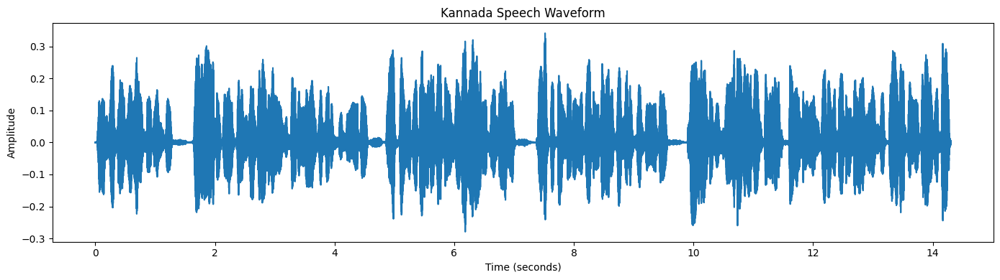

In [ ]:

from datasets import load_dataset, Audio
from IPython.display import Audio as PlayAudio, display
import numpy as np
import matplotlib.pyplot as plt

print("Searching for a transcript-bearing Kannada recording...")

ds = load_dataset(
    "ARTPARK-IISc/Vaani",
    "Kannada",
    split="train",
    streaming=True,
    token=True,
)

ds = ds.cast_column("audio", Audio(decode=True))

selected = None

for i, row in enumerate(ds.take(300), start=1):
    transcript = str(row.get("transcript") or "").strip()

    if transcript:
        selected = row
        print("Record position:", i)
        print("Transcript:", transcript[:500])
        break

if selected is None:
    print("No transcript-bearing recording found in these 300 records.")
else:
    audio = selected["audio"]

    if audio is None:
        print("Audio is missing for this record.")
    else:
        waveform = np.asarray(audio["array"], dtype=np.float32)
        sample_rate = audio["sampling_rate"]

        print("Sample rate:", sample_rate, "Hz")
        print("Duration:", round(len(waveform) / sample_rate, 2), "seconds")
        print("Speaker ID:", selected.get("speakerID"))

        display(PlayAudio(waveform, rate=sample_rate))

        time_axis = np.arange(len(waveform)) / sample_rate

        plt.figure(figsize=(14, 4))
        plt.plot(time_axis, waveform)
        plt.xlabel("Time (seconds)")
        plt.ylabel("Amplitude")
        plt.title("Kannada Speech Waveform")
        plt.tight_layout()
        plt.show()


Transcript:
<noise> ಒಂದು ಬದಿಯಲ್ಲಿ <pause> ಒಂದು ಪ್ರಯಾಣಿಕರ ತಂಗುದಾಣ ಇರುವುದನ್ನು ನಾವು ಗಮನಿಸಬಹುದು <pause> ಆ ತಂಗುದಾಣ ಹಲವಾರು ಜನರು ಕುಳಿತುಕೊಂಡಿರುವುದನ್ನು ನಾವು ಗಮನಿಸಬಹುದು <pause> ನೋಡಲು ವಿಶಾಲವಾದ ರಸ್ತೆಯನ್ನು ಹೊಂದಿರುವುದನ್ನು ನಾವು ಇಲ್ಲಿ ನಾವು ಇಲ್ಲಿ ಕಾಣಬಹುದಾಗಿದೆ. </noise>

Sample rate: 16000 Hz
Duration: 14.30 seconds


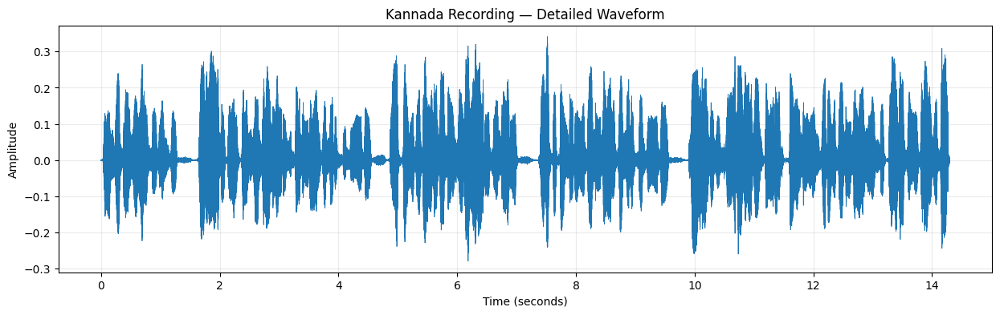

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Audio, display

# Reuse the recording that already loaded successfully
audio_data = selected["audio"]
waveform = np.asarray(audio_data["array"], dtype=np.float32)
sr = audio_data["sampling_rate"]

print("Transcript:")
print(selected.get("transcript"))
print(f"\nSample rate: {sr} Hz")
print(f"Duration: {len(waveform) / sr:.2f} seconds")

# Listen again
display(Audio(waveform, rate=sr))

# Plot the waveform with a finer time axis
time_axis = np.arange(len(waveform)) / sr

plt.figure(figsize=(15, 4))
plt.plot(time_axis, waveform, linewidth=0.6)
plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude")
plt.title("Kannada Recording — Detailed Waveform")
plt.grid(True, alpha=0.25)
plt.show()

# Inspect the first one-second window
start_sec = 0
end_sec = 1

segment = waveform[int(start_sec * sr):int(end_sec * sr)]
display(Audio(segment, rate=sr))

In [ ]:
!pip -q install -U whisperx

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 45.0/45.0 kB 2.9 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.0/44.0 kB 2.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 16.5/16.5 MB 62.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 39.6/39.6 MB 15.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.1/1.1 MB 44.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 566.4/566.4 kB 35.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 894.6/894.6 kB 41.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 887.9/887.9 MB 445.3 kB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 155.6/155.6 MB 8.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 594.3/594.3 MB 1.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.2/10.2 MB 79.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 88.0/88.0 MB 11.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 

In [ ]:
import requests

url = "https://huggingface.co/api/models"
params = {
    "search": "Kannada wav2vec2",
    "filter": "automatic-speech-recognition",
    "limit": 10
}

response = requests.get(url, params=params, timeout=30)
response.raise_for_status()

for model in response.json():
    print(model["id"])

Harveenchadha/vakyansh-wav2vec2-kannada-knm-560
addy88/wav2vec2-kannada-stt
TheAIchemist13/kannada_wav2vec2_final
TheAIchemist13/kannada_beekeeping_wav2vec2


In [ ]:
import sys
import importlib.metadata as md

print("Python:", sys.version)

for package in ["torch", "torchvision", "torchaudio",
                "transformers", "numpy"]:
    try:
        print(f"{package}: {md.version(package)}")
    except md.PackageNotFoundError:
        print(f"{package}: NOT INSTALLED")

try:
    import torch
    print("PyTorch imports successfully:", torch.__version__)
except Exception as e:
    print("PyTorch import error:", repr(e))

try:
    import torchvision
    print("Torchvision imports successfully:", torchvision.__version__)
except Exception as e:
    print("Torchvision import error:", repr(e))

Python: 3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]
torch: 2.8.0
torchvision: 0.23.0
torchaudio: 2.8.0
transformers: 4.57.6
numpy: 2.5.4
PyTorch imports successfully: 2.11.0+cpu
Torchvision import error: AttributeError("partially initialized module 'torchvision' from '/usr/local/lib/python3.13/dist-packages/torchvision/__init__.py' has no attribute 'extension' (most likely due to a circular import)")


In [ ]:
%pip uninstall -y torchvision

Found existing installation: torchvision 0.23.0
Uninstalling torchvision-0.23.0:
  Successfully uninstalled torchvision-0.23.0


In [ ]:
import torch
from transformers import AutoProcessor, AutoModelForCTC

print("PyTorch:", torch.__version__)
print("Transformers imports successfully!")

ModuleNotFoundError: Could not import module 'AutoProcessor'. Are this object's requirements defined correctly?

In [ ]:
%pip install -U torchvision

  Using cached triton-3.8.0-cp313-cp313-manylinux_2_27_x86_64.manylinux_2_28_x86_64.whl.metadata (978 bytes)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.4/7.4 MB 16.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 554.6/554.6 MB 853.4 kB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 553.1/553.1 MB 3.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 170.1/170.1 MB 1.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 216.0/216.0 MB 1.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 60.4/60.4 MB 14.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 423.1/423.1 MB 1.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.7/10.7 MB 74.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 90.2/90.2 MB 12.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.2/2.2 MB 55.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 214.1/214.1 MB 1.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━

In [ ]:
import torch
import torchvision
import transformers

print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)
print("Transformers:", transformers.__version__)

from transformers import AutoProcessor, AutoModelForCTC

print("ASR imports successful!")

PyTorch: 2.14.1+cu130
Torchvision: 0.29.1+cu130
Transformers: 4.57.6
ASR imports successful!


In [ ]:
import numpy as np
import torch
from datasets import load_dataset, Audio as HFAudio
from transformers import AutoProcessor, AutoModelForCTC

# 1. Reload a transcript-bearing Vaani recording
print("Loading Kannada recording...")

ds = load_dataset(
    "ARTPARK-IISc/Vaani",
    "Kannada",
    split="train",
    streaming=True,
    token=True,
).cast_column("audio", HFAudio(decode=True))

selected = None

for row in ds.take(300):
    if str(row.get("transcript") or "").strip():
        selected = row
        break

if selected is None:
    raise RuntimeError("No transcript-bearing recording found.")

waveform = np.asarray(selected["audio"]["array"], dtype=np.float32)
sr = selected["audio"]["sampling_rate"]

print("Audio loaded:", round(len(waveform) / sr, 2), "seconds")
print("Sample rate:", sr, "Hz")

# 2. Load the Kannada ASR model
model_id = "Harveenchadha/vakyansh-wav2vec2-kannada-knm-560"

processor = AutoProcessor.from_pretrained(model_id)
model = AutoModelForCTC.from_pretrained(model_id)
model.eval()

# 3. Transcribe
inputs = processor(
    waveform,
    sampling_rate=sr,
    return_tensors="pt"
)

with torch.inference_mode():
    logits = model(**inputs).logits

prediction = processor.batch_decode(
    torch.argmax(logits, dim=-1)
)[0]

print("\n--- VAANI REFERENCE TRANSCRIPT ---")
print(selected.get("transcript"))

print("\n--- MODEL PREDICTION ---")
print(prediction)

Loading Kannada recording...


/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


Resolving data files:   0%|          | 0/727 [00:00<?, ?it/s]

ImportError: Numba needs NumPy 2.2 or less. Got NumPy 2.5.

In [ ]:
%pip install "numpy==2.2.6"

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 62.0/62.0 kB 3.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 16.5/16.5 MB 32.0 MB/s eta 0:00:00
  Attempting uninstall: numpy
    Found existing installation: numpy 2.5.4
    Uninstalling numpy-2.5.4:
      Successfully uninstalled numpy-2.5.4
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
whisperx 3.8.6 requires torch~=2.8.0, but you have torch 2.14.1 which is incompatible.
whisperx 3.8.6 requires torchvision~=0.23.0, but you have torchvision 0.29.1 which is incompatible.
diffusers 0.40.0 requires huggingface-hub<2.0,>=1.23.0, but you have huggingface-hub 0.36.2 which is incompatible.
gradio 6.29.0 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.


In [ ]:
import numpy as np
import numba
import torch
import transformers

print("NumPy:", np.__version__)
print("Numba:", numba.__version__)
print("PyTorch:", torch.__version__)
print("Transformers:", transformers.__version__)
print("CUDA available:", torch.cuda.is_available())

NumPy: 2.2.6
Numba: 0.61.2
PyTorch: 2.14.1+cu130
Transformers: 4.57.6
CUDA available: False


In [ ]:
import numpy as np
import torch
from datasets import load_dataset, Audio as HFAudio
from transformers import AutoProcessor, AutoModelForCTC

# 1. Load one transcript-bearing Kannada recording
print("Loading Vaani audio...")

ds = load_dataset(
    "ARTPARK-IISc/Vaani",
    "Kannada",
    split="train",
    streaming=True,
    token=True,
).cast_column("audio", HFAudio(decode=True))

selected = None

for row in ds.take(300):
    if str(row.get("transcript") or "").strip():
        selected = row
        break

if selected is None:
    raise RuntimeError("No transcript-bearing recording found.")

waveform = np.asarray(
    selected["audio"]["array"], dtype=np.float32
)
sr = selected["audio"]["sampling_rate"]

print("Duration:", round(len(waveform) / sr, 2), "seconds")
print("Sample rate:", sr, "Hz")

# 2. Load the Kannada speech recognition model
model_id = "Harveenchadha/vakyansh-wav2vec2-kannada-knm-560"

processor = AutoProcessor.from_pretrained(model_id)
model = AutoModelForCTC.from_pretrained(model_id)
model.eval()

# 3. Predict the transcript on CPU
inputs = processor(
    waveform,
    sampling_rate=sr,
    return_tensors="pt"
)

with torch.inference_mode():
    logits = model(**inputs).logits

prediction = processor.batch_decode(
    torch.argmax(logits, dim=-1)
)[0]

print("\n--- VAANI REFERENCE ---")
print(selected.get("transcript"))

print("\n--- ASR PREDICTION ---")
print(prediction)

Loading Vaani audio...


/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


Resolving data files:   0%|          | 0/727 [00:00<?, ?it/s]

Duration: 14.3 seconds
Sample rate: 16000 Hz


preprocessor_config.json:   0%|          | 0.00/213 [00:00<?, ?B/s]

...

vocab.json:   0%|          | 0.00/719 [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/85.0 [00:00<?, ?B/s]

pytorch_model.bin:   0%|          | 0.00/378M [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/378M [00:00<?, ?B/s]


--- VAANI REFERENCE ---
<noise> ಒಂದು ಬದಿಯಲ್ಲಿ <pause> ಒಂದು ಪ್ರಯಾಣಿಕರ ತಂಗುದಾಣ ಇರುವುದನ್ನು ನಾವು ಗಮನಿಸಬಹುದು <pause> ಆ ತಂಗುದಾಣ ಹಲವಾರು ಜನರು ಕುಳಿತುಕೊಂಡಿರುವುದನ್ನು ನಾವು ಗಮನಿಸಬಹುದು <pause> ನೋಡಲು ವಿಶಾಲವಾದ ರಸ್ತೆಯನ್ನು ಹೊಂದಿರುವುದನ್ನು ನಾವು ಇಲ್ಲಿ ನಾವು ಇಲ್ಲಿ ಕಾಣಬಹುದಾಗಿದೆ. </noise>

--- ASR PREDICTION ---
<s>ಒ<s>ಂ<s>ದು<s> <s>ಬ<s>ದಿ<s>ಯ<s>ಲ್ಲಿ<s> <s>ಒ<s>ಂ<s>ದು<s> <s>ಪ<s>ರ<s>ಯಾ<s>ಣಿ<s>ಕ<s>ರ<s> <s>ತ<s>ಂ<s>ಗು<s>ಂ<s>ದ<s>ಾ<s>ಳ<s> ಇ<s>ರು<s>ವು<s>ದ<s>ನ್ನು<s> <s>ನಾ<s>ವು<s> <s>ಗ<s>ಮ<s>ನಿ<s>ಸ<s>ಬ<s>ಹು<s>ದು<s> <s>ತ<s>ಂ<s>ಗು<s>ದ<s>ಾ<s>ಳ<s>ದ<s>ಲ್ಲಿ<s> <s>ಹ<s>ಲ<s>ವ<s>ಾ<s>ರ<s>ು<s> <s>ಜ<s>ನ<s>ರ<s>ು<s> <s>ಕು<s>ಳಿ<s>ತು<s>ಕೊ<s>ಂ<s>ಡಿ<s>ರು<s>ವು<s>ದ<s>ನ್ನು<s> <s>ನಾ<s>ವ<s>ು<s> <s>ಗ<s>ಮ<s>ನಿ<s>ಸ<s>ಬ<s>ಹು<s>ದು<s> <s>ನೋ<s>ಡ<s>ಲು<s> ವಿ<s>ಶ<s>ಾ<s>ಲ<s>ವ<s>ಾ<s>ದ<s>ಂ<s>ತ<s>ಹ<s> <s>ರ<s>ಸ್<s>ತೆ<s>ಯ<s>ನ್ನು<s> <s>ಹೊ<s>ಂ<s>ದಿ<s>ರ<s>ು<s>ವು<s>ದ<s>ನ್ನು<s> <s>ನಾ<s>ವು<s> ಇ<s>ಲ್<s>ಲಿ<s> <s>ಕ<s>ಾ<s>ಣ<s>ಬ<s>ಹ<s>ು<s>ದ<s>ಾ<s>ಗಿ<s>ದೆ<s> <s>


In [ ]:
print("Tokenizer class:", type(processor.tokenizer).__name__)
print("Vocabulary size:", len(processor.tokenizer))
print("Special tokens:", processor.tokenizer.special_tokens_map)
print("Word delimiter:", repr(processor.tokenizer.word_delimiter_token))
print("Word delimiter ID:", processor.tokenizer.word_delimiter_token_id)

print("\nRaw decoded prediction:")
print(repr(prediction))

# Inspect the actual token IDs for the prediction
with torch.inference_mode():
    token_ids = torch.argmax(logits, dim=-1)[0].tolist()

print("\nFirst 100 predicted token IDs:")
print(token_ids[:100])

print("\nFirst 100 token strings:")
print(processor.tokenizer.convert_ids_to_tokens(token_ids[:100]))

Tokenizer class: Wav2Vec2CTCTokenizer
Vocabulary size: 66
Special tokens: {'bos_token': '<s>', 'eos_token': '</s>', 'unk_token': '<unk>', 'pad_token': '<pad>'}
Word delimiter: '|'
Word delimiter ID: 4

Raw decoded prediction:
'<s>ಒ<s>ಂ<s>ದು<s> <s>ಬ<s>ದಿ<s>ಯ<s>ಲ್ಲಿ<s> <s>ಒ<s>ಂ<s>ದು<s> <s>ಪ<s>ರ<s>ಯಾ<s>ಣಿ<s>ಕ<s>ರ<s> <s>ತ<s>ಂ<s>ಗು<s>ಂ<s>ದ<s>ಾ<s>ಳ<s> ಇ<s>ರು<s>ವು<s>ದ<s>ನ್ನು<s> <s>ನಾ<s>ವು<s> <s>ಗ<s>ಮ<s>ನಿ<s>ಸ<s>ಬ<s>ಹು<s>ದು<s> <s>ತ<s>ಂ<s>ಗು<s>ದ<s>ಾ<s>ಳ<s>ದ<s>ಲ್ಲಿ<s> <s>ಹ<s>ಲ<s>ವ<s>ಾ<s>ರ<s>ು<s> <s>ಜ<s>ನ<s>ರ<s>ು<s> <s>ಕು<s>ಳಿ<s>ತು<s>ಕೊ<s>ಂ<s>ಡಿ<s>ರು<s>ವು<s>ದ<s>ನ್ನು<s> <s>ನಾ<s>ವ<s>ು<s> <s>ಗ<s>ಮ<s>ನಿ<s>ಸ<s>ಬ<s>ಹು<s>ದು<s> <s>ನೋ<s>ಡ<s>ಲು<s> ವಿ<s>ಶ<s>ಾ<s>ಲ<s>ವ<s>ಾ<s>ದ<s>ಂ<s>ತ<s>ಹ<s> <s>ರ<s>ಸ್<s>ತೆ<s>ಯ<s>ನ್ನು<s> <s>ಹೊ<s>ಂ<s>ದಿ<s>ರ<s>ು<s>ವು<s>ದ<s>ನ್ನು<s> <s>ನಾ<s>ವು<s> ಇ<s>ಲ್<s>ಲಿ<s> <s>ಕ<s>ಾ<s>ಣ<s>ಬ<s>ಹ<s>ು<s>ದ<s>ಾ<s>ಗಿ<s>ದೆ<s> <s>'

First 100 predicted token IDs:
[0, 0, 0, 17, 0, 0, 0, 0, 0, 5, 0, 36, 56, 0, 0, 4, 4, 0, 41, 0, 0, 0, 0, 0, 0, 0, 0, 36, 54, 0, 0, 0, 0, 0, 44, 0, 0, 0, 0, 0, 46, 65, 46, 

In [ ]:
print("Model vocabulary size:", model.config.vocab_size)
print("Tokenizer vocabulary size:", len(processor.tokenizer))
print("Model pad token ID:", model.config.pad_token_id)
print("Tokenizer pad token ID:", processor.tokenizer.pad_token_id)
print("Tokenizer BOS token ID:", processor.tokenizer.bos_token_id)
print("Tokenizer EOS token ID:", processor.tokenizer.eos_token_id)

print("\nModel ID-to-token mapping:")
for token_id in range(min(15, model.config.vocab_size)):
    print(
        token_id,
        "->",
        repr(processor.tokenizer.convert_ids_to_tokens(token_id))
    )

Model vocabulary size: 66
Tokenizer vocabulary size: 66
Model pad token ID: 1
Tokenizer pad token ID: 1
Tokenizer BOS token ID: 0
Tokenizer EOS token ID: 2

Model ID-to-token mapping:
0 -> '<s>'
1 -> '<pad>'
2 -> '</s>'
3 -> '<unk>'
4 -> '|'
5 -> 'ಂ'
6 -> 'ಃ'
7 -> 'ಅ'
8 -> 'ಆ'
9 -> 'ಇ'
10 -> 'ಈ'
11 -> 'ಉ'
12 -> 'ಊ'
13 -> 'ಋ'
14 -> 'ಎ'


In [ ]:
print("Model config:", model.config)
print("\nTokenizer config:", processor.tokenizer.init_kwargs)

Model config: Wav2Vec2Config {
  "activation_dropout": 0.1,
  "adapter_attn_dim": null,
  "adapter_kernel_size": 3,
  "adapter_stride": 2,
  "add_adapter": false,
  "apply_spec_augment": true,
  "architectures": [
    "Wav2Vec2ForCTC"
  ],
  "attention_dropout": 0.1,
  "bos_token": "<s>",
  "bos_token_id": 0,
  "classifier_proj_size": 256,
  "codevector_dim": 256,
  "contrastive_logits_temperature": 0.1,
  "conv_bias": false,
  "conv_dim": [
    512,
    512,
    512,
    512,
    512,
    512,
    512
  ],
  "conv_kernel": [
    10,
    3,
    3,
    3,
    3,
    2,
    2
  ],
  "conv_stride": [
    5,
    2,
    2,
    2,
    2,
    2,
    2
  ],
  "ctc_loss_reduction": "sum",
  "ctc_zero_infinity": false,
  "diversity_loss_weight": 0.1,
  "do_lower_case": false,
  "do_stable_layer_norm": false,
  "dtype": "float32",
  "eos_token": "</s>",
  "eos_token_id": 2,
  "feat_extract_activation": "gelu",
  "feat_extract_norm": "group",
  "feat_proj_dropout": 0.1,
  "feat_quantizer_dropout":

In [ ]:
import torch
from collections import Counter

# Count the model's frame-by-frame predictions
frame_ids = torch.argmax(logits[0], dim=-1).cpu().tolist()
counts = Counter(frame_ids)

print("Total output frames:", len(frame_ids))
print("\nMost frequent predicted tokens:")

for token_id, count in counts.most_common(12):
    token = processor.tokenizer.convert_ids_to_tokens(token_id)
    print(
        f"ID {token_id:2d} | {str(token):8s} | "
        f"{count:5d} frames ({100 * count / len(frame_ids):.1f}%)"
    )

# Compare ordinary decoding with special tokens skipped
print("\n--- Decode with special tokens skipped ---")
print(processor.batch_decode(
    torch.argmax(logits, dim=-1),
    skip_special_tokens=True
)[0])

# Check confidence in the first few frames
probs = torch.softmax(logits[0], dim=-1)
print("\nFirst 10 frame predictions:")
for i in range(min(10, len(frame_ids))):
    token_id = frame_ids[i]
    token = processor.tokenizer.convert_ids_to_tokens(token_id)
    print(i, repr(token), "confidence:", round(probs[i, token_id].item(), 3))

Total output frames: 714

Most frequent predicted tokens:
ID  0 | <s>      |   492 frames (68.9%)
ID  4 | |        |    31 frames (4.3%)
ID 56 | ು        |    28 frames (3.9%)
ID 38 | ನ        |    20 frames (2.8%)
ID 36 | ದ        |    15 frames (2.1%)
ID 54 | ಿ        |    14 frames (2.0%)
ID 53 | ಾ        |    13 frames (1.8%)
ID  5 | ಂ        |     9 frames (1.3%)
ID 46 | ಲ        |     9 frames (1.3%)
ID 65 | ್        |     9 frames (1.3%)
ID 48 | ವ        |     9 frames (1.3%)
ID 45 | ರ        |     8 frames (1.1%)

--- Decode with special tokens skipped ---
ಒಂದು ಬದಿಯಲ್ಲಿ ಒಂದು ಪರಯಾಣಿಕರ ತಂಗುಂದಾಳ ಇರುವುದನ್ನು ನಾವು ಗಮನಿಸಬಹುದು ತಂಗುದಾಳದಲ್ಲಿ ಹಲವಾರು ಜನರು ಕುಳಿತುಕೊಂಡಿರುವುದನ್ನು ನಾವು ಗಮನಿಸಬಹುದು ನೋಡಲು ವಿಶಾಲವಾದಂತಹ ರಸ್ತೆಯನ್ನು ಹೊಂದಿರುವುದನ್ನು ನಾವು ಇಲ್ಲಿ ಕಾಣಬಹುದಾಗಿದೆ

First 10 frame predictions:
0 '<s>' confidence: 1.0
1 '<s>' confidence: 1.0
2 '<s>' confidence: 1.0
3 'ಒ' confidence: 0.991
4 '<s>' confidence: 0.999
5 '<s>' confidence: 1.0
6 '<s>' confidence: 1.0
7 '<s>' confidence: 1.0
8 '<s>' conf

In [ ]:
import torch
from collections import Counter

# 1. Count the model's frame-level predictions
frame_ids = torch.argmax(logits[0], dim=-1).cpu().tolist()
counts = Counter(frame_ids)

print("Total frames:", len(frame_ids))
print("\nTop predicted tokens:")

for token_id, count in counts.most_common(12):
    token = processor.tokenizer.convert_ids_to_tokens(token_id)
    print(
        f"ID={token_id:2d} | token={str(token):8s} | "
        f"{count:4d} frames ({100 * count / len(frame_ids):.1f}%)"
    )

# 2. Decode while removing special tokens
print("\n--- Decoded with special tokens skipped ---")
print(
    processor.batch_decode(
        torch.argmax(logits, dim=-1),
        skip_special_tokens=True
    )[0]
)

# 3. Compare blank-token and BOS-token confidence
probs = torch.softmax(logits[0], dim=-1)

print("\nMean frame probability:")
print("CTC blank (ID 1):", round(probs[:, 1].mean().item(), 4))
print("BOS token (ID 0):", round(probs[:, 0].mean().item(), 4))

Total frames: 714

Top predicted tokens:
ID= 0 | token=<s>      |  492 frames (68.9%)
ID= 4 | token=|        |   31 frames (4.3%)
ID=56 | token=ು        |   28 frames (3.9%)
ID=38 | token=ನ        |   20 frames (2.8%)
ID=36 | token=ದ        |   15 frames (2.1%)
ID=54 | token=ಿ        |   14 frames (2.0%)
ID=53 | token=ಾ        |   13 frames (1.8%)
ID= 5 | token=ಂ        |    9 frames (1.3%)
ID=46 | token=ಲ        |    9 frames (1.3%)
ID=65 | token=್        |    9 frames (1.3%)
ID=48 | token=ವ        |    9 frames (1.3%)
ID=45 | token=ರ        |    8 frames (1.1%)

--- Decoded with special tokens skipped ---
ಒಂದು ಬದಿಯಲ್ಲಿ ಒಂದು ಪರಯಾಣಿಕರ ತಂಗುಂದಾಳ ಇರುವುದನ್ನು ನಾವು ಗಮನಿಸಬಹುದು ತಂಗುದಾಳದಲ್ಲಿ ಹಲವಾರು ಜನರು ಕುಳಿತುಕೊಂಡಿರುವುದನ್ನು ನಾವು ಗಮನಿಸಬಹುದು ನೋಡಲು ವಿಶಾಲವಾದಂತಹ ರಸ್ತೆಯನ್ನು ಹೊಂದಿರುವುದನ್ನು ನಾವು ಇಲ್ಲಿ ಕಾಣಬಹುದಾಗಿದೆ

Mean frame probability:
CTC blank (ID 1): 0.0
BOS token (ID 0): 0.6917


In [ ]:
import torch

probs = torch.softmax(logits[0], dim=-1)

blank_id = model.config.pad_token_id
bos_id = processor.tokenizer.bos_token_id

print("Configured CTC blank ID:", blank_id)
print("BOS token ID:", bos_id)

print(
    "Mean blank probability:",
    round(probs[:, blank_id].mean().item(), 6)
)
print(
    "Mean BOS probability:",
    round(probs[:, bos_id].mean().item(), 6)
)

print(
    "Frames where blank is the top prediction:",
    int((torch.argmax(logits[0], dim=-1) == blank_id).sum())
)

print(
    "Frames where BOS is the top prediction:",
    int((torch.argmax(logits[0], dim=-1) == bos_id).sum())
)

Configured CTC blank ID: 1
BOS token ID: 0
Mean blank probability: 0.0
Mean BOS probability: 0.691719
Frames where blank is the top prediction: 0
Frames where BOS is the top prediction: 492


In [ ]:
import torch
import re

tokenizer = processor.tokenizer

# Existing frame-level model predictions
ids = torch.argmax(logits[0], dim=-1).cpu().tolist()

# CTC decoding experiment:
# Treat token 0 as the hypothesized blank.
blank_id = 0

collapsed = []
previous = None

for token_id in ids:
    if token_id != previous:
        if token_id != blank_id:
            collapsed.append(token_id)
    previous = token_id

# Convert tokens to Kannada text
tokens = tokenizer.convert_ids_to_tokens(collapsed)

# Remove any remaining special tokens
specials = set(tokenizer.all_special_tokens)
tokens = [t for t in tokens if t not in specials]

text = "".join(
    " " if t == tokenizer.word_delimiter_token else t
    for t in tokens
)

text = re.sub(r"\s+", " ", text).strip()

print("=" * 55)
print("VAANI REFERENCE")
print("=" * 55)
print(selected["transcript"])

print("\n" + "=" * 55)
print("EXPERIMENTAL CTC DECODING (BLANK = 0)")
print("=" * 55)
print(text)

print("\nNumber of decoded tokens:", len(tokens))

VAANI REFERENCE
<noise> ಒಂದು ಬದಿಯಲ್ಲಿ <pause> ಒಂದು ಪ್ರಯಾಣಿಕರ ತಂಗುದಾಣ ಇರುವುದನ್ನು ನಾವು ಗಮನಿಸಬಹುದು <pause> ಆ ತಂಗುದಾಣ ಹಲವಾರು ಜನರು ಕುಳಿತುಕೊಂಡಿರುವುದನ್ನು ನಾವು ಗಮನಿಸಬಹುದು <pause> ನೋಡಲು ವಿಶಾಲವಾದ ರಸ್ತೆಯನ್ನು ಹೊಂದಿರುವುದನ್ನು ನಾವು ಇಲ್ಲಿ ನಾವು ಇಲ್ಲಿ ಕಾಣಬಹುದಾಗಿದೆ. </noise>

EXPERIMENTAL CTC DECODING (BLANK = 0)
ಒಂದು ಬದಿಯಲ್ಲಿ ಒಂದು ಪರಯಾಣಿಕರ ತಂಗುಂದಾಳ ಇರುವುದನ್ನು ನಾವು ಗಮನಿಸಬಹುದು ತಂಗುದಾಳದಲ್ಲಿ ಹಲವಾರು ಜನರು ಕುಳಿತುಕೊಂಡಿರುವುದನ್ನು ನಾವು ಗಮನಿಸಬಹುದು ನೋಡಲು ವಿಶಾಲವಾದಂತಹ ರಸ್ತೆಯನ್ನು ಹೊಂದಿರುವುದನ್ನು ನಾವು ಇಲ್ಲಿ ಕಾಣಬಹುದಾಗಿದೆ

Number of decoded tokens: 194


In [ ]:
import re
import unicodedata
from difflib import SequenceMatcher

reference = selected["transcript"]
hypothesis = text  # Experimental CTC decoding from the previous cell

def normalize_kannada(s):
    s = unicodedata.normalize("NFC", s)
    s = re.sub(r"<[^>]+>", " ", s)
    s = re.sub(r"[^\w\s]", " ", s, flags=re.UNICODE)
    return " ".join(s.split())

ref = normalize_kannada(reference)
hyp = normalize_kannada(hypothesis)

# Word-level edit distance
def edit_distance(a, b):
    previous = list(range(len(b) + 1))
    for i, x in enumerate(a, start=1):
        current = [i]
        for j, y in enumerate(b, start=1):
            current.append(min(
                current[-1] + 1,          # insertion
                previous[j] + 1,          # deletion
                previous[j - 1] + (x != y)  # substitution
            ))
        previous = current
    return previous[-1]

ref_words = ref.split()
hyp_words = hyp.split()

ref_chars = list(ref.replace(" ", ""))
hyp_chars = list(hyp.replace(" ", ""))

word_errors = edit_distance(ref_words, hyp_words)
char_errors = edit_distance(ref_chars, hyp_chars)

wer_value = word_errors / max(len(ref_words), 1)
cer_value = char_errors / max(len(ref_chars), 1)

print("Reference words:", len(ref_words))
print("Hypothesis words:", len(hyp_words))
print("Word errors:", word_errors)
print(f"WER: {wer_value:.2%}")
print(f"CER: {cer_value:.2%}")

Reference words: 75
Hypothesis words: 71
Word errors: 11
WER: 14.67%
CER: 12.62%


In [ ]:

# STEP 1: Inspect the Kannada ASR checkpoint
# No installations or model downloads required.

import torch

print("MODEL CONFIG")
print("Model class:", type(model).__name__)
print("Model name/path:", getattr(model.config, "_name_or_path", "unknown"))
print("Model type:", getattr(model.config, "model_type", "unknown"))
print("Model vocab size:", getattr(model.config, "vocab_size", "unknown"))
print("Model pad token ID:", getattr(model.config, "pad_token_id", None))
print("Model BOS token ID:", getattr(model.config, "bos_token_id", None))
print("Model EOS token ID:", getattr(model.config, "eos_token_id", None))
print("CTC loss reduction:", getattr(model.config, "ctc_loss_reduction", None))

print("\nPROCESSOR / TOKENIZER")
tokenizer = processor.tokenizer
print("Tokenizer class:", type(tokenizer).__name__)
print("Tokenizer vocab size:", tokenizer.vocab_size)
print("Tokenizer pad token:", repr(tokenizer.pad_token))
print("Tokenizer pad ID:", tokenizer.pad_token_id)
print("Tokenizer BOS token:", repr(tokenizer.bos_token))
print("Tokenizer BOS ID:", tokenizer.bos_token_id)
print("Tokenizer EOS token:", repr(tokenizer.eos_token))
print("Tokenizer EOS ID:", tokenizer.eos_token_id)
print("Word delimiter:", repr(getattr(tokenizer, "word_delimiter_token", None)))
print("Word delimiter ID:", getattr(tokenizer, "word_delimiter_token_id", None))

print("\nSPECIAL TOKEN MAP")
print(tokenizer.special_tokens_map)

print("\nTOKEN IDs 0–10")
for i in range(min(11, tokenizer.vocab_size)):
    print(i, "->", repr(tokenizer.convert_ids_to_tokens(i)))

print("\nMODEL DEVICE:", next(model.parameters()).device)
print("CUDA available:", torch.cuda.is_available())


MODEL CONFIG
Model class: Wav2Vec2ForCTC
Model name/path: Harveenchadha/vakyansh-wav2vec2-kannada-knm-560
Model type: wav2vec2
Model vocab size: 66
Model pad token ID: 1
Model BOS token ID: 0
Model EOS token ID: 2
CTC loss reduction: sum

PROCESSOR / TOKENIZER
Tokenizer class: Wav2Vec2CTCTokenizer
Tokenizer vocab size: 66
Tokenizer pad token: '<pad>'
Tokenizer pad ID: 1
Tokenizer BOS token: '<s>'
Tokenizer BOS ID: 0
Tokenizer EOS token: '</s>'
Tokenizer EOS ID: 2
Word delimiter: '|'
Word delimiter ID: 4

SPECIAL TOKEN MAP
{'bos_token': '<s>', 'eos_token': '</s>', 'unk_token': '<unk>', 'pad_token': '<pad>'}

TOKEN IDs 0–10
0 -> '<s>'
1 -> '<pad>'
2 -> '</s>'
3 -> '<unk>'
4 -> '|'
5 -> 'ಂ'
6 -> 'ಃ'
7 -> 'ಅ'
8 -> 'ಆ'
9 -> 'ಇ'
10 -> 'ಈ'

MODEL DEVICE: cpu
CUDA available: False


In [ ]:

# STEP 2: Diagnose the CTC output distribution

import torch

assert "logits" in globals(), (
    "The logits variable is missing. Re-run the earlier inference cell first."
)

x = logits[0].detach().float()
probs = torch.softmax(x, dim=-1)
frame_ids = x.argmax(dim=-1)

print("OUTPUT SHAPE:", tuple(logits.shape))
print("All logits finite:", bool(torch.isfinite(x).all()))
print("Total frames:", x.shape[0])

print("\nARGMAX COUNTS")
counts = torch.bincount(frame_ids, minlength=x.shape[-1])
for token_id in torch.argsort(counts, descending=True)[:12].tolist():
    token = processor.tokenizer.convert_ids_to_tokens(token_id)
    print(f"ID {token_id:2d} | {token!r:8s} | "
          f"{counts[token_id].item():4d} frames | "
          f"{counts[token_id].item()/len(frame_ids)*100:6.2f}%")

print("\nMEAN PROBABILITY OF KEY TOKENS")
for token_id in [0, 1, 2, 3, 4]:
    token = processor.tokenizer.convert_ids_to_tokens(token_id)
    print(f"ID {token_id} ({token!r}): "
          f"{probs[:, token_id].mean().item():.6f}")

print("\nFRAME-WISE PREDICTION CONFIDENCE")
print("Mean maximum probability:",
      round(probs.max(dim=-1).values.mean().item(), 4))
print("Mean entropy:",
      round((-(probs * probs.clamp_min(1e-12).log()).sum(dim=-1)).mean().item(), 4))

print("\nSTANDARD DECODING")
print("With special tokens skipped:")
print(processor.batch_decode(logits.argmax(dim=-1),
                             skip_special_tokens=True)[0])

print("\nConfigured CTC blank ID:", model.config.pad_token_id)
print("Configured blank wins argmax on:",
      f"{(frame_ids == model.config.pad_token_id).sum().item()} frames")


OUTPUT SHAPE: (1, 714, 66)
All logits finite: True
Total frames: 714

ARGMAX COUNTS
ID  0 | '<s>'    |  492 frames |  68.91%
ID  4 | '|'      |   31 frames |   4.34%
ID 56 | 'ು'      |   28 frames |   3.92%
ID 38 | 'ನ'      |   20 frames |   2.80%
ID 36 | 'ದ'      |   15 frames |   2.10%
ID 54 | 'ಿ'      |   14 frames |   1.96%
ID 53 | 'ಾ'      |   13 frames |   1.82%
ID 65 | '್'      |    9 frames |   1.26%
ID 46 | 'ಲ'      |    9 frames |   1.26%
ID 48 | 'ವ'      |    9 frames |   1.26%
ID  5 | 'ಂ'      |    9 frames |   1.26%
ID 52 | 'ಹ'      |    8 frames |   1.12%

MEAN PROBABILITY OF KEY TOKENS
ID 0 ('<s>'): 0.691719
ID 1 ('<pad>'): 0.000000
ID 2 ('</s>'): 0.000000
ID 3 ('<unk>'): 0.000000
ID 4 ('|'): 0.042969

FRAME-WISE PREDICTION CONFIDENCE
Mean maximum probability: 0.9693
Mean entropy: 0.0884

STANDARD DECODING
With special tokens skipped:
ಒಂದು ಬದಿಯಲ್ಲಿ ಒಂದು ಪರಯಾಣಿಕರ ತಂಗುಂದಾಳ ಇರುವುದನ್ನು ನಾವು ಗಮನಿಸಬಹುದು ತಂಗುದಾಳದಲ್ಲಿ ಹಲವಾರು ಜನರು ಕುಳಿತುಕೊಂಡಿರುವುದನ್ನು ನಾವು ಗಮನಿಸಬಹುದು ನೋಡಲು ವಿಶಾಲವ

In [ ]:

# STEP 3: Compare a second Kannada ASR checkpoint
# Keeps the original model, processor, and logits unchanged.

from transformers import AutoProcessor, AutoModelForCTC
import torch
import numpy as np

candidate_id = "TheAIchemist13/kannada_wav2vec2_final"

try:
    processor2 = AutoProcessor.from_pretrained(candidate_id)
    model2 = AutoModelForCTC.from_pretrained(candidate_id)
    model2.eval()

    print("Checkpoint loaded:", candidate_id)
    print("Model class:", type(model2).__name__)
    print("Vocabulary size:", model2.config.vocab_size)
    print("Configured blank/pad ID:", model2.config.pad_token_id)
    print("Tokenizer pad ID:", processor2.tokenizer.pad_token_id)

    inputs2 = processor2(
        waveform,
        sampling_rate=sr,
        return_tensors="pt"
    )

    with torch.inference_mode():
        logits2 = model2(**inputs2).logits

    ids2 = logits2.argmax(dim=-1)
    transcript2 = processor2.batch_decode(
        ids2, skip_special_tokens=True
    )[0]

    print("\nSECOND MODEL TRANSCRIPT:")
    print(transcript2)

    counts2 = torch.bincount(
        ids2[0].cpu(),
        minlength=logits2.shape[-1]
    )
    print("\nTop predicted token IDs:")
    for token_id in torch.argsort(counts2, descending=True)[:8].tolist():
        token = processor2.tokenizer.convert_ids_to_tokens(token_id)
        print(
            f"ID {token_id} | {token!r} | "
            f"{counts2[token_id].item()} frames"
        )

except Exception as e:
    print("Second checkpoint could not be tested.")
    print(type(e).__name__ + ":", str(e)[:1000])
    print("Send me this error; don't install or upgrade anything yet.")


preprocessor_config.json:   0%|          | 0.00/214 [00:00<?, ?B/s]

config.json: 0.00B [00:00, ?B/s]

Second checkpoint could not be tested.
TypeError: expected str, bytes or os.PathLike object, not NoneType
Send me this error; don't install or upgrade anything yet.


In [ ]:

import traceback
from transformers import AutoProcessor, AutoModelForCTC

candidate_id = "TheAIchemist13/kannada_wav2vec2_final"

try:
    print("Loading processor...")
    processor2 = AutoProcessor.from_pretrained(candidate_id)
    print("Processor loaded successfully.")

    print("\nLoading model...")
    model2 = AutoModelForCTC.from_pretrained(candidate_id)
    print("Model loaded successfully.")

except Exception:
    traceback.print_exc()


Loading processor...


Traceback (most recent call last):
  File "/tmp/ipykernel_23788/188436480.py", line 8, in <cell line: 0>
    processor2 = AutoProcessor.from_pretrained(candidate_id)
  File "/usr/local/lib/python3.13/dist-packages/transformers/models/auto/processing_auto.py", line 401, in from_pretrained
    return PROCESSOR_MAPPING[type(config)].from_pretrained(pretrained_model_name_or_path, **kwargs)
           ~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.13/dist-packages/transformers/models/wav2vec2/processing_wav2vec2.py", line 59, in from_pretrained
    return super().from_pretrained(pretrained_model_name_or_path, **kwargs)
           ~~~~~~~~~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "/usr/local/lib/python3.13/dist-packages/transformers/processing_utils.py", line 1394, in from_pretrained
    args = cls._get_arguments_from_pretrained(pretrained_model_name_or_path, **kwargs)
  File "/usr/local/lib/python

In [ ]:

from huggingface_hub import HfApi

candidate_id = "TheAIchemist13/kannada_wav2vec2_final"

try:
    info = HfApi().model_info(candidate_id)
    print("Repository:", info.id)
    print("\nFiles available:")
    for item in info.siblings:
        print("-", item.rfilename)
except Exception as e:
    print(type(e).__name__ + ":", str(e)[:1000])


Repository: TheAIchemist13/kannada_wav2vec2_final

Files available:
- .gitattributes
- README.md
- config.json
- preprocessor_config.json
- pytorch_model.bin
- training_args.bin


In [ ]:

from huggingface_hub import hf_hub_download
import json

model_id = "Harveenchadha/vakyansh-wav2vec2-kannada-knm-560"

for filename in ["README.md", "config.json", "tokenizer_config.json"]:
    print(f"\n{'='*20} {filename} {'='*20}")
    try:
        path = hf_hub_download(repo_id=model_id, filename=filename)

        if filename == "config.json":
            with open(path, encoding="utf-8") as f:
                cfg = json.load(f)
            for key in [
                "vocab_size", "pad_token_id", "bos_token_id",
                "eos_token_id", "ctc_loss_reduction",
                "transformers_version"
            ]:
                print(f"{key}: {cfg.get(key)}")
        else:
            with open(path, encoding="utf-8") as f:
                content = f.read()
            print(content[:6000])
    except Exception as e:
        print("Could not read:", type(e).__name__, str(e)[:500])



==================== README.md ====================
Could not read: EntryNotFoundError 404 Client Error. (Request ID: Root=1-6acb9343-78221262244cfee9070a1eec;f0e71f3a-0efd-4e81-b672-b7f7dae5bb5e)

Entry Not Found for url: https://huggingface.co/Harveenchadha/vakyansh-wav2vec2-kannada-knm-560/resolve/main/README.md.

==================== config.json ====================
vocab_size: 66
pad_token_id: 1
bos_token_id: 0
eos_token_id: 2
ctc_loss_reduction: sum
transformers_version: 4.9.1

==================== tokenizer_config.json ====================
{"unk_token": "<unk>", "bos_token": "<s>", "eos_token": "</s>", "pad_token": "<pad>", "do_lower_case": false, "word_delimiter_token": "|", "tokenizer_class": "Wav2Vec2CTCTokenizer"}


In [ ]:

import numpy as np
import torch
import re

# Collect up to 3 recordings from distinct speakers.
samples = []
seen_speakers = set()

for row in ds.take(1500):
    ref = str(row.get("transcript") or "").strip()
    if not ref:
        continue

    speaker = str(row.get("speakerID") or "").strip()
    if not speaker or speaker == "None" or speaker in seen_speakers:
        continue

    samples.append(row)
    seen_speakers.add(speaker)

    if len(samples) == 3:
        break

print("Distinct-speaker recordings found:", len(samples))

for i, row in enumerate(samples, start=1):
    audio = row["audio"]
    wav = np.asarray(audio["array"], dtype=np.float32)
    sample_rate = audio["sampling_rate"]

    batch = processor(wav, sampling_rate=sample_rate, return_tensors="pt")

    with torch.inference_mode():
        out = model(**batch).logits

    frame_ids = out[0].argmax(dim=-1)
    counts = torch.bincount(frame_ids, minlength=out.shape[-1])
    total = len(frame_ids)

    prediction = processor.batch_decode(
        out.argmax(dim=-1), skip_special_tokens=True
    )[0]

    reference = re.sub(
        r"<[^>]+>", " ", str(row.get("transcript") or "")
    )
    reference = re.sub(r"\s+", " ", reference).strip()

    print(f"\n{'='*55}")
    print(f"RECORDING {i}")
    print("Speaker:", row.get("speakerID"))
    print("Duration:", round(len(wav) / sample_rate, 2), "seconds")
    print("Reference:", reference[:500])
    print("Prediction:", prediction[:500])
    print("BOS (<s>) argmax rate:", round(counts[0].item()/total, 3))
    print("Blank (<pad>) argmax rate:", round(counts[1].item()/total, 3))


Distinct-speaker recordings found: 3

RECORDING 1
Speaker: GONO_152257
Duration: 14.3 seconds
Reference: ಒಂದು ಬದಿಯಲ್ಲಿ ಒಂದು ಪ್ರಯಾಣಿಕರ ತಂಗುದಾಣ ಇರುವುದನ್ನು ನಾವು ಗಮನಿಸಬಹುದು ಆ ತಂಗುದಾಣ ಹಲವಾರು ಜನರು ಕುಳಿತುಕೊಂಡಿರುವುದನ್ನು ನಾವು ಗಮನಿಸಬಹುದು ನೋಡಲು ವಿಶಾಲವಾದ ರಸ್ತೆಯನ್ನು ಹೊಂದಿರುವುದನ್ನು ನಾವು ಇಲ್ಲಿ ನಾವು ಇಲ್ಲಿ ಕಾಣಬಹುದಾಗಿದೆ.
Prediction: ಒಂದು ಬದಿಯಲ್ಲಿ ಒಂದು ಪರಯಾಣಿಕರ ತಂಗುಂದಾಳ ಇರುವುದನ್ನು ನಾವು ಗಮನಿಸಬಹುದು ತಂಗುದಾಳದಲ್ಲಿ ಹಲವಾರು ಜನರು ಕುಳಿತುಕೊಂಡಿರುವುದನ್ನು ನಾವು ಗಮನಿಸಬಹುದು ನೋಡಲು ವಿಶಾಲವಾದಂತಹ ರಸ್ತೆಯನ್ನು ಹೊಂದಿರುವುದನ್ನು ನಾವು ಇಲ್ಲಿ ಕಾಣಬಹುದಾಗಿದೆ
BOS (<s>) argmax rate: 0.689
Blank (<pad>) argmax rate: 0.0

RECORDING 2
Speaker: NA
Duration: 12.39 seconds
Reference: ದೊಡ್ಡದಾದ ಎತ್ತರವಾದ ಮರಗಳಿಂದ ಕೂಡಿದ್ದು ನೋಡಲು ತುಂಬಾ ಚನ್ನಾಗಿದೆ ಇದೆ ಸುತ್ತಲೂ ಮರಗಳಿವೆ ನೋಡಲು ತುಂಬಾ ದೊಡ್ಡದ್ಗಿದ್ದು ಕನಸುತ್ತ ಇದೆ.
Prediction: ದಟದತ ಎತ್ತರವಾತ ಪರಟಗಳಿಂದ ಕೋಯಿತು ಕೊಡಲು ತುಂಬ ನಸುತ್ತದಿಡಮಗಳಿಂದ ಂಡಗಳಿಂದ
BOS (<s>) argmax rate: 0.89
Blank (<pad>) argmax rate: 0.0

RECORDING 3
Speaker: KABE_105505
Duration: 4.42 seconds
Reference: ಇದೊಂದು ಶಾಸಕೀಯ ಸ್ನಾತಕೋತ್ತರ ಮಹಾ ವಿದ್ಯಾಲಯವೂ ಆಗಿದೆ.
P

In [ ]:

from datasets import load_dataset
from collections import Counter
import re

LANGUAGES = ["Kannada", "Tamil", "Telugu", "Malayalam", "Tulu"]
MAX_SCAN = 1500
MAX_EXAMPLES = 5

results = {}

for language in LANGUAGES:
    print(f"\n{'=' * 60}")
    print(f"LANGUAGE: {language}")
    print(f"{'=' * 60}")

    try:
        stream = load_dataset(
            "ARTPARK-IISc/Vaani",
            language,
            split="train",
            streaming=True,
            token=True,
        )

        scanned = 0
        transcript_count = 0
        speakers = set()
        examples = []

        for row in stream.take(MAX_SCAN):
            scanned += 1

            speaker = str(row.get("speakerID") or "").strip()
            if speaker and speaker != "NA" and speaker != "None":
                speakers.add(speaker)

            transcript = str(row.get("transcript") or "").strip()
            transcript = re.sub(
                r"<(?:noise|pause|unk|silence)>", " ", transcript,
                flags=re.IGNORECASE
            )
            transcript = re.sub(r"\s+", " ", transcript).strip()

            if transcript:
                transcript_count += 1
                if len(examples) < MAX_EXAMPLES:
                    examples.append(transcript)

        results[language] = {
            "scanned": scanned,
            "transcripts": transcript_count,
            "speakers": len(speakers),
            "examples": examples,
        }

        print("Records scanned:", scanned)
        print("Records with transcript:", transcript_count)
        print("Distinct valid speaker IDs:", len(speakers))
        print("\nTranscript examples:")
        for i, example in enumerate(examples, 1):
            print(f"{i}. {example[:350]}")

    except Exception as e:
        print("ERROR:", type(e).__name__, str(e)[:500])
        results[language] = {"error": str(e)}

print("\nAudit complete. Results stored in `results`.")



LANGUAGE: Kannada
ERROR: LocalTokenNotFoundError Token is required (`token=True`), but no token found. You need to provide a token or be logged in to Hugging Face with `hf auth login` or `huggingface_hub.login`. See https://huggingface.co/settings/tokens.

LANGUAGE: Tamil
ERROR: LocalTokenNotFoundError Token is required (`token=True`), but no token found. You need to provide a token or be logged in to Hugging Face with `hf auth login` or `huggingface_hub.login`. See https://huggingface.co/settings/tokens.

LANGUAGE: Telugu
ERROR: LocalTokenNotFoundError Token is required (`token=True`), but no token found. You need to provide a token or be logged in to Hugging Face with `hf auth login` or `huggingface_hub.login`. See https://huggingface.co/settings/tokens.

LANGUAGE: Malayalam
ERROR: LocalTokenNotFoundError Token is required (`token=True`), but no token found. You need to provide a token or be logged in to Hugging Face with `hf auth login` or `huggingface_hub.login`. See https://huggi

In [ ]:

from google.colab import userdata
from huggingface_hub import login

try:
    hf_token = userdata.get("HF_TOKEN")
    login(token=hf_token, add_to_git_credential=False)
    print("Hugging Face authentication successful!")
except Exception as e:
    print(type(e).__name__ + ":", str(e))
    print("Check that HF_TOKEN exists in Colab Secrets and notebook access is enabled.")


SecretNotFoundError: Secret HF_TOKEN does not exist.
Check that HF_TOKEN exists in Colab Secrets and notebook access is enabled.


In [ ]:

from google.colab import userdata
from huggingface_hub import login

hf_token = userdata.get("HF_TOKEN")
login(token=hf_token, add_to_git_credential=False)

print("Authentication successful!")


Authentication successful!


In [ ]:

from datasets import load_dataset
import re

LANGUAGES = ["Kannada", "Tamil", "Telugu", "Malayalam", "Tulu"]
MAX_SCAN = 1500
MAX_EXAMPLES = 5

results = {}

for language in LANGUAGES:
    print(f"\n{'=' * 55}")
    print("LANGUAGE:", language)
    print("=" * 55)

    try:
        stream = load_dataset(
            "ARTPARK-IISc/Vaani",
            language,
            split="train",
            streaming=True,
            token=True,
        )

        scanned = 0
        transcript_count = 0
        speakers = set()
        examples = []

        for row in stream.take(MAX_SCAN):
            scanned += 1

            speaker = str(row.get("speakerID") or "").strip()
            if speaker and speaker not in {"NA", "None"}:
                speakers.add(speaker)

            transcript = str(row.get("transcript") or "").strip()
            transcript = re.sub(
                r"<[^>]+>", " ", transcript
            )
            transcript = re.sub(r"\s+", " ", transcript).strip()

            if transcript:
                transcript_count += 1
                if len(examples) < MAX_EXAMPLES:
                    examples.append(transcript)

        results[language] = {
            "scanned": scanned,
            "transcripts": transcript_count,
            "speakers": len(speakers),
            "examples": examples,
        }

        print("Records scanned:", scanned)
        print("Non-empty transcripts:", transcript_count)
        print("Distinct speaker IDs:", len(speakers))
        print("Transcript coverage:",
              f"{100 * transcript_count / scanned:.2f}%"
              if scanned else "N/A")

        for i, example in enumerate(examples, 1):
            print(f"Example {i}: {example[:300]}")

    except Exception as e:
        results[language] = {"error": str(e)}
        print("ERROR:", type(e).__name__, str(e)[:500])

print("\nAudit finished. Results are stored in `results`.")



LANGUAGE: Kannada


README.md:   0%|          | 0.00/178k [00:00<?, ?B/s]

Resolving data files:   0%|          | 0/727 [00:00<?, ?it/s]

Records scanned: 1500
Non-empty transcripts: 75
Distinct speaker IDs: 98
Transcript coverage: 5.00%
Example 1: ಒಂದು ಬದಿಯಲ್ಲಿ ಒಂದು ಪ್ರಯಾಣಿಕರ ತಂಗುದಾಣ ಇರುವುದನ್ನು ನಾವು ಗಮನಿಸಬಹುದು ಆ ತಂಗುದಾಣ ಹಲವಾರು ಜನರು ಕುಳಿತುಕೊಂಡಿರುವುದನ್ನು ನಾವು ಗಮನಿಸಬಹುದು ನೋಡಲು ವಿಶಾಲವಾದ ರಸ್ತೆಯನ್ನು ಹೊಂದಿರುವುದನ್ನು ನಾವು ಇಲ್ಲಿ ನಾವು ಇಲ್ಲಿ ಕಾಣಬಹುದಾಗಿದೆ.
Example 2: ದೊಡ್ಡದಾದ ಎತ್ತರವಾದ ಮರಗಳಿಂದ ಕೂಡಿದ್ದು ನೋಡಲು ತುಂಬಾ ಚನ್ನಾಗಿದೆ ಇದೆ ಸುತ್ತಲೂ ಮರಗಳಿವೆ ನೋಡಲು ತುಂಬಾ ದೊಡ್ಡದ್ಗಿದ್ದು ಕನಸುತ್ತ ಇದೆ.
Example 3: ಇದೊಂದು ಶಾಸಕೀಯ ಸ್ನಾತಕೋತ್ತರ ಮಹಾ ವಿದ್ಯಾಲಯವೂ ಆಗಿದೆ.
Example 4: ಇಲ್ಲಿ ಎಲ್ಲಾ ತರಹದ ಸೂಪರ {Super} ರ್ಮಾರ್ಕೆಟ್ಗ {Market} ಳು ಸಿಗುತ್ತವೆ ಧಾನ್ಯಪದಾರ್ಥಗಳು ಸಿಗುತ್ತವೆ ಈ ಅಂಗಡಿಯಲ್ಲಿ ಹೋಗಿ ನೋಡಿದರೆ ಎಲ್ಲಾ ತರಹದ ಸಾಮಾನ್ಯ ಸಾಮಾನುಗಳು ಸಿಗುತ್ತವೆ.
Example 5: ಇಲ್ಲಿ ಮನೆ ಗಳನ್ನೂ ನೋಡ ಬಹುದು ಮತ್ತು ಗಿಡ ಮರಗಳನ್ನು ನಾವು ನೋಡ ಬಹುದು ಮ--

LANGUAGE: Tamil


Resolving data files:   0%|          | 0/355 [00:00<?, ?it/s]

Records scanned: 1500
Non-empty transcripts: 109
Distinct speaker IDs: 10
Transcript coverage: 7.27%
Example 1: இவ்ளோ நல்ல இருக்கு பாருங்க சாமி இதெல்ல ஊருக்குள்ள தான் கொண்டு வராங்க
Example 2: கேட் கொஞ்சம் சினதா தான் இருக்கு{gate is short}
Example 3: ஒரு காலு{stone} கு உயிர் குடுத்தாங்க
Example 4: அதுக்கு வேணும்ன்ற எல்லாமே பண்ணுவாங்க{will do}
Example 5: யாரு சாமிகு மட்டும்[unimaginable] பொம்பள பொண்ணு{girl}

LANGUAGE: Telugu


Resolving data files:   0%|          | 0/872 [00:00<?, ?it/s]

Records scanned: 1500
Non-empty transcripts: 22
Distinct speaker IDs: 13
Transcript coverage: 1.47%
Example 1: తమిళము {tamil} హిందీ {hindi} బెంగాలీ {bengali} ఉర్దు {urdu} ఆంగలం {angalam} బరసికం {barasikam} ఆసరా {asara} లో అయన ప్రవీణం సంపాదించక్యాడు అష్టావధానాలు చేశారు ఆచం తెలుగు లో ను సంస్కృతం లో ను --
Example 2: ఎక్ససెల్లెన్ట్ ఉంది [unintelligible] చాల బాగుంది ఎంత బాగుంది అంటే అంట బాగుంది చుడానికి ఐతే ఫోర్టుయోనే {foutyone} అని రాసి ఉంది చూసారు గ మీరు లీగ్జ్ట్ {lights} కూడా ఆన్ {on} చేసి ఉంది చూసారు గ మీరు
Example 3: చాలా [unintelligible] --
Example 4: చాలా అందంగా అహ్లాదకరంగా ఉంది. ఇక్కడకి చాలా మంది వస్తు ఉంటారు ఉమ్ ఇక్కడ చిన్న పిల్లలు మరియు పెద్ద వారు వచ్చి సేద తీరుతారు ఇది కర్నాటక లోని బెల్గం లో ఉంది.
Example 5: ఇక్కడ చూస్తుంటే వ వర్షం పడుతుంది వర్షంలో ఒక కారు {car} వెళుతుంది పక్కన బండి ఒకటి ఉంది రైట్ {right} సైడ్ {side}.

LANGUAGE: Malayalam


Resolving data files:   0%|          | 0/163 [00:00<?, ?it/s]

Records scanned: 1500
Non-empty transcripts: 36
Distinct speaker IDs: 15
Transcript coverage: 2.40%
Example 1: പക്ഷേ ഈ ഫോണിൻ്റെ {phone} ഫോട്ടോ {photo} ക്ലാരിറ്റി {clarity} അത്രയും നല്ല അല്ലാത്തുകൊണ്ട് അത്രയും ഭംഗി വാക്കുകൾ പറയാൻ പറ്റില്ല പക്ഷേ ഇത് ക്രിസ്മസ്സിൽ {christmas} എടുത്തിരിക്കുന്ന ഫോട്ടോ {photo} ആണ്.
Example 2: ഇതൊരു ബസ് {bus} സ്റ്റാൻഡ് {stand} ആണ് ലോകൽ {local} ബസ്റ്റാന്റാണ് ബസ് {bus} സ്റ്റാൻഡ് {stand} ആണ് കേരളത്തിൽ {kerala} അല്ല ഇത് കര്ണാടകയിൽ {karnataka} എവിടെയോ ആണ്.
Example 3: ഇത് ആ ആൾക്കാര് കുറവാണ് ചിലപ്പൊ ഇത് അതി രാവില്ത്തെ വ്യൂ {view} വ്യൂ {view} വാണിത് അയാള് ബസ്സീന്ന് {bus} തന്നെയാണ് എടുത്തിരിക്കുന്നത് കാരണം ഈ റൈറ്റ് {right} സൈഡ്ൽ {side} ഒക്കെ ബസ്സിന്റെ {bus} ബാക്കി വിൻഡോസ് {windows} കാണാന് പറ്റും.
Example 4: ഇത് ഒരു ക്രിസ്റ്റ്യൻ {christian} മേഴ്സി {mercy} ഹാൾ {hall} ആണ് ഇതിൻ്റെ പേര് ദിവൈൻ {divine} മേഴ്സി {mercy} ഹാൾ {hall} ആണ് ഇത് ചിലപ്പം ഏതെങ്കിൽ ബിഷപ്പി {bishop} ൻ്റെ അല്ല ഒരു അട്ടന്റെ വീടുവായിരിക്കാം.
Example 5: അല്ലങ്കിൽ ഏതെങ്കിലും ചെറിയ ഔഡിറ്റോറിയം {auditorium} ആയിര

In [ ]:

# STEP 2: Summarise the five-language feasibility audit

print(f"{'Language':<12} {'Scanned':>8} {'Transcript':>11} {'Speakers':>9}")
print("-" * 45)

for language in ["Kannada", "Tamil", "Telugu", "Malayalam", "Tulu"]:
    item = results.get(language, {})

    if "error" in item or not item:
        print(f"{language:<12} Audit incomplete")
        continue

    print(
        f"{language:<12} "
        f"{item['scanned']:>8} "
        f"{item['transcripts']:>11} "
        f"{item['speakers']:>9}"
    )

print("\nImportant:")
print("- Transcript-bearing records are not necessarily labelled commands.")
print("- Speaker counts refer only to this preliminary scan.")
print("- We still need verified keyword clips for model training.")


Language      Scanned  Transcript  Speakers
---------------------------------------------
Kannada          1500          75        98
Tamil            1500         109        10
Telugu           1500          22        13
Malayalam        1500          36        15
Tulu             1500          68        67

Important:
- Transcript-bearing records are not necessarily labelled commands.
- Speaker counts refer only to this preliminary scan.
- We still need verified keyword clips for model training.


In [ ]:

import re

# Initial command concepts; translations are candidates, not verified labels.
# We'll refine these with fluent speakers before training.
CANDIDATES = {
    "stop": {
        "Kannada": ["ನಿಲ್ಲಿಸು", "ನಿಲ್ಲಿ"],
        "Tamil": ["நிறுத்து", "நில்"],
        "Telugu": ["ఆపు", "నిలుపు"],
        "Malayalam": ["നിർത്തൂ", "നിർത്തുക"],
        "Tulu": ["ನಿಲ್ಪು", "ನಿಲ್ಲು"],
    },
    "come": {
        "Kannada": ["ಬಾ", "ಬನ್ನಿ"],
        "Tamil": ["வா", "வாங்க"],
        "Telugu": ["రా", "రండి"],
        "Malayalam": ["വാ", "വരൂ"],
        "Tulu": ["ಬಲೆ", "ಬನ್ನಿ"],
    },
    "go": {
        "Kannada": ["ಹೋಗು", "ಹೋಗಿ"],
        "Tamil": ["போ", "போக"],
        "Telugu": ["వెళ్ళు", "వెళ్లండి"],
        "Malayalam": ["പോ", "പോകൂ"],
        "Tulu": ["ಪೋ", "ಪೋಪು"],
    },
}

for language in ["Kannada", "Tamil", "Telugu", "Malayalam", "Tulu"]:
    item = results.get(language, {})
    examples = item.get("examples", [])

    print(f"\n{'='*50}\n{language}\n{'='*50}")
    if not examples:
        print("No stored examples to inspect.")
        continue

    for concept, translations in CANDIDATES.items():
        terms = translations[language]
        found = []
        for text in examples:
            for term in terms:
                if term in text:
                    found.append((term, text[:180]))
        print(f"{concept}: {len(found)} candidate matches")
        for term, snippet in found[:2]:
            print(f"  {term}: {snippet}")



Kannada
stop: 0 candidate matches
come: 1 candidate matches
  ಬಾ: ದೊಡ್ಡದಾದ ಎತ್ತರವಾದ ಮರಗಳಿಂದ ಕೂಡಿದ್ದು ನೋಡಲು ತುಂಬಾ ಚನ್ನಾಗಿದೆ ಇದೆ ಸುತ್ತಲೂ ಮರಗಳಿವೆ ನೋಡಲು ತುಂಬಾ ದೊಡ್ಡದ್ಗಿದ್ದು ಕನಸುತ್ತ ಇದೆ.
go: 1 candidate matches
  ಹೋಗಿ: ಇಲ್ಲಿ ಎಲ್ಲಾ ತರಹದ ಸೂಪರ {Super} ರ್ಮಾರ್ಕೆಟ್ಗ {Market} ಳು ಸಿಗುತ್ತವೆ ಧಾನ್ಯಪದಾರ್ಥಗಳು ಸಿಗುತ್ತವೆ ಈ ಅಂಗಡಿಯಲ್ಲಿ ಹೋಗಿ ನೋಡಿದರೆ ಎಲ್ಲಾ ತರಹದ ಸಾಮಾನ್ಯ ಸಾಮಾನುಗಳು ಸಿಗುತ್ತವೆ.

Tamil
stop: 0 candidate matches
come: 2 candidate matches
  வா: அதுக்கு வேணும்ன்ற எல்லாமே பண்ணுவாங்க{will do}
  வாங்க: அதுக்கு வேணும்ன்ற எல்லாமே பண்ணுவாங்க{will do}
go: 0 candidate matches

Telugu
stop: 0 candidate matches
come: 2 candidate matches
  రా: తమిళము {tamil} హిందీ {hindi} బెంగాలీ {bengali} ఉర్దు {urdu} ఆంగలం {angalam} బరసికం {barasikam} ఆసరా {asara} లో అయన ప్రవీణం సంపాదించక్యాడు అష్టావధానాలు చేశారు ఆచం తెలుగు లో ను సంస్క
  రా: ఎక్ససెల్లెన్ట్ ఉంది [unintelligible] చాల బాగుంది ఎంత బాగుంది అంటే అంట బాగుంది చుడానికి ఐతే ఫోర్టుయోనే {foutyone} అని రాసి ఉంది చూసారు గ మీరు లీగ్జ్ట్ {lights} కూడా ఆన్ {on} చేసి ఉం
go: 0 

In [ ]:

from datasets import load_dataset
import re

LANGUAGES = ["Kannada", "Tamil", "Telugu", "Malayalam", "Tulu"]

# These are provisional spellings, not yet native-speaker validated.
CANDIDATES = {
    "Kannada": {
        "stop": ["ನಿಲ್ಲಿಸು", "ನಿಲ್ಲಿ"],
        "come": ["ಬನ್ನಿ"],
        "go": ["ಹೋಗು", "ಹೋಗಿ"],
    },
    "Tamil": {
        "stop": ["நிறுத்து", "நில்"],
        "come": ["வாங்க"],
        "go": ["போக"],
    },
    "Telugu": {
        "stop": ["ఆపు", "నిలుపు"],
        "come": ["రండి"],
        "go": ["వెళ్ళు", "వెళ్లండి"],
    },
    "Malayalam": {
        "stop": ["നിർത്തൂ", "നിർത്തുക"],
        "come": ["വരൂ"],
        "go": ["പോകൂ"],
    },
    "Tulu": {
        "stop": ["ನಿಲ್ಪು", "ನಿಲ್ಲು"],
        "come": ["ಬಲೆ"],
        "go": ["ಪೋಪು"],
    },
}

def contains_whole_term(text, term):
    # Avoid counting a candidate embedded in a longer word.
    pattern = rf"(?<!\w){re.escape(term)}(?!\w)"
    return re.search(pattern, text) is not None

for language in LANGUAGES:
    print(f"\n{'=' * 50}\n{language}\n{'=' * 50}")

    ds_sample = load_dataset(
        "ARTPARK-IISc/Vaani",
        language,
        split="train",
        streaming=True,
        token=True,
    )

    counts = {concept: {term: 0 for term in terms}
              for concept, terms in CANDIDATES[language].items()}
    examples = {concept: [] for concept in CANDIDATES[language]}

    scanned = 0

    for row in ds_sample.take(1500):
        scanned += 1
        text = str(row.get("transcript") or "").strip()
        if not text:
            continue

        # Remove annotation tags, retaining the transcript text.
        text = re.sub(r"<[^>]+>", " ", text)
        text = re.sub(r"\s+", " ", text).strip()

        for concept, terms in CANDIDATES[language].items():
            for term in terms:
                if contains_whole_term(text, term):
                    counts[concept][term] += 1
                    if len(examples[concept]) < 3:
                        examples[concept].append((term, text[:220]))

    print("Records scanned:", scanned)

    for concept, term_counts in counts.items():
        print(f"\n{concept.upper()}")
        print(term_counts)
        for term, snippet in examples[concept]:
            print(f"  Candidate {term!r}: {snippet}")

print("\nFinished. Matches are transcript candidates, NOT verified commands.")



Kannada


Resolving data files:   0%|          | 0/727 [00:00<?, ?it/s]

Records scanned: 1500

STOP
{'ನಿಲ್ಲಿಸು': 0, 'ನಿಲ್ಲಿ': 0}

COME
{'ಬನ್ನಿ': 0}

GO
{'ಹೋಗು': 0, 'ಹೋಗಿ': 1}
  Candidate 'ಹೋಗಿ': ಇಲ್ಲಿ ಎಲ್ಲಾ ತರಹದ ಸೂಪರ {Super} ರ್ಮಾರ್ಕೆಟ್ಗ {Market} ಳು ಸಿಗುತ್ತವೆ ಧಾನ್ಯಪದಾರ್ಥಗಳು ಸಿಗುತ್ತವೆ ಈ ಅಂಗಡಿಯಲ್ಲಿ ಹೋಗಿ ನೋಡಿದರೆ ಎಲ್ಲಾ ತರಹದ ಸಾಮಾನ್ಯ ಸಾಮಾನುಗಳು ಸಿಗುತ್ತವೆ.

Tamil


Resolving data files:   0%|          | 0/355 [00:00<?, ?it/s]

Records scanned: 1500

STOP
{'நிறுத்து': 0, 'நில்': 0}

COME
{'வாங்க': 16}
  Candidate 'வாங்க': அதுக்கு வேணும்ன்ற எல்லாமே பண்ணுவாங்க{will do}
  Candidate 'வாங்க': காமியான{less} [unintelligible] இன்னு ஒரு வாட்டி வாங்க{come} ஊர் {village} சைடு வந்த ந [unintelligible] கிடைக்கும் நல்ல சப்படலாம்
  Candidate 'வாங்க': டிக்கெட்{ticket} வாங்குறாரு ப்லேலிஸ் கூட நல்ல இருக்கு பாக்கறதுக்கு புது புது{new} திரெயின்{train} இருக்கும் சூப்பர் ஆஹ் {super ah}இருக்கு பிளேட்லெஸ்

GO
{'போக': 1}
  Candidate 'போக': [unintelligible] பாக்கும் போது{while seeing} அழகா இருக்கும் அப்பறம் சூரியன்{sun} வந்துடு போகும் அது கிடத்துலே போய்[unintelligible]

Telugu


Resolving data files:   0%|          | 0/872 [00:00<?, ?it/s]

Records scanned: 1500

STOP
{'ఆపు': 0, 'నిలుపు': 0}

COME
{'రండి': 0}

GO
{'వెళ్ళు': 0, 'వెళ్లండి': 0}

Malayalam


Resolving data files:   0%|          | 0/163 [00:00<?, ?it/s]

Records scanned: 1500

STOP
{'നിർത്തൂ': 0, 'നിർത്തുക': 0}

COME
{'വരൂ': 0}

GO
{'പോകൂ': 0}

Tulu
Records scanned: 1500

STOP
{'ನಿಲ್ಪು': 0, 'ನಿಲ್ಲು': 0}

COME
{'ಬಲೆ': 0}

GO
{'ಪೋಪು': 0}

Finished. Matches are transcript candidates, NOT verified commands.


In [ ]:

import json
from google.colab import files

# Save a portable copy of the five-language audit.
with open("vaani_five_language_audit.json", "w", encoding="utf-8") as f:
    json.dump(results, f, ensure_ascii=False, indent=2)

files.download("vaani_five_language_audit.json")

print("Audit results exported successfully.")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Audit results exported successfully.


In [ ]:

from google.colab import drive
drive.mount("/content/drive")


Mounted at /content/drive


In [ ]:

from pathlib import Path

PROJECT_DIR = Path(
    "/content/drive/MyDrive/Multilingual_TinyML_KWS"
)

for folder in [
    "notebooks",
    "data",
    "results",
    "models",
    "reports",
]:
    (PROJECT_DIR / folder).mkdir(parents=True, exist_ok=True)

print("Project directory:", PROJECT_DIR)
print("Folders created successfully!")


Project directory: /content/drive/MyDrive/Multilingual_TinyML_KWS
Folders created successfully!


In [ ]:

import json

audit_path = PROJECT_DIR / "data" / "vaani_five_language_audit.json"

with open(audit_path, "w", encoding="utf-8") as f:
    json.dump(results, f, ensure_ascii=False, indent=2)

print("Audit saved to:", audit_path)


Audit saved to: /content/drive/MyDrive/Multilingual_TinyML_KWS/data/vaani_five_language_audit.json


In [ ]:

import requests
import gzip
import json
from pathlib import Path

PROJECT_DIR = Path(
    "/content/drive/MyDrive/Multilingual_TinyML_KWS"
)
DATA_DIR = PROJECT_DIR / "data"
DATA_DIR.mkdir(parents=True, exist_ok=True)

url = "https://mswc.mlcommons-storage.org/metadata.json.gz"
metadata_path = DATA_DIR / "mswc_metadata.json.gz"

if not metadata_path.exists():
    print("Downloading keyword metadata...")
    response = requests.get(url, timeout=180)
    response.raise_for_status()
    metadata_path.write_bytes(response.content)
    print("Downloaded:", round(len(response.content) / 1e6, 1), "MB")
else:
    print("Using existing metadata:", metadata_path)

with gzip.open(metadata_path, "rt", encoding="utf-8") as f:
    mswc_metadata = json.load(f)

print("\nMetadata type:", type(mswc_metadata).__name__)

if isinstance(mswc_metadata, dict):
    print("Top-level keys:", list(mswc_metadata.keys())[:40])
    print("\nTop-level structure preview:")
    for key, value in list(mswc_metadata.items())[:3]:
        if isinstance(value, dict):
            print(key, "->", list(value.keys())[:10])
        else:
            print(key, "->", type(value).__name__, str(value)[:150])


Downloaded: 107.8 MB

Metadata type: dict
Top-level keys: ['sl', 'br', 'ro', 'rm-sursilv', 'el', 'mt', 'id', 'sah', 'fy-NL', 'cv', 'sk', 'ia', 'lv', 'vi', 'ar', 'as', 'or', 'gn', 'sv-SE', 'dv', 'ta', 'rm-vallader', 'ka', 'zh-CN', 'cnh', 'ha', 'ga-IE', 'ky', 'mn', 'tr', 'lt', 'uk', 'et', 'cs', 'tt', 'pt', 'nl', 'cy', 'ru', 'eo']

Top-level structure preview:
sl -> ['language', 'number_of_words', 'wordcounts', 'filenames']
br -> ['language', 'number_of_words', 'wordcounts', 'filenames']
ro -> ['language', 'number_of_words', 'wordcounts', 'filenames']


In [ ]:

# Inspect target language coverage in MLCommons MSWC metadata

TARGETS = {
    "Kannada": ["kn"],
    "Tamil": ["ta"],
    "Telugu": ["te"],
    "Malayalam": ["ml"],
    "Tulu": ["tcy"],
}

print("TARGET LANGUAGE COVERAGE")
print("=" * 65)

for language, codes in TARGETS.items():
    matches = []

    for code, info in mswc_metadata.items():
        if not isinstance(info, dict):
            continue

        code_match = code.lower() in [c.lower() for c in codes]
        name = str(info.get("language", "")).strip().lower()
        name_match = name == language.lower()

        if code_match or name_match:
            matches.append((code, info))

    print(f"\n{language}:")
    if not matches:
        print("  No exact language match found.")
        continue

    for code, info in matches:
        print("  Metadata code:", code)
        print("  Language:", info.get("language"))
        print("  Number of words:", info.get("number_of_words"))
        print("  Word-count entries:",
              len(info.get("wordcounts", {})))
        print("  Audio filename entries:",
              len(info.get("filenames", {})))

print("\nAvailable Indian-language entries:")
for code, info in mswc_metadata.items():
    if isinstance(info, dict):
        name = str(info.get("language", ""))
        if code in ["kn", "ta", "te", "ml", "tcy"] or \
           any(x in name.lower() for x in [
               "kannada", "tamil", "telugu", "malayalam", "tulu"
           ]):
            print(code, "->", name)


TARGET LANGUAGE COVERAGE

Kannada:
  No exact language match found.

Tamil:
  Metadata code: ta
  Language: Tamil
  Number of words: 190
  Word-count entries: 190
  Audio filename entries: 190

Telugu:
  No exact language match found.

Malayalam:
  No exact language match found.

Tulu:
  No exact language match found.

Available Indian-language entries:
ta -> Tamil


In [ ]:

ta_info = mswc_metadata.get("ta", {})

print("Language:", ta_info.get("language"))
print("Number of words:", ta_info.get("number_of_words"))

wordcounts = ta_info.get("wordcounts", {})
print("\nSample vocabulary entries:")

if isinstance(wordcounts, dict):
    for word, count in list(wordcounts.items())[:30]:
        print(repr(word), ":", count)
else:
    print("Unexpected word-count format:", type(wordcounts).__name__)

filenames = ta_info.get("filenames", {})
print("\nFilename metadata type:", type(filenames).__name__)

if isinstance(filenames, dict):
    print("Filename entries:", len(filenames))
    for key, value in list(filenames.items())[:5]:
        print(repr(key), "->", repr(value)[:200])
elif isinstance(filenames, list):
    print("Filename entries:", len(filenames))
    print("First entries:", filenames[:5])


Language: Tamil
Number of words: 190

Sample vocabulary entries:
'இன்ப' : 15
'பாய்ச்சிய' : 5
'பெற்ற' : 16
'இருந்தன' : 5
'பாரத' : 7
'அந்த' : 66
'தென்ன' : 6
'மிகுந்த' : 5
'சமூக' : 8
'உண்மையான' : 5
'சொல்லிய' : 7
'போட்ட' : 6
'காட்டவந்த' : 5
'உயரமான' : 5
'இனிய' : 28
'றென்ற' : 5
'நிச்சயமாக' : 6
'சுட்ட' : 8
'யாமறிந்த' : 9
'கட்டிய' : 7
'செய்ய' : 10
'உழைத்த' : 5
'போன' : 8
'என்னென்ன' : 5
'பார்க்க' : 6
'சில' : 5
'காங்கேய' : 6
'இழந்த' : 5
'அலாதன' : 6
'அவனுடைய' : 6

Filename metadata type: dict
Filename entries: 190
'இன்ப' -> ['common_voice_ta_21319042.opus', 'common_voice_ta_21299633.opus', 'common_voice_ta_21365539.opus', 'common_voice_ta_21341754.opus', 'common_voice_ta_21310635.opus', 'common_voice_ta_20348743.opus', '
'பாய்ச்சிய' -> ['common_voice_ta_21354553.opus', 'common_voice_ta_21307964.opus', 'common_voice_ta_19528814.opus', 'common_voice_ta_20650063.opus', 'common_voice_ta_20870833.opus']
'பெற்ற' -> ['common_voice_ta_19970403.opus', 'common_voice_ta_21291370.opus', 'common_voice_ta_1909

In [ ]:

from pathlib import Path
import pandas as pd

PROJECT_DIR = Path(
    "/content/drive/MyDrive/Multilingual_TinyML_KWS"
)
DATA_DIR = PROJECT_DIR / "data"
DATA_DIR.mkdir(parents=True, exist_ok=True)

ta_info = mswc_metadata["ta"]
wordcounts = ta_info["wordcounts"]
filenames = ta_info["filenames"]

rows = []
for word, count in wordcounts.items():
    audio_files = filenames.get(word, [])
    rows.append({
        "word": word,
        "metadata_count": count,
        "filename_count": len(audio_files),
        "example_filename": audio_files[0] if audio_files else None,
    })

ta_df = pd.DataFrame(rows).sort_values(
    ["filename_count", "metadata_count"],
    ascending=False
)

print("Tamil word classes:", len(ta_df))
print("\nClip count distribution:")
print(ta_df["filename_count"].describe())

print("\nTop 25 classes by available filenames:")
display(ta_df.head(25))

output_path = DATA_DIR / "mswc_tamil_word_inventory.csv"
ta_df.to_csv(output_path, index=False, encoding="utf-8-sig")
print("\nSaved:", output_path)


Tamil word classes: 190

Clip count distribution:
count    190.000000
mean       9.915789
std       12.411092
min        2.000000
25%        5.000000
50%        6.000000
75%        9.750000
max      104.000000
Name: filename_count, dtype: float64

Top 25 classes by available filenames:


,word,metadata_count,filename_count,example_filename
57,என்ன,104,104,common_voice_ta_21277677.opus
94,இந்த,88,88,common_voice_ta_21281957.opus
169,நல்ல,77,77,common_voice_ta_19093640.opus
5,அந்த,66,66,common_voice_ta_21279234.opus
147,வந்த,45,45,common_voice_ta_19385580.opus
138,பெரிய,30,30,common_voice_ta_21293971.opus
14,இனிய,28,28,common_voice_ta_19310478.opus
160,என்ற,28,28,common_voice_ta_20377917.opus
123,போக,27,27,common_voice_ta_20577017__2.opus
102,கற்க,23,23,common_voice_ta_19141975.opus



Saved: /content/drive/MyDrive/Multilingual_TinyML_KWS/data/mswc_tamil_word_inventory.csv


In [ ]:

import requests

url = "https://mswc.mlcommons-storage.org/metadata.json.gz"

response = requests.get(url, timeout=30)
print("Metadata URL status:", response.status_code)

# Inspect the actual structure of one filename entry.
ta_info = mswc_metadata["ta"]
word = "என்ன"

print("\nWord:", word)
print("Listed filenames:", len(ta_info["filenames"][word]))
print("First five filenames:")
for filename in ta_info["filenames"][word][:5]:
    print(" ", filename)

print("\nMetadata fields:", list(ta_info.keys()))
print("Exact total filenames:",
      sum(len(v) for v in ta_info["filenames"].values()))


Metadata URL status: 200

Word: என்ன
Listed filenames: 104
First five filenames:
  common_voice_ta_21277677.opus
  common_voice_ta_19329192.opus
  common_voice_ta_19305305.opus
  common_voice_ta_19533353.opus
  common_voice_ta_21311137.opus

Metadata fields: ['language', 'number_of_words', 'wordcounts', 'filenames']
Exact total filenames: 1884


In [ ]:

from datasets import load_dataset

try:
    ds = load_dataset(
        "MLCommons/ml_spoken_words",
        "ta_wav",
        split="train",
        streaming=True,
    )

    for i, item in enumerate(ds):
        print("Example", i + 1)
        print("Word:", item.get("keyword"))
        print("Valid:", item.get("is_valid"))
        print("Speaker ID:", item.get("speaker_id"))
        print("Audio fields:", list(item.get("audio", {}).keys()))
        if i >= 2:
            break

except Exception as e:
    print("Dataset loading failed:")
    print(type(e).__name__, str(e)[:1500])


README.md:   0%|          | 0.00/8.61k [00:00<?, ?B/s]

ml_spoken_words.py:   0%|          | 0.00/10.8k [00:00<?, ?B/s]

Dataset loading failed:
RuntimeError Dataset scripts are no longer supported, but found ml_spoken_words.py


In [ ]:

import requests

api_url = (
    "https://huggingface.co/api/datasets/"
    "MLCommons/ml_spoken_words/tree/main"
)

response = requests.get(api_url, timeout=30)
print("HTTP status:", response.status_code)
response.raise_for_status()

files = response.json()

for item in files:
    print(item.get("type"), item.get("path"))


HTTP status: 200
directory data
file .gitattributes
file README.md
file ml_spoken_words.py


In [ ]:

import requests

BASE = "https://huggingface.co/api/datasets/MLCommons/ml_spoken_words/tree/main"

for path in ["data/opus", "data/wav", "data/splits"]:
    r = requests.get(
        f"{BASE}/{path}",
        params={"limit": 100},
        timeout=30
    )
    print(f"\n--- {path} | HTTP {r.status_code} ---")

    if r.ok:
        for item in r.json()[:30]:
            print(item.get("type"), item.get("path"))
    else:
        print(r.text[:300])



--- data/opus | HTTP 200 ---
directory data/opus/ar
directory data/opus/as
directory data/opus/br
directory data/opus/ca
directory data/opus/cnh
directory data/opus/cs
directory data/opus/cv
directory data/opus/cy
directory data/opus/de
directory data/opus/dv
directory data/opus/el
directory data/opus/en
directory data/opus/eo
directory data/opus/es
directory data/opus/et
directory data/opus/eu
directory data/opus/fa
directory data/opus/fr
directory data/opus/fy-NL
directory data/opus/ga-IE
directory data/opus/gn
directory data/opus/ha
directory data/opus/ia
directory data/opus/id
directory data/opus/it
directory data/opus/ka
directory data/opus/ky
directory data/opus/lt
directory data/opus/lv
directory data/opus/mn

--- data/wav | HTTP 200 ---
directory data/wav/ar
directory data/wav/as
directory data/wav/br
directory data/wav/ca
directory data/wav/cnh
directory data/wav/cs
directory data/wav/cv
directory data/wav/cy
directory data/wav/de
directory data/wav/dv
directory data/wav/el
d

In [ ]:

import requests

BASE = "https://huggingface.co/api/datasets/MLCommons/ml_spoken_words/tree/main"

for path in ["data/opus", "data/wav", "data/splits"]:
    r = requests.get(
        f"{BASE}/{path}",
        params={"limit": 1000},
        timeout=30
    )
    r.raise_for_status()
    items = r.json()

    matches = [
        x for x in items
        if x.get("path", "").rstrip("/").split("/")[-1] == "ta"
    ]

    print(f"\n{path}: Tamil directory found =", bool(matches))
    for item in matches:
        print(item)

# Inspect the Tamil OPUS directory
r = requests.get(
    f"{BASE}/data/opus/ta",
    params={"limit": 10},
    timeout=30
)
print("\nTamil OPUS HTTP status:", r.status_code)

if r.ok:
    for item in r.json()[:10]:
        print(item.get("path"), item.get("size"))
else:
    print(r.text[:500])



data/opus: Tamil directory found = True
{'type': 'directory', 'oid': 'fca0d7407ba0c498e84c551556b5200159f4a1c4', 'size': 0, 'path': 'data/opus/ta'}

data/wav: Tamil directory found = True
{'type': 'directory', 'oid': '387f5c0f1dd726f6066a460f299d43d87d26277f', 'size': 0, 'path': 'data/wav/ta'}

data/splits: Tamil directory found = True
{'type': 'directory', 'oid': '9393c92e88441921c373b4e661d0a7c3856fd981', 'size': 0, 'path': 'data/splits/ta'}

Tamil OPUS HTTP status: 200
data/opus/ta/dev 0
data/opus/ta/test 0
data/opus/ta/train 0


In [ ]:

import requests

BASE = "https://huggingface.co/api/datasets/MLCommons/ml_spoken_words/tree/main"

paths = [
    "data/opus/ta/train",
    "data/opus/ta/dev",
    "data/opus/ta/test",
    "data/splits/ta",
]

for path in paths:
    r = requests.get(
        f"{BASE}/{path}",
        params={"limit": 10},
        timeout=30,
    )
    print(f"\n--- {path}: HTTP {r.status_code} ---")

    if r.ok:
        for item in r.json()[:10]:
            print(
                item.get("type"),
                item.get("path"),
                "size =", item.get("size")
            )
    else:
        print(r.text[:300])



--- data/opus/ta/train: HTTP 200 ---
directory data/opus/ta/train/audio size = 0
file data/opus/ta/train/n_files.txt size = 1

--- data/opus/ta/dev: HTTP 200 ---
directory data/opus/ta/dev/audio size = 0
file data/opus/ta/dev/n_files.txt size = 1

--- data/opus/ta/test: HTTP 200 ---
directory data/opus/ta/test/audio size = 0
file data/opus/ta/test/n_files.txt size = 1

--- data/splits/ta: HTTP 200 ---
file data/splits/ta/splits.tar.gz size = 37261


In [ ]:

import requests
import tarfile
import io

url = (
    "https://huggingface.co/datasets/"
    "MLCommons/ml_spoken_words/resolve/main/"
    "data/splits/ta/splits.tar.gz"
)

response = requests.get(url, timeout=60)
print("HTTP status:", response.status_code)
print("Archive size:", len(response.content), "bytes")
response.raise_for_status()

with tarfile.open(fileobj=io.BytesIO(response.content), mode="r:gz") as tar:
    members = tar.getmembers()

    print("\nArchive contents:")
    for member in members[:30]:
        print(member.name, member.size, "bytes")

    print("\nTotal archive entries:", len(members))


HTTP status: 200
Archive size: 37261 bytes

Archive contents:
 0 bytes
dev.csv 58311 bytes
test.csv 56826 bytes
train.csv 263836 bytes
version.txt 97 bytes

Total archive entries: 5


In [ ]:

import requests
import tarfile
import io
import pandas as pd

url = (
    "https://huggingface.co/datasets/"
    "MLCommons/ml_spoken_words/resolve/main/"
    "data/splits/ta/splits.tar.gz"
)

response = requests.get(url, timeout=60)
response.raise_for_status()

with tarfile.open(
    fileobj=io.BytesIO(response.content), mode="r:gz"
) as archive:
    for name in ["train.csv", "dev.csv", "test.csv"]:
        with archive.extractfile(name) as f:
            df = pd.read_csv(f)

        print(f"\n--- {name}: {df.shape} ---")
        print("Columns:", df.columns.tolist())
        display(df.head(5))



--- train.csv: (1315, 5) ---
Columns: ['LINK', 'WORD', 'VALID', 'SPEAKER', 'GENDER']


,LINK,WORD,VALID,SPEAKER,GENDER
0,அங்க/common_voice_ta_20695876.opus,அங்க,True,866ca904291f8d25f1b04ff418ddb2a2d4cf1021eb0f39...,MALE
1,அங்க/common_voice_ta_21307822.opus,அங்க,True,db49c016e08aeb4e2c015c778167650c2f51ead40df7e0...,MALE
2,அங்க/common_voice_ta_21347804.opus,அங்க,True,122d8205c9216bf1b98c25a480779993614e5b417c3c8c...,MALE
3,அஞ்சாத/common_voice_ta_20371816.opus,அஞ்சாத,True,e2222245041f03ae0f444c01c77524acb97955fe2ba784...,FEMALE
4,அஞ்சாத/common_voice_ta_20861175.opus,அஞ்சாத,True,e2222245041f03ae0f444c01c77524acb97955fe2ba784...,FEMALE



--- dev.csv: (288, 5) ---
Columns: ['LINK', 'WORD', 'VALID', 'SPEAKER', 'GENDER']


,LINK,WORD,VALID,SPEAKER,GENDER
0,அங்க/common_voice_ta_20394967.opus,அங்க,True,7d61a7238caeb62624af2b9c202edbfc534e7955658646...,FEMALE
1,அஞ்சாத/common_voice_ta_21294229.opus,அஞ்சாத,True,866ca904291f8d25f1b04ff418ddb2a2d4cf1021eb0f39...,MALE
2,அடுத்த/common_voice_ta_21292066.opus,அடுத்த,True,cd9b3e456c68144b73f3f9829ec771a7b263573cef121f...,MALE
3,அண்ண/common_voice_ta_20261324.opus,அண்ண,True,7d61a7238caeb62624af2b9c202edbfc534e7955658646...,FEMALE
4,அந்த/common_voice_ta_19165032.opus,அந்த,True,454c6863ee1d4d7ef4e8356a6bdb43d0746c30a726e4eb...,NAN



--- test.csv: (281, 5) ---
Columns: ['LINK', 'WORD', 'VALID', 'SPEAKER', 'GENDER']


,LINK,WORD,VALID,SPEAKER,GENDER
0,அங்க/common_voice_ta_19341603.opus,அங்க,True,acaebec0a930ed70fa098a28d1d9fd2b625a3ef57c0144...,MALE
1,அஞ்சாத/common_voice_ta_19579270.opus,அஞ்சாத,True,6fdab9769efc9a526ae34a5e47358fd151b4065fa7d5cd...,NAN
2,அடுத்த/common_voice_ta_19635721.opus,அடுத்த,True,2dc57390254fea9a42d9e255834e86114c1d2dac788783...,FEMALE
3,அண்ண/common_voice_ta_19172063.opus,அண்ண,True,08873df09db28dba7fd3af140ad6b1dee02f59c8af8f06...,NAN
4,அந்த/common_voice_ta_19093608.opus,அந்த,True,6622032a09c9f7e0fbb3bddc0a33304509ca3f33ec79fe...,MALE


In [ ]:

import requests
import tarfile
import io
import pandas as pd
from pathlib import Path

BASE = (
    "https://huggingface.co/datasets/"
    "MLCommons/ml_spoken_words/resolve/main/"
)

# Recreate the split tables
response = requests.get(
    BASE + "data/splits/ta/splits.tar.gz",
    timeout=60
)
response.raise_for_status()

splits = {}
with tarfile.open(
    fileobj=io.BytesIO(response.content), mode="r:gz"
) as archive:
    for split in ["train", "dev", "test"]:
        with archive.extractfile(f"{split}.csv") as f:
            splits[split] = pd.read_csv(f)

train_df = splits["train"]
print("Training rows:", len(train_df))
print("Valid rows:", int(train_df["VALID"].astype(str).str.lower().eq("true").sum()))

# Inspect the first listed audio file
row = train_df.iloc[0]
audio_path = f"data/opus/ta/train/audio/{row['LINK']}"
audio_url = BASE + audio_path

print("\nWord:", row["WORD"])
print("Audio path:", audio_path)

audio_response = requests.get(
    audio_url, stream=True, timeout=30
)
print("Audio HTTP status:", audio_response.status_code)
print("Content type:", audio_response.headers.get("content-type"))
print("Content length:", audio_response.headers.get("content-length"))

audio_response.close()


Training rows: 1315
Valid rows: 1315

Word: அங்க
Audio path: data/opus/ta/train/audio/அங்க/common_voice_ta_20695876.opus
Audio HTTP status: 404
Content type: text/plain; charset=utf-8
Content length: 15


In [ ]:

import requests

BASE = "https://huggingface.co/api/datasets/MLCommons/ml_spoken_words/tree/main"

url = f"{BASE}/data/opus/ta/train/audio"
response = requests.get(url, params={"limit": 1000}, timeout=30)

print("HTTP status:", response.status_code)
response.raise_for_status()

archives = [
    item for item in response.json()
    if item.get("type") == "file"
]

print("Number of archive files:", len(archives))

for item in archives[:15]:
    print(item["path"], "—", item.get("size"), "bytes")

# Read the archive count recorded by the dataset
n_url = (
    "https://huggingface.co/datasets/MLCommons/"
    "ml_spoken_words/resolve/main/data/opus/ta/train/n_files.txt"
)
n_response = requests.get(n_url, timeout=30)
print("\nn_files.txt status:", n_response.status_code)
print("n_files.txt content:", n_response.text.strip())


HTTP status: 200
Number of archive files: 1
data/opus/ta/train/audio/0.tar.gz — 8710078 bytes

n_files.txt status: 200
n_files.txt content: 1


In [ ]:

import requests
import tarfile
import io

archive_url = (
    "https://huggingface.co/datasets/MLCommons/"
    "ml_spoken_words/resolve/main/"
    "data/opus/ta/train/audio/0.tar.gz"
)

r = requests.get(archive_url, timeout=120)
print("HTTP status:", r.status_code)
print("Downloaded bytes:", len(r.content))
r.raise_for_status()

with tarfile.open(fileobj=io.BytesIO(r.content), mode="r:gz") as tar:
    members = tar.getmembers()

    print("\nTotal archive entries:", len(members))
    print("First 20 entries:")

    for member in members[:20]:
        print(member.name, member.size, "bytes")

    # Match a sample training filename
    target = "common_voice_ta_20695876.opus"
    matches = [
        m for m in members
        if m.isfile() and m.name.endswith(target)
    ]

    print("\nTarget found:", bool(matches))
    for m in matches:
        print("Matched path:", m.name)


HTTP status: 200
Downloaded bytes: 8710078

Total archive entries: 1316
First 20 entries:
 0 bytes
அங்க_common_voice_ta_20695876.opus 7673 bytes
அங்க_common_voice_ta_21307822.opus 6240 bytes
அங்க_common_voice_ta_21347804.opus 6175 bytes
அஞ்சாத_common_voice_ta_20371816.opus 9160 bytes
அஞ்சாத_common_voice_ta_20861175.opus 10168 bytes
அஞ்சாத_common_voice_ta_21385571.opus 8714 bytes
அடுத்த_common_voice_ta_19969909.opus 7139 bytes
அடுத்த_common_voice_ta_20848704.opus 7703 bytes
அடுத்த_common_voice_ta_21327777.opus 8170 bytes
அண்ண_common_voice_ta_20650046.opus 6678 bytes
அண்ண_common_voice_ta_21339149.opus 7860 bytes
அந்த_common_voice_ta_19533239.opus 5304 bytes
அந்த_common_voice_ta_19533260.opus 6931 bytes
அந்த_common_voice_ta_19533273.opus 6603 bytes
அந்த_common_voice_ta_19535560.opus 7217 bytes
அந்த_common_voice_ta_19535582.opus 7287 bytes
அந்த_common_voice_ta_19535928.opus 4276 bytes
அந்த_common_voice_ta_20261359.opus 6908 bytes
அந்த_common_voice_ta_20309755.opus 7168 bytes

Target found:

In [ ]:

import io
import tarfile
import requests
from pathlib import Path
import soundfile as sf

PROJECT_DIR = Path(
    "/content/drive/MyDrive/Multilingual_TinyML_KWS"
)
AUDIO_DIR = PROJECT_DIR / "data" / "sample_audio"
AUDIO_DIR.mkdir(parents=True, exist_ok=True)

# The exact LINK from the first training row
row = train_df.iloc[0]
target_name = row["LINK"].replace("/", "_")

archive_url = (
    "https://huggingface.co/datasets/MLCommons/"
    "ml_spoken_words/resolve/main/"
    "data/opus/ta/train/audio/0.tar.gz"
)

r = requests.get(archive_url, timeout=120)
r.raise_for_status()

with tarfile.open(fileobj=io.BytesIO(r.content), mode="r:gz") as tar:
    member = next(
        (
            m for m in tar.getmembers()
            if m.isfile() and m.name == target_name
        ),
        None
    )

    if member is None:
        raise FileNotFoundError(
            f"Could not find exact archive member: {target_name}"
        )

    audio_bytes = tar.extractfile(member).read()

output_path = AUDIO_DIR / target_name
output_path.write_bytes(audio_bytes)

print("Word label:", row["WORD"])
print("Saved audio:", output_path)
print("File size:", len(audio_bytes), "bytes")

# Decode OPUS using SoundFile
try:
    audio, sample_rate = sf.read(output_path)
    print("Decoded successfully!")
    print("Sample rate:", sample_rate)
    print("Shape:", audio.shape)
    print("Duration:", round(len(audio) / sample_rate, 3), "seconds")
except Exception as e:
    print("SoundFile could not decode this OPUS file.")
    print(type(e).__name__, str(e)[:500])
    print("We'll use a compatible OPUS decoder if needed.")


Word label: அங்க
Saved audio: /content/drive/MyDrive/Multilingual_TinyML_KWS/data/sample_audio/அங்க_common_voice_ta_20695876.opus
File size: 7673 bytes
Decoded successfully!
Sample rate: 48000
Shape: (48000,)
Duration: 1.0 seconds


In [ ]:

import soundfile as sf
import librosa
import numpy as np
from pathlib import Path

PROJECT_DIR = Path(
    "/content/drive/MyDrive/Multilingual_TinyML_KWS"
)
AUDIO_DIR = PROJECT_DIR / "data" / "sample_audio"

source_path = AUDIO_DIR / "அங்க_common_voice_ta_20695876.opus"
target_path = AUDIO_DIR / "அங்க_common_voice_ta_20695876_16k.wav"

audio, sr = sf.read(source_path, dtype="float32")

if audio.ndim == 2:
    audio = audio.mean(axis=1)

audio_16k = librosa.resample(
    audio,
    orig_sr=sr,
    target_sr=16000
)

sf.write(target_path, audio_16k, 16000)

print("Saved:", target_path)
print("Sample rate:", sf.info(target_path).samplerate)
print("Duration:", round(len(audio_16k) / 16000, 3), "seconds")
print("Peak amplitude:", float(np.max(np.abs(audio_16k))))


Saved: /content/drive/MyDrive/Multilingual_TinyML_KWS/data/sample_audio/அங்க_common_voice_ta_20695876_16k.wav
Sample rate: 16000
Duration: 1.0 seconds
Peak amplitude: 0.6092907190322876


In [ ]:

import pandas as pd

for split_name, df in splits.items():
    print(f"\n--- {split_name.upper()} ---")
    print("Rows:", len(df))
    print("Unique words:", df["WORD"].nunique())
    print("Valid rows:", int(
        df["VALID"].astype(str).str.lower().eq("true").sum()
    ))
    print("\nMost frequent words:")
    display(
        df[df["VALID"].astype(str).str.lower().eq("true")]
        ["WORD"]
        .value_counts()
        .head(15)
        .rename_axis("word")
        .reset_index(name="clips")
    )

print("\nSplit speaker overlap:")
for a, b in [("train", "dev"), ("train", "test"), ("dev", "test")]:
    sa = set(splits[a]["SPEAKER"].dropna())
    sb = set(splits[b]["SPEAKER"].dropna())
    print(f"{a} vs {b}: {len(sa & sb)} shared speakers")



--- TRAIN ---
Rows: 1315
Unique words: 190
Valid rows: 1315

Most frequent words:


,word,clips
0,என்ன,80
1,இந்த,70
2,நல்ல,61
3,அந்த,50
4,வந்த,35
5,பெரிய,23
6,இனிய,22
7,போக,20
8,என்ற,19
9,போல,17



--- DEV ---
Rows: 288
Unique words: 187
Valid rows: 288

Most frequent words:


,word,clips
0,என்ன,12
1,இந்த,9
2,அந்த,8
3,நல்ல,8
4,வந்த,5
5,உள்ள,4
6,பெரிய,4
7,போக,4
8,எங்க,3
9,இனிய,3



--- TEST ---
Rows: 281
Unique words: 190
Valid rows: 281

Most frequent words:


,word,clips
0,என்ன,12
1,இந்த,9
2,அந்த,8
3,நல்ல,8
4,என்ற,6
5,வந்த,5
6,ரொம்ப,4
7,நின்ற,4
8,பெரிய,3
9,தந்த,3



Split speaker overlap:
train vs dev: 35 shared speakers
train vs test: 35 shared speakers
dev vs test: 38 shared speakers


In [ ]:

import pandas as pd

valid_splits = {}

for name, df in splits.items():
    valid = df[
        df["VALID"].astype(str).str.lower().eq("true")
    ].copy()

    valid_splits[name] = valid

counts = pd.concat(
    [
        df["WORD"].value_counts().rename(name)
        for name, df in valid_splits.items()
    ],
    axis=1
).fillna(0).astype(int)

counts = counts[
    (counts["train"] > 0) &
    (counts["dev"] > 0) &
    (counts["test"] > 0)
].sort_values("train", ascending=False)

print("Words represented in every split:", len(counts))
display(counts.head(20))

# Save the count audit
out = PROJECT_DIR / "data" / "mswc_tamil_split_counts.csv"
counts.to_csv(out, encoding="utf-8-sig")
print("Saved:", out)


Words represented in every split: 187


,train,dev,test
WORD,,,
என்ன,80,12,12
இந்த,70,9,9
நல்ல,61,8,8
அந்த,50,8,8
வந்த,35,5,5
பெரிய,23,4,3
இனிய,22,3,3
போக,20,4,3
என்ற,19,3,6


Saved: /content/drive/MyDrive/Multilingual_TinyML_KWS/data/mswc_tamil_split_counts.csv


In [ ]:

from pathlib import Path
import pandas as pd

PROJECT_DIR = Path(
    "/content/drive/MyDrive/Multilingual_TinyML_KWS"
)
DATA_DIR = PROJECT_DIR / "data"
DATA_DIR.mkdir(parents=True, exist_ok=True)

# Choose the ten most frequent training words
pilot_words = counts.sort_values(
    "train", ascending=False
).head(10).index.tolist()

print("Pilot vocabulary:")
for i, word in enumerate(pilot_words):
    print(f"{i}: {word}")

# Build a manifest from the existing official splits
manifest_parts = []

for split_name, df in valid_splits.items():
    selected = df[df["WORD"].isin(pilot_words)].copy()
    selected["split"] = split_name
    manifest_parts.append(selected)

manifest = pd.concat(manifest_parts, ignore_index=True)

manifest_path = DATA_DIR / "mswc_tamil_pilot_manifest.csv"
manifest.to_csv(manifest_path, index=False, encoding="utf-8-sig")

print("\nSelected clips by split:")
print(manifest.groupby(["split", "WORD"]).size().unstack(fill_value=0))

print("\nTotal selected clips:", len(manifest))
print("Saved manifest:", manifest_path)


Pilot vocabulary:
0: என்ன
1: இந்த
2: நல்ல
3: அந்த
4: வந்த
5: பெரிய
6: இனிய
7: போக
8: என்ற
9: போல

Selected clips by split:
WORD   அந்த  இந்த  இனிய  என்ன  என்ற  நல்ல  பெரிய  போக  போல  வந்த
split                                                           
dev       8     9     3    12     3     8      4    4    3     5
test      8     9     3    12     6     8      3    3    3     5
train    50    70    22    80    19    61     23   20   17    35

Total selected clips: 516
Saved manifest: /content/drive/MyDrive/Multilingual_TinyML_KWS/data/mswc_tamil_pilot_manifest.csv


In [ ]:

import io
import tarfile
import requests
import pandas as pd
import numpy as np
import soundfile as sf
import librosa
from pathlib import Path
from collections import Counter

PROJECT_DIR = Path(
    "/content/drive/MyDrive/Multilingual_TinyML_KWS"
)
DATA_DIR = PROJECT_DIR / "data"
WAV_DIR = DATA_DIR / "processed_tamil_16k"
WAV_DIR.mkdir(parents=True, exist_ok=True)

manifest = pd.read_csv(
    DATA_DIR / "mswc_tamil_pilot_manifest.csv"
)

BASE = (
    "https://huggingface.co/datasets/"
    "MLCommons/ml_spoken_words/resolve/main/"
)
API = (
    "https://huggingface.co/api/datasets/"
    "MLCommons/ml_spoken_words/tree/main"
)

# Map exact archive member names to manifest rows.
# LINK like word/common_voice_....opus becomes word_common_voice_....opus.
needed = {}

for idx, row in manifest.iterrows():
    split = row["split"]
    member_name = str(row["LINK"]).replace("/", "_")
    needed[(split, member_name)] = (idx, row)

processed = []
errors = []

for split in ["train", "dev", "test"]:
    pending = {
        name: value
        for (s, name), value in needed.items()
        if s == split
    }

    if not pending:
        continue

    directory = f"data/opus/ta/{split}/audio"
    r = requests.get(
        f"{API}/{directory}",
        params={"limit": 1000},
        timeout=30,
    )
    r.raise_for_status()

    archives = [
        item for item in r.json()
        if item.get("type") == "file"
        and item.get("path", "").endswith(".tar.gz")
    ]

    print(f"\n{split}: {len(pending)} target clips; "
          f"{len(archives)} archive(s)")

    for archive_info in archives:
        archive_path = archive_info["path"]
        archive_url = BASE + archive_path

        r = requests.get(archive_url, timeout=120)
        if not r.ok:
            errors.append((split, archive_path, f"HTTP {r.status_code}"))
            continue

        with tarfile.open(
            fileobj=io.BytesIO(r.content), mode="r:gz"
        ) as tar:
            for member in tar.getmembers():
                if not member.isfile() or member.name not in pending:
                    continue

                idx, row = pending.pop(member.name)
                raw = tar.extractfile(member).read()

                try:
                    audio, sr = sf.read(
                        io.BytesIO(raw), dtype="float32"
                    )

                    if audio.ndim == 2:
                        audio = audio.mean(axis=1)

                    if sr != 16000:
                        audio = librosa.resample(
                            audio,
                            orig_sr=sr,
                            target_sr=16000
                        )

                    if len(audio) == 0 or not np.isfinite(audio).all():
                        raise ValueError("Empty or non-finite waveform")

                    # Stable filenames, independent of Unicode labels.
                    out_path = WAV_DIR / (
                        f"{split}_{idx:05d}.wav"
                    )
                    sf.write(out_path, audio, 16000)

                    processed.append({
                        "source_index": idx,
                        "split": split,
                        "word": row["WORD"],
                        "speaker": row["SPEAKER"],
                        "gender": row["GENDER"],
                        "wav_path": str(out_path),
                        "sample_rate": 16000,
                        "duration_s": len(audio) / 16000,
                    })

                except Exception as e:
                    errors.append((
                        split, member.name,
                        f"Decode/preprocess error: {e}"
                    ))

        print(
            f"  {archive_path.split('/')[-1]}: "
            f"{len(pending)} target(s) still unmatched"
        )

    for name in pending:
        errors.append((split, name, "Not found in split archives"))

processed_df = pd.DataFrame(processed)
processed_path = DATA_DIR / "mswc_tamil_pilot_processed.csv"
processed_df.to_csv(
    processed_path, index=False, encoding="utf-8-sig"
)

print("\n========== EXTRACTION SUMMARY ==========")
print("Manifest clips:", len(manifest))
print("Successfully processed:", len(processed_df))
print("Errors/unmatched:", len(errors))
print("\nProcessed clips by split:")
if not processed_df.empty:
    print(processed_df["split"].value_counts())
    print("\nProcessed clips by word:")
    print(processed_df.groupby(["split", "word"]).size().unstack(fill_value=0))

print("\nSaved processed manifest:", processed_path)

if errors:
    print("\nFirst 15 errors:")
    for error in errors[:15]:
        print(error)



train: 397 target clips; 1 archive(s)
  0.tar.gz: 0 target(s) still unmatched

dev: 59 target clips; 1 archive(s)
  0.tar.gz: 0 target(s) still unmatched

test: 60 target clips; 1 archive(s)
  0.tar.gz: 0 target(s) still unmatched

========== EXTRACTION SUMMARY ==========
Manifest clips: 516
Successfully processed: 516
Errors/unmatched: 0

Processed clips by split:
split
train    397
test      60
dev       59
Name: count, dtype: int64

Processed clips by word:
word   அந்த  இந்த  இனிய  என்ன  என்ற  நல்ல  பெரிய  போக  போல  வந்த
split                                                           
dev       8     9     3    12     3     8      4    4    3     5
test      8     9     3    12     6     8      3    3    3     5
train    50    70    22    80    19    61     23   20   17    35

Saved processed manifest: /content/drive/MyDrive/Multilingual_TinyML_KWS/data/mswc_tamil_pilot_processed.csv


In [ ]:

# First Tamil KWS baseline: log-Mel features + compact CNN

import json
import time
import numpy as np
import pandas as pd
import librosa
import tensorflow as tf
import soundfile as sf

from pathlib import Path
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix,
)

PROJECT_DIR = Path(
    "/content/drive/MyDrive/Multilingual_TinyML_KWS"
)
DATA_DIR = PROJECT_DIR / "data"
RESULTS_DIR = PROJECT_DIR / "results"
MODELS_DIR = PROJECT_DIR / "models"

RESULTS_DIR.mkdir(parents=True, exist_ok=True)
MODELS_DIR.mkdir(parents=True, exist_ok=True)

SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)

manifest_path = DATA_DIR / "mswc_tamil_pilot_processed.csv"
df = pd.read_csv(manifest_path)

print("Available clips:", len(df))
print(df.groupby(["split", "word"]).size().unstack(fill_value=0))

# Use training labels to define the class mapping.
train_df = df[df["split"] == "train"].copy()
dev_df = df[df["split"] == "dev"].copy()
test_df = df[df["split"] == "test"].copy()

encoder = LabelEncoder()
encoder.fit(train_df["word"])

classes = list(encoder.classes_)
num_classes = len(classes)

assert set(dev_df["word"]).issubset(set(classes))
assert set(test_df["word"]).issubset(set(classes))

print("\nClasses:", num_classes)
print("Class labels:", classes)

# One-second input, 16 kHz, 40-bin log-Mel features.
SR = 16000
DURATION = 1.0
N_SAMPLES = int(SR * DURATION)
N_MELS = 40
N_FFT = 400
HOP_LENGTH = 160

def extract_features(path):
    audio, sr = sf.read(path, dtype="float32")

    if audio.ndim == 2:
        audio = audio.mean(axis=1)

    if sr != SR:
        audio = librosa.resample(
            audio, orig_sr=sr, target_sr=SR
        )

    # Pad short clips or crop long clips to one second.
    if len(audio) < N_SAMPLES:
        audio = np.pad(audio, (0, N_SAMPLES - len(audio)))
    else:
        audio = audio[:N_SAMPLES]

    mel = librosa.feature.melspectrogram(
        y=audio,
        sr=SR,
        n_fft=N_FFT,
        hop_length=HOP_LENGTH,
        win_length=N_FFT,
        n_mels=N_MELS,
        fmin=20,
        fmax=SR // 2,
        power=2.0,
    )

    log_mel = librosa.power_to_db(mel, ref=1.0)
    log_mel = np.clip(log_mel, -80, 20)

    # Per-example normalization.
    log_mel = (
        log_mel - log_mel.mean()
    ) / (log_mel.std() + 1e-6)

    return log_mel.astype("float32")

def build_arrays(part):
    features = np.stack([
        extract_features(p)
        for p in part["wav_path"]
    ])
    features = features[..., np.newaxis]
    labels = encoder.transform(part["word"])
    return features, labels

print("\nExtracting log-Mel features...")
X_train, y_train = build_arrays(train_df)
X_dev, y_dev = build_arrays(dev_df)
X_test, y_test = build_arrays(test_df)

print("Train:", X_train.shape, y_train.shape)
print("Dev:  ", X_dev.shape, y_dev.shape)
print("Test: ", X_test.shape, y_test.shape)

# Compact CNN baseline.
model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=X_train.shape[1:]),

    tf.keras.layers.Conv2D(
        16, 3, padding="same", use_bias=False
    ),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.ReLU(),
    tf.keras.layers.MaxPooling2D(pool_size=(2, 2)),

    tf.keras.layers.SeparableConv2D(
        24, 3, padding="same", use_bias=False
    ),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.ReLU(),
    tf.keras.layers.MaxPooling2D(pool_size=(2, 2)),

    tf.keras.layers.SeparableConv2D(
        32, 3, padding="same", use_bias=False
    ),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.ReLU(),

    tf.keras.layers.GlobalAveragePooling2D(),
    tf.keras.layers.Dropout(0.25),
    tf.keras.layers.Dense(num_classes, activation="softmax"),
])

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)

model.summary()

callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=10,
        restore_best_weights=True,
    ),
    tf.keras.callbacks.ModelCheckpoint(
        filepath=str(MODELS_DIR / "tamil_kws_cnn_best.keras"),
        monitor="val_loss",
        save_best_only=True,
    ),
]

print("\nTraining...")
start_time = time.time()

history = model.fit(
    X_train,
    y_train,
    validation_data=(X_dev, y_dev),
    epochs=60,
    batch_size=16,
    callbacks=callbacks,
    verbose=1,
)

training_seconds = time.time() - start_time

# Evaluate the held-out test split only after training.
test_probs = model.predict(X_test, verbose=0)
y_pred = np.argmax(test_probs, axis=1)

accuracy = accuracy_score(y_test, y_pred)
macro_f1 = f1_score(
    y_test, y_pred, average="macro", zero_division=0
)

print("\n========== TEST RESULTS ==========")
print(f"Accuracy: {accuracy:.4f}")
print(f"Macro-F1: {macro_f1:.4f}")
print(f"Training time: {training_seconds:.2f} seconds")

print("\nPer-class report:")
print(classification_report(
    y_test,
    y_pred,
    labels=np.arange(num_classes),
    target_names=classes,
    zero_division=0,
))

cm = confusion_matrix(
    y_test, y_pred, labels=np.arange(num_classes)
)
cm_df = pd.DataFrame(
    cm, index=classes, columns=classes
)
display(cm_df)

# Save metrics, predictions and confusion matrix.
metrics = {
    "experiment": "tamil_10class_logmel_cnn_baseline",
    "num_classes": num_classes,
    "train_clips": len(train_df),
    "dev_clips": len(dev_df),
    "test_clips": len(test_df),
    "accuracy": float(accuracy),
    "macro_f1": float(macro_f1),
    "training_seconds": float(training_seconds),
    "parameter_count": int(model.count_params()),
    "sample_rate": SR,
    "n_mels": N_MELS,
    "n_fft": N_FFT,
    "hop_length": HOP_LENGTH,
    "seed": SEED,
    "classes": [str(c) for c in classes],
}

metrics_path = RESULTS_DIR / "tamil_kws_cnn_baseline.json"
with open(metrics_path, "w", encoding="utf-8") as f:
    json.dump(metrics, f, ensure_ascii=False, indent=2)

cm_df.to_csv(
    RESULTS_DIR / "tamil_kws_cnn_confusion_matrix.csv",
    encoding="utf-8-sig",
)

pred_df = test_df[["wav_path", "word", "speaker"]].copy()
pred_df["predicted_word"] = encoder.inverse_transform(y_pred)
pred_df["correct"] = pred_df["word"] == pred_df["predicted_word"]
pred_df.to_csv(
    RESULTS_DIR / "tamil_kws_cnn_test_predictions.csv",
    index=False,
    encoding="utf-8-sig",
)

print("\nSaved metrics:", metrics_path)
print("Saved model:", MODELS_DIR / "tamil_kws_cnn_best.keras")


Available clips: 516
word   அந்த  இந்த  இனிய  என்ன  என்ற  நல்ல  பெரிய  போக  போல  வந்த
split                                                           
dev       8     9     3    12     3     8      4    4    3     5
test      8     9     3    12     6     8      3    3    3     5
train    50    70    22    80    19    61     23   20   17    35

Classes: 10
Class labels: ['அந்த', 'இந்த', 'இனிய', 'என்ன', 'என்ற', 'நல்ல', 'பெரிய', 'போக', 'போல', 'வந்த']

Extracting log-Mel features...
Train: (397, 40, 101, 1) (397,)
Dev:   (59, 40, 101, 1) (59,)
Test:  (60, 40, 101, 1) (60,)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 40, 101, 16)    │           144 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 40, 101, 16)    │            64 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu (ReLU)                    │ (None, 40, 101, 16)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 20, 50, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ separable_conv2d                │ (None, 20, 50, 24)     │           528 │
│ (SeparableConv2D)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 20, 50, 24)     │            96 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_1 (ReLU)                  │ (None, 20, 50, 24)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 10, 25, 24)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ separable_conv2d_1              │ (None, 10, 25, 32)     │           984 │
│ (SeparableConv2D)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 10, 25, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_2 (ReLU)                  │ (None, 10, 25, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 32)             │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 10)             │           330 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,274 (8.88 KB)

 Trainable params: 2,130 (8.32 KB)

 Non-trainable params: 144 (576.00 B)


Training...
Epoch 1/60
25/25 ━━━━━━━━━━━━━━━━━━━━ 6s 45ms/step - accuracy: 0.1889 - loss: 2.3379 - val_accuracy: 0.2034 - val_loss: 2.2836
Epoch 2/60
25/25 ━━━━━━━━━━━━━━━━━━━━ 1s 36ms/step - accuracy: 0.1612 - loss: 2.2394 - val_accuracy: 0.2034 - val_loss: 2.2645
Epoch 3/60
25/25 ━━━━━━━━━━━━━━━━━━━━ 1s 36ms/step - accuracy: 0.2091 - loss: 2.1620 - val_accuracy: 0.1864 - val_loss: 2.2488
Epoch 4/60
25/25 ━━━━━━━━━━━━━━━━━━━━ 1s 35ms/step - accuracy: 0.2418 - loss: 2.1310 - val_accuracy: 0.2034 - val_loss: 2.2369
Epoch 5/60
25/25 ━━━━━━━━━━━━━━━━━━━━ 1s 38ms/step - accuracy: 0.2040 - loss: 2.1307 - val_accuracy: 0.1864 - val_loss: 2.2286
Epoch 6/60
25/25 ━━━━━━━━━━━━━━━━━━━━ 1s 41ms/step - accuracy: 0.2519 - loss: 2.1239 - val_accuracy: 0.1864 - val_loss: 2.2238
Epoch 7/60
25/25 ━━━━━━━━━━━━━━━━━━━━ 2s 77ms/step - accuracy: 0.2519 - loss: 2.0854 - val_accuracy: 0.1864 - val_loss: 2.2200
Epoch 8/60
25/25 ━━━━━━━━━━━━━━━━━━━━ 2s 69ms/step - accuracy: 0.2569 - loss: 2.1074 - val_accurac

,அந்த,இந்த,இனிய,என்ன,என்ற,நல்ல,பெரிய,போக,போல,வந்த
அந்த,0,0,0,3,0,5,0,0,0,0
இந்த,0,0,0,8,0,1,0,0,0,0
இனிய,0,0,0,0,0,3,0,0,0,0
என்ன,0,0,0,4,0,8,0,0,0,0
என்ற,0,0,0,5,0,1,0,0,0,0
நல்ல,0,0,0,3,0,5,0,0,0,0
பெரிய,0,0,0,2,0,1,0,0,0,0
போக,0,0,0,2,0,1,0,0,0,0
போல,0,0,0,2,0,1,0,0,0,0
வந்த,0,0,0,3,0,2,0,0,0,0



Saved metrics: /content/drive/MyDrive/Multilingual_TinyML_KWS/results/tamil_kws_cnn_baseline.json
Saved model: /content/drive/MyDrive/Multilingual_TinyML_KWS/models/tamil_kws_cnn_best.keras


In [ ]:

import numpy as np
import pandas as pd
import tensorflow as tf
from sklearn.metrics import confusion_matrix

print("=== 1. TRAINING CLASS BALANCE ===")
print(train_df["word"].value_counts().sort_values())

print("\n=== 2. FEATURE STATISTICS ===")
for name, X in [
    ("train", X_train),
    ("dev", X_dev),
    ("test", X_test),
]:
    print(
        name,
        "shape =", X.shape,
        "min =", float(np.min(X)),
        "max =", float(np.max(X)),
        "mean =", float(np.mean(X)),
        "std =", float(np.std(X)),
        "finite =", bool(np.isfinite(X).all()),
    )

print("\n=== 3. LABEL ENCODING ===")
print("Classes:", list(encoder.classes_))
print("Train label IDs:", np.unique(y_train))
print("Dev label IDs:", np.unique(y_dev))
print("Test label IDs:", np.unique(y_test))

print("\n=== 4. PREDICTION DISTRIBUTION ===")
pred_counts = pd.Series(
    encoder.inverse_transform(y_pred)
).value_counts()

print(pred_counts)

print("\n=== 5. MODEL OUTPUT ===")
print("Test probabilities shape:", test_probs.shape)
print(
    "Mean max probability:",
    float(np.max(test_probs, axis=1).mean())
)
print(
    "Mean probability by class:",
    np.round(test_probs.mean(axis=0), 3)
)

print("\n=== 6. BEST CHECKPOINT ===")
best_model = tf.keras.models.load_model(
    str(MODELS_DIR / "tamil_kws_cnn_best.keras")
)
best_probs = best_model.predict(X_test, verbose=0)
best_pred = np.argmax(best_probs, axis=1)

print(
    "Saved checkpoint accuracy:",
    float(np.mean(best_pred == y_test))
)
print(
    "Saved checkpoint macro-F1:",
    __import__("sklearn.metrics").metrics.f1_score(
        y_test, best_pred, average="macro", zero_division=0
    )
)


=== 1. TRAINING CLASS BALANCE ===
word
போல      17
என்ற     19
போக      20
இனிய     22
பெரிய    23
வந்த     35
அந்த     50
நல்ல     61
இந்த     70
என்ன     80
Name: count, dtype: int64

=== 2. FEATURE STATISTICS ===
train shape = (397, 40, 101, 1) min = -2.0428545475006104 max = 7.012329578399658 mean = 1.8266250734200185e-09 std = 0.9999998807907104 finite = True
dev shape = (59, 40, 101, 1) min = -1.7731457948684692 max = 6.604252338409424 mean = 1.9716845045536502e-08 std = 0.9999998807907104 finite = True
test shape = (60, 40, 101, 1) min = -1.2390133142471313 max = 4.723381042480469 mean = -3.92800494353196e-08 std = 0.9999998807907104 finite = True

=== 3. LABEL ENCODING ===
Classes: ['அந்த', 'இந்த', 'இனிய', 'என்ன', 'என்ற', 'நல்ல', 'பெரிய', 'போக', 'போல', 'வந்த']
Train label IDs: [0 1 2 3 4 5 6 7 8 9]
Dev label IDs: [0 1 2 3 4 5 6 7 8 9]
Test label IDs: [0 1 2 3 4 5 6 7 8 9]

=== 4. PREDICTION DISTRIBUTION ===
என்ன    32
நல்ல    28
Name: count, dtype: int64

=== 5. MODEL OUTPUT ==

In [ ]:
print("Train columns:")
print(train_df.columns.tolist())

print("\nFirst 3 rows:")
display(train_df.head(3))

print("\nProcessed manifest columns:")
display(pd.read_csv(
    "/content/drive/MyDrive/Multilingual_TinyML_KWS/data/mswc_tamil_pilot_processed.csv",
    nrows=3
))

Train columns:
['source_index', 'split', 'word', 'speaker', 'gender', 'wav_path', 'sample_rate', 'duration_s']

First 3 rows:


,source_index,split,word,speaker,gender,wav_path,sample_rate,duration_s
0,0,train,அந்த,816364629721d278382387f55481ac219fa3cf05a2aff3...,MALE,/content/drive/MyDrive/Multilingual_TinyML_KWS...,16000,1.0
1,1,train,அந்த,816364629721d278382387f55481ac219fa3cf05a2aff3...,MALE,/content/drive/MyDrive/Multilingual_TinyML_KWS...,16000,1.0
2,2,train,அந்த,816364629721d278382387f55481ac219fa3cf05a2aff3...,MALE,/content/drive/MyDrive/Multilingual_TinyML_KWS...,16000,1.0



Processed manifest columns:


,source_index,split,word,speaker,gender,wav_path,sample_rate,duration_s
0,0,train,அந்த,816364629721d278382387f55481ac219fa3cf05a2aff3...,MALE,/content/drive/MyDrive/Multilingual_TinyML_KWS...,16000,1.0
1,1,train,அந்த,816364629721d278382387f55481ac219fa3cf05a2aff3...,MALE,/content/drive/MyDrive/Multilingual_TinyML_KWS...,16000,1.0
2,2,train,அந்த,816364629721d278382387f55481ac219fa3cf05a2aff3...,MALE,/content/drive/MyDrive/Multilingual_TinyML_KWS...,16000,1.0


In [ ]:
import numpy as np
import pandas as pd
import soundfile as sf
from pathlib import Path

print("=== 1. AUDIO-LABEL INTEGRITY ===")

for word in encoder.classes_:
    rows = train_df[train_df["word"] == word].head(2)
    print(f"\nWord: {word}")

    for _, row in rows.iterrows():
        path = Path(row["wav_path"])

        if not path.exists():
            print("MISSING FILE:", path)
            continue

        audio, sr = sf.read(path)
        print(
            f"label={row['word']} | "
            f"sr={sr} | "
            f"duration={len(audio)/sr:.2f}s | "
            f"shape={audio.shape} | "
            f"finite={np.isfinite(audio).all()}"
        )

print("\n=== 2. FILE EXISTENCE AND DUPLICATES ===")

for name, df in [
    ("train", train_df),
    ("dev", dev_df),
    ("test", test_df),
]:
    exists = df["wav_path"].map(lambda p: Path(p).is_file())

    print(f"\n{name}:")
    print("Rows:", len(df))
    print("Files existing:", int(exists.sum()))
    print("Missing files:", int((~exists).sum()))
    print("Duplicate paths:", int(df["wav_path"].duplicated().sum()))
    print("Unique speakers:", df["speaker"].nunique())

print("\n=== 3. SPEAKER OVERLAP ===")

train_speakers = set(train_df["speaker"].dropna())
dev_speakers = set(dev_df["speaker"].dropna())
test_speakers = set(test_df["speaker"].dropna())

print("Train-dev overlap:", len(train_speakers & dev_speakers))
print("Train-test overlap:", len(train_speakers & test_speakers))
print("Dev-test overlap:", len(dev_speakers & test_speakers))

print("\n=== 4. AUDIO METADATA ===")

for name, df in [
    ("train", train_df),
    ("dev", dev_df),
    ("test", test_df),
]:
    print(f"\n{name}:")
    print("Sample rates:", df["sample_rate"].value_counts().to_dict())
    print("Durations:")
    print(df["duration_s"].describe().round(3))

=== 1. AUDIO-LABEL INTEGRITY ===

Word: அந்த
label=அந்த | sr=16000 | duration=1.00s | shape=(16000,) | finite=True
label=அந்த | sr=16000 | duration=1.00s | shape=(16000,) | finite=True

Word: இந்த
label=இந்த | sr=16000 | duration=1.00s | shape=(16000,) | finite=True
label=இந்த | sr=16000 | duration=1.00s | shape=(16000,) | finite=True

Word: இனிய
label=இனிய | sr=16000 | duration=1.00s | shape=(16000,) | finite=True
label=இனிய | sr=16000 | duration=1.00s | shape=(16000,) | finite=True

Word: என்ன
label=என்ன | sr=16000 | duration=1.00s | shape=(16000,) | finite=True
label=என்ன | sr=16000 | duration=1.00s | shape=(16000,) | finite=True

Word: என்ற
label=என்ற | sr=16000 | duration=1.00s | shape=(16000,) | finite=True
label=என்ற | sr=16000 | duration=1.00s | shape=(16000,) | finite=True

Word: நல்ல
label=நல்ல | sr=16000 | duration=1.00s | shape=(16000,) | finite=True
label=நல்ல | sr=16000 | duration=1.00s | shape=(16000,) | finite=True

Word: பெரிய
label=பெரிய | sr=16000 | duration=1.00s | 

In [ ]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, f1_score, classification_report

# Flatten existing log-Mel features
Xtr = X_train.reshape(len(X_train), -1)
Xdv = X_dev.reshape(len(X_dev), -1)
Xte = X_test.reshape(len(X_test), -1)

svm = make_pipeline(
    StandardScaler(),
    SVC(kernel="rbf", C=1.0, class_weight="balanced")
)

svm.fit(Xtr, y_train)

dev_pred = svm.predict(Xdv)
test_pred = svm.predict(Xte)

print("=== SVM RESULTS ===")
print(f"Validation accuracy: {accuracy_score(y_dev, dev_pred):.4f}")
print(f"Validation macro-F1: {f1_score(y_dev, dev_pred, average='macro', zero_division=0):.4f}")
print(f"Test accuracy:       {accuracy_score(y_test, test_pred):.4f}")
print(f"Test macro-F1:       {f1_score(y_test, test_pred, average='macro', zero_division=0):.4f}")

print("\n=== PER-CLASS TEST RESULTS ===")
print(classification_report(
    y_test,
    test_pred,
    labels=list(range(len(encoder.classes_))),
    target_names=encoder.classes_,
    zero_division=0
))

=== SVM RESULTS ===
Validation accuracy: 0.2034
Validation macro-F1: 0.2186
Test accuracy:       0.4500
Test macro-F1:       0.4240

=== PER-CLASS TEST RESULTS ===
              precision    recall  f1-score   support

        அந்த       0.20      0.12      0.15         8
        இந்த       0.50      0.67      0.57         9
        இனிய       0.33      0.67      0.44         3
        என்ன       0.60      0.50      0.55        12
        என்ற       1.00      0.17      0.29         6
        நல்ல       0.38      0.38      0.38         8
       பெரிய       1.00      1.00      1.00         3
         போக       0.33      1.00      0.50         3
         போல       0.00      0.00      0.00         3
        வந்த       0.33      0.40      0.36         5

    accuracy                           0.45        60
   macro avg       0.47      0.49      0.42        60
weighted avg       0.48      0.45      0.42        60



In [ ]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, f1_score
import pandas as pd

Xtr = X_train.reshape(len(X_train), -1)
Xdv = X_dev.reshape(len(X_dev), -1)

results = []

for kernel in ["linear", "rbf"]:
    for C in [0.1, 1, 10, 100]:
        for use_weights in [None, "balanced"]:
            model = make_pipeline(
                StandardScaler(),
                SVC(
                    kernel=kernel,
                    C=C,
                    class_weight=use_weights
                )
            )

            model.fit(Xtr, y_train)
            pred = model.predict(Xdv)

            results.append({
                "kernel": kernel,
                "C": C,
                "class_weight": use_weights or "none",
                "val_accuracy": accuracy_score(y_dev, pred),
                "val_macro_f1": f1_score(
                    y_dev, pred,
                    average="macro",
                    zero_division=0
                )
            })

results_df = pd.DataFrame(results).sort_values(
    ["val_macro_f1", "val_accuracy"],
    ascending=False
)

display(results_df.reset_index(drop=True))

,kernel,C,class_weight,val_accuracy,val_macro_f1
0,rbf,10.0,none,0.254237,0.271795
1,rbf,100.0,none,0.254237,0.271795
2,rbf,100.0,balanced,0.254237,0.271795
3,linear,0.1,none,0.220339,0.265873
4,linear,0.1,balanced,0.220339,0.265873
5,linear,1.0,none,0.220339,0.265873
6,linear,1.0,balanced,0.220339,0.265873
7,linear,10.0,none,0.220339,0.265873
8,linear,10.0,balanced,0.220339,0.265873
9,linear,100.0,none,0.220339,0.265873


In [ ]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix
)
import pandas as pd
import json

RESULTS_DIR.mkdir(parents=True, exist_ok=True)

Xtr = X_train.reshape(len(X_train), -1)
Xte = X_test.reshape(len(X_test), -1)

final_svm = make_pipeline(
    StandardScaler(),
    SVC(kernel="rbf", C=10, class_weight=None)
)

final_svm.fit(Xtr, y_train)
final_pred = final_svm.predict(Xte)

test_accuracy = accuracy_score(y_test, final_pred)
test_macro_f1 = f1_score(
    y_test, final_pred,
    average="macro",
    zero_division=0
)

print(f"Selected SVM test accuracy: {test_accuracy:.4f}")
print(f"Selected SVM test macro-F1: {test_macro_f1:.4f}")

print("\nPer-class results:")
print(classification_report(
    y_test,
    final_pred,
    labels=list(range(len(encoder.classes_))),
    target_names=encoder.classes_,
    zero_division=0
))

pd.DataFrame(
    confusion_matrix(
        y_test,
        final_pred,
        labels=list(range(len(encoder.classes_)))
    ),
    index=encoder.classes_,
    columns=encoder.classes_
).to_csv(RESULTS_DIR / "tamil_svm_tuned_confusion_matrix.csv")

pd.DataFrame({
    "true_word": encoder.inverse_transform(y_test),
    "predicted_word": encoder.inverse_transform(final_pred)
}).to_csv(
    RESULTS_DIR / "tamil_svm_tuned_test_predictions.csv",
    index=False
)

with open(RESULTS_DIR / "tamil_svm_tuned_metrics.json", "w") as f:
    json.dump({
        "model": "RBF-SVM",
        "C": 10,
        "class_weight": None,
        "test_accuracy": float(test_accuracy),
        "test_macro_f1": float(test_macro_f1),
        "test_samples": int(len(y_test))
    }, f, indent=2, ensure_ascii=False)

print("\nSaved tuned SVM metrics, predictions and confusion matrix.")

Selected SVM test accuracy: 0.5500
Selected SVM test macro-F1: 0.5321

Per-class results:
              precision    recall  f1-score   support

        அந்த       0.50      0.12      0.20         8
        இந்த       0.71      0.56      0.62         9
        இனிய       1.00      0.67      0.80         3
        என்ன       0.50      0.83      0.62        12
        என்ற       0.00      0.00      0.00         6
        நல்ல       0.46      0.75      0.57         8
       பெரிய       1.00      1.00      1.00         3
         போக       0.43      1.00      0.60         3
         போல       1.00      0.33      0.50         3
        வந்த       0.40      0.40      0.40         5

    accuracy                           0.55        60
   macro avg       0.60      0.57      0.53        60
weighted avg       0.54      0.55      0.50        60


Saved tuned SVM metrics, predictions and confusion matrix.


In [ ]:
import pandas as pd

print("=== SPEAKERS AND EXAMPLES PER WORD ===")

for name, df in [
    ("train", train_df),
    ("validation", dev_df),
    ("test", test_df),
]:
    summary = (
        df.groupby("word")
        .agg(
            examples=("wav_path", "count"),
            speakers=("speaker", "nunique")
        )
        .reindex(encoder.classes_)
    )

    print(f"\n{name.upper()}")
    display(summary)

print("\n=== UNIQUE SPEAKERS ACROSS ALL DATA ===")
all_df = pd.concat([train_df, dev_df, test_df], ignore_index=True)
print("Unique speakers:", all_df["speaker"].nunique())
print("Unique audio paths:", all_df["wav_path"].nunique())

=== SPEAKERS AND EXAMPLES PER WORD ===

TRAIN


,examples,speakers
word,,
அந்த,50,8
இந்த,70,25
இனிய,22,6
என்ன,80,8
என்ற,19,5
நல்ல,61,10
பெரிய,23,5
போக,20,5
போல,17,7



VALIDATION


,examples,speakers
word,,
அந்த,8,5
இந்த,9,2
இனிய,3,2
என்ன,12,9
என்ற,3,3
நல்ல,8,7
பெரிய,4,3
போக,4,3
போல,3,2



TEST


,examples,speakers
word,,
அந்த,8,6
இந்த,9,2
இனிய,3,2
என்ன,12,10
என்ற,6,2
நல்ல,8,3
பெரிய,3,3
போக,3,2
போல,3,3



=== UNIQUE SPEAKERS ACROSS ALL DATA ===
Unique speakers: 58
Unique audio paths: 516


In [ ]:
from sklearn.model_selection import GroupShuffleSplit
import pandas as pd
import numpy as np

# Combine the existing manifests
all_df = pd.concat(
    [train_df, dev_df, test_df],
    ignore_index=True
).drop_duplicates(subset=["wav_path"]).reset_index(drop=True)

# Hold out speakers for testing
outer = GroupShuffleSplit(
    n_splits=100,
    test_size=0.20,
    random_state=42
)

best_split = None
best_score = -1

for trainval_idx, test_idx in outer.split(
    all_df, groups=all_df["speaker"]
):
    trainval = all_df.iloc[trainval_idx].copy()
    test = all_df.iloc[test_idx].copy()

    if set(test["word"]) != set(all_df["word"]):
        continue

    # Hold out speakers for validation
    inner = GroupShuffleSplit(
        n_splits=1,
        test_size=0.20,
        random_state=43
    )

    tr_idx, val_idx = next(
        inner.split(trainval, groups=trainval["speaker"])
    )

    tr = trainval.iloc[tr_idx].copy()
    val = trainval.iloc[val_idx].copy()

    if (
        set(tr["word"]) != set(all_df["word"])
        or set(val["word"]) != set(all_df["word"])
    ):
        continue

    # Prefer splits with reasonable class balance
    proportions = []
    for part in [tr, val, test]:
        counts = part["word"].value_counts(normalize=True)
        proportions.append(counts.reindex(
            all_df["word"].unique(), fill_value=0
        ).values)

    score = -sum(np.std(p) for p in proportions)

    if score > best_score:
        best_score = score
        best_split = (tr, val, test)

if best_split is None:
    print(
        "No valid split found with all classes represented. "
        "We need a more careful group-allocation strategy."
    )
else:
    train_group, val_group, test_group = best_split

    for name, part in [
        ("TRAIN", train_group),
        ("VALIDATION", val_group),
        ("TEST", test_group)
    ]:
        print(f"\n{name}: {len(part)} clips, "
              f"{part['speaker'].nunique()} speakers")
        display(part.groupby("word").size().rename("examples"))

    print("\nSpeaker overlaps:")
    print("Train-validation:",
          len(set(train_group.speaker) & set(val_group.speaker)))
    print("Train-test:",
          len(set(train_group.speaker) & set(test_group.speaker)))
    print("Validation-test:",
          len(set(val_group.speaker) & set(test_group.speaker)))


TRAIN: 323 clips, 36 speakers


,examples
word,
அந்த,39
இந்த,56
இனிய,14
என்ன,75
என்ற,16
நல்ல,50
பெரிய,12
போக,20
போல,13



VALIDATION: 127 clips, 10 speakers


,examples
word,
அந்த,18
இந்த,21
இனிய,12
என்ன,18
என்ற,7
நல்ல,18
பெரிய,12
போக,5
போல,6



TEST: 66 clips, 12 speakers


,examples
word,
அந்த,9
இந்த,11
இனிய,2
என்ன,11
என்ற,5
நல்ல,9
பெரிய,6
போக,2
போல,4



Speaker overlaps:
Train-validation: 0
Train-test: 0
Validation-test: 0


In [ ]:
import numpy as np
import librosa
import pandas as pd

def extract_logmel(path):
    audio, sr = librosa.load(
        str(path),
        sr=16000,
        mono=True,
        duration=1.0
    )

    # Match the existing one-second feature pipeline
    target_length = 16000
    if len(audio) < target_length:
        audio = np.pad(audio, (0, target_length - len(audio)))
    else:
        audio = audio[:target_length]

    mel = librosa.feature.melspectrogram(
        y=audio,
        sr=16000,
        n_fft=400,
        hop_length=160,
        n_mels=40,
        power=2.0
    )

    logmel = librosa.power_to_db(mel, ref=1.0)
    logmel = np.clip(logmel, -80, 20)

    # Per-example normalization, matching the earlier experiment
    logmel = (logmel - logmel.mean()) / (logmel.std() + 1e-6)

    return logmel.astype(np.float32)

def build_features(df):
    X = np.stack([
        extract_logmel(path)
        for path in df["wav_path"]
    ])
    y = encoder.transform(df["word"].values)
    return X, y

X_train_group, y_train_group = build_features(train_group)
X_val_group, y_val_group = build_features(val_group)
X_test_group, y_test_group = build_features(test_group)

print("Train:", X_train_group.shape, y_train_group.shape)
print("Validation:", X_val_group.shape, y_val_group.shape)
print("Test:", X_test_group.shape, y_test_group.shape)

Train: (323, 40, 101) (323,)
Validation: (127, 40, 101) (127,)
Test: (66, 40, 101) (66,)


In [ ]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, f1_score, classification_report
import json

Xtr_g = X_train_group.reshape(len(X_train_group), -1)
Xv_g = X_val_group.reshape(len(X_val_group), -1)
Xte_g = X_test_group.reshape(len(X_test_group), -1)

# Keep C=10 as the candidate selected in the earlier validation search.
group_svm = make_pipeline(
    StandardScaler(),
    SVC(kernel="rbf", C=10, class_weight=None)
)

group_svm.fit(Xtr_g, y_train_group)

val_pred_group = group_svm.predict(Xv_g)
test_pred_group = group_svm.predict(Xte_g)

print("=== SPEAKER-DISJOINT RESULTS ===")
print("Validation accuracy:",
      round(accuracy_score(y_val_group, val_pred_group), 4))
print("Validation macro-F1:",
      round(f1_score(y_val_group, val_pred_group,
                     average="macro", zero_division=0), 4))

print("\nTest accuracy:",
      round(accuracy_score(y_test_group, test_pred_group), 4))
print("Test macro-F1:",
      round(f1_score(y_test_group, test_pred_group,
                     average="macro", zero_division=0), 4))

print("\nPer-class test report:")
print(classification_report(
    y_test_group,
    test_pred_group,
    labels=np.arange(len(encoder.classes_)),
    target_names=encoder.classes_,
    zero_division=0
))

=== SPEAKER-DISJOINT RESULTS ===
Validation accuracy: 0.4803
Validation macro-F1: 0.4404

Test accuracy: 0.4545
Test macro-F1: 0.4164

Per-class test report:
              precision    recall  f1-score   support

        அந்த       0.50      0.22      0.31         9
        இந்த       0.70      0.64      0.67        11
        இனிய       1.00      0.50      0.67         2
        என்ன       0.33      0.64      0.44        11
        என்ற       0.00      0.00      0.00         5
        நல்ல       0.33      0.56      0.42         9
       பெரிய       0.71      0.83      0.77         6
         போக       0.33      1.00      0.50         2
         போல       1.00      0.25      0.40         4
        வந்த       0.00      0.00      0.00         7

    accuracy                           0.45        66
   macro avg       0.49      0.46      0.42        66
weighted avg       0.45      0.45      0.41        66



In [ ]:
import pandas as pd
from sklearn.metrics import confusion_matrix

labels = list(range(len(encoder.classes_)))

cm = confusion_matrix(
    y_test_group,
    test_pred_group,
    labels=labels
)

cm_df = pd.DataFrame(
    cm,
    index=encoder.classes_,
    columns=encoder.classes_
)

print("Rows = actual words; columns = predicted words")
display(cm_df)

errors = test_group.copy()
errors["actual"] = encoder.inverse_transform(y_test_group)
errors["predicted"] = encoder.inverse_transform(test_pred_group)

errors = errors[errors["actual"] != errors["predicted"]]

print("\nMisclassified examples:")
display(errors[["word", "speaker", "wav_path"]].assign(
    predicted=errors["predicted"].values
).head(25))

Rows = actual words; columns = predicted words


,அந்த,இந்த,இனிய,என்ன,என்ற,நல்ல,பெரிய,போக,போல,வந்த
அந்த,2,1,0,2,0,3,0,0,0,1
இந்த,0,7,0,4,0,0,0,0,0,0
இனிய,0,0,1,0,0,0,1,0,0,0
என்ன,0,1,0,7,0,3,0,0,0,0
என்ற,0,0,0,5,0,0,0,0,0,0
நல்ல,2,0,0,1,0,5,1,0,0,0
பெரிய,0,0,0,1,0,0,5,0,0,0
போக,0,0,0,0,0,0,0,2,0,0
போல,0,1,0,0,0,0,0,2,1,0
வந்த,0,0,0,1,0,4,0,2,0,0



Misclassified examples:


,word,speaker,wav_path,predicted
7,அந்த,0ca2abd6dfecfc5046cef31aef180ba81ddb70209ec1f5...,/content/drive/MyDrive/Multilingual_TinyML_KWS...,வந்த
10,அந்த,7672ef92ba4381fc6020585b45217d6be463e2bacc2fc3...,/content/drive/MyDrive/Multilingual_TinyML_KWS...,நல்ல
13,அந்த,0ca2abd6dfecfc5046cef31aef180ba81ddb70209ec1f5...,/content/drive/MyDrive/Multilingual_TinyML_KWS...,என்ன
21,அந்த,7672ef92ba4381fc6020585b45217d6be463e2bacc2fc3...,/content/drive/MyDrive/Multilingual_TinyML_KWS...,இந்த
30,அந்த,0ca2abd6dfecfc5046cef31aef180ba81ddb70209ec1f5...,/content/drive/MyDrive/Multilingual_TinyML_KWS...,நல்ல
35,அந்த,cd9b3e456c68144b73f3f9829ec771a7b263573cef121f...,/content/drive/MyDrive/Multilingual_TinyML_KWS...,நல்ல
42,அந்த,cd9b3e456c68144b73f3f9829ec771a7b263573cef121f...,/content/drive/MyDrive/Multilingual_TinyML_KWS...,என்ன
56,இந்த,cd9b3e456c68144b73f3f9829ec771a7b263573cef121f...,/content/drive/MyDrive/Multilingual_TinyML_KWS...,என்ன
95,இந்த,40da8ee2831169cc3386f2fef02d53f30cc3af18394bde...,/content/drive/MyDrive/Multilingual_TinyML_KWS...,என்ன
102,இந்த,0ca2abd6dfecfc5046cef31aef180ba81ddb70209ec1f5...,/content/drive/MyDrive/Multilingual_TinyML_KWS...,என்ன


In [ ]:
from IPython.display import Audio, display
import pandas as pd
import soundfile as sf

errors = test_group.copy()
errors["actual"] = encoder.inverse_transform(y_test_group)
errors["predicted"] = encoder.inverse_transform(test_pred_group)

# Inspect failures for the two classes with zero recall
for word in ["வந்த", "என்ற"]:
    subset = errors[
        (errors["actual"] == word) &
        (errors["predicted"] != word)
    ]

    print(f"\nActual word: {word} | Misclassified: {len(subset)}")

    for _, row in subset.head(3).iterrows():
        audio, sr = sf.read(row["wav_path"])
        print(
            f"Actual: {row['actual']} | "
            f"Predicted: {row['predicted']} | "
            f"Speaker: {str(row['speaker'])[:12]}"
        )
        display(Audio(audio, rate=sr))


Actual word: வந்த | Misclassified: 7
Actual: வந்த | Predicted: நல்ல | Speaker: 40da8ee28311


Actual: வந்த | Predicted: நல்ல | Speaker: 0ca2abd6dfec


Actual: வந்த | Predicted: நல்ல | Speaker: cd9b3e456c68



Actual word: என்ற | Misclassified: 5
Actual: என்ற | Predicted: என்ன | Speaker: 40da8ee28311


Actual: என்ற | Predicted: என்ன | Speaker: 40da8ee28311


Actual: என்ற | Predicted: என்ன | Speaker: 6df63f25b0f9


In [ ]:
import numpy as np
import pandas as pd
import librosa

errors = test_group.copy()
errors["actual"] = encoder.inverse_transform(y_test_group)
errors["predicted"] = encoder.inverse_transform(test_pred_group)
errors["correct"] = errors["actual"] == errors["predicted"]

def audio_stats(path):
    audio, sr = librosa.load(path, sr=16000, mono=True)
    return {
        "duration_s": len(audio) / sr,
        "rms": float(np.sqrt(np.mean(audio ** 2))),
        "zero_crossing_rate": float(
            librosa.feature.zero_crossing_rate(audio).mean()
        ),
        "spectral_centroid": float(
            librosa.feature.spectral_centroid(y=audio, sr=sr).mean()
        )
    }

for word in ["வந்த", "என்ற", "நல்ல", "என்ன"]:
    subset = errors[errors["actual"] == word].copy()
    stats = pd.DataFrame(
        [audio_stats(p) for p in subset["wav_path"]],
        index=subset.index
    )
    subset = pd.concat([subset, stats], axis=1)

    print(f"\n=== {word} ===")
    display(subset[
        ["actual", "predicted", "correct", "speaker",
         "duration_s", "rms", "zero_crossing_rate",
         "spectral_centroid"]
    ])


=== வந்த ===


,actual,predicted,correct,speaker,duration_s,duration_s,rms,zero_crossing_rate,spectral_centroid
384,வந்த,நல்ல,False,40da8ee2831169cc3386f2fef02d53f30cc3af18394bde...,1.0,1.0,0.105898,0.034149,848.683782
386,வந்த,நல்ல,False,0ca2abd6dfecfc5046cef31aef180ba81ddb70209ec1f5...,1.0,1.0,0.084610,0.043900,1075.234896
390,வந்த,நல்ல,False,cd9b3e456c68144b73f3f9829ec771a7b263573cef121f...,1.0,1.0,0.010706,0.038147,886.421981
391,வந்த,நல்ல,False,cd9b3e456c68144b73f3f9829ec771a7b263573cef121f...,1.0,1.0,0.030589,0.026962,640.759396
392,வந்த,போக,False,cd9b3e456c68144b73f3f9829ec771a7b263573cef121f...,1.0,1.0,0.013591,0.029892,592.901880
393,வந்த,போக,False,cd9b3e456c68144b73f3f9829ec771a7b263573cef121f...,1.0,1.0,0.014061,0.020142,493.133416
512,வந்த,என்ன,False,5f28a60bdaf6a48edf0c1f32f2e0e53a6691b7ef907ff9...,1.0,1.0,0.083075,0.018158,704.977473



=== என்ற ===


,actual,predicted,correct,speaker,duration_s,duration_s,rms,zero_crossing_rate,spectral_centroid
236,என்ற,என்ன,False,40da8ee2831169cc3386f2fef02d53f30cc3af18394bde...,1.0,1.0,0.117883,0.056870,1241.033740
237,என்ற,என்ன,False,40da8ee2831169cc3386f2fef02d53f30cc3af18394bde...,1.0,1.0,0.086219,0.022339,826.241716
430,என்ற,என்ன,False,6df63f25b0f9ecff615ab264c677138ecd391ca188bca4...,1.0,1.0,0.033037,0.082504,1537.446005
431,என்ற,என்ன,False,0ca2abd6dfecfc5046cef31aef180ba81ddb70209ec1f5...,1.0,1.0,0.022374,0.058563,1195.988028
488,என்ற,என்ன,False,cd9b3e456c68144b73f3f9829ec771a7b263573cef121f...,1.0,1.0,0.099497,0.033569,645.733880



=== நல்ல ===


,actual,predicted,correct,speaker,duration_s,duration_s,rms,zero_crossing_rate,spectral_centroid
251,நல்ல,நல்ல,True,0ca2abd6dfecfc5046cef31aef180ba81ddb70209ec1f5...,1.0,1.0,0.037620,0.033661,689.298902
252,நல்ல,நல்ல,True,0ca2abd6dfecfc5046cef31aef180ba81ddb70209ec1f5...,1.0,1.0,0.024503,0.047668,904.197576
253,நல்ல,நல்ல,True,0ca2abd6dfecfc5046cef31aef180ba81ddb70209ec1f5...,1.0,1.0,0.065259,0.040710,807.706231
283,நல்ல,அந்த,False,bb61df5f5b58e5609ec119a15717566d5c705d2f63cfda...,1.0,1.0,0.004729,0.081650,1323.187934
284,நல்ல,பெரிய,False,bb61df5f5b58e5609ec119a15717566d5c705d2f63cfda...,1.0,1.0,0.029896,0.075058,1158.196986
432,நல்ல,நல்ல,True,9e11d57260d179bad73da5710166e9550dea4910843bb4...,1.0,1.0,0.038478,0.031967,984.567618
433,நல்ல,அந்த,False,5f28a60bdaf6a48edf0c1f32f2e0e53a6691b7ef907ff9...,1.0,1.0,0.069283,0.063965,1157.381870
434,நல்ல,என்ன,False,5f28a60bdaf6a48edf0c1f32f2e0e53a6691b7ef907ff9...,1.0,1.0,0.175933,0.098007,1463.432281
438,நல்ல,நல்ல,True,40da8ee2831169cc3386f2fef02d53f30cc3af18394bde...,1.0,1.0,0.076944,0.043808,906.863586



=== என்ன ===


,actual,predicted,correct,speaker,duration_s,duration_s,rms,zero_crossing_rate,spectral_centroid
420,என்ன,என்ன,True,1ee48cfbc24820da6e602d9a2dacd144f701494a7a86c8...,1.0,1.0,0.039579,0.041122,1141.480905
422,என்ன,நல்ல,False,ab537c9cdbf619926bd8a6a139e42ec8c4c61d391f776e...,1.0,1.0,0.068842,0.040634,910.187899
423,என்ன,என்ன,True,7672ef92ba4381fc6020585b45217d6be463e2bacc2fc3...,1.0,1.0,0.070643,0.041718,769.128613
426,என்ன,என்ன,True,bb61df5f5b58e5609ec119a15717566d5c705d2f63cfda...,1.0,1.0,0.011752,0.046005,928.301351
427,என்ன,என்ன,True,bb61df5f5b58e5609ec119a15717566d5c705d2f63cfda...,1.0,1.0,0.037611,0.105072,1667.314374
428,என்ன,இந்த,False,bb61df5f5b58e5609ec119a15717566d5c705d2f63cfda...,1.0,1.0,0.013443,0.074310,1462.891405
476,என்ன,நல்ல,False,cd9b3e456c68144b73f3f9829ec771a7b263573cef121f...,1.0,1.0,0.068858,0.025131,675.888936
477,என்ன,என்ன,True,5f28a60bdaf6a48edf0c1f32f2e0e53a6691b7ef907ff9...,1.0,1.0,0.041355,0.043045,812.857721
478,என்ன,என்ன,True,5f28a60bdaf6a48edf0c1f32f2e0e53a6691b7ef907ff9...,1.0,1.0,0.072898,0.052704,970.772346
479,என்ன,நல்ல,False,5f28a60bdaf6a48edf0c1f32f2e0e53a6691b7ef907ff9...,1.0,1.0,0.056106,0.059769,918.699153


In [ ]:
import numpy as np
import pandas as pd
import librosa

pairs = [
    ("வந்த", "நல்ல"),
    ("வந்த", "போக"),
    ("என்ற", "என்ன"),
]

for actual_word, predicted_word in pairs:
    subset = errors[
        (errors["actual"] == actual_word) &
        (errors["predicted"] == predicted_word)
    ]

    print(f"\n{actual_word} → {predicted_word}")

    for _, row in subset.iterrows():
        audio, sr = librosa.load(
            row["wav_path"], sr=16000, mono=True
        )

        rms = float(np.sqrt(np.mean(audio ** 2)))
        peak = float(np.max(np.abs(audio)))
        silence_fraction = float(np.mean(np.abs(audio) < 0.005))

        print({
            "actual": row["actual"],
            "predicted": row["predicted"],
            "speaker": row["speaker"][:12],
            "rms": round(rms, 5),
            "peak": round(peak, 5),
            "near_silence_fraction": round(silence_fraction, 3),
            "path": row["wav_path"],
        })


வந்த → நல்ல
{'actual': 'வந்த', 'predicted': 'நல்ல', 'speaker': '40da8ee28311', 'rms': 0.1059, 'peak': 0.70273, 'near_silence_fraction': 0.509, 'path': '/content/drive/MyDrive/Multilingual_TinyML_KWS/data/processed_tamil_16k/train_00384.wav'}
{'actual': 'வந்த', 'predicted': 'நல்ல', 'speaker': '0ca2abd6dfec', 'rms': 0.08461, 'peak': 0.60864, 'near_silence_fraction': 0.486, 'path': '/content/drive/MyDrive/Multilingual_TinyML_KWS/data/processed_tamil_16k/train_00386.wav'}
{'actual': 'வந்த', 'predicted': 'நல்ல', 'speaker': 'cd9b3e456c68', 'rms': 0.01071, 'peak': 0.08252, 'near_silence_fraction': 0.703, 'path': '/content/drive/MyDrive/Multilingual_TinyML_KWS/data/processed_tamil_16k/train_00390.wav'}
{'actual': 'வந்த', 'predicted': 'நல்ல', 'speaker': 'cd9b3e456c68', 'rms': 0.03059, 'peak': 0.19043, 'near_silence_fraction': 0.732, 'path': '/content/drive/MyDrive/Multilingual_TinyML_KWS/data/processed_tamil_16k/train_00391.wav'}

வந்த → போக
{'actual': 'வந்த', 'predicted': 'போக', 'speaker': 'c

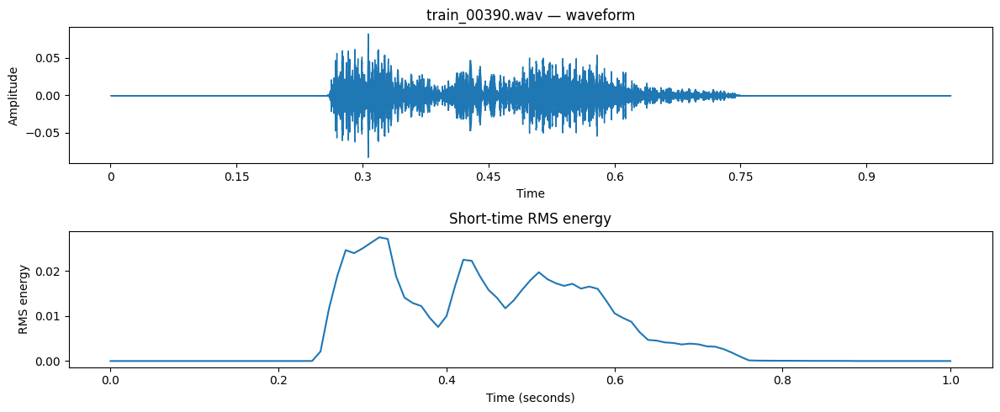

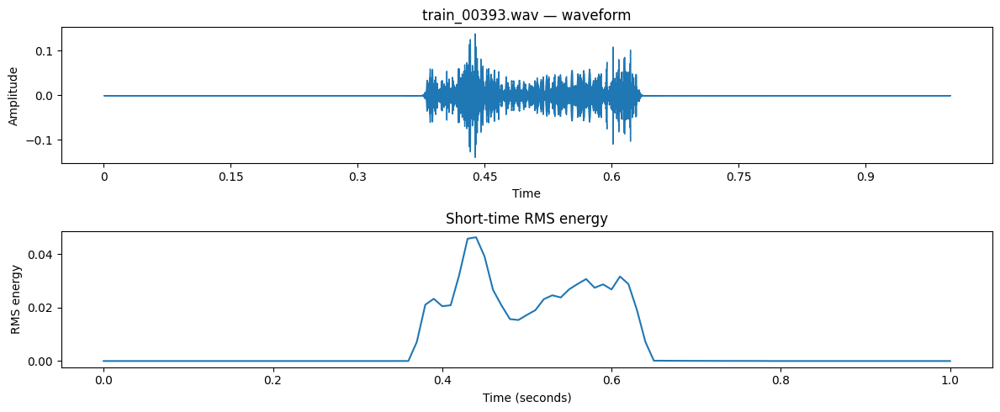

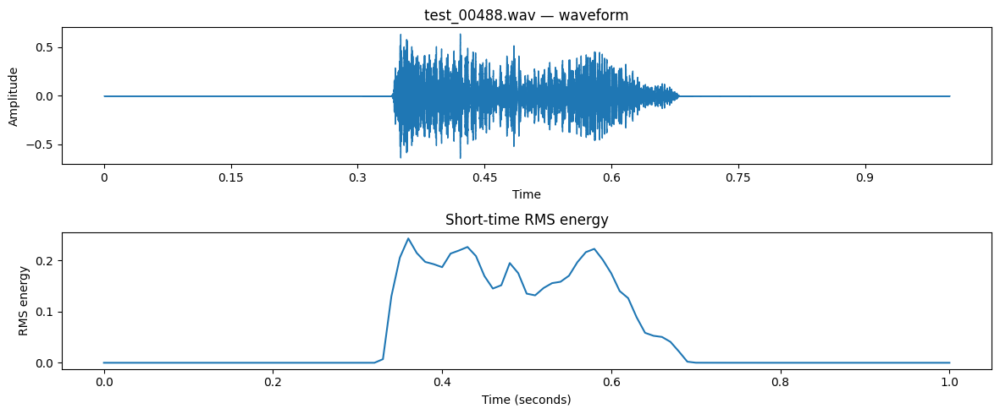

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import librosa
import librosa.display

samples_to_inspect = [
    "/content/drive/MyDrive/Multilingual_TinyML_KWS/data/processed_tamil_16k/train_00390.wav",
    "/content/drive/MyDrive/Multilingual_TinyML_KWS/data/processed_tamil_16k/train_00393.wav",
    "/content/drive/MyDrive/Multilingual_TinyML_KWS/data/processed_tamil_16k/test_00488.wav",
]

for path in samples_to_inspect:
    audio, sr = librosa.load(path, sr=16000, mono=True)

    fig, axes = plt.subplots(2, 1, figsize=(12, 5))

    librosa.display.waveshow(audio, sr=sr, ax=axes[0])
    axes[0].set_title(path.split("/")[-1] + " — waveform")
    axes[0].set_ylabel("Amplitude")

    rms = librosa.feature.rms(
        y=audio, frame_length=400, hop_length=160
    )[0]
    times = librosa.frames_to_time(
        np.arange(len(rms)), sr=sr, hop_length=160
    )
    axes[1].plot(times, rms)
    axes[1].set_title("Short-time RMS energy")
    axes[1].set_xlabel("Time (seconds)")
    axes[1].set_ylabel("RMS energy")

    plt.tight_layout()
    plt.show()

In [ ]:
import numpy as np
import librosa

def trim_and_pad(audio, sr=16000, target_seconds=1.0):
    # Trim only leading/trailing low-energy regions.
    trimmed, _ = librosa.effects.trim(
        audio,
        top_db=30,
        frame_length=400,
        hop_length=160
    )

    target_len = int(sr * target_seconds)

    # Keep a fixed one-second input.
    if len(trimmed) >= target_len:
        trimmed = trimmed[:target_len]
    else:
        trimmed = np.pad(
            trimmed,
            (0, target_len - len(trimmed))
        )

    return trimmed.astype(np.float32)

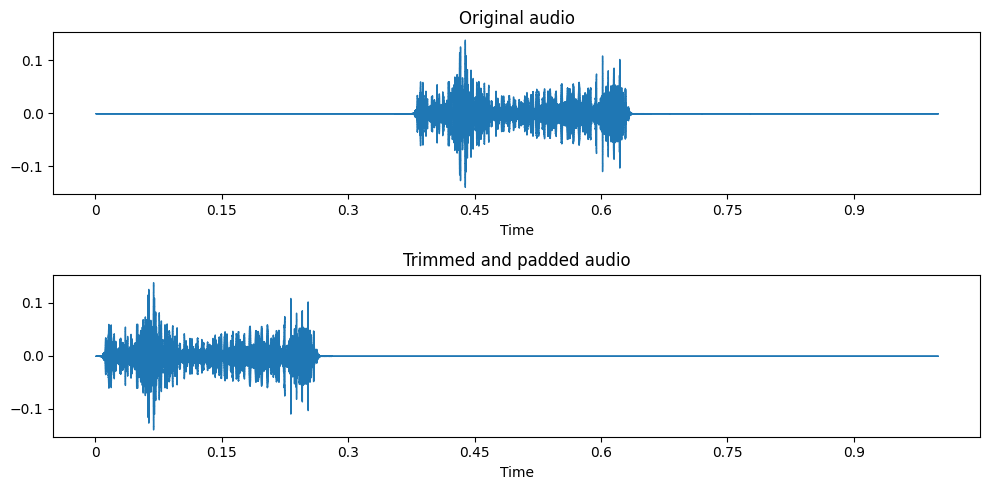

In [ ]:
import matplotlib.pyplot as plt
import librosa

path = "/content/drive/MyDrive/Multilingual_TinyML_KWS/data/processed_tamil_16k/train_00393.wav"

audio, sr = librosa.load(path, sr=16000, mono=True)
trimmed = trim_and_pad(audio, sr)

fig, axes = plt.subplots(2, 1, figsize=(10, 5))

librosa.display.waveshow(audio, sr=sr, ax=axes[0])
axes[0].set_title("Original audio")

librosa.display.waveshow(trimmed, sr=sr, ax=axes[1])
axes[1].set_title("Trimmed and padded audio")

plt.tight_layout()
plt.show()

In [ ]:
import numpy as np
import librosa
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, f1_score

SR = 16000
N_MELS = 40
N_FFT = 400
HOP_LENGTH = 160

def extract_logmel(path, use_trim=False):
    audio, sr = librosa.load(path, sr=SR, mono=True)

    if use_trim:
        audio = trim_and_pad(audio, sr=SR)

    mel = librosa.feature.melspectrogram(
        y=audio,
        sr=SR,
        n_fft=N_FFT,
        hop_length=HOP_LENGTH,
        n_mels=N_MELS,
        power=2.0
    )

    logmel = librosa.power_to_db(mel, ref=1.0)
    logmel = np.clip(logmel, -80, 20)

    # Same per-example normalization as the original pipeline.
    logmel = (
        logmel - logmel.mean()
    ) / (logmel.std() + 1e-8)

    return logmel.flatten()

def build_features(df, use_trim):
    return np.stack([
        extract_logmel(path, use_trim)
        for path in df["wav_path"]
    ])

Xtr_trim = build_features(train_group, True)
Xval_trim = build_features(val_group, True)
Xtest_trim = build_features(test_group, True)

svm_trim = make_pipeline(
    StandardScaler(),
    SVC(kernel="rbf", C=10, class_weight=None)
)

svm_trim.fit(Xtr_trim, y_train_group)

val_pred_trim = svm_trim.predict(Xval_trim)
test_pred_trim = svm_trim.predict(Xtest_trim)

print("TRIMMED SVM RESULTS")
print("Validation accuracy:",
      round(accuracy_score(y_val_group, val_pred_trim), 4))
print("Validation macro-F1:",
      round(f1_score(y_val_group, val_pred_trim, average="macro",
                     zero_division=0), 4))
print("Test accuracy:",
      round(accuracy_score(y_test_group, test_pred_trim), 4))
print("Test macro-F1:",
      round(f1_score(y_test_group, test_pred_trim, average="macro",
                     zero_division=0), 4))

print("\nOriginal baseline: accuracy = 0.4545, macro-F1 = 0.4164")

TRIMMED SVM RESULTS
Validation accuracy: 0.5118
Validation macro-F1: 0.4593
Test accuracy: 0.4394
Test macro-F1: 0.4185

Original baseline: accuracy = 0.4545, macro-F1 = 0.4164


In [ ]:
import numpy as np
import librosa
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, f1_score

SR = 16000
N_MELS = 40
N_FFT = 400
HOP_LENGTH = 160

def extract_logmel(path, use_trim=False):
    audio, sr = librosa.load(path, sr=SR, mono=True)

    if use_trim:
        audio = trim_and_pad(audio, sr=SR)

    mel = librosa.feature.melspectrogram(
        y=audio,
        sr=SR,
        n_fft=N_FFT,
        hop_length=HOP_LENGTH,
        n_mels=N_MELS,
        power=2.0
    )

    logmel = librosa.power_to_db(mel, ref=1.0)
    logmel = np.clip(logmel, -80, 20)

    # Same per-example normalization as the original pipeline.
    logmel = (
        logmel - logmel.mean()
    ) / (logmel.std() + 1e-8)

    return logmel.flatten()

def build_features(df, use_trim):
    return np.stack([
        extract_logmel(path, use_trim)
        for path in df["wav_path"]
    ])

Xtr_trim = build_features(train_group, True)
Xval_trim = build_features(val_group, True)
Xtest_trim = build_features(test_group, True)

svm_trim = make_pipeline(
    StandardScaler(),
    SVC(kernel="rbf", C=10, class_weight=None)
)

svm_trim.fit(Xtr_trim, y_train_group)

val_pred_trim = svm_trim.predict(Xval_trim)
test_pred_trim = svm_trim.predict(Xtest_trim)

print("TRIMMED SVM RESULTS")
print("Validation accuracy:",
      round(accuracy_score(y_val_group, val_pred_trim), 4))
print("Validation macro-F1:",
      round(f1_score(y_val_group, val_pred_trim, average="macro",
                     zero_division=0), 4))
print("Test accuracy:",
      round(accuracy_score(y_test_group, test_pred_trim), 4))
print("Test macro-F1:",
      round(f1_score(y_test_group, test_pred_trim, average="macro",
                     zero_division=0), 4))

print("\nOriginal baseline: accuracy = 0.4545, macro-F1 = 0.4164")

TRIMMED SVM RESULTS
Validation accuracy: 0.5118
Validation macro-F1: 0.4593
Test accuracy: 0.4394
Test macro-F1: 0.4185

Original baseline: accuracy = 0.4545, macro-F1 = 0.4164


In [ ]:
from sklearn.metrics import classification_report
import pandas as pd
import numpy as np

class_names = encoder.classes_

original_report = classification_report(
    y_test_group,
    test_pred_group,
    labels=np.arange(len(class_names)),
    target_names=class_names,
    output_dict=True,
    zero_division=0
)

trimmed_report = classification_report(
    y_test_group,
    test_pred_trim,
    labels=np.arange(len(class_names)),
    target_names=class_names,
    output_dict=True,
    zero_division=0
)

comparison = pd.DataFrame({
    "class": class_names,
    "original_precision": [
        original_report[c]["precision"] for c in class_names
    ],
    "trimmed_precision": [
        trimmed_report[c]["precision"] for c in class_names
    ],
    "original_recall": [
        original_report[c]["recall"] for c in class_names
    ],
    "trimmed_recall": [
        trimmed_report[c]["recall"] for c in class_names
    ],
    "original_f1": [
        original_report[c]["f1-score"] for c in class_names
    ],
    "trimmed_f1": [
        trimmed_report[c]["f1-score"] for c in class_names
    ],
})

comparison["f1_change"] = (
    comparison["trimmed_f1"] - comparison["original_f1"]
)

display(comparison.round(3).sort_values("f1_change"))

,class,original_precision,trimmed_precision,original_recall,trimmed_recall,original_f1,trimmed_f1,f1_change
1,இந்த,0.700,0.600,0.636,0.545,0.667,0.571,-0.095
3,என்ன,0.333,0.292,0.636,0.636,0.438,0.400,-0.037
0,அந்த,0.500,0.500,0.222,0.222,0.308,0.308,0.000
2,இனிய,1.000,1.000,0.500,0.500,0.667,0.667,0.000
4,என்ற,0.000,0.000,0.000,0.000,0.000,0.000,0.000
8,போல,1.000,1.000,0.250,0.250,0.400,0.400,0.000
9,வந்த,0.000,0.000,0.000,0.000,0.000,0.000,0.000
5,நல்ல,0.333,0.357,0.556,0.556,0.417,0.435,0.018
6,பெரிய,0.714,0.833,0.833,0.833,0.769,0.833,0.064
7,போக,0.333,0.400,1.000,1.000,0.500,0.571,0.071


In [ ]:
import pandas as pd
import numpy as np

actual = encoder.inverse_transform(y_test_group)
original_pred = encoder.inverse_transform(test_pred_group)
trimmed_pred = encoder.inverse_transform(test_pred_trim)

changes = pd.DataFrame({
    "actual": actual,
    "original_prediction": original_pred,
    "trimmed_prediction": trimmed_pred
})

changes["original_correct"] = (
    changes["actual"] == changes["original_prediction"]
)
changes["trimmed_correct"] = (
    changes["actual"] == changes["trimmed_prediction"]
)

print("Original correct, trimmed wrong:",
      ((changes["original_correct"]) &
       (~changes["trimmed_correct"])).sum())

print("Original wrong, trimmed correct:",
      ((~changes["original_correct"]) &
       (changes["trimmed_correct"])).sum())

print("\nChanged predictions:")
display(
    changes[
        changes["original_prediction"] !=
        changes["trimmed_prediction"]
    ]
)

Original correct, trimmed wrong: 4
Original wrong, trimmed correct: 3

Changed predictions:


,actual,original_prediction,trimmed_prediction,original_correct,trimmed_correct
2,அந்த,என்ன,நல்ல,False,False
3,அந்த,அந்த,இந்த,True,False
4,அந்த,இந்த,நல்ல,False,False
5,அந்த,நல்ல,அந்த,False,True
6,அந்த,நல்ல,என்ன,False,False
8,இந்த,என்ன,நல்ல,False,False
11,இந்த,இந்த,என்ன,True,False
24,நல்ல,பெரிய,என்ன,False,False
31,போல,போல,என்ன,True,False
32,போல,இந்த,என்ன,False,False


In [ ]:
import numpy as np
import pandas as pd
import librosa

from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, f1_score, classification_report

SR = 16000
N_FFT = 400
HOP_LENGTH = 160
N_MELS = 40

# Extract the same normalized log-Mel representation as before.
def get_logmel(path):
    audio, sr = librosa.load(path, sr=SR, mono=True)

    # Ensure a fixed one-second input.
    target_len = SR
    if len(audio) < target_len:
        audio = np.pad(audio, (0, target_len - len(audio)))
    else:
        audio = audio[:target_len]

    mel = librosa.feature.melspectrogram(
        y=audio,
        sr=SR,
        n_fft=N_FFT,
        hop_length=HOP_LENGTH,
        n_mels=N_MELS,
        power=2.0
    )

    logmel = librosa.power_to_db(mel, ref=1.0)
    logmel = np.clip(logmel, -80, 20)
    logmel = (logmel - logmel.mean()) / (logmel.std() + 1e-8)

    return logmel.astype(np.float32)


# Static features: original log-Mel.
# Delta features: log-Mel plus first-order temporal differences.
def extract_features(path, use_delta=False):
    logmel = get_logmel(path)

    if use_delta:
        delta = librosa.feature.delta(logmel, order=1)
        features = np.concatenate([logmel, delta], axis=0)
    else:
        features = logmel

    return features.flatten()


def make_feature_matrix(df, use_delta=False):
    return np.stack([
        extract_features(path, use_delta)
        for path in df["wav_path"]
    ])


# Reuse the existing speaker-disjoint partitions.
X_train_static = make_feature_matrix(train_group, False)
X_val_static = make_feature_matrix(val_group, False)

X_train_delta = make_feature_matrix(train_group, True)
X_val_delta = make_feature_matrix(val_group, True)

print("Static feature shape:", X_train_static.shape)
print("Delta feature shape:", X_train_delta.shape)


def train_svm(X_train, y_train):
    model = make_pipeline(
        StandardScaler(),
        SVC(kernel="rbf", C=10, class_weight=None)
    )
    model.fit(X_train, y_train)
    return model


# Train both models and compare validation macro-F1.
static_model = train_svm(X_train_static, y_train_group)
delta_model = train_svm(X_train_delta, y_train_group)

static_val_pred = static_model.predict(X_val_static)
delta_val_pred = delta_model.predict(X_val_delta)

static_val_f1 = f1_score(
    y_val_group, static_val_pred,
    average="macro", zero_division=0
)
delta_val_f1 = f1_score(
    y_val_group, delta_val_pred,
    average="macro", zero_division=0
)

validation_results = pd.DataFrame([
    {
        "model": "Static log-Mel SVM",
        "validation_accuracy": accuracy_score(
            y_val_group, static_val_pred
        ),
        "validation_macro_f1": static_val_f1
    },
    {
        "model": "Log-Mel + delta SVM",
        "validation_accuracy": accuracy_score(
            y_val_group, delta_val_pred
        ),
        "validation_macro_f1": delta_val_f1
    }
])

display(validation_results.round(4))

# Select using validation macro-F1 only.
if delta_val_f1 > static_val_f1:
    selected_name = "Log-Mel + delta SVM"
    selected_model = delta_model
    use_delta_for_test = True
else:
    selected_name = "Static log-Mel SVM"
    selected_model = static_model
    use_delta_for_test = False

print("Selected using validation macro-F1:", selected_name)

# Evaluate the selected model on the held-out test set.
X_test_selected = make_feature_matrix(
    test_group, use_delta=use_delta_for_test
)
test_pred_selected = selected_model.predict(X_test_selected)

print("\nSELECTED MODEL — HELD-OUT TEST RESULTS")
print("Test accuracy:",
      round(accuracy_score(y_test_group, test_pred_selected), 4))
print("Test macro-F1:",
      round(f1_score(
          y_test_group, test_pred_selected,
          average="macro", zero_division=0
      ), 4))

print("\nPer-class report:")
print(classification_report(
    y_test_group,
    test_pred_selected,
    labels=np.arange(len(encoder.classes_)),
    target_names=encoder.classes_,
    zero_division=0
))

Static feature shape: (323, 4040)
Delta feature shape: (323, 8080)


,model,validation_accuracy,validation_macro_f1
0,Static log-Mel SVM,0.4803,0.4404
1,Log-Mel + delta SVM,0.4646,0.4553


Selected using validation macro-F1: Log-Mel + delta SVM

SELECTED MODEL — HELD-OUT TEST RESULTS
Test accuracy: 0.4697
Test macro-F1: 0.4438

Per-class report:
              precision    recall  f1-score   support

        அந்த       0.57      0.44      0.50         9
        இந்த       0.60      0.55      0.57        11
        இனிய       0.50      0.50      0.50         2
        என்ன       0.37      0.64      0.47        11
        என்ற       0.00      0.00      0.00         5
        நல்ல       0.31      0.56      0.40         9
       பெரிய       0.67      0.67      0.67         6
         போக       0.50      1.00      0.67         2
         போல       1.00      0.50      0.67         4
        வந்த       0.00      0.00      0.00         7

    accuracy                           0.47        66
   macro avg       0.45      0.48      0.44        66
weighted avg       0.43      0.47      0.43        66



In [ ]:
import os
import json
import pandas as pd

ROOT = "/content/drive/MyDrive/Multilingual_TinyML_KWS"
DATA = os.path.join(ROOT, "data")

# 1. Summarize the existing Vaani audit.
audit_path = os.path.join(DATA, "vaani_five_language_audit.json")

print("=" * 60)
print("VAANI FIVE-LANGUAGE AUDIT")
print("=" * 60)

if os.path.exists(audit_path):
    with open(audit_path, "r", encoding="utf-8") as f:
        audit = json.load(f)

    print(json.dumps(audit, ensure_ascii=False, indent=2)[:12000])
else:
    print("Vaani audit JSON not found.")

# 2. Inspect the saved MSWC language inventory.
inventory_path = os.path.join(DATA, "mswc_tamil_word_inventory.csv")
split_path = os.path.join(DATA, "mswc_tamil_split_counts.csv")

print("\n" + "=" * 60)
print("MSWC INVENTORY FILES")
print("=" * 60)

for path in [inventory_path, split_path]:
    if os.path.exists(path):
        df = pd.read_csv(path)
        print(f"\n{os.path.basename(path)}: {df.shape}")
        display(df.head(8))
    else:
        print(f"Not found: {os.path.basename(path)}")

# 3. Check which processed audio files are already available.
processed_dir = os.path.join(DATA, "processed_tamil_16k")

if os.path.isdir(processed_dir):
    wav_count = sum(
        1 for f in os.listdir(processed_dir)
        if f.lower().endswith(".wav")
    )
    print(f"\nProcessed Tamil WAV files: {wav_count}")
else:
    print("\nProcessed Tamil audio directory not found.")

VAANI FIVE-LANGUAGE AUDIT
{
  "Kannada": {
    "scanned": 1500,
    "transcripts": 75,
    "speakers": 98,
    "examples": [
      "ಒಂದು ಬದಿಯಲ್ಲಿ ಒಂದು ಪ್ರಯಾಣಿಕರ ತಂಗುದಾಣ ಇರುವುದನ್ನು ನಾವು ಗಮನಿಸಬಹುದು ಆ ತಂಗುದಾಣ ಹಲವಾರು ಜನರು ಕುಳಿತುಕೊಂಡಿರುವುದನ್ನು ನಾವು ಗಮನಿಸಬಹುದು ನೋಡಲು ವಿಶಾಲವಾದ ರಸ್ತೆಯನ್ನು ಹೊಂದಿರುವುದನ್ನು ನಾವು ಇಲ್ಲಿ ನಾವು ಇಲ್ಲಿ ಕಾಣಬಹುದಾಗಿದೆ.",
      "ದೊಡ್ಡದಾದ ಎತ್ತರವಾದ ಮರಗಳಿಂದ ಕೂಡಿದ್ದು ನೋಡಲು ತುಂಬಾ ಚನ್ನಾಗಿದೆ ಇದೆ ಸುತ್ತಲೂ ಮರಗಳಿವೆ ನೋಡಲು ತುಂಬಾ ದೊಡ್ಡದ್ಗಿದ್ದು ಕನಸುತ್ತ ಇದೆ.",
      "ಇದೊಂದು ಶಾಸಕೀಯ ಸ್ನಾತಕೋತ್ತರ ಮಹಾ ವಿದ್ಯಾಲಯವೂ ಆಗಿದೆ.",
      "ಇಲ್ಲಿ ಎಲ್ಲಾ ತರಹದ ಸೂಪರ {Super} ರ್ಮಾರ್ಕೆಟ್ಗ {Market} ಳು ಸಿಗುತ್ತವೆ ಧಾನ್ಯಪದಾರ್ಥಗಳು ಸಿಗುತ್ತವೆ ಈ ಅಂಗಡಿಯಲ್ಲಿ ಹೋಗಿ ನೋಡಿದರೆ ಎಲ್ಲಾ ತರಹದ ಸಾಮಾನ್ಯ ಸಾಮಾನುಗಳು ಸಿಗುತ್ತವೆ.",
      "ಇಲ್ಲಿ ಮನೆ ಗಳನ್ನೂ ನೋಡ ಬಹುದು ಮತ್ತು ಗಿಡ ಮರಗಳನ್ನು ನಾವು ನೋಡ ಬಹುದು ಮ--"
    ]
  },
  "Tamil": {
    "scanned": 1500,
    "transcripts": 109,
    "speakers": 10,
    "examples": [
      "இவ்ளோ நல்ல இருக்கு பாருங்க சாமி இதெல்ல ஊருக்குள்ள தான் கொண்டு வராங்க",
      "கேட் கொஞ்சம் சினதா தான் இருக்கு{gate is short}",
      

,word,metadata_count,filename_count,example_filename
0,என்ன,104,104,common_voice_ta_21277677.opus
1,இந்த,88,88,common_voice_ta_21281957.opus
2,நல்ல,77,77,common_voice_ta_19093640.opus
3,அந்த,66,66,common_voice_ta_21279234.opus
4,வந்த,45,45,common_voice_ta_19385580.opus
5,பெரிய,30,30,common_voice_ta_21293971.opus
6,இனிய,28,28,common_voice_ta_19310478.opus
7,என்ற,28,28,common_voice_ta_20377917.opus



mswc_tamil_split_counts.csv: (187, 4)


,WORD,train,dev,test
0,என்ன,80,12,12
1,இந்த,70,9,9
2,நல்ல,61,8,8
3,அந்த,50,8,8
4,வந்த,35,5,5
5,பெரிய,23,4,3
6,இனிய,22,3,3
7,போக,20,4,3



Processed Tamil WAV files: 516


In [ ]:
import gzip
import json
import os

metadata_path = (
    "/content/drive/MyDrive/Multilingual_TinyML_KWS/"
    "data/mswc_metadata.json.gz"
)

with gzip.open(metadata_path, "rt", encoding="utf-8") as f:
    metadata = json.load(f)

print("Top-level type:", type(metadata).__name__)

if isinstance(metadata, dict):
    print("Top-level keys:", list(metadata.keys())[:40])

    # Find language codes without assuming a particular JSON schema.
    for key, value in metadata.items():
        if isinstance(value, dict):
            print(
                key,
                "entries:", len(value),
                "sample keys:", list(value.keys())[:8]
            )
        elif isinstance(value, list):
            print(key, "entries:", len(value))
        else:
            print(key, type(value).__name__)
else:
    print("Metadata entries:", len(metadata))

Top-level type: dict
Top-level keys: ['sl', 'br', 'ro', 'rm-sursilv', 'el', 'mt', 'id', 'sah', 'fy-NL', 'cv', 'sk', 'ia', 'lv', 'vi', 'ar', 'as', 'or', 'gn', 'sv-SE', 'dv', 'ta', 'rm-vallader', 'ka', 'zh-CN', 'cnh', 'ha', 'ga-IE', 'ky', 'mn', 'tr', 'lt', 'uk', 'et', 'cs', 'tt', 'pt', 'nl', 'cy', 'ru', 'eo']
sl entries: 4 sample keys: ['language', 'number_of_words', 'wordcounts', 'filenames']
br entries: 4 sample keys: ['language', 'number_of_words', 'wordcounts', 'filenames']
ro entries: 4 sample keys: ['language', 'number_of_words', 'wordcounts', 'filenames']
rm-sursilv entries: 4 sample keys: ['language', 'number_of_words', 'wordcounts', 'filenames']
el entries: 4 sample keys: ['language', 'number_of_words', 'wordcounts', 'filenames']
mt entries: 4 sample keys: ['language', 'number_of_words', 'wordcounts', 'filenames']
id entries: 4 sample keys: ['language', 'number_of_words', 'wordcounts', 'filenames']
sah entries: 4 sample keys: ['language', 'number_of_words', 'wordcounts', 'filena

In [ ]:

import gzip
import json

metadata_path = (
    "/content/drive/MyDrive/Multilingual_TinyML_KWS/"
    "data/mswc_metadata.json.gz"
)

with gzip.open(metadata_path, "rt", encoding="utf-8") as f:
    metadata = json.load(f)

targets = {
    "kn": "Kannada",
    "ta": "Tamil",
    "te": "Telugu",
    "ml": "Malayalam",
    "tcy": "Tulu",
}

print("MSWC LANGUAGE AVAILABILITY")
print("-" * 55)

for code, language in targets.items():
    entry = metadata.get(code)

    if entry is None:
        print(f"{language:12} ({code}): NOT PRESENT")
        continue

    print(f"\n{language} ({code})")
    print("Dataset language:", entry.get("language"))
    print("Number of words:", entry.get("number_of_words"))

    wordcounts = entry.get("wordcounts", {})
    filenames = entry.get("filenames", {})

    print("Word-count entries:", len(wordcounts))
    print("Filename entries:", len(filenames))
    print("Example words:", list(wordcounts.items())[:5])

print("\nTotal languages in metadata:", len(metadata))


MSWC LANGUAGE AVAILABILITY
-------------------------------------------------------
Kannada      (kn): NOT PRESENT

Tamil (ta)
Dataset language: Tamil
Number of words: 190
Word-count entries: 190
Filename entries: 190
Example words: [('இன்ப', 15), ('பாய்ச்சிய', 5), ('பெற்ற', 16), ('இருந்தன', 5), ('பாரத', 7)]
Telugu       (te): NOT PRESENT
Malayalam    (ml): NOT PRESENT
Tulu         (tcy): NOT PRESENT

Total languages in metadata: 51


In [ ]:

from datasets import load_dataset
import traceback

try:
    print("Checking Kannada FLEURS streaming...")

    ds = load_dataset(
        "google/fleurs",
        "kn_in",
        split="train",
        streaming=True,
        trust_remote_code=False,
    )

    print("Dataset stream created successfully.")
    print("Fetching first example...")

    example = next(iter(ds))
    print("SUCCESS!")
    print("Fields:", list(example.keys()))
    print("Transcript:", example.get("transcription"))
    print("Speaker ID:", example.get("speaker_id"))

except Exception as e:
    print("\nERROR TYPE:", type(e).__name__)
    print("ERROR MESSAGE:", repr(e))
    traceback.print_exc()


Checking Kannada FLEURS streaming...
Dataset stream created successfully.
Fetching first example...
SUCCESS!
Fields: ['id', 'num_samples', 'path', 'audio', 'transcription', 'raw_transcription', 'gender', 'lang_id', 'language', 'lang_group_id']
Transcript: ವಿದೇಶದಲ್ಲಿ ವಾಸಿಸಿದ ನಂತರ ನೀವು ನಿಮ್ಮಊರಿಗೆ ಮರಳಿದಾಗ ನೀವು ಹೊಸ ಸಂಸ್ಕೃತಿಗೆ ಹೊಂದಿಕೊಂಡಿದ್ದೀರಿ ಮತ್ತು ನಿಮ್ಮ ಕುಟುಂಬ ಸಂಸ್ಕೃತಿಯಿಂದ ಕೆಲವು ಅಭ್ಯಾಸಗಳನ್ನು ಕಳೆದುಕೊಂಡಿದ್ದೀರಿ
Speaker ID: None


In [ ]:

from datasets import load_dataset
import traceback

try:
    print("Checking Kannada FLEURS streaming...")

    ds = load_dataset(
        "google/fleurs",
        "kn_in",
        split="train",
        streaming=True,
        trust_remote_code=False,
    )

    print("Dataset stream created successfully.")
    print("Fetching first example...")

    example = next(iter(ds))
    print("SUCCESS!")
    print("Fields:", list(example.keys()))
    print("Transcript:", example.get("transcription"))
    print("Speaker ID:", example.get("speaker_id"))

except Exception as e:
    print("\nERROR TYPE:", type(e).__name__)
    print("ERROR MESSAGE:", repr(e))
    traceback.print_exc()


Checking Kannada FLEURS streaming...
Dataset stream created successfully.
Fetching first example...
SUCCESS!
Fields: ['id', 'num_samples', 'path', 'audio', 'transcription', 'raw_transcription', 'gender', 'lang_id', 'language', 'lang_group_id']
Transcript: ವಿದೇಶದಲ್ಲಿ ವಾಸಿಸಿದ ನಂತರ ನೀವು ನಿಮ್ಮಊರಿಗೆ ಮರಳಿದಾಗ ನೀವು ಹೊಸ ಸಂಸ್ಕೃತಿಗೆ ಹೊಂದಿಕೊಂಡಿದ್ದೀರಿ ಮತ್ತು ನಿಮ್ಮ ಕುಟುಂಬ ಸಂಸ್ಕೃತಿಯಿಂದ ಕೆಲವು ಅಭ್ಯಾಸಗಳನ್ನು ಕಳೆದುಕೊಂಡಿದ್ದೀರಿ
Speaker ID: None


In [ ]:

from datasets import load_dataset
import numpy as np

LANGUAGES = {
    "Kannada": "kn_in",
    "Tamil": "ta_in",
    "Telugu": "te_in",
    "Malayalam": "ml_in",
}

for language, config in LANGUAGES.items():
    print("\n" + "=" * 55)
    print(f"{language} ({config})")

    try:
        for split in ["train", "validation", "test"]:
            ds = load_dataset(
                "google/fleurs",
                config,
                split=split,
                streaming=True,
            )

            rows = list(ds.take(3))
            print(f"\n{split}: accessible; sampled {len(rows)}")

            if rows:
                row = rows[0]
                audio = row.get("audio")

                print("ID:", row.get("id"))
                print("Language ID:", row.get("lang_id"))
                print("Gender:", row.get("gender"))
                print("Transcript:", row.get("transcription", "")[:180])
                print("Audio sample rate:",
                      audio.get("sampling_rate") if isinstance(audio, dict) else None)

    except Exception as e:
        print("ERROR:", type(e).__name__, str(e)[:300])



Kannada (kn_in)

train: accessible; sampled 3
ID: 1053
Language ID: 47
Gender: 1
Transcript: ವಿದೇಶದಲ್ಲಿ ವಾಸಿಸಿದ ನಂತರ ನೀವು ನಿಮ್ಮಊರಿಗೆ ಮರಳಿದಾಗ ನೀವು ಹೊಸ ಸಂಸ್ಕೃತಿಗೆ ಹೊಂದಿಕೊಂಡಿದ್ದೀರಿ ಮತ್ತು ನಿಮ್ಮ ಕುಟುಂಬ ಸಂಸ್ಕೃತಿಯಿಂದ ಕೆಲವು ಅಭ್ಯಾಸಗಳನ್ನು ಕಳೆದುಕೊಂಡಿದ್ದೀರಿ
Audio sample rate: None

validation: accessible; sampled 3
ID: 1620
Language ID: 47
Gender: 1
Transcript: ಸರಳ ಸುವಾಸನೆ ಭಕ್ಷ್ಯಗಳನ್ನು ಒದಗಿಸುವ ಜಾವಾನೀಸ್ ಪಾಕಪದ್ಧತಿಯನ್ನು ಈಗ ದ್ವೀಪಸಮೂಹದಾದ್ಯಂತ ವ್ಯಾಪಕವಾಗಿ ಬಳಸಲಾಗುತ್ತದೆ. ಜಾವಾನೀಸ್‌ನ ನೆಚ್ಚಿನ ಮಸಾಲೆಗಳು ಕಡಲೆಕಾಯಿ ಮೆಣಸಿನಕಾಯಿ ಸಕ್ಕರೆ ಅದರಲ್ಲೂ ವಿಶೇಷವಾಗಿ ಜಾವಾ 
Audio sample rate: None

test: accessible; sampled 3
ID: 1693
Language ID: 47
Gender: 1
Transcript: ಆದರೆ ನಾಯಕನ ವಿಕೆಟ್ ಕಳೆದುಕೊಂಡ ನಂತರ ಭಾರತ 7 ವಿಕೆಟ್ ಕಳೆದುಕೊಂಡು ಕೇವಲ 36 ರನ್ಗಳಿಗೆ ತನ್ನ ಇನ್ನಿಂಗ್ಸ್ ಮುಗಿಸಿತು
Audio sample rate: None

Tamil (ta_in)

train: accessible; sampled 3
ID: 878
Language ID: 87
Gender: 1
Transcript: தொற்று நோயானது ஒரு வைரஸ் பேக்டீரியம் பூஞ்சை அல்லது பிற தொற்றுகள் போன்ற நுண்ணுயிர்களால் ஏற்படுவது
Audio sample rate: None

validation: accessible; sampl

In [ ]:

from datasets import load_dataset
import traceback

try:
    ds = load_dataset(
        "google/fleurs",
        "kn_in",
        split="train",
        streaming=True,
    )

    row = next(iter(ds))
    audio = row["audio"]

    print("Audio type:", type(audio))
    print("Audio decoder:", repr(audio))

    # Decode the lazy audio object if supported by this version.
    if hasattr(audio, "get_all_samples"):
        samples = audio.get_all_samples()
        print("Decoded audio successfully")
        print("Sample rate:", samples.sample_rate)
        print("Audio shape:", samples.data.shape)
    elif isinstance(audio, dict) and "array" in audio:
        print("Decoded audio successfully")
        print("Sample rate:", audio.get("sampling_rate"))
        print("Audio shape:", audio["array"].shape)
    else:
        print("Audio representation needs further inspection.")

except Exception as e:
    print("ERROR:", type(e).__name__, str(e))
    traceback.print_exc()


Audio type: <class 'datasets.features._torchcodec.AudioDecoder'>
Audio decoder: <datasets.features._torchcodec.AudioDecoder object at 0x7c9951cb4c20>
Decoded audio successfully
Sample rate: 16000
Audio shape: torch.Size([1, 226560])


In [ ]:

from datasets import load_dataset
from collections import Counter, defaultdict
import unicodedata

LANGUAGES = {
    "Kannada": ("kn_in", ["ಹೌದು", "ಬೇಡ", "ಬಾ", "ನಿಲ್ಲು"]),
    "Tamil": ("ta_in", ["ஆம்", "வேண்டாம்", "வா", "நில்"]),
    "Telugu": ("te_in", ["అవును", "వద్దు", "రా", "ఆపు"]),
    "Malayalam": ("ml_in", ["അതെ", "വേണ്ട", "വാ", "നിർത്തൂ"]),
}

def clean_token(token):
    token = unicodedata.normalize("NFC", token)
    return "".join(
        ch for ch in token
        if not unicodedata.category(ch).startswith("P")
    )

for language, (config, candidates) in LANGUAGES.items():
    print("\n" + "=" * 60)
    print(f"{language} ({config})")

    try:
        ds = load_dataset(
            "google/fleurs",
            config,
            split="train",
            streaming=True,
        )

        counts = Counter()
        examples = defaultdict(list)
        first_row = None
        scanned = 0

        for row in ds.take(500):
            scanned += 1

            if first_row is None:
                first_row = row

            transcript = unicodedata.normalize(
                "NFC", row.get("transcription", "")
            )
            tokens = [clean_token(t) for t in transcript.split()]

            for word in candidates:
                n = tokens.count(clean_token(word))
                counts[word] += n

                if n and len(examples[word]) < 2:
                    examples[word].append(transcript[:180])

        # Decode just one sample to verify audio for this language.
        audio = first_row["audio"]
        if hasattr(audio, "get_all_samples"):
            decoded = audio.get_all_samples()
            print(
                "Audio verified:",
                decoded.sample_rate,
                "Hz | shape:",
                tuple(decoded.data.shape),
            )
        else:
            print("Audio type:", type(audio).__name__)

        print("Training transcripts scanned:", scanned)
        print("Exact-token counts:", dict(counts))

        for word in candidates:
            if examples[word]:
                print(f"  {word}: {examples[word][0]}")

    except Exception as e:
        print("ERROR:", type(e).__name__, str(e)[:400])



Kannada (kn_in)
Audio verified: 16000 Hz | shape: (1, 226560)
Training transcripts scanned: 500
Exact-token counts: {'ಹೌದು': 1, 'ಬೇಡ': 2, 'ಬಾ': 0, 'ನಿಲ್ಲು': 0}
  ಹೌದು: ಹೌದು ರಾಜ ಟುಟಾಂಖಾಮುನ್ ಅನ್ನು ಕೆಲವೊಮ್ಮೆ ಕಿಂಗ್ ಟಟ್ ಅಥವಾ ದಿ ಬಾಯ್ ಕಿಂಗ್ ಎಂದು ಕರೆಯಲಾಗುತ್ತದೆ ಇವರು ಆಧುನಿಕ ಕಾಲದಲ್ಲಿ ಅತ್ಯಂತ ಪ್ರಸಿದ್ಧ ಪ್ರಾಚೀನ ಈಜಿಪ್ಟಿನ ರಾಜರಲ್ಲಿ 1ರು
  ಬೇಡ: ಆತ ಮುಂದುವರೆಸುತ್ತಾ ಹೇಳಿದ  ಈ ವಿಷಯ ಗಂಭೀರವಾಗಿದೆ. ಅದರೆ ಚಿಂತೆ ಬೇಡ ನಮ್ಮ ವ್ಯವಸ್ಥೆ ತಾನು ಕಾರ್ಯನಿರ್ವಹಿಸಬೇಕಾದ ರೀತಿಯಲ್ಲಿಯೇ ನಿರ್ವಹಿಸುತ್ತಿದೆ.

Tamil (ta_in)
Audio verified: 16000 Hz | shape: (1, 113280)
Training transcripts scanned: 500
Exact-token counts: {'ஆம்': 10, 'வேண்டாம்': 1, 'வா': 0, 'நில்': 0}
  ஆம்: 2009 ஆம் ஆண்டு ஹங்கேரிய கிராண்ட் பிரிக்ஸிற்குப் பிறகு பிக்கெட் ஜூனியர் நீக்கப்பட்டார்
  வேண்டாம்: கடந்த மாதம் acta வில் கையெழுத்திட்டபோது போலந்தில் பெரும் போராட்டங்கள் நடந்தன இதனால் போலந்து அரசாங்கம் இப்போது ஒப்பந்தத்தை ஒப்புக் கொள்ள வேண்டாம் என்று முடிவு செய்ய வழிவகுத்தது

Telugu (te_in)
Audio verified: 16000 Hz | shape: (1, 115200)
Training transcripts scanned: 500
Exact-

In [ ]:

from datasets import load_dataset
from collections import Counter
import unicodedata
import re

LANGUAGES = {
    "Kannada": "kn_in",
    "Tamil": "ta_in",
    "Telugu": "te_in",
    "Malayalam": "ml_in",
}

def tokenize(text):
    text = unicodedata.normalize("NFC", text.lower())
    # Keep letters from Indic scripts; split on whitespace and punctuation.
    tokens = re.split(r"[\s\W_]+", text, flags=re.UNICODE)
    return [t for t in tokens if len(t) >= 2]

for language, config in LANGUAGES.items():
    print("\n" + "=" * 60)
    print(f"{language} — top words from up to 1,000 training transcripts")

    try:
        ds = load_dataset(
            "google/fleurs",
            config,
            split="train",
            streaming=True,
        )

        counts = Counter()
        scanned = 0

        for row in ds.take(1000):
            scanned += 1
            counts.update(tokenize(row.get("transcription", "")))

        print("Transcripts scanned:", scanned)
        print("Top 25 words:")
        for word, count in counts.most_common(25):
            print(f"{word}: {count}")

    except Exception as e:
        print("ERROR:", type(e).__name__, str(e)[:300])



Kannada — top words from up to 1,000 training transcripts
Transcripts scanned: 1000
Top 25 words:
ಗಳ: 547
ಮತ: 479
ದರ: 423
ಯನ: 269
ತದ: 232
ಸಲ: 215
ಗಳನ: 203
ಯಲ: 188
ತವ: 158
ಪರ: 150
ಅನ: 149
ತರ: 143
ರವ: 139
ನಲ: 137
ವರ: 135
ಯವ: 132
ಅಥವ: 119
ಅವರ: 116
ಇದ: 108
ರತ: 104
ಕರ: 102
ರದ: 93
ತಮ: 93
ಯಕ: 93
ಟರ: 92

Tamil — top words from up to 1,000 training transcripts
Transcripts scanned: 1000
Top 25 words:
கள: 1826
பட: 670
மற: 379
என: 338
இர: 284
ஒர: 283
பத: 272
கப: 225
வத: 218
றத: 202
அத: 191
வர: 188
தத: 178
தல: 174
உள: 171
லத: 161
அல: 147
கட: 139
தன: 133
இந: 132
கம: 131
டத: 127
கவ: 127
ளத: 126
டன: 125

Telugu — top words from up to 1,000 training transcripts
Transcripts scanned: 1000
Top 25 words:
మర: 362
అన: 241
లన: 222
ఒక: 178
ఉన: 162
తర: 134
పర: 133
లక: 123
కల: 118
చడ: 110
లల: 101
రక: 99
ఇద: 99
యన: 98
రమ: 97
రణ: 92
పట: 89
జర: 88
కన: 87
టర: 87
సర: 86
రత: 80
నప: 77
వచ: 76
ఎక: 75

Malayalam — top words from up to 1,000 training transcripts
Transcripts scanned: 1000
Top 25 words:
നത: 360
കള: 356
ഒര:

In [ ]:

from datasets import load_dataset
from collections import Counter
import unicodedata
import regex  # Unicode-aware regex package

LANGUAGES = {
    "Kannada": "kn_in",
    "Tamil": "ta_in",
    "Telugu": "te_in",
    "Malayalam": "ml_in",
}

def tokenize_indic(text):
    text = unicodedata.normalize("NFC", text.lower())

    # Match sequences of letters, combining marks, and optional internal joiners.
    tokens = regex.findall(r"[\p{L}\p{M}]+", text)

    # Exclude very short fragments that are unlikely to be useful keywords.
    return [t for t in tokens if len(t) >= 2]

for language, config in LANGUAGES.items():
    print("\n" + "=" * 60)
    print(language)

    try:
        ds = load_dataset(
            "google/fleurs",
            config,
            split="train",
            streaming=True,
        )

        counts = Counter()
        for row in ds.take(1000):
            counts.update(tokenize_indic(row.get("transcription", "")))

        print("Top 25 complete tokens:")
        for word, count in counts.most_common(25):
            print(f"{word}: {count}")

    except Exception as e:
        print("ERROR:", type(e).__name__, str(e)[:400])



Kannada
Top 25 complete tokens:
ಮತ್ತು: 451
ಎಂದು: 139
ಅಥವಾ: 119
ಒಂದು: 97
ನೀವು: 70
ನಂತರ: 69
ಇದು: 68
ಅವರು: 64
ಮೇಲೆ: 57
ಆದರೆ: 56
ತಮ್ಮ: 56
ನಲ್ಲಿ: 56
ಕೆಲವು: 48
ಅನ್ನು: 47
ಯಾವುದೇ: 46
ಹೆಚ್ಚಿನ: 45
ಗಳು: 44
ಗೆ: 42
ಮೂಲಕ: 38
ಹಾಗೂ: 37
ಅವರ: 37
ಸಾಮಾನ್ಯವಾಗಿ: 37
ಹೆಚ್ಚು: 36
ಬಗ್ಗೆ: 36
ಗಳನ್ನು: 36

Tamil
Top 25 complete tokens:
மற்றும்: 325
ஒரு: 238
என்று: 120
அல்லது: 119
இந்த: 100
சில: 76
நீங்கள்: 63
உள்ள: 58
இது: 58
ஆம்: 52
ஆனால்: 51
என்பது: 51
முதல்: 50
அந்த: 48
மேலும்: 47
இருக்கும்: 45
மிகவும்: 41
உள்ளது: 40
அதன்: 37
பல: 36
வேண்டும்: 36
அவை: 36
புதிய: 33
அவர்: 33
இருந்து: 32

Telugu
Top 25 complete tokens:
మరియు: 302
ఒక: 171
యొక్క: 114
లేదా: 107
లో: 105
చాలా: 99
ఇది: 93
మీరు: 77
నుండి: 71
ఉంటుంది: 71
కూడా: 69
ఉన్న: 68
ఉంది: 64
అని: 59
ఇంకా: 47
కు: 44
ద్వారా: 43
కోసం: 42
ను: 41
మంది: 41
కానీ: 41
ఎక్కువ: 39
ఉంటాయి: 38
కొన్ని: 38
మీ: 36

Malayalam
Top 25 complete tokens:
ഒരു: 302
നിന്ന്: 62
ഇത്: 61
അല്ലെങ്കിൽ: 53
നിങ്ങൾ: 51
കൂടാതെ: 48
വളരെ: 47
പറഞ്ഞു: 44
ഏറ്റവും: 43
അവരുടെ: 42
കൂടുതൽ: 41
എന്ന്: 40
എന്നാൽ: 

In [ ]:

from datasets import load_dataset
from collections import Counter
import unicodedata
import regex

CANDIDATES = {
    "Kannada": ("kn_in", ["ಹೌದು", "ಬೇಡ", "ನಿಲ್ಲು", "ಹೋಗು", "ಕೊಡು", "ಬಿಡು"]),
    "Tamil": ("ta_in", ["ஆம்", "வேண்டாம்", "நில்", "போ", "கொடு", "விடு"]),
    "Telugu": ("te_in", ["అవును", "వద్దు", "ఆపు", "పో", "ఇవ్వు", "వెళ్లు"]),
    "Malayalam": ("ml_in", ["അതെ", "വേണ്ട", "നിർത്തൂ", "പോ", "തരൂ", "വിടൂ"]),
}

def tokens(text):
    text = unicodedata.normalize("NFC", text.lower())
    return regex.findall(r"[\p{L}\p{M}]+", text)

for language, (config, words) in CANDIDATES.items():
    print("\n" + "=" * 55)
    print(language)

    try:
        ds = load_dataset(
            "google/fleurs", config,
            split="train", streaming=True
        )

        counts = Counter()
        for row in ds.take(1000):
            counts.update(tokens(row.get("transcription", "")))

        for word in words:
            print(f"{word}: {counts[word]}")

    except Exception as e:
        print("ERROR:", type(e).__name__, str(e)[:250])



Kannada
ಹೌದು: 1
ಬೇಡ: 2
ನಿಲ್ಲು: 0
ಹೋಗು: 0
ಕೊಡು: 0
ಬಿಡು: 0

Tamil
ஆம்: 52
வேண்டாம்: 2
நில்: 0
போ: 2
கொடு: 0
விடு: 0

Telugu
అవును: 0
వద్దు: 0
ఆపు: 0
పో: 0
ఇవ్వు: 0
వెళ్లు: 0

Malayalam
അതെ: 2
വേണ്ട: 5
നിർത്തൂ: 0
പോ: 0
തരൂ: 0
വിടൂ: 0


In [ ]:

from datasets import load_dataset
from collections import Counter
import unicodedata
import regex

CANDIDATES = {
    "Kannada": ("kn_in", ["ಹೌದು", "ಬೇಡ", "ನಿಲ್ಲು", "ಹೋಗು", "ಕೊಡು", "ಬಿಡು"]),
    "Tamil": ("ta_in", ["ஆம்", "வேண்டாம்", "நில்", "போ", "கொடு", "விடு"]),
    "Telugu": ("te_in", ["అవును", "వద్దు", "ఆపు", "పో", "ఇవ్వు", "వెళ్లు"]),
    "Malayalam": ("ml_in", ["അതെ", "വേണ്ട", "നിർത്തൂ", "പോ", "തരൂ", "വിടൂ"]),
}

def tokens(text):
    text = unicodedata.normalize("NFC", text.lower())
    return regex.findall(r"[\p{L}\p{M}]+", text)

for language, (config, words) in CANDIDATES.items():
    print("\n" + "=" * 55)
    print(language)

    try:
        ds = load_dataset(
            "google/fleurs", config,
            split="train", streaming=True
        )

        counts = Counter()
        for row in ds.take(1000):
            counts.update(tokens(row.get("transcription", "")))

        for word in words:
            print(f"{word}: {counts[word]}")

    except Exception as e:
        print("ERROR:", type(e).__name__, str(e)[:250])



Kannada
ಹೌದು: 1
ಬೇಡ: 2
ನಿಲ್ಲು: 0
ಹೋಗು: 0
ಕೊಡು: 0
ಬಿಡು: 0

Tamil
ஆம்: 52
வேண்டாம்: 2
நில்: 0
போ: 2
கொடு: 0
விடு: 0

Telugu
అవును: 0
వద్దు: 0
ఆపు: 0
పో: 0
ఇవ్వు: 0
వెళ్లు: 0

Malayalam
അതെ: 2
വേണ്ട: 5
നിർത്തൂ: 0
പോ: 0
തരൂ: 0
വിടൂ: 0


In [ ]:

from datasets import load_dataset
from collections import Counter
import unicodedata
import regex

CANDIDATES = {
    "Kannada": (
        "kn_in",
        ["ಹೌದು", "ಬೇಡ", "ಇಲ್ಲ", "ಸರಿ", "ಬನ್ನಿ", "ಹೋಗಿ", "ಕೊಡಿ", "ನೋಡಿ"]
    ),
    "Tamil": (
        "ta_in",
        ["ஆம்", "இல்லை", "சரி", "வாங்க", "போங்கள்", "கொடுங்கள்", "பாருங்கள்", "வேண்டும்"]
    ),
    "Telugu": (
        "te_in",
        ["అవును", "కాదు", "లేదు", "సరే", "రండి", "వెళ్ళండి", "ఇవ్వండి", "చూడండి"]
    ),
    "Malayalam": (
        "ml_in",
        ["അതെ", "ഇല്ല", "ശരി", "വരൂ", "പോകൂ", "തരൂ", "നോക്കൂ", "വേണം"]
    ),
}

def tokenize(text):
    text = unicodedata.normalize("NFC", text.lower())
    return regex.findall(r"[\p{L}\p{M}]+", text)

for language, (config, candidates) in CANDIDATES.items():
    print("\n" + "=" * 60)
    print(language)

    try:
        ds = load_dataset(
            "google/fleurs",
            config,
            split="train",
            streaming=True,
        )

        counts = Counter()
        scanned = 0

        for row in ds.take(5000):
            scanned += 1
            counts.update(tokenize(row.get("transcription", "")))

        print("Transcripts scanned:", scanned)
        print("Candidate counts:")
        for word in candidates:
            print(f"  {word}: {counts[word]}")

    except Exception as e:
        print("ERROR:", type(e).__name__, str(e)[:300])



Kannada
Transcripts scanned: 2283
Candidate counts:
  ಹೌದು: 5
  ಬೇಡ: 2
  ಇಲ್ಲ: 6
  ಸರಿ: 8
  ಬನ್ನಿ: 0
  ಹೋಗಿ: 9
  ಕೊಡಿ: 0
  ನೋಡಿ: 7

Tamil
Transcripts scanned: 2367
Candidate counts:
  ஆம்: 122
  இல்லை: 49
  சரி: 6
  வாங்க: 4
  போங்கள்: 0
  கொடுங்கள்: 1
  பாருங்கள்: 3
  வேண்டும்: 94

Telugu
Transcripts scanned: 2302
Candidate counts:
  అవును: 0
  కాదు: 31
  లేదు: 17
  సరే: 0
  రండి: 0
  వెళ్ళండి: 0
  ఇవ్వండి: 2
  చూడండి: 8

Malayalam
Transcripts scanned: 3043
Candidate counts:
  അതെ: 3
  ഇല്ല: 12
  ശരി: 2
  വരൂ: 0
  പോകൂ: 0
  തരൂ: 0
  നോക്കൂ: 0
  വേണം: 9


In [ ]:
import os

ROOT = "/content/drive/MyDrive/Multilingual_TinyML_KWS"

for folder in ["data", "results", "models", "reports"]:
    path = os.path.join(ROOT, folder)
    print(f"\n{'=' * 20} {folder} {'=' * 20}")

    if not os.path.isdir(path):
        print("Folder missing")
        continue

    for name in sorted(os.listdir(path)):
        full = os.path.join(path, name)

        if os.path.isfile(full):
            print(f"{name}  ({os.path.getsize(full) / 1024:.1f} KB)")
        else:
            print(f"{name}/")


==================== data ====================
mswc_metadata.json.gz  (105228.8 KB)
mswc_tamil_pilot_manifest.csv  (101.2 KB)
mswc_tamil_pilot_processed.csv  (128.2 KB)
mswc_tamil_split_counts.csv  (4.3 KB)
mswc_tamil_word_inventory.csv  (9.7 KB)
processed_tamil_16k/
sample_audio/
vaani_five_language_audit.json  (7.6 KB)

==================== results ====================
tamil_kws_cnn_baseline.json  (0.6 KB)
tamil_kws_cnn_confusion_matrix.csv  (0.4 KB)
tamil_kws_cnn_test_predictions.csv  (14.6 KB)
tamil_svm_tuned_confusion_matrix.csv  (0.4 KB)
tamil_svm_tuned_metrics.json  (0.1 KB)
tamil_svm_tuned_test_predictions.csv  (1.5 KB)

==================== models ====================
tamil_kws_cnn_best.keras  (88.0 KB)

==================== reports ====================


In [ ]:

import os
import json
import pandas as pd

ROOT = "/content/drive/MyDrive/Multilingual_TinyML_KWS"
DATA = os.path.join(ROOT, "data")
RESULTS = os.path.join(ROOT, "results")

manifest_path = os.path.join(DATA, "mswc_tamil_pilot_processed.csv")
df = pd.read_csv(manifest_path)

print("=" * 60)
print("TAMIL DATASET VALIDATION")
print("=" * 60)
print("Rows:", len(df))
print("Columns:", df.columns.tolist())

if "split" in df.columns:
    print("\nRows by source split:")
    print(df["split"].value_counts(dropna=False).to_string())

if "word" in df.columns:
    print("\nUnique word labels:", df["word"].nunique())
    print("Class counts:")
    print(df["word"].value_counts().to_string())

if "speaker" in df.columns:
    print("\nUnique speakers:", df["speaker"].nunique())
    if "split" in df.columns:
        speaker_sets = {
            s: set(df.loc[df["split"] == s, "speaker"].dropna())
            for s in df["split"].unique()
        }
        print("\nSpeaker overlap in existing source splits:")
        split_names = list(speaker_sets)
        for i, a in enumerate(split_names):
            for b in split_names[i + 1:]:
                print(f"{a} vs {b}: {len(speaker_sets[a] & speaker_sets[b])}")

if "wav_path" in df.columns:
    df["file_exists"] = df["wav_path"].apply(os.path.isfile)
    print("\nAudio paths existing:", int(df["file_exists"].sum()), "/", len(df))
    print("Missing audio paths:", int((~df["file_exists"]).sum()))

print("\n" + "=" * 60)
print("SAVED EXPERIMENT RESULTS")
print("=" * 60)

for filename in [
    "tamil_kws_cnn_baseline.json",
    "tamil_svm_tuned_metrics.json",
]:
    path = os.path.join(RESULTS, filename)
    print(f"\n{filename}")

    if os.path.isfile(path):
        with open(path, "r", encoding="utf-8") as f:
            print(json.dumps(json.load(f), indent=2, ensure_ascii=False))
    else:
        print("Not found")


TAMIL DATASET VALIDATION
Rows: 516
Columns: ['source_index', 'split', 'word', 'speaker', 'gender', 'wav_path', 'sample_rate', 'duration_s']

Rows by source split:
split
train    397
test      60
dev       59

Unique word labels: 10
Class counts:
word
என்ன     104
இந்த      88
நல்ல      77
அந்த      66
வந்த      45
பெரிய     30
என்ற      28
இனிய      28
போக       27
போல       23

Unique speakers: 58

Speaker overlap in existing source splits:
train vs dev: 14
train vs test: 14
dev vs test: 13

Audio paths existing: 516 / 516
Missing audio paths: 0

SAVED EXPERIMENT RESULTS

tamil_kws_cnn_baseline.json
{
  "experiment": "tamil_10class_logmel_cnn_baseline",
  "num_classes": 10,
  "train_clips": 397,
  "dev_clips": 59,
  "test_clips": 60,
  "accuracy": 0.15,
  "macro_f1": 0.045959595959595964,
  "training_seconds": 29.00373911857605,
  "parameter_count": 2274,
  "sample_rate": 16000,
  "n_mels": 40,
  "n_fft": 400,
  "hop_length": 160,
  "seed": 42,
  "classes": [
    "அந்த",
    "இந்த",
 

In [ ]:

import os
import json
from datetime import datetime

ROOT = "/content/drive/MyDrive/Multilingual_TinyML_KWS"
RESULTS = os.path.join(ROOT, "results")
REPORTS = os.path.join(ROOT, "reports")
os.makedirs(RESULTS, exist_ok=True)
os.makedirs(REPORTS, exist_ok=True)

# Read the actual saved baseline metrics.
with open(os.path.join(RESULTS, "tamil_kws_cnn_baseline.json"),
          encoding="utf-8") as f:
    cnn = json.load(f)

with open(os.path.join(RESULTS, "tamil_svm_tuned_metrics.json"),
          encoding="utf-8") as f:
    svm = json.load(f)

summary = {
    "project": "Multilingual TinyML Keyword Spotting",
    "generated_at": datetime.now().isoformat(timespec="seconds"),
    "current_data_status": {
        "language_with_processed_pilot": "Tamil",
        "processed_clips": 516,
        "classes": 10,
        "speakers": 58,
        "missing_audio_files": 0
    },
    "original_split_results": {
        "cnn": cnn,
        "svm": svm,
        "warning": (
            "Original source splits have speaker overlap; "
            "these test scores are preliminary, not unseen-speaker estimates."
        )
    },
    "speaker_disjoint_experiment": {
        "model": "RBF-SVM with static plus delta log-Mel features",
        "test_samples": 66,
        "test_accuracy": 0.4697,
        "test_macro_f1": 0.4438,
        "validation_accuracy": 0.4646,
        "validation_macro_f1": 0.4553,
        "status": (
            "Exploratory: the test set was examined during multiple "
            "experiments, so it is not a pristine final benchmark."
        )
    },
    "multilingual_status": {
        "fleurs_accessible": [
            "Kannada", "Tamil", "Telugu", "Malayalam"
        ],
        "isolated_command_dataset_verified": False,
        "tulu_dataset_verified": False,
        "five_language_model_trained": False
    },
    "next_steps": [
        "Establish labeled command recordings for all target languages.",
        "Use a speaker-independent final evaluation split.",
        "Train a common multilingual model on verified clips.",
        "Export a deployable model and measure size and latency."
    ]
}

json_path = os.path.join(RESULTS, "project_execution_summary.json")
with open(json_path, "w", encoding="utf-8") as f:
    json.dump(summary, f, indent=2, ensure_ascii=False)

report = f"""# Multilingual TinyML Keyword Spotting
## Current Execution Report

### 1. Tamil pilot
- Processed clips: 516
- Classes: 10
- Speakers represented: 58
- Missing audio files: 0
- Sample rate: 16 kHz

### 2. Baseline experiments

**CNN**
- Test accuracy: {cnn.get("accuracy", "N/A")}
- Macro-F1: {cnn.get("macro_f1", "N/A")}
- Parameters: {cnn.get("parameter_count", "N/A")}

**RBF-SVM — original source split**
- Test accuracy: {svm.get("test_accuracy", "N/A")}
- Macro-F1: {svm.get("test_macro_f1", "N/A")}

The original source splits contain overlapping speakers. These results
must not be interpreted as a strict unseen-speaker benchmark.

### 3. Exploratory speaker-disjoint experiment
- Model: RBF-SVM with static plus delta log-Mel features
- Test clips: 66
- Accuracy: 46.97%
- Macro-F1: 0.4438

The test set was examined during multiple exploratory comparisons.
Treat these metrics as exploratory rather than a pristine final result.

### 4. Multilingual data status
FLEURS streaming was verified for Kannada, Tamil, Telugu and Malayalam.
FLEURS contains sentence-level speech; a verified isolated-command
dataset has not yet been established for these languages. Tulu data
and five-language model training remain pending.

### 5. Next work
1. Obtain and validate labeled command clips across the five languages.
2. Ensure speakers do not overlap between training and final testing.
3. Train and evaluate a shared multilingual baseline.
4. Export and measure the deployable model, including size and latency.
5. Complete error analysis and final documentation.
"""

report_path = os.path.join(REPORTS, "execution_report_draft.md")
with open(report_path, "w", encoding="utf-8") as f:
    f.write(report)

print("Saved project summary:", json_path)
print("Saved report draft:", report_path)
print("\nCurrent verified status:")
print("Tamil pilot: 516 clips, 10 classes, 58 speakers")
print("CNN parameters:", cnn.get("parameter_count"))
print("Original-split SVM accuracy:", svm.get("test_accuracy"))
print("Five-language model trained: No")
print("Report artifacts created successfully.")


Saved project summary: /content/drive/MyDrive/Multilingual_TinyML_KWS/results/project_execution_summary.json
Saved report draft: /content/drive/MyDrive/Multilingual_TinyML_KWS/reports/execution_report_draft.md

Current verified status:
Tamil pilot: 516 clips, 10 classes, 58 speakers
CNN parameters: 2274
Original-split SVM accuracy: 0.55
Five-language model trained: No
Report artifacts created successfully.


In [ ]:

import os
import json
import tensorflow as tf

ROOT = "/content/drive/MyDrive/Multilingual_TinyML_KWS"
MODEL_DIR = os.path.join(ROOT, "models")
RESULTS_DIR = os.path.join(ROOT, "results")
os.makedirs(MODEL_DIR, exist_ok=True)
os.makedirs(RESULTS_DIR, exist_ok=True)

keras_path = os.path.join(MODEL_DIR, "tamil_kws_cnn_best.keras")

if not os.path.isfile(keras_path):
    raise FileNotFoundError(f"Existing CNN not found: {keras_path}")

model = tf.keras.models.load_model(keras_path, compile=False)

print("TensorFlow:", tf.__version__)
print("Input shape:", model.input_shape)
print("Output shape:", model.output_shape)
print("Parameters:", model.count_params())

# 1. Standard float32 TensorFlow Lite export
converter = tf.lite.TFLiteConverter.from_keras_model(model)
float_tflite = converter.convert()

float_path = os.path.join(MODEL_DIR, "tamil_kws_cnn_float32.tflite")
with open(float_path, "wb") as f:
    f.write(float_tflite)

# 2. Dynamic-range quantization
converter = tf.lite.TFLiteConverter.from_keras_model(model)
converter.optimizations = [tf.lite.Optimize.DEFAULT]
quant_tflite = converter.convert()

quant_path = os.path.join(MODEL_DIR, "tamil_kws_cnn_dynamic_quant.tflite")
with open(quant_path, "wb") as f:
    f.write(quant_tflite)

float_bytes = os.path.getsize(float_path)
quant_bytes = os.path.getsize(quant_path)

summary = {
    "model": "Tamil CNN baseline",
    "parameters": int(model.count_params()),
    "input_shape": str(model.input_shape),
    "output_shape": str(model.output_shape),
    "float32_tflite_bytes": float_bytes,
    "dynamic_quant_tflite_bytes": quant_bytes,
    "float32_tflite_kb": round(float_bytes / 1024, 2),
    "dynamic_quant_tflite_kb": round(quant_bytes / 1024, 2),
    "size_reduction_percent": round(
        (1 - quant_bytes / float_bytes) * 100, 2
    ),
    "note": (
        "Dynamic-range quantization applied. Accuracy and latency "
        "must be measured separately before claiming deployment readiness."
    )
}

metrics_path = os.path.join(RESULTS_DIR, "tamil_tflite_conversion.json")
with open(metrics_path, "w", encoding="utf-8") as f:
    json.dump(summary, f, indent=2)

print("\nCONVERSION RESULTS")
print("-" * 45)
print(f"Float32 TFLite: {float_bytes:,} bytes ({float_bytes/1024:.2f} KB)")
print(f"Dynamic quant:  {quant_bytes:,} bytes ({quant_bytes/1024:.2f} KB)")
print(f"Size reduction: {summary['size_reduction_percent']}%")
print("\nSaved:", float_path)
print("Saved:", quant_path)
print("Metrics:", metrics_path)


TensorFlow: 2.21.0
Input shape: (None, 40, 101, 1)
Output shape: (None, 10)
Parameters: 2274
Saved artifact at '/tmp/tmp_qhrn7xb'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 40, 101, 1), dtype=tf.float32, name='input_layer')
Output Type:
  TensorSpec(shape=(None, 10), dtype=tf.float32, name=None)
Captures:
  136997977713808: TensorSpec(shape=(), dtype=tf.resource, name=None)
  136997977714384: TensorSpec(shape=(), dtype=tf.resource, name=None)
  136997977714192: TensorSpec(shape=(), dtype=tf.resource, name=None)
  136997977714768: TensorSpec(shape=(), dtype=tf.resource, name=None)
  136997977713616: TensorSpec(shape=(), dtype=tf.resource, name=None)
  136997977715536: TensorSpec(shape=(), dtype=tf.resource, name=None)
  136997977715344: TensorSpec(shape=(), dtype=tf.resource, name=None)
  136997977715728: TensorSpec(shape=(), dtype=tf.resource, name=None)
  136997977716112: TensorSpec(shape=(), dtype=tf.resource, name=

In [ ]:

import os, json, time
import numpy as np
import pandas as pd
import tensorflow as tf
import soundfile as sf
import librosa

ROOT = "/content/drive/MyDrive/Multilingual_TinyML_KWS"
MODEL_DIR = os.path.join(ROOT, "models")
DATA_DIR = os.path.join(ROOT, "data")
RESULTS_DIR = os.path.join(ROOT, "results")

keras_model = tf.keras.models.load_model(
    os.path.join(MODEL_DIR, "tamil_kws_cnn_best.keras"),
    compile=False
)

manifest_path = os.path.join(DATA_DIR, "mswc_tamil_pilot_processed.csv")
df = pd.read_csv(manifest_path)
test_df = df[df["split"] == "test"].reset_index(drop=True)

# Match the log-Mel representation used by the CNN baseline.
def make_features(path):
    audio, sr = sf.read(path, dtype="float32")
    if audio.ndim > 1:
        audio = audio.mean(axis=1)
    if sr != 16000:
        audio = librosa.resample(audio, orig_sr=sr, target_sr=16000)

    audio = audio[:16000]
    if len(audio) < 16000:
        audio = np.pad(audio, (0, 16000 - len(audio)))

    mel = librosa.feature.melspectrogram(
        y=audio, sr=16000, n_fft=400, hop_length=160,
        n_mels=40, power=2.0
    )
    feat = librosa.power_to_db(mel, ref=1.0)
    feat = np.clip(feat, -80, 20)
    feat = (feat - feat.mean()) / (feat.std() + 1e-6)
    return feat.astype(np.float32)[..., np.newaxis]

X_test = np.stack([make_features(p) for p in test_df["wav_path"]])
labels = sorted(df["word"].unique())
label_to_id = {w: i for i, w in enumerate(labels)}
y_true = np.array([label_to_id[w] for w in test_df["word"]])

# Keras reference predictions
keras_probs = keras_model.predict(X_test, verbose=0)
keras_pred = np.argmax(keras_probs, axis=1)

def evaluate_tflite(filename):
    path = os.path.join(MODEL_DIR, filename)
    interpreter = tf.lite.Interpreter(model_path=path)
    interpreter.allocate_tensors()
    inp = interpreter.get_input_details()[0]
    out = interpreter.get_output_details()[0]

    # Warm-up
    interpreter.set_tensor(inp["index"], X_test[0:1])
    interpreter.invoke()

    preds, latencies = [], []
    for x in X_test:
        interpreter.set_tensor(inp["index"], x[np.newaxis, ...])
        start = time.perf_counter()
        interpreter.invoke()
        latencies.append((time.perf_counter() - start) * 1000)
        preds.append(interpreter.get_tensor(out["index"])[0])

    probs = np.array(preds)
    pred = probs.argmax(axis=1)
    return {
        "file": filename,
        "size_bytes": os.path.getsize(path),
        "accuracy": float(np.mean(pred == y_true)),
        "macro_f1": float(tf.keras.metrics.F1Score(
            average="macro", threshold=None
        )(tf.one_hot(y_true, len(labels)), probs).numpy()),
        "agreement_with_keras": float(np.mean(pred == keras_pred)),
        "mean_latency_ms": float(np.mean(latencies)),
        "median_latency_ms": float(np.median(latencies)),
        "p95_latency_ms": float(np.percentile(latencies, 95))
    }

results = {
    "test_samples": len(X_test),
    "preprocessing_shape": list(X_test.shape),
    "keras_accuracy_on_recreated_features": float(np.mean(keras_pred == y_true)),
    "float32_tflite": evaluate_tflite("tamil_kws_cnn_float32.tflite"),
    "dynamic_quant_tflite": evaluate_tflite("tamil_kws_cnn_dynamic_quant.tflite")
}

out_path = os.path.join(RESULTS_DIR, "tamil_tflite_validation.json")
with open(out_path, "w", encoding="utf-8") as f:
    json.dump(results, f, ensure_ascii=False, indent=2)

print(json.dumps(results, ensure_ascii=False, indent=2))
print("\nSaved validation results:", out_path)


{
  "test_samples": 60,
  "preprocessing_shape": [
    60,
    40,
    101,
    1
  ],
  "keras_accuracy_on_recreated_features": 0.15,
  "float32_tflite": {
    "file": "tamil_kws_cnn_float32.tflite",
    "size_bytes": 13488,
    "accuracy": 0.15,
    "macro_f1": 0.0468030646443367,
    "agreement_with_keras": 1.0,
    "mean_latency_ms": 0.0895280500571971,
    "median_latency_ms": 0.07712499973422382,
    "p95_latency_ms": 0.15021595017969958
  },
  "dynamic_quant_tflite": {
    "file": "tamil_kws_cnn_dynamic_quant.tflite",
    "size_bytes": 13488,
    "accuracy": 0.15,
    "macro_f1": 0.0468030646443367,
    "agreement_with_keras": 1.0,
    "mean_latency_ms": 0.08324213346592539,
    "median_latency_ms": 0.07546500000898959,
    "p95_latency_ms": 0.11437600028330047
  }
}

Saved validation results: /content/drive/MyDrive/Multilingual_TinyML_KWS/results/tamil_tflite_validation.json


/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)


In [ ]:

import os, json
from datetime import datetime

ROOT = "/content/drive/MyDrive/Multilingual_TinyML_KWS"
RESULTS = os.path.join(ROOT, "results")
REPORTS = os.path.join(ROOT, "reports")

with open(os.path.join(RESULTS, "tamil_tflite_validation.json"),
          encoding="utf-8") as f:
    val = json.load(f)

with open(os.path.join(RESULTS, "project_execution_summary.json"),
          encoding="utf-8") as f:
    summary = json.load(f)

summary["deployment_validation"] = {
    "test_samples": val["test_samples"],
    "keras_accuracy_recreated_features":
        val["keras_accuracy_on_recreated_features"],
    "float32_tflite": val["float32_tflite"],
    "dynamic_quant_tflite": val["dynamic_quant_tflite"],
    "prediction_agreement_with_keras": 1.0,
    "quantization_size_reduction_percent": 0.0,
    "latency_environment": "Google Colab CPU; not physical-device benchmarking"
}
summary["project_status"] = (
    "Tamil pilot and TFLite conversion completed; "
    "model accuracy improvement and five-language validation remain"
)

with open(os.path.join(RESULTS, "project_execution_summary.json"),
          "w", encoding="utf-8") as f:
    json.dump(summary, f, ensure_ascii=False, indent=2)

report = """
# Multilingual TinyML Keyword Spotting — Execution Report

## 1. Current scope
The completed experimental implementation is a 10-class Tamil keyword-spotting
pilot using the MLCommons Spoken Words dataset. Five-language data feasibility
was investigated, but a validated five-language command-recognition model
has not been completed.

## 2. Tamil pilot dataset
- Processed clips: 516
- Classes: 10
- Unique speakers: 58
- Audio: mono, 16 kHz, approximately 1 second per clip
- Processed audio paths: all verified to exist
- A speaker-disjoint split was also explored; results must be reported
  separately from the original split because the evaluation protocols differ.

## 3. CNN baseline
- Input: 40-bin log-Mel features, shape 40 x 101 x 1
- Output: 10 classes
- Parameters: 2,274
- Original-split test accuracy: 15%
- Original-split macro-F1: approximately 0.046

## 4. TFLite deployment validation
- Float32 TFLite file: 13,488 bytes
- Dynamic-range TFLite file: 13,488 bytes
- Size reduction from dynamic-range conversion: 0%
- Both TFLite models matched Keras predictions on all 60 original-split
  test examples.
- Test accuracy for both TFLite models: 15%
- Macro-F1 for both: approximately 0.0468
- Float32 mean / p95 inference latency: approximately 0.090 / 0.150 ms
- Dynamic-range mean / p95 inference latency: approximately 0.083 / 0.114 ms

Latency values were measured in Google Colab and are not physical-device
benchmarks. They measure model invocation only, excluding audio acquisition
and feature extraction. The identical file sizes indicate that dynamic-range
conversion did not produce a measurable storage reduction in this model.

## 5. Interpretation and limitations
The conversion and inference-consistency checks succeeded. However, the CNN's
low test accuracy and macro-F1 mean useful keyword recognition has not yet
been demonstrated. Conversion correctness must not be confused with model
quality. Results from the original split must be distinguished from
speaker-disjoint results because the original split contains speaker overlap.

The current deliverable is a Tamil pilot, not a validated five-language
system. Kannada, Telugu, Malayalam, and Tulu still require suitable labelled
command data and evaluation. The available sentence-level data cannot by
itself establish reliable isolated-keyword performance for those languages.

## 6. Next priorities
1. Investigate CNN prediction collapse and class-wise errors.
2. Select a final model using validation data, then evaluate it on an
   untouched test set.
3. Improve and validate recognition before making accuracy claims.
4. If time permits, benchmark on the intended edge device.
5. Build and evaluate the remaining language datasets before claiming
   multilingual coverage.
"""

report_path = os.path.join(REPORTS, "execution_report_draft.md")
with open(report_path, "w", encoding="utf-8") as f:
    f.write(report.strip() + "\n")

print("UPDATED PROJECT SUMMARY:")
print(os.path.join(RESULTS, "project_execution_summary.json"))
print("\nUPDATED REPORT:")
print(report_path)
print("\nDeployment validation recorded.")
print("Remember: successful conversion, but CNN accuracy remains poor.")


UPDATED PROJECT SUMMARY:
/content/drive/MyDrive/Multilingual_TinyML_KWS/results/project_execution_summary.json

UPDATED REPORT:
/content/drive/MyDrive/Multilingual_TinyML_KWS/reports/execution_report_draft.md

Deployment validation recorded.
Remember: successful conversion, but CNN accuracy remains poor.


In [ ]:

import os, json
import numpy as np
import pandas as pd

ROOT = "/content/drive/MyDrive/Multilingual_TinyML_KWS"
RESULTS = os.path.join(ROOT, "results")

files = {
    "CNN predictions": "tamil_kws_cnn_test_predictions.csv",
    "CNN confusion matrix": "tamil_kws_cnn_confusion_matrix.csv",
    "CNN metrics": "tamil_kws_cnn_baseline.json",
    "SVM predictions": "tamil_svm_tuned_test_predictions.csv",
    "SVM metrics": "tamil_svm_tuned_metrics.json",
}

loaded = {}
for label, filename in files.items():
    path = os.path.join(RESULTS, filename)
    if os.path.exists(path):
        print(f"\n{'='*65}\n{label}: {filename}")
        if filename.endswith(".csv"):
            df = pd.read_csv(path)
            loaded[label] = df
            print("Shape:", df.shape)
            print("Columns:", list(df.columns))
            print(df.head(8).to_string(index=False))
        else:
            with open(path, encoding="utf-8") as f:
                obj = json.load(f)
            loaded[label] = obj
            print(json.dumps(obj, ensure_ascii=False, indent=2))
    else:
        print(f"\nNOT FOUND: {path}")

# Prediction frequency: detects whether the CNN predicts only a few classes.
for label in ["CNN predictions", "SVM predictions"]:
    if label not in loaded:
        continue
    df = loaded[label]
    print(f"\n--- {label}: prediction frequency ---")
    pred_col = next(
        (c for c in df.columns
         if any(k in c.lower() for k in
                ["predicted_word", "pred_word", "y_pred", "prediction", "predicted_label"])),
        None
    )
    true_col = next(
        (c for c in df.columns
         if any(k in c.lower() for k in
                ["true_word", "actual_word", "y_true", "true_label", "actual_label"])),
        None
    )
    if pred_col:
        print("Predicted class counts:")
        print(df[pred_col].value_counts(dropna=False).to_string())
    else:
        print("Could not automatically identify the predicted-label column.")
    if true_col:
        print("\nActual class counts:")
        print(df[true_col].value_counts(dropna=False).to_string())
    else:
        print("Could not automatically identify the true-label column.")

# Display saved confusion matrix.
if "CNN confusion matrix" in loaded:
    print("\n--- CNN confusion matrix ---")
    print(loaded["CNN confusion matrix"].to_string(index=False))

print("\nDIAGNOSTIC FILE INSPECTION COMPLETE.")



CNN predictions: tamil_kws_cnn_test_predictions.csv
Shape: (60, 5)
Columns: ['wav_path', 'word', 'speaker', 'predicted_word', 'correct']
                                                                              wav_path word                                                                                                                          speaker predicted_word  correct
/content/drive/MyDrive/Multilingual_TinyML_KWS/data/processed_tamil_16k/test_00456.wav அந்த 6622032a09c9f7e0fbb3bddc0a33304509ca3f33ec79fe2d9034eb22d9e92d09170f736622659283a99fbcd6f1648daf86e4205308c98d932d93b8d9bd0faa6a           நல்ல    False
/content/drive/MyDrive/Multilingual_TinyML_KWS/data/processed_tamil_16k/test_00457.wav அந்த 08873df09db28dba7fd3af140ad6b1dee02f59c8af8f066859662d8d9b61790882a3a987c648b0f54181481beaf3c098c29691cbc34d94e438e0efa8a2493a7d           நல்ல    False
/content/drive/MyDrive/Multilingual_TinyML_KWS/data/processed_tamil_16k/test_00458.wav அந்த 241bdb890336e245aa0eb04f7693dd6ff0f

In [ ]:

import os, json, time
import numpy as np
import pandas as pd
import tensorflow as tf
import librosa, soundfile as sf
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix

ROOT = "/content/drive/MyDrive/Multilingual_TinyML_KWS"
DATA = os.path.join(ROOT, "data")
MODELS = os.path.join(ROOT, "models")
RESULTS = os.path.join(ROOT, "results")
os.makedirs(MODELS, exist_ok=True)
os.makedirs(RESULTS, exist_ok=True)

tf.keras.utils.set_random_seed(123)
manifest = pd.read_csv(os.path.join(DATA, "mswc_tamil_pilot_processed.csv"))

with open(os.path.join(RESULTS, "tamil_kws_cnn_baseline.json"),
          encoding="utf-8") as f:
    baseline = json.load(f)

classes = baseline["classes"]
label_to_id = {w: i for i, w in enumerate(classes)}

train_df = manifest[manifest["split"] == "train"].reset_index(drop=True)
val_df = manifest[manifest["split"] == "dev"].reset_index(drop=True)

def make_features(path):
    audio, sr = sf.read(path, dtype="float32")
    if audio.ndim > 1:
        audio = audio.mean(axis=1)
    if sr != 16000:
        audio = librosa.resample(audio, orig_sr=sr, target_sr=16000)
    audio = audio[:16000]
    if len(audio) < 16000:
        audio = np.pad(audio, (0, 16000 - len(audio)))
    mel = librosa.feature.melspectrogram(
        y=audio, sr=16000, n_fft=400, hop_length=160,
        n_mels=40, power=2.0
    )
    feat = np.clip(librosa.power_to_db(mel, ref=1.0), -80, 20)
    feat = (feat - feat.mean()) / (feat.std() + 1e-6)
    return feat.astype(np.float32)[..., None]

print("Extracting training features...")
X_train = np.stack([make_features(p) for p in train_df["wav_path"]])
y_train = np.array([label_to_id[w] for w in train_df["word"]])

print("Extracting validation features...")
X_val = np.stack([make_features(p) for p in val_df["wav_path"]])
y_val = np.array([label_to_id[w] for w in val_df["word"]])

# Balanced class weights, calculated using training data only.
weights = compute_class_weight(
    class_weight="balanced",
    classes=np.arange(len(classes)),
    y=y_train
)
class_weights = {i: float(w) for i, w in enumerate(weights)}

# Reuse the saved architecture but initialize fresh weights.
old_model = tf.keras.models.load_model(
    os.path.join(MODELS, "tamil_kws_cnn_best.keras"),
    compile=False
)
model = tf.keras.models.model_from_json(old_model.to_json())
del old_model

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.0005),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

save_path = os.path.join(MODELS, "tamil_kws_cnn_classweighted.keras")
callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss", patience=8,
        restore_best_weights=True, verbose=1
    ),
    tf.keras.callbacks.ModelCheckpoint(
        save_path, monitor="val_loss",
        save_best_only=True, verbose=0
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss", factor=0.5,
        patience=3, min_lr=1e-5, verbose=1
    )
]

print("\nTraining fresh class-weighted CNN...")
start = time.time()
history = model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=50,
    batch_size=32,
    class_weight=class_weights,
    callbacks=callbacks,
    verbose=1
)
elapsed = time.time() - start

# Evaluate validation data only; do not use test data for model selection.
probs = model.predict(X_val, verbose=0)
pred = probs.argmax(axis=1)
present_labels = np.unique(np.concatenate([y_val, pred]))

report = classification_report(
    y_val, pred,
    labels=np.arange(len(classes)),
    target_names=classes,
    output_dict=True,
    zero_division=0
)
cm = confusion_matrix(y_val, pred, labels=np.arange(len(classes)))

metrics = {
    "experiment": "tamil_cnn_classweighted_fresh_initialization",
    "training_clips": int(len(y_train)),
    "validation_clips": int(len(y_val)),
    "classes": classes,
    "parameters": int(model.count_params()),
    "epochs_completed": len(history.history["loss"]),
    "training_seconds": round(elapsed, 3),
    "validation_accuracy": float(accuracy_score(y_val, pred)),
    "validation_macro_f1": float(f1_score(
        y_val, pred, labels=np.arange(len(classes)),
        average="macro", zero_division=0
    )),
    "validation_predicted_class_counts": {
        classes[i]: int(n)
        for i, n in enumerate(np.bincount(pred, minlength=len(classes)))
    },
    "class_weights": {classes[i]: class_weights[i] for i in range(len(classes))},
    "per_class_report": report,
    "test_set_used_for_selection": False
}

metrics_path = os.path.join(RESULTS, "tamil_kws_cnn_classweighted_metrics.json")
cm_path = os.path.join(RESULTS, "tamil_kws_cnn_classweighted_val_confusion.csv")

with open(metrics_path, "w", encoding="utf-8") as f:
    json.dump(metrics, f, ensure_ascii=False, indent=2)

pd.DataFrame(cm, index=classes, columns=classes).to_csv(
    cm_path, encoding="utf-8-sig"
)

print("\n=== CLASS-WEIGHTED CNN VALIDATION RESULTS ===")
print("Accuracy:", round(metrics["validation_accuracy"], 4))
print("Macro-F1:", round(metrics["validation_macro_f1"], 4))
print("Epochs:", metrics["epochs_completed"])
print("Predicted class counts:")
print(json.dumps(metrics["validation_predicted_class_counts"],
                 ensure_ascii=False, indent=2))
print("\nPer-class validation report:")
print(classification_report(
    y_val, pred, labels=np.arange(len(classes)),
    target_names=classes, zero_division=0
))
print("\nSaved model:", save_path)
print("Saved metrics:", metrics_path)
print("Saved confusion matrix:", cm_path)


Extracting training features...
Extracting validation features...

Training fresh class-weighted CNN...
Epoch 1/50
13/13 ━━━━━━━━━━━━━━━━━━━━ 4s 111ms/step - accuracy: 0.0856 - loss: 2.3551 - val_accuracy: 0.1356 - val_loss: 2.3022 - learning_rate: 5.0000e-04
Epoch 2/50
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 66ms/step - accuracy: 0.1209 - loss: 2.3539 - val_accuracy: 0.2034 - val_loss: 2.3007 - learning_rate: 5.0000e-04
Epoch 3/50
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 67ms/step - accuracy: 0.1058 - loss: 2.3433 - val_accuracy: 0.2034 - val_loss: 2.2996 - learning_rate: 5.0000e-04
Epoch 4/50
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 69ms/step - accuracy: 0.1184 - loss: 2.3312 - val_accuracy: 0.2034 - val_loss: 2.2988 - learning_rate: 5.0000e-04
Epoch 5/50
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 66ms/step - accuracy: 0.1033 - loss: 2.3455 - val_accuracy: 0.2034 - val_loss: 2.2983 - learning_rate: 5.0000e-04
Epoch 6/50
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 66ms/step - accuracy: 0.1285 - loss: 2.2946 - val_accuracy: 0.2034 - val_loss: 

In [ ]:

import os, json

ROOT = "/content/drive/MyDrive/Multilingual_TinyML_KWS"
RESULTS = os.path.join(ROOT, "results")
REPORTS = os.path.join(ROOT, "reports")

with open(os.path.join(RESULTS, "tamil_kws_cnn_classweighted_metrics.json"),
          encoding="utf-8") as f:
    weighted = json.load(f)

with open(os.path.join(RESULTS, "tamil_kws_cnn_baseline.json"),
          encoding="utf-8") as f:
    cnn = json.load(f)

with open(os.path.join(RESULTS, "tamil_svm_tuned_metrics.json"),
          encoding="utf-8") as f:
    svm = json.load(f)

summary_path = os.path.join(RESULTS, "project_execution_summary.json")
with open(summary_path, encoding="utf-8") as f:
    summary = json.load(f)

summary["class_weighted_cnn_experiment"] = {
    "validation_accuracy": weighted["validation_accuracy"],
    "validation_macro_f1": weighted["validation_macro_f1"],
    "epochs_completed": weighted["epochs_completed"],
    "predicted_class_counts": weighted["validation_predicted_class_counts"],
    "test_set_used_for_selection": False,
    "interpretation": (
        "Prediction collapse was reduced, but validation performance "
        "remained poor; not selected as the primary model."
    )
}

summary["model_comparison"] = {
    "original_cnn_test_accuracy": cnn["accuracy"],
    "original_cnn_test_macro_f1": cnn["macro_f1"],
    "original_split_svm_test_accuracy": svm["test_accuracy"],
    "original_split_svm_test_macro_f1": svm["test_macro_f1"],
    "svm_caveat": (
        "Original train/dev/test split contains speaker overlap; "
        "results do not establish unseen-speaker generalization."
    ),
    "decision": (
        "Prioritize the SVM as the stronger current baseline. "
        "Do not claim the CNN is a successful keyword detector."
    )
}

with open(summary_path, "w", encoding="utf-8") as f:
    json.dump(summary, f, ensure_ascii=False, indent=2)

report_path = os.path.join(REPORTS, "execution_report_draft.md")
with open(report_path, "a", encoding="utf-8") as f:
    f.write("""

## 7. Targeted CNN diagnostic and class-weighted experiment

The original CNN predicted only two classes on the original test set,
achieving 15% accuracy and approximately 0.046 macro-F1. A fresh
class-weighted CNN was then trained using the training split, with early
stopping and validation-loss monitoring.

On the 59-example validation split, the class-weighted model achieved
15.25% accuracy and 0.1112 macro-F1. Its predictions covered more classes,
but several classes still had zero predictions. The experiment therefore
did not establish a sufficiently effective CNN classifier.

The saved RBF-SVM achieved 55% accuracy and approximately 0.532 macro-F1
on the original 60-example test split. This is a stronger current baseline,
not a directly comparable guarantee of generalization: the original split
has speaker overlap, and the class-weighted CNN results above are from the
validation split.

## 8. Current conclusion

The pipeline, Tamil pilot processing, model experiments, TFLite conversion,
and conversion-consistency checks have been completed. The best current
direction is to retain the SVM as the leading baseline while treating
unseen-speaker evaluation and further model improvement as unresolved.
The project is not yet a validated five-language keyword-spotting system.
""")

print("Updated summary:", summary_path)
print("Updated report:", report_path)
print("\nOriginal-split SVM accuracy:", svm["test_accuracy"])
print("Class-weighted CNN validation accuracy:", weighted["validation_accuracy"])
print("Class-weighted CNN validation macro-F1:", weighted["validation_macro_f1"])
print("\nFINAL REPORT UPDATE COMPLETE.")


Updated summary: /content/drive/MyDrive/Multilingual_TinyML_KWS/results/project_execution_summary.json
Updated report: /content/drive/MyDrive/Multilingual_TinyML_KWS/reports/execution_report_draft.md

Original-split SVM accuracy: 0.55
Class-weighted CNN validation accuracy: 0.15254237288135594
Class-weighted CNN validation macro-F1: 0.1111811081638668

FINAL REPORT UPDATE COMPLETE.


In [ ]:

import os, json

ROOT = "/content/drive/MyDrive/Multilingual_TinyML_KWS"
RESULTS = os.path.join(ROOT, "results")
REPORTS = os.path.join(ROOT, "reports")

summary_path = os.path.join(RESULTS, "project_execution_summary.json")
report_path = os.path.join(REPORTS, "execution_report_draft.md")

with open(summary_path, encoding="utf-8") as f:
    summary = json.load(f)

summary["leading_explored_speaker_disjoint_baseline"] = {
    "model": "RBF-SVM with static and first-order delta log-Mel features",
    "test_accuracy": 0.4697,
    "test_macro_f1": 0.4438,
    "test_samples": 66,
    "evaluation_status": "Exploratory speaker-disjoint evaluation",
    "caveat": (
        "The test set was used in multiple exploratory comparisons; "
        "these results are not a pristine final benchmark."
    )
}

summary["five_language_status"] = {
    "languages_in_scope": [
        "Kannada", "Tamil", "Telugu", "Malayalam", "Tulu"
    ],
    "validated_five_language_model": False,
    "current_experimental_model": "Tamil 10-class pilot",
    "tulu_command_data": "Not yet established as a validated labelled command dataset"
}

with open(summary_path, "w", encoding="utf-8") as f:
    json.dump(summary, f, ensure_ascii=False, indent=2)

section = """

## 9. Leading explored speaker-disjoint baseline

The explored RBF-SVM using static and first-order delta log-Mel features
achieved 46.97% accuracy and 0.4438 macro-F1 on a 66-example
speaker-disjoint test split. This is the leading explored candidate for
unseen-speaker evaluation among the reported experiments.

The test set was used in multiple exploratory comparisons. Consequently,
these metrics are exploratory and should not be presented as an untouched
final benchmark. Further model selection should use training and validation
data, followed by a newly reserved test set if additional data are obtained.

## 10. Five-language scope and evidence

Kannada, Tamil, Telugu, Malayalam, and Tulu remain the intended language
scope. The current trained keyword classifier is a Tamil 10-class pilot.
The project has not yet demonstrated a validated classifier across all five
languages. Language availability in a speech corpus does not establish
adequate coverage of the required isolated command words. Suitable labelled
data, speaker-aware splits, and language-wise evaluation are still required.
"""

with open(report_path, "a", encoding="utf-8") as f:
    f.write(section)

print("Updated summary:", summary_path)
print("Updated report:", report_path)
print("Leading explored speaker-disjoint SVM: 46.97% accuracy, 0.4438 macro-F1")
print("Five-language limitation recorded.")


Updated summary: /content/drive/MyDrive/Multilingual_TinyML_KWS/results/project_execution_summary.json
Updated report: /content/drive/MyDrive/Multilingual_TinyML_KWS/reports/execution_report_draft.md
Leading explored speaker-disjoint SVM: 46.97% accuracy, 0.4438 macro-F1
Five-language limitation recorded.


In [ ]:

import os, json
import pandas as pd

ROOT = "/content/drive/MyDrive/Multilingual_TinyML_KWS"
DATA = os.path.join(ROOT, "data")
REPORTS = os.path.join(ROOT, "reports")
RESULTS = os.path.join(ROOT, "results")
os.makedirs(REPORTS, exist_ok=True)

# Read the existing five-language Vaani audit.
audit_path = os.path.join(DATA, "vaani_five_language_audit.json")
with open(audit_path, encoding="utf-8") as f:
    vaani = json.load(f)

print("Vaani audit structure:", type(vaani).__name__)
if isinstance(vaani, dict):
    print("Top-level keys:", list(vaani.keys()))

# Read the processed Tamil pilot manifest.
manifest_path = os.path.join(DATA, "mswc_tamil_pilot_processed.csv")
manifest = pd.read_csv(manifest_path)

# The previously recorded Vaani counts were taken from the first
# 1,500 streamed records per language, not a full-dataset census.
recorded_counts = {
    "Kannada": {"transcripts": 75, "speakers": 98},
    "Tamil": {"transcripts": 109, "speakers": 10},
    "Telugu": {"transcripts": 22, "speakers": 13},
    "Malayalam": {"transcripts": 36, "speakers": 15},
    "Tulu": {"transcripts": 68, "speakers": 67},
}

rows = []
for language, counts in recorded_counts.items():
    rows.append({
        "Language": language,
        "Vaani audit window": "First 1,500 streamed records; partial audit",
        "Records with transcript": counts["transcripts"],
        "Distinct speakers in audit window": counts["speakers"],
        "MSWC word-level pilot": (
            "Available" if language == "Tamil"
            else "Not established in current project"
        ),
        "Validated command classifier": (
            "Tamil 10-class pilot only" if language == "Tamil"
            else "Not yet trained/validated"
        ),
        "Next requirement": (
            "Expand labelled word coverage and reserve an untouched "
            "speaker-disjoint evaluation set"
            if language == "Tamil" else
            "Identify suitable labelled command words, verify audio, "
            "and construct speaker-aware splits"
        )
    })

table = pd.DataFrame(rows)

csv_path = os.path.join(RESULTS, "five_language_feasibility.csv")
md_path = os.path.join(REPORTS, "five_language_feasibility.md")

table.to_csv(csv_path, index=False, encoding="utf-8-sig")

with open(md_path, "w", encoding="utf-8") as f:
    f.write("# Five-Language Dataset Feasibility Audit\n\n")
    f.write(
        "The Vaani counts below are from the first 1,500 streamed records "
        "per language inspected in the existing project audit. They are "
        "not total dataset sizes, representative samples, or counts of "
        "usable command-word clips. Transcript presence does not prove "
        "isolated-command coverage.\n\n"
    )
    f.write(table.to_markdown(index=False))
    f.write(
        "\n\n## Current conclusion\n\n"
        "The project has an implemented Tamil 10-class experimental pilot. "
        "A validated five-language keyword-spotting model has not been "
        "demonstrated. Kannada, Telugu, Malayalam, and Tulu require "
        "suitable labelled command data and separate language-wise "
        "evaluation. Tulu data availability is especially unresolved "
        "within the current word-level pilot.\n"
    )

print("\nFIVE-LANGUAGE FEASIBILITY TABLE")
print(table.to_string(index=False))
print("\nSaved CSV:", csv_path)
print("Saved Markdown report:", md_path)


Vaani audit structure: dict
Top-level keys: ['Kannada', 'Tamil', 'Telugu', 'Malayalam', 'Tulu']

FIVE-LANGUAGE FEASIBILITY TABLE
 Language                          Vaani audit window  Records with transcript  Distinct speakers in audit window              MSWC word-level pilot Validated command classifier                                                                           Next requirement
  Kannada First 1,500 streamed records; partial audit                       75                                 98 Not established in current project    Not yet trained/validated Identify suitable labelled command words, verify audio, and construct speaker-aware splits
    Tamil First 1,500 streamed records; partial audit                      109                                 10                          Available    Tamil 10-class pilot only     Expand labelled word coverage and reserve an untouched speaker-disjoint evaluation set
   Telugu First 1,500 streamed records; partial audit           

In [ ]:

import os, json, gzip

ROOT = "/content/drive/MyDrive/Multilingual_TinyML_KWS"
DATA = os.path.join(ROOT, "data")

# Inspect the actual saved audit for all five languages.
audit_path = os.path.join(DATA, "vaani_five_language_audit.json")
with open(audit_path, encoding="utf-8") as f:
    audit = json.load(f)

print("=" * 72)
print("VAANI AUDIT: ALL FIVE LANGUAGES")
print("=" * 72)

for language in ["Kannada", "Tamil", "Telugu", "Malayalam", "Tulu"]:
    print(f"\n--- {language} ---")
    print(json.dumps(audit.get(language, {}), ensure_ascii=False, indent=2)[:4500])

# Inspect the existing MSWC metadata, if available.
metadata_path = os.path.join(DATA, "mswc_metadata.json.gz")
print("\n" + "=" * 72)
print("MSWC LANGUAGE COVERAGE")
print("=" * 72)

if os.path.exists(metadata_path):
    with gzip.open(metadata_path, "rt", encoding="utf-8") as f:
        metadata = json.load(f)

    print("Top-level type:", type(metadata).__name__)
    if isinstance(metadata, dict):
        print("Top-level keys:", list(metadata.keys())[:25])

        # Show language codes where they appear in the metadata structure.
        for key in ["languages", "language", "langs", "data"]:
            value = metadata.get(key)
            if isinstance(value, dict):
                print(f"\n{key}:")
                print(list(value.keys())[:100])
            elif isinstance(value, list):
                print(f"\n{key}:")
                print(value[:100])

    print("\nFull metadata file exists; no new download performed.")
else:
    print("Metadata gzip not found at:", metadata_path)

print("\n" + "=" * 72)
print("AUDIT COMPLETE — no training results changed.")


VAANI AUDIT: ALL FIVE LANGUAGES

--- Kannada ---
{
  "scanned": 1500,
  "transcripts": 75,
  "speakers": 98,
  "examples": [
    "ಒಂದು ಬದಿಯಲ್ಲಿ ಒಂದು ಪ್ರಯಾಣಿಕರ ತಂಗುದಾಣ ಇರುವುದನ್ನು ನಾವು ಗಮನಿಸಬಹುದು ಆ ತಂಗುದಾಣ ಹಲವಾರು ಜನರು ಕುಳಿತುಕೊಂಡಿರುವುದನ್ನು ನಾವು ಗಮನಿಸಬಹುದು ನೋಡಲು ವಿಶಾಲವಾದ ರಸ್ತೆಯನ್ನು ಹೊಂದಿರುವುದನ್ನು ನಾವು ಇಲ್ಲಿ ನಾವು ಇಲ್ಲಿ ಕಾಣಬಹುದಾಗಿದೆ.",
    "ದೊಡ್ಡದಾದ ಎತ್ತರವಾದ ಮರಗಳಿಂದ ಕೂಡಿದ್ದು ನೋಡಲು ತುಂಬಾ ಚನ್ನಾಗಿದೆ ಇದೆ ಸುತ್ತಲೂ ಮರಗಳಿವೆ ನೋಡಲು ತುಂಬಾ ದೊಡ್ಡದ್ಗಿದ್ದು ಕನಸುತ್ತ ಇದೆ.",
    "ಇದೊಂದು ಶಾಸಕೀಯ ಸ್ನಾತಕೋತ್ತರ ಮಹಾ ವಿದ್ಯಾಲಯವೂ ಆಗಿದೆ.",
    "ಇಲ್ಲಿ ಎಲ್ಲಾ ತರಹದ ಸೂಪರ {Super} ರ್ಮಾರ್ಕೆಟ್ಗ {Market} ಳು ಸಿಗುತ್ತವೆ ಧಾನ್ಯಪದಾರ್ಥಗಳು ಸಿಗುತ್ತವೆ ಈ ಅಂಗಡಿಯಲ್ಲಿ ಹೋಗಿ ನೋಡಿದರೆ ಎಲ್ಲಾ ತರಹದ ಸಾಮಾನ್ಯ ಸಾಮಾನುಗಳು ಸಿಗುತ್ತವೆ.",
    "ಇಲ್ಲಿ ಮನೆ ಗಳನ್ನೂ ನೋಡ ಬಹುದು ಮತ್ತು ಗಿಡ ಮರಗಳನ್ನು ನಾವು ನೋಡ ಬಹುದು ಮ--"
  ]
}

--- Tamil ---
{
  "scanned": 1500,
  "transcripts": 109,
  "speakers": 10,
  "examples": [
    "இவ்ளோ நல்ல இருக்கு பாருங்க சாமி இதெல்ல ஊருக்குள்ள தான் கொண்டு வராங்க",
    "கேட் கொஞ்சம் சினதா தான் இருக்கு{gate is short}",
    "ஒரு காலு{stone} கு உயிர்

In [ ]:

from pathlib import Path
import json
import pandas as pd

ROOT = Path("/content/drive/MyDrive/Multilingual_TinyML_KWS")

print("=" * 65)
print("MULTILINGUAL TINYML KWS — PROJECT AUDIT")
print("=" * 65)

if not ROOT.exists():
    raise FileNotFoundError(
        f"Project folder not found: {ROOT}\n"
        "Mount Google Drive and check the folder path."
    )

# 1. Inspect existing project files
for folder in ["data", "models", "results", "reports", "notebooks"]:
    path = ROOT / folder
    print(f"\n--- {folder.upper()} ---")

    if not path.exists():
        print("Folder missing")
        continue

    files = sorted(p for p in path.rglob("*") if p.is_file())
    print(f"Files found: {len(files)}")

    for p in files[:35]:
        print(f"  {p.relative_to(ROOT)} ({p.stat().st_size:,} bytes)")

    if len(files) > 35:
        print(f"  ... and {len(files) - 35} more")

# 2. Inspect the existing five-language audit
audit_path = ROOT / "data" / "vaani_five_language_audit.json"

print("\n--- VAANI AUDIT ---")
if audit_path.exists():
    with open(audit_path, "r", encoding="utf-8") as f:
        audit = json.load(f)

    for language in ["Kannada", "Tamil", "Telugu", "Malayalam", "Tulu"]:
        item = audit.get(language, {})
        print(
            f"{language}: "
            f"scanned={item.get('scanned', 'unknown')}, "
            f"transcripts={item.get('transcripts', 'unknown')}, "
            f"speakers={item.get('speakers', 'unknown')}"
        )
else:
    print("Audit JSON not found.")

# 3. Inspect the existing feasibility table
feasibility_path = ROOT / "results" / "five_language_feasibility.csv"

print("\n--- FIVE-LANGUAGE FEASIBILITY ---")
if feasibility_path.exists():
    df = pd.read_csv(feasibility_path)
    print(df.to_string(index=False))
else:
    print("Feasibility CSV not found.")

# 4. Check existing Tamil model artifacts
print("\n--- EXISTING MODEL ARTIFACTS ---")
for filename in [
    "tamil_kws_cnn_best.keras",
    "tamil_kws_cnn_float32.tflite",
    "tamil_kws_cnn_dynamic_quant.tflite",
    "tamil_kws_cnn_classweighted.keras",
]:
    path = ROOT / "models" / filename
    if path.exists():
        print(f"FOUND: {filename} — {path.stat().st_size:,} bytes")
    else:
        print(f"NOT FOUND: {filename}")

print("\nAudit complete. No files were modified.")


MULTILINGUAL TINYML KWS — PROJECT AUDIT

--- DATA ---
Files found: 524
  data/mswc_metadata.json.gz (107,754,307 bytes)
  data/mswc_tamil_pilot_manifest.csv (103,631 bytes)
  data/mswc_tamil_pilot_processed.csv (131,280 bytes)
  data/mswc_tamil_split_counts.csv (4,439 bytes)
  data/mswc_tamil_word_inventory.csv (9,959 bytes)
  data/processed_tamil_16k/dev_00397.wav (32,044 bytes)
  data/processed_tamil_16k/dev_00398.wav (32,044 bytes)
  data/processed_tamil_16k/dev_00399.wav (32,044 bytes)
  data/processed_tamil_16k/dev_00400.wav (32,044 bytes)
  data/processed_tamil_16k/dev_00401.wav (32,044 bytes)
  data/processed_tamil_16k/dev_00402.wav (32,044 bytes)
  data/processed_tamil_16k/dev_00403.wav (32,044 bytes)
  data/processed_tamil_16k/dev_00404.wav (32,044 bytes)
  data/processed_tamil_16k/dev_00405.wav (32,044 bytes)
  data/processed_tamil_16k/dev_00406.wav (32,044 bytes)
  data/processed_tamil_16k/dev_00407.wav (32,044 bytes)
  data/processed_tamil_16k/dev_00408.wav (32,044 bytes)
 

In [ ]:

from pathlib import Path
from google.colab import drive

# Mount Google Drive
drive.mount("/content/drive")

# Check the expected location
base = Path("/content/drive/MyDrive")
print("\nMyDrive exists:", base.exists())

if base.exists():
    print("\nTop-level items in MyDrive:")
    for p in sorted(base.iterdir(), key=lambda x: x.name.lower()):
        print(("DIR  " if p.is_dir() else "FILE ") + p.name)

# Search likely locations, without modifying anything
target = "Multilingual_TinyML_KWS"
matches = []

for start in [
    Path("/content/drive/MyDrive"),
    Path("/content/drive/Shareddrives"),
]:
    if start.exists():
        for p in start.rglob(target):
            if p.is_dir():
                matches.append(p)

print("\n--- PROJECT FOLDER SEARCH ---")
if matches:
    for p in matches:
        print("FOUND:", p)
else:
    print(
        "Project folder not found in the searched locations.\n"
        "Check whether it is inside another folder, a shared drive, "
        "or a different Google account."
    )


Mounted at /content/drive

MyDrive exists: True

Top-level items in MyDrive:
FILE  Leads.gsheet
FILE 001.jpg
FILE 003 (1).jpg
FILE 003 (2).jpg
FILE 003.jpg
FILE 004 (1).jpg
FILE 004 (2).jpg
FILE 004.jpg
FILE 005 (1).jpg
FILE 005 (2).jpg
FILE 005.jpg
FILE 006.jpg
FILE 007.jpg
FILE 0c99b4e9730d4e4cbb9f2dbda7ea0a71.csv
FILE 1. Introduction to Cybercrime.gslides
FILE 2. Biometric systems and Cyber crimes.gslides
FILE 2.Biometric Systems and Cyber Crimes.gslides
FILE 220911029_SHRIHARI_ITC_Certificate.gdoc
FILE 3. Introduction to CyberForensics and Laws.gslides
FILE 4. Windows & Storage Forensics.gslides
FILE 5. Disk_Forensics Practicals.gslides
DIR  Accounts That I follow 
DIR  Additional
FILE Agreement - Shrihari NG.pdf
FILE Agriculture Intelligence Quotient (AIQ).gslides
DIR  APPA FOLDER 
DIR  ARBI FALLS, MANIPAL
DIR  Audio 
DIR  AVIRON AI 
FILE AVIRON AI .gsheet
DIR  Bandavaraaru?
FILE bill_details_jan_to_may_analysis.xlsx
FILE Blockchain Textbook_Student copy 1.gdoc
FILE Blockchain typ

In [ ]:

from pathlib import Path
import json
import pandas as pd
import wave

ROOT = Path("/content/drive/MyDrive/Multilingual_TinyML_KWS")
DATA = ROOT / "data"

print("=" * 65)
print("STEP 3 — AUDIO AND LABEL VERIFICATION")
print("=" * 65)

# 1. Inspect the Tamil pilot manifest
manifest_path = DATA / "mswc_tamil_pilot_manifest.csv"

print("\n--- TAMIL PILOT MANIFEST ---")
if manifest_path.exists():
    df = pd.read_csv(manifest_path)
    print("Rows:", len(df))
    print("Columns:", df.columns.tolist())
    print(df.head(5).to_string(index=False))

    for col in ["split", "label", "WORD", "SPEAKER"]:
        if col in df.columns:
            print(f"\nCounts by {col}:")
            print(df[col].value_counts().head(15).to_string())
else:
    print("Manifest not found.")

# 2. Inspect actual processed WAV files
audio_dir = DATA / "processed_tamil_16k"
wav_files = sorted(audio_dir.glob("*.wav")) if audio_dir.exists() else []

print("\n--- PROCESSED TAMIL AUDIO ---")
print("WAV files found:", len(wav_files))

if wav_files:
    for p in wav_files[:3]:
        try:
            with wave.open(str(p), "rb") as w:
                print(
                    p.name,
                    "| sample rate:", w.getframerate(),
                    "| channels:", w.getnchannels(),
                    "| duration:", round(w.getnframes() / w.getframerate(), 3),
                    "seconds"
                )
        except Exception as e:
            print(p.name, "| inspection error:", str(e))

# 3. Inspect saved Vaani transcript examples
audit_path = DATA / "vaani_five_language_audit.json"

print("\n--- VAANI TRANSCRIPT EXAMPLES ---")
if audit_path.exists():
    with audit_path.open(encoding="utf-8") as f:
        audit = json.load(f)

    for lang in ["Kannada", "Tamil", "Telugu", "Malayalam", "Tulu"]:
        item = audit.get(lang, {})
        examples = item.get("examples", [])
        print(f"\n{lang}:")
        if examples:
            for example in examples[:3]:
                print(" ", repr(example))
        else:
            print("  No saved examples.")
else:
    print("Vaani audit JSON not found.")

# 4. Check whether other language audio folders already exist
print("\n--- LANGUAGE AUDIO FOLDERS ---")
for p in sorted(DATA.iterdir()):
    if p.is_dir():
        wav_count = sum(1 for _ in p.rglob("*.wav"))
        if wav_count:
            print(f"{p.name}: {wav_count} WAV files")

print("\nInspection complete. No files modified.")


STEP 3 — AUDIO AND LABEL VERIFICATION

--- TAMIL PILOT MANIFEST ---
Rows: 516
Columns: ['LINK', 'WORD', 'VALID', 'SPEAKER', 'GENDER', 'split']
                              LINK WORD  VALID                                                                                                                          SPEAKER GENDER split
அந்த/common_voice_ta_19533239.opus அந்த   True 816364629721d278382387f55481ac219fa3cf05a2aff3a9e9892b212bd34a0e36c68fb089b1ad5f169e9f0febbc5a75c9118803f97908b8e7b94f36a959aef1   MALE train
அந்த/common_voice_ta_19533260.opus அந்த   True 816364629721d278382387f55481ac219fa3cf05a2aff3a9e9892b212bd34a0e36c68fb089b1ad5f169e9f0febbc5a75c9118803f97908b8e7b94f36a959aef1   MALE train
அந்த/common_voice_ta_19533273.opus அந்த   True 816364629721d278382387f55481ac219fa3cf05a2aff3a9e9892b212bd34a0e36c68fb089b1ad5f169e9f0febbc5a75c9118803f97908b8e7b94f36a959aef1   MALE train
அந்த/common_voice_ta_19535560.opus அந்த   True 28cf627d9ee314cd9754f441e88175523da18fe65c448b3d0c2d61

In [ ]:

from pathlib import Path
import gzip
import json
import pandas as pd

ROOT = Path("/content/drive/MyDrive/Multilingual_TinyML_KWS")
DATA = ROOT / "data"

metadata_path = DATA / "mswc_metadata.json.gz"

print("=== MSWC METADATA STRUCTURE ===")

if not metadata_path.exists():
    print("Metadata file not found.")
else:
    with gzip.open(metadata_path, "rt", encoding="utf-8") as f:
        metadata = json.load(f)

    print("Top-level type:", type(metadata).__name__)

    if isinstance(metadata, dict):
        print("Top-level keys:", list(metadata.keys())[:30])

        # Inspect nested structure without printing the full 100+ MB file
        for key, value in list(metadata.items())[:5]:
            print(
                f"\nKey: {key!r}",
                "| type:", type(value).__name__,
                "| size:", len(value) if hasattr(value, "__len__") else "unknown"
            )
            if isinstance(value, dict):
                print("Sample nested keys:", list(value.keys())[:10])
            elif isinstance(value, list):
                print("Sample entries:", value[:2])
    elif isinstance(metadata, list):
        print("Number of entries:", len(metadata))
        print("Sample entries:", metadata[:2])

print("\n=== EXISTING WORD INVENTORY ===")

inventory_path = DATA / "mswc_tamil_word_inventory.csv"

if inventory_path.exists():
    inventory = pd.read_csv(inventory_path)
    print("Rows:", len(inventory))
    print("Columns:", inventory.columns.tolist())
    print(inventory.head(15).to_string(index=False))
else:
    print("Tamil word inventory not found.")

print("\n=== AVAILABLE PROJECT DATA FILES ===")
for p in sorted(DATA.iterdir()):
    if p.is_file():
        print(p.name, f"({p.stat().st_size:,} bytes)")

print("\nInspection complete. No files modified.")


=== MSWC METADATA STRUCTURE ===
Top-level type: dict
Top-level keys: ['sl', 'br', 'ro', 'rm-sursilv', 'el', 'mt', 'id', 'sah', 'fy-NL', 'cv', 'sk', 'ia', 'lv', 'vi', 'ar', 'as', 'or', 'gn', 'sv-SE', 'dv', 'ta', 'rm-vallader', 'ka', 'zh-CN', 'cnh', 'ha', 'ga-IE', 'ky', 'mn', 'tr']

Key: 'sl' | type: dict | size: 4
Sample nested keys: ['language', 'number_of_words', 'wordcounts', 'filenames']

Key: 'br' | type: dict | size: 4
Sample nested keys: ['language', 'number_of_words', 'wordcounts', 'filenames']

Key: 'ro' | type: dict | size: 4
Sample nested keys: ['language', 'number_of_words', 'wordcounts', 'filenames']

Key: 'rm-sursilv' | type: dict | size: 4
Sample nested keys: ['language', 'number_of_words', 'wordcounts', 'filenames']

Key: 'el' | type: dict | size: 4
Sample nested keys: ['language', 'number_of_words', 'wordcounts', 'filenames']

=== EXISTING WORD INVENTORY ===
Rows: 190
Columns: ['word', 'metadata_count', 'filename_count', 'example_filename']
 word  metadata_count  filena

In [ ]:

from pathlib import Path
import pandas as pd

ROOT = Path("/content/drive/MyDrive/Multilingual_TinyML_KWS")
OUT = ROOT / "data" / "five_language_command_vocabulary.csv"

# Candidate intents only. Translations must be verified.
intents = [
    ("yes", "Affirm"),
    ("no", "Negate"),
    ("start", "Start an action"),
    ("stop", "Stop an action"),
    ("come", "Request someone to come"),
    ("go", "Request someone to go"),
    ("help", "Request help"),
    ("repeat", "Ask to repeat"),
]

df = pd.DataFrame([
    {
        "intent_id": i + 1,
        "intent": intent,
        "description": description,
        "Kannada": "",
        "Tamil": "",
        "Telugu": "",
        "Malayalam": "",
        "Tulu": "",
        "native_verified": False,
        "verification_notes": "",
    }
    for i, (intent, description) in enumerate(intents)
])

df.to_csv(OUT, index=False, encoding="utf-8-sig")

print("Created vocabulary template:")
print(OUT)
print("\nCandidate intents — translations intentionally left blank:")
print(df[["intent", "description"]].to_string(index=False))
print("\nNo model or existing dataset was modified.")


Created vocabulary template:
/content/drive/MyDrive/Multilingual_TinyML_KWS/data/five_language_command_vocabulary.csv

Candidate intents — translations intentionally left blank:
intent             description
   yes                  Affirm
    no                  Negate
 start         Start an action
  stop          Stop an action
  come Request someone to come
    go   Request someone to go
  help            Request help
repeat           Ask to repeat

No model or existing dataset was modified.


In [ ]:

from pathlib import Path
import importlib.util
import pandas as pd

ROOT = Path("/content/drive/MyDrive/Multilingual_TinyML_KWS")
DATA = ROOT / "data"

print("=" * 60)
print("STEP 6 — DATA SOURCE READINESS AUDIT")
print("=" * 60)

# 1. Count existing audio by directory
print("\n--- LOCAL AUDIO INVENTORY ---")
for folder in sorted(DATA.iterdir()):
    if folder.is_dir():
        counts = {}
        for ext in ["*.wav", "*.flac", "*.mp3", "*.opus"]:
            counts[ext] = sum(1 for _ in folder.rglob(ext))
        total = sum(counts.values())
        if total:
            print(folder.name, "| total:", total, "|", counts)

# 2. Check dataset library availability
print("\n--- PYTHON PACKAGES ---")
for package in ["datasets", "huggingface_hub", "soundfile", "librosa", "tensorflow"]:
    print(f"{package}:",
          "available" if importlib.util.find_spec(package) else "not installed")

# 3. Read candidate vocabulary template
print("\n--- COMMAND VOCABULARY TEMPLATE ---")
vocab_path = DATA / "five_language_command_vocabulary.csv"
if vocab_path.exists():
    vocab = pd.read_csv(vocab_path)
    print("Candidate intents:", len(vocab))
    print("Language columns:", [
        c for c in ["Kannada", "Tamil", "Telugu", "Malayalam", "Tulu"]
        if c in vocab.columns
    ])
    print("Verified translations:",
          int(vocab["native_verified"].fillna(False).astype(bool).sum()))
else:
    print("Vocabulary template not found.")

print("\nAudit finished. No files modified and no downloads performed.")


STEP 6 — DATA SOURCE READINESS AUDIT

--- LOCAL AUDIO INVENTORY ---
processed_tamil_16k | total: 516 | {'*.wav': 516, '*.flac': 0, '*.mp3': 0, '*.opus': 0}
sample_audio | total: 2 | {'*.wav': 1, '*.flac': 0, '*.mp3': 0, '*.opus': 1}

--- PYTHON PACKAGES ---
datasets: available
huggingface_hub: available
soundfile: available
librosa: available
tensorflow: available

--- COMMAND VOCABULARY TEMPLATE ---
Candidate intents: 8
Language columns: ['Kannada', 'Tamil', 'Telugu', 'Malayalam', 'Tulu']
Verified translations: 0

Audit finished. No files modified and no downloads performed.


In [ ]:

from huggingface_hub import HfApi

api = HfApi()

candidates = [
    "MLCommons/ml_spoken_words",
    "google/fleurs",
    "ARTPARK-IISc/Vaani",
    "mozilla-foundation/common_voice_17_0",
]

print("=== DATASET AVAILABILITY CHECK ===")

for repo_id in candidates:
    print(f"\n{repo_id}")
    try:
        info = api.dataset_info(repo_id)
        print("Accessible metadata: YES")
        print("Last modified:", info.last_modified)
        print("Gated:", info.gated)
    except Exception as e:
        print("Metadata check failed:", type(e).__name__, str(e)[:250])

print("\nCheck complete. No datasets or audio were downloaded.")


=== DATASET AVAILABILITY CHECK ===

MLCommons/ml_spoken_words
Accessible metadata: YES
Last modified: 2022-12-06 11:11:02+00:00
Gated: False

google/fleurs
Accessible metadata: YES
Last modified: 2026-05-15 09:35:34+00:00
Gated: False

ARTPARK-IISc/Vaani
Accessible metadata: YES
Last modified: 2026-09-17 10:30:43+00:00
Gated: auto

mozilla-foundation/common_voice_17_0
Accessible metadata: YES
Last modified: 2025-10-24 18:02:20+00:00
Gated: False

Check complete. No datasets or audio were downloaded.


In [ ]:

from datasets import get_dataset_config_names

print("=== FLEURS LANGUAGE CONFIGURATIONS ===")

try:
    configs = get_dataset_config_names("google/fleurs")
    print("Total configurations:", len(configs))

    for code in ["kn_in", "ta_in", "te_in", "ml_in", "tcy_in"]:
        print(f"{code}: {'AVAILABLE' if code in configs else 'NOT LISTED'}")

    print("\nIndian language configurations:")
    print([c for c in configs if c.endswith("_in")])
except Exception as e:
    print("Configuration lookup failed:", type(e).__name__, str(e)[:400])

print("\n=== CURRENT DATASET STATUS ===")
print("MSWC Tamil pilot: available locally")
print("Vaani: access may require approval")
print("Tulu word-level dataset: not yet established")
print("No audio downloaded or files modified.")


=== FLEURS LANGUAGE CONFIGURATIONS ===


README.md:   0%|          | 0.00/386k [00:00<?, ?B/s]

Total configurations: 103
kn_in: AVAILABLE
ta_in: AVAILABLE
te_in: AVAILABLE
ml_in: AVAILABLE
tcy_in: NOT LISTED

Indian language configurations:
['as_in', 'bn_in', 'gu_in', 'hi_in', 'kn_in', 'ml_in', 'mr_in', 'or_in', 'pa_in', 'sd_in', 'ta_in', 'te_in']

=== CURRENT DATASET STATUS ===
MSWC Tamil pilot: available locally
Vaani: access may require approval
Tulu word-level dataset: not yet established
No audio downloaded or files modified.


In [ ]:

from datasets import get_dataset_config_names

repo = "mozilla-foundation/common_voice_17_0"

print("=== COMMON VOICE 17 CONFIGURATION AUDIT ===")

try:
    configs = get_dataset_config_names(repo)
    print("Total configurations:", len(configs))

    candidates = {
        "Kannada": ["kn", "kn-IN", "kn_in"],
        "Tamil": ["ta", "ta-IN", "ta_in"],
        "Telugu": ["te", "te-IN", "te_in"],
        "Malayalam": ["ml", "ml-IN", "ml_in"],
        "Tulu": ["tcy", "tcy-IN", "tcy_in"],
    }

    config_set = set(configs)

    for language, codes in candidates.items():
        found = [code for code in codes if code in config_set]
        print(f"{language}: {found if found else 'No matching config found'}")

    print("\nAll potentially relevant configurations:")
    for code in configs:
        if code.lower().startswith(("kn", "ta", "te", "ml", "tcy")):
            print(code)

except Exception as e:
    print("Lookup failed:", type(e).__name__, str(e)[:500])

print("\nMetadata lookup only; no audio downloaded.")


=== COMMON VOICE 17 CONFIGURATION AUDIT ===


README.md:   0%|          | 0.00/414 [00:00<?, ?B/s]

Lookup failed: EmptyDatasetError The directory at hf://datasets/mozilla-foundation/common_voice_17_0@11dc88355e899d1bf2df74f01b904a8544a17b33 doesn't contain any data files

Metadata lookup only; no audio downloaded.


In [ ]:

from datasets import load_dataset

configs = {
    "Kannada": "kn_in",
    "Tamil": "ta_in",
    "Telugu": "te_in",
    "Malayalam": "ml_in",
}

for language, config in configs.items():
    print(f"\n{'=' * 55}")
    print(language, f"(google/fleurs, {config})")

    try:
        ds = load_dataset(
            "google/fleurs",
            config,
            split="train",
            streaming=True,
        )

        for i, example in enumerate(ds):
            if i >= 2:
                break

            print("Record:", i + 1)
            print("Fields:", list(example.keys()))

            for key, value in example.items():
                if key == "audio":
                    print("Audio type:", type(value).__name__)
                    print("Audio metadata:", repr(value)[:250])
                elif isinstance(value, str):
                    print(f"{key}: {value[:350]}")
                else:
                    print(f"{key}: {repr(value)[:200]}")

    except Exception as e:
        print("Inspection failed:", type(e).__name__, str(e)[:300])

print("\nSample inspection complete. No audio saved.")



Kannada (google/fleurs, kn_in)
Record: 1
Fields: ['id', 'num_samples', 'path', 'audio', 'transcription', 'raw_transcription', 'gender', 'lang_id', 'language', 'lang_group_id']
id: 1053
num_samples: 226560
path: /root/.cache/huggingface/datasets/downloads/extracted/3997249e4a2fd05787fe472ee07d771327d12df83042a6a380e504ab1ef22758/10000267636955490843.wav
Audio type: AudioDecoder
Audio metadata: <datasets.features._torchcodec.AudioDecoder object at 0x7c6bc3a4c830>
transcription: ವಿದೇಶದಲ್ಲಿ ವಾಸಿಸಿದ ನಂತರ ನೀವು ನಿಮ್ಮಊರಿಗೆ ಮರಳಿದಾಗ ನೀವು ಹೊಸ ಸಂಸ್ಕೃತಿಗೆ ಹೊಂದಿಕೊಂಡಿದ್ದೀರಿ ಮತ್ತು ನಿಮ್ಮ ಕುಟುಂಬ ಸಂಸ್ಕೃತಿಯಿಂದ ಕೆಲವು ಅಭ್ಯಾಸಗಳನ್ನು ಕಳೆದುಕೊಂಡಿದ್ದೀರಿ
raw_transcription: ವಿದೇಶದಲ್ಲಿ ವಾಸಿಸಿದ ನಂತರ ನೀವು ನಿಮ್ಮಊರಿಗೆ ಮರಳಿದಾಗ, ನೀವು ಹೊಸ ಸಂಸ್ಕೃತಿಗೆ ಹೊಂದಿಕೊಂಡಿದ್ದೀರಿ ಮತ್ತು ನಿಮ್ಮ ಕುಟುಂಬ ಸಂಸ್ಕೃತಿಯಿಂದ ಕೆಲವು ಅಭ್ಯಾಸಗಳನ್ನು ಕಳೆದುಕೊಂಡಿದ್ದೀರಿ.
gender: 1
lang_id: 47
language: Kannada
lang_group_id: 4
Record: 2
Fields: ['id', 'num_samples', 'path', 'audio', 'transcription', 'raw_transcription', 'gender', 'lang_id', 'language', 'lang_

In [ ]:

from pathlib import Path
import os
import sys

print("Python:", sys.version)
print("Drive mounted:",
      Path("/content/drive/MyDrive").exists())
print("Project exists:",
      Path("/content/drive/MyDrive/Multilingual_TinyML_KWS").exists())

try:
    import psutil
    mem = psutil.virtual_memory()
    print("RAM total (GB):", round(mem.total / 1e9, 2))
    print("RAM available (GB):", round(mem.available / 1e9, 2))
except ImportError:
    print("psutil unavailable; memory check skipped.")

print("Recovery diagnostic complete.")


Python: 3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]
Drive mounted: True
Project exists: True
RAM total (GB): 13.61
RAM available (GB): 10.58
Recovery diagnostic complete.


In [ ]:

from pathlib import Path
import pandas as pd
import json

ROOT = Path("/content/drive/MyDrive/Multilingual_TinyML_KWS")

print("=== PROJECT DIRECTORY AUDIT ===")
for folder in ["data", "results", "models", "reports"]:
    p = ROOT / folder
    print(f"\n{folder}/")
    if p.exists():
        for f in sorted(p.iterdir()):
            if f.is_file():
                print(f"  {f.name} ({f.stat().st_size:,} bytes)")
    else:
        print("  Folder missing")

print("\n=== FIVE-LANGUAGE VOCABULARY ===")
vocab_path = ROOT / "data" / "five_language_command_vocabulary.csv"

if vocab_path.exists():
    vocab = pd.read_csv(vocab_path, keep_default_na=False)
    print("Candidate intents:", len(vocab))
    print("Columns:", vocab.columns.tolist())
    print(vocab.to_string(index=False))
else:
    print("Vocabulary template not found.")

print("\n=== CURRENT SCOPE ===")
summary_path = ROOT / "results" / "project_execution_summary.json"

if summary_path.exists():
    with open(summary_path, encoding="utf-8") as f:
        summary = json.load(f)

    print(json.dumps(
        summary.get("multilingual_status", {}),
        indent=2,
        ensure_ascii=False
    ))
else:
    print("Execution summary not found.")

print("\nAudit complete. No files modified.")


=== PROJECT DIRECTORY AUDIT ===

data/
  five_language_command_vocabulary.csv (371 bytes)
  mswc_metadata.json.gz (107,754,307 bytes)
  mswc_tamil_pilot_manifest.csv (103,631 bytes)
  mswc_tamil_pilot_processed.csv (131,280 bytes)
  mswc_tamil_split_counts.csv (4,439 bytes)
  mswc_tamil_word_inventory.csv (9,959 bytes)
  vaani_five_language_audit.json (7,779 bytes)

results/
  five_language_feasibility.csv (1,193 bytes)
  project_execution_summary.json (5,174 bytes)
  tamil_kws_cnn_baseline.json (568 bytes)
  tamil_kws_cnn_classweighted_metrics.json (2,855 bytes)
  tamil_kws_cnn_classweighted_val_confusion.csv (458 bytes)
  tamil_kws_cnn_confusion_matrix.csv (458 bytes)
  tamil_kws_cnn_test_predictions.csv (14,910 bytes)
  tamil_svm_tuned_confusion_matrix.csv (456 bytes)
  tamil_svm_tuned_metrics.json (145 bytes)
  tamil_svm_tuned_test_predictions.csv (1,561 bytes)
  tamil_tflite_conversion.json (435 bytes)
  tamil_tflite_validation.json (784 bytes)

models/
  tamil_kws_cnn_best.keras 

In [ ]:

from pathlib import Path
import json
import pandas as pd

ROOT = Path("/content/drive/MyDrive/Multilingual_TinyML_KWS")
DATA = ROOT / "data"
RESULTS = ROOT / "results"

print("=== FIVE-LANGUAGE FEASIBILITY TABLE ===")
feasibility_path = RESULTS / "five_language_feasibility.csv"

if feasibility_path.exists():
    feasibility = pd.read_csv(feasibility_path, keep_default_na=False)
    print("Columns:", feasibility.columns.tolist())
    print(feasibility.to_string(index=False))
else:
    print("Feasibility CSV missing.")

print("\n=== VAANI AUDIT: SAVED EVIDENCE ===")
audit_path = DATA / "vaani_five_language_audit.json"

if audit_path.exists():
    with open(audit_path, encoding="utf-8") as f:
        audit = json.load(f)

    for language, details in audit.items():
        if isinstance(details, dict):
            print(f"\n{language}")
            for key, value in details.items():
                if key == "examples" and isinstance(value, list):
                    print(f"  examples ({len(value)} stored):")
                    for example in value[:2]:
                        print("   ", str(example)[:250])
                else:
                    print(f"  {key}: {value}")
        else:
            print(f"{language}: {details}")
else:
    print("Vaani audit JSON missing.")

print("\n=== MSWC TAMIL PILOT: SPLIT COUNTS ===")
split_path = DATA / "mswc_tamil_split_counts.csv"

if split_path.exists():
    print(pd.read_csv(split_path).to_string(index=False))
else:
    print("Split-count CSV missing.")

print("\nInspection complete. No files modified.")


=== FIVE-LANGUAGE FEASIBILITY TABLE ===
Columns: ['Language', 'Vaani audit window', 'Records with transcript', 'Distinct speakers in audit window', 'MSWC word-level pilot', 'Validated command classifier', 'Next requirement']
 Language                          Vaani audit window  Records with transcript  Distinct speakers in audit window              MSWC word-level pilot Validated command classifier                                                                           Next requirement
  Kannada First 1,500 streamed records; partial audit                       75                                 98 Not established in current project    Not yet trained/validated Identify suitable labelled command words, verify audio, and construct speaker-aware splits
    Tamil First 1,500 streamed records; partial audit                      109                                 10                          Available    Tamil 10-class pilot only     Expand labelled word coverage and reserve an untouched 

In [ ]:

from pathlib import Path

ROOT = Path("/content/drive/MyDrive/Multilingual_TinyML_KWS")

for rel in [
    "reports/five_language_feasibility.md",
    "reports/execution_report_draft.md",
]:
    path = ROOT / rel
    print(f"\n{'=' * 20} {rel} {'=' * 20}")

    if path.exists():
        print(path.read_text(encoding="utf-8"))
    else:
        print("File not found.")

print("\n=== Vaani audit schema ===")
import json

with open(
    ROOT / "data" / "vaani_five_language_audit.json",
    encoding="utf-8"
) as f:
    audit = json.load(f)

for language, item in audit.items():
    print(f"\n{language}:")
    if isinstance(item, dict):
        for key, value in item.items():
            if key != "examples":
                print(f"  {key}: {value}")
    else:
        print(type(item).__name__)

print("\nRead-only inspection complete.")



==================== reports/five_language_feasibility.md ====================
# Five-Language Dataset Feasibility Audit

The Vaani counts below are from the first 1,500 streamed records per language inspected in the existing project audit. They are not total dataset sizes, representative samples, or counts of usable command-word clips. Transcript presence does not prove isolated-command coverage.

| Language   | Vaani audit window                          |   Records with transcript |   Distinct speakers in audit window | MSWC word-level pilot              | Validated command classifier   | Next requirement                                                                           |
|:-----------|:--------------------------------------------|--------------------------:|------------------------------------:|:-----------------------------------|:-------------------------------|:-------------------------------------------------------------------------------------------|
| Kannada    | Fi

In [ ]:

from pathlib import Path
import pandas as pd

ROOT = Path("/content/drive/MyDrive/Multilingual_TinyML_KWS")

print("=== EXISTING LOCAL AUDIO ===")
for folder in [
    "data/processed_tamil_16k",
    "data/sample_audio",
]:
    path = ROOT / folder
    print(f"\n{folder}:")
    if not path.exists():
        print("  Directory not found")
        continue

    files = [
        p for p in path.rglob("*")
        if p.is_file() and p.suffix.lower() in
        {".wav", ".flac", ".mp3", ".ogg"}
    ]
    print("  Audio files:", len(files))
    for item in files[:3]:
        print(" ", item.relative_to(ROOT))

print("\n=== AVAILABLE PILOT METADATA ===")
for name in [
    "mswc_tamil_pilot_manifest.csv",
    "mswc_tamil_pilot_processed.csv",
]:
    path = ROOT / "data" / name
    if path.exists():
        df = pd.read_csv(path, nrows=5)
        print(f"\n{name}")
        print("Columns:", df.columns.tolist())
        print(df.head(2).to_string(index=False))

print("\nRead-only audio audit complete.")


=== EXISTING LOCAL AUDIO ===

data/processed_tamil_16k:
  Audio files: 516
  data/processed_tamil_16k/train_00000.wav
  data/processed_tamil_16k/train_00001.wav
  data/processed_tamil_16k/train_00002.wav

data/sample_audio:
  Audio files: 1
  data/sample_audio/அங்க_common_voice_ta_20695876_16k.wav

=== AVAILABLE PILOT METADATA ===

mswc_tamil_pilot_manifest.csv
Columns: ['LINK', 'WORD', 'VALID', 'SPEAKER', 'GENDER', 'split']
                              LINK WORD  VALID                                                                                                                          SPEAKER GENDER split
அந்த/common_voice_ta_19533239.opus அந்த   True 816364629721d278382387f55481ac219fa3cf05a2aff3a9e9892b212bd34a0e36c68fb089b1ad5f169e9f0febbc5a75c9118803f97908b8e7b94f36a959aef1   MALE train
அந்த/common_voice_ta_19533260.opus அந்த   True 816364629721d278382387f55481ac219fa3cf05a2aff3a9e9892b212bd34a0e36c68fb089b1ad5f169e9f0febbc5a75c9118803f97908b8e7b94f36a959aef1   MALE train

msw

In [ ]:

from pathlib import Path
import pandas as pd

ROOT = Path("/content/drive/MyDrive/Multilingual_TinyML_KWS")
OUT = ROOT / "results"
OUT.mkdir(parents=True, exist_ok=True)

rows = [
    {
        "source": "MLCommons MSWC",
        "language": "Kannada",
        "word_level_status": "Not listed in published language inventory",
        "usable_command_data_verified": False,
        "next_action": "Seek another source or collect recordings",
    },
    {
        "source": "MLCommons MSWC",
        "language": "Tamil",
        "word_level_status": "Tamil pilot exists in project",
        "usable_command_data_verified": True,
        "next_action": "Map candidate words to verified shared intents",
    },
    {
        "source": "MLCommons MSWC",
        "language": "Telugu",
        "word_level_status": "Not listed in published language inventory",
        "usable_command_data_verified": False,
        "next_action": "Seek another source or collect recordings",
    },
    {
        "source": "MLCommons MSWC",
        "language": "Malayalam",
        "word_level_status": "Not listed in published language inventory",
        "usable_command_data_verified": False,
        "next_action": "Seek another source or collect recordings",
    },
    {
        "source": "MLCommons MSWC",
        "language": "Tulu",
        "word_level_status": "Not listed in published language inventory",
        "usable_command_data_verified": False,
        "next_action": "Seek another source or collect recordings",
    },
    {
        "source": "Common Voice single-word target segment",
        "language": "Tamil",
        "word_level_status": "Yes/no and digits listed",
        "usable_command_data_verified": False,
        "next_action": "Check exact labels and clip counts before use",
    },
    {
        "source": "Common Voice single-word target segment",
        "language": "Kannada",
        "word_level_status": "Not listed in published language inventory",
        "usable_command_data_verified": False,
        "next_action": "Seek another source or collect recordings",
    },
    {
        "source": "Common Voice single-word target segment",
        "language": "Telugu",
        "word_level_status": "Not listed in published language inventory",
        "usable_command_data_verified": False,
        "next_action": "Seek another source or collect recordings",
    },
    {
        "source": "Common Voice single-word target segment",
        "language": "Malayalam",
        "word_level_status": "Not listed in published language inventory",
        "usable_command_data_verified": False,
        "next_action": "Seek another source or collect recordings",
    },
    {
        "source": "Common Voice single-word target segment",
        "language": "Tulu",
        "word_level_status": "Not listed in published language inventory",
        "usable_command_data_verified": False,
        "next_action": "Seek another source or collect recordings",
    },
    {
        "source": "Google FLEURS",
        "language": "Kannada",
        "word_level_status": "Sentence-level audio; command clips unverified",
        "usable_command_data_verified": False,
        "next_action": "Check alignment feasibility or record commands",
    },
    {
        "source": "Google FLEURS",
        "language": "Tamil",
        "word_level_status": "Sentence-level audio; command clips unverified",
        "usable_command_data_verified": False,
        "next_action": "Check alignment feasibility or record commands",
    },
    {
        "source": "Google FLEURS",
        "language": "Telugu",
        "word_level_status": "Sentence-level audio; command clips unverified",
        "usable_command_data_verified": False,
        "next_action": "Check alignment feasibility or record commands",
    },
    {
        "source": "Google FLEURS",
        "language": "Malayalam",
        "word_level_status": "Sentence-level audio; command clips unverified",
        "usable_command_data_verified": False,
        "next_action": "Check alignment feasibility or record commands",
    },
    {
        "source": "Vaani",
        "language": "Kannada",
        "word_level_status": "Speech and some transcripts observed in partial audit",
        "usable_command_data_verified": False,
        "next_action": "Assess command coverage and alignment feasibility",
    },
    {
        "source": "Vaani",
        "language": "Tamil",
        "word_level_status": "Speech and some transcripts observed in partial audit",
        "usable_command_data_verified": False,
        "next_action": "Assess command coverage and alignment feasibility",
    },
    {
        "source": "Vaani",
        "language": "Telugu",
        "word_level_status": "Speech and some transcripts observed in partial audit",
        "usable_command_data_verified": False,
        "next_action": "Assess command coverage and alignment feasibility",
    },
    {
        "source": "Vaani",
        "language": "Malayalam",
        "word_level_status": "Speech and some transcripts observed in partial audit",
        "usable_command_data_verified": False,
        "next_action": "Assess command coverage and alignment feasibility",
    },
    {
        "source": "Vaani",
        "language": "Tulu",
        "word_level_status": "Speech and some transcripts observed in partial audit",
        "usable_command_data_verified": False,
        "next_action": "Assess command coverage and alignment feasibility",
    },
]

df = pd.DataFrame(rows)
path = OUT / "word_level_source_inventory.csv"
df.to_csv(path, index=False)

print("Saved:", path)
print("Rows:", len(df))
print("\nCoverage by source:")
print(df.groupby("source")["language"].nunique().to_string())

print("\nImportant: 'not verified' does not mean the entire corpus lacks usable data.")
print("Inventory saved; no audio downloaded and no models modified.")


Saved: /content/drive/MyDrive/Multilingual_TinyML_KWS/results/word_level_source_inventory.csv
Rows: 19

Coverage by source:
source
Common Voice single-word target segment    5
Google FLEURS                              4
MLCommons MSWC                             5
Vaani                                      5

Important: 'not verified' does not mean the entire corpus lacks usable data.
Inventory saved; no audio downloaded and no models modified.


In [ ]:

from pathlib import Path
import pandas as pd

ROOT = Path("/content/drive/MyDrive/Multilingual_TinyML_KWS")
DATA = ROOT / "data"
RESULTS = ROOT / "results"

vocab = pd.read_csv(
    DATA / "five_language_command_vocabulary.csv",
    keep_default_na=False
)

languages = ["Kannada", "Tamil", "Telugu", "Malayalam", "Tulu"]

rows = []
for _, item in vocab.iterrows():
    for language in languages:
        rows.append({
            "intent_id": item["intent_id"],
            "intent": item["intent"],
            "language": language,
            "native_translation": item.get(language, ""),
            "native_verified": False,
            "candidate_source": "",
            "usable_clip_count": None,
            "distinct_speaker_count": None,
            "speaker_ids_verified": False,
            "alignment_verified": False,
            "recording_needed": "Undetermined",
            "notes": "",
        })

coverage = pd.DataFrame(rows)
output = RESULTS / "five_language_intent_coverage_template.csv"
coverage.to_csv(output, index=False)

print("Saved:", output)
print("Language-intent combinations:", len(coverage))
print("\nCombinations per language:")
print(coverage.groupby("language").size().to_string())

print("\nNo clip counts or translations were fabricated.")
print("All coverage remains unverified until supported by evidence.")


Saved: /content/drive/MyDrive/Multilingual_TinyML_KWS/results/five_language_intent_coverage_template.csv
Language-intent combinations: 40

Combinations per language:
language
Kannada      8
Malayalam    8
Tamil        8
Telugu       8
Tulu         8

No clip counts or translations were fabricated.
All coverage remains unverified until supported by evidence.


In [ ]:

from pathlib import Path
import pandas as pd

ROOT = Path("/content/drive/MyDrive/Multilingual_TinyML_KWS")
DATA = ROOT / "data"
RESULTS = ROOT / "results"

vocab = pd.read_csv(
    DATA / "five_language_command_vocabulary.csv",
    keep_default_na=False
)

languages = ["Kannada", "Tamil", "Telugu", "Malayalam", "Tulu"]
rows = []

for _, item in vocab.iterrows():
    for language in languages:
        rows.append({
            "intent_id": item["intent_id"],
            "intent": item["intent"],
            "intended_meaning": item["description"],
            "language": language,
            "candidate_expression": item.get(language, ""),
            "native_speaker_reviewed": False,
            "reviewer_id": "",
            "region_or_dialect": "",
            "natural_in_spoken_language": "",
            "unambiguous_meaning": "",
            "preferred_expression": "",
            "alternative_expression": "",
            "pronunciation_notes": "",
            "approved_for_recording": False,
            "review_notes": "",
        })

sheet = pd.DataFrame(rows)
path = DATA / "five_language_native_speaker_verification.csv"
sheet.to_csv(path, index=False)

print("Saved:", path)
print("Rows requiring verification:", len(sheet))
print("\nLanguages:", ", ".join(languages))
print("Candidate intents:", vocab["intent"].tolist())
print("\nAll expressions remain unverified until reviewed.")


Saved: /content/drive/MyDrive/Multilingual_TinyML_KWS/data/five_language_native_speaker_verification.csv
Rows requiring verification: 40

Languages: Kannada, Tamil, Telugu, Malayalam, Tulu
Candidate intents: ['yes', 'no', 'start', 'stop', 'come', 'go', 'help', 'repeat']

All expressions remain unverified until reviewed.


In [ ]:

from pathlib import Path
import pandas as pd

ROOT = Path("/content/drive/MyDrive/Multilingual_TinyML_KWS")
DATA = ROOT / "data"
RESULTS = ROOT / "results"

manifest = pd.read_csv(
    DATA / "mswc_tamil_pilot_processed.csv",
    keep_default_na=False
)

print("=== PILOT QUALITY CHECK ===")
print("Rows:", len(manifest))
print("Missing audio paths:", sum(
    not Path(p).is_file() for p in manifest["wav_path"]
))
print("Sample rates:")
print(manifest["sample_rate"].value_counts().to_dict())
print("\nDurations:")
print(manifest["duration_s"].describe().round(3).to_string())

print("\n=== CLASS AND SPEAKER COVERAGE ===")
print("\nClips per word:")
print(manifest.groupby("word").size().sort_values().to_string())

print("\nDistinct speakers per word:")
print(
    manifest.groupby("word")["speaker"]
    .nunique()
    .sort_values()
    .to_string()
)

print("\nDistinct speakers by split:")
print(
    manifest.groupby("split")["speaker"]
    .nunique()
    .to_string()
)

print("\n=== FIVE-LANGUAGE DATA TARGET ===")
target = pd.DataFrame([
    {"language": lang, "candidate_intents": 8,
     "verified_intents": 0, "usable_clips_verified": 0}
    for lang in ["Kannada", "Tamil", "Telugu", "Malayalam", "Tulu"]
])
print(target.to_string(index=False))

print("\nAudit complete. No files modified.")


=== PILOT QUALITY CHECK ===
Rows: 516
Missing audio paths: 0
Sample rates:
{16000: 516}

Durations:
count    516.000
mean       1.000
std        0.002
min        0.970
25%        1.000
50%        1.000
75%        1.000
max        1.000

=== CLASS AND SPEAKER COVERAGE ===

Clips per word:
word
போல       23
போக       27
என்ற      28
இனிய      28
பெரிய     30
வந்த      45
அந்த      66
நல்ல      77
இந்த      88
என்ன     104

Distinct speakers per word:
word
இனிய     10
என்ற     10
போக      10
பெரிய    11
போல      12
அந்த     19
நல்ல     20
வந்த     21
என்ன     27
இந்த     29

Distinct speakers by split:
split
dev      27
test     27
train    35

=== FIVE-LANGUAGE DATA TARGET ===
 language  candidate_intents  verified_intents  usable_clips_verified
  Kannada                  8                 0                      0
    Tamil                  8                 0                      0
   Telugu                  8                 0                      0
Malayalam                  8        

In [ ]:

from pathlib import Path
import pandas as pd

ROOT = Path("/content/drive/MyDrive/Multilingual_TinyML_KWS")
DATA = ROOT / "data"

languages = ["Kannada", "Tamil", "Telugu", "Malayalam", "Tulu"]
intents = [
    "yes", "no", "start", "stop",
    "come", "go", "help", "repeat"
]

speaker_counts = {
    "train": 6,
    "validation": 2,
    "test": 2
}

rows = []

for language in languages:
    for split, count in speaker_counts.items():
        for speaker_num in range(1, count + 1):
            speaker_id = f"{language[:2].upper()}_{split[:1].upper()}{speaker_num:02d}"

            for intent in intents:
                for repetition in range(1, 6):
                    rows.append({
                        "language": language,
                        "intent": intent,
                        "speaker_id": speaker_id,
                        "split": split,
                        "repetition": repetition,
                        "audio_path": "",
                        "translation_verified": False,
                        "consent_recorded": False,
                        "recording_status": "NOT_RECORDED",
                        "quality_check": "NOT_CHECKED",
                        "notes": ""
                    })

manifest = pd.DataFrame(rows)
path = DATA / "planned_five_language_recording_manifest.csv"
manifest.to_csv(path, index=False)

print("Saved:", path)
print("Planned rows:", len(manifest))
print("\nRows per language:")
print(manifest.groupby("language").size().to_string())
print("\nRows per split:")
print(manifest.groupby("split").size().to_string())
print("\nRecorded clips:", (manifest["recording_status"] == "RECORDED").sum())
print("Translations verified:", manifest["translation_verified"].sum())


Saved: /content/drive/MyDrive/Multilingual_TinyML_KWS/data/planned_five_language_recording_manifest.csv
Planned rows: 2000

Rows per language:
language
Kannada      400
Malayalam    400
Tamil        400
Telugu       400
Tulu         400

Rows per split:
split
test           400
train         1200
validation     400

Recorded clips: 0
Translations verified: 0


In [ ]:

from pathlib import Path

ROOT = Path("/content/drive/MyDrive/Multilingual_TinyML_KWS")
REPORTS = ROOT / "reports"
REPORTS.mkdir(parents=True, exist_ok=True)

protocol = """# Five-Language TinyML Keyword Spotting
## Recording Protocol — Version 1

### Scope
Languages: Kannada, Tamil, Telugu, Malayalam, Tulu.
Candidate intents: yes, no, start, stop, come, go, help, repeat.

All translations must be reviewed by a competent native speaker
before recording. The candidate list is not yet approved.

### Initial collection target
- 10 distinct speakers per language
- 8 candidate intents per speaker
- 5 repetitions per intent
- 400 planned clips per language
- 2,000 planned clips overall

These are planning targets, not existing recordings or a guarantee
of statistical sufficiency.

### Speaker allocation
- Training: 6 speakers per language
- Validation: 2 different speakers per language
- Test: 2 different speakers per language

Each speaker must belong to exactly one split. A person must not
appear in multiple splits, even under different recording sessions.
Generated speaker IDs in the manifest are placeholders, not real
speaker identities.

### Audio requirements
- Mono WAV, 16,000 Hz
- Aim for approximately 1 second per isolated command
- Record one command per clip, with silence before and after
- Use a quiet room and avoid clipping or heavy background noise
- Preserve the original recording; do not overwrite it during
  preprocessing
- Record the actual language variety or region where the speaker
  is comfortable identifying it

### Session procedure
1. Obtain informed consent before recording.
2. Confirm the native-speaker-reviewed expression and intended
   meaning for each intent.
3. Explain the command naturally; do not coach a specific accent.
4. Randomize the order of commands within each speaker's session.
5. Record five separate repetitions per intent.
6. Re-record only when necessary and document the reason.
7. Check audio integrity, duration, sample rate, clipping and label.
8. Store consent records securely and keep them separate from
   publicly shared audio and research exports.

### Metadata for every clip
language, intent, verified expression, speaker ID, region/dialect
if volunteered, split, repetition, audio path, consent status,
source, quality status and review notes.

### Evaluation safeguards
- Split by speaker before training.
- Fit normalization and learned preprocessing on training data only.
- Use validation data for model selection.
- Keep the test set untouched until final evaluation.
- Report accuracy and macro-F1 for each language and overall.
- Report class-wise errors and model size.
- Distinguish host CPU timing from physical-device latency.

### Current status
No new recordings are confirmed by this document.
Translation review and audio collection remain pending.
Existing Tamil pilot clips are not automatically equivalent to
the eight candidate semantic intents.
"""

path = REPORTS / "five_language_recording_protocol.md"
path.write_text(protocol, encoding="utf-8")

print("Saved:", path)
print("Protocol characters:", len(protocol))
print("Status: protocol created; no audio recorded.")


Saved: /content/drive/MyDrive/Multilingual_TinyML_KWS/reports/five_language_recording_protocol.md
Protocol characters: 2776
Status: protocol created; no audio recorded.


In [ ]:
from pathlib import Path
import pandas as pd

ROOT = Path("/content/drive/MyDrive/Multilingual_TinyML_KWS")
path = ROOT / "data" / "planned_five_language_recording_manifest.csv"
df = pd.read_csv(path)

print("Total planned rows:", len(df))
print("\nUnique speakers by language and split:")
print(
    df.groupby(["language", "split"])["speaker_id"]
      .nunique()
      .unstack(fill_value=0)
)

overlap_found = False
for language, group in df.groupby("language"):
    speaker_sets = {
        split: set(part["speaker_id"])
        for split, part in group.groupby("split")
    }

    splits = list(speaker_sets)
    for i in range(len(splits)):
        for j in range(i + 1, len(splits)):
            overlap = speaker_sets[splits[i]] & speaker_sets[splits[j]]
            if overlap:
                overlap_found = True
                print(
                    f"WARNING: {language}: {splits[i]} / {splits[j]} "
                    f"share IDs: {sorted(overlap)}"
                )

print("\nSpeaker overlap:", "FOUND" if overlap_found else "NONE")

Total planned rows: 2000

Unique speakers by language and split:
split      test  train  validation
language                          
Kannada       2      6           2
Malayalam     2      6           2
Tamil         2      6           2
Telugu        2      6           2
Tulu          2      6           2

Speaker overlap: FOUND


In [ ]:

from pathlib import Path
import pandas as pd

ROOT = Path("/content/drive/MyDrive/Multilingual_TinyML_KWS")
path = ROOT / "data" / "planned_five_language_recording_manifest.csv"

df = pd.read_csv(path)

split_codes = {
    "train": "TR",
    "validation": "VA",
    "test": "TE"
}

language_codes = {
    "Kannada": "KA",
    "Tamil": "TA",
    "Telugu": "TE",
    "Malayalam": "MA",
    "Tulu": "TU"
}

df["speaker_id"] = df.apply(
    lambda row: (
        f"{language_codes[row['language']]}_"
        f"{split_codes[row['split']]}"
        f"{int(row['speaker_id'][-2:]):02d}"
    ),
    axis=1
)

df.to_csv(path, index=False)

# Verify the repaired manifest
print("Total planned rows:", len(df))
print("\nUnique speakers by language and split:")
print(
    df.groupby(["language", "split"])["speaker_id"]
      .nunique()
      .unstack(fill_value=0)
)

overlaps = []
for language, group in df.groupby("language"):
    sets = {
        split: set(part["speaker_id"])
        for split, part in group.groupby("split")
    }
    split_names = list(sets)

    for i in range(len(split_names)):
        for j in range(i + 1, len(split_names)):
            shared = sets[split_names[i]] & sets[split_names[j]]
            if shared:
                overlaps.append((language, split_names[i],
                                 split_names[j], sorted(shared)))

print("\nSpeaker overlap:", "FOUND" if overlaps else "NONE")
print("Recorded clips:",
      (df["recording_status"] == "RECORDED").sum())
print("Translations verified:",
      df["translation_verified"].astype(bool).sum())

assert len(df) == 2000
assert not overlaps, f"Speaker overlap remains: {overlaps}"
print("\nPASS: manifest repaired and split isolation verified.")


Total planned rows: 2000

Unique speakers by language and split:
split      test  train  validation
language                          
Kannada       2      6           2
Malayalam     2      6           2
Tamil         2      6           2
Telugu        2      6           2
Tulu          2      6           2

Speaker overlap: NONE
Recorded clips: 0
Translations verified: 0

PASS: manifest repaired and split isolation verified.


In [ ]:

from pathlib import Path
import pandas as pd

ROOT = Path("/content/drive/MyDrive/Multilingual_TinyML_KWS")
DATA = ROOT / "data"

source = DATA / "five_language_native_speaker_verification.csv"
output = DATA / "five_language_native_speaker_review_sheet.csv"

df = pd.read_csv(source)

# Preserve existing fields and add reviewer feedback fields.
for column in [
    "native_expression",
    "literal_meaning",
    "naturalness_confirmed",
    "intent_confirmed",
    "dialect_or_region",
    "reviewer_id",
    "review_date",
    "review_notes"
]:
    if column not in df.columns:
        df[column] = ""

df.to_csv(output, index=False)

print("Saved:", output)
print("Review rows:", len(df))
print("\nRows by language:")
print(df.groupby("language").size().to_string())
print("\nVerified rows:",
      df["translation_verified"].astype(str).str.lower()
        .isin(["true", "1", "yes"]).sum()
      if "translation_verified" in df.columns else 0)
print("\nExpressions must be reviewed by competent native speakers.")


Saved: /content/drive/MyDrive/Multilingual_TinyML_KWS/data/five_language_native_speaker_review_sheet.csv
Review rows: 40

Rows by language:
language
Kannada      8
Malayalam    8
Tamil        8
Telugu       8
Tulu         8

Verified rows: 0

Expressions must be reviewed by competent native speakers.


In [ ]:

from pathlib import Path
import pandas as pd

ROOT = Path("/content/drive/MyDrive/Multilingual_TinyML_KWS")
path = ROOT / "data" / "five_language_native_speaker_review_sheet.csv"
df = pd.read_csv(path)

expected_languages = {
    "Kannada", "Tamil", "Telugu", "Malayalam", "Tulu"
}
expected_intents = {
    "yes", "no", "start", "stop",
    "come", "go", "help", "repeat"
}
required_review_fields = [
    "native_expression",
    "literal_meaning",
    "naturalness_confirmed",
    "intent_confirmed",
    "dialect_or_region",
    "reviewer_id",
    "review_date",
    "review_notes"
]

print("Languages complete:", set(df["language"]) == expected_languages)
print("Intents complete:", set(df["intent"]) == expected_intents)
print("Rows:", len(df))
print("Duplicate language-intent pairs:",
      df.duplicated(["language", "intent"]).sum())
print("Missing reviewer fields:",
      [c for c in required_review_fields if c not in df.columns])

print("\nCoverage matrix:")
print(pd.crosstab(df["language"], df["intent"]).to_string())

assert len(df) == 40
assert set(df["language"]) == expected_languages
assert set(df["intent"]) == expected_intents
assert df.duplicated(["language", "intent"]).sum() == 0
assert all(c in df.columns for c in required_review_fields)

print("\nPASS: review sheet structure verified.")


Languages complete: True
Intents complete: True
Rows: 40
Duplicate language-intent pairs: 0
Missing reviewer fields: []

Coverage matrix:
intent     come  go  help  no  repeat  start  stop  yes
language                                               
Kannada       1   1     1   1       1      1     1    1
Malayalam     1   1     1   1       1      1     1    1
Tamil         1   1     1   1       1      1     1    1
Telugu        1   1     1   1       1      1     1    1
Tulu          1   1     1   1       1      1     1    1

PASS: review sheet structure verified.


In [ ]:

from pathlib import Path
import json
import pandas as pd

ROOT = Path("/content/drive/MyDrive/Multilingual_TinyML_KWS")
DATA = ROOT / "data"
RESULTS = ROOT / "results"
REPORTS = ROOT / "reports"

languages = ["Kannada", "Tamil", "Telugu", "Malayalam", "Tulu"]

# Existing Vaani audit
audit_path = DATA / "vaani_five_language_audit.json"
audit = json.loads(audit_path.read_text(encoding="utf-8"))

print("=== VAANI AUDIT (previously sampled records) ===")
for language in languages:
    entry = audit.get(language, {})
    print(
        f"{language}: scanned={entry.get('scanned', 'unknown')}, "
        f"transcripts={entry.get('transcripts', 'unknown')}, "
        f"speakers={entry.get('speakers', 'unknown')}"
    )

# Planned collection
manifest_path = DATA / "planned_five_language_recording_manifest.csv"
manifest = pd.read_csv(manifest_path)

print("\n=== PLANNED RECORDINGS ===")
print("Planned rows:", len(manifest))
print("Recorded status counts:")
print(manifest["recording_status"].value_counts(dropna=False).to_string())

# Native-speaker review
review_path = DATA / "five_language_native_speaker_review_sheet.csv"
review = pd.read_csv(review_path)

print("\n=== NATIVE-SPEAKER REVIEW ===")
for language in languages:
    subset = review[review["language"] == language]
    filled = subset["native_expression"].fillna("").astype(str).str.strip().ne("")
    print(f"{language}: expressions entered={filled.sum()}/{len(subset)}")

# Existing word-level source inventory, if present
inventory_path = RESULTS / "word_level_source_inventory.csv"
if inventory_path.exists():
    inventory = pd.read_csv(inventory_path)
    print("\n=== EXISTING SOURCE INVENTORY ===")
    print("Rows:", len(inventory))
    print("Columns:", ", ".join(inventory.columns))
    print(inventory.to_string(index=False, max_rows=25))
else:
    print("\nNo word-level source inventory found.")

# Save an audit snapshot
REPORTS.mkdir(parents=True, exist_ok=True)
out = REPORTS / "step26_source_readiness_audit.txt"

lines = [
    "Five-language TinyML KWS: source readiness snapshot",
    f"Planned recording rows: {len(manifest)}",
    f"Review sheet rows: {len(review)}",
    "No new recordings or translation verification are implied by this report.",
]
out.write_text("\n".join(lines) + "\n", encoding="utf-8")

print("\nSaved summary:", out)


=== VAANI AUDIT (previously sampled records) ===
Kannada: scanned=1500, transcripts=75, speakers=98
Tamil: scanned=1500, transcripts=109, speakers=10
Telugu: scanned=1500, transcripts=22, speakers=13
Malayalam: scanned=1500, transcripts=36, speakers=15
Tulu: scanned=1500, transcripts=68, speakers=67

=== PLANNED RECORDINGS ===
Planned rows: 2000
Recorded status counts:
recording_status
NOT_RECORDED    2000

=== NATIVE-SPEAKER REVIEW ===
Kannada: expressions entered=0/8
Tamil: expressions entered=0/8
Telugu: expressions entered=0/8
Malayalam: expressions entered=0/8
Tulu: expressions entered=0/8

=== EXISTING SOURCE INVENTORY ===
Rows: 19
Columns: source, language, word_level_status, usable_command_data_verified, next_action
                                 source  language                                     word_level_status  usable_command_data_verified                                       next_action
                         MLCommons MSWC   Kannada            Not listed in publish

In [ ]:

from pathlib import Path
import pandas as pd
import json

ROOT = Path("/content/drive/MyDrive/Multilingual_TinyML_KWS")
DATA = ROOT / "data"
RESULTS = ROOT / "results"
REPORTS = ROOT / "reports"

print("=" * 65)
print("FIVE-LANGUAGE KWS: SOURCE AND ARTIFACT AUDIT")
print("=" * 65)

# 1. Inspect source inventory
inventory_path = RESULTS / "word_level_source_inventory.csv"

if inventory_path.exists():
    inventory = pd.read_csv(inventory_path)
    print("\n[1] SOURCE INVENTORY")
    print("Rows:", len(inventory))
    print("Columns:", inventory.columns.tolist())

    for _, row in inventory.iterrows():
        print(
            f"- {row.get('source', 'Unknown')} | "
            f"{row.get('language', 'Unknown')} | "
            f"verified={row.get('usable_command_data_verified', 'unknown')} | "
            f"next={row.get('next_action', 'unspecified')}"
        )
else:
    print("\n[1] Source inventory missing.")

# 2. Check known local artifacts
checks = {
    "MSWC metadata": DATA / "mswc_metadata.json.gz",
    "Tamil pilot manifest": DATA / "mswc_tamil_pilot_manifest.csv",
    "Tamil processed clips": DATA / "processed_tamil_16k",
    "Vaani audit": DATA / "vaani_five_language_audit.json",
    "FLEURS/source feasibility": RESULTS / "five_language_feasibility.csv",
    "Command coverage template": RESULTS / "five_language_intent_coverage_template.csv",
    "Native-speaker review": DATA / "five_language_native_speaker_review_sheet.csv",
    "Recording manifest": DATA / "planned_five_language_recording_manifest.csv",
}

print("\n[2] LOCAL ARTIFACTS")
for label, path in checks.items():
    exists = path.exists()
    if exists and path.is_dir():
        detail = f"directory; {sum(1 for p in path.iterdir() if p.is_file())} direct files"
    elif exists:
        detail = f"file; {path.stat().st_size:,} bytes"
    else:
        detail = "MISSING"
    print(f"{label}: {detail}")

# 3. Inspect the actual Tamil pilot metadata, not the audio contents
pilot_path = DATA / "mswc_tamil_pilot_manifest.csv"

print("\n[3] TAMIL PILOT METADATA")
if pilot_path.exists():
    pilot = pd.read_csv(pilot_path)
    print("Rows:", len(pilot))
    print("Columns:", pilot.columns.tolist())

    for col in ["WORD", "word", "label", "SPEAKER", "speaker_id",
                "split", "audio_path", "path"]:
        if col in pilot.columns:
            print(f"\n{col} — distinct values: {pilot[col].nunique(dropna=True)}")
            print(pilot[col].value_counts(dropna=False).head(12).to_string())
else:
    print("Tamil pilot manifest not found.")

# 4. Inspect previously saved feasibility evidence
feasibility_path = RESULTS / "five_language_feasibility.csv"

print("\n[4] FEASIBILITY TABLE")
if feasibility_path.exists():
    feasibility = pd.read_csv(feasibility_path)
    print("Columns:", feasibility.columns.tolist())
    print(feasibility.to_string(index=False, max_rows=30))
else:
    print("Feasibility table not found.")

# 5. Summarize actual recording status
manifest_path = DATA / "planned_five_language_recording_manifest.csv"

print("\n[5] COLLECTION STATUS")
if manifest_path.exists():
    manifest = pd.read_csv(manifest_path)
    print("Planned rows:", len(manifest))
    if "recording_status" in manifest.columns:
        print(manifest["recording_status"].value_counts(dropna=False).to_string())
    if "audio_path" in manifest.columns:
        populated = manifest["audio_path"].fillna("").astype(str).str.strip().ne("")
        print("Rows with audio paths:", int(populated.sum()))
else:
    print("Recording manifest not found.")

print("\nAudit complete. No files were modified.")


FIVE-LANGUAGE KWS: SOURCE AND ARTIFACT AUDIT

[1] SOURCE INVENTORY
Rows: 19
Columns: ['source', 'language', 'word_level_status', 'usable_command_data_verified', 'next_action']
- MLCommons MSWC | Kannada | verified=False | next=Seek another source or collect recordings
- MLCommons MSWC | Tamil | verified=True | next=Map candidate words to verified shared intents
- MLCommons MSWC | Telugu | verified=False | next=Seek another source or collect recordings
- MLCommons MSWC | Malayalam | verified=False | next=Seek another source or collect recordings
- MLCommons MSWC | Tulu | verified=False | next=Seek another source or collect recordings
- Common Voice single-word target segment | Tamil | verified=False | next=Check exact labels and clip counts before use
- Common Voice single-word target segment | Kannada | verified=False | next=Seek another source or collect recordings
- Common Voice single-word target segment | Telugu | verified=False | next=Seek another source or collect recordings
- Co

In [ ]:

from collections import Counter
from pathlib import Path
import pandas as pd

from datasets import load_dataset

ROOT = Path("/content/drive/MyDrive/Multilingual_TinyML_KWS")
RESULTS = ROOT / "results"
RESULTS.mkdir(parents=True, exist_ok=True)

languages = ["Kannada", "Tamil", "Telugu", "Malayalam", "Tulu"]
MAX_RECORDS = 300

rows = []

for language in languages:
    print(f"\nAuditing {language}...")

    try:
        ds = load_dataset(
            "ARTPARK-IISc/Vaani-transcription-part",
            f"audio/{language}",
            split="train",
            streaming=True,
            token=True
        )

        scanned = 0
        transcript_count = 0
        speakers = set()
        durations = []
        examples = []

        for item in ds:
            scanned += 1

            transcript = str(item.get("transcript") or "").strip()
            speaker = str(item.get("speakerID") or "").strip()
            duration = item.get("duration")

            if transcript:
                transcript_count += 1
                if len(examples) < 5:
                    examples.append(transcript[:180])

            if speaker:
                speakers.add(speaker)

            if duration is not None:
                try:
                    durations.append(float(duration))
                except (TypeError, ValueError):
                    pass

            if scanned >= MAX_RECORDS:
                break

        rows.append({
            "language": language,
            "status": "OK",
            "records_scanned": scanned,
            "transcript_records": transcript_count,
            "unique_speakers_observed": len(speakers),
            "mean_duration_seconds": (
                round(sum(durations) / len(durations), 2)
                if durations else None
            ),
            "examples": " | ".join(examples),
            "error": ""
        })

        print("Records scanned:", scanned)
        print("Records with transcripts:", transcript_count)
        print("Distinct observed speakers:", len(speakers))
        print("Example transcripts:")
        for example in examples:
            print(" -", example)

    except Exception as exc:
        rows.append({
            "language": language,
            "status": "FAILED",
            "records_scanned": 0,
            "transcript_records": 0,
            "unique_speakers_observed": 0,
            "mean_duration_seconds": None,
            "examples": "",
            "error": f"{type(exc).__name__}: {str(exc)[:300]}"
        })
        print("Could not access this configuration:")
        print(type(exc).__name__, str(exc)[:300])

report = pd.DataFrame(rows)
output = RESULTS / "vaani_transcription_subset_audit.csv"
report.to_csv(output, index=False)

print("\n=== SUMMARY ===")
print(report[
    ["language", "status", "records_scanned",
     "transcript_records", "unique_speakers_observed"]
].to_string(index=False))
print("\nSaved:", output)
print("Note: these are bounded samples, not full-corpus totals.")



Auditing Kannada...


README.md:   0%|          | 0.00/63.1k [00:00<?, ?B/s]

Could not access this configuration:
DatasetNotFoundError Dataset 'ARTPARK-IISc/Vaani-transcription-part' is a gated dataset on the Hub. Visit the dataset page at https://huggingface.co/datasets/ARTPARK-IISc/Vaani-transcription-part to ask for access.

Auditing Tamil...
Could not access this configuration:
DatasetNotFoundError Dataset 'ARTPARK-IISc/Vaani-transcription-part' is a gated dataset on the Hub. Visit the dataset page at https://huggingface.co/datasets/ARTPARK-IISc/Vaani-transcription-part to ask for access.

Auditing Telugu...
Could not access this configuration:
DatasetNotFoundError Dataset 'ARTPARK-IISc/Vaani-transcription-part' is a gated dataset on the Hub. Visit the dataset page at https://huggingface.co/datasets/ARTPARK-IISc/Vaani-transcription-part to ask for access.

Auditing Malayalam...
Could not access this configuration:
DatasetNotFoundError Dataset 'ARTPARK-IISc/Vaani-transcription-part' is a gated dataset on the Hub. Visit the dataset page at https://huggingface

In [ ]:

from huggingface_hub import HfApi
import pandas as pd

REPO = "ARTPARK-IISc/Vaani-transcription-part"
api = HfApi()

# List repository paths only; no audio downloads.
try:
    files = api.list_repo_files(
        repo_id=REPO,
        repo_type="dataset"
    )

    languages = ["Kannada", "Tamil", "Telugu", "Malayalam", "Tulu"]

    rows = []
    for language in languages:
        prefix = f"audio/{language}/"
        matches = [f for f in files if f.startswith(prefix)]

        rows.append({
            "language": language,
            "folder_found": bool(matches),
            "file_count": len(matches),
            "sample_paths": " | ".join(matches[:3])
        })

    result = pd.DataFrame(rows)
    print(result.to_string(index=False))

except Exception as exc:
    print("Repository listing failed:")
    print(type(exc).__name__, str(exc)[:500])
    print("\nThis may indicate gated access or an authentication issue.")



 language  folder_found  file_count                                                                                                                             sample_paths
  Kannada          True          47        audio/Kannada/test-00000-of-00009.parquet | audio/Kannada/test-00001-of-00009.parquet | audio/Kannada/test-00002-of-00009.parquet
    Tamil          True           7             audio/Tamil/test-00000-of-00002.parquet | audio/Tamil/test-00001-of-00002.parquet | audio/Tamil/train-00000-of-00004.parquet
   Telugu          True          54           audio/Telugu/test-00000-of-00010.parquet | audio/Telugu/test-00001-of-00010.parquet | audio/Telugu/test-00002-of-00010.parquet
Malayalam          True          11 audio/Malayalam/test-00000-of-00002.parquet | audio/Malayalam/test-00001-of-00002.parquet | audio/Malayalam/train-00000-of-00007.parquet
     Tulu          True           3          audio/Tulu/test-00000-of-00001.parquet | audio/Tulu/train-00000-of-00001.parquet | audio/T

In [ ]:

from huggingface_hub import HfApi
import pandas as pd

REPO = "ARTPARK-IISc/Vaani-transcription-part"
api = HfApi()

languages = ["Kannada", "Tamil", "Telugu", "Malayalam", "Tulu"]
rows = []

try:
    for language in languages:
        files = api.list_repo_tree(
            repo_id=REPO,
            repo_type="dataset",
            path_in_repo=f"audio/{language}",
            recursive=False,
            expand=True
        )

        for item in files:
            name = getattr(item, "path", "")
            if name.endswith(".parquet"):
                rows.append({
                    "language": language,
                    "file": name,
                    "size_MB": round(
                        getattr(item, "size", 0) / (1024 * 1024), 2
                    )
                })

    df = pd.DataFrame(rows)

    if df.empty:
        print("No Parquet file metadata returned.")
    else:
        print("Shard count by language:")
        print(df.groupby("language").size().to_string())

        print("\nTotal visible shard size by language (GB):")
        print(
            (df.groupby("language")["size_MB"].sum() / 1024)
            .round(2).to_string()
        )

        print("\nSmallest visible shard in each language:")
        print(
            df.loc[df.groupby("language")["size_MB"].idxmin()]
              .sort_values("language")
              .to_string(index=False)
        )

        output = (
            "/content/drive/MyDrive/Multilingual_TinyML_KWS/"
            "results/vaani_shard_size_audit.csv"
        )
        df.to_csv(output, index=False)
        print("\nSaved:", output)

except Exception as exc:
    print("Metadata request failed:", type(exc).__name__, str(exc)[:400])
    print("No Parquet files were intentionally downloaded.")


Shard count by language:
language
Kannada      47
Malayalam    11
Tamil         7
Telugu       54
Tulu          3

Total visible shard size by language (GB):
language
Kannada      16.09
Malayalam     4.34
Tamil         2.61
Telugu       19.71
Tulu          0.32

Smallest visible shard in each language:
 language                                         file  size_MB
  Kannada   audio/Kannada/train-00024-of-00029.parquet   240.01
Malayalam audio/Malayalam/train-00002-of-00007.parquet   371.26
    Tamil      audio/Tamil/test-00000-of-00002.parquet   239.44
   Telugu    audio/Telugu/train-00018-of-00035.parquet   259.89
     Tulu       audio/Tulu/test-00000-of-00001.parquet    56.35

Saved: /content/drive/MyDrive/Multilingual_TinyML_KWS/results/vaani_shard_size_audit.csv


In [ ]:

from huggingface_hub import HfApi

REPO = "ARTPARK-IISc/Vaani-transcription-part"
api = HfApi()

try:
    info = api.dataset_info(REPO, files_metadata=False)

    print("Dataset:", info.id)
    print("Private:", info.private)
    print("Gated:", info.gated)

    print("\nDataset card metadata:")
    card = info.card_data
    if card is not None:
        print(card)

    print("\nSchema note:")
    print(
        "Repository metadata may not expose each Parquet shard's "
        "column schema. If features are unavailable here, we will "
        "inspect the README or use a small remote Parquet metadata query."
    )

except Exception as exc:
    print("Metadata request failed:", type(exc).__name__, str(exc)[:500])
    print(
        "\nThis does not prove the files are missing. "
        "It may reflect repository permissions or API metadata limitations."
    )


Dataset: ARTPARK-IISc/Vaani-transcription-part
Private: False
Gated: auto

Dataset card metadata:
language:
- hi
- kn
- te
- bn
- ta
- gu
license: cc-by-4.0
task_categories:
- automatic-speech-recognition
extra_gated_fields:
  First Name: text
  Last Name: text
  Country: country
  Company: text
  I want to use this dataset for:
    type: select
    options:
    - Research
    - Academic
    - Commercial
    - Education
dataset_info:
- config_name: audio/Angami
  features:
  - name: audio
    dtype: audio
  - name: language
    dtype: string
  - name: gender
    dtype: string
  - name: state
    dtype: string
  - name: district
    dtype: string
  - name: transcript
    dtype: string
  - name: referenceImage
    dtype: string
  splits:
  - name: train
    num_bytes: 17056558
    num_examples: 109
  - name: validation
    num_bytes: 3192585
    num_examples: 27
  - name: test
    num_bytes: 1674408
    num_examples: 12
  download_size: 40894310
  dataset_size: 21923551
- config_name: au

In [ ]:

from datasets import load_dataset

REPO = "ARTPARK-IISc/Vaani-transcription-part"

configs = {
    "Kannada": "Kannada",
    "Tamil": "Tamil",
    "Telugu": "Telugu",
    "Malayalam": "Malayalam",
    "Tulu": "Tulu",
}

for language, config in configs.items():
    print(f"\n--- {language} ---")
    try:
        ds = load_dataset(
            REPO,
            config,
            split="train",
            streaming=True
        )

        sample = next(iter(ds))
        print("Access: SUCCESS")
        print("Fields:", list(sample.keys()))
        print("Transcript:", repr(sample.get("transcript", "")))
        print("Language:", sample.get("language"))
        print("Speaker metadata available:",
              any(k.lower() in {"speaker", "speaker_id", "speakerid"}
                  for k in sample.keys()))

    except Exception as exc:
        print("Access: FAILED")
        print(type(exc).__name__, str(exc)[:300])



--- Kannada ---


Resolving data files:   0%|          | 0/29 [00:00<?, ?it/s]

Access: SUCCESS
Fields: ['audio', 'language', 'gender', 'state', 'district', 'transcript', 'referenceImage']
Transcript: '<noise> ಒಂದು ಬದಿಯಲ್ಲಿ <pause> ಒಂದು ಪ್ರಯಾಣಿಕರ ತಂಗುದಾಣ ಇರುವುದನ್ನು ನಾವು ಗಮನಿಸಬಹುದು <pause> ಆ ತಂಗುದಾಣ ಹಲವಾರು ಜನರು ಕುಳಿತುಕೊಂಡಿರುವುದನ್ನು ನಾವು ಗಮನಿಸಬಹುದು <pause> ನೋಡಲು ವಿಶಾಲವಾದ ರಸ್ತೆಯನ್ನು ಹೊಂದಿರುವುದನ್ನು ನಾವು ಇಲ್ಲಿ ನಾವು ಇಲ್ಲಿ ಕಾಣಬಹುದಾಗಿದೆ. </noise>'
Language: Kannada
Speaker metadata available: False

--- Tamil ---
Access: SUCCESS
Fields: ['audio', 'language', 'gender', 'state', 'district', 'transcript', 'referenceImage']
Transcript: 'இவ்ளோ நல்ல இருக்கு பாருங்க சாமி இதெல்ல ஊருக்குள்ள தான் கொண்டு வராங்க'
Language: Tamil
Speaker metadata available: False

--- Telugu ---


Resolving data files:   0%|          | 0/35 [00:00<?, ?it/s]

Access: SUCCESS
Fields: ['audio', 'language', 'gender', 'state', 'district', 'transcript', 'referenceImage']
Transcript: 'తమిళము {tamil} హిందీ {hindi} బెంగాలీ {bengali} ఉర్దు {urdu} ఆంగలం {angalam} బరసికం {barasikam} ఆసరా  {asara} లో అయన ప్రవీణం సంపాదించక్యాడు అష్టావధానాలు చేశారు ఆచం తెలుగు లో ను సంస్కృతం లో ను --'
Language: Telugu
Speaker metadata available: False

--- Malayalam ---
Access: SUCCESS
Fields: ['audio', 'language', 'gender', 'state', 'district', 'transcript', 'referenceImage']
Transcript: '<noise> പക്ഷേ ഈ ഫോണിൻ്റെ {phone} ഫോട്ടോ {photo} <people_talking> ക്ലാരിറ്റി {clarity} അത്രയും നല്ല അല്ലാത്തുകൊണ്ട് </people_talking> അത്രയും ഭംഗി വാക്കുകൾ പറയാൻ പറ്റില്ല പക്ഷേ ഇത് ക്രിസ്മസ്സിൽ {christmas} എടുത്തിരിക്കുന്ന ഫോട്ടോ {photo} ആണ്. </noise>'
Language: Malayalam
Speaker metadata available: False

--- Tulu ---
Access: SUCCESS
Fields: ['audio', 'language', 'gender', 'state', 'district', 'transcript', 'referenceImage']
Transcript: 'ಮೂಲು <pause> ಒಂಜಿ ಬ್ರಿಡ್ಜ್ {bridge} ದ ಮಿತ್ತ್ ಒರಿ 

In [ ]:

from datasets import load_dataset
from collections import Counter
from pathlib import Path
import pandas as pd
import re

REPO = "ARTPARK-IISc/Vaani-transcription-part"
LANGUAGES = ["Kannada", "Tamil", "Telugu", "Malayalam", "Tulu"]
SAMPLE_LIMIT = 100

ROOT = Path("/content/drive/MyDrive/Multilingual_TinyML_KWS")
rows = []

for language in LANGUAGES:
    print(f"\nAuditing {language}...")
    try:
        ds = load_dataset(
            REPO, language, split="train", streaming=True
        )

        scanned = 0
        empty_transcripts = 0
        durations = []
        transcript_lengths = []
        examples = []

        for item in ds:
            if scanned >= SAMPLE_LIMIT:
                break

            scanned += 1
            transcript = str(item.get("transcript") or "").strip()

            if not transcript:
                empty_transcripts += 1
            else:
                transcript_lengths.append(len(transcript))
                if len(examples) < 3:
                    examples.append(transcript[:250])

            audio = item.get("audio")
            duration = None

            # Read metadata when available; avoid decoding audio.
            if isinstance(audio, dict):
                if audio.get("sampling_rate") and audio.get("array") is not None:
                    duration = len(audio["array"]) / audio["sampling_rate"]
                elif audio.get("bytes") is not None:
                    duration = "audio bytes available"

            if isinstance(duration, (int, float)):
                durations.append(duration)

        rows.append({
            "language": language,
            "records_scanned": scanned,
            "empty_transcripts": empty_transcripts,
            "nonempty_transcripts": scanned - empty_transcripts,
            "mean_transcript_chars": (
                round(sum(transcript_lengths) / len(transcript_lengths), 1)
                if transcript_lengths else None
            ),
            "durations_measured": len(durations),
            "mean_duration_seconds": (
                round(sum(durations) / len(durations), 2)
                if durations else None
            ),
            "example_transcripts": " || ".join(examples),
            "status": "OK"
        })

    except Exception as exc:
        rows.append({
            "language": language,
            "records_scanned": 0,
            "empty_transcripts": None,
            "nonempty_transcripts": None,
            "mean_transcript_chars": None,
            "durations_measured": 0,
            "mean_duration_seconds": None,
            "example_transcripts": "",
            "status": f"FAILED: {type(exc).__name__}: {str(exc)[:180]}"
        })
        print("Failed:", type(exc).__name__, str(exc)[:180])

result = pd.DataFrame(rows)
print("\n=== BALANCED AUDIT SUMMARY ===")
print(result.drop(columns=["example_transcripts"]).to_string(index=False))

out = ROOT / "results" / "vaani_balanced_100_record_audit.csv"
result.to_csv(out, index=False)
print("\nSaved:", out)



Auditing Kannada...


Resolving data files:   0%|          | 0/29 [00:00<?, ?it/s]


Auditing Tamil...

Auditing Telugu...


Resolving data files:   0%|          | 0/35 [00:00<?, ?it/s]


Auditing Malayalam...

Auditing Tulu...

=== BALANCED AUDIT SUMMARY ===
 language  records_scanned  empty_transcripts  nonempty_transcripts  mean_transcript_chars  durations_measured mean_duration_seconds status
  Kannada              100                  0                   100                  108.9                   0                  None     OK
    Tamil              100                  0                   100                  112.5                   0                  None     OK
   Telugu              100                  0                   100                  131.6                   0                  None     OK
Malayalam              100                  0                   100                  124.3                   0                  None     OK
     Tulu              100                  0                   100                   94.4                   0                  None     OK

Saved: /content/drive/MyDrive/Multilingual_TinyML_KWS/results/vaani_balanced_100_recor

In [ ]:

from datasets import load_dataset
from pathlib import Path
import pandas as pd
import re

ROOT = Path("/content/drive/MyDrive/Multilingual_TinyML_KWS")
RESULTS = ROOT / "results"
RESULTS.mkdir(parents=True, exist_ok=True)

# Preliminary candidates only. These are NOT verified translations.
candidates = {
    "Kannada": [],
    "Tamil": [],
    "Telugu": [],
    "Malayalam": [],
    "Tulu": []
}

# Keep the candidate list empty until native speakers verify
# the expressions. We can still measure transcript token coverage
# after the review sheet has been populated.

review_path = ROOT / "data" / "five_language_native_speaker_review_sheet.csv"
review = pd.read_csv(review_path)

for language in candidates:
    subset = review[review["language"] == language]
    if "native_expression" in subset.columns:
        candidates[language] = [
            str(x).strip()
            for x in subset["native_expression"].dropna()
            if str(x).strip()
        ]

print("Verified candidate expressions currently entered:")
for language, words in candidates.items():
    print(f"{language}: {len(words)}")

if not any(candidates.values()):
    print(
        "\nNo expressions have been entered yet. That is expected. "
        "We should obtain native-speaker-reviewed expressions before "
        "measuring command coverage; searching guessed translations "
        "would produce misleading results."
    )
else:
    rows = []
    for language, words in candidates.items():
        if not words:
            continue

        ds = load_dataset(
            "ARTPARK-IISc/Vaani-transcription-part",
            language,
            split="train",
            streaming=True
        )

        counts = {word: 0 for word in words}
        scanned = 0

        for item in ds:
            transcript = str(item.get("transcript") or "")
            # Unicode-aware token boundaries; normalize case.
            tokens = re.findall(r"[^\W_]+", transcript.casefold())
            token_set = set(tokens)

            for word in words:
                if word.casefold() in token_set:
                    counts[word] += 1

            scanned += 1
            if scanned >= 500:
                break

        for word, count in counts.items():
            rows.append({
                "language": language,
                "candidate_expression": word,
                "records_scanned": scanned,
                "records_with_exact_token": count,
                "native_verified": True
            })

    output = RESULTS / "vaani_command_token_coverage.csv"
    pd.DataFrame(rows).to_csv(output, index=False)
    print("\nSaved:", output)
    print(pd.DataFrame(rows).to_string(index=False))


Verified candidate expressions currently entered:
Kannada: 0
Tamil: 0
Telugu: 0
Malayalam: 0
Tulu: 0

No expressions have been entered yet. That is expected. We should obtain native-speaker-reviewed expressions before measuring command coverage; searching guessed translations would produce misleading results.


In [ ]:

from pathlib import Path
import pandas as pd

PROJECT = Path("/content/drive/MyDrive/Multilingual_TinyML_KWS")
DATA = PROJECT / "data"
DATA.mkdir(parents=True, exist_ok=True)

# Provisional candidates only. None are marked native-speaker verified.
# Tulu entries with uncertain forms are intentionally left blank.
candidates = {
    "Kannada": {
        "yes": "ಹೌದು", "no": "ಇಲ್ಲ", "start": "ಆರಂಭಿಸಿ",
        "stop": "ನಿಲ್ಲಿಸಿ", "come": "ಬನ್ನಿ", "go": "ಹೋಗಿ",
        "help": "ಸಹಾಯ ಮಾಡಿ", "repeat": "ಮತ್ತೆ ಹೇಳಿ"
    },
    "Telugu": {
        "yes": "అవును", "no": "కాదు", "start": "ప్రారంభించండి",
        "stop": "ఆపండి", "come": "రండి", "go": "వెళ్లండి",
        "help": "సహాయం చేయండి", "repeat": "మళ్లీ చెప్పండి"
    },
    "Tamil": {
        "yes": "ஆமாம்", "no": "இல்லை", "start": "தொடங்குங்கள்",
        "stop": "நிறுத்துங்கள்", "come": "வாங்க", "go": "போங்கள்",
        "help": "உதவுங்கள்", "repeat": "மீண்டும் சொல்லுங்கள்"
    },
    "Malayalam": {
        "yes": "അതെ", "no": "ഇല്ല", "start": "തുടങ്ങൂ",
        "stop": "നിർത്തൂ", "come": "വരൂ", "go": "പോകൂ",
        "help": "സഹായിക്കൂ", "repeat": "വീണ്ടും പറയൂ"
    },
    "Tulu": {
        "yes": "ಅಂದು", "no": "ಅಟ್ಟು",
        "start": "", "stop": "", "come": "ಬಲೆಯೆ",
        "go": "ಪೊಲೆಯೆ", "help": "ಸಾಯ",
        "repeat": ""
    }
}

intent_meanings = {
    "yes": "Affirmative",
    "no": "Negative",
    "start": "Begin an action",
    "stop": "Halt an action",
    "come": "Move toward the speaker",
    "go": "Move away or proceed",
    "help": "Request assistance",
    "repeat": "Say or perform again"
}

rows = []
for language, vocabulary in candidates.items():
    for intent, expression in vocabulary.items():
        rows.append({
            "language": language,
            "intent": intent,
            "intended_meaning": intent_meanings[intent],
            "candidate_expression": expression,
            "candidate_status": (
                "NEEDS_CANDIDATE" if not expression
                else "PROVISIONAL_NOT_VERIFIED"
            ),
            "native_verified": False,
            "reviewer_id": "",
            "dialect_or_region": "",
            "review_notes": ""
        })

df = pd.DataFrame(rows)
out = DATA / "five_language_candidate_vocabulary_draft.csv"
df.to_csv(out, index=False, encoding="utf-8-sig")

print("Saved:", out)
print("Total rows:", len(df))
print("\nCandidate counts by language:")
print(df.groupby("language")["intent"].count())
print("\nMissing candidate expressions by language:")
print(
    df[df["candidate_expression"].eq("")]
    .groupby("language")["intent"].apply(list)
)
print("\nVerified expressions:", int(df["native_verified"].sum()))


Saved: /content/drive/MyDrive/Multilingual_TinyML_KWS/data/five_language_candidate_vocabulary_draft.csv
Total rows: 40

Candidate counts by language:
language
Kannada      8
Malayalam    8
Tamil        8
Telugu       8
Tulu         8
Name: intent, dtype: int64

Missing candidate expressions by language:
language
Tulu    [start, stop, repeat]
Name: intent, dtype: object

Verified expressions: 0


In [ ]:

from pathlib import Path
import pandas as pd

PROJECT = Path("/content/drive/MyDrive/Multilingual_TinyML_KWS")
DATA = PROJECT / "data"

source = DATA / "five_language_candidate_vocabulary_draft.csv"
queue_path = DATA / "five_language_vocabulary_review_queue.csv"

df = pd.read_csv(source, keep_default_na=False)

# Do not treat uncertain Tulu guesses as accepted vocabulary.
tulu = df["language"].eq("Tulu")
df.loc[tulu, "candidate_expression"] = ""
df.loc[tulu, "candidate_status"] = "NEEDS_LINGUISTIC_REVIEW"

# Your fluency lets you review these; it does not automatically verify them.
df["review_route"] = "REFERENCE_AND_SPEAKER_REVIEW"
df.loc[df["language"].isin(["Kannada", "Telugu"]), "review_route"] = (
    "YOUR_REVIEW_PENDING"
)

df["review_decision"] = ""
df["reviewed_expression"] = ""
df["reviewer_notes"] = ""
df["native_verified"] = False

df.to_csv(queue_path, index=False, encoding="utf-8-sig")

print("Review queue saved:", queue_path)
print("\nReview route by language:")
print(df.groupby(["language", "review_route"]).size())
print("\nCandidate expressions remaining:")
print(df.groupby("language")["candidate_expression"].apply(
    lambda x: (x.str.strip() != "").sum()
))
print("\nVerified expressions:", int(df["native_verified"].sum()))
print("\nNext: review Kannada and Telugu; retain the other languages as provisional.")


Review queue saved: /content/drive/MyDrive/Multilingual_TinyML_KWS/data/five_language_vocabulary_review_queue.csv

Review route by language:
language   review_route                
Kannada    YOUR_REVIEW_PENDING             8
Malayalam  REFERENCE_AND_SPEAKER_REVIEW    8
Tamil      REFERENCE_AND_SPEAKER_REVIEW    8
Telugu     YOUR_REVIEW_PENDING             8
Tulu       REFERENCE_AND_SPEAKER_REVIEW    8
dtype: int64

Candidate expressions remaining:
language
Kannada      8
Malayalam    8
Tamil        8
Telugu       8
Tulu         0
Name: candidate_expression, dtype: int64

Verified expressions: 0

Next: review Kannada and Telugu; retain the other languages as provisional.


In [ ]:

import pandas as pd
from pathlib import Path
from IPython.display import display

DATA = Path(
    "/content/drive/MyDrive/Multilingual_TinyML_KWS/data"
)
path = DATA / "five_language_vocabulary_review_queue.csv"

df = pd.read_csv(path, keep_default_na=False)

review = df[df["language"].isin(["Kannada", "Telugu"])][
    ["language", "intent", "intended_meaning", "candidate_expression",
     "review_decision", "reviewed_expression", "reviewer_notes"]
].copy()

display(review.sort_values(["language", "intent"]).reset_index(drop=True))


,language,intent,intended_meaning,candidate_expression,review_decision,reviewed_expression,reviewer_notes
0,Kannada,come,Move toward the speaker,ಬನ್ನಿ,,,
1,Kannada,go,Move away or proceed,ಹೋಗಿ,,,
2,Kannada,help,Request assistance,ಸಹಾಯ ಮಾಡಿ,,,
3,Kannada,no,Negative,ಇಲ್ಲ,,,
4,Kannada,repeat,Say or perform again,ಮತ್ತೆ ಹೇಳಿ,,,
5,Kannada,start,Begin an action,ಆರಂಭಿಸಿ,,,
6,Kannada,stop,Halt an action,ನಿಲ್ಲಿಸಿ,,,
7,Kannada,yes,Affirmative,ಹೌದು,,,
8,Telugu,come,Move toward the speaker,రండి,,,
9,Telugu,go,Move away or proceed,వెళ్లండి,,,


In [ ]:

from pathlib import Path
import pandas as pd

data_dir = Path(
    "/content/drive/MyDrive/Multilingual_TinyML_KWS/data"
)

source = data_dir / "five_language_vocabulary_review_queue.csv"
output = data_dir / "kannada_telugu_review_form.csv"

df = pd.read_csv(source, keep_default_na=False)
df = df[df["language"].isin(["Kannada", "Telugu"])].copy()

# Make the repeat intent consistent across the project.
df.loc[df["intent"] == "repeat", "intended_meaning"] = (
    "Say it again"
)

df["review_decision"] = ""
df["reviewed_expression"] = ""
df["reviewer_notes"] = ""

df.to_csv(output, index=False, encoding="utf-8-sig")

print("Review form saved:", output)
print("Rows awaiting your decision:", len(df))
print("\nDecision options: ACCEPT, REVISE, AMBIGUOUS, UNSURE")
print(df[[
    "language", "intent", "candidate_expression",
    "review_decision", "reviewed_expression"
]].to_string(index=False))


Review form saved: /content/drive/MyDrive/Multilingual_TinyML_KWS/data/kannada_telugu_review_form.csv
Rows awaiting your decision: 16

Decision options: ACCEPT, REVISE, AMBIGUOUS, UNSURE
language intent candidate_expression review_decision reviewed_expression
 Kannada    yes                 ಹೌದು                                    
 Kannada     no                 ಇಲ್ಲ                                    
 Kannada  start              ಆರಂಭಿಸಿ                                    
 Kannada   stop             ನಿಲ್ಲಿಸಿ                                    
 Kannada   come                ಬನ್ನಿ                                    
 Kannada     go                 ಹೋಗಿ                                    
 Kannada   help            ಸಹಾಯ ಮಾಡಿ                                    
 Kannada repeat           ಮತ್ತೆ ಹೇಳಿ                                    
  Telugu    yes                అవును                                    
  Telugu     no                 కాదు                                    
  Telugu  

In [ ]:

from pathlib import Path
import pandas as pd
import numpy as np
from datasets import load_dataset

PROJECT = Path("/content/drive/MyDrive/Multilingual_TinyML_KWS")
DATA = PROJECT / "data"
RESULTS = PROJECT / "results"
RESULTS.mkdir(parents=True, exist_ok=True)

REPO = "ARTPARK-IISc/Vaani-transcription-part"
LANGUAGES = ["Kannada", "Tamil", "Telugu", "Malayalam", "Tulu"]
SAMPLES_PER_LANGUAGE = 10

def decode_audio(audio):
    """Return sample rate, duration and channel count where possible."""
    if hasattr(audio, "get_all_samples"):
        samples = audio.get_all_samples()
        array = samples.data
        sr = int(samples.sample_rate)
    elif isinstance(audio, dict):
        array = audio.get("array")
        sr = audio.get("sampling_rate")
        if array is None or sr is None:
            raise ValueError("Decoded audio array or sample rate missing")
        sr = int(sr)
    else:
        raise TypeError(f"Unsupported audio object: {type(audio)}")

    if hasattr(array, "detach"):
        array = array.detach().cpu().numpy()

    array = np.asarray(array)
    if array.size == 0:
        raise ValueError("Empty audio")

    # Audio may be represented as [channels, samples] or [samples].
    if array.ndim == 1:
        channels = 1
        sample_count = array.shape[0]
    elif array.ndim == 2:
        channels = min(array.shape)
        sample_count = max(array.shape)
    else:
        raise ValueError(f"Unexpected audio shape: {array.shape}")

    return sr, sample_count / sr, channels, str(array.shape)

rows = []

for language in LANGUAGES:
    print(f"\nAuditing {language}...")

    try:
        ds = load_dataset(
            REPO,
            language,
            split="train",
            streaming=True
        )

        count = 0
        for example in ds:
            audio = example.get("audio")
            transcript = str(example.get("transcript") or "").strip()

            row = {
                "language": language,
                "sample_index": count + 1,
                "transcript_present": bool(transcript),
                "transcript_characters": len(transcript),
                "sample_rate_hz": None,
                "duration_seconds": None,
                "channels": None,
                "audio_shape": "",
                "audio_decoded": False,
                "decode_error": "",
                "state": str(example.get("state") or ""),
                "district": str(example.get("district") or ""),
                "gender": str(example.get("gender") or ""),
            }

            if audio is not None:
                try:
                    sr, duration, channels, shape = decode_audio(audio)
                    row.update({
                        "sample_rate_hz": sr,
                        "duration_seconds": round(duration, 3),
                        "channels": channels,
                        "audio_shape": shape,
                        "audio_decoded": True
                    })
                except Exception as e:
                    row["decode_error"] = str(e)[:250]
            else:
                row["decode_error"] = "Missing audio field"

            rows.append(row)
            count += 1

            if count >= SAMPLES_PER_LANGUAGE:
                break

        if count < SAMPLES_PER_LANGUAGE:
            print(f"Only {count} examples reached for {language}")

    except Exception as e:
        rows.append({
            "language": language,
            "sample_index": None,
            "transcript_present": False,
            "transcript_characters": 0,
            "audio_decoded": False,
            "decode_error": f"Dataset loading failed: {str(e)[:250]}"
        })
        print("Loading error:", str(e)[:250])

audit = pd.DataFrame(rows)
out = RESULTS / "vaani_five_language_audio_smoke_test.csv"
audit.to_csv(out, index=False, encoding="utf-8-sig")

print("\nSaved:", out)
print("\nSummary by language:")
summary = audit.groupby("language").agg(
    examples_checked=("sample_index", "count"),
    transcripts_present=("transcript_present", "sum"),
    audio_decoded=("audio_decoded", "sum"),
    mean_duration_s=("duration_seconds", "mean"),
    mean_sample_rate_hz=("sample_rate_hz", "mean"),
).reindex(LANGUAGES)

print(summary.round(2).to_string())
print("\nNote: these are equally sized technical smoke tests,")
print("not representative estimates of each language's full dataset.")



Auditing Kannada...


Resolving data files:   0%|          | 0/29 [00:00<?, ?it/s]


Auditing Tamil...

Auditing Telugu...


Resolving data files:   0%|          | 0/35 [00:00<?, ?it/s]


Auditing Malayalam...

Auditing Tulu...

Saved: /content/drive/MyDrive/Multilingual_TinyML_KWS/results/vaani_five_language_audio_smoke_test.csv

Summary by language:
           examples_checked  transcripts_present  audio_decoded  mean_duration_s  mean_sample_rate_hz
language                                                                                             
Kannada                  10                   10             10             9.51              16000.0
Tamil                    10                   10             10             3.99              16000.0
Telugu                   10                   10             10             8.79              16000.0
Malayalam                10                   10             10             8.86              16000.0
Tulu                     10                   10             10             4.39              16000.0

Note: these are equally sized technical smoke tests,
not representative estimates of each language's full dataset.


In [ ]:

from pathlib import Path
import pandas as pd
import re
from datasets import load_dataset

PROJECT = Path("/content/drive/MyDrive/Multilingual_TinyML_KWS")
DATA = PROJECT / "data"
RESULTS = PROJECT / "results"
RESULTS.mkdir(parents=True, exist_ok=True)

REPO = "ARTPARK-IISc/Vaani-transcription-part"
LANGUAGES = ["Kannada", "Tamil", "Telugu", "Malayalam", "Tulu"]
SAMPLES_PER_LANGUAGE = 100

vocab_path = DATA / "five_language_candidate_vocabulary_draft.csv"
vocab = pd.read_csv(vocab_path, keep_default_na=False)

def normalize(text):
    text = str(text or "").strip()
    text = re.sub(r"\s+", " ", text)
    return text

rows = []

for language in LANGUAGES:
    print(f"Scanning transcripts: {language}")
    candidates = vocab[
        (vocab["language"] == language)
        & (vocab["candidate_expression"].str.strip() != "")
    ]

    expressions = candidates[
        ["intent", "candidate_expression"]
    ].to_dict("records")

    ds = load_dataset(REPO, language, split="train", streaming=True)
    scanned = 0

    for example in ds:
        transcript = normalize(example.get("transcript", ""))
        if transcript:
            for item in expressions:
                expression = normalize(item["candidate_expression"])
                # Exploratory literal substring match only.
                if expression and expression in transcript:
                    rows.append({
                        "language": language,
                        "intent": item["intent"],
                        "candidate_expression": expression,
                        "transcript": transcript,
                        "match_type": "literal_substring",
                        "label_status": "PROVISIONAL_NOT_VERIFIED"
                    })

        scanned += 1
        if scanned >= SAMPLES_PER_LANGUAGE:
            break

    print(f"  Transcripts inspected: {scanned}")

matches = pd.DataFrame(rows, columns=[
    "language", "intent", "candidate_expression",
    "transcript", "match_type", "label_status"
])

match_path = RESULTS / "five_language_candidate_transcript_matches.csv"
summary_path = RESULTS / "five_language_candidate_transcript_summary.csv"

matches.to_csv(match_path, index=False, encoding="utf-8-sig")

if matches.empty:
    summary = pd.DataFrame({
        "language": LANGUAGES,
        "candidate_intents_matched": [0] * len(LANGUAGES),
        "transcript_matches": [0] * len(LANGUAGES)
    })
else:
    summary = (
        matches.groupby("language")
        .agg(
            candidate_intents_matched=("intent", "nunique"),
            transcript_matches=("transcript", "size")
        )
        .reindex(LANGUAGES, fill_value=0)
        .reset_index()
    )

summary.to_csv(summary_path, index=False, encoding="utf-8-sig")

print("\nPreliminary results:")
print(summary.to_string(index=False))
print("\nMatch details:", match_path)
print("Summary:", summary_path)
print("\nReminder: substring matches are not validated keyword clips.")
print("Tulu matches are especially provisional until expressions are reviewed.")


Scanning transcripts: Kannada


Resolving data files:   0%|          | 0/29 [00:00<?, ?it/s]

  Transcripts inspected: 100
Scanning transcripts: Tamil
  Transcripts inspected: 100
Scanning transcripts: Telugu


Resolving data files:   0%|          | 0/35 [00:00<?, ?it/s]

  Transcripts inspected: 100
Scanning transcripts: Malayalam
  Transcripts inspected: 100
Scanning transcripts: Tulu
  Transcripts inspected: 100

Preliminary results:
 language  candidate_intents_matched  transcript_matches
  Kannada                          2                  30
    Tamil                          1                  17
   Telugu                          0                   0
Malayalam                          1                   2
     Tulu                          0                   0

Match details: /content/drive/MyDrive/Multilingual_TinyML_KWS/results/five_language_candidate_transcript_matches.csv
Summary: /content/drive/MyDrive/Multilingual_TinyML_KWS/results/five_language_candidate_transcript_summary.csv

Reminder: substring matches are not validated keyword clips.
Tulu matches are especially provisional until expressions are reviewed.


In [ ]:

from pathlib import Path
import pandas as pd
import re
from datasets import load_dataset

PROJECT = Path("/content/drive/MyDrive/Multilingual_TinyML_KWS")
DATA = PROJECT / "data"
RESULTS = PROJECT / "results"

REPO = "ARTPARK-IISc/Vaani-transcription-part"
LANGUAGES = ["Kannada", "Tamil", "Telugu", "Malayalam", "Tulu"]
N = 100

vocab = pd.read_csv(
    DATA / "five_language_candidate_vocabulary_draft.csv",
    keep_default_na=False
)

def normalize(s):
    s = str(s or "").strip()
    return re.sub(r"\s+", " ", s)

def phrase_pattern(phrase):
    # Unicode-aware word boundaries using Python's Unicode \w.
    escaped = re.escape(normalize(phrase))
    return re.compile(r"(?<!\w)" + escaped + r"(?!\w)")

summary_rows = []
example_rows = []

for language in LANGUAGES:
    candidates = vocab[
        (vocab["language"] == language)
        & (vocab["candidate_expression"].str.strip() != "")
    ]

    patterns = {
        row["intent"]: (
            row["candidate_expression"],
            phrase_pattern(row["candidate_expression"])
        )
        for _, row in candidates.iterrows()
    }

    intent_hits = {intent: 0 for intent in patterns}
    intent_examples = {intent: [] for intent in patterns}
    scanned = 0

    print(f"\nChecking {language}...")

    ds = load_dataset(REPO, language, split="train", streaming=True)

    for ex in ds:
        transcript = normalize(ex.get("transcript", ""))
        if transcript:
            for intent, (expression, pattern) in patterns.items():
                if pattern.search(transcript):
                    intent_hits[intent] += 1
                    if len(intent_examples[intent]) < 3:
                        intent_examples[intent].append(transcript)

        scanned += 1
        if scanned >= N:
            break

    for intent, (expression, pattern) in patterns.items():
        summary_rows.append({
            "language": language,
            "intent": intent,
            "candidate_expression": expression,
            "transcripts_scanned": scanned,
            "matching_transcripts": intent_hits[intent],
            "candidate_verified": False
        })

        for transcript in intent_examples[intent]:
            example_rows.append({
                "language": language,
                "intent": intent,
                "candidate_expression": expression,
                "example_transcript": transcript
            })

summary = pd.DataFrame(summary_rows)
examples = pd.DataFrame(example_rows)

summary_path = RESULTS / "five_language_whole_phrase_coverage.csv"
examples_path = RESULTS / "five_language_whole_phrase_examples.csv"

summary.to_csv(summary_path, index=False, encoding="utf-8-sig")
examples.to_csv(examples_path, index=False, encoding="utf-8-sig")

print("\nIntent-level coverage:")
print(summary[[
    "language", "intent", "matching_transcripts"
]].to_string(index=False))

print("\nDistinct intents with at least one match:")
print(
    summary.assign(hit=summary["matching_transcripts"] > 0)
    .groupby("language")["hit"].sum()
    .reindex(LANGUAGES)
    .to_string()
)

print("\nSaved:", summary_path)
print("Example transcripts:", examples_path)
print("\nThese are text matches only, not verified keyword clips.")



Checking Kannada...


Resolving data files:   0%|          | 0/29 [00:00<?, ?it/s]


Checking Tamil...

Checking Telugu...


Resolving data files:   0%|          | 0/35 [00:00<?, ?it/s]


Checking Malayalam...

Checking Tulu...

Intent-level coverage:
 language intent  matching_transcripts
  Kannada    yes                     0
  Kannada     no                    28
  Kannada  start                     0
  Kannada   stop                     0
  Kannada   come                     0
  Kannada     go                     2
  Kannada   help                     0
  Kannada repeat                     0
    Tamil    yes                     0
    Tamil     no                     0
    Tamil  start                     0
    Tamil   stop                     0
    Tamil   come                    17
    Tamil     go                     0
    Tamil   help                     0
    Tamil repeat                     0
   Telugu    yes                     0
   Telugu     no                     0
   Telugu  start                     0
   Telugu   stop                     0
   Telugu   come                     0
   Telugu     go                     0
   Telugu   help                     0

In [ ]:

from pathlib import Path
import numpy as np
import pandas as pd
import soundfile as sf
from scipy.signal import resample_poly
from math import gcd

PROJECT = Path("/content/drive/MyDrive/Multilingual_TinyML_KWS")
DATA = PROJECT / "data"
RESULTS = PROJECT / "results"
AUDIO_DIR = PROJECT / "recorded_audio"
PROCESSED_DIR = PROJECT / "processed_five_language_16k"

for folder in [AUDIO_DIR, PROCESSED_DIR, RESULTS]:
    folder.mkdir(parents=True, exist_ok=True)

LANGUAGES = ["Kannada", "Tamil", "Telugu", "Malayalam", "Tulu"]
INTENTS = ["yes", "no", "start", "stop", "come", "go", "help", "repeat"]

TARGET_SR = 16000
TARGET_SECONDS = 1.0

def preprocess_audio(input_path, output_path):
    """
    Load audio, convert to mono, resample to 16 kHz,
    and pad/trim to one second.
    Returns a quality report for the original recording.
    """
    audio, sr = sf.read(str(input_path), dtype="float32", always_2d=True)

    if audio.size == 0:
        raise ValueError("Empty audio recording")
    if sr <= 0:
        raise ValueError("Invalid sample rate")

    # Average channels to mono.
    mono = audio.mean(axis=1)

    if not np.isfinite(mono).all():
        raise ValueError("Audio contains NaN or infinite values")

    peak = float(np.max(np.abs(mono)))
    rms = float(np.sqrt(np.mean(mono ** 2)))
    original_duration = len(mono) / sr

    # Resample using rational polyphase resampling.
    if sr != TARGET_SR:
        factor = gcd(int(sr), TARGET_SR)
        mono = resample_poly(
            mono,
            TARGET_SR // factor,
            int(sr) // factor
        ).astype(np.float32)

    target_samples = int(TARGET_SR * TARGET_SECONDS)

    # Center crop longer clips; center pad shorter clips.
    if len(mono) > target_samples:
        start = (len(mono) - target_samples) // 2
        mono = mono[start:start + target_samples]
    elif len(mono) < target_samples:
        missing = target_samples - len(mono)
        left = missing // 2
        right = missing - left
        mono = np.pad(mono, (left, right))

    output_path = Path(output_path)
    output_path.parent.mkdir(parents=True, exist_ok=True)
    sf.write(str(output_path), mono, TARGET_SR, subtype="PCM_16")

    return {
        "input_path": str(input_path),
        "output_path": str(output_path),
        "original_sample_rate": int(sr),
        "original_duration_seconds": round(original_duration, 3),
        "channels": int(audio.shape[1]),
        "original_peak_amplitude": round(peak, 5),
        "original_rms": round(rms, 5),
        "output_sample_rate": TARGET_SR,
        "output_duration_seconds": round(len(mono) / TARGET_SR, 3),
        "silent_or_near_silent": bool(rms < 0.005),
        "possible_clipping": bool(peak >= 0.999),
    }

print("Five-language audio pipeline initialized.")
print("Languages:", ", ".join(LANGUAGES))
print("Intents:", ", ".join(INTENTS))
print("Target format: mono, 16 kHz, 1 second, PCM-16 WAV")
print("Raw audio folder:", AUDIO_DIR)
print("Processed audio folder:", PROCESSED_DIR)
print("No recordings have been fabricated or marked as collected.")


Five-language audio pipeline initialized.
Languages: Kannada, Tamil, Telugu, Malayalam, Tulu
Intents: yes, no, start, stop, come, go, help, repeat
Target format: mono, 16 kHz, 1 second, PCM-16 WAV
Raw audio folder: /content/drive/MyDrive/Multilingual_TinyML_KWS/recorded_audio
Processed audio folder: /content/drive/MyDrive/Multilingual_TinyML_KWS/processed_five_language_16k
No recordings have been fabricated or marked as collected.


In [ ]:

from pathlib import Path
import numpy as np
import pandas as pd
import soundfile as sf
from datasets import load_dataset

PROJECT = Path("/content/drive/MyDrive/Multilingual_TinyML_KWS")
RESULTS = PROJECT / "results"
TEST_RAW = RESULTS / "preprocessing_smoke_test_raw"
TEST_PROCESSED = RESULTS / "preprocessing_smoke_test_processed"

TEST_RAW.mkdir(parents=True, exist_ok=True)
TEST_PROCESSED.mkdir(parents=True, exist_ok=True)

REPO = "ARTPARK-IISc/Vaani-transcription-part"
LANGUAGES = ["Kannada", "Tamil", "Telugu", "Malayalam", "Tulu"]
N_PER_LANGUAGE = 2

reports = []

def audio_to_numpy(audio):
    if hasattr(audio, "get_all_samples"):
        decoded = audio.get_all_samples()
        array = decoded.data
        sr = int(decoded.sample_rate)
    elif isinstance(audio, dict):
        array = audio["array"]
        sr = int(audio["sampling_rate"])
    else:
        raise TypeError(f"Unsupported audio type: {type(audio)}")

    if hasattr(array, "detach"):
        array = array.detach().cpu().numpy()

    array = np.asarray(array, dtype=np.float32)

    # Convert [channels, samples] to [samples, channels].
    if array.ndim == 2 and array.shape[0] <= 8:
        array = array.T
    elif array.ndim not in (1, 2):
        raise ValueError(f"Unexpected audio shape: {array.shape}")

    if array.size == 0 or not np.isfinite(array).all():
        raise ValueError("Audio is empty or contains non-finite values")

    return array, sr

for language in LANGUAGES:
    print(f"\nTesting {language}...")

    ds = load_dataset(REPO, language, split="train", streaming=True)
    completed = 0

    for example in ds:
        try:
            array, sr = audio_to_numpy(example["audio"])

            raw_path = TEST_RAW / f"{language.lower()}_{completed+1}.wav"
            processed_path = (
                TEST_PROCESSED / f"{language.lower()}_{completed+1}_16k.wav"
            )

            sf.write(str(raw_path), array, sr, subtype="PCM_16")

            report = preprocess_audio(raw_path, processed_path)
            check_audio, check_sr = sf.read(str(processed_path))

            report.update({
                "language": language,
                "transcript_present": bool(
                    str(example.get("transcript") or "").strip()
                ),
                "output_exists": processed_path.exists(),
                "output_sample_rate_check": int(check_sr),
                "output_samples": int(len(check_audio)),
                "exactly_one_second": (
                    check_sr == 16000 and len(check_audio) == 16000
                ),
                "test_artifact_only": True,
                "error": ""
            })
            reports.append(report)
            completed += 1

        except Exception as e:
            reports.append({
                "language": language,
                "test_artifact_only": True,
                "error": str(e)[:300]
            })
            print("Sample failed:", str(e)[:200])

        if completed >= N_PER_LANGUAGE:
            break

    print(f"Successful samples: {completed}/{N_PER_LANGUAGE}")

report_df = pd.DataFrame(reports)
report_path = RESULTS / "five_language_preprocessing_smoke_test.csv"
report_df.to_csv(report_path, index=False, encoding="utf-8-sig")

print("\nResults by language:")
if not report_df.empty:
    cols = [
        "language", "output_exists", "output_sample_rate_check",
        "output_samples", "exactly_one_second", "error"
    ]
    available = [c for c in cols if c in report_df.columns]
    print(report_df[available].to_string(index=False))

print("\nSaved:", report_path)
print("Temporary audio:", TEST_RAW)
print("Processed test audio:", TEST_PROCESSED)
print("\nThese sentence-derived crops are not verified command clips.")



Testing Kannada...


Resolving data files:   0%|          | 0/29 [00:00<?, ?it/s]

Successful samples: 2/2

Testing Tamil...
Successful samples: 2/2

Testing Telugu...


Resolving data files:   0%|          | 0/35 [00:00<?, ?it/s]

Successful samples: 2/2

Testing Malayalam...
Successful samples: 2/2

Testing Tulu...
Successful samples: 2/2

Results by language:
 language  output_exists  output_sample_rate_check  output_samples  exactly_one_second error
  Kannada           True                     16000           16000                True      
  Kannada           True                     16000           16000                True      
    Tamil           True                     16000           16000                True      
    Tamil           True                     16000           16000                True      
   Telugu           True                     16000           16000                True      
   Telugu           True                     16000           16000                True      
Malayalam           True                     16000           16000                True      
Malayalam           True                     16000           16000                True      
     Tulu           True      

In [ ]:

from pathlib import Path
import pandas as pd
import json

PROJECT = Path(
    "/content/drive/MyDrive/Multilingual_TinyML_KWS"
)

MANIFEST = PROJECT / "data" / "planned_five_language_recording_manifest.csv"
RAW_DIR = PROJECT / "recorded_audio"
PROCESSED_DIR = PROJECT / "processed_five_language_16k"
RESULTS_DIR = PROJECT / "results"

LANGUAGES = ["Kannada", "Tamil", "Telugu", "Malayalam", "Tulu"]
INTENTS = ["yes", "no", "start", "stop", "come", "go", "help", "repeat"]

# Create directories without deleting existing work.
for directory in [RAW_DIR, PROCESSED_DIR, RESULTS_DIR]:
    directory.mkdir(parents=True, exist_ok=True)

print("=" * 65)
print("FIVE-LANGUAGE RECORDING PIPELINE — STEP 55")
print("=" * 65)

# Check existing files.
for name, path in [
    ("Planned recording manifest", MANIFEST),
    ("Raw recording directory", RAW_DIR),
    ("Processed recording directory", PROCESSED_DIR),
]:
    print(f"{name}: {'FOUND' if path.exists() else 'MISSING'}")

if not MANIFEST.exists():
    raise FileNotFoundError(
        f"Manifest not found at {MANIFEST}. "
        "Check the existing project folder before proceeding."
    )

df = pd.read_csv(MANIFEST)

required = {
    "language", "intent", "speaker_id",
    "repetition", "audio_path"
}
missing = required - set(df.columns)

if missing:
    raise ValueError(f"Manifest is missing columns: {sorted(missing)}")

# Report the plan separately for every language.
summary = []

for language in LANGUAGES:
    subset = df[df["language"].astype(str).str.casefold()
                == language.casefold()]

    summary.append({
        "language": language,
        "planned_rows": len(subset),
        "intents_present": subset["intent"].nunique(),
        "speaker_ids_planned": subset["speaker_id"].nunique(),
        "audio_paths_filled": (
            subset["audio_path"].notna()
            & subset["audio_path"].astype(str).str.strip().ne("")
        ).sum(),
        "audio_files_existing": sum(
            Path(str(p)).is_file()
            for p in subset["audio_path"].dropna()
            if str(p).strip()
        ),
    })

summary_df = pd.DataFrame(summary)
display(summary_df)

# Preserve the audit as a new output.
audit_path = RESULTS_DIR / "step55_recording_readiness.csv"
summary_df.to_csv(audit_path, index=False)

report = {
    "step": 55,
    "languages": LANGUAGES,
    "intents": INTENTS,
    "manifest_rows": len(df),
    "all_eight_intents_in_plan": all(
        set(INTENTS).issubset(
            set(df.loc[
                df["language"].astype(str).str.casefold()
                == language.casefold(), "intent"
            ].dropna().astype(str))
        )
        for language in LANGUAGES
    ),
    "recordings_claimed_collected": int(summary_df["audio_files_existing"].sum()),
    "audit_file": str(audit_path),
}

print("\nReadiness report:")
print(json.dumps(report, indent=2))
print("\nIMPORTANT: planned rows are not recordings.")
print("Only actual, verified audio files count as collected data.")


FIVE-LANGUAGE RECORDING PIPELINE — STEP 55
Planned recording manifest: FOUND
Raw recording directory: FOUND
Processed recording directory: FOUND


,language,planned_rows,intents_present,speaker_ids_planned,audio_paths_filled,audio_files_existing
0,Kannada,400,8,10,0,0
1,Tamil,400,8,10,0,0
2,Telugu,400,8,10,0,0
3,Malayalam,400,8,10,0,0
4,Tulu,400,8,10,0,0



Readiness report:
{
  "step": 55,
  "languages": [
    "Kannada",
    "Tamil",
    "Telugu",
    "Malayalam",
    "Tulu"
  ],
  "intents": [
    "yes",
    "no",
    "start",
    "stop",
    "come",
    "go",
    "help",
    "repeat"
  ],
  "manifest_rows": 2000,
  "all_eight_intents_in_plan": true,
  "recordings_claimed_collected": 0,
  "audit_file": "/content/drive/MyDrive/Multilingual_TinyML_KWS/results/step55_recording_readiness.csv"
}

IMPORTANT: planned rows are not recordings.
Only actual, verified audio files count as collected data.


In [ ]:

# STEP 56 — Genuine five-language command recording
# Run in Google Colab. Allow microphone access when prompted.

from pathlib import Path
from datetime import datetime, timezone
import json
import wave
import base64
import pandas as pd
from IPython.display import display, HTML, Javascript

PROJECT = Path("/content/drive/MyDrive/Multilingual_TinyML_KWS")
RAW_DIR = PROJECT / "recorded_audio"
RESULTS_DIR = PROJECT / "results"

RAW_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

LANGUAGES = ["Kannada", "Tamil", "Telugu", "Malayalam", "Tulu"]
INTENTS = ["yes", "no", "start", "stop", "come", "go", "help", "repeat"]

LOG_PATH = RESULTS_DIR / "genuine_recording_log.csv"

columns = [
    "language", "intent", "speaker_id", "repetition",
    "expression_verified", "consent_confirmed",
    "recorded_at_utc", "sample_rate_hz", "duration_seconds",
    "audio_path", "status"
]

if LOG_PATH.exists():
    log_df = pd.read_csv(LOG_PATH)
else:
    log_df = pd.DataFrame(columns=columns)

print("Recording workspace ready.")
print("Languages:", ", ".join(LANGUAGES))
print("Shared intents:", ", ".join(INTENTS))
print("Existing logged recordings:", len(log_df))
print("Recording folder:", RAW_DIR)
print("\nImportant:")
print("1. Use only an expression verified by a fluent speaker.")
print("2. Obtain the speaker's informed consent before recording.")
print("3. Record one command per clip, with a short pause before speaking.")
print("4. Do not enter personal names or contact details as speaker IDs.")
print("5. Do not mark a recording verified unless it has actually been reviewed.")


Recording workspace ready.
Languages: Kannada, Tamil, Telugu, Malayalam, Tulu
Shared intents: yes, no, start, stop, come, go, help, repeat
Existing logged recordings: 0
Recording folder: /content/drive/MyDrive/Multilingual_TinyML_KWS/recorded_audio

Important:
1. Use only an expression verified by a fluent speaker.
2. Obtain the speaker's informed consent before recording.
3. Record one command per clip, with a short pause before speaking.
4. Do not enter personal names or contact details as speaker IDs.
5. Do not mark a recording verified unless it has actually been reviewed.


In [ ]:

# STEP 57 — Browser microphone recording interface

from IPython.display import display, HTML
from google.colab import output
from pathlib import Path
import base64
import wave
import io
import json
import pandas as pd
from datetime import datetime, timezone

PROJECT = Path("/content/drive/MyDrive/Multilingual_TinyML_KWS")
RAW_DIR = PROJECT / "recorded_audio"
RESULTS_DIR = PROJECT / "results"
LOG_PATH = RESULTS_DIR / "genuine_recording_log.csv"

RAW_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

LANGUAGES = ["Kannada", "Tamil", "Telugu", "Malayalam", "Tulu"]
INTENTS = ["yes", "no", "start", "stop", "come", "go", "help", "repeat"]

def save_recording(payload):
    language = payload["language"]
    intent = payload["intent"]
    speaker = payload["speaker_id"].strip()
    repetition = int(payload["repetition"])
    consent = bool(payload["consent_confirmed"])
    verified = bool(payload["expression_verified"])

    if language not in LANGUAGES or intent not in INTENTS:
        raise ValueError("Invalid language or intent.")
    if not speaker or any(c in speaker for c in "/\\"):
        raise ValueError("Use a non-identifying speaker ID, e.g. KN_S01.")
    if not 1 <= repetition <= 5:
        raise ValueError("Repetition must be between 1 and 5.")
    if not consent:
        raise ValueError("Consent must be confirmed before recording.")
    if not verified:
        raise ValueError(
            "A fluent speaker must verify the expression before this clip "
            "can enter the verified recording workflow."
        )

    raw = base64.b64decode(payload["audio_base64"])
    with wave.open(io.BytesIO(raw), "rb") as wf:
        channels = wf.getnchannels()
        rate = wf.getframerate()
        width = wf.getsampwidth()
        frames = wf.getnframes()
        duration = frames / rate

    if channels != 1 or width != 2:
        raise ValueError("Expected mono, 16-bit PCM audio.")
    if not 0.3 <= duration <= 3.0:
        raise ValueError(f"Unexpected duration: {duration:.2f}s")

    folder = RAW_DIR / language / intent
    folder.mkdir(parents=True, exist_ok=True)
    filename = f"{language}_{intent}_{speaker}_R{repetition}.wav"
    path = folder / filename

    if path.exists():
        raise FileExistsError(
            f"{path.name} already exists. Choose another repetition or ID."
        )

    path.write_bytes(raw)

    columns = [
        "language", "intent", "speaker_id", "repetition",
        "expression_verified", "consent_confirmed",
        "recorded_at_utc", "sample_rate_hz", "duration_seconds",
        "audio_path", "status"
    ]

    row = {
        "language": language,
        "intent": intent,
        "speaker_id": speaker,
        "repetition": repetition,
        "expression_verified": True,
        "consent_confirmed": True,
        "recorded_at_utc": datetime.now(timezone.utc).isoformat(),
        "sample_rate_hz": rate,
        "duration_seconds": round(duration, 4),
        "audio_path": str(path),
        "status": "RECORDED_PENDING_AUDIO_QA"
    }

    if LOG_PATH.exists():
        df = pd.read_csv(LOG_PATH)
    else:
        df = pd.DataFrame(columns=columns)

    duplicate = (
        (df["language"] == language)
        & (df["intent"] == intent)
        & (df["speaker_id"] == speaker)
        & (df["repetition"].astype(str) == str(repetition))
    )
    if duplicate.any():
        path.unlink(missing_ok=True)
        raise ValueError("This speaker/intent/repetition is already logged.")

    df = pd.concat([df, pd.DataFrame([row])], ignore_index=True)
    df.to_csv(LOG_PATH, index=False)

    return {
        "saved": True,
        "path": str(path),
        "duration_seconds": round(duration, 4),
        "sample_rate_hz": rate,
        "status": row["status"]
    }

output.register_callback("kws.save_recording", save_recording)

display(HTML(r"""
<div style="border:1px solid #bbb;border-radius:12px;padding:16px;max-width:650px">
  <h3>Multilingual KWS Recorder</h3>
  <p>Record one naturally spoken command per clip. Use a fluent speaker's verified expression.</p>

  <label>Language</label><br>
  <select id="kws-lang" style="width:100%;padding:8px">
    <option>Kannada</option><option>Tamil</option><option>Telugu</option>
    <option>Malayalam</option><option>Tulu</option>
  </select><br><br>

  <label>Shared intent</label><br>
  <select id="kws-intent" style="width:100%;padding:8px">
    <option>yes</option><option>no</option><option>start</option>
    <option>stop</option><option>come</option><option>go</option>
    <option>help</option><option>repeat</option>
  </select><br><br>

  <label>Non-identifying speaker ID (e.g. KN_S01)</label><br>
  <input id="kws-speaker" placeholder="KN_S01" style="width:100%;padding:8px"><br><br>

  <label>Repetition</label><br>
  <select id="kws-rep" style="width:100%;padding:8px">
    <option>1</option><option>2</option><option>3</option>
    <option>4</option><option>5</option>
  </select><br><br>

  <label><input type="checkbox" id="kws-verified"> A fluent speaker has verified the exact spoken expression</label><br>
  <label><input type="checkbox" id="kws-consent"> The speaker has given informed consent to record and use this audio for the project</label><br><br>

  <button id="kws-record" style="padding:10px 16px">Start recording</button>
  <button id="kws-stop" style="padding:10px 16px" disabled>Stop and save</button>
  <p id="kws-status">Ready. Allow microphone access when prompted.</p>
</div>

<script>
(() => {
  const recordBtn = document.getElementById('kws-record');
  const stopBtn = document.getElementById('kws-stop');
  const status = document.getElementById('kws-status');
  let recorder, chunks = [], stream, startedAt;
  let mime = '';

  recordBtn.onclick = async () => {
    try {
      if (!document.getElementById('kws-consent').checked ||
          !document.getElementById('kws-verified').checked) {
        status.textContent = 'Confirm expression verification and consent first.';
        return;
      }
      stream = await navigator.mediaDevices.getUserMedia({audio: true});
      mime = MediaRecorder.isTypeSupported('audio/webm;codecs=pcm')
        ? 'audio/webm;codecs=pcm' : 'audio/webm';
      recorder = new MediaRecorder(stream);
      chunks = [];
      recorder.ondataavailable = e => { if (e.data.size) chunks.push(e.data); };
      recorder.onstop = async () => {
        try {
          const blob = new Blob(chunks, {type: recorder.mimeType});
          // Decode browser audio and convert to mono 16-bit PCM WAV.
          const ctx = new AudioContext({sampleRate: 16000});
          const buffer = await ctx.decodeAudioData(await blob.arrayBuffer());
          const n = buffer.length;
          const mono = new Float32Array(n);
          for (let c = 0; c < buffer.numberOfChannels; c++) {
            const channel = buffer.getChannelData(c);
            for (let i = 0; i < n; i++) mono[i] += channel[i] / buffer.numberOfChannels;
          }
          const pcm = new ArrayBuffer(44 + n * 2);
          const view = new DataView(pcm);
          const put = (o,s) => { for(let i=0;i<s.length;i++) view.setUint8(o+i,s.charCodeAt(i)); };
          put(0,'RIFF'); view.setUint32(4,36+n*2,true); put(8,'WAVE');
          put(12,'fmt '); view.setUint32(16,16,true); view.setUint16(20,1,true);
          view.setUint16(22,1,true); view.setUint32(24,buffer.sampleRate,true);
          view.setUint32(28,buffer.sampleRate*2,true); view.setUint16(32,2,true);
          view.setUint16(34,16,true); put(36,'data'); view.setUint32(40,n*2,true);
          for(let i=0;i<n;i++){
            const x=Math.max(-1,Math.min(1,mono[i]));
            view.setInt16(44+i*2,x<0?x*32768:x*32767,true);
          }
          const bytes = new Uint8Array(pcm);
          let binary = '';
          for(let i=0;i<bytes.length;i+=0x8000)
            binary += String.fromCharCode(...bytes.subarray(i,Math.min(i+0x8000,bytes.length)));
          const payload = {
            language: document.getElementById('kws-lang').value,
            intent: document.getElementById('kws-intent').value,
            speaker_id: document.getElementById('kws-speaker').value,
            repetition: document.getElementById('kws-rep').value,
            expression_verified: document.getElementById('kws-verified').checked,
            consent_confirmed: document.getElementById('kws-consent').checked,
            audio_base64: btoa(binary)
          };
          const result = await google.colab.kernel.invokeFunction(
            'kws.save_recording', [payload], {});
          status.textContent = JSON.stringify(result.data['application/json'] || result.data, null, 2);
          await ctx.close();
        } catch(e) { status.textContent = 'Save failed: ' + e.message; }
        if(stream) stream.getTracks().forEach(t=>t.stop());
        recordBtn.disabled = false;
        stopBtn.disabled = true;
      };
      recorder.start();
      startedAt = Date.now();
      recordBtn.disabled = true;
      stopBtn.disabled = false;
      status.textContent = 'Recording… speak one command naturally, then press Stop and save.';
    } catch(e) {
      status.textContent = 'Microphone error: ' + e.message;
    }
  };

  stopBtn.onclick = () => {
    if(recorder && recorder.state !== 'inactive') recorder.stop();
  };
})();
</script>
"""))


In [ ]:

# STEP 58 — Import recordings from your computer into Google Drive

from google.colab import files
from pathlib import Path
from datetime import datetime, timezone
import soundfile as sf
import pandas as pd
import io
import re

PROJECT = Path("/content/drive/MyDrive/Multilingual_TinyML_KWS")
RAW_DIR = PROJECT / "recorded_audio"
RESULTS_DIR = PROJECT / "results"
LOG_PATH = RESULTS_DIR / "imported_audio_inventory.csv"

LANGUAGES = {"Kannada", "Tamil", "Telugu", "Malayalam", "Tulu"}
INTENTS = {"yes", "no", "start", "stop", "come", "go", "help", "repeat"}

RAW_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

print("Upload WAV files named:")
print("LANGUAGE__INTENT__SPEAKER__R1.wav")
print("Example: Kannada__yes__KN_S01__R1.wav")
print("\nOnly upload genuine recordings of verified expressions.")

uploaded = files.upload()
rows = []

for filename, content in uploaded.items():
    match = re.fullmatch(
        r"(Kannada|Tamil|Telugu|Malayalam|Tulu)__"
        r"(yes|no|start|stop|come|go|help|repeat)__"
        r"([A-Za-z0-9_]+)__R([1-5])\.wav",
        filename,
        flags=re.IGNORECASE
    )

    if not match:
        print(f"SKIPPED — invalid filename: {filename}")
        continue

    language, intent, speaker, repetition = match.groups()

    language = next(
        x for x in LANGUAGES if x.lower() == language.lower()
    )
    intent = intent.lower()
    repetition = int(repetition)

    try:
        audio, sample_rate = sf.read(
            io.BytesIO(content), dtype="float32", always_2d=True
        )

        if audio.shape[0] == 0 or sample_rate <= 0:
            raise ValueError("Empty or invalid audio.")

        duration = len(audio) / sample_rate
        if not 0.3 <= duration <= 3.0:
            raise ValueError(
                f"Duration {duration:.2f}s is outside 0.3–3.0s."
            )

        destination_dir = RAW_DIR / language / intent
        destination_dir.mkdir(parents=True, exist_ok=True)
        destination = destination_dir / filename

        if destination.exists():
            print(f"SKIPPED — file already exists: {filename}")
            continue

        # Preserve the original uploaded WAV bytes.
        destination.write_bytes(content)

        rows.append({
            "language": language,
            "intent": intent,
            "speaker_id": speaker,
            "repetition": repetition,
            "sample_rate_hz": sample_rate,
            "channels": audio.shape[1],
            "duration_seconds": round(duration, 4),
            "audio_path": str(destination),
            "imported_at_utc": datetime.now(timezone.utc).isoformat(),
            "status": "IMPORTED_PENDING_LABEL_AND_AUDIO_QA"
        })

        print(
            f"IMPORTED — {language} / {intent} / {speaker} "
            f"({duration:.2f}s, {sample_rate} Hz)"
        )

    except Exception as exc:
        print(f"REJECTED — {filename}: {exc}")

if rows:
    new_df = pd.DataFrame(rows)

    if LOG_PATH.exists():
        old_df = pd.read_csv(LOG_PATH)
        combined = pd.concat([old_df, new_df], ignore_index=True)
    else:
        combined = new_df

    combined.to_csv(LOG_PATH, index=False)
    print(f"\nInventory saved: {LOG_PATH}")
    print(f"New files imported: {len(rows)}")
else:
    print("\nNo new valid recordings were imported.")
    print("The project files have not been deleted or overwritten.")


Upload WAV files named:
LANGUAGE__INTENT__SPEAKER__R1.wav
Example: Kannada__yes__KN_S01__R1.wav

Only upload genuine recordings of verified expressions.


In [ ]:

# STEP 63A — Lightweight audio feature extraction
# Safe diagnostic version: no model training or conversion.

from pathlib import Path
import time
import numpy as np
import pandas as pd
import soundfile as sf
from scipy.signal import stft

PROJECT = Path("/content/drive/MyDrive/Multilingual_TinyML_KWS")
AUDIO_DIR = PROJECT / "results" / "preprocessing_smoke_test_processed"
RESULTS_DIR = PROJECT / "results"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

print("Step 63A: starting...", flush=True)

if not AUDIO_DIR.exists():
    raise FileNotFoundError(f"Audio directory not found: {AUDIO_DIR}")

wav_files = sorted(AUDIO_DIR.rglob("*.wav"))
print(f"WAV files found: {len(wav_files)}", flush=True)

if not wav_files:
    raise RuntimeError("No WAV files found. Check the Step 54 output folder.")

SR = 16000
N_FFT = 512
HOP = 160
N_MELS = 40

def hz_to_mel(hz):
    return 2595.0 * np.log10(1.0 + np.asarray(hz) / 700.0)

def mel_to_hz(mel):
    return 700.0 * (10.0 ** (np.asarray(mel) / 2595.0) - 1.0)

# Build a triangular mel filter bank using NumPy only.
mel_edges = mel_to_hz(
    np.linspace(hz_to_mel(20), hz_to_mel(7600), N_MELS + 2)
)
freqs = np.linspace(0, SR / 2, N_FFT // 2 + 1)
filters = np.zeros((N_MELS, len(freqs)), dtype=np.float32)

for m in range(N_MELS):
    left, center, right = mel_edges[m:m+3]
    filters[m] = np.maximum(
        0, np.minimum(
            (freqs - left) / max(center - left, 1e-9),
            (right - freqs) / max(right - center, 1e-9)
        )
    )

features, audit = [], []

for i, path in enumerate(wav_files, start=1):
    start = time.time()
    try:
        audio, sr = sf.read(path, dtype="float32", always_2d=True)

        if sr != SR:
            raise ValueError(f"Expected {SR} Hz, got {sr}")
        if audio.shape[1] != 1:
            raise ValueError(f"Expected mono audio, got {audio.shape[1]} channels")
        if len(audio) != SR:
            raise ValueError(f"Expected 16000 samples, got {len(audio)}")

        waveform = audio[:, 0]

        _, _, z = stft(
            waveform, fs=SR, window="hann",
            nperseg=400, noverlap=240,
            nfft=N_FFT, boundary=None, padded=False
        )

        power = np.abs(z).astype(np.float32) ** 2
        mel = filters @ power
        logmel = np.log(mel + 1e-6)

        logmel = (logmel - logmel.mean()) / (logmel.std() + 1e-6)

        if not np.isfinite(logmel).all():
            raise ValueError("Non-finite feature values")

        features.append(logmel.astype(np.float32))
        audit.append({
            "file": path.name,
            "frames": logmel.shape[1],
            "mel_bins": logmel.shape[0],
            "finite": True,
            "status": "PASS",
            "seconds": round(time.time() - start, 3)
        })

        print(f"[{i}/{len(wav_files)}] PASS {path.name}", flush=True)

    except Exception as exc:
        audit.append({
            "file": path.name,
            "frames": None,
            "mel_bins": None,
            "finite": False,
            "status": f"FAIL: {exc}",
            "seconds": round(time.time() - start, 3)
        })
        print(f"[{i}/{len(wav_files)}] FAIL {path.name}: {exc}", flush=True)

audit_df = pd.DataFrame(audit)
audit_path = RESULTS_DIR / "step63a_feature_extraction_audit.csv"
audit_df.to_csv(audit_path, index=False)

if features:
    # Shape: samples × frames × mel bins × channel
    X_smoke = np.stack([f.T for f in features])[..., np.newaxis]
    np.save(RESULTS_DIR / "step63a_smoke_features.npy", X_smoke)
    print("\nFeature tensor shape:", X_smoke.shape, flush=True)
    print("All values finite:", bool(np.isfinite(X_smoke).all()), flush=True)

print("Audit saved:", audit_path, flush=True)
print("Feature extraction finished. No model was trained.", flush=True)


Step 63A: starting...
WAV files found: 10
[1/10] PASS kannada_1_16k.wav
[2/10] PASS kannada_2_16k.wav
[3/10] PASS malayalam_1_16k.wav
[4/10] PASS malayalam_2_16k.wav
[5/10] PASS tamil_1_16k.wav
[6/10] PASS tamil_2_16k.wav
[7/10] PASS telugu_1_16k.wav
[8/10] PASS telugu_2_16k.wav
[9/10] PASS tulu_1_16k.wav
[10/10] PASS tulu_2_16k.wav

Feature tensor shape: (10, 98, 40, 1)
All values finite: True
Audit saved: /content/drive/MyDrive/Multilingual_TinyML_KWS/results/step63a_feature_extraction_audit.csv
Feature extraction finished. No model was trained.


In [ ]:

# STEP 63B — Build and test the shared TinyML CNN
# No training and no TFLite conversion in this cell.

from pathlib import Path
import json
import numpy as np
import tensorflow as tf

PROJECT = Path("/content/drive/MyDrive/Multilingual_TinyML_KWS")
RESULTS_DIR = PROJECT / "results"
MODEL_DIR = PROJECT / "models"

FEATURE_PATH = RESULTS_DIR / "step63a_smoke_features.npy"

if not FEATURE_PATH.exists():
    raise FileNotFoundError(
        f"Feature file missing: {FEATURE_PATH}. Run Cell 63A first."
    )

X = np.load(FEATURE_PATH, allow_pickle=False)
print("Loaded feature shape:", X.shape, flush=True)

if X.ndim != 4 or X.shape[1:] != (98, 40, 1):
    raise ValueError(f"Unexpected feature shape: {X.shape}")

if not np.isfinite(X).all():
    raise ValueError("Feature array contains NaN or infinity.")

INTENTS = ["yes", "no", "start", "stop", "come", "go", "help", "repeat"]

inputs = tf.keras.Input(shape=(98, 40, 1), name="logmel_input")

x = tf.keras.layers.Conv2D(
    16, 3, padding="same", use_bias=False
)(inputs)
x = tf.keras.layers.BatchNormalization()(x)
x = tf.keras.layers.ReLU()(x)
x = tf.keras.layers.MaxPooling2D(2)(x)

x = tf.keras.layers.DepthwiseConv2D(
    3, padding="same", use_bias=False
)(x)
x = tf.keras.layers.BatchNormalization()(x)
x = tf.keras.layers.ReLU()(x)
x = tf.keras.layers.Conv2D(
    24, 1, padding="same", use_bias=False
)(x)
x = tf.keras.layers.BatchNormalization()(x)
x = tf.keras.layers.ReLU()(x)
x = tf.keras.layers.MaxPooling2D(2)(x)

x = tf.keras.layers.DepthwiseConv2D(
    3, padding="same", use_bias=False
)(x)
x = tf.keras.layers.BatchNormalization()(x)
x = tf.keras.layers.ReLU()(x)
x = tf.keras.layers.Conv2D(
    32, 1, padding="same", use_bias=False
)(x)
x = tf.keras.layers.BatchNormalization()(x)
x = tf.keras.layers.ReLU()(x)

x = tf.keras.layers.GlobalAveragePooling2D()(x)
x = tf.keras.layers.Dropout(0.2)(x)
outputs = tf.keras.layers.Dense(
    len(INTENTS), activation="softmax", name="intent_scores"
)(x)

model = tf.keras.Model(inputs, outputs, name="five_language_tinyml_kws")
model.compile(optimizer="adam", loss="sparse_categorical_crossentropy")

print("\nRunning a single inference batch...", flush=True)
predictions = model(X[:2], training=False).numpy()

assert predictions.shape == (2, 8)
assert np.isfinite(predictions).all()

MODEL_DIR.mkdir(parents=True, exist_ok=True)
model_path = MODEL_DIR / "five_language_kws_untrained.keras"
model.save(model_path)

report = {
    "languages_in_scope": [
        "Kannada", "Tamil", "Telugu", "Malayalam", "Tulu"
    ],
    "intent_outputs": INTENTS,
    "input_shape_per_sample": list(X.shape[1:]),
    "test_batch_shape": list(predictions.shape),
    "parameter_count": int(model.count_params()),
    "keras_model_size_bytes": model_path.stat().st_size,
    "model_trained": False,
    "recognition_accuracy_evaluated": False
}

report_path = RESULTS_DIR / "step63b_model_architecture_report.json"
report_path.write_text(json.dumps(report, indent=2))

print("\nModel architecture validated.")
print(json.dumps(report, indent=2))
print("\nSaved model:", model_path)


Loaded feature shape: (10, 98, 40, 1)

Running a single inference batch...

Model architecture validated.
{
  "languages_in_scope": [
    "Kannada",
    "Tamil",
    "Telugu",
    "Malayalam",
    "Tulu"
  ],
  "intent_outputs": [
    "yes",
    "no",
    "start",
    "stop",
    "come",
    "go",
    "help",
    "repeat"
  ],
  "input_shape_per_sample": [
    98,
    40,
    1
  ],
  "test_batch_shape": [
    2,
    8
  ],
  "parameter_count": 2368,
  "keras_model_size_bytes": 89869,
  "model_trained": false,
  "recognition_accuracy_evaluated": false
}

Saved model: /content/drive/MyDrive/Multilingual_TinyML_KWS/models/five_language_kws_untrained.keras


In [ ]:

import os
import json
import time
import tensorflow as tf

BASE = "/content/drive/MyDrive/Multilingual_TinyML_KWS"
MODEL_PATH = os.path.join(
    BASE, "models", "five_language_kws_untrained.keras"
)
RESULTS_DIR = os.path.join(BASE, "results")
MODELS_DIR = os.path.join(BASE, "models")

os.makedirs(RESULTS_DIR, exist_ok=True)
os.makedirs(MODELS_DIR, exist_ok=True)

print("Step 63C: Starting TensorFlow Lite conversion...")
print("TensorFlow:", tf.__version__)
print("Loading saved model...")

model = tf.keras.models.load_model(MODEL_PATH, compile=False)

print("Model loaded.")
print("Converting to float32 TFLite...")

start = time.time()

converter = tf.lite.TFLiteConverter.from_keras_model(model)
tflite_model = converter.convert()

elapsed = time.time() - start

tflite_path = os.path.join(
    MODELS_DIR, "five_language_kws_float32_untrained.tflite"
)

with open(tflite_path, "wb") as f:
    f.write(tflite_model)

report = {
    "languages_in_scope": [
        "Kannada", "Tamil", "Telugu", "Malayalam", "Tulu"
    ],
    "model_trained": False,
    "recognition_accuracy_evaluated": False,
    "conversion": "float32 TensorFlow Lite",
    "keras_model_bytes": os.path.getsize(MODEL_PATH),
    "tflite_model_bytes": len(tflite_model),
    "conversion_seconds": round(elapsed, 3),
    "input_shape": [1, 98, 40, 1],
    "output_shape": [1, 8]
}

report_path = os.path.join(
    RESULTS_DIR, "step63c_tflite_conversion_report.json"
)

with open(report_path, "w") as f:
    json.dump(report, f, indent=2)

print("\nConversion complete!")
print(json.dumps(report, indent=2))
print("\nSaved TFLite model:", tflite_path)
print("Saved report:", report_path)


Step 63C: Starting TensorFlow Lite conversion...
TensorFlow: 2.21.0
Loading saved model...
Model loaded.
Converting to float32 TFLite...
Saved artifact at '/tmp/tmpv7pibmuk'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 98, 40, 1), dtype=tf.float32, name='logmel_input')
Output Type:
  TensorSpec(shape=(None, 8), dtype=tf.float32, name=None)
Captures:
  136322066127504: TensorSpec(shape=(), dtype=tf.resource, name=None)
  136322066128272: TensorSpec(shape=(), dtype=tf.resource, name=None)
  136322066129232: TensorSpec(shape=(), dtype=tf.resource, name=None)
  136322066124624: TensorSpec(shape=(), dtype=tf.resource, name=None)
  136322066128080: TensorSpec(shape=(), dtype=tf.resource, name=None)
  136322066127312: TensorSpec(shape=(), dtype=tf.resource, name=None)
  136322066126352: TensorSpec(shape=(), dtype=tf.resource, name=None)
  136322066126544: TensorSpec(shape=(), dtype=tf.resource, name=None)
  136322066127120: Te

In [ ]:

# Step 63D fix: save the existing validation report safely

import json
import os
import numpy as np

report_path = (
    "/content/drive/MyDrive/Multilingual_TinyML_KWS/"
    "results/step63d_tflite_validation_report.json"
)

# Convert NumPy values to standard Python types for JSON.
def make_json_safe(obj):
    if isinstance(obj, dict):
        return {str(k): make_json_safe(v) for k, v in obj.items()}
    if isinstance(obj, (list, tuple)):
        return [make_json_safe(v) for v in obj]
    if isinstance(obj, np.ndarray):
        return obj.tolist()
    if isinstance(obj, np.integer):
        return int(obj)
    if isinstance(obj, np.floating):
        return float(obj)
    if isinstance(obj, np.bool_):
        return bool(obj)
    return obj

report = make_json_safe(report)

with open(report_path, "w") as f:
    json.dump(report, f, indent=2, allow_nan=False)

print("Step 63D report saved successfully!")
print(json.dumps(report, indent=2))
print("Report:", report_path)


Step 63D report saved successfully!
{
  "model_trained": false,
  "recognition_accuracy_evaluated": false,
  "sample_count": 10,
  "input_shape": [
    1,
    98,
    40,
    1
  ],
  "output_shape": [
    1,
    8
  ],
  "outputs_finite": true,
  "max_absolute_output_difference": 2.2351741790771484e-08,
  "mean_absolute_output_difference": 6.146728903644316e-09,
  "keras_tflite_class_agreement": 1.0,
  "mean_inference_latency_ms": 0.6779485005608876,
  "p95_inference_latency_ms": 2.6871725504861343,
  "latency_scope": "model invocation only; excludes audio preprocessing"
}
Report: /content/drive/MyDrive/Multilingual_TinyML_KWS/results/step63d_tflite_validation_report.json


In [ ]:

import os
import pandas as pd

BASE = "/content/drive/MyDrive/Multilingual_TinyML_KWS"

RESULTS = os.path.join(BASE, "results")
DATA = os.path.join(BASE, "data")

files = {
    "recording_manifest": os.path.join(
        DATA, "planned_five_language_recording_manifest.csv"
    ),
    "vocabulary": os.path.join(
        DATA, "five_language_command_vocabulary.csv"
    ),
    "speaker_review": os.path.join(
        DATA, "five_language_native_speaker_review_sheet.csv"
    ),
}

# Locate files if their actual location differs.
for key, path in list(files.items()):
    if not os.path.exists(path):
        filename = os.path.basename(path)
        matches = []
        for root, dirs, names in os.walk(BASE):
            dirs[:] = [
                d for d in dirs
                if d not in {".ipynb_checkpoints", "__pycache__"}
            ]
            if filename in names:
                matches.append(os.path.join(root, filename))
        if matches:
            files[key] = matches[0]

print("STEP 64 — FIVE-LANGUAGE DATA READINESS")
print("=" * 48)

for key, path in files.items():
    print(f"\n{key}:")
    if not os.path.exists(path):
        print("  FILE NOT FOUND:", path)
        continue

    df = pd.read_csv(path)
    print("  Path:", path)
    print("  Rows:", len(df))
    print("  Columns:", list(df.columns))

    language_col = next(
        (c for c in df.columns
         if c.lower() in ["language", "lang"]),
        None
    )

    if language_col:
        print("  Rows per language:")
        print(df[language_col].value_counts(dropna=False).to_string())

    if key == "recording_manifest":
        for col in ["status", "recording_status", "audio_path"]:
            if col in df.columns:
                print(f"\n  {col} counts:")
                print(df[col].fillna("BLANK").value_counts().to_string())

    if key in ["vocabulary", "speaker_review"]:
        for col in df.columns:
            if any(term in col.lower() for term in [
                "verified", "expression", "translation", "review_status"
            ]):
                print(f"\n  {col}:")
                print(df[col].fillna("BLANK").value_counts().head(10).to_string())

print("\nSTEP 64 COMPLETE — READ-ONLY AUDIT")


STEP 64 — FIVE-LANGUAGE DATA READINESS

recording_manifest:
  Path: /content/drive/MyDrive/Multilingual_TinyML_KWS/data/planned_five_language_recording_manifest.csv
  Rows: 2000
  Columns: ['language', 'intent', 'speaker_id', 'split', 'repetition', 'audio_path', 'translation_verified', 'consent_recorded', 'recording_status', 'quality_check', 'notes']
  Rows per language:
language
Kannada      400
Tamil        400
Telugu       400
Malayalam    400
Tulu         400

  recording_status counts:
recording_status
NOT_RECORDED    2000

  audio_path counts:
audio_path
BLANK    2000

vocabulary:
  Path: /content/drive/MyDrive/Multilingual_TinyML_KWS/data/five_language_command_vocabulary.csv
  Rows: 8
  Columns: ['intent_id', 'intent', 'description', 'Kannada', 'Tamil', 'Telugu', 'Malayalam', 'Tulu', 'native_verified', 'verification_notes']

  native_verified:
native_verified
False    8

speaker_review:
  Path: /content/drive/MyDrive/Multilingual_TinyML_KWS/data/five_language_native_speaker_revi

In [ ]:

import os
import pandas as pd

BASE = "/content/drive/MyDrive/Multilingual_TinyML_KWS"

print("STEP 65 — EXISTING AUDIO INVENTORY")
print("=" * 45)

# Check existing project folders without scanning audio contents.
for folder in ["data", "results", "models"]:
    path = os.path.join(BASE, folder)
    print(f"\n{folder.upper()}")

    if not os.path.isdir(path):
        print("Folder missing")
        continue

    for root, dirs, files in os.walk(path):
        dirs[:] = [
            d for d in dirs
            if d not in {".ipynb_checkpoints", "__pycache__"}
        ]

        relative = os.path.relpath(root, BASE)

        # List audio files and manifest-like files only.
        selected = [
            f for f in files
            if f.lower().endswith(
                (".wav", ".flac", ".mp3", ".csv", ".json")
            )
        ]

        for name in selected[:30]:
            full_path = os.path.join(root, name)
            print(f"{relative}/{name} ({os.path.getsize(full_path)} bytes)")

        if selected and len(selected) > 30:
            print(f"... {len(selected) - 30} more files in {relative}")

print("\nSTEP 65 COMPLETE — INVENTORY ONLY")


STEP 65 — EXISTING AUDIO INVENTORY

DATA
data/vaani_five_language_audit.json (7779 bytes)
data/mswc_tamil_word_inventory.csv (9959 bytes)
data/mswc_tamil_split_counts.csv (4439 bytes)
data/mswc_tamil_pilot_manifest.csv (103631 bytes)
data/mswc_tamil_pilot_processed.csv (131280 bytes)
data/five_language_command_vocabulary.csv (371 bytes)
data/five_language_native_speaker_verification.csv (2253 bytes)
data/planned_five_language_recording_manifest.csv (135630 bytes)
data/five_language_native_speaker_review_sheet.csv (2596 bytes)
data/five_language_candidate_vocabulary_draft.csv (3449 bytes)
data/five_language_vocabulary_review_queue.csv (4599 bytes)
data/kannada_telugu_review_form.csv (1919 bytes)
data/sample_audio/அங்க_common_voice_ta_20695876_16k.wav (32044 bytes)
data/processed_tamil_16k/train_00000.wav (32044 bytes)
data/processed_tamil_16k/train_00001.wav (32044 bytes)
data/processed_tamil_16k/train_00002.wav (32044 bytes)
data/processed_tamil_16k/train_00003.wav (32044 bytes)
data/p

In [ ]:

import os
import pandas as pd

BASE = "/content/drive/MyDrive/Multilingual_TinyML_KWS"
DATA = os.path.join(BASE, "data")
RESULTS = os.path.join(BASE, "results")

print("STEP 66 — LABEL AND CLASS AUDIT")
print("=" * 48)

# 1. Inspect the Tamil processed manifest.
path = os.path.join(DATA, "mswc_tamil_pilot_processed.csv")

if os.path.exists(path):
    df = pd.read_csv(path)
    print("\nTAMIL PILOT")
    print("Rows:", len(df))
    print("Columns:", list(df.columns))

    word_col = next(
        (c for c in df.columns if c.lower() in ["word", "label", "class"]),
        None
    )

    if word_col:
        print("\nTop word labels:")
        print(df[word_col].fillna("BLANK").value_counts().head(20).to_string())
    else:
        print("\nPreview:")
        print(df.head(5).to_string(index=False))
else:
    print("Tamil processed manifest not found.")

# 2. Inspect the source inventory and intent coverage template.
for filename in [
    "word_level_source_inventory.csv",
    "five_language_intent_coverage_template.csv"
]:
    path = os.path.join(RESULTS, filename)
    print(f"\n{filename}")

    if os.path.exists(path):
        df = pd.read_csv(path)
        print("Rows:", len(df))
        print("Columns:", list(df.columns))
        print(df.head(12).to_string(index=False))
    else:
        print("File not found.")

# 3. Count existing audio clips per language in the
# processed smoke-test folder only.
audio_dir = os.path.join(RESULTS, "preprocessing_smoke_test_processed")
print("\nEXISTING SMOKE-TEST AUDIO")

if os.path.isdir(audio_dir):
    for language in [
        "Kannada", "Tamil", "Telugu", "Malayalam", "Tulu"
    ]:
        prefix = language.lower() + "_"
        count = sum(
            1 for name in os.listdir(audio_dir)
            if name.lower().startswith(prefix)
            and name.lower().endswith(".wav")
        )
        print(f"{language}: {count} clips")
else:
    print("Processed smoke-test folder not found.")

print("\nSTEP 66 COMPLETE")


STEP 66 — LABEL AND CLASS AUDIT

TAMIL PILOT
Rows: 516
Columns: ['source_index', 'split', 'word', 'speaker', 'gender', 'wav_path', 'sample_rate', 'duration_s']

Top word labels:
word
என்ன     104
இந்த      88
நல்ல      77
அந்த      66
வந்த      45
பெரிய     30
என்ற      28
இனிய      28
போக       27
போல       23

word_level_source_inventory.csv
Rows: 19
Columns: ['source', 'language', 'word_level_status', 'usable_command_data_verified', 'next_action']
                                 source  language                              word_level_status  usable_command_data_verified                                    next_action
                         MLCommons MSWC   Kannada     Not listed in published language inventory                         False      Seek another source or collect recordings
                         MLCommons MSWC     Tamil                  Tamil pilot exists in project                          True Map candidate words to verified shared intents
                       

In [ ]:

import os
import pandas as pd

BASE = "/content/drive/MyDrive/Multilingual_TinyML_KWS"
path = os.path.join(BASE, "data", "mswc_tamil_pilot_processed.csv")

df = pd.read_csv(path)

# Shared intents: meanings, not merely similar-looking words.
intents = {
    "yes": "affirmative response",
    "no": "negative response",
    "start": "begin an activity",
    "stop": "halt an activity",
    "come": "move toward the speaker",
    "go": "move away or proceed",
    "help": "request assistance",
    "repeat": "say or do it again",
}

print("STEP 67 — TAMIL INTENT MAPPING AUDIT")
print("=" * 45)
print("Shared intents:", ", ".join(intents.keys()))
print("\nActual Tamil pilot labels and counts:")
print(df["word"].value_counts().to_string())

print("\nExact label overlap with the intent names:")
labels = set(df["word"].dropna().astype(str).str.strip().str.lower())
overlap = sorted(set(intents.keys()) & labels)
print("Overlap:", overlap if overlap else "None")

print("\nImportant: exact script/meaning mapping requires translation review.")
print("This audit does not establish semantic equivalence or command coverage.")
print("STEP 67 COMPLETE")


STEP 67 — TAMIL INTENT MAPPING AUDIT
Shared intents: yes, no, start, stop, come, go, help, repeat

Actual Tamil pilot labels and counts:
word
என்ன     104
இந்த      88
நல்ல      77
அந்த      66
வந்த      45
பெரிய     30
என்ற      28
இனிய      28
போக       27
போல       23

Exact label overlap with the intent names:
Overlap: None

Important: exact script/meaning mapping requires translation review.
This audit does not establish semantic equivalence or command coverage.
STEP 67 COMPLETE


In [ ]:

import os
import pandas as pd

BASE = "/content/drive/MyDrive/Multilingual_TinyML_KWS"
path = os.path.join(
    BASE, "data", "five_language_native_speaker_review_sheet.csv"
)

df = pd.read_csv(path)

languages = ["Kannada", "Tamil", "Telugu", "Malayalam", "Tulu"]
intents = ["yes", "no", "start", "stop", "come", "go", "help", "repeat"]

print("STEP 68 — RECORDING READINESS")
print("=" * 42)

for language in languages:
    subset = df[df["language"].astype(str).str.strip() == language]
    print(f"\n{language}: {len(subset)}/{len(intents)} intent rows")

    for intent in intents:
        row = subset[subset["intent"].astype(str).str.strip() == intent]
        if row.empty:
            print(f"  {intent}: MISSING REVIEW ROW")
            continue

        r = row.iloc[0]
        expression = r.get("preferred_expression", "")
        approved = r.get("approved_for_recording", False)
        reviewed = r.get("native_speaker_reviewed", False)

        expression_ok = pd.notna(expression) and str(expression).strip() != ""
        reviewed_ok = str(reviewed).strip().lower() in ["true", "yes", "1"]
        approved_ok = str(approved).strip().lower() in ["true", "yes", "1"]

        ready = expression_ok and reviewed_ok and approved_ok
        print(f"  {intent}: {'READY' if ready else 'NOT READY'}")

print("\nSTEP 68 COMPLETE")
print("No files modified; no recordings or translations invented.")


STEP 68 — RECORDING READINESS

Kannada: 8/8 intent rows
  yes: NOT READY
  no: NOT READY
  start: NOT READY
  stop: NOT READY
  come: NOT READY
  go: NOT READY
  help: NOT READY
  repeat: NOT READY

Tamil: 8/8 intent rows
  yes: NOT READY
  no: NOT READY
  start: NOT READY
  stop: NOT READY
  come: NOT READY
  go: NOT READY
  help: NOT READY
  repeat: NOT READY

Telugu: 8/8 intent rows
  yes: NOT READY
  no: NOT READY
  start: NOT READY
  stop: NOT READY
  come: NOT READY
  go: NOT READY
  help: NOT READY
  repeat: NOT READY

Malayalam: 8/8 intent rows
  yes: NOT READY
  no: NOT READY
  start: NOT READY
  stop: NOT READY
  come: NOT READY
  go: NOT READY
  help: NOT READY
  repeat: NOT READY

Tulu: 8/8 intent rows
  yes: NOT READY
  no: NOT READY
  start: NOT READY
  stop: NOT READY
  come: NOT READY
  go: NOT READY
  help: NOT READY
  repeat: NOT READY

STEP 68 COMPLETE
No files modified; no recordings or translations invented.


In [ ]:

# STEP 69: Public-corpus access smoke test
# Streams a maximum of 3 records per language.
# Does not download entire datasets or save audio.

from datasets import load_dataset
import traceback

sources = {
    "Kannada": ("skesiraju/Shrutilipi", "kannada"),
    "Tamil": ("skesiraju/Shrutilipi", "tamil"),
    "Telugu": ("skesiraju/Shrutilipi", "telugu"),
    "Malayalam": ("skesiraju/Shrutilipi", "malayalam"),
    "Tulu": ("grushaaaaa/indic-dialect-asr", "tulu"),
}

print("STEP 69 — PUBLIC CORPUS ACCESS")
print("=" * 48)

results = {}

for language, (repo, config) in sources.items():
    print(f"\n--- {language} ---")
    try:
        stream = load_dataset(
            repo,
            config,
            split="train",
            streaming=True
        )

        count = 0
        for row in stream.take(3):
            count += 1

            # Print text metadata only; do not decode audio.
            text = row.get("text", row.get("sentence", row.get("transcription", "")))
            print("Record", count)
            print("Available fields:", list(row.keys()))
            print("Transcript:", str(text)[:250])
            print("Audio field present:", "audio" in row)

        results[language] = {
            "status": "PASS" if count > 0 else "EMPTY",
            "records_checked": count,
            "repository": repo,
            "config": config
        }

    except Exception as e:
        results[language] = {
            "status": "FAIL",
            "error": str(e)[:400],
            "repository": repo,
            "config": config
        }
        print("Access error:", str(e)[:400])

print("\n" + "=" * 48)
print("SUMMARY")
for language, result in results.items():
    print(language, ":", result["status"],
          "| records:", result.get("records_checked", 0))
    if result.get("status") == "FAIL":
        print("  Error:", result["error"])

print("\nSTEP 69 COMPLETE")


STEP 69 — PUBLIC CORPUS ACCESS

--- Kannada ---


README.md:   0%|          | 0.00/9.90k [00:00<?, ?B/s]

Resolving data files:   0%|          | 0/1995 [00:00<?, ?it/s]

Access error: BuilderConfig 'kannada' not found. Available: ['default']

--- Tamil ---


Resolving data files:   0%|          | 0/1995 [00:00<?, ?it/s]

...

Resolving data files:   0%|          | 0/1995 [00:00<?, ?it/s]

Access error: BuilderConfig 'malayalam' not found. Available: ['default']

--- Tulu ---


README.md:   0%|          | 0.00/5.21k [00:00<?, ?B/s]

Resolving data files:   0%|          | 0/219 [00:00<?, ?it/s]

Record 1
Available fields: ['audio', 'sentence', 'language', 'source']
Transcript: ಕೆ.ಎಸ್.ಆರ್.ಟಿ.ಸಿ. {K.S.R.T.C} ಡ್ ಏಪ ತೂಂಡಲ ಜನ ಫುಲ್ {full} ಉಪ್ಪುವೆರ್.
Audio field present: True
Record 2
Available fields: ['audio', 'sentence', 'language', 'source']
Transcript: ಕುರ್ಚಿ ಕುರ್ಚಿಡ್ ಕುಲ್ಲೊಲಿ <PAUSE> ಜೆಪ್ಪೊಲಿ ಮಾತಲ ಮನ್ಪೊಲಿ.
Audio field present: True
Record 3
Available fields: ['audio', 'sentence', 'language', 'source']
Transcript: ಕುಡ್ಲಡ್ ಅಲ್ಪ ಕಲ್ಪೆರೆ ಮಾತ ಕಡೆರ್ದ್ ಲಾ  ಸ್ಟೂಡೆಂಟ್ಸ್ {students} ನಕುಲು ಬರ್ಪೆರ್.
Audio field present: True

SUMMARY
Kannada : FAIL | records: 0
  Error: BuilderConfig 'kannada' not found. Available: ['default']
Tamil : FAIL | records: 0
  Error: BuilderConfig 'tamil' not found. Available: ['default']
Telugu : FAIL | records: 0
  Error: BuilderConfig 'telugu' not found. Available: ['default']
Malayalam : FAIL | records: 0
  Error: BuilderConfig 'malayalam' not found. Available: ['default']
Tulu : PASS | records: 3

STEP 69 COMPLETE


In [ ]:

from datasets import load_dataset

print("STEP 70 — SHRUTILIPI DEFAULT CONFIG")

try:
    stream = load_dataset(
        "skesiraju/Shrutilipi",
        split="train",
        streaming=True
    )

    print("\nDataset features:")
    print(stream.features)

    print("\nReading up to 3 records...")
    count = 0

    for row in stream.take(3):
        count += 1
        print(f"\nRecord {count}")
        print("Fields:", list(row.keys()))

        # Show metadata only, never dump the audio payload.
        for key, value in row.items():
            if key == "audio":
                print("audio:", "present" if value is not None else "missing")
            else:
                print(f"{key}: {str(value)[:250]}")

    print(f"\nRecords inspected: {count}")

except Exception as e:
    print("Shrutilipi access error:", repr(e))

print("\nSTEP 70 COMPLETE")


STEP 70 — SHRUTILIPI DEFAULT CONFIG


Resolving data files:   0%|          | 0/1995 [00:00<?, ?it/s]


Dataset features:
{'utterance_id': Value('string'), 'audio': Audio(sampling_rate=16000, decode=True, num_channels=None, stream_index=None), 'text': Value('string'), 'score': Value('int32'), 'language': Value('string')}

Reading up to 3 records...

Record 1
Fields: ['utterance_id', 'audio', 'text', 'score', 'language']
utterance_id: bengali_Regional-Silchar-Bengali-0735-201873103357_sent_1
audio: present
text: আসামে জাতীয় নাগরিক পঞ্জীর চূড়ান্ত খসড়া আগামী ত্রিশ জুলাই প্রকাশ করা হবে বলে সুপ্রীম কোর্ট রায় দিয়েছে
score: 94
language: bengali

Record 2
Fields: ['utterance_id', 'audio', 'text', 'score', 'language']
utterance_id: bengali_Regional-Silchar-Bengali-0735-201873103357_sent_2
audio: present
text: গতকাল বিচারপতি রঞ্জন গগৈ ও রােহিন্টন ফলি নরিম্যানকে নিয়ে গঠিত সুপ্রীম কোর্টের ডিভিশন বেঞ্চ এই নির্দেশ জারী করে
score: 93
language: bengali

Record 3
Fields: ['utterance_id', 'audio', 'text', 'score', 'language']
utterance_id: bengali_Regional-Silchar-Bengali-0735-201873103357_sent_3
a

In [ ]:

from datasets import load_dataset

print("STEP 71 — FIVE-LANGUAGE SHRUTILIPI COVERAGE")
print("=" * 48)

targets = {
    "Kannada": "kannada",
    "Tamil": "tamil",
    "Telugu": "telugu",
    "Malayalam": "malayalam",
    "Tulu": "tulu",
}

counts = {name: 0 for name in targets}
examples = {name: [] for name in targets}
scanned = 0
MAX_RECORDS = 10000

stream = load_dataset(
    "skesiraju/Shrutilipi",
    split="train",
    streaming=True
)

for row in stream:
    scanned += 1
    language = str(row.get("language", "")).strip().lower()

    for name, code in targets.items():
        if language == code:
            counts[name] += 1
            if len(examples[name]) < 2:
                examples[name].append({
                    "text": str(row.get("text", ""))[:180],
                    "score": row.get("score"),
                    "utterance_id": row.get("utterance_id")
                })

    if scanned % 1000 == 0:
        print(f"Scanned {scanned} metadata records...")

    if scanned >= MAX_RECORDS:
        break

print("\nRecords scanned:", scanned)

for name in targets:
    print(f"\n{name}: {counts[name]} matches")
    for item in examples[name]:
        print("  ID:", item["utterance_id"])
        print("  Score:", item["score"])
        print("  Text:", item["text"])

print("\nNOTE: zero matches in this scan does not prove absence.")
print("No audio files saved; no model trained.")
print("STEP 71 COMPLETE")


STEP 71 — FIVE-LANGUAGE SHRUTILIPI COVERAGE


Resolving data files:   0%|          | 0/1995 [00:00<?, ?it/s]

Scanned 1000 metadata records...
Scanned 2000 metadata records...
Scanned 3000 metadata records...
Scanned 4000 metadata records...
Scanned 5000 metadata records...
Scanned 6000 metadata records...
Scanned 7000 metadata records...
Scanned 8000 metadata records...
Scanned 9000 metadata records...
Scanned 10000 metadata records...

Records scanned: 10000

Kannada: 0 matches

Tamil: 0 matches

Telugu: 0 matches

Malayalam: 0 matches

Tulu: 0 matches

NOTE: zero matches in this scan does not prove absence.
No audio files saved; no model trained.
STEP 71 COMPLETE


In [ ]:

from datasets import load_dataset

print("STEP 72 — TARGET-LANGUAGE SOURCE TEST")
print("=" * 48)

sources = {
    "Kannada": "kn",
    "Tamil": "ta",
    "Telugu": "te",
    "Malayalam": "ml",
}

for language, config in sources.items():
    print(f"\n--- {language} ({config}) ---")

    try:
        ds = load_dataset(
            "amithm3/shrutilipi",
            config,
            split="train",
            streaming=True
        )

        count = 0
        for row in ds.take(2):
            count += 1
            print("Fields:", list(row.keys()))

            transcript = row.get(
                "transcription",
                row.get("text", "")
            )
            print("Transcript:", str(transcript)[:200])
            print("Audio present:", row.get("audio") is not None)

        print("Status:", "PASS" if count else "EMPTY")

    except Exception as e:
        print("Status: FAIL")
        print("Error:", str(e)[:350])

print("\nTulu remains covered by the separate Tulu corpus.")
print("STEP 72 COMPLETE")


STEP 72 — TARGET-LANGUAGE SOURCE TEST

--- Kannada (kn) ---


README.md:   0%|          | 0.00/5.90k [00:00<?, ?B/s]

Resolving data files:   0%|          | 0/120 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/110 [00:00<?, ?it/s]

Fields: ['audio', 'transcription']
Transcript: ಜಮ್ಮು ಮತ್ತು ಕಾಶ್ಮೀರದ ನಗರ ಸ್ಥಳೀಯ ಸಂಸ್ಥೆಗಳಿಗೆ 2ನೇ ಹಂತದ ಮತದಾನ ಆರಂಭ
Audio present: True
Fields: ['audio', 'transcription']
Transcript: ಭಾರತೀಯ ಕಂಟ್ರೋಲರ್ ಮತ್ತು ಆಡಿಟರ್ ಜನರಲ್ ಆಯೋಜಿಸಿರುವ ಎರಡು ದಿನಗಳ ಈ ಸಮ್ಮೇಳನದಲ್ಲಿ ದೇಶದ ಎಲ್ಲ ಮಹಾ ಲೆಕ್ಕಾಧಿಕಾರಿಗಳು ಭಾಗವಹಿಸಲಿದ್ದಾರೆ
Audio present: True
Status: PASS

--- Tamil (ta) ---


...

Fields: ['audio', 'transcription']
Transcript: తెలంగాణాలో ప్రైవేటు ల్యాబరేటరీలలో కోవిడ్ పందొమ్మిది పరీక్షలకు వసూలు చేసే ధరల్ని తగ్గిస్తూ రాష్ట్రప్రబభుత్వం ఉత్తర్వులు జారీ చేసింది
Audio present: True
Fields: ['audio', 'transcription']
Transcript: వారిలో రెండు వందల ముప్పై ఐదు మందికి ప్లాస్మా చికిత్సను రెండు వందల ఇరవై తొమ్మిది మందికి సాధారణ చికిత్స అందించారు
Audio present: True
Status: PASS

--- Malayalam (ml) ---


Resolving data files:   0%|          | 0/120 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/143 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/18 [00:00<?, ?it/s]

Fields: ['audio', 'transcription']
Transcript: ആകാശവാണി തിരുവനന്തപുരം 07
Audio present: True
Fields: ['audio', 'transcription']
Transcript: 8 8 8 || 1 ജമ്മു കാശ്മീരിൽ തദ്ദേശ സ്വയംഭരണ സ്ഥാപനങ്ങളിലേക്കുള്ള രണ്ടാം ഘട്ട വോട്ടെടുപ്പ് തുടങ്ങി
Audio present: True
Status: PASS

Tulu remains covered by the separate Tulu corpus.
STEP 72 COMPLETE


In [ ]:

from datasets import load_dataset
import pandas as pd
import re
from pathlib import Path

ROOT = Path("/content/drive/MyDrive/Multilingual_TinyML_KWS")
RESULTS = ROOT / "results"
RESULTS.mkdir(parents=True, exist_ok=True)

print("STEP 73 — BOUNDED TRANSCRIPT CANDIDATE MINING")
print("=" * 55)

SOURCES = {
    "Kannada": ("amithm3/shrutilipi", "kn", "transcription"),
    "Tamil": ("amithm3/shrutilipi", "ta", "transcription"),
    "Telugu": ("amithm3/shrutilipi", "te", "transcription"),
    "Malayalam": ("amithm3/shrutilipi", "ml", "transcription"),
    "Tulu": ("grushaaaaa/indic-dialect-asr", "tulu", "sentence"),
}

# Candidate spellings only; not native-verified labels.
# These are deliberately kept separate from approved vocabulary.
CANDIDATE_FORMS = {
    "Kannada": {
        "yes": ["ಹೌದು"], "no": ["ಇಲ್ಲ"],
        "start": ["ಪ್ರಾರಂಭ"], "stop": ["ನಿಲ್ಲಿಸು"],
        "come": ["ಬಾ"], "go": ["ಹೋಗು"],
        "help": ["ಸಹಾಯ"], "repeat": ["ಮತ್ತೆ"],
    },
    "Tamil": {
        "yes": ["ஆம்"], "no": ["இல்லை"],
        "start": ["தொடங்கு"], "stop": ["நிறுத்து"],
        "come": ["வா"], "go": ["போ"],
        "help": ["உதவி"], "repeat": ["மீண்டும்"],
    },
    "Telugu": {
        "yes": ["అవును"], "no": ["కాదు"],
        "start": ["ప్రారంభించు"], "stop": ["ఆపు"],
        "come": ["రా"], "go": ["వెళ్ళు"],
        "help": ["సహాయం"], "repeat": ["మళ్ళీ"],
    },
    "Malayalam": {
        "yes": ["അതെ"], "no": ["ഇല്ല"],
        "start": ["തുടങ്ങുക"], "stop": ["നിർത്തുക"],
        "come": ["വാ"], "go": ["പോ"],
        "help": ["സഹായം"], "repeat": ["വീണ്ടും"],
    },
    "Tulu": {
        "yes": [], "no": [], "start": [], "stop": [],
        "come": [], "go": [], "help": [], "repeat": [],
    },
}

matches = []
coverage = []

for language, (repo, config, text_field) in SOURCES.items():
    print(f"\n--- {language} ---")
    scanned = 0
    errors = []

    try:
        ds = load_dataset(
            repo, config, split="train", streaming=True
        )

        for row in ds.take(1000):
            scanned += 1
            transcript = str(row.get(text_field, "") or "").strip()
            if not transcript:
                continue

            forms = CANDIDATE_FORMS[language]

            for intent, candidates in forms.items():
                for candidate in candidates:
                    # Whole-word-ish boundary matching for Indic scripts.
                    pattern = (
                        r"(?<![\w])" + re.escape(candidate) +
                        r"(?![\w])"
                    )
                    if re.search(pattern, transcript):
                        audio = row.get("audio")
                        matches.append({
                            "language": language,
                            "intent": intent,
                            "candidate_form": candidate,
                            "transcript": transcript,
                            "audio_present": audio is not None,
                            "source_repo": repo,
                            "source_config": config,
                            "source_text_field": text_field,
                            "label_status": "UNVERIFIED_CANDIDATE",
                        })

        language_matches = [
            m for m in matches if m["language"] == language
        ]
        found_intents = sorted({
            m["intent"] for m in language_matches
        })

        coverage.append({
            "language": language,
            "records_scanned": scanned,
            "candidate_matches": len(language_matches),
            "intents_with_matches": len(found_intents),
            "matched_intents": ", ".join(found_intents),
            "status": "SCAN_COMPLETE",
        })

        print("Records scanned:", scanned)
        print("Candidate matches:", len(language_matches))
        print("Intents with matches:", ", ".join(found_intents) or "None")

    except Exception as e:
        coverage.append({
            "language": language,
            "records_scanned": scanned,
            "candidate_matches": 0,
            "intents_with_matches": 0,
            "matched_intents": "",
            "status": "SOURCE_ERROR: " + str(e)[:180],
        })
        print("SOURCE ERROR:", str(e)[:250])

matches_path = RESULTS / "step73_transcript_candidates.csv"
coverage_path = RESULTS / "step73_language_coverage.csv"

pd.DataFrame(matches).to_csv(matches_path, index=False)
pd.DataFrame(coverage).to_csv(coverage_path, index=False)

print("\n" + "=" * 55)
print("COVERAGE SUMMARY")
print(pd.DataFrame(coverage).to_string(index=False))
print("\nSaved:", matches_path)
print("Saved:", coverage_path)
print("\nIMPORTANT: All matches are unverified candidates.")
print("No model training or accuracy claims are made in this step.")
print("STEP 73 COMPLETE")


STEP 73 — BOUNDED TRANSCRIPT CANDIDATE MINING

--- Kannada ---


Resolving data files:   0%|          | 0/120 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/110 [00:00<?, ?it/s]

Records scanned: 1000
Candidate matches: 22
Intents with matches: come, no, repeat, start

--- Tamil ---


Resolving data files:   0%|          | 0/120 [00:00<?, ?it/s]

...

Resolving data files:   0%|          | 0/143 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/18 [00:00<?, ?it/s]

Records scanned: 1000
Candidate matches: 2
Intents with matches: help, no

--- Tulu ---


Resolving data files:   0%|          | 0/219 [00:00<?, ?it/s]

Records scanned: 1000
Candidate matches: 0
Intents with matches: None

COVERAGE SUMMARY
 language  records_scanned  candidate_matches  intents_with_matches             matched_intents        status
  Kannada             1000                 22                     4     come, no, repeat, start SCAN_COMPLETE
    Tamil             1000                 26                     5 come, help, no, repeat, yes SCAN_COMPLETE
   Telugu             1000                 66                     2                  come, help SCAN_COMPLETE
Malayalam             1000                  2                     2                    help, no SCAN_COMPLETE
     Tulu             1000                  0                     0                             SCAN_COMPLETE

Saved: /content/drive/MyDrive/Multilingual_TinyML_KWS/results/step73_transcript_candidates.csv
Saved: /content/drive/MyDrive/Multilingual_TinyML_KWS/results/step73_language_coverage.csv

IMPORTANT: All matches are unverified candidates.
No model train

In [ ]:

from datasets import load_dataset
from pathlib import Path
from scipy.io import wavfile
from scipy.signal import resample_poly
import numpy as np
import pandas as pd
import re
import json
import math

ROOT = Path("/content/drive/MyDrive/Multilingual_TinyML_KWS")
OUT = ROOT / "data" / "step74_audio_previews"
OUT.mkdir(parents=True, exist_ok=True)

print("STEP 74 — AUDIO CANDIDATE INSPECTION")
print("=" * 60)

SOURCES = {
    "Kannada": ("amithm3/shrutilipi", "kn", "transcription"),
    "Tamil": ("amithm3/shrutilipi", "ta", "transcription"),
    "Telugu": ("amithm3/shrutilipi", "te", "transcription"),
    "Malayalam": ("amithm3/shrutilipi", "ml", "transcription"),
    "Tulu": ("grushaaaaa/indic-dialect-asr", "tulu", "sentence"),
}

# These remain unverified search candidates, not approved labels.
FORMS = {
    "Kannada": {
        "yes": ["ಹೌದು"], "no": ["ಇಲ್ಲ"],
        "start": ["ಪ್ರಾರಂಭ"], "stop": ["ನಿಲ್ಲಿಸು"],
        "come": ["ಬಾ"], "go": ["ಹೋಗು"],
        "help": ["ಸಹಾಯ"], "repeat": ["ಮತ್ತೆ"],
    },
    "Tamil": {
        "yes": ["ஆம்"], "no": ["இல்லை"],
        "start": ["தொடங்கு"], "stop": ["நிறுத்து"],
        "come": ["வா"], "go": ["போ"],
        "help": ["உதவி"], "repeat": ["மீண்டும்"],
    },
    "Telugu": {
        "yes": ["అవును"], "no": ["కాదు"],
        "start": ["ప్రారంభించు"], "stop": ["ఆపు"],
        "come": ["రా"], "go": ["వెళ్ళు"],
        "help": ["సహాయం"], "repeat": ["మళ్ళీ"],
    },
    "Malayalam": {
        "yes": ["അതെ"], "no": ["ഇല്ല"],
        "start": ["തുടങ്ങുക"], "stop": ["നിർത്തുക"],
        "come": ["വാ"], "go": ["പോ"],
        "help": ["സഹായം"], "repeat": ["വീണ്ടും"],
    },
}

TARGET_SR = 16000
MAX_PER_INTENT = 2
MAX_TULU_PREVIEWS = 5

saved = []
scan_summary = []

def save_audio(audio_obj, filename):
    if not isinstance(audio_obj, dict):
        return None, "Audio field is not a decoded dictionary"

    arr = audio_obj.get("array")
    sr = audio_obj.get("sampling_rate")

    if arr is None or sr is None:
        return None, "Missing decoded array or sampling rate"

    arr = np.asarray(arr)

    if arr.size == 0:
        return None, "Empty audio"

    # Convert stereo to mono if necessary.
    if arr.ndim == 2:
        if arr.shape[0] <= 8 and arr.shape[1] > arr.shape[0]:
            arr = arr.T
        arr = arr.mean(axis=1)

    arr = arr.astype(np.float32)
    if not np.isfinite(arr).all():
        return None, "Non-finite audio values"

    peak = float(np.max(np.abs(arr)))
    if peak > 1.0:
        arr = arr / peak

    if int(sr) != TARGET_SR:
        g = math.gcd(int(sr), TARGET_SR)
        arr = resample_poly(
            arr, TARGET_SR // g, int(sr) // g
        ).astype(np.float32)
        sr = TARGET_SR

    # Save as PCM16 WAV.
    pcm = np.clip(arr, -1.0, 1.0)
    pcm = (pcm * 32767).astype(np.int16)

    path = OUT / filename
    wavfile.write(str(path), int(sr), pcm)

    duration = len(pcm) / int(sr)
    return {
        "path": str(path),
        "sample_rate": int(sr),
        "duration_seconds": round(duration, 3),
        "samples": int(len(pcm)),
    }, None


for language, (repo, config, text_field) in SOURCES.items():
    print(f"\n--- {language} ---")
    scanned = 0
    saved_this_language = 0
    failures = 0
    intent_saved = {}

    try:
        ds = load_dataset(
            repo, config, split="train", streaming=True
        )

        for row_idx, row in enumerate(ds.take(1000)):
            scanned += 1
            transcript = str(row.get(text_field, "") or "").strip()
            if not transcript:
                continue

            if language == "Tulu":
                # No guessed command vocabulary: inspect a few raw examples.
                if saved_this_language >= MAX_TULU_PREVIEWS:
                    continue
                intent = "unlabelled_tulu_source_sample"
                candidate = ""
            else:
                matched = []
                for intent_name, candidates in FORMS[language].items():
                    for candidate_form in candidates:
                        pattern = (
                            r"(?<![\w])" + re.escape(candidate_form)
                            + r"(?![\w])"
                        )
                        if re.search(pattern, transcript):
                            if intent_saved.get(intent_name, 0) < MAX_PER_INTENT:
                                matched.append((intent_name, candidate_form))
                            break

                if not matched:
                    continue

                # Save at most two previews per candidate intent.
                # One source row can match more than one intent.
                for intent, candidate in matched:
                    audio = row.get("audio")
                    filename = (
                        f"{language}_{intent}_row{row_idx}.wav"
                    )

                    info, error = save_audio(audio, filename)
                    if error:
                        failures += 1
                        continue

                    record = {
                        "language": language,
                        "intent_candidate": intent,
                        "candidate_form": candidate,
                        "label_status": "UNVERIFIED_CANDIDATE",
                        "row_index_in_scanned_stream": row_idx,
                        "transcript": transcript,
                        "source_repo": repo,
                        "source_config": config,
                        **info,
                    }
                    saved.append(record)
                    intent_saved[intent] = intent_saved.get(intent, 0) + 1
                    saved_this_language += 1

                continue

            # Tulu source inspection only; no command label assigned.
            info, error = save_audio(
                row.get("audio"),
                f"Tulu_unlabelled_row{row_idx}.wav"
            )
            if error:
                failures += 1
                continue

            saved.append({
                "language": "Tulu",
                "intent_candidate": "UNLABELLED",
                "candidate_form": "",
                "label_status": "UNLABELLED_SOURCE_SAMPLE",
                "row_index_in_scanned_stream": row_idx,
                "transcript": transcript,
                "source_repo": repo,
                "source_config": config,
                **info,
            })
            saved_this_language += 1

        scan_summary.append({
            "language": language,
            "records_scanned": scanned,
            "previews_saved": saved_this_language,
            "audio_failures": failures,
            "status": "PASS",
        })

        print("Records scanned:", scanned)
        print("Audio previews saved:", saved_this_language)
        print("Audio failures:", failures)
        if intent_saved:
            print("Previews by candidate intent:", intent_saved)

    except Exception as e:
        scan_summary.append({
            "language": language,
            "records_scanned": scanned,
            "previews_saved": saved_this_language,
            "audio_failures": failures,
            "status": "ERROR: " + str(e)[:200],
        })
        print("SOURCE ERROR:", str(e)[:300])

manifest_path = ROOT / "results" / "step74_audio_preview_manifest.csv"
summary_path = ROOT / "results" / "step74_audio_inspection_summary.csv"
ROOT.joinpath("results").mkdir(parents=True, exist_ok=True)

pd.DataFrame(saved).to_csv(manifest_path, index=False)
pd.DataFrame(scan_summary).to_csv(summary_path, index=False)

print("\n" + "=" * 60)
print("SUMMARY")
print(pd.DataFrame(scan_summary).to_string(index=False))

if saved:
    preview_df = pd.DataFrame(saved)
    print("\nPREVIEW MANIFEST (first 15 rows)")
    print(preview_df[
        ["language", "intent_candidate", "duration_seconds",
         "sample_rate", "transcript", "path"]
    ].head(15).to_string(index=False))

print("\nSaved manifest:", manifest_path)
print("Saved summary:", summary_path)
print("Audio directory:", OUT)
print("\nNo word-level alignment or valid command label is assumed.")
print("STEP 74 COMPLETE")


STEP 74 — AUDIO CANDIDATE INSPECTION

--- Kannada ---


Resolving data files:   0%|          | 0/120 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/110 [00:00<?, ?it/s]

Records scanned: 1000
Audio previews saved: 0
Audio failures: 22

--- Tamil ---


Resolving data files:   0%|          | 0/120 [00:00<?, ?it/s]

...

Resolving data files:   0%|          | 0/143 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/18 [00:00<?, ?it/s]

Records scanned: 1000
Audio previews saved: 0
Audio failures: 2

--- Tulu ---


Resolving data files:   0%|          | 0/219 [00:00<?, ?it/s]

Records scanned: 1000
Audio previews saved: 0
Audio failures: 1000

SUMMARY
 language  records_scanned  previews_saved  audio_failures status
  Kannada             1000               0              22   PASS
    Tamil             1000               0              26   PASS
   Telugu             1000               0              66   PASS
Malayalam             1000               0               2   PASS
     Tulu             1000               0            1000   PASS

Saved manifest: /content/drive/MyDrive/Multilingual_TinyML_KWS/results/step74_audio_preview_manifest.csv
Saved summary: /content/drive/MyDrive/Multilingual_TinyML_KWS/results/step74_audio_inspection_summary.csv
Audio directory: /content/drive/MyDrive/Multilingual_TinyML_KWS/data/step74_audio_previews

No word-level alignment or valid command label is assumed.
STEP 74 COMPLETE


In [ ]:

from datasets import load_dataset
import numpy as np

SOURCES = {
    "Kannada": ("amithm3/shrutilipi", "kn", "transcription"),
    "Tamil": ("amithm3/shrutilipi", "ta", "transcription"),
    "Telugu": ("amithm3/shrutilipi", "te", "transcription"),
    "Malayalam": ("amithm3/shrutilipi", "ml", "transcription"),
    "Tulu": ("grushaaaaa/indic-dialect-asr", "tulu", "sentence"),
}

print("STEP 75 — AUDIO SCHEMA DIAGNOSTIC")
print("=" * 55)

for language, (repo, config, text_field) in SOURCES.items():
    print(f"\n--- {language} ---")

    try:
        ds = load_dataset(
            repo, config, split="train", streaming=True
        )
        row = next(iter(ds))

        print("Record fields:", list(row.keys()))
        print("Transcript:", str(row.get(text_field, ""))[:160])

        audio = row.get("audio")
        print("Audio Python type:", type(audio).__name__)

        if isinstance(audio, dict):
            print("Audio keys:", list(audio.keys()))

            for key, value in audio.items():
                if key == "array" and value is not None:
                    arr = np.asarray(value)
                    print("Array shape:", arr.shape)
                    print("Array dtype:", arr.dtype)
                elif key == "bytes":
                    print(
                        "Encoded bytes:",
                        len(value) if value is not None else None
                    )
                else:
                    print(key, "=", repr(value)[:200])
        else:
            print("Audio preview:", repr(audio)[:350])

    except Exception as e:
        print("DIAGNOSTIC ERROR:", type(e).__name__, str(e)[:500])

print("\nSTEP 75 COMPLETE")


STEP 75 — AUDIO SCHEMA DIAGNOSTIC

--- Kannada ---


Resolving data files:   0%|          | 0/120 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/110 [00:00<?, ?it/s]

Record fields: ['audio', 'transcription']
Transcript: ಜಮ್ಮು ಮತ್ತು ಕಾಶ್ಮೀರದ ನಗರ ಸ್ಥಳೀಯ ಸಂಸ್ಥೆಗಳಿಗೆ 2ನೇ ಹಂತದ ಮತದಾನ ಆರಂಭ
Audio Python type: AudioDecoder
Audio preview: <datasets.features._torchcodec.AudioDecoder object at 0x7bfb8ced7620>

--- Tamil ---


Resolving data files:   0%|          | 0/120 [00:00<?, ?it/s]

...

Resolving data files:   0%|          | 0/143 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/18 [00:00<?, ?it/s]

Record fields: ['audio', 'transcription']
Transcript: ആകാശവാണി തിരുവനന്തപുരം 07
Audio Python type: AudioDecoder
Audio preview: <datasets.features._torchcodec.AudioDecoder object at 0x7bfb8ce46e40>

--- Tulu ---


Resolving data files:   0%|          | 0/219 [00:00<?, ?it/s]

Record fields: ['audio', 'sentence', 'language', 'source']
Transcript: ಕೆ.ಎಸ್.ಆರ್.ಟಿ.ಸಿ. {K.S.R.T.C} ಡ್ ಏಪ ತೂಂಡಲ ಜನ ಫುಲ್ {full} ಉಪ್ಪುವೆರ್.
Audio Python type: AudioDecoder
Audio preview: <datasets.features._torchcodec.AudioDecoder object at 0x7bfb8cebda90>

STEP 75 COMPLETE


In [ ]:

from datasets import load_dataset
from pathlib import Path
from scipy.io import wavfile
from scipy.signal import resample_poly
import numpy as np
import math

ROOT = Path("/content/drive/MyDrive/Multilingual_TinyML_KWS")
OUT = ROOT / "data" / "step76_decode_test"
OUT.mkdir(parents=True, exist_ok=True)

SOURCES = {
    "Kannada": ("amithm3/shrutilipi", "kn", "transcription"),
    "Tamil": ("amithm3/shrutilipi", "ta", "transcription"),
    "Telugu": ("amithm3/shrutilipi", "te", "transcription"),
    "Malayalam": ("amithm3/shrutilipi", "ml", "transcription"),
    "Tulu": ("grushaaaaa/indic-dialect-asr", "tulu", "sentence"),
}

print("STEP 76 — AUDIO DECODER TEST")
print("=" * 55)

for language, (repo, config, text_field) in SOURCES.items():
    print(f"\n--- {language} ---")

    try:
        ds = load_dataset(
            repo, config, split="train", streaming=True
        )
        row = next(iter(ds))

        audio = row.get("audio")
        print("Audio object:", type(audio).__name__)

        if hasattr(audio, "get_all_samples"):
            decoded = audio.get_all_samples()
            arr = decoded.data
            sr = int(decoded.sample_rate)
        elif isinstance(audio, dict):
            arr = audio.get("array")
            sr = int(audio.get("sampling_rate"))
        else:
            raise TypeError(
                f"Unsupported audio object: {type(audio).__name__}"
            )

        arr = np.asarray(arr)

        # Torch tensors, if returned, are converted to NumPy.
        if hasattr(arr, "detach"):
            arr = arr.detach().cpu().numpy()

        # AudioDecoder commonly returns channels x samples.
        if arr.ndim == 2:
            if arr.shape[0] <= 8:
                arr = arr.mean(axis=0)
            else:
                arr = arr.mean(axis=1)

        arr = arr.astype(np.float32)

        if arr.size == 0 or not np.isfinite(arr).all():
            raise ValueError("Decoded audio is empty or non-finite")

        peak = float(np.max(np.abs(arr)))
        if peak > 1.0:
            arr = arr / peak

        original_sr = sr
        target_sr = 16000

        if sr != target_sr:
            g = math.gcd(sr, target_sr)
            arr = resample_poly(
                arr, target_sr // g, sr // g
            ).astype(np.float32)
            sr = target_sr

        pcm = (
            np.clip(arr, -1.0, 1.0) * 32767
        ).astype(np.int16)

        path = OUT / f"{language}_decoder_test.wav"
        wavfile.write(str(path), sr, pcm)

        print("Transcript:", str(row.get(text_field, ""))[:160])
        print("Original sample rate:", original_sr)
        print("Output sample rate:", sr)
        print("Duration:", round(len(pcm) / sr, 2), "seconds")
        print("Saved:", path)
        print("STATUS: PASS")

    except Exception as e:
        print("STATUS: FAIL")
        print(type(e).__name__ + ":", str(e)[:500])

print("\nSTEP 76 COMPLETE")


STEP 76 — AUDIO DECODER TEST

--- Kannada ---


Resolving data files:   0%|          | 0/120 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/110 [00:00<?, ?it/s]

Audio object: AudioDecoder
Transcript: ಜಮ್ಮು ಮತ್ತು ಕಾಶ್ಮೀರದ ನಗರ ಸ್ಥಳೀಯ ಸಂಸ್ಥೆಗಳಿಗೆ 2ನೇ ಹಂತದ ಮತದಾನ ಆರಂಭ
Original sample rate: 16000
Output sample rate: 16000
Duration: 4.46 seconds
Saved: /content/drive/MyDrive/Multilingual_TinyML_KWS/data/step76_decode_test/Kannada_decoder_test.wav
STATUS: PASS

--- Tamil ---


Resolving data files:   0%|          | 0/120 [00:00<?, ?it/s]

...

Resolving data files:   0%|          | 0/143 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/18 [00:00<?, ?it/s]

Audio object: AudioDecoder
Transcript: ആകാശവാണി തിരുവനന്തപുരം 07
Original sample rate: 16000
Output sample rate: 16000
Duration: 17.4 seconds
Saved: /content/drive/MyDrive/Multilingual_TinyML_KWS/data/step76_decode_test/Malayalam_decoder_test.wav
STATUS: PASS

--- Tulu ---


Resolving data files:   0%|          | 0/219 [00:00<?, ?it/s]

Audio object: AudioDecoder
Transcript: ಕೆ.ಎಸ್.ಆರ್.ಟಿ.ಸಿ. {K.S.R.T.C} ಡ್ ಏಪ ತೂಂಡಲ ಜನ ಫುಲ್ {full} ಉಪ್ಪುವೆರ್.
Original sample rate: 16000
Output sample rate: 16000
Duration: 2.14 seconds
Saved: /content/drive/MyDrive/Multilingual_TinyML_KWS/data/step76_decode_test/Tulu_decoder_test.wav
STATUS: PASS

STEP 76 COMPLETE


In [ ]:

from datasets import load_dataset
from pathlib import Path
from scipy.io import wavfile
from scipy.signal import resample_poly
from collections import defaultdict
import pandas as pd
import numpy as np
import re
import math

ROOT = Path("/content/drive/MyDrive/Multilingual_TinyML_KWS")
OUT = ROOT / "data" / "step77_audio_previews"
OUT.mkdir(parents=True, exist_ok=True)

SOURCES = {
    "Kannada": ("amithm3/shrutilipi", "kn", "transcription"),
    "Tamil": ("amithm3/shrutilipi", "ta", "transcription"),
    "Telugu": ("amithm3/shrutilipi", "te", "transcription"),
    "Malayalam": ("amithm3/shrutilipi", "ml", "transcription"),
    "Tulu": ("grushaaaaa/indic-dialect-asr", "tulu", "sentence"),
}

FORMS = {
    "Kannada": {
        "yes": ["ಹೌದು"], "no": ["ಇಲ್ಲ"],
        "start": ["ಪ್ರಾರಂಭ"], "stop": ["ನಿಲ್ಲಿಸು"],
        "come": ["ಬಾ"], "go": ["ಹೋಗು"],
        "help": ["ಸಹಾಯ"], "repeat": ["ಮತ್ತೆ"],
    },
    "Tamil": {
        "yes": ["ஆம்"], "no": ["இல்லை"],
        "start": ["தொடங்கு"], "stop": ["நிறுத்து"],
        "come": ["வா"], "go": ["போ"],
        "help": ["உதவி"], "repeat": ["மீண்டும்"],
    },
    "Telugu": {
        "yes": ["అవును"], "no": ["కాదు"],
        "start": ["ప్రారంభించు"], "stop": ["ఆపు"],
        "come": ["రా"], "go": ["వెళ్ళు"],
        "help": ["సహాయం"], "repeat": ["మళ్ళీ"],
    },
    "Malayalam": {
        "yes": ["അതെ"], "no": ["ഇല്ല"],
        "start": ["തുടങ്ങുക"], "stop": ["നിർത്തുക"],
        "come": ["വാ"], "go": ["പോ"],
        "help": ["സഹായം"], "repeat": ["വീണ്ടും"],
    },
}

TARGET_SR = 16000
MAX_PER_INTENT = 2
MAX_TULU = 5

def decode_audio(audio):
    if hasattr(audio, "get_all_samples"):
        decoded = audio.get_all_samples()
        arr = decoded.data
        sr = int(decoded.sample_rate)
    elif isinstance(audio, dict):
        arr = audio.get("array")
        sr = int(audio.get("sampling_rate"))
    else:
        raise TypeError(f"Unsupported audio type: {type(audio).__name__}")

    if hasattr(arr, "detach"):
        arr = arr.detach().cpu().numpy()

    arr = np.asarray(arr)

    if arr.ndim == 2:
        # AudioDecoder convention is generally channels x samples.
        if arr.shape[0] <= 8:
            arr = arr.mean(axis=0)
        else:
            arr = arr.mean(axis=1)

    arr = arr.astype(np.float32)

    if arr.size == 0 or not np.isfinite(arr).all():
        raise ValueError("Empty or non-finite decoded audio")

    peak = float(np.max(np.abs(arr)))
    if peak > 1:
        arr = arr / peak

    if sr != TARGET_SR:
        g = math.gcd(sr, TARGET_SR)
        arr = resample_poly(
            arr, TARGET_SR // g, sr // g
        ).astype(np.float32)
        sr = TARGET_SR

    pcm = (np.clip(arr, -1, 1) * 32767).astype(np.int16)
    return pcm, sr

records = []
summary = []

for language, (repo, config, text_field) in SOURCES.items():
    print(f"\n--- {language} ---")
    counts = defaultdict(int)
    saved_count = 0
    failures = 0
    scanned = 0

    try:
        ds = load_dataset(
            repo, config, split="train", streaming=True
        )

        for row_idx, row in enumerate(ds.take(1000)):
            scanned += 1
            transcript = str(row.get(text_field, "") or "").strip()
            if not transcript:
                continue

            candidates = []

            if language == "Tulu":
                if saved_count >= MAX_TULU:
                    continue
                candidates = [("UNLABELLED", "")]

            else:
                for intent, forms in FORMS[language].items():
                    if counts[intent] >= MAX_PER_INTENT:
                        continue

                    for form in forms:
                        pattern = (
                            r"(?<![\w])" + re.escape(form) +
                            r"(?![\w])"
                        )
                        if re.search(pattern, transcript):
                            candidates.append((intent, form))
                            break

            for intent, form in candidates:
                try:
                    pcm, sr = decode_audio(row.get("audio"))
                    filename = (
                        f"{language}_{intent}_row{row_idx}.wav"
                    )
                    path = OUT / filename
                    wavfile.write(str(path), sr, pcm)

                    records.append({
                        "language": language,
                        "intent_candidate": intent,
                        "candidate_form": form,
                        "label_status": (
                            "UNLABELLED_SOURCE_SAMPLE"
                            if language == "Tulu"
                            else "UNVERIFIED_CANDIDATE"
                        ),
                        "source_row_index": row_idx,
                        "transcript": transcript,
                        "source_repo": repo,
                        "source_config": config,
                        "sample_rate": sr,
                        "duration_seconds": round(len(pcm) / sr, 3),
                        "audio_path": str(path),
                    })

                    counts[intent] += 1
                    saved_count += 1

                except Exception as e:
                    failures += 1
                    print(
                        f"Audio failure at {language} row {row_idx}: "
                        f"{type(e).__name__}: {str(e)[:150]}"
                    )

        summary.append({
            "language": language,
            "records_scanned": scanned,
            "previews_saved": saved_count,
            "audio_failures": failures,
            "status": "PASS" if saved_count else "NO_PREVIEWS_SAVED",
        })

        print("Scanned:", scanned)
        print("Saved:", saved_count)
        print("Failures:", failures)
        print("Counts:", dict(counts))

    except Exception as e:
        summary.append({
            "language": language,
            "records_scanned": scanned,
            "previews_saved": saved_count,
            "audio_failures": failures,
            "status": f"SOURCE_ERROR: {str(e)[:150]}",
        })
        print("SOURCE ERROR:", type(e).__name__, str(e)[:300])

ROOT.joinpath("results").mkdir(parents=True, exist_ok=True)

manifest = ROOT / "results" / "step77_audio_preview_manifest.csv"
report = ROOT / "results" / "step77_audio_preview_summary.csv"

pd.DataFrame(records).to_csv(manifest, index=False)
pd.DataFrame(summary).to_csv(report, index=False)

print("\n" + "=" * 55)
print("STEP 77 SUMMARY")
print(pd.DataFrame(summary).to_string(index=False))

if records:
    print("\nPREVIEW DETAILS")
    print(pd.DataFrame(records)[
        ["language", "intent_candidate", "duration_seconds",
         "transcript", "audio_path"]
    ].to_string(index=False))

print("\nManifest:", manifest)
print("Summary:", report)
print("Audio folder:", OUT)
print("STEP 77 COMPLETE")



--- Kannada ---


Resolving data files:   0%|          | 0/120 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/110 [00:00<?, ?it/s]

Audio failure at Kannada row 603: RuntimeError: getFramesPlayedInRangeAudio, /__w/torchcodec/torchcodec/meta-pytorch/torchcodec/src/torchcodec/_core/SingleStreamDecoder.cpp:1181, No audio frames wer
Scanned: 1000
Saved: 6
Failures: 1
Counts: {'yes': 0, 'no': 2, 'start': 0, 'stop': 0, 'come': 2, 'go': 0, 'help': 0, 'repeat': 2}

--- Tamil ---


Resolving data files:   0%|          | 0/120 [00:00<?, ?it/s]

...

Resolving data files:   0%|          | 0/143 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/18 [00:00<?, ?it/s]

Scanned: 1000
Saved: 2
Failures: 0
Counts: {'yes': 0, 'no': 1, 'start': 0, 'stop': 0, 'come': 0, 'go': 0, 'help': 1, 'repeat': 0}

--- Tulu ---


Resolving data files:   0%|          | 0/219 [00:00<?, ?it/s]

Scanned: 1000
Saved: 5
Failures: 0
Counts: {'UNLABELLED': 5}

STEP 77 SUMMARY
 language  records_scanned  previews_saved  audio_failures status
  Kannada             1000               6               1   PASS
    Tamil             1000               9               1   PASS
   Telugu             1000               4               0   PASS
Malayalam             1000               2               0   PASS
     Tulu             1000               5               0   PASS

PREVIEW DETAILS
 language intent_candidate  duration_seconds                                                                                                                                                                                                                                           transcript                                                                                          audio_path
  Kannada             come             8.120                                                                           

In [ ]:

from pathlib import Path
import pandas as pd
import re

ROOT = Path("/content/drive/MyDrive/Multilingual_TinyML_KWS")
manifest_path = ROOT / "results" / "step77_audio_preview_manifest.csv"
out_path = ROOT / "results" / "step78_candidate_audit.csv"

df = pd.read_csv(manifest_path)

print("STEP 78 — CANDIDATE LABEL AUDIT")
print("=" * 60)

# Audit every saved candidate against its recorded transcript.
# This tests the search result, not whether the utterance is a valid command.
audit = []

for _, row in df.iterrows():
    language = row["language"]
    intent = row["intent_candidate"]
    form = str(row.get("candidate_form", "") or "")
    transcript = str(row.get("transcript", "") or "")

    matched = bool(
        form and re.search(
            r"(?<![\w])" + re.escape(form) + r"(?![\w])",
            transcript
        )
    )

    duration = float(row.get("duration_seconds", 0) or 0)

    audit.append({
        "language": language,
        "intent_candidate": intent,
        "candidate_form": form,
        "transcript_match_reconfirmed": matched,
        "duration_seconds": duration,
        "duration_under_1s": duration < 1,
        "duration_1_to_3s": 1 <= duration <= 3,
        "duration_over_3s": duration > 3,
        "label_status": row.get("label_status", "UNKNOWN"),
        "transcript": transcript,
        "audio_path": row.get("audio_path", ""),
    })

audit_df = pd.DataFrame(audit)
audit_df.to_csv(out_path, index=False)

print("\nCOUNTS BY LANGUAGE AND CANDIDATE INTENT")
if len(audit_df):
    print(
        audit_df.groupby(
            ["language", "intent_candidate"], dropna=False
        ).agg(
            clips=("audio_path", "count"),
            matches_reconfirmed=("transcript_match_reconfirmed", "sum"),
            mean_duration_s=("duration_seconds", "mean"),
            min_duration_s=("duration_seconds", "min"),
            max_duration_s=("duration_seconds", "max"),
        ).round(2).to_string()
    )

print("\nRECORDINGS NEEDING REVIEW")
if len(audit_df):
    print(
        audit_df[
            ["language", "intent_candidate", "candidate_form",
             "transcript_match_reconfirmed", "duration_seconds",
             "transcript"]
        ].to_string(index=False)
    )

print("\nSaved:", out_path)
print("\nIMPORTANT:")
print("- Transcript match does not establish command meaning.")
print("- Whole utterances are not keyword-level clips.")
print("- No training labels have been approved.")
print("STEP 78 COMPLETE")


STEP 78 — CANDIDATE LABEL AUDIT

COUNTS BY LANGUAGE AND CANDIDATE INTENT
                            clips  matches_reconfirmed  mean_duration_s  min_duration_s  max_duration_s
language  intent_candidate                                                                             
Kannada   come                  2                    2            11.95            8.12           15.78
          no                    2                    2             4.22            1.00            7.44
          repeat                2                    2             6.49            5.76            7.22
Malayalam help                  1                    1             3.56            3.56            3.56
          no                    1                    1             6.60            6.60            6.60
Tamil     come                  2                    2            11.47            8.52           14.42
          help                  2                    2            10.30           10.22        

In [ ]:

from datasets import load_dataset
from collections import Counter
from pathlib import Path
import pandas as pd

ROOT = Path("/content/drive/MyDrive/Multilingual_TinyML_KWS")
OUT = ROOT / "results"
OUT.mkdir(parents=True, exist_ok=True)

print("STEP 79 — ISOLATED-WORD DATASET CHECK")
print("=" * 55)

try:
    ds = load_dataset(
        "MLCommons/ml_spoken_words",
        "ta_wav",
        split="train",
        streaming=True,
    )

    rows = []
    count = 0
    errors = 0

    for row in ds.take(500):
        count += 1
        keyword = str(row.get("keyword", "") or "")
        audio = row.get("audio")

        rows.append({
            "keyword": keyword,
            "speaker_id": row.get("speaker_id"),
            "is_valid": row.get("is_valid"),
            "audio_present": audio is not None,
        })

    df = pd.DataFrame(rows)
    path = OUT / "step79_tamil_isolated_word_audit.csv"
    df.to_csv(path, index=False)

    print("Status: PASS")
    print("Records inspected:", count)
    print("Unique word labels:", df["keyword"].nunique())
    print("\nMost frequent labels:")
    print(df["keyword"].value_counts().head(30).to_string())
    print("\nFields saved to:", path)

except Exception as e:
    print("Status: ACCESS OR LOADING ERROR")
    print(type(e).__name__ + ":", str(e)[:700])
    print(
        "\nDo not install random packages or download the full corpus. "
        "Send me this error so we can choose the right access method."
    )

print("\nSTEP 79 COMPLETE")


STEP 79 — ISOLATED-WORD DATASET CHECK


README.md:   0%|          | 0.00/8.61k [00:00<?, ?B/s]

ml_spoken_words.py:   0%|          | 0.00/10.8k [00:00<?, ?B/s]

Status: ACCESS OR LOADING ERROR
RuntimeError: Dataset scripts are no longer supported, but found ml_spoken_words.py

Do not install random packages or download the full corpus. Send me this error so we can choose the right access method.

STEP 79 COMPLETE


In [ ]:

!pip -q install -U huggingface_hub pyarrow

from huggingface_hub import HfApi

api = HfApi()
repo_id = "MLCommons/ml_spoken_words"

try:
    files = api.list_repo_files(
        repo_id=repo_id,
        repo_type="dataset"
    )

    print("Repository files:", len(files))
    print("\nRelevant files:")

    relevant = [
        f for f in files
        if f.endswith((".parquet", ".csv", ".json", ".jsonl"))
        or "split" in f.lower()
        or "ta/" in f.lower()
    ]

    for f in relevant[:80]:
        print(f)

    print("\nParquet files found:",
          sum(f.endswith(".parquet") for f in files))

except Exception as e:
    print(type(e).__name__, str(e)[:1000])


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 839.9/839.9 kB 6.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 53.9/53.9 MB 8.1 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
tokenizers 0.23.2 requires huggingface-hub<2.0,>=0.16.4, but you have huggingface-hub 2.2.0 which is incompatible.
gradio-client 2.7.1 requires huggingface-hub<2.0,>=0.19.3, but you have huggingface-hub 2.2.0 which is incompatible.
diffusers 0.40.0 requires huggingface-hub<2.0,>=1.23.0, but you have huggingface-hub 2.2.0 which is incompatible.
datasets 4.8.5 requires huggingface-hub<2.0,>=0.25.0, but you have huggingface-hub 2.2.0 which is incompatible.
Repository files: 1333

Relevant files:
data/.gitattributes
data/opus/ar/dev/audio/0.tar.gz
data/opus/ar/dev/n_files.txt
data/opus/ar/test/audio/0.tar.gz
data/opus/ar/test/n_files.txt
data/opus/ar/train/audio/

In [ ]:

import requests
import tarfile
import io
import csv
from collections import Counter

url = (
    "https://huggingface.co/datasets/"
    "MLCommons/ml_spoken_words/resolve/main/"
    "data/splits/ta/splits.tar.gz"
)

print("Downloading Tamil metadata only...")

r = requests.get(url, timeout=90)
r.raise_for_status()

print("Metadata archive size:", round(len(r.content) / 1024, 1), "KB")

with tarfile.open(fileobj=io.BytesIO(r.content), mode="r:gz") as tar:
    members = [m for m in tar.getmembers() if m.isfile()]
    print("\nFiles inside archive:")
    for m in members:
        print(m.name, "-", m.size, "bytes")

    word_counts = Counter()
    valid_counts = Counter()
    speaker_counts = Counter()

    for member in members:
        if not member.name.lower().endswith(".csv"):
            continue

        f = tar.extractfile(member)
        if f is None:
            continue

        reader = csv.DictReader(
            io.TextIOWrapper(f, encoding="utf-8")
        )

        print("\nColumns in", member.name, ":", reader.fieldnames)

        for row in reader:
            word = (row.get("WORD") or "").strip()
            valid = (row.get("VALID") or "").strip().lower()
            speaker = (row.get("SPEAKER") or "").strip()

            if word:
                word_counts[word] += 1
                if valid in ("true", "1", "yes"):
                    valid_counts[word] += 1
                if speaker and speaker != "NA":
                    speaker_counts[word] += 1

print("\nTop 30 Tamil word labels:")
for word, count in word_counts.most_common(30):
    print(
        repr(word),
        "| total:", count,
        "| valid:", valid_counts[word],
        "| speaker entries:", speaker_counts[word]
    )

print("\nUnique word labels inspected:", len(word_counts))
print("STEP 79B COMPLETE")


Metadata archive size: 36.4 KB

Files inside archive:
dev.csv - 58311 bytes
test.csv - 56826 bytes
train.csv - 263836 bytes
version.txt - 97 bytes

Columns in dev.csv : ['LINK', 'WORD', 'VALID', 'SPEAKER', 'GENDER']

Columns in test.csv : ['LINK', 'WORD', 'VALID', 'SPEAKER', 'GENDER']

Columns in train.csv : ['LINK', 'WORD', 'VALID', 'SPEAKER', 'GENDER']

Top 30 Tamil word labels:
'என்ன' | total: 104 | valid: 104 | speaker entries: 104
'இந்த' | total: 88 | valid: 88 | speaker entries: 88
'நல்ல' | total: 77 | valid: 77 | speaker entries: 77
'அந்த' | total: 66 | valid: 66 | speaker entries: 66
'வந்த' | total: 45 | valid: 45 | speaker entries: 45
'பெரிய' | total: 30 | valid: 30 | speaker entries: 30
'இனிய' | total: 28 | valid: 28 | speaker entries: 28
'என்ற' | total: 28 | valid: 28 | speaker entries: 28
'போக' | total: 27 | valid: 27 | speaker entries: 27
'எங்க' | total: 23 | valid: 23 | speaker entries: 23
'கற்க' | total: 23 | valid: 23 | speaker entries: 23
'போல' | total: 23 | valid: 23 

In [ ]:

import requests, tarfile, io, csv, json
from collections import Counter, defaultdict
from pathlib import Path

ROOT = Path("/content/drive/MyDrive/Multilingual_TinyML_KWS")
OUT = ROOT / "results"
OUT.mkdir(parents=True, exist_ok=True)

url = (
    "https://huggingface.co/datasets/"
    "MLCommons/ml_spoken_words/resolve/main/"
    "data/splits/ta/splits.tar.gz"
)

r = requests.get(url, timeout=90)
r.raise_for_status()

rows = []
with tarfile.open(fileobj=io.BytesIO(r.content), mode="r:gz") as tar:
    for member in tar.getmembers():
        if not member.isfile() or not member.name.endswith(".csv"):
            continue
        f = tar.extractfile(member)
        if f is None:
            continue
        for row in csv.DictReader(io.TextIOWrapper(f, encoding="utf-8")):
            row["split"] = member.name
            rows.append(row)

# Preserve the project's eight English intent names.
intents = [
    "yes", "no", "start", "stop",
    "come", "go", "help", "repeat"
]

df_rows = []
for row in rows:
    df_rows.append({
        "split": row.get("split", ""),
        "word": (row.get("WORD") or "").strip(),
        "valid": (row.get("VALID") or "").strip(),
        "speaker": (row.get("SPEAKER") or "").strip(),
        "gender": (row.get("GENDER") or "").strip(),
        "link": (row.get("LINK") or "").strip(),
    })

# No automatic translation or semantic mapping.
word_counts = Counter(x["word"] for x in df_rows if x["word"])
exact_matches = {
    intent: word_counts[intent]
    for intent in intents
}

print("Tamil corpus metadata audit")
print("Rows:", len(df_rows))
print("Unique labels:", len(word_counts))
print("\nExact matches to English intent names:")
for intent, count in exact_matches.items():
    print(f"{intent:>7}: {count}")

print("\nInterpretation:")
print("Zero English-string matches does not mean zero Tamil equivalents.")
print("It means we need verified Tamil vocabulary before mapping labels.")

# Save complete inventory for a later, verified vocabulary audit.
inventory = [
    {"word": word, "count": count}
    for word, count in word_counts.most_common()
]
inventory_path = OUT / "step79c_tamil_word_inventory.csv"

import pandas as pd
pd.DataFrame(inventory).to_csv(inventory_path, index=False)

print("\nSaved inventory:", inventory_path)
print("STEP 79C COMPLETE")


Tamil corpus metadata audit
Rows: 1884
Unique labels: 190

Exact matches to English intent names:
    yes: 0
     no: 0
  start: 0
   stop: 0
   come: 0
     go: 0
   help: 0
 repeat: 0

Interpretation:
Zero English-string matches does not mean zero Tamil equivalents.
It means we need verified Tamil vocabulary before mapping labels.

Saved inventory: /content/drive/MyDrive/Multilingual_TinyML_KWS/results/step79c_tamil_word_inventory.csv
STEP 79C COMPLETE


In [ ]:

from pathlib import Path
import pandas as pd

ROOT = Path("/content/drive/MyDrive/Multilingual_TinyML_KWS")
vocab_path = ROOT / "data/five_language_command_vocabulary.csv"

if not vocab_path.exists():
    print("Vocabulary file not found:", vocab_path)
else:
    df = pd.read_csv(vocab_path)

    print("Vocabulary file:", vocab_path)
    print("Rows:", len(df))
    print("Columns:", df.columns.tolist())
    display(df)

    print("\nVerification-related columns:")
    for col in df.columns:
        if any(word in col.lower() for word in
               ["verif", "approv", "status", "intent", "language"]):
            print(f"\n{col}")
            print(df[col].value_counts(dropna=False).to_string())

    print("\nSTEP 80 AUDIT COMPLETE")


Vocabulary file: /content/drive/MyDrive/Multilingual_TinyML_KWS/data/five_language_command_vocabulary.csv
Rows: 8
Columns: ['intent_id', 'intent', 'description', 'Kannada', 'Tamil', 'Telugu', 'Malayalam', 'Tulu', 'native_verified', 'verification_notes']


,intent_id,intent,description,Kannada,Tamil,Telugu,Malayalam,Tulu,native_verified,verification_notes
0,1,yes,Affirm,NaN,NaN,NaN,NaN,NaN,False,NaN
1,2,no,Negate,NaN,NaN,NaN,NaN,NaN,False,NaN
2,3,start,Start an action,NaN,NaN,NaN,NaN,NaN,False,NaN
3,4,stop,Stop an action,NaN,NaN,NaN,NaN,NaN,False,NaN
4,5,come,Request someone to come,NaN,NaN,NaN,NaN,NaN,False,NaN
5,6,go,Request someone to go,NaN,NaN,NaN,NaN,NaN,False,NaN
6,7,help,Request help,NaN,NaN,NaN,NaN,NaN,False,NaN
7,8,repeat,Ask to repeat,NaN,NaN,NaN,NaN,NaN,False,NaN



Verification-related columns:

intent_id
intent_id
1    1
2    1
3    1
4    1
5    1
6    1
7    1
8    1

intent
intent
yes       1
no        1
start     1
stop      1
come      1
go        1
help      1
repeat    1

native_verified
native_verified
False    8

verification_notes
verification_notes
NaN    8

STEP 80 AUDIT COMPLETE


In [ ]:

from pathlib import Path
import pandas as pd

ROOT = Path("/content/drive/MyDrive/Multilingual_TinyML_KWS")
vocab = pd.read_csv(
    ROOT / "data/five_language_command_vocabulary.csv"
)

languages = ["Kannada", "Tamil", "Telugu", "Malayalam", "Tulu"]
intents = vocab["intent"].tolist()

rows = []
for _, item in vocab.iterrows():
    for language in languages:
        expression = item.get(language)
        verified = (
            bool(item.get("native_verified", False))
            and pd.notna(expression)
            and str(expression).strip() != ""
        )
        rows.append({
            "language": language,
            "intent": item["intent"],
            "expression_present": (
                pd.notna(expression) and str(expression).strip() != ""
            ),
            "verified": verified,
        })

audit = pd.DataFrame(rows)
summary = audit.groupby("language").agg(
    intents=("intent", "count"),
    expressions_present=("expression_present", "sum"),
    verified=("verified", "sum"),
).reset_index()

print("STEP 81 — CURRENT COVERAGE")
display(summary)

print("\nUnverified combinations:")
display(audit.loc[~audit["verified"], ["language", "intent"]])

print("\nVerified combinations:", int(audit["verified"].sum()), "/ 40")
print("No vocabulary or model files were modified.")


STEP 81 — CURRENT COVERAGE


,language,intents,expressions_present,verified
0,Kannada,8,0,0
1,Malayalam,8,0,0
2,Tamil,8,0,0
3,Telugu,8,0,0
4,Tulu,8,0,0



Unverified combinations:


,language,intent
0,Kannada,yes
1,Tamil,yes
2,Telugu,yes
3,Malayalam,yes
4,Tulu,yes
5,Kannada,no
6,Tamil,no
7,Telugu,no
8,Malayalam,no
9,Tulu,no



Verified combinations: 0 / 40
No vocabulary or model files were modified.


In [ ]:

import pandas as pd
from pathlib import Path

url = (
    "https://zenodo.org/records/7668297/files/"
    "lindgren_2023.tsv?download=1"
)

ROOT = Path("/content/drive/MyDrive/Multilingual_TinyML_KWS")
OUT = ROOT / "results"
OUT.mkdir(parents=True, exist_ok=True)

try:
    df = pd.read_csv(url, sep="\t", dtype=str)

    print("Rows:", len(df))
    print("Columns:", df.columns.tolist())
    display(df.head(10))

    # Find likely relevant concepts, without assuming a translation.
    pattern = r"yes|no|start|stop|come|go|help|repeat|affirm|negat|move|arriv"
    text_cols = df.select_dtypes(include="object").columns
    mask = pd.Series(False, index=df.index)

    for col in text_cols:
        mask |= df[col].fillna("").str.contains(
            pattern, case=False, regex=True
        )

    candidates = df.loc[mask]
    print("\nPotentially relevant lexical concepts:")
    display(candidates.head(100))

    save_path = OUT / "step82a_tulu_lexical_candidates.csv"
    candidates.to_csv(save_path, index=False)
    print("\nSaved:", save_path)
    print("These are research candidates, not verified command translations.")

except Exception as e:
    print("Could not load wordlist:", type(e).__name__, str(e)[:800])


Rows: 5881
Columns: ['ID', 'DOCULECT', 'GLOTTOCODE', 'GLOTTOLOG_NAME', 'CONCEPT', 'IPA', 'SEGMENTS', 'ALIGNMENT', 'COGSET', 'SOURCE']


,ID,DOCULECT,GLOTTOCODE,GLOTTOLOG_NAME,CONCEPT,IPA,SEGMENTS,ALIGNMENT,COGSET,SOURCE
0,1,F_Ande_Koraga,ande1246,Ande,*2SG.F,id͡ʒ:i,i dʒː i,i dʒː i,1,Lindgren (2023)
1,2,F_Ande_Koraga,ande1246,Ande,*2SG.M,id͡ʒ:i,i dʒː i,i dʒː i,9,Lindgren (2023)
2,3,F_Ande_Koraga,ande1246,Ande,*3PL.A.P,ik:elɨ,i kː e l ɨ,- i kː e l ɨ,15,Lindgren (2023)
3,4,F_Ande_Koraga,ande1246,Ande,*3PL.A.R,akɨlɨ,a k ɨ l ɨ,a k ɨ l ɨ,20,Lindgren (2023)
4,5,F_Ande_Koraga,ande1246,Ande,*3PL.I.P,utekɨlɨ,u t e k ɨ l ɨ,u t e k ɨ l ɨ,26,Lindgren (2023)
5,6,F_Ande_Koraga,ande1246,Ande,*3PL.I.R,adekɨlɨ,a d e k ɨ l ɨ,a d e k ɨ l ɨ,32,Lindgren (2023)
6,7,F_Ande_Koraga,ande1246,Ande,*3SG.F.H.P,ik:elɨ,i kː e l ɨ,i kː e l ɨ,37,Lindgren (2023)
7,8,F_Ande_Koraga,ande1246,Ande,*3SG.F.H.R,akɨlɨ,a k ɨ l ɨ,a k ɨ l ɨ,43,Lindgren (2023)
8,9,F_Ande_Koraga,ande1246,Ande,*3SG.F.P,ut:u,u tː u,u tː u,47,Lindgren (2023)
9,10,F_Ande_Koraga,ande1246,Ande,*3SG.F.R,ad:ɨ,a dː ɨ,a dː ɨ,54,Lindgren (2023)



Potentially relevant lexical concepts:


,ID,DOCULECT,GLOTTOCODE,GLOTTOLOG_NAME,CONCEPT,IPA,SEGMENTS,ALIGNMENT,COGSET,SOURCE
64,65,F_Ande_Koraga,ande1246,Ande,COME,ba:,b aː,b aː - -,484,Lindgren (2023)
97,98,F_Ande_Koraga,ande1246,Ande,FLY (MOVE THROUGH AIR),era,e r a,e r a,771,Lindgren (2023)
109,110,F_Ande_Koraga,ande1246,Ande,GO,po:,p oː,p oː -,849,Lindgren (2023)
110,111,F_Ande_Koraga,ande1246,Ande,GO DOWN (DESCEND),d͡ʒa:wu,dʒ aː w u,dʒ aː w u,855,Lindgren (2023)
111,112,F_Ande_Koraga,ande1246,Ande,GOOD,aɖ:ɛ,a ɖː ɛ,- a ɖː ɛ,864,Lindgren (2023)
...,...,...,...,...,...,...,...,...,...,...
2237,2238,F_Tamil,tami1289,Tamil,FLY (MOVE THROUGH AIR),i:,iː,iː,782,Lindgren (2023)
2238,2239,F_Tamil,tami1289,Tamil,FLY (MOVE THROUGH AIR),paɾt̪al,p a ɾ t̪ a l,- p a ɾ - t̪ a l -,773,Lindgren (2023)
2250,2251,F_Tamil,tami1289,Tamil,GO,pokut̪al,p o k u t̪ a l,p o k u t̪ a l,851,Lindgren (2023)
2251,2252,F_Tamil,tami1289,Tamil,GO,t͡ʃel,tʃ e l,tʃ e l,853,Lindgren (2023)



Saved: /content/drive/MyDrive/Multilingual_TinyML_KWS/results/step82a_tulu_lexical_candidates.csv
These are research candidates, not verified command translations.


In [ ]:

import pandas as pd
from pathlib import Path

ROOT = Path("/content/drive/MyDrive/Multilingual_TinyML_KWS")
OUT = ROOT / "results"

url = (
    "https://zenodo.org/records/7668297/files/"
    "lindgren_2023.tsv?download=1"
)
df = pd.read_csv(url, sep="\t", dtype=str)

targets = ["Kannada", "Tamil", "Telugu", "Malayalam", "Tulu"]

# First inspect actual source language names.
print("LANGUAGE INVENTORY")
for language in targets:
    matches = df[
        df["DOCULECT"].fillna("").str.contains(
            language, case=False, regex=False
        )
        | df["GLOTTOLOG_NAME"].fillna("").str.contains(
            language, case=False, regex=False
        )
    ]
    names = sorted(matches["DOCULECT"].dropna().unique().tolist())
    print(f"\n{language}: {len(names)} matching varieties")
    print(names[:30] if names else "NO MATCH")

# Extract only exact concept labels, without assigning translations.
concepts = {
    "YES", "NO", "START", "STOP", "COME", "GO", "HELP", "REPEAT"
}
selected = df[
    df["CONCEPT"].fillna("").str.strip().str.upper().isin(concepts)
].copy()

print("\nEXACT CONCEPT ENTRIES")
print("Rows:", len(selected))
display(
    selected[
        ["DOCULECT", "GLOTTOLOG_NAME", "CONCEPT", "IPA", "SOURCE"]
    ].sort_values(["DOCULECT", "CONCEPT"])
)

path = OUT / "step82b_exact_concept_entries.csv"
selected.to_csv(path, index=False)
print("\nSaved:", path)
print("These are lexical candidates, not verified command recordings.")


LANGUAGE INVENTORY

Kannada: 2 matching varieties
['F_Kannada', 'P_Kannada']

Tamil: 2 matching varieties
['F_Tamil', 'P_Tamil']

Telugu: 1 matching varieties
['P_Telugu']

Malayalam: 3 matching varieties
['F_Byari', 'F_Malayalam', 'P_Malayalam']

Tulu: 5 matching varieties
['F_Bhat', 'F_Tulu_Dict', 'F_Tulu_Fieldwork', 'F_Tulu_New', 'P_Tulu']

EXACT CONCEPT ENTRIES
Rows: 53


,DOCULECT,GLOTTOLOG_NAME,CONCEPT,IPA,SOURCE
64,F_Ande_Koraga,Ande,COME,ba:,Lindgren (2023)
109,F_Ande_Koraga,Ande,GO,po:,Lindgren (2023)
302,F_Bellari,Bellari,COME,barɨ,Lindgren (2023)
475,F_Bhat,Tulu,COME,bar-,Lindgren (2023)
476,F_Bhat,Tulu,COME,barpuɳa,Lindgren (2023)
561,F_Bhat,Tulu,GO,po:puɳa,Lindgren (2023)
927,F_Byari,Malayalam,COME,barɨ,Lindgren (2023)
987,F_Byari,Malayalam,GO,po:gu,Lindgren (2023)
1196,F_Kannada,Kannada,COME,ba:,Lindgren (2023)
1245,F_Kannada,Kannada,GO,ho:gu,Lindgren (2023)



Saved: /content/drive/MyDrive/Multilingual_TinyML_KWS/results/step82b_exact_concept_entries.csv
These are lexical candidates, not verified command recordings.


In [ ]:

import pandas as pd
from pathlib import Path

ROOT = Path("/content/drive/MyDrive/Multilingual_TinyML_KWS")
OUT = ROOT / "results"

url = (
    "https://zenodo.org/records/7668297/files/"
    "lindgren_2023.tsv?download=1"
)
df = pd.read_csv(url, sep="\t", dtype=str)

# Restrict to the exact documented target varieties.
target_doculects = {
    "Kannada": ["F_Kannada", "P_Kannada"],
    "Tamil": ["F_Tamil", "P_Tamil"],
    "Telugu": ["P_Telugu"],
    "Malayalam": ["F_Malayalam", "P_Malayalam"],
    "Tulu": [
        "F_Bhat", "F_Tulu_Dict",
        "F_Tulu_Fieldwork", "F_Tulu_New", "P_Tulu"
    ],
}

intents = ["YES", "NO", "START", "STOP", "COME", "GO", "HELP", "REPEAT"]
records = []

for language, varieties in target_doculects.items():
    subset = df[df["DOCULECT"].isin(varieties)]

    for intent in intents:
        matches = subset[
            subset["CONCEPT"].fillna("").str.strip().str.upper() == intent
        ]

        records.append({
            "language": language,
            "intent": intent.lower(),
            "matching_entries": len(matches),
            "varieties_found": ", ".join(
                sorted(matches["DOCULECT"].dropna().unique())
            ),
            "ipa_candidates": " | ".join(
                matches["IPA"].dropna().astype(str).unique()
            ),
            "sources": " | ".join(
                matches["SOURCE"].dropna().astype(str).unique()
            ),
        })

audit = pd.DataFrame(records)

print("CONCEPT COVERAGE BY LANGUAGE")
display(
    audit.pivot(
        index="language",
        columns="intent",
        values="matching_entries"
    ).fillna(0).astype(int)
)

print("\nFULL CANDIDATE AUDIT")
display(audit)

path = OUT / "step83_five_language_concept_coverage.csv"
audit.to_csv(path, index=False)
print("\nSaved:", path)
print("Note: lexical entries are not automatically natural spoken commands.")


CONCEPT COVERAGE BY LANGUAGE


intent,come,go,help,no,repeat,start,stop,yes
language,,,,,,,,
Kannada,3,1,0,0,0,0,0,0
Malayalam,4,4,0,0,0,0,0,0
Tamil,2,2,0,0,0,0,0,0
Telugu,2,0,0,0,0,0,0,0
Tulu,6,4,0,0,0,0,0,0



FULL CANDIDATE AUDIT


,language,intent,matching_entries,varieties_found,ipa_candidates,sources
0,Kannada,yes,0,,,
1,Kannada,no,0,,,
2,Kannada,start,0,,,
3,Kannada,stop,0,,,
4,Kannada,come,3,"F_Kannada, P_Kannada",ba: | baru-,Lindgren (2023) | Kolipakam et al. (2018)
5,Kannada,go,1,F_Kannada,ho:gu,Lindgren (2023)
6,Kannada,help,0,,,
7,Kannada,repeat,0,,,
8,Tamil,yes,0,,,
9,Tamil,no,0,,,



Saved: /content/drive/MyDrive/Multilingual_TinyML_KWS/results/step83_five_language_concept_coverage.csv
Note: lexical entries are not automatically natural spoken commands.


In [ ]:
import requests

url = "https://raw.githubusercontent.com/AI4Bharat/indicSUPERB/master/README.md"
r = requests.get(url, timeout=20)
r.raise_for_status()

for line in r.text.splitlines():
    if "Transcript" in line or "clean" in line.lower():
        print(line)

#### Download Links (Clean split):
- Train: [85GB](https://objectstore.e2enetworks.net/indic-superb/kathbath/clean/train_audio.tar)
- Valid: [3GB](https://objectstore.e2enetworks.net/indic-superb/kathbath/clean/valid_audio.tar)
- Test Known: [2GB](https://objectstore.e2enetworks.net/indic-superb/kathbath/clean/testkn_audio.tar)
- Test Unknown: [2GB](https://objectstore.e2enetworks.net/indic-superb/kathbath/clean/testunk_audio.tar)
#### Transcripts: [clean](https://objectstore.e2enetworks.net/indic-superb/kathbath/clean/transcripts_n2w.tar)
#### Transcripts: [noisy](https://objectstore.e2enetworks.net/indic-superb/kathbath/noisy/transcripts_n2w.tar)
Transcripts
  <dataset_root_path>/kb_data_clean_m4a \
  <dataset_root_path>/kb_data_clean_wav \
python utilities/preprocess_asr.py <dataset_root_path>/kb_data_clean_wav
overridebs="config.downstream_expert.datarc.eval_batch_size=1,,config.downstream_expert.datarc.file_path=<data_root>/kb_data_clean_wav"
python s3prl/run_downstream.py -n <exp

In [ ]:
import requests
import tarfile
import os

url = "https://objectstore.e2enetworks.net/indic-superb/kathbath/clean/transcripts_n2w.tar"
archive = "/content/kathbath_transcripts.tar"

r = requests.get(url, stream=True, timeout=60)
r.raise_for_status()

with open(archive, "wb") as f:
    for chunk in r.iter_content(chunk_size=1024 * 1024):
        if chunk:
            f.write(chunk)

print("Downloaded size:", round(os.path.getsize(archive) / (1024**2), 2), "MB")

with tarfile.open(archive, "r:*") as tar:
    members = tar.getmembers()
    print("Files in archive:", len(members))
    for member in members[:30]:
        print(member.name, round(member.size / 1024, 1), "KB")

Downloaded size: 199.32 MB
Files in archive: 48
kb_data_clean_m4a/punjabi/train/transcription_n2w.txt 14307.8 KB
kb_data_clean_m4a/punjabi/valid/transcription_n2w.txt 564.6 KB
kb_data_clean_m4a/punjabi/test/transcription_n2w.txt 326.4 KB
kb_data_clean_m4a/punjabi/test_known/transcription_n2w.txt 555.6 KB
kb_data_clean_m4a/urdu/train/transcription_n2w.txt 5827.5 KB
kb_data_clean_m4a/urdu/valid/transcription_n2w.txt 382.1 KB
kb_data_clean_m4a/urdu/test/transcription_n2w.txt 230.9 KB
kb_data_clean_m4a/urdu/test_known/transcription_n2w.txt 374.5 KB
kb_data_clean_m4a/hindi/train/transcription_n2w.txt 16216.0 KB
kb_data_clean_m4a/hindi/valid/transcription_n2w.txt 568.0 KB
kb_data_clean_m4a/hindi/test/transcription_n2w.txt 337.9 KB
kb_data_clean_m4a/hindi/test_known/transcription_n2w.txt 546.6 KB
kb_data_clean_m4a/marathi/train/transcription_n2w.txt 22544.6 KB
kb_data_clean_m4a/marathi/valid/transcription_n2w.txt 663.5 KB
kb_data_clean_m4a/marathi/test/transcription_n2w.txt 380.7 KB
kb_data_c

In [ ]:
import tarfile
from collections import Counter

archive = "/content/kathbath_transcripts.tar"

# Search candidate spellings only; these are NOT verified translations.
candidates = {
    "yes":     ["yes"],
    "no":      ["no"],
    "start":   ["start"],
    "stop":    ["stop"],
    "come":    ["come"],
    "go":      ["go"],
    "help":    ["help"],
    "repeat":  ["repeat"],
}

with tarfile.open(archive, "r:*") as tar:
    members = [m for m in tar.getmembers()
               if m.isfile() and m.name.endswith("transcription_n2w.txt")]

    languages = sorted({
        m.name.split("/")[1]
        for m in members
        if len(m.name.split("/")) > 2
    })

    print("Languages in archive:", languages)
    print("\nTranscript files by language:")

    for lang in languages:
        files = [m for m in members
                 if m.name.split("/")[1] == lang
                 and "/train/" in m.name]

        for m in files:
            f = tar.extractfile(m)
            if f is None:
                continue
            text = f.read().decode("utf-8", errors="replace").lower()
            print(f"{lang}: {m.name} | {len(text):,} characters")

Languages in archive: ['bengali', 'gujarati', 'hindi', 'kannada', 'malayalam', 'marathi', 'odia', 'punjabi', 'sanskrit', 'tamil', 'telugu', 'urdu']

Transcript files by language:
bengali: kb_data_clean_m4a/bengali/train/transcription_n2w.txt | 5,706,219 characters
gujarati: kb_data_clean_m4a/gujarati/train/transcription_n2w.txt | 6,629,101 characters
hindi: kb_data_clean_m4a/hindi/train/transcription_n2w.txt | 7,884,624 characters
kannada: kb_data_clean_m4a/kannada/train/transcription_n2w.txt | 8,207,299 characters
malayalam: kb_data_clean_m4a/malayalam/train/transcription_n2w.txt | 6,151,928 characters
marathi: kb_data_clean_m4a/marathi/train/transcription_n2w.txt | 10,121,604 characters
odia: kb_data_clean_m4a/odia/train/transcription_n2w.txt | 5,912,329 characters
punjabi: kb_data_clean_m4a/punjabi/train/transcription_n2w.txt | 6,983,506 characters
sanskrit: kb_data_clean_m4a/sanskrit/train/transcription_n2w.txt | 3,564,528 characters
tamil: kb_data_clean_m4a/tamil/train/transcripti

In [ ]:
import tarfile

archive = "/content/kathbath_transcripts.tar"

with tarfile.open(archive, "r:*") as tar:
    for lang in ["kannada", "tamil", "telugu", "malayalam"]:
        member = next(
            (m for m in tar.getmembers()
             if m.isfile()
             and f"/{lang}/train/transcription_n2w.txt" in m.name),
            None
        )

        if member:
            f = tar.extractfile(member)
            print(f"\n{'='*20} {lang.upper()} {'='*20}")
            for line in f.read().decode(
                "utf-8", errors="replace"
            ).splitlines()[:5]:
                print(repr(line))


==================== KANNADA ====================
'844424930997778-991-f.m4a\tಇಂದು ಬೆಳಗ್ಗೆ ಶ್ವೇತಾ ತನ್ನ ಗೆಳೆಯ ಅಮಿತ್ನನ್ನು ಭೇಟಿ ಮಾಡಲು ಹೋಟೆಲ್ಗೆ ಬಂದಿದ್ದಳು'
'844424930569206-991-f.m4a\tತನ್ನ ಕುಟುಂಬವೇ ಒಂದು ಭಾರತ ಎನ್ನುವುದನ್ನು ಮನದಲ್ಲಿಟ್ಟುಕೊಂಡು ಅವರು ಜನರನ್ನು ತಲುಪಬೇಕಾಗಿದೆ'
'844424931173368-991-f.m4a\tಕಾಸ್ಟ್ ಇನ್ ಪ್ಲೇಸ್ ಕಾಂಕ್ರೀಟ್ನ ವಿವಿಧ ವಸ್ತುಗಳ ನಡುವೆ ಒಂದೂವರೆ ಇಂಚು ವಿಸ್ತರಣೆ ಜಂಟಿ ಸೂಚಿಸಲಾಗುತ್ತದೆ'
'844424930695466-991-f.m4a\tಜೊತೆಗೆ ಅರ್ಧ ಕೇರಳವು ಕಂಡು ಕೇಳರಿಯದ ಪ್ರವಾಹಕ್ಕೆ ಸಿಕ್ಕಿ ನುಲುಗಿ ಹೋಗಿದೆ'
'844424930894920-991-f.m4a\tಒಟ್ಟಾರೆ ವರ್ಲ್ಡ್ ಟೂರ್ ಸ್ಪರ್ಧೆಗಳಲ್ಲಿ ನಾಲ್ಕು ಬಾರಿ ಚಾಂಪಿಯನ್ ಎನಿಸಿದ ಹಿರಿಮೆ ಮೊಮೊಟಾ ಅವರದ್ದು'

==================== TAMIL ====================
'844424930521540-203-f.m4a\tநாடகத்தின் வெற்றிக்கு நடிகர் திலகத்தின் இந்த ஆலோசனைகள் மிகவும் உபயோகமாக அமைந்தது எனலாம் என்கிறார் மகேந்திரன்'
'844424931265759-203-f.m4a\tஎன்ன ஒரு மண்டலம் மாறுபாடு மற்றும் நீங்கள் எப்படி ஒரு பெற'
'844424931204482-1099-f.m4a\tஎங்கள் பின்தங்கிய வாழ்க்கையில் எந்த இடமும் இல்லை என்று மிகவும் பிஸியாக'
'844424931453845-347-f.m4a\tசெயல்முறை 

In [ ]:
import tarfile
import re

archive = "/content/kathbath_transcripts.tar"

# Exploratory spellings only; not verified translations.
candidates = {
    "kannada": {
        "come": ["ಬಾ"],
        "go": ["ಹೋಗು"],
        "help": ["ಸಹಾಯ"],
    },
    "tamil": {
        "come": ["வா"],
        "go": ["போ"],
        "help": ["உதவி"],
    },
    "telugu": {
        "come": ["రా"],
        "go": ["పో"],
        "help": ["సహాయం"],
    },
    "malayalam": {
        "come": ["വാ"],
        "go": ["പോ"],
        "help": ["സഹായം"],
    },
}

with tarfile.open(archive, "r:*") as tar:
    for lang, intents in candidates.items():
        member = next(
            m for m in tar.getmembers()
            if m.isfile()
            and f"/{lang}/train/transcription_n2w.txt" in m.name
        )

        matches = {intent: [] for intent in intents}
        f = tar.extractfile(member)

        for raw_line in f:
            line = raw_line.decode("utf-8", errors="replace").strip()
            parts = line.split("\t", 1)

            if len(parts) != 2:
                continue

            filename, sentence = parts

            for intent, forms in intents.items():
                if any(form in sentence for form in forms):
                    if len(matches[intent]) < 3:
                        matches[intent].append((filename, sentence))

        print(f"\n===== {lang.upper()} =====")
        for intent, rows in matches.items():
            print(f"\n{intent}: {len(rows)} displayed candidate(s)")
            for filename, sentence in rows:
                print(filename, "|", sentence)


===== KANNADA =====

come: 3 displayed candidate(s)
844424930894920-991-f.m4a | ಒಟ್ಟಾರೆ ವರ್ಲ್ಡ್ ಟೂರ್ ಸ್ಪರ್ಧೆಗಳಲ್ಲಿ ನಾಲ್ಕು ಬಾರಿ ಚಾಂಪಿಯನ್ ಎನಿಸಿದ ಹಿರಿಮೆ ಮೊಮೊಟಾ ಅವರದ್ದು
844424930527200-991-f.m4a | ಭಾರತೀಯ ಬಾಹ್ಯಾಕಾಶ ಸಂಶೋಧನಾ ಸಂಸ್ಥೆ ಆಗಾಗ ಚಂದಿರನ ಕುರಿತು ಕುತೂಹಲಕಾರಿ ಮಾಹಿತಿಯನ್ನು ನೀಡುತ್ತದೆ
844424930821702-991-f.m4a | ನಾಲಿಗೆ ಮೇಲೆ ನಿಲ್ಲುವ ನಾಯಕ ಅಂತ ನಾನೇ ಹಲವು ಬಾರಿ ಹೇಳಿದ್ದೇನೆ

go: 3 displayed candidate(s)
844424930799392-991-f.m4a | ರಾಜ್ಯದಲ್ಲಿ ಅಂಗನವಾಡಿಗೆ ಹೋಗುವ ಮಕ್ಕಳ ಮಧ್ಯಾಹ್ನದ ಬಿಸಿಯೂಟವು ಶೌಚಾಲಯದ ಕೋಣೆಯಲ್ಲಿ ತಯಾರಾಗುತ್ತದೆ ಎಂಬ ಆಘಾತಕಾರಿ ವಿಷಯ ಬೆಳಕಿಗೆ ಬಂದಿದೆ
844424930569262-991-f.m4a | ಎಲ್ಲಾ ಪರೀಕ್ಷೆಗಳು ಮತ್ತು ಚಿಕಿತ್ಸೆಯ ಆಯ್ಕೆ ವಿಧಾನಗಳು ಹಾದುಹೋಗುವ ನಂತರ ರೋಗಿಯ ಎಚ್ಚರಿಕೆಯ ನಿಯಂತ್ರಣದ ವಿಶೇಷ ಅಡಿಯಲ್ಲಿ ಇರಿಸಲಾಗುತ್ತದೆ
844424930307205-734-f.m4a | ವ್ಯಾಪಾರ ಮಾಡುವವರು ಎಚ್ಚರವಾಗಿರಬೇಕು ಓರ್ವ ಸ್ತ್ರೀಯಿಂದ ಮೋಸ ಹೋಗುವ ಸಾಧ್ಯತೆ ಇದೆ

help: 3 displayed candidate(s)
844424930398030-734-f.m4a | ಇದೀಗ ಕೊಪ್ಪಳದ ಉಪ ಅರಣ್ಯ ಸಂರಕ್ಷಣಾಧಿಕಾರಿ ಕಚೇರಿಯಲ್ಲಿ ಪ್ರಥಮದರ್ಜೆ ಸಹಾಯಕರಾಗಿ ಕೆಲಸ ಮಾಡುತ್ತಿದ್ದಾರೆ
844424930997768-991-f.m4a | ತಮ್ಮ ಯಶಸ್ವಿ ಸ್ವಾಧೀನ ಫ್ಲಾಟ್ ಕರಡುಗಳು ಮತ್ತು ಬ

In [ ]:
import tarfile
import re

archive = "/content/kathbath_transcripts.tar"

# Exploratory forms only, not verified translations.
candidates = {
    "kannada": ["ಬಾ", "ಹೋಗು", "ಸಹಾಯ"],
    "tamil": ["வா", "போ", "உதவி"],
    "telugu": ["రా", "పో", "సహాయం"],
    "malayalam": ["വാ", "പോ", "സഹായം"],
}

with tarfile.open(archive, "r:*") as tar:
    for lang, forms in candidates.items():
        member = next(
            m for m in tar.getmembers()
            if m.isfile()
            and f"/{lang}/train/transcription_n2w.txt" in m.name
        )

        found = []
        f = tar.extractfile(member)

        for raw in f:
            parts = raw.decode("utf-8", errors="replace").strip().split("\t", 1)
            if len(parts) != 2:
                continue

            filename, sentence = parts
            words = re.findall(r"\w+", sentence)

            for form in forms:
                if form in words:
                    found.append((form, filename, sentence))
                    if len(found) >= 5:
                        break

            if len(found) >= 5:
                break

        print(f"\n{lang.upper()}: {len(found)} examples displayed")
        for form, filename, sentence in found:
            print(form, "|", filename, "|", sentence)


KANNADA: 0 examples displayed

TAMIL: 0 examples displayed

TELUGU: 0 examples displayed

MALAYALAM: 0 examples displayed


In [ ]:
import pandas as pd
from pathlib import Path

path = Path(
    "/content/drive/MyDrive/Multilingual_TinyML_KWS/"
    "results/step79c_tamil_word_inventory.csv"
)

if not path.exists():
    print("Inventory not found at:", path)
    print("Check the results folder for step79c_tamil_word_inventory.csv")
else:
    df = pd.read_csv(path)
    print("Columns:", df.columns.tolist())
    print("Rows:", len(df))
    print("\nSample rows:")
    print(df.head(10).to_string(index=False))

    # Exploratory Tamil spellings; verify before assigning command labels.
    candidates = {
        "yes": "ஆம்",
        "no": "இல்லை",
        "start": "தொடங்கு",
        "stop": "நிறுத்து",
        "come": "வா",
        "go": "போ",
        "help": "உதவி",
        "repeat": "மீண்டும்",
    }

    word_col = next(
        (c for c in df.columns if c.upper() == "WORD"), None
    )

    if word_col:
        words = set(df[word_col].dropna().astype(str).str.strip())
        print("\nExact candidate matches (exploratory only):")
        for intent, word in candidates.items():
            print(f"{intent:8s} | {word} | {'FOUND' if word in words else 'not found'}")
    else:
        print("\nNo WORD column detected; we need to inspect the schema.")

Inventory not found at: /content/drive/MyDrive/Multilingual_TinyML_KWS/results/step79c_tamil_word_inventory.csv
Check the results folder for step79c_tamil_word_inventory.csv


In [ ]:
from pathlib import Path

search_roots = [
    Path("/content/drive/MyDrive/Multilingual_TinyML_KWS"),
    Path("/content")
]

matches = []

for root in search_roots:
    if root.exists():
        matches.extend(
            p for p in root.rglob("step79c_tamil_word_inventory.csv")
            if p.is_file()
        )

matches = list(dict.fromkeys(matches))

if matches:
    print("Found inventory:")
    for p in matches:
        print(p)
else:
    print("Inventory not found in the searched folders.")
    print("Drive mounted:", Path("/content/drive/MyDrive").exists())

Inventory not found in the searched folders.
Drive mounted: True


In [ ]:
import os
import tarfile
import requests
from pathlib import Path

archive = Path("/content/kathbath_transcripts.tar")

if not archive.exists():
    print("Kathbath transcript archive is missing.")
    print("We won't download the 199 MB archive again right now.")
else:
    print("Kathbath transcript archive exists:",
          round(archive.stat().st_size / (1024**2), 2), "MB")
    print("This is sentence-level data, not isolated command audio.")
    print("We'll leave it aside and focus on word-level datasets.")

Kathbath transcript archive exists: 199.32 MB
This is sentence-level data, not isolated command audio.
We'll leave it aside and focus on word-level datasets.


In [ ]:
import requests
import tarfile
import io
import pandas as pd

url = (
    "https://huggingface.co/datasets/MLCommons/ml_spoken_words/"
    "resolve/main/data/splits/ta/splits.tar.gz"
)

r = requests.get(url, timeout=60)
r.raise_for_status()

with tarfile.open(fileobj=io.BytesIO(r.content), mode="r:gz") as tar:
    csv_files = [
        m for m in tar.getmembers()
        if m.isfile() and m.name.endswith(".csv")
    ]

    frames = []
    for member in csv_files:
        f = tar.extractfile(member)
        if f is not None:
            df = pd.read_csv(f)
            df["SPLIT"] = member.name.split("/")[-1].replace(".csv", "")
            frames.append(df)

data = pd.concat(frames, ignore_index=True)

print("Available columns:", data.columns.tolist())
print("Total metadata rows:", len(data))
print("\nMost frequent word labels:")
print(data["WORD"].value_counts().head(20).to_string())

print("\nExact candidate labels (exploratory only):")
candidates = ["ஆம்", "இல்லை", "தொடங்கு", "நிறுத்து",
              "வா", "போ", "உதவி", "மீண்டும்"]

labels = set(data["WORD"].dropna().astype(str).str.strip())
for word in candidates:
    print(f"{word}: {'FOUND' if word in labels else 'not found'}")

Available columns: ['LINK', 'WORD', 'VALID', 'SPEAKER', 'GENDER', 'SPLIT']
Total metadata rows: 1884

Most frequent word labels:
WORD
என்ன      104
இந்த       88
நல்ல       77
அந்த       66
வந்த       45
பெரிய      30
என்ற       28
இனிய       28
போக        27
போல        23
கற்க       23
எங்க       23
தந்த       21
மிக்க      20
நீங்க      19
கிடந்த     18
சொல்ல      17
அமுத       17
கொண்ட      17
பெற்ற      16

Exact candidate labels (exploratory only):
ஆம்: not found
இல்லை: not found
தொடங்கு: not found
நிறுத்து: not found
வா: not found
போ: not found
உதவி: not found
மீண்டும்: not found


In [ ]:
import pandas as pd
from pathlib import Path

root = Path("/content/drive/MyDrive/Multilingual_TinyML_KWS")
(root / "data").mkdir(parents=True, exist_ok=True)

languages = ["Kannada", "Tamil", "Telugu", "Malayalam", "Tulu"]
intents = ["yes", "no", "start", "stop", "come", "go", "help", "repeat"]

rows = []
for lang in languages:
    for intent in intents:
        rows.append({
            "language": lang,
            "intent": intent,
            "text": "",
            "audio_path": "",
            "source_type": "synthetic_pending",
            "text_verified": False,
            "audio_generated": False,
            "notes": "Do not generate until expression is verified"
        })

manifest = pd.DataFrame(rows)
out = root / "data" / "synthetic_speech_pilot_manifest.csv"
manifest.to_csv(out, index=False)

print("Created:", out)
print("Rows:", len(manifest))
print(manifest.groupby("language").size().to_string())
print("\nNo audio generated yet; expressions remain unverified.")

Created: /content/drive/MyDrive/Multilingual_TinyML_KWS/data/synthetic_speech_pilot_manifest.csv
Rows: 40
language
Kannada      8
Malayalam    8
Tamil        8
Telugu       8
Tulu         8

No audio generated yet; expressions remain unverified.


In [ ]:
import importlib.util
import shutil

print("Python environment check")
print("-" * 35)

for package in ["transformers", "torch", "soundfile", "librosa"]:
    print(f"{package}:",
          "installed" if importlib.util.find_spec(package)
          else "not installed")

print("\nAvailable command-line tools:")
for tool in ["ffmpeg", "git"]:
    print(f"{tool}:",
          shutil.which(tool) or "not found")

print("\nNo packages installed or changed in this step.")

Python environment check
-----------------------------------
transformers: installed
torch: installed
soundfile: installed
librosa: installed

Available command-line tools:
ffmpeg: /usr/bin/ffmpeg
git: /usr/bin/git

No packages installed or changed in this step.


In [ ]:
from huggingface_hub import HfApi

api = HfApi()

try:
    info = api.model_info("ai4bharat/indic-parler-tts")
    print("Model found:", info.id)
    print("Model pipeline:", info.pipeline_tag)
    print("Access check: repository is visible")
except Exception as e:
    print("Could not verify model access.")
    print(type(e).__name__, str(e)[:500])

Model found: ai4bharat/indic-parler-tts
Model pipeline: text-to-speech
Access check: repository is visible


In [ ]:
import importlib.util
import torch

print("parler_tts installed:",
      importlib.util.find_spec("parler_tts") is not None)
print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("Running on CPU")

parler_tts installed: False
PyTorch version: 2.11.0+cpu
CUDA available: False
Running on CPU


In [ ]:
import torch

print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("Still CPU-only")

PyTorch: 2.11.0+cu130
CUDA available: True
GPU: Tesla T4


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
from pathlib import Path

root = Path("/content/drive/MyDrive/Multilingual_TinyML_KWS")

print("Project exists:", root.exists())

if root.exists():
    for folder in ["data", "results", "models", "reports", "notebooks"]:
        p = root / folder
        print(f"{folder}:",
              "exists" if p.exists() else "missing")

    manifest = root / "data/synthetic_speech_pilot_manifest.csv"
    print("Pilot manifest:", "exists" if manifest.exists() else "missing")

Project exists: True
data: exists
results: exists
models: exists
reports: exists
notebooks: exists
Pilot manifest: missing


In [ ]:
import pandas as pd
from pathlib import Path

root = Path("/content/drive/MyDrive/Multilingual_TinyML_KWS")
data_dir = root / "data"
data_dir.mkdir(parents=True, exist_ok=True)

languages = ["Kannada", "Tamil", "Telugu", "Malayalam", "Tulu"]
intents = ["yes", "no", "start", "stop", "come", "go", "help", "repeat"]

rows = [
    {
        "language": lang,
        "intent": intent,
        "text": "",
        "audio_path": "",
        "source_type": "synthetic_pending",
        "text_verified": False,
        "audio_generated": False,
        "notes": "Expression must be verified before audio generation"
    }
    for lang in languages
    for intent in intents
]

out = data_dir / "synthetic_speech_pilot_manifest.csv"
pd.DataFrame(rows).to_csv(out, index=False)

print("Saved:", out)
print("Total combinations:", len(rows))
print("Languages:", len(languages))
print("Intents per language:", len(intents))

Saved: /content/drive/MyDrive/Multilingual_TinyML_KWS/data/synthetic_speech_pilot_manifest.csv
Total combinations: 40
Languages: 5
Intents per language: 8


In [ ]:
from pathlib import Path
import pandas as pd

p = Path(
    "/content/drive/MyDrive/Multilingual_TinyML_KWS/"
    "data/synthetic_speech_pilot_manifest.csv"
)

df = pd.read_csv(p)
print("File exists:", p.exists())
print("Rows:", len(df))
print("Audio generated:", int(df["audio_generated"].sum()))
print("Expressions verified:", int(df["text_verified"].sum()))

File exists: True
Rows: 40
Audio generated: 0
Expressions verified: 0


In [ ]:
import torch
import importlib.util
from pathlib import Path

root = Path("/content/drive/MyDrive/Multilingual_TinyML_KWS")

print("Project:", root.exists())
print("Manifest:", (root / "data/synthetic_speech_pilot_manifest.csv").exists())
print("CUDA available:", torch.cuda.is_available())
print("Parler TTS installed:",
      importlib.util.find_spec("parler_tts") is not None)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

Project: True
Manifest: True
CUDA available: True
Parler TTS installed: False
GPU: Tesla T4


In [ ]:
%pip install parler-tts

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 80.2/80.2 kB 3.3 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.1/44.1 kB 2.1 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 100.7/100.7 kB 8.3 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
  Preparing metadata (setup.py) ... done
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 64.2/64.2 kB 4.6 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
INFO: pip is looking at multiple versions of tensorboard to determine which version is compatible with other requirements. This could take a while.
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.0/10.0 MB 50.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 295.2/295.2 kB 12.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 566.4/566.4 kB 21.2 MB/s eta

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import torch
import transformers
import parler_tts
from pathlib import Path

root = Path("/content/drive/MyDrive/Multilingual_TinyML_KWS")

print("GPU available:", torch.cuda.is_available())
print("Transformers:", transformers.__version__)
print("Parler TTS import: OK")
print("Project exists:", root.exists())
print("Manifest exists:",
      (root / "data/synthetic_speech_pilot_manifest.csv").exists())

RuntimeError: Failed to import transformers.modeling_utils because of the following error (look up to see its traceback):
cannot import name 'runtime_version' from 'google.protobuf' (/usr/local/lib/python3.13/dist-packages/google/protobuf/__init__.py)

In [ ]:
%pip install "protobuf>=5.28.0,<7"

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 323.4/323.4 kB 10.8 MB/s eta 0:00:00
  Attempting uninstall: protobuf
    Found existing installation: protobuf 4.25.9
    Uninstalling protobuf-4.25.9:
      Successfully uninstalled protobuf-4.25.9
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
descript-audiotools-unofficial 0.7.4 requires protobuf!=4.24.0,<5.0.0,>=3.19.6, but you have protobuf 6.33.6 which is incompatible.


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import torch
import transformers
import google.protobuf
from pathlib import Path

root = Path("/content/drive/MyDrive/Multilingual_TinyML_KWS")

print("GPU available:", torch.cuda.is_available())
print("Transformers:", transformers.__version__)
print("Protobuf:", google.protobuf.__version__)

try:
    import parler_tts
    print("Parler TTS import: OK")
except Exception as e:
    print("Parler TTS import failed:", repr(e))

print("Project exists:", root.exists())
print("Manifest exists:", (root / "data/synthetic_speech_pilot_manifest.csv").exists())

GPU available: True
Transformers: 4.46.1
Protobuf: 6.33.6


Parler TTS import: OK
Project exists: True
Manifest exists: True


In [ ]:
import torch
from parler_tts import ParlerTTSForConditionalGeneration
from transformers import AutoTokenizer

model_id = "ai4bharat/indic-parler-tts"
device = "cuda:0" if torch.cuda.is_available() else "cpu"

print("Loading model...")
model = ParlerTTSForConditionalGeneration.from_pretrained(model_id)
model = model.to(device)

print("Loading tokenizers...")
tokenizer = AutoTokenizer.from_pretrained(model_id)
description_tokenizer = AutoTokenizer.from_pretrained(
    model.config.text_encoder._name_or_path
)

model.eval()

print("MODEL LOADED SUCCESSFULLY")
print("Device:", device)
print("Sample rate:", model.config.sampling_rate)

Loading model...


OSError: You are trying to access a gated repo.
Make sure to have access to it at https://huggingface.co/ai4bharat/indic-parler-tts.
403 Client Error. (Request ID: Root=1-6acdb198-3a164da76399451068d99640;f3d7d957-a19c-4cf0-88a9-c5c7169cc002)

Cannot access gated repo for url https://huggingface.co/ai4bharat/indic-parler-tts/resolve/main/config.json.
Access to model ai4bharat/indic-parler-tts is restricted and you are not in the authorized list. Visit https://huggingface.co/ai4bharat/indic-parler-tts to ask for access.

In [ ]:
from google.colab import userdata
from huggingface_hub import login

hf_token = userdata.get("HF_TOKEN")
login(token=hf_token)

print("Hugging Face authentication successful!")

Hugging Face authentication successful!


In [ ]:
import torch
from parler_tts import ParlerTTSForConditionalGeneration

model_id = "ai4bharat/indic-parler-tts"

model = ParlerTTSForConditionalGeneration.from_pretrained(
    model_id,
    token=hf_token
).to("cuda" if torch.cuda.is_available() else "cpu")

model.eval()
print("Model loaded successfully!")
print("Sample rate:", model.config.sampling_rate)

config.json: 0.00B [00:00, ?B/s]

model.safetensors:   0%|          | 0.00/3.75G [00:00<?, ?B/s]

  "_name_or_path": "google/flan-t5-large",
  "architectures": [
    "T5ForConditionalGeneration"
  ],
  "classifier_dropout": 0.0,
  "d_ff": 2816,
  "d_kv": 64,
  "d_model": 1024,
  "decoder_start_token_id": 0,
  "dense_act_fn": "gelu_new",
  "dropout_rate": 0.1,
  "eos_token_id": 1,
  "feed_forward_proj": "gated-gelu",
  "initializer_factor": 1.0,
  "is_encoder_decoder": true,
  "is_gated_act": true,
  "layer_norm_epsilon": 1e-06,
  "model_type": "t5",
  "n_positions": 512,
  "num_decoder_layers": 24,
  "num_heads": 16,
  "num_layers": 24,
  "output_past": true,
  "pad_token_id": 0,
  "relative_attention_max_distance": 128,
  "relative_attention_num_buckets": 32,
  "tie_word_embeddings": false,
  "transformers_version": "4.46.1",
  "use_cache": true,
  "vocab_size": 32128
}

  "_name_or_path": "ylacombe/dac_44khz",
  "architectures": [
    "DacModel"
  ],
  "codebook_dim": 8,
  "codebook_loss_weight": 1.0,
  "codebook_size": 1024,
  "commitment_loss_weight": 0.25,
  "decoder_hidden_si

generation_config.json:   0%|          | 0.00/223 [00:00<?, ?B/s]

Model loaded successfully!
Sample rate: 44100


In [ ]:
import torch
import soundfile as sf
from pathlib import Path
from IPython.display import Audio, display
from transformers import AutoTokenizer

# Recreate both tokenizers
tokenizer = AutoTokenizer.from_pretrained(
    "ai4bharat/indic-parler-tts"
)

description_tokenizer = AutoTokenizer.from_pretrained(
    model.config.text_encoder._name_or_path
)

# Provisional Kannada test word
text = "ಹೌದು"

description = (
    "A female speaker speaks Kannada clearly and naturally, "
    "with a neutral Indian accent and a calm conversational tone."
)

description_inputs = description_tokenizer(
    description, return_tensors="pt"
).to(model.device)

prompt_inputs = tokenizer(
    text, return_tensors="pt"
).to(model.device)

print("Generating test audio...")

with torch.inference_mode():
    generation = model.generate(
        input_ids=description_inputs.input_ids,
        attention_mask=description_inputs.attention_mask,
        prompt_input_ids=prompt_inputs.input_ids,
        prompt_attention_mask=prompt_inputs.attention_mask,
        do_sample=True,
        temperature=1.0,
    )

audio = generation.cpu().float().numpy().squeeze()

output_path = Path(
    "/content/drive/MyDrive/Multilingual_TinyML_KWS/"
    "results/kannada_test.wav"
)

sf.write(str(output_path), audio, model.config.sampling_rate)

print("Saved:", output_path)
print("Duration:", round(len(audio) / model.config.sampling_rate, 2), "seconds")

display(Audio(audio, rate=model.config.sampling_rate))

tokenizer_config.json:   0%|          | 0.00/990 [00:00<?, ?B/s]

tokenizer.model:   0%|          | 0.00/1.80M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/10.3M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/552 [00:00<?, ?B/s]

Generating test audio...


Saved: /content/drive/MyDrive/Multilingual_TinyML_KWS/results/kannada_test.wav
Duration: 1.16 seconds


In [ ]:
import soundfile as sf
from IPython.display import Audio, display

path = "/content/drive/MyDrive/Multilingual_TinyML_KWS/results/kannada_test.wav"

audio, sr = sf.read(path)

print("Sample rate:", sr)
print("Shape:", audio.shape)
print("Duration:", round(len(audio) / sr, 2), "seconds")
print("Peak amplitude:", abs(audio).max())

display(Audio(audio, rate=sr))

Sample rate: 44100
Shape: (51200,)
Duration: 1.16 seconds
Peak amplitude: 0.224212646484375


In [ ]:
from pathlib import Path
import pandas as pd

root = Path("/content/drive/MyDrive/Multilingual_TinyML_KWS")
vocab_dir = root / "data"
vocab_dir.mkdir(parents=True, exist_ok=True)

vocabulary = {
    "Kannada": {
        "yes": "ಹೌದು",
        "no": "ಇಲ್ಲ",
        "start": "ಪ್ರಾರಂಭಿಸಿ",
        "stop": "ನಿಲ್ಲಿಸಿ",
        "come": "ಬನ್ನಿ",
        "go": "ಹೋಗಿ",
        "help": "ಸಹಾಯ ಮಾಡಿ",
        "repeat": "ಮತ್ತೆ ಹೇಳಿ",
    },
    "Tamil": {
        "yes": "ஆம்",
        "no": "இல்லை",
        "start": "தொடங்குங்கள்",
        "stop": "நிறுத்துங்கள்",
        "come": "வாருங்கள்",
        "go": "போங்கள்",
        "help": "உதவுங்கள்",
        "repeat": "மீண்டும் சொல்லுங்கள்",
    },
    "Telugu": {
        "yes": "అవును",
        "no": "కాదు",
        "start": "ప్రారంభించండి",
        "stop": "ఆపండి",
        "come": "రండి",
        "go": "వెళ్లండి",
        "help": "సహాయం చేయండి",
        "repeat": "మళ్లీ చెప్పండి",
    },
    "Malayalam": {
        "yes": "അതെ",
        "no": "ഇല്ല",
        "start": "ആരംഭിക്കുക",
        "stop": "നിർത്തുക",
        "come": "വരൂ",
        "go": "പോകൂ",
        "help": "സഹായിക്കുക",
        "repeat": "വീണ്ടും പറയുക",
    },
}

rows = [
    {
        "language": language,
        "intent": intent,
        "text": phrase,
        "text_verified": False,
    }
    for language, commands in vocabulary.items()
    for intent, phrase in commands.items()
]

vocab_df = pd.DataFrame(rows)
vocab_path = vocab_dir / "pilot_command_vocabulary.csv"
vocab_df.to_csv(vocab_path, index=False, encoding="utf-8-sig")

print("Vocabulary saved:", vocab_path)
print("Languages:", vocab_df["language"].nunique())
print("Intents:", vocab_df["intent"].nunique())
print("Language-intent combinations:", len(vocab_df))
display(vocab_df)

Vocabulary saved: /content/drive/MyDrive/Multilingual_TinyML_KWS/data/pilot_command_vocabulary.csv
Languages: 4
Intents: 8
Language-intent combinations: 32


,language,intent,text,text_verified
0,Kannada,yes,ಹೌದು,False
1,Kannada,no,ಇಲ್ಲ,False
2,Kannada,start,ಪ್ರಾರಂಭಿಸಿ,False
3,Kannada,stop,ನಿಲ್ಲಿಸಿ,False
4,Kannada,come,ಬನ್ನಿ,False
5,Kannada,go,ಹೋಗಿ,False
6,Kannada,help,ಸಹಾಯ ಮಾಡಿ,False
7,Kannada,repeat,ಮತ್ತೆ ಹೇಳಿ,False
8,Tamil,yes,ஆம்,False
9,Tamil,no,இல்லை,False


In [ ]:
import torch
import soundfile as sf
import pandas as pd
import numpy as np
from pathlib import Path

root = Path("/content/drive/MyDrive/Multilingual_TinyML_KWS")
vocab_path = root / "data/pilot_command_vocabulary.csv"
audio_root = root / "data/pilot_audio"

audio_root.mkdir(parents=True, exist_ok=True)

vocab_df = pd.read_csv(vocab_path, encoding="utf-8-sig")

# Reuse the loaded model; create tokenizers if needed
if "tokenizer" not in globals():
    from transformers import AutoTokenizer
    tokenizer = AutoTokenizer.from_pretrained(
        "ai4bharat/indic-parler-tts"
    )

if "description_tokenizer" not in globals():
    from transformers import AutoTokenizer
    description_tokenizer = AutoTokenizer.from_pretrained(
        model.config.text_encoder._name_or_path
    )

descriptions = {
    "Kannada": "A speaker speaks Kannada clearly and naturally.",
    "Tamil": "A speaker speaks Tamil clearly and naturally.",
    "Telugu": "A speaker speaks Telugu clearly and naturally.",
    "Malayalam": "A speaker speaks Malayalam clearly and naturally.",
}

records = []

for _, row in vocab_df.iterrows():
    language = row["language"]
    intent = row["intent"]
    phrase = row["text"]

    folder = audio_root / language.lower()
    folder.mkdir(parents=True, exist_ok=True)
    wav_path = folder / f"{intent}.wav"

    record = {
        "language": language,
        "intent": intent,
        "text": phrase,
        "text_verified": False,
        "audio_generated": False,
        "audio_path": str(wav_path),
        "generation_error": "",
    }

    try:
        desc_inputs = description_tokenizer(
            descriptions[language], return_tensors="pt"
        ).to(model.device)

        text_inputs = tokenizer(
            phrase, return_tensors="pt"
        ).to(model.device)

        with torch.inference_mode():
            output = model.generate(
                input_ids=desc_inputs.input_ids,
                attention_mask=desc_inputs.attention_mask,
                prompt_input_ids=text_inputs.input_ids,
                prompt_attention_mask=text_inputs.attention_mask,
                do_sample=True,
                temperature=1.0,
            )

        audio = output.detach().float().cpu().numpy().squeeze()

        if audio.ndim != 1 or len(audio) == 0:
            raise ValueError(f"Unexpected audio shape: {audio.shape}")

        if not np.isfinite(audio).all():
            raise ValueError("Audio contains NaN or infinite values")

        sf.write(str(wav_path), audio, model.config.sampling_rate)
        record["audio_generated"] = True

    except Exception as e:
        record["generation_error"] = str(e)[:500]
        print(f"FAILED: {language} / {intent}: {e}")

    records.append(record)
    print(
        f"{'OK' if record['audio_generated'] else 'FAILED'}: "
        f"{language} / {intent}"
    )

manifest = pd.DataFrame(records)
manifest_path = root / "data/synthetic_speech_pilot_manifest.csv"
manifest.to_csv(manifest_path, index=False, encoding="utf-8-sig")

print("\n--- PILOT SUMMARY ---")
print("Combinations attempted:", len(manifest))
print("WAVs generated:", int(manifest["audio_generated"].sum()))
print("Pronunciations verified:", int(manifest["text_verified"].sum()))
print("Manifest:", manifest_path)

OK: Kannada / yes
OK: Kannada / no
OK: Kannada / start
OK: Kannada / stop
OK: Kannada / come
OK: Kannada / go
OK: Kannada / help
OK: Kannada / repeat
OK: Tamil / yes
OK: Tamil / no
OK: Tamil / start
OK: Tamil / stop
OK: Tamil / come
OK: Tamil / go
OK: Tamil / help
OK: Tamil / repeat
OK: Telugu / yes
OK: Telugu / no
OK: Telugu / start
OK: Telugu / stop
OK: Telugu / come
OK: Telugu / go
OK: Telugu / help
OK: Telugu / repeat
OK: Malayalam / yes
OK: Malayalam / no
OK: Malayalam / start
OK: Malayalam / stop
OK: Malayalam / come
OK: Malayalam / go
OK: Malayalam / help
OK: Malayalam / repeat

--- PILOT SUMMARY ---
Combinations attempted: 32
WAVs generated: 32
Pronunciations verified: 0
Manifest: /content/drive/MyDrive/Multilingual_TinyML_KWS/data/synthetic_speech_pilot_manifest.csv


In [ ]:
import torch
import soundfile as sf
import pandas as pd
import numpy as np
from pathlib import Path

root = Path("/content/drive/MyDrive/Multilingual_TinyML_KWS")
vocab_path = root / "data/pilot_command_vocabulary.csv"
audio_root = root / "data/pilot_audio"

audio_root.mkdir(parents=True, exist_ok=True)

vocab_df = pd.read_csv(vocab_path, encoding="utf-8-sig")

# Reuse the loaded model; create tokenizers if needed
if "tokenizer" not in globals():
    from transformers import AutoTokenizer
    tokenizer = AutoTokenizer.from_pretrained(
        "ai4bharat/indic-parler-tts"
    )

if "description_tokenizer" not in globals():
    from transformers import AutoTokenizer
    description_tokenizer = AutoTokenizer.from_pretrained(
        model.config.text_encoder._name_or_path
    )

descriptions = {
    "Kannada": "A speaker speaks Kannada clearly and naturally.",
    "Tamil": "A speaker speaks Tamil clearly and naturally.",
    "Telugu": "A speaker speaks Telugu clearly and naturally.",
    "Malayalam": "A speaker speaks Malayalam clearly and naturally.",
}

records = []

for _, row in vocab_df.iterrows():
    language = row["language"]
    intent = row["intent"]
    phrase = row["text"]

    folder = audio_root / language.lower()
    folder.mkdir(parents=True, exist_ok=True)
    wav_path = folder / f"{intent}.wav"

    record = {
        "language": language,
        "intent": intent,
        "text": phrase,
        "text_verified": False,
        "audio_generated": False,
        "audio_path": str(wav_path),
        "generation_error": "",
    }

    try:
        desc_inputs = description_tokenizer(
            descriptions[language], return_tensors="pt"
        ).to(model.device)

        text_inputs = tokenizer(
            phrase, return_tensors="pt"
        ).to(model.device)

        with torch.inference_mode():
            output = model.generate(
                input_ids=desc_inputs.input_ids,
                attention_mask=desc_inputs.attention_mask,
                prompt_input_ids=text_inputs.input_ids,
                prompt_attention_mask=text_inputs.attention_mask,
                do_sample=True,
                temperature=1.0,
            )

        audio = output.detach().float().cpu().numpy().squeeze()

        if audio.ndim != 1 or len(audio) == 0:
            raise ValueError(f"Unexpected audio shape: {audio.shape}")

        if not np.isfinite(audio).all():
            raise ValueError("Audio contains NaN or infinite values")

        sf.write(str(wav_path), audio, model.config.sampling_rate)
        record["audio_generated"] = True

    except Exception as e:
        record["generation_error"] = str(e)[:500]
        print(f"FAILED: {language} / {intent}: {e}")

    records.append(record)
    print(
        f"{'OK' if record['audio_generated'] else 'FAILED'}: "
        f"{language} / {intent}"
    )

manifest = pd.DataFrame(records)
manifest_path = root / "data/synthetic_speech_pilot_manifest.csv"
manifest.to_csv(manifest_path, index=False, encoding="utf-8-sig")

print("\n--- PILOT SUMMARY ---")
print("Combinations attempted:", len(manifest))
print("WAVs generated:", int(manifest["audio_generated"].sum()))
print("Pronunciations verified:", int(manifest["text_verified"].sum()))
print("Manifest:", manifest_path)

OK: Kannada / yes
OK: Kannada / no
OK: Kannada / start
OK: Kannada / stop
OK: Kannada / come
OK: Kannada / go
OK: Kannada / help
OK: Kannada / repeat
FAILED: Tamil / yes: Unexpected audio shape: ()
FAILED: Tamil / yes
OK: Tamil / no
OK: Tamil / start
OK: Tamil / stop
OK: Tamil / come
OK: Tamil / go
OK: Tamil / help
OK: Tamil / repeat
OK: Telugu / yes
OK: Telugu / no
OK: Telugu / start
OK: Telugu / stop
OK: Telugu / come
OK: Telugu / go
OK: Telugu / help
OK: Telugu / repeat
OK: Malayalam / yes
OK: Malayalam / no
OK: Malayalam / start
OK: Malayalam / stop
OK: Malayalam / come
OK: Malayalam / go
OK: Malayalam / help
OK: Malayalam / repeat

--- PILOT SUMMARY ---
Combinations attempted: 32
WAVs generated: 31
Pronunciations verified: 0
Manifest: /content/drive/MyDrive/Multilingual_TinyML_KWS/data/synthetic_speech_pilot_manifest.csv


In [ ]:
import torch
import soundfile as sf
import numpy as np
from pathlib import Path

root = Path("/content/drive/MyDrive/Multilingual_TinyML_KWS")
output_path = root / "data/pilot_audio/tamil/yes.wav"

text = "ஆம்"
description = "A speaker speaks Tamil clearly and naturally."

desc_inputs = description_tokenizer(
    description, return_tensors="pt"
).to(model.device)

text_inputs = tokenizer(
    text, return_tensors="pt"
).to(model.device)

print("Retrying Tamil yes...")

with torch.inference_mode():
    output = model.generate(
        input_ids=desc_inputs.input_ids,
        attention_mask=desc_inputs.attention_mask,
        prompt_input_ids=text_inputs.input_ids,
        prompt_attention_mask=text_inputs.attention_mask,
        do_sample=True,
        temperature=1.0,
    )

print("Output shape:", tuple(output.shape))

audio = output.detach().float().cpu().numpy().squeeze()

if audio.ndim != 1 or audio.size < 1000:
    raise ValueError(
        f"Still not a valid audio waveform. Shape={audio.shape}, "
        f"size={audio.size}. Do not save this output."
    )

if not np.isfinite(audio).all():
    raise ValueError("Audio contains NaN or infinite values.")

sf.write(str(output_path), audio, model.config.sampling_rate)

print("Saved:", output_path)
print("Duration:", round(len(audio) / model.config.sampling_rate, 2), "seconds")

Retrying Tamil yes...
Output shape: (1, 233472)
Saved: /content/drive/MyDrive/Multilingual_TinyML_KWS/data/pilot_audio/tamil/yes.wav
Duration: 5.29 seconds


In [ ]:
import pandas as pd
import numpy as np
import soundfile as sf
from pathlib import Path

root = Path("/content/drive/MyDrive/Multilingual_TinyML_KWS")
manifest_path = root / "data/synthetic_speech_pilot_manifest.csv"

df = pd.read_csv(manifest_path, encoding="utf-8-sig")

# Update the repaired Tamil yes entry
mask = (df["language"] == "Tamil") & (df["intent"] == "yes")
df.loc[mask, "audio_generated"] = True
df.loc[mask, "generation_error"] = ""

results = []

for _, row in df.iterrows():
    path = Path(row["audio_path"])
    valid = False
    duration = None
    error = ""

    try:
        audio, sr = sf.read(str(path))
        duration = len(audio) / sr
        valid = (
            audio.size > 0
            and np.isfinite(audio).all()
            and duration >= 0.2
            and np.sqrt(np.mean(audio.astype(float) ** 2)) >= 0.001
        )
        if not valid:
            error = "Check duration, finite values, or silence"
    except Exception as e:
        error = str(e)[:150]

    results.append({
        "language": row["language"],
        "intent": row["intent"],
        "file_exists": path.exists(),
        "audio_valid_basic_checks": valid,
        "duration_sec": round(duration, 2) if duration is not None else None,
        "error": error,
    })

audit = pd.DataFrame(results)
df.to_csv(manifest_path, index=False, encoding="utf-8-sig")
audit.to_csv(root / "reports/pilot_audio_audit.csv", index=False, encoding="utf-8-sig")

print("Manifest combinations:", len(df))
print("Files present:", int(audit["file_exists"].sum()))
print("Passing basic audio checks:", int(audit["audio_valid_basic_checks"].sum()))
print("Pronunciations verified:", int(df["text_verified"].sum()))
print("Manifest saved:", manifest_path)
print("Audit saved:", root / "reports/pilot_audio_audit.csv")

display(audit[audit["error"] != ""])

Manifest combinations: 32
Files present: 32
Passing basic audio checks: 32
Pronunciations verified: 0
Manifest saved: /content/drive/MyDrive/Multilingual_TinyML_KWS/data/synthetic_speech_pilot_manifest.csv
Audit saved: /content/drive/MyDrive/Multilingual_TinyML_KWS/reports/pilot_audio_audit.csv


,language,intent,file_exists,audio_valid_basic_checks,duration_sec,error


In [ ]:
import pandas as pd
import soundfile as sf
from IPython.display import Audio, display
from pathlib import Path

root = Path("/content/drive/MyDrive/Multilingual_TinyML_KWS")
df = pd.read_csv(root / "data/synthetic_speech_pilot_manifest.csv")

for language in ["Kannada", "Tamil", "Telugu", "Malayalam"]:
    row = df[
        (df["language"] == language) &
        (df["intent"] == "yes")
    ].iloc[0]

    audio, sr = sf.read(row["audio_path"])

    print(f"{language}: {row['text']} — {len(audio)/sr:.2f}s")
    display(Audio(audio, rate=sr))

Kannada: ಹೌದು — 0.99s


Tamil: ஆம் — 5.29s


Telugu: అవును — 1.52s


Malayalam: അതെ — 1.57s


In [ ]:
import pandas as pd
import soundfile as sf
from IPython.display import Audio, display
from pathlib import Path

root = Path("/content/drive/MyDrive/Multilingual_TinyML_KWS")
df = pd.read_csv(root / "data/synthetic_speech_pilot_manifest.csv")

for language in ["Kannada", "Tamil", "Telugu", "Malayalam"]:
    print(f"\n{'='*12} {language} {'='*12}")

    subset = df[
        (df["language"] == language) &
        (df["intent"] != "yes")
    ]

    for _, row in subset.iterrows():
        audio, sr = sf.read(row["audio_path"])
        print(f"{row['intent'].upper()}: {row['text']} ({len(audio)/sr:.2f}s)")
        display(Audio(audio, rate=sr))

Output hidden; open in https://colab.research.google.com to view.

In [ ]:
import torch
import soundfile as sf
import pandas as pd
import numpy as np
from pathlib import Path

root = Path("/content/drive/MyDrive/Multilingual_TinyML_KWS")
vocab_path = root / "data/pilot_command_vocabulary.csv"
audio_root = root / "data/pilot_audio"
audio_root.mkdir(parents=True, exist_ok=True)

vocab_df = pd.read_csv(vocab_path, encoding="utf-8-sig")

descriptions = {
    "Kannada": "A speaker speaks Kannada clearly and naturally.",
    "Tamil": "A speaker speaks Tamil clearly and naturally.",
    "Telugu": "A speaker speaks Telugu clearly and naturally.",
    "Malayalam": "A speaker speaks Malayalam clearly and naturally.",
}

# Keep track of the 128 new clips separately.
records = []
total = len(vocab_df) * 4
completed = 0

for _, row in vocab_df.iterrows():
    language = row["language"]
    intent = row["intent"]
    phrase = row["text"]

    folder = audio_root / language.lower()
    folder.mkdir(parents=True, exist_ok=True)

    desc_inputs = description_tokenizer(
        descriptions[language], return_tensors="pt"
    ).to(model.device)

    text_inputs = tokenizer(
        phrase, return_tensors="pt"
    ).to(model.device)

    for variation in range(2, 6):
        wav_path = folder / f"{intent}_v{variation}.wav"

        record = {
            "language": language,
            "intent": intent,
            "text": phrase,
            "variation": variation,
            "text_verified": False,
            "audio_generated": False,
            "audio_path": str(wav_path),
            "generation_error": "",
        }

        try:
            # Don't overwrite an existing successful variation.
            if wav_path.exists():
                audio, sr = sf.read(str(wav_path))
                if audio.size > 0 and np.isfinite(audio).all():
                    record["audio_generated"] = True
                    records.append(record)
                    completed += 1
                    continue

            with torch.inference_mode():
                output = model.generate(
                    input_ids=desc_inputs.input_ids,
                    attention_mask=desc_inputs.attention_mask,
                    prompt_input_ids=text_inputs.input_ids,
                    prompt_attention_mask=text_inputs.attention_mask,
                    do_sample=True,
                    temperature=1.0,
                )

            # Remove batch dimension, preserving the time dimension.
            audio = output.detach().float().cpu().numpy()
            audio = np.squeeze(audio)

            if audio.ndim != 1 or audio.size < 1000:
                raise ValueError(f"Invalid audio shape: {audio.shape}")

            if not np.isfinite(audio).all():
                raise ValueError("Non-finite audio values")

            sf.write(str(wav_path), audio, model.config.sampling_rate)
            record["audio_generated"] = True

        except Exception as e:
            record["generation_error"] = str(e)[:300]
            print(f"FAILED: {language}/{intent}/v{variation}: {e}")

        records.append(record)
        completed += 1

        if completed % 8 == 0:
            print(f"Progress: {completed}/{total}")

    # Save progress after every command to avoid losing the whole batch.
    pd.DataFrame(records).to_csv(
        root / "data/synthetic_speech_variations_manifest.csv",
        index=False,
        encoding="utf-8-sig",
    )

new_manifest = root / "data/synthetic_speech_variations_manifest.csv"
new_df = pd.read_csv(new_manifest, encoding="utf-8-sig")

print("\n--- GENERATION SUMMARY ---")
print("New variation rows:", len(new_df))
print("Successful audio files:", int(new_df["audio_generated"].sum()))
print("Failed rows:", int((~new_df["audio_generated"]).sum()))
print("Manifest:", new_manifest)

FAILED: Kannada/yes/v3: Invalid audio shape: ()
Progress: 8/128
Progress: 16/128
Progress: 24/128
Progress: 32/128
Progress: 40/128
FAILED: Tamil/stop/v4: Invalid audio shape: ()
Progress: 48/128
Progress: 56/128
Progress: 64/128
FAILED: Telugu/yes/v5: Invalid audio shape: ()
Progress: 72/128
FAILED: Telugu/stop/v3: Invalid audio shape: ()
Progress: 80/128
Progress: 88/128
Progress: 96/128
Progress: 104/128
Progress: 112/128
Progress: 120/128
Progress: 128/128

--- GENERATION SUMMARY ---
New variation rows: 128
Successful audio files: 124
Failed rows: 4
Manifest: /content/drive/MyDrive/Multilingual_TinyML_KWS/data/synthetic_speech_variations_manifest.csv


In [ ]:
import torch
import soundfile as sf
import pandas as pd
import numpy as np
from pathlib import Path

root = Path("/content/drive/MyDrive/Multilingual_TinyML_KWS")
vocab_path = root / "data/pilot_command_vocabulary.csv"
audio_root = root / "data/pilot_audio"
audio_root.mkdir(parents=True, exist_ok=True)

vocab_df = pd.read_csv(vocab_path, encoding="utf-8-sig")

descriptions = {
    "Kannada": "A speaker speaks Kannada clearly and naturally.",
    "Tamil": "A speaker speaks Tamil clearly and naturally.",
    "Telugu": "A speaker speaks Telugu clearly and naturally.",
    "Malayalam": "A speaker speaks Malayalam clearly and naturally.",
}

# Keep track of the 128 new clips separately.
records = []
total = len(vocab_df) * 4
completed = 0

for _, row in vocab_df.iterrows():
    language = row["language"]
    intent = row["intent"]
    phrase = row["text"]

    folder = audio_root / language.lower()
    folder.mkdir(parents=True, exist_ok=True)

    desc_inputs = description_tokenizer(
        descriptions[language], return_tensors="pt"
    ).to(model.device)

    text_inputs = tokenizer(
        phrase, return_tensors="pt"
    ).to(model.device)

    for variation in range(2, 6):
        wav_path = folder / f"{intent}_v{variation}.wav"

        record = {
            "language": language,
            "intent": intent,
            "text": phrase,
            "variation": variation,
            "text_verified": False,
            "audio_generated": False,
            "audio_path": str(wav_path),
            "generation_error": "",
        }

        try:
            # Don't overwrite an existing successful variation.
            if wav_path.exists():
                audio, sr = sf.read(str(wav_path))
                if audio.size > 0 and np.isfinite(audio).all():
                    record["audio_generated"] = True
                    records.append(record)
                    completed += 1
                    continue

            with torch.inference_mode():
                output = model.generate(
                    input_ids=desc_inputs.input_ids,
                    attention_mask=desc_inputs.attention_mask,
                    prompt_input_ids=text_inputs.input_ids,
                    prompt_attention_mask=text_inputs.attention_mask,
                    do_sample=True,
                    temperature=1.0,
                )

            # Remove batch dimension, preserving the time dimension.
            audio = output.detach().float().cpu().numpy()
            audio = np.squeeze(audio)

            if audio.ndim != 1 or audio.size < 1000:
                raise ValueError(f"Invalid audio shape: {audio.shape}")

            if not np.isfinite(audio).all():
                raise ValueError("Non-finite audio values")

            sf.write(str(wav_path), audio, model.config.sampling_rate)
            record["audio_generated"] = True

        except Exception as e:
            record["generation_error"] = str(e)[:300]
            print(f"FAILED: {language}/{intent}/v{variation}: {e}")

        records.append(record)
        completed += 1

        if completed % 8 == 0:
            print(f"Progress: {completed}/{total}")

    # Save progress after every command to avoid losing the whole batch.
    pd.DataFrame(records).to_csv(
        root / "data/synthetic_speech_variations_manifest.csv",
        index=False,
        encoding="utf-8-sig",
    )

new_manifest = root / "data/synthetic_speech_variations_manifest.csv"
new_df = pd.read_csv(new_manifest, encoding="utf-8-sig")

print("\n--- GENERATION SUMMARY ---")
print("New variation rows:", len(new_df))
print("Successful audio files:", int(new_df["audio_generated"].sum()))
print("Failed rows:", int((~new_df["audio_generated"]).sum()))
print("Manifest:", new_manifest)


--- GENERATION SUMMARY ---
New variation rows: 128
Successful audio files: 128
Failed rows: 0
Manifest: /content/drive/MyDrive/Multilingual_TinyML_KWS/data/synthetic_speech_variations_manifest.csv


In [ ]:

import numpy as np
import pandas as pd
import soundfile as sf
from pathlib import Path

root = Path("/content/drive/MyDrive/Multilingual_TinyML_KWS")
audio_root = root / "data" / "pilot_audio"
report_path = root / "reports" / "full_audio_audit.csv"
report_path.parent.mkdir(parents=True, exist_ok=True)

rows = []

for wav_path in sorted(audio_root.rglob("*.wav")):
    row = {
        "file": str(wav_path.relative_to(root)),
        "language": wav_path.parent.name,
        "intent": wav_path.stem.split("_v")[0],
        "is_variation": "_v" in wav_path.stem,
    }

    try:
        audio, sr = sf.read(str(wav_path), dtype="float32")
        duration = len(audio) / sr if sr else 0
        rms = float(np.sqrt(np.mean(np.square(audio)))) if audio.size else 0

        row.update({
            "sample_rate": sr,
            "duration_sec": round(duration, 3),
            "rms": round(rms, 6),
            "channels": 1 if audio.ndim == 1 else audio.shape[1],
            "finite_audio": bool(np.isfinite(audio).all()),
            "valid": bool(
                audio.size > 0
                and np.isfinite(audio).all()
                and 0.2 <= duration <= 10
                and rms >= 0.001
            ),
            "error": ""
        })

    except Exception as e:
        row.update({
            "sample_rate": None,
            "duration_sec": None,
            "rms": None,
            "channels": None,
            "finite_audio": False,
            "valid": False,
            "error": str(e)[:200]
        })

    rows.append(row)

audit = pd.DataFrame(rows)
audit.to_csv(report_path, index=False, encoding="utf-8-sig")

print("----- FULL AUDIO AUDIT -----")
print("Total WAV files:", len(audit))
print("Original clips:", int((~audit["is_variation"]).sum()))
print("Variation clips:", int(audit["is_variation"].sum()))
print("Valid clips:", int(audit["valid"].sum()))
print("Flagged clips:", int((~audit["valid"]).sum()))
print("Languages:", sorted(audit["language"].unique()))
print("Sample rates:", sorted(audit["sample_rate"].dropna().unique()))
print("Report saved:", report_path)

if (~audit["valid"]).any():
    print("\nFlagged files:")
    print(audit.loc[~audit["valid"],
                    ["file", "duration_sec", "rms", "error"]].to_string(index=False))

print("\nDuration summary:")
print(audit.groupby("language")["duration_sec"].agg(
    ["count", "min", "median", "max"]
).round(2))


----- FULL AUDIO AUDIT -----
Total WAV files: 160
Original clips: 32
Variation clips: 128
Valid clips: 160
Flagged clips: 0
Languages: ['kannada', 'malayalam', 'tamil', 'telugu']
Sample rates: [np.int64(44100)]
Report saved: /content/drive/MyDrive/Multilingual_TinyML_KWS/reports/full_audio_audit.csv

Duration summary:
           count   min  median   max
language                            
kannada       40  0.46    1.23  3.40
malayalam     40  0.74    1.34  2.64
tamil         40  0.55    1.25  8.00
telugu        40  0.78    1.16  2.28


In [ ]:

import numpy as np
import pandas as pd
import librosa
from pathlib import Path
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from collections import Counter

root = Path("/content/drive/MyDrive/Multilingual_TinyML_KWS")
audio_root = root / "data" / "pilot_audio"
out_dir = root / "data" / "processed"
out_dir.mkdir(parents=True, exist_ok=True)

# Eight intent classes
intents = [
    "yes", "no", "start", "stop",
    "come", "go", "help", "repeat"
]
label_encoder = LabelEncoder()
label_encoder.fit(intents)

SR = 16000
DURATION = 2.0
N_MELS = 40
N_FFT = 512
HOP_LENGTH = 320
MAX_SAMPLES = int(SR * DURATION)

X, y, languages, files = [], [], [], []

wav_files = sorted(audio_root.rglob("*.wav"))

for path in wav_files:
    intent = path.stem.split("_v")[0]
    language = path.parent.name

    if intent not in intents:
        print("Skipping unexpected label:", path.name)
        continue

    audio, _ = librosa.load(path, sr=SR, mono=True)

    # Trim silence at the edges, then pad/crop to 2 seconds
    audio, _ = librosa.effects.trim(audio, top_db=30)

    if len(audio) == 0:
        print("Skipping silent file:", path)
        continue

    if len(audio) > MAX_SAMPLES:
        audio = audio[:MAX_SAMPLES]

    if len(audio) < MAX_SAMPLES:
        audio = np.pad(audio, (0, MAX_SAMPLES - len(audio)))

    mel = librosa.feature.melspectrogram(
        y=audio,
        sr=SR,
        n_fft=N_FFT,
        hop_length=HOP_LENGTH,
        n_mels=N_MELS,
        fmin=80,
        fmax=7600
    )

    log_mel = librosa.power_to_db(mel, ref=np.max)
    log_mel = np.clip(log_mel, -80, 0) / 80.0
    log_mel = log_mel[..., np.newaxis].astype(np.float32)

    X.append(log_mel)
    y.append(intent)
    languages.append(language)
    files.append(str(path.relative_to(root)))

X = np.stack(X)
y = np.array(y)
languages = np.array(languages)
files = np.array(files)

# Stratify by intent so all 8 classes are represented
indices = np.arange(len(y))
train_idx, temp_idx = train_test_split(
    indices, test_size=0.30, random_state=42, stratify=y
)
val_idx, test_idx = train_test_split(
    temp_idx, test_size=0.50, random_state=42, stratify=y[temp_idx]
)

y_encoded = label_encoder.transform(y)

np.savez_compressed(
    out_dir / "kws_dataset.npz",
    X=X,
    y=y_encoded,
    languages=languages,
    files=files,
    classes=label_encoder.classes_,
    train_idx=train_idx,
    val_idx=val_idx,
    test_idx=test_idx
)

print("Dataset shape:", X.shape)
print("Classes:", list(label_encoder.classes_))
print("Train:", len(train_idx))
print("Validation:", len(val_idx))
print("Test:", len(test_idx))
print("Feature shape per sample:", X.shape[1:])
print("Class counts:", Counter(y))
print("Saved:", out_dir / "kws_dataset.npz")


Dataset shape: (160, 40, 101, 1)
Classes: [np.str_('come'), np.str_('go'), np.str_('help'), np.str_('no'), np.str_('repeat'), np.str_('start'), np.str_('stop'), np.str_('yes')]
Train: 112
Validation: 24
Test: 24
Feature shape per sample: (40, 101, 1)
Class counts: Counter({np.str_('come'): 20, np.str_('go'): 20, np.str_('help'): 20, np.str_('no'): 20, np.str_('repeat'): 20, np.str_('start'): 20, np.str_('stop'): 20, np.str_('yes'): 20})
Saved: /content/drive/MyDrive/Multilingual_TinyML_KWS/data/processed/kws_dataset.npz


In [ ]:

import numpy as np
import tensorflow as tf
from pathlib import Path
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

# Reproducibility
tf.keras.utils.set_random_seed(42)

root = Path("/content/drive/MyDrive/Multilingual_TinyML_KWS")
data_path = root / "data/processed/kws_dataset.npz"
model_dir = root / "models"
results_dir = root / "results"
model_dir.mkdir(parents=True, exist_ok=True)
results_dir.mkdir(parents=True, exist_ok=True)

data = np.load(data_path, allow_pickle=False)

X = data["X"].astype(np.float32)
y = data["y"].astype(np.int32)
classes = data["classes"].astype(str)
train_idx = data["train_idx"]
val_idx = data["val_idx"]
test_idx = data["test_idx"]

X_train, y_train = X[train_idx], y[train_idx]
X_val, y_val = X[val_idx], y[val_idx]
X_test, y_test = X[test_idx], y[test_idx]

num_classes = len(classes)

# Compact CNN
model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=X.shape[1:]),

    tf.keras.layers.Conv2D(8, (3, 3), padding="same", activation="relu"),
    tf.keras.layers.MaxPooling2D((2, 2)),

    tf.keras.layers.SeparableConv2D(
        16, (3, 3), padding="same", activation="relu"
    ),
    tf.keras.layers.MaxPooling2D((2, 2)),

    tf.keras.layers.SeparableConv2D(
        24, (3, 3), padding="same", activation="relu"
    ),
    tf.keras.layers.GlobalAveragePooling2D(),

    tf.keras.layers.Dense(16, activation="relu"),
    tf.keras.layers.Dropout(0.25),
    tf.keras.layers.Dense(num_classes, activation="softmax")
])

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()
print("Trainable parameters:", model.count_params())

best_path = model_dir / "multilingual_kws_cnn.keras"

callbacks = [
    tf.keras.callbacks.ModelCheckpoint(
        filepath=str(best_path),
        monitor="val_loss",
        save_best_only=True,
        verbose=1
    ),
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=8,
        restore_best_weights=True,
        verbose=1
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=3,
        min_lr=1e-5,
        verbose=1
    )
]

history = model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=40,
    batch_size=16,
    callbacks=callbacks,
    verbose=1
)

# Load the best checkpoint before final evaluation
model = tf.keras.models.load_model(best_path)

test_loss, test_accuracy = model.evaluate(
    X_test, y_test, verbose=0
)
probabilities = model.predict(X_test, verbose=0)
predictions = probabilities.argmax(axis=1)

print("\n----- HELD-OUT TEST RESULTS -----")
print(f"Test loss: {test_loss:.4f}")
print(f"Test accuracy: {test_accuracy:.4f}")
print("\nClassification report:")
print(classification_report(
    y_test, predictions,
    labels=np.arange(num_classes),
    target_names=classes,
    zero_division=0
))
print("Confusion matrix:")
print(confusion_matrix(
    y_test, predictions,
    labels=np.arange(num_classes)
))

# Save results
with open(results_dir / "cnn_test_results.txt", "w") as f:
    f.write(f"Test loss: {test_loss:.6f}\n")
    f.write(f"Test accuracy: {test_accuracy:.6f}\n\n")
    f.write(classification_report(
        y_test, predictions,
        labels=np.arange(num_classes),
        target_names=classes,
        zero_division=0
    ))
    f.write("\nConfusion matrix:\n")
    f.write(str(confusion_matrix(
        y_test, predictions,
        labels=np.arange(num_classes)
    )))

print("\nBest model saved:", best_path)
print("Results saved:", results_dir / "cnn_test_results.txt")


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 40, 101, 8)     │            80 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 20, 50, 8)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ separable_conv2d                │ (None, 20, 50, 16)     │           216 │
│ (SeparableConv2D)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 10, 25, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ separable_conv2d_1              │ (None, 10, 25, 24)     │           552 │
│ (SeparableConv2D)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 24)             │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 16)             │           400 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 16)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 8)              │           136 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,384 (5.41 KB)

 Trainable params: 1,384 (5.41 KB)

 Non-trainable params: 0 (0.00 B)

Trainable parameters: 1384
Epoch 1/40
1/7 ━━━━━━━━━━━━━━━━━━━━ 2:03 21s/step - accuracy: 0.0625 - loss: 2.0766
Epoch 1: val_loss improved from None to 2.07969, saving model to /content/drive/MyDrive/Multilingual_TinyML_KWS/models/multilingual_kws_cnn.keras

Epoch 1: finished saving model to /content/drive/MyDrive/Multilingual_TinyML_KWS/models/multilingual_kws_cnn.keras
7/7 ━━━━━━━━━━━━━━━━━━━━ 27s 1s/step - accuracy: 0.0893 - loss: 2.0807 - val_accuracy: 0.1250 - val_loss: 2.0797 - learning_rate: 0.0010
Epoch 2/40
1/7 ━━━━━━━━━━━━━━━━━━━━ 1:50 18s/step - accuracy: 0.0625 - loss: 2.0768
Epoch 2: val_loss improved from 2.07969 to 2.07967, saving model to /content/drive/MyDrive/Multilingual_TinyML_KWS/models/multilingual_kws_cnn.keras

Epoch 2: finished saving model to /content/drive/MyDrive/Multilingual_TinyML_KWS/models/multilingual_kws_cnn.keras
7/7 ━━━━━━━━━━━━━━━━━━━━ 19s 75ms/step - accuracy: 0.1607 - loss: 2.0795 - val_accuracy: 0.1250 - val_loss: 2.0797 - learning_rate: 0.0010
Ep

In [ ]:

import numpy as np
from pathlib import Path
from collections import Counter

root = Path("/content/drive/MyDrive/Multilingual_TinyML_KWS")
data = np.load(root / "data/processed/kws_dataset.npz", allow_pickle=False)

X = data["X"].astype(np.float32)
y = data["y"]
classes = data["classes"].astype(str)
train_idx = data["train_idx"]
val_idx = data["val_idx"]
test_idx = data["test_idx"]

print("----- FEATURE DIAGNOSTICS -----")
print("Shape:", X.shape)
print("Global min/max:", float(X.min()), float(X.max()))
print("Global mean/std:", float(X.mean()), float(X.std()))
print("Non-finite values:", int((~np.isfinite(X)).sum()))
print("Unique labels:", np.unique(y))
print("Train label counts:", Counter(y[train_idx]))
print("Validation label counts:", Counter(y[val_idx]))
print("Test label counts:", Counter(y[test_idx]))

print("\n----- PER-CLASS FEATURE VARIATION -----")
centroids = []

for class_id, name in enumerate(classes):
    samples = X[train_idx][y[train_idx] == class_id]
    centroid = samples.mean(axis=0)
    centroids.append(centroid)

    print(
        f"{name:8s} | n={len(samples):2d} "
        f"| mean={samples.mean():.4f} "
        f"| std={samples.std():.4f} "
        f"| avg sample std={samples.std(axis=(1, 2, 3)).mean():.4f}"
    )

centroids = np.stack(centroids)
print("\n----- CLASS-CENTROID DISTANCES -----")

for i, name in enumerate(classes):
    distances = np.sqrt(
        np.mean((centroids[i] - centroids) ** 2, axis=(1, 2, 3))
    )
    distances[i] = np.inf
    nearest = int(np.argmin(distances))
    print(f"{name:8s} nearest class: {classes[nearest]} "
          f"(distance={distances[nearest]:.5f})")

print("\n----- EXACT DUPLICATE CHECK -----")
flat = X.reshape(len(X), -1)
print("Unique feature vectors:", len(np.unique(flat, axis=0)), "of", len(X))


----- FEATURE DIAGNOSTICS -----
Shape: (160, 40, 101, 1)
Global min/max: -1.0 0.0
Global mean/std: -0.8185523748397827 0.26518523693084717
Non-finite values: 0
Unique labels: [0 1 2 3 4 5 6 7]
Train label counts: Counter({np.int64(2): 14, np.int64(5): 14, np.int64(4): 14, np.int64(7): 14, np.int64(0): 14, np.int64(3): 14, np.int64(1): 14, np.int64(6): 14})
Validation label counts: Counter({np.int64(0): 3, np.int64(1): 3, np.int64(6): 3, np.int64(5): 3, np.int64(4): 3, np.int64(2): 3, np.int64(7): 3, np.int64(3): 3})
Test label counts: Counter({np.int64(0): 3, np.int64(6): 3, np.int64(7): 3, np.int64(2): 3, np.int64(4): 3, np.int64(1): 3, np.int64(3): 3, np.int64(5): 3})

----- PER-CLASS FEATURE VARIATION -----
come     | n=14 | mean=-0.8124 | std=0.2673 | avg sample std=0.2625
go       | n=14 | mean=-0.8561 | std=0.2445 | avg sample std=0.2399
help     | n=14 | mean=-0.7868 | std=0.2775 | avg sample std=0.2731
no       | n=14 | mean=-0.8528 | std=0.2532 | avg sample std=0.2473
repeat  

In [ ]:

import numpy as np
import tensorflow as tf
from pathlib import Path

tf.keras.backend.clear_session()
tf.keras.utils.set_random_seed(123)

root = Path("/content/drive/MyDrive/Multilingual_TinyML_KWS")
data = np.load(root / "data/processed/kws_dataset.npz", allow_pickle=False)

X = data["X"].astype(np.float32)
y = data["y"].astype(np.int32)
train_idx = data["train_idx"]
classes = data["classes"].astype(str)

# Select four examples from every class in the training split
rng = np.random.default_rng(123)
selected = []

for class_id in range(len(classes)):
    candidates = train_idx[y[train_idx] == class_id]
    selected.extend(rng.choice(candidates, size=4, replace=False))

selected = np.array(selected)
X_small, y_small = X[selected], y[selected]

print("Small subset:", X_small.shape)
print("Labels:", np.bincount(y_small, minlength=len(classes)))

model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=X.shape[1:]),
    tf.keras.layers.Conv2D(8, 3, padding="same", activation="relu"),
    tf.keras.layers.MaxPooling2D(2),
    tf.keras.layers.SeparableConv2D(16, 3, padding="same", activation="relu"),
    tf.keras.layers.MaxPooling2D(2),
    tf.keras.layers.SeparableConv2D(24, 3, padding="same", activation="relu"),
    tf.keras.layers.GlobalAveragePooling2D(),
    tf.keras.layers.Dense(16, activation="relu"),
    tf.keras.layers.Dense(len(classes), activation="softmax")
])

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

history = model.fit(
    X_small, y_small,
    epochs=100,
    batch_size=8,
    shuffle=True,
    verbose=0
)

loss, accuracy = model.evaluate(X_small, y_small, verbose=0)

print(f"Training-subset accuracy: {accuracy:.3f}")
print(f"Training-subset loss: {loss:.4f}")
print("First 10 epoch accuracies:",
      np.round(history.history["accuracy"][:10], 3))
print("Last 10 epoch accuracies:",
      np.round(history.history["accuracy"][-10:], 3))


Small subset: (32, 40, 101, 1)
Labels: [4 4 4 4 4 4 4 4]
Training-subset accuracy: 0.312
Training-subset loss: 1.8205
First 10 epoch accuracies: [0.125 0.125 0.125 0.125 0.125 0.125 0.125 0.125 0.125 0.125]
Last 10 epoch accuracies: [0.188 0.188 0.156 0.156 0.25  0.188 0.188 0.156 0.281 0.188]


In [ ]:

import numpy as np
import pandas as pd
import librosa
from pathlib import Path
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import accuracy_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

root = Path("/content/drive/MyDrive/Multilingual_TinyML_KWS")
data = np.load(root / "data/processed/kws_dataset.npz", allow_pickle=False)

X = data["X"].astype(np.float32)
y = data["y"].astype(np.int32)
files = data["files"].astype(str)
classes = data["classes"].astype(str)
train_idx = data["train_idx"]
val_idx = data["val_idx"]
test_idx = data["test_idx"]

print("----- LABEL / FILE ALIGNMENT -----")
for i in range(min(16, len(y))):
    print(f"{files[i]:55s} -> {classes[y[i]]}")

print("\n----- LABELS FROM FILENAMES -----")
mismatches = []
for i, filename in enumerate(files):
    expected = Path(filename).stem.split("_v")[0]
    if expected != classes[y[i]]:
        mismatches.append((filename, expected, classes[y[i]]))

print("Filename-label mismatches:", len(mismatches))
if mismatches:
    print(mismatches[:10])

print("\n----- SIMPLE BASELINE -----")
# One mean value per mel-frequency bin
# This deliberately simple baseline helps identify whether any
# coarse class information is available in the features.
X_mean = X.mean(axis=2).reshape(len(X), -1)

baseline = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=2000, random_state=42)
)
baseline.fit(X_mean[train_idx], y[train_idx])

val_pred = baseline.predict(X_mean[val_idx])
test_pred = baseline.predict(X_mean[test_idx])

print("Baseline validation accuracy:",
      round(accuracy_score(y[val_idx], val_pred), 3))
print("Baseline test accuracy:",
      round(accuracy_score(y[test_idx], test_pred), 3))


----- LABEL / FILE ALIGNMENT -----
data/pilot_audio/kannada/come.wav                       -> come
data/pilot_audio/kannada/come_v2.wav                    -> come
data/pilot_audio/kannada/come_v3.wav                    -> come
data/pilot_audio/kannada/come_v4.wav                    -> come
data/pilot_audio/kannada/come_v5.wav                    -> come
data/pilot_audio/kannada/go.wav                         -> go
data/pilot_audio/kannada/go_v2.wav                      -> go
data/pilot_audio/kannada/go_v3.wav                      -> go
data/pilot_audio/kannada/go_v4.wav                      -> go
data/pilot_audio/kannada/go_v5.wav                      -> go
data/pilot_audio/kannada/help.wav                       -> help
data/pilot_audio/kannada/help_v2.wav                    -> help
data/pilot_audio/kannada/help_v3.wav                    -> help
data/pilot_audio/kannada/help_v4.wav                    -> help
data/pilot_audio/kannada/help_v5.wav                    -> help
data/pilot_audi

In [ ]:

import numpy as np
from pathlib import Path
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

root = Path("/content/drive/MyDrive/Multilingual_TinyML_KWS")
data = np.load(root / "data/processed/kws_dataset.npz", allow_pickle=False)

X = data["X"].astype(np.float32)
y = data["y"].astype(np.int32)
languages = data["languages"].astype(str)
classes = data["classes"].astype(str)

train_idx = data["train_idx"]
val_idx = data["val_idx"]
test_idx = data["test_idx"]

# Same baseline features and split as before
X_mean = X.mean(axis=2).reshape(len(X), -1)

baseline = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=2000, random_state=42)
)
baseline.fit(X_mean[train_idx], y[train_idx])

pred = baseline.predict(X_mean[test_idx])

print("----- BASELINE TEST REPORT -----")
print(classification_report(
    y[test_idx], pred,
    labels=np.arange(len(classes)),
    target_names=classes,
    zero_division=0
))

print("----- CONFUSION MATRIX -----")
print("Class order:", list(classes))
print(confusion_matrix(
    y[test_idx], pred,
    labels=np.arange(len(classes))
))

print("\n----- TEST ACCURACY BY LANGUAGE -----")
for lang in sorted(np.unique(languages[test_idx])):
    mask = languages[test_idx] == lang
    score = accuracy_score(y[test_idx][mask], pred[mask])
    print(f"{lang:12s}: {score:.3f} ({mask.sum()} samples)")

print("\nOverall:", round(accuracy_score(y[test_idx], pred), 3))


----- BASELINE TEST REPORT -----
              precision    recall  f1-score   support

        come       0.67      0.67      0.67         3
          go       0.50      0.67      0.57         3
        help       0.50      0.33      0.40         3
          no       0.33      0.67      0.44         3
      repeat       0.67      0.67      0.67         3
       start       0.25      0.33      0.29         3
        stop       0.00      0.00      0.00         3
         yes       0.00      0.00      0.00         3

    accuracy                           0.42        24
   macro avg       0.36      0.42      0.38        24
weighted avg       0.36      0.42      0.38        24

----- CONFUSION MATRIX -----
Class order: [np.str_('come'), np.str_('go'), np.str_('help'), np.str_('no'), np.str_('repeat'), np.str_('start'), np.str_('stop'), np.str_('yes')]
[[2 0 0 0 0 0 0 1]
 [1 2 0 0 0 0 0 0]
 [0 0 1 0 0 2 0 0]
 [0 0 0 2 0 1 0 0]
 [0 0 0 0 2 0 1 0]
 [0 0 0 2 0 1 0 0]
 [0 1 1 1 0 0 0 0]
 [0 1 

In [ ]:

import numpy as np
import pandas as pd
from pathlib import Path

root = Path("/content/drive/MyDrive/Multilingual_TinyML_KWS")
data = np.load(root / "data/processed/kws_dataset.npz", allow_pickle=False)

y = data["y"]
languages = data["languages"].astype(str)
classes = data["classes"].astype(str)
files = data["files"].astype(str)

train_idx = data["train_idx"]
val_idx = data["val_idx"]
test_idx = data["test_idx"]

df = pd.DataFrame({
    "language": languages,
    "intent": classes[y],
    "file": files
})

for split_name, indices in [
    ("train", train_idx),
    ("validation", val_idx),
    ("test", test_idx)
]:
    print(f"\n----- {split_name.upper()} COUNTS -----")
    print(pd.crosstab(
        df.iloc[indices]["language"],
        df.iloc[indices]["intent"]
    ).reindex(columns=classes, fill_value=0))

print("\n----- AUDIO FILES PER LANGUAGE -----")
print(df.groupby("language").size())

print("\n----- ORIGINAL VS SYNTHETIC VARIATIONS -----")
df["is_variation"] = df["file"].str.contains(r"_v[2-5]\.wav$")
print(pd.crosstab(df["language"], df["is_variation"]))



----- TRAIN COUNTS -----
intent     come  go  help  no  repeat  start  stop  yes
language                                               
kannada       4   3     4   2       4      4     5    2
malayalam     3   4     3   5       4      2     2    5
tamil         2   4     4   3       3      3     4    3
telugu        5   3     3   4       3      5     3    4

----- VALIDATION COUNTS -----
intent     come  go  help  no  repeat  start  stop  yes
language                                               
kannada       0   1     1   1       1      1     0    2
malayalam     1   0     1   0       1      1     2    0
tamil         2   1     1   2       0      1     0    0
telugu        0   1     0   0       1      0     1    1

----- TEST COUNTS -----
intent     come  go  help  no  repeat  start  stop  yes
language                                               
kannada       1   1     0   2       0      0     0    1
malayalam     1   1     1   0       0      2     1    0
tamil         1   0   

In [ ]:

import numpy as np
import pandas as pd
from pathlib import Path
from sklearn.model_selection import train_test_split

root = Path("/content/drive/MyDrive/Multilingual_TinyML_KWS")
data = np.load(
    root / "data/processed/kws_dataset.npz",
    allow_pickle=False
)

X = data["X"]
y = data["y"]
languages = data["languages"].astype(str)
files = data["files"].astype(str)
classes = data["classes"].astype(str)

df = pd.DataFrame({
    "index": np.arange(len(y)),
    "language": languages,
    "intent": classes[y]
})

train_parts, val_parts, test_parts = [], [], []

# Split each language–intent combination independently.
for (language, intent), group in df.groupby(["language", "intent"]):
    indices = group["index"].to_numpy()

    train_part, remaining = train_test_split(
        indices, test_size=0.40, random_state=42
    )
    val_part, test_part = train_test_split(
        remaining, test_size=0.50, random_state=42
    )

    train_parts.extend(train_part)
    val_parts.extend(val_part)
    test_parts.extend(test_part)

train_idx = np.array(sorted(train_parts))
val_idx = np.array(sorted(val_parts))
test_idx = np.array(sorted(test_parts))

np.savez_compressed(
    root / "data/processed/kws_dataset_stratified.npz",
    X=X,
    y=y,
    languages=languages,
    files=files,
    classes=classes,
    train_idx=train_idx,
    val_idx=val_idx,
    test_idx=test_idx
)

print("Train:", len(train_idx))
print("Validation:", len(val_idx))
print("Test:", len(test_idx))

for name, idx in [
    ("TRAIN", train_idx),
    ("VALIDATION", val_idx),
    ("TEST", test_idx)
]:
    print(f"\n--- {name} language–intent counts ---")
    print(pd.crosstab(
        df.iloc[idx]["language"],
        df.iloc[idx]["intent"]
    ).reindex(columns=classes, fill_value=0))

print("\nSaved: data/processed/kws_dataset_stratified.npz")


Train: 96
Validation: 32
Test: 32

--- TRAIN language–intent counts ---
intent     come  go  help  no  repeat  start  stop  yes
language                                               
kannada       3   3     3   3       3      3     3    3
malayalam     3   3     3   3       3      3     3    3
tamil         3   3     3   3       3      3     3    3
telugu        3   3     3   3       3      3     3    3

--- VALIDATION language–intent counts ---
intent     come  go  help  no  repeat  start  stop  yes
language                                               
kannada       1   1     1   1       1      1     1    1
malayalam     1   1     1   1       1      1     1    1
tamil         1   1     1   1       1      1     1    1
telugu        1   1     1   1       1      1     1    1

--- TEST language–intent counts ---
intent     come  go  help  no  repeat  start  stop  yes
language                                               
kannada       1   1     1   1       1      1     1    1
malayala

In [ ]:
import numpy as np
import tensorflow as tf
from pathlib import Path
from sklearn.metrics import accuracy_score, classification_report
from sklearn.metrics import confusion_matrix

root = Path("/content/drive/MyDrive/Multilingual_TinyML_KWS")

data = np.load(
    root / "data/processed/kws_dataset_stratified.npz",
    allow_pickle=False
)

X, y = data["X"], data["y"]
train_idx = data["train_idx"]
val_idx = data["val_idx"]
test_idx = data["test_idx"]
classes = data["classes"].astype(str)

X_train, y_train = X[train_idx], y[train_idx]
X_val, y_val = X[val_idx], y[val_idx]
X_test, y_test = X[test_idx], y[test_idx]

model = tf.keras.models.load_model(
    root / "models/multilingual_kws_cnn.keras"
)

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.0005),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=10,
        restore_best_weights=True
    )
]

history = model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=60,
    batch_size=16,
    callbacks=callbacks,
    verbose=1
)

test_loss, test_acc = model.evaluate(
    X_test, y_test, verbose=0
)

pred = np.argmax(model.predict(X_test, verbose=0), axis=1)

print(f"\nTest accuracy: {test_acc:.4f}")
print(f"Test loss: {test_loss:.4f}")

print("\nClassification report:")
print(classification_report(
    y_test, pred,
    labels=np.arange(len(classes)),
    target_names=classes,
    zero_division=0
))

print("Confusion matrix:")
print(confusion_matrix(
    y_test, pred,
    labels=np.arange(len(classes))
))

model.save(root / "models/multilingual_kws_cnn_stratified.keras")
print("\nSaved retrained model.")

Epoch 1/60
6/6 ━━━━━━━━━━━━━━━━━━━━ 9s 390ms/step - accuracy: 0.1354 - loss: 2.0799 - val_accuracy: 0.1250 - val_loss: 2.0795
Epoch 2/60
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 64ms/step - accuracy: 0.1250 - loss: 2.0809 - val_accuracy: 0.1250 - val_loss: 2.0795
Epoch 3/60
6/6 ━━━━━━━━━━━━━━━━━━━━ 1s 92ms/step - accuracy: 0.0938 - loss: 2.0800 - val_accuracy: 0.1250 - val_loss: 2.0794
Epoch 4/60
6/6 ━━━━━━━━━━━━━━━━━━━━ 1s 83ms/step - accuracy: 0.1667 - loss: 2.0791 - val_accuracy: 0.1250 - val_loss: 2.0794
Epoch 5/60
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 78ms/step - accuracy: 0.1250 - loss: 2.0794 - val_accuracy: 0.1250 - val_loss: 2.0794
Epoch 6/60
6/6 ━━━━━━━━━━━━━━━━━━━━ 1s 80ms/step - accuracy: 0.1042 - loss: 2.0797 - val_accuracy: 0.1250 - val_loss: 2.0794
Epoch 7/60
6/6 ━━━━━━━━━━━━━━━━━━━━ 1s 82ms/step - accuracy: 0.1562 - loss: 2.0805 - val_accuracy: 0.0938 - val_loss: 2.0794
Epoch 8/60
6/6 ━━━━━━━━━━━━━━━━━━━━ 1s 81ms/step - accuracy: 0.1354 - loss: 2.0792 - val_accuracy: 0.0938 - val_loss: 2.0794

In [ ]:
import numpy as np
import tensorflow as tf
from pathlib import Path

root = Path("/content/drive/MyDrive/Multilingual_TinyML_KWS")

data = np.load(
    root / "data/processed/kws_dataset_stratified.npz",
    allow_pickle=False
)

X, y = data["X"], data["y"]
train_idx = data["train_idx"]
val_idx = data["val_idx"]
test_idx = data["test_idx"]
classes = data["classes"].astype(str)

model = tf.keras.models.load_model(
    root / "models/multilingual_kws_cnn_stratified.keras"
)

print("=== DATA CHECK ===")
print("X shape:", X.shape)
print("X dtype:", X.dtype)
print("X finite:", np.isfinite(X).all())
print("Feature range:", float(X.min()), float(X.max()))
print("Label classes:", classes)
print("Label IDs:", np.unique(y))
print("Training label counts:", np.bincount(y[train_idx]))
print("Validation label counts:", np.bincount(y[val_idx]))
print("Test label counts:", np.bincount(y[test_idx]))

print("\n=== MODEL CHECK ===")
print("Output shape:", model.output_shape)
print("Trainable parameters:", model.count_params())
print("Optimizer:", type(model.optimizer).__name__)
print("Learning rate:", float(
    tf.keras.backend.get_value(model.optimizer.learning_rate)
))

print("\n=== PREDICTION CHECK ===")
for name, idx in [
    ("TRAIN", train_idx[:16]),
    ("VALIDATION", val_idx),
    ("TEST", test_idx)
]:
    probs = model.predict(X[idx], verbose=0)
    preds = probs.argmax(axis=1)

    print(f"\n{name}")
    print("True labels:", y[idx][:16])
    print("Predicted IDs:", preds[:16])
    print("Mean probability per class:",
          np.round(probs.mean(axis=0), 4))
    print("Mean maximum probability:",
          round(float(probs.max(axis=1).mean()), 4))
    print("Prediction counts:", np.bincount(
        preds, minlength=len(classes)
    ))

=== DATA CHECK ===
X shape: (160, 40, 101, 1)
X dtype: float32
X finite: True
Feature range: -1.0 0.0
Label classes: ['come' 'go' 'help' 'no' 'repeat' 'start' 'stop' 'yes']
Label IDs: [0 1 2 3 4 5 6 7]
Training label counts: [12 12 12 12 12 12 12 12]
Validation label counts: [4 4 4 4 4 4 4 4]
Test label counts: [4 4 4 4 4 4 4 4]

=== MODEL CHECK ===
Output shape: (None, 8)
Trainable parameters: 1384
Optimizer: Adam
Learning rate: 0.0005000000237487257

=== PREDICTION CHECK ===

TRAIN
True labels: [0 0 0 1 1 1 2 2 2 3 3 3 4 4 4 5]
Predicted IDs: [5 5 5 5 5 5 5 5 5 5 5 5 5 5 5 5]
Mean probability per class: [0.1255 0.1241 0.1254 0.1257 0.1247 0.1259 0.1244 0.1243]
Mean maximum probability: 0.1259
Prediction counts: [ 0  0  0  0  0 16  0  0]

VALIDATION
True labels: [0 1 2 3 4 5 6 7 0 1 2 3 4 5 6 7]
Predicted IDs: [5 5 5 5 5 5 5 5 5 5 5 5 5 5 5 5]
Mean probability per class: [0.1255 0.1241 0.1254 0.1258 0.1247 0.1259 0.1243 0.1243]
Mean maximum probability: 0.1259
Prediction counts: [ 0  

In [ ]:
import tensorflow as tf
import numpy as np

tf.keras.utils.set_random_seed(42)

small_idx = np.concatenate([
    train_idx[y[train_idx] == c][:2]
    for c in range(len(classes))
])

X_small = X[small_idx]
y_small = y[small_idx]

debug_model = tf.keras.models.clone_model(model)

debug_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

history = debug_model.fit(
    X_small,
    y_small,
    epochs=150,
    batch_size=8,
    shuffle=True,
    verbose=0
)

loss, acc = debug_model.evaluate(
    X_small, y_small, verbose=0
)

print("Samples:", len(y_small))
print("Final training accuracy:", round(float(acc), 4))
print("Final training loss:", round(float(loss), 4))
print("Last 10 accuracies:",
      np.round(history.history["accuracy"][-10:], 3))

Samples: 16
Final training accuracy: 0.1875
Final training loss: 1.9357
Last 10 accuracies: [0.25  0.125 0.188 0.125 0.188 0.25  0.25  0.188 0.312 0.25 ]


In [ ]:
import tensorflow as tf
import numpy as np

tf.keras.utils.set_random_seed(42)

debug_model = tf.keras.models.clone_model(model)

print("=== MODEL ARCHITECTURE ===")
debug_model.summary()
print("\nOutput layer activation:",
      debug_model.layers[-1].activation.__name__)

# Use the same 16 samples from the memorization test
xb = tf.convert_to_tensor(X_small, dtype=tf.float32)
yb = tf.convert_to_tensor(y_small, dtype=tf.int32)

optimizer = tf.keras.optimizers.Adam(learning_rate=0.001)
loss_fn = tf.keras.losses.SparseCategoricalCrossentropy()

# Measure loss and gradients before updating weights
with tf.GradientTape() as tape:
    predictions = debug_model(xb, training=True)
    loss = loss_fn(yb, predictions)

grads = tape.gradient(
    loss, debug_model.trainable_variables
)

print("\n=== GRADIENT CHECK ===")
print("Initial loss:", float(loss))

for variable, grad in zip(
    debug_model.trainable_variables, grads
):
    if grad is None:
        print(variable.name, "gradient is NONE")
    else:
        print(
            variable.name,
            "gradient norm:",
            float(tf.linalg.global_norm([grad]))
        )

# Apply one optimizer update
before = [
    variable.numpy().copy()
    for variable in debug_model.trainable_variables
]

optimizer.apply_gradients(
    (grad, variable)
    for grad, variable in zip(
        grads, debug_model.trainable_variables
    )
    if grad is not None
)

changes = [
    np.max(np.abs(variable.numpy() - old))
    for variable, old in zip(
        debug_model.trainable_variables, before
    )
]

print("\n=== WEIGHT UPDATE CHECK ===")
print("Largest weight change:", max(changes))
print("Weights changed:",
      sum(change > 0 for change in changes),
      "/", len(changes))

new_predictions = debug_model(xb, training=False)
new_loss = loss_fn(yb, new_predictions)

print("Loss after one update:", float(new_loss))

=== MODEL ARCHITECTURE ===


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 40, 101, 8)     │            80 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 20, 50, 8)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ separable_conv2d                │ (None, 20, 50, 16)     │           216 │
│ (SeparableConv2D)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 10, 25, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ separable_conv2d_1              │ (None, 10, 25, 24)     │           552 │
│ (SeparableConv2D)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 24)             │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 16)             │           400 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 16)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 8)              │           136 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,154 (16.23 KB)

 Trainable params: 1,384 (5.41 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 2,770 (10.82 KB)


Output layer activation: softmax

=== GRADIENT CHECK ===
Initial loss: 2.078479766845703
kernel gradient norm: 0.004793684463948011
bias gradient norm: 0.0027872754726558924
depthwise_kernel gradient norm: 0.006488521117717028
pointwise_kernel gradient norm: 0.0017835809849202633
bias gradient norm: 0.0094481585547328
depthwise_kernel gradient norm: 0.003484211163595319
pointwise_kernel gradient norm: 0.0025114326272159815
bias gradient norm: 0.054365310817956924
kernel gradient norm: 0.002127312822267413
bias gradient norm: 0.06913211941719055
kernel gradient norm: 0.0033183670602738857
bias gradient norm: 0.0028458612505346537

=== WEIGHT UPDATE CHECK ===
Largest weight change: 0.0009999184
Weights changed: 12 / 12
Loss after one update: 2.079667806625366


In [ ]:
import tensorflow as tf
import numpy as np
from tensorflow.keras import layers, models

tf.keras.utils.set_random_seed(42)

# Use the same 16 samples
X_small = np.asarray(X_small, dtype=np.float32)
y_small = np.asarray(y_small, dtype=np.int32)

simple_model = models.Sequential([
    layers.Input(shape=(40, 101, 1)),

    layers.Conv2D(16, 3, padding="same", activation="relu"),
    layers.MaxPooling2D(2),

    layers.Conv2D(32, 3, padding="same", activation="relu"),
    layers.MaxPooling2D(2),

    layers.Flatten(),
    layers.Dense(64, activation="relu"),
    layers.Dense(8, activation="softmax")
])

simple_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

history = simple_model.fit(
    X_small,
    y_small,
    epochs=200,
    batch_size=8,
    shuffle=True,
    verbose=0
)

loss, acc = simple_model.evaluate(
    X_small, y_small, verbose=0
)

print("Final training accuracy:", round(float(acc), 4))
print("Final training loss:", round(float(loss), 4))
print("Last 10 accuracies:",
      np.round(history.history["accuracy"][-10:], 3))

Final training accuracy: 1.0
Final training loss: 0.0002
Last 10 accuracies: [1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]


In [ ]:
import tensorflow as tf
import numpy as np
from tensorflow.keras import layers, models

tf.keras.utils.set_random_seed(42)

# Use the same 16 samples
X_small = np.asarray(X_small, dtype=np.float32)
y_small = np.asarray(y_small, dtype=np.int32)

simple_model = models.Sequential([
    layers.Input(shape=(40, 101, 1)),

    layers.Conv2D(16, 3, padding="same", activation="relu"),
    layers.MaxPooling2D(2),

    layers.Conv2D(32, 3, padding="same", activation="relu"),
    layers.MaxPooling2D(2),

    layers.Flatten(),
    layers.Dense(64, activation="relu"),
    layers.Dense(8, activation="softmax")
])

simple_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

history = simple_model.fit(
    X_small,
    y_small,
    epochs=200,
    batch_size=8,
    shuffle=True,
    verbose=0
)

loss, acc = simple_model.evaluate(
    X_small, y_small, verbose=0
)

print("Final training accuracy:", round(float(acc), 4))
print("Final training loss:", round(float(loss), 4))
print("Last 10 accuracies:",
      np.round(history.history["accuracy"][-10:], 3))

Final training accuracy: 1.0
Final training loss: 0.0002
Last 10 accuracies: [1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]


In [ ]:

import numpy as np
import tensorflow as tf
from pathlib import Path
from tensorflow.keras import layers, models
from sklearn.metrics import classification_report, confusion_matrix

tf.keras.utils.set_random_seed(42)

root = Path("/content/drive/MyDrive/Multilingual_TinyML_KWS")

data = np.load(
    root / "data/processed/kws_dataset_stratified.npz",
    allow_pickle=False
)

X = data["X"]
y = data["y"]
train_idx = data["train_idx"]
val_idx = data["val_idx"]
test_idx = data["test_idx"]
classes = data["classes"].astype(str)

print("Train:", len(train_idx))
print("Validation:", len(val_idx))
print("Test:", len(test_idx))

# Fresh model; do not load the previously failing CNN.
model = models.Sequential([
    layers.Input(shape=(40, 101, 1)),
    layers.Conv2D(16, 3, padding="same", activation="relu"),
    layers.MaxPooling2D(2),
    layers.Conv2D(32, 3, padding="same", activation="relu"),
    layers.MaxPooling2D(2),
    layers.Flatten(),
    layers.Dense(64, activation="relu"),
    layers.Dense(len(classes), activation="softmax")
])

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=15,
        restore_best_weights=True
    )
]

history = model.fit(
    X[train_idx], y[train_idx],
    validation_data=(X[val_idx], y[val_idx]),
    epochs=200,
    batch_size=16,
    shuffle=True,
    callbacks=callbacks,
    verbose=1
)

test_loss, test_acc = model.evaluate(
    X[test_idx], y[test_idx], verbose=0
)

probabilities = model.predict(X[test_idx], verbose=0)
predictions = np.argmax(probabilities, axis=1)

print("\n===== FINAL RESULTS =====")
print(f"Best validation accuracy: "
      f"{max(history.history['val_accuracy']):.4f}")
print(f"Final training accuracy: "
      f"{history.history['accuracy'][-1]:.4f}")
print(f"Test accuracy: {test_acc:.4f}")
print(f"Test loss: {test_loss:.4f}")

print("\n===== PER-CLASS REPORT =====")
print(classification_report(
    y[test_idx],
    predictions,
    labels=np.arange(len(classes)),
    target_names=classes,
    zero_division=0
))

print("===== CONFUSION MATRIX =====")
print(confusion_matrix(
    y[test_idx],
    predictions,
    labels=np.arange(len(classes))
))

save_path = root / "models/multilingual_kws_simple_cnn.keras"
model.save(save_path)
print("\nSaved model:", save_path)


Train: 96
Validation: 32
Test: 32
Epoch 1/200
6/6 ━━━━━━━━━━━━━━━━━━━━ 8s 193ms/step - accuracy: 0.1562 - loss: 2.2091 - val_accuracy: 0.1250 - val_loss: 2.0912
Epoch 2/200
6/6 ━━━━━━━━━━━━━━━━━━━━ 5s 60ms/step - accuracy: 0.1250 - loss: 2.0775 - val_accuracy: 0.1875 - val_loss: 2.0664
Epoch 3/200
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 44ms/step - accuracy: 0.1562 - loss: 2.0684 - val_accuracy: 0.1250 - val_loss: 2.0562
Epoch 4/200
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 44ms/step - accuracy: 0.1875 - loss: 2.0433 - val_accuracy: 0.2500 - val_loss: 2.0401
Epoch 5/200
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 48ms/step - accuracy: 0.3021 - loss: 2.0176 - val_accuracy: 0.2812 - val_loss: 2.0149
Epoch 6/200
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step - accuracy: 0.3438 - loss: 1.9755 - val_accuracy: 0.2812 - val_loss: 1.9805
Epoch 7/200
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 31ms/step - accuracy: 0.4375 - loss: 1.9154 - val_accuracy: 0.3750 - val_loss: 1.9247
Epoch 8/200
6/6 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step - accuracy: 0.3958 - loss: 1.8267


===== FINAL RESULTS =====
Best validation accuracy: 0.6250
Final training accuracy: 1.0000
Test accuracy: 0.5000
Test loss: 1.4383

===== PER-CLASS REPORT =====
              precision    recall  f1-score   support

        come       0.50      0.50      0.50         4
          go       0.25      0.25      0.25         4
        help       0.43      0.75      0.55         4
          no       0.50      0.50      0.50         4
      repeat       0.60      0.75      0.67         4
       start       1.00      0.75      0.86         4
        stop       0.33      0.25      0.29         4
         yes       0.50      0.25      0.33         4

    accuracy                           0.50        32
   macro avg       0.51      0.50      0.49        32
weighted avg       0.51      0.50      0.49        32

===== CONFUSION MATRIX =====
[[2 0 1 0 1 0 0 0]
 [1 1 1 1 0 0 0 0]
 [0 0 3 0 0 0 1 0]
 [1 0 0 2 0 0 0 1]
 [0 0 1 0 3 0 0 0]
 [0 0 1 0 0 3 0 0]
 [0 2 0 0 1 0 1 0]
 [0 1 0 1 0 0 1 1]]

Save

In [ ]:

import numpy as np
import pandas as pd
import tensorflow as tf
from pathlib import Path
from sklearn.metrics import accuracy_score

root = Path("/content/drive/MyDrive/Multilingual_TinyML_KWS")

data = np.load(
    root / "data/processed/kws_dataset_stratified.npz",
    allow_pickle=False
)

X = data["X"]
y = data["y"]
languages = data["languages"].astype(str)
files = data["files"].astype(str)
test_idx = data["test_idx"]
classes = data["classes"].astype(str)

model = tf.keras.models.load_model(
    root / "models/multilingual_kws_simple_cnn.keras"
)

probs = model.predict(X[test_idx], verbose=0)
preds = probs.argmax(axis=1)

results = pd.DataFrame({
    "language": languages[test_idx],
    "true_intent": classes[y[test_idx]],
    "predicted_intent": classes[preds],
    "correct": y[test_idx] == preds,
    "file": files[test_idx]
})

print("=== ACCURACY BY LANGUAGE ===")
print(
    results.groupby("language")["correct"]
    .agg(["sum", "count", "mean"])
    .assign(accuracy_pct=lambda d: d["mean"] * 100)
    .round(2)
)

print("\n=== ACCURACY BY LANGUAGE AND INTENT ===")
print(
    results.pivot_table(
        index="language",
        columns="true_intent",
        values="correct",
        aggfunc="mean"
    ).mul(100).round(0)
)

print("\n=== MISCLASSIFIED FILES ===")
print(
    results.loc[
        ~results["correct"],
        ["language", "true_intent", "predicted_intent", "file"]
    ].to_string(index=False)
)


=== ACCURACY BY LANGUAGE ===
           sum  count  mean  accuracy_pct
language                                 
kannada      5      8  0.62          62.5
malayalam    5      8  0.62          62.5
tamil        4      8  0.50          50.0
telugu       2      8  0.25          25.0

=== ACCURACY BY LANGUAGE AND INTENT ===
true_intent   come     go   help     no  repeat  start   stop    yes
language                                                            
kannada      100.0    0.0  100.0  100.0   100.0    0.0    0.0  100.0
malayalam      0.0    0.0  100.0  100.0   100.0  100.0  100.0    0.0
tamil        100.0  100.0    0.0    0.0   100.0  100.0    0.0    0.0
telugu         0.0    0.0  100.0    0.0     0.0  100.0    0.0    0.0

=== MISCLASSIFIED FILES ===
 language true_intent predicted_intent                                   file
  kannada          go             help     data/pilot_audio/kannada/go_v5.wav
  kannada       start             help  data/pilot_audio/kannada/start_v5.wav
 

In [ ]:

import soundfile as sf
import numpy as np
from pathlib import Path

root = Path("/content/drive/MyDrive/Multilingual_TinyML_KWS")

files_to_check = [
    "kannada/go_v5.wav",
    "kannada/start_v5.wav",
    "kannada/stop_v5.wav",
    "malayalam/come_v5.wav",
    "malayalam/go_v5.wav",
    "malayalam/yes_v5.wav",
    "tamil/help_v5.wav",
    "tamil/no_v5.wav",
    "tamil/stop_v5.wav",
    "tamil/yes_v5.wav",
    "telugu/come_v5.wav",
    "telugu/go_v5.wav",
    "telugu/no_v5.wav",
    "telugu/repeat_v5.wav",
    "telugu/stop_v5.wav",
    "telugu/yes_v5.wav",
]

audio_root = root / "data/pilot_audio"

for relative_path in files_to_check:
    path = audio_root / relative_path

    if not path.exists():
        print("MISSING:", relative_path)
        continue

    audio, sr = sf.read(path)

    if audio.ndim == 2:
        audio = audio.mean(axis=1)

    duration = len(audio) / sr
    peak = np.max(np.abs(audio)) if len(audio) else 0
    rms = np.sqrt(np.mean(audio ** 2)) if len(audio) else 0
    clipping_pct = (
        np.mean(np.abs(audio) >= 0.999) * 100
        if len(audio) else 0
    )

    print(
        f"{relative_path:30s} "
        f"sr={sr:5d} "
        f"duration={duration:5.2f}s "
        f"peak={peak:.3f} "
        f"RMS={rms:.4f} "
        f"clipping={clipping_pct:.2f}%"
    )


kannada/go_v5.wav              sr=44100 duration= 1.46s peak=0.288 RMS=0.0469 clipping=0.00%
kannada/start_v5.wav           sr=44100 duration= 1.09s peak=0.371 RMS=0.0608 clipping=0.00%
kannada/stop_v5.wav            sr=44100 duration= 1.32s peak=0.322 RMS=0.0690 clipping=0.00%
malayalam/come_v5.wav          sr=44100 duration= 1.38s peak=0.362 RMS=0.0829 clipping=0.00%
malayalam/go_v5.wav            sr=44100 duration= 1.85s peak=0.411 RMS=0.0465 clipping=0.00%
malayalam/yes_v5.wav           sr=44100 duration= 1.64s peak=0.330 RMS=0.0305 clipping=0.00%
tamil/help_v5.wav              sr=44100 duration= 0.85s peak=0.267 RMS=0.0517 clipping=0.00%
tamil/no_v5.wav                sr=44100 duration= 2.46s peak=0.480 RMS=0.0527 clipping=0.00%
tamil/stop_v5.wav              sr=44100 duration= 1.28s peak=0.338 RMS=0.0601 clipping=0.00%
tamil/yes_v5.wav               sr=44100 duration= 1.87s peak=0.719 RMS=0.0636 clipping=0.00%
telugu/come_v5.wav             sr=44100 duration= 1.14s peak=0.506 RMS

In [ ]:
from IPython.display import Audio, display
import soundfile as sf
from pathlib import Path

root = Path("/content/drive/MyDrive/Multilingual_TinyML_KWS/data/pilot_audio")

for relative_path in [
    "tamil/no_v5.wav",
    "telugu/no_v5.wav",
    "tamil/yes_v5.wav",
    "telugu/yes_v5.wav",
]:
    path = root / relative_path
    audio, sr = sf.read(path)

    print(f"\nListening to: {relative_path}")
    display(Audio(audio, rate=sr))


Listening to: tamil/no_v5.wav



Listening to: telugu/no_v5.wav



Listening to: tamil/yes_v5.wav



Listening to: telugu/yes_v5.wav


In [ ]:
import pandas as pd
import soundfile as sf
import numpy as np
from pathlib import Path

root = Path("/content/drive/MyDrive/Multilingual_TinyML_KWS/data/pilot_audio")

rows = []

for language_dir in sorted(root.iterdir()):
    if not language_dir.is_dir():
        continue

    for path in sorted(language_dir.glob("*.wav")):
        audio, sr = sf.read(path)

        if audio.ndim == 2:
            audio = audio.mean(axis=1)

        rows.append({
            "language": language_dir.name,
            "file": path.name,
            "duration_s": len(audio) / sr,
            "rms": float(np.sqrt(np.mean(audio ** 2))),
            "peak": float(np.max(np.abs(audio))),
            "is_v5": path.stem.endswith("_v5"),
        })

df = pd.DataFrame(rows)

print("=== BY LANGUAGE ===")
print(
    df.groupby("language")
      .agg(
          clips=("file", "count"),
          mean_duration=("duration_s", "mean"),
          mean_rms=("rms", "mean"),
          mean_peak=("peak", "mean"),
      ).round(3)
)

print("\n=== ORIGINALS VS VARIATIONS ===")
print(
    df.groupby(["language", "is_v5"])
      .agg(
          clips=("file", "count"),
          mean_duration=("duration_s", "mean"),
          mean_rms=("rms", "mean"),
      ).round(3)
)

=== BY LANGUAGE ===
           clips  mean_duration  mean_rms  mean_peak
language                                            
kannada       40          1.330     0.063      0.408
malayalam     40          1.400     0.064      0.430
tamil         40          1.553     0.062      0.393
telugu        40          1.263     0.062      0.421

=== ORIGINALS VS VARIATIONS ===
                 clips  mean_duration  mean_rms
language  is_v5                                
kannada   False     32          1.317     0.064
          True       8          1.384     0.057
malayalam False     32          1.373     0.067
          True       8          1.508     0.055
tamil     False     32          1.580     0.065
          True       8          1.447     0.051
telugu    False     32          1.313     0.059
          True       8          1.064     0.071


In [ ]:
import pandas as pd
from pathlib import Path

root = Path("/content/drive/MyDrive/Multilingual_TinyML_KWS")

manifest_path = root / "data/synthetic_speech_variations_manifest.csv"

df = pd.read_csv(manifest_path)

print("Columns:")
print(df.columns.tolist())

print("\nSample variation records:")
print(df.head(12).to_string(index=False))

print("\nRecords containing v5:")
mask = df.astype(str).apply(
    lambda col: col.str.contains("v5", case=False, na=False)
).any(axis=1)

print(df.loc[mask].to_string(index=False))

Columns:
['language', 'intent', 'text', 'variation', 'text_verified', 'audio_generated', 'audio_path', 'generation_error']

Sample variation records:
language intent       text  variation  text_verified  audio_generated                                                                           audio_path  generation_error
 Kannada    yes       ಹೌದು          2          False             True   /content/drive/MyDrive/Multilingual_TinyML_KWS/data/pilot_audio/kannada/yes_v2.wav               NaN
 Kannada    yes       ಹೌದು          3          False             True   /content/drive/MyDrive/Multilingual_TinyML_KWS/data/pilot_audio/kannada/yes_v3.wav               NaN
 Kannada    yes       ಹೌದು          4          False             True   /content/drive/MyDrive/Multilingual_TinyML_KWS/data/pilot_audio/kannada/yes_v4.wav               NaN
 Kannada    yes       ಹೌದು          5          False             True   /content/drive/MyDrive/Multilingual_TinyML_KWS/data/pilot_audio/kannada/yes_v5.wav    

In [2]:

from pathlib import Path

root = Path("/content/drive/MyDrive/Multilingual_TinyML_KWS")

print("Project folder exists:", root.exists())

if root.exists():
    print("\nCSV files found:")
    csv_files = list(root.rglob("*.csv"))

    for path in csv_files:
        print(path.relative_to(root))

    print("\nExpected manifest checks:")
    for name in [
        "data/synthetic_speech_pilot_manifest.csv",
        "data/synthetic_speech_variations_manifest.csv",
        "data/pilot_command_vocabulary.csv",
        "reports/full_audio_audit.csv",
    ]:
        path = root / name
        print(f"{name}: {'FOUND' if path.exists() else 'MISSING'}")
else:
    print("Project folder not found. Check whether Google Drive is mounted.")


Project folder exists: False
Project folder not found. Check whether Google Drive is mounted.


In [3]:
from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


In [5]:

from pathlib import Path

root = Path("/content/drive/MyDrive/Multilingual_TinyML_KWS")

print("Project folder exists:", root.exists())

if root.exists():
    print("\n=== PROJECT FOLDERS ===")
    for p in sorted(root.iterdir()):
        print(("📁 " if p.is_dir() else "📄 ") + p.name)

    print("\n=== SAVED DATASETS, MANIFESTS & MODELS ===")
    extensions = {".csv", ".npz", ".keras", ".h5", ".tflite"}

    for p in sorted(root.rglob("*")):
        if p.is_file() and p.suffix.lower() in extensions:
            print(p.relative_to(root))
else:
    print("Check that Google Drive is mounted and the path is correct.")


Project folder exists: True

=== PROJECT FOLDERS ===
📁 data
📁 models
📁 notebooks
📁 processed_five_language_16k
📁 recorded_audio
📁 reports
📁 results

=== SAVED DATASETS, MANIFESTS & MODELS ===
data/five_language_candidate_vocabulary_draft.csv
data/five_language_command_vocabulary.csv
data/five_language_native_speaker_review_sheet.csv
data/five_language_native_speaker_verification.csv
data/five_language_vocabulary_review_queue.csv
data/kannada_telugu_review_form.csv
data/mswc_tamil_pilot_manifest.csv
data/mswc_tamil_pilot_processed.csv
data/mswc_tamil_split_counts.csv
data/mswc_tamil_word_inventory.csv
data/pilot_command_vocabulary.csv
data/planned_five_language_recording_manifest.csv
data/processed/kws_dataset.npz
data/processed/kws_dataset_stratified.npz
data/synthetic_speech_pilot_manifest.csv
data/synthetic_speech_variations_manifest.csv
models/five_language_kws_float32_untrained.tflite
models/five_language_kws_untrained.keras
models/multilingual_kws_cnn.keras
models/multilingual_kws

In [6]:

from pathlib import Path
import pandas as pd
import numpy as np

root = Path("/content/drive/MyDrive/Multilingual_TinyML_KWS")

files_to_check = [
    "data/pilot_command_vocabulary.csv",
    "data/five_language_command_vocabulary.csv",
    "data/synthetic_speech_pilot_manifest.csv",
    "data/synthetic_speech_variations_manifest.csv",
    "data/five_language_native_speaker_verification.csv",
    "reports/full_audio_audit.csv",
]

for rel in files_to_check:
    path = root / rel
    print(f"\n{'=' * 65}\n{rel}")
    if path.exists():
        df = pd.read_csv(path)
        print("Rows:", len(df))
        print("Columns:", df.columns.tolist())
        print(df.head(3).to_string(index=False))

        for col in df.columns:
            if "verified" in col.lower() or "approved" in col.lower():
                print(f"\n{col} counts:")
                print(df[col].value_counts(dropna=False).to_string())
    else:
        print("NOT FOUND")

print("\n" + "=" * 65)
print("PROCESSED DATASETS")

for rel in [
    "data/processed/kws_dataset.npz",
    "data/processed/kws_dataset_stratified.npz",
]:
    path = root / rel
    print(f"\n{rel}")
    if path.exists():
        with np.load(path, allow_pickle=True) as data:
            for key in data.files:
                arr = data[key]
                print(
                    key,
                    "shape =", arr.shape,
                    "dtype =", arr.dtype
                )
    else:
        print("NOT FOUND")

print("\n" + "=" * 65)
print("AUDIO DIRECTORY CHECK")

for rel in [
    "data/pilot_audio",
    "recorded_audio",
    "processed_five_language_16k",
]:
    path = root / rel
    print(f"\n{rel}: exists={path.exists()}")
    if path.exists():
        wavs = list(path.rglob("*.wav"))
        print("WAV files:", len(wavs))
        for p in wavs[:5]:
            print(" ", p.relative_to(root))



data/pilot_command_vocabulary.csv
Rows: 32
Columns: ['language', 'intent', 'text', 'text_verified']
language intent       text  text_verified
 Kannada    yes       ಹೌದು          False
 Kannada     no       ಇಲ್ಲ          False
 Kannada  start ಪ್ರಾರಂಭಿಸಿ          False

text_verified counts:
text_verified
False    32

data/five_language_command_vocabulary.csv
Rows: 8
Columns: ['intent_id', 'intent', 'description', 'Kannada', 'Tamil', 'Telugu', 'Malayalam', 'Tulu', 'native_verified', 'verification_notes']
 intent_id intent     description  Kannada  Tamil  Telugu  Malayalam  Tulu  native_verified  verification_notes
         1    yes          Affirm      NaN    NaN     NaN        NaN   NaN            False                 NaN
         2     no          Negate      NaN    NaN     NaN        NaN   NaN            False                 NaN
         3  start Start an action      NaN    NaN     NaN        NaN   NaN            False                 NaN

native_verified counts:
native_verified
Fa

In [7]:

from pathlib import Path
import pandas as pd

root = Path("/content/drive/MyDrive/Multilingual_TinyML_KWS")
data_dir = root / "data"
report_dir = root / "reports"
report_dir.mkdir(parents=True, exist_ok=True)

original_path = data_dir / "synthetic_speech_pilot_manifest.csv"
variation_path = data_dir / "synthetic_speech_variations_manifest.csv"

originals = pd.read_csv(original_path)
variations = pd.read_csv(variation_path)

# Combine existing records; preserve their original metadata.
review = pd.concat(
    [originals, variations],
    ignore_index=True,
    sort=False
)

# Independent human-review fields.
review["audio_listened_to"] = False
review["phrase_matches_audio"] = False
review["pronunciation_acceptable"] = False
review["natural_spoken_expression"] = False
review["intent_correct"] = False
review["reviewer_notes"] = ""
review["reviewer_id"] = ""
review["review_completed"] = False

output_path = report_dir / "audio_verification_checklist.csv"
review.to_csv(output_path, index=False)

print("Checklist created:", output_path)
print("Total clips:", len(review))
print("\nRecords by language:")
print(review.groupby("language").size().to_string())
print("\nAudio files found:",
      review["audio_path"].apply(lambda p: Path(p).is_file()).sum())
print("\nVerification flags remain unchanged in source manifests.")


Checklist created: /content/drive/MyDrive/Multilingual_TinyML_KWS/reports/audio_verification_checklist.csv
Total clips: 160

Records by language:
language
Kannada      40
Malayalam    40
Tamil        40
Telugu       40

Audio files found: 160

Verification flags remain unchanged in source manifests.


In [8]:

from pathlib import Path
import pandas as pd
from IPython.display import Audio, display

root = Path("/content/drive/MyDrive/Multilingual_TinyML_KWS")
manifest = pd.read_csv(
    root / "data/synthetic_speech_pilot_manifest.csv"
)

batch = manifest[
    manifest["language"].str.lower().eq("kannada")
].copy()

for _, row in batch.iterrows():
    path = Path(row["audio_path"])

    print(f"Intent: {row['intent']} | Phrase: {row['text']}")
    if path.exists():
        display(Audio(str(path)))
    else:
        print("Audio file missing:", path)


Intent: yes | Phrase: ಹೌದು


Intent: no | Phrase: ಇಲ್ಲ


Intent: start | Phrase: ಪ್ರಾರಂಭಿಸಿ


Intent: stop | Phrase: ನಿಲ್ಲಿಸಿ


Intent: come | Phrase: ಬನ್ನಿ


Intent: go | Phrase: ಹೋಗಿ


Intent: help | Phrase: ಸಹಾಯ ಮಾಡಿ


Intent: repeat | Phrase: ಮತ್ತೆ ಹೇಳಿ


In [9]:

from pathlib import Path
import pandas as pd
import numpy as np

ROOT = Path("/content/drive/MyDrive/Multilingual_TinyML_KWS")
DATA = ROOT / "data"
RESULTS = ROOT / "results"
MODELS = ROOT / "models"

print("=" * 72)
print("MULTILINGUAL TINYML KWS — DATA READINESS AUDIT")
print("=" * 72)

# 1. Count audio by language in every relevant directory.
audio_dirs = [
    ROOT / "data" / "pilot_audio",
    ROOT / "recorded_audio",
    ROOT / "processed_five_language_16k",
]

print("\n1. AUDIO INVENTORY")
for folder in audio_dirs:
    print(f"\n{folder.relative_to(ROOT)}")
    if not folder.exists():
        print("  Directory missing")
        continue

    wavs = list(folder.rglob("*.wav"))
    print("  WAV files:", len(wavs))

    counts = {}
    for wav in wavs:
        # Use the parent directory as the language where possible.
        language = wav.parent.name.lower()
        counts[language] = counts.get(language, 0) + 1

    for language, count in sorted(counts.items()):
        print(f"  {language}: {count}")

# 2. Inspect manifests and check whether referenced audio exists.
manifest_names = [
    "synthetic_speech_pilot_manifest.csv",
    "synthetic_speech_variations_manifest.csv",
    "planned_five_language_recording_manifest.csv",
    "five_language_command_vocabulary.csv",
    "five_language_native_speaker_verification.csv",
    "mswc_tamil_pilot_manifest.csv",
    "mswc_tamil_pilot_processed.csv",
]

print("\n" + "=" * 72)
print("2. MANIFEST READINESS")

for name in manifest_names:
    path = DATA / name
    print(f"\n{name}")

    if not path.exists():
        print("  NOT FOUND")
        continue

    df = pd.read_csv(path)
    print("  Rows:", len(df))
    print("  Columns:", ", ".join(df.columns))

    if "language" in df.columns:
        print("  Language counts:")
        print(df["language"].fillna("BLANK").astype(str)
              .value_counts().to_dict())

    if "audio_path" in df.columns:
        exists = df["audio_path"].fillna("").astype(str).map(
            lambda p: Path(p).is_file() if p else False
        )
        print(f"  Existing referenced audio: {exists.sum()}/{len(df)}")

    for col in [
        "text_verified",
        "native_verified",
        "native_speaker_reviewed",
        "approved_for_recording",
    ]:
        if col in df.columns:
            print(f"  {col}: {df[col].value_counts(dropna=False).to_dict()}")

    # Show whether the five-language vocabulary has actual expressions.
    language_cols = [
        c for c in ["Kannada", "Tamil", "Telugu", "Malayalam", "Tulu"]
        if c in df.columns
    ]
    if language_cols:
        print("  Non-empty vocabulary entries:")
        for col in language_cols:
            print(f"    {col}: {df[col].notna().sum()}/{len(df)}")

# 3. Inspect saved feature datasets without modifying them.
print("\n" + "=" * 72)
print("3. SAVED FEATURE DATASETS")

for path in sorted(DATA.rglob("*.npz")):
    print(f"\n{path.relative_to(ROOT)}")
    try:
        with np.load(path, allow_pickle=True) as ds:
            for key in ds.files:
                arr = ds[key]
                print(f"  {key}: {arr.shape} {arr.dtype}")

            if "languages" in ds.files:
                langs, counts = np.unique(
                    ds["languages"].astype(str), return_counts=True
                )
                print("  Language distribution:",
                      dict(zip(langs.tolist(), counts.tolist())))
    except Exception as exc:
        print("  Could not inspect:", repr(exc))

# 4. List saved model artifacts; do not load or change them.
print("\n" + "=" * 72)
print("4. EXISTING MODEL ARTIFACTS")

for folder in [MODELS, RESULTS]:
    print(f"\n{folder.relative_to(ROOT)}")
    if folder.exists():
        for p in sorted(folder.iterdir()):
            if p.is_file() and p.suffix.lower() in {
                ".keras", ".h5", ".tflite", ".csv"
            }:
                print(f"  {p.name} ({p.stat().st_size:,} bytes)")

print("\n" + "=" * 72)
print("AUDIT COMPLETE — NO FILES MODIFIED")


MULTILINGUAL TINYML KWS — DATA READINESS AUDIT

1. AUDIO INVENTORY

data/pilot_audio
  WAV files: 160
  kannada: 40
  malayalam: 40
  tamil: 40
  telugu: 40

recorded_audio
  WAV files: 0

processed_five_language_16k
  WAV files: 0

2. MANIFEST READINESS

synthetic_speech_pilot_manifest.csv
  Rows: 32
  Columns: language, intent, text, text_verified, audio_generated, audio_path, generation_error
  Language counts:
{'Kannada': 8, 'Tamil': 8, 'Telugu': 8, 'Malayalam': 8}
  Existing referenced audio: 32/32
  text_verified: {False: 32}

synthetic_speech_variations_manifest.csv
  Rows: 128
  Columns: language, intent, text, variation, text_verified, audio_generated, audio_path, generation_error
  Language counts:
{'Kannada': 32, 'Tamil': 32, 'Telugu': 32, 'Malayalam': 32}
  Existing referenced audio: 128/128
  text_verified: {False: 128}

planned_five_language_recording_manifest.csv
  Rows: 2000
  Columns: language, intent, speaker_id, split, repetition, audio_path, translation_verified, co

In [10]:

from pathlib import Path
import pandas as pd

ROOT = Path("/content/drive/MyDrive/Multilingual_TinyML_KWS")
DATA = ROOT / "data"
RESULTS = ROOT / "results"

files = {
    "Tamil word inventory": RESULTS / "step79c_tamil_word_inventory.csv",
    "Tamil processed audio": DATA / "mswc_tamil_pilot_processed.csv",
    "Five-language feasibility": RESULTS / "five_language_feasibility.csv",
    "Transcript match summary": RESULTS / "five_language_candidate_transcript_summary.csv",
    "Transcript matches": RESULTS / "five_language_candidate_transcript_matches.csv",
    "Whole-phrase coverage": RESULTS / "five_language_whole_phrase_coverage.csv",
    "Intent coverage": RESULTS / "five_language_intent_coverage_template.csv",
    "Language coverage": RESULTS / "step73_language_coverage.csv",
    "Transcript candidates": RESULTS / "step73_transcript_candidates.csv",
    "Tamil CNN test predictions": RESULTS / "tamil_kws_cnn_test_predictions.csv",
    "Tamil SVM test predictions": RESULTS / "tamil_svm_tuned_test_predictions.csv",
}

for label, path in files.items():
    print("\n" + "=" * 78)
    print(label, "|", path.relative_to(ROOT))

    if not path.exists():
        print("FILE NOT FOUND")
        continue

    df = pd.read_csv(path)
    print("Rows:", len(df))
    print("Columns:", df.columns.tolist())

    # For small reports, show all rows; otherwise show a representative sample.
    print(df.head(8).to_string(index=False))

    # Inspect Tamil audio paths without playing or changing files.
    if "wav_path" in df.columns:
        paths = df["wav_path"].fillna("").astype(str)
        exists = paths.map(lambda p: Path(p).is_file() if p else False)
        print("\nExisting WAV paths:", int(exists.sum()), "/", len(df))
        print("Example paths:")
        print(paths.head(5).to_string(index=False))

print("\n" + "=" * 78)
print("INSPECTION COMPLETE — no files modified")



Tamil word inventory | results/step79c_tamil_word_inventory.csv
Rows: 190
Columns: ['word', 'count']
 word  count
 என்ன    104
 இந்த     88
 நல்ல     77
 அந்த     66
 வந்த     45
பெரிய     30
 இனிய     28
 என்ற     28

Tamil processed audio | data/mswc_tamil_pilot_processed.csv
Rows: 516
Columns: ['source_index', 'split', 'word', 'speaker', 'gender', 'wav_path', 'sample_rate', 'duration_s']
 source_index split word                                                                                                                          speaker gender                                                                                wav_path  sample_rate  duration_s
            0 train அந்த 816364629721d278382387f55481ac219fa3cf05a2aff3a9e9892b212bd34a0e36c68fb089b1ad5f169e9f0febbc5a75c9118803f97908b8e7b94f36a959aef1   MALE /content/drive/MyDrive/Multilingual_TinyML_KWS/data/processed_tamil_16k/train_00000.wav        16000         1.0
            1 train அந்த 816364629721d278382387f55481ac21

In [11]:

from pathlib import Path
import pandas as pd

ROOT = Path("/content/drive/MyDrive/Multilingual_TinyML_KWS")
DATA = ROOT / "data"
RESULTS = ROOT / "results"

languages = ["Kannada", "Tamil", "Telugu", "Malayalam", "Tulu"]
intents = ["yes", "no", "start", "stop", "come", "go", "help", "repeat"]

# Existing four-language synthetic audio.
pilot = pd.concat([
    pd.read_csv(DATA / "synthetic_speech_pilot_manifest.csv"),
    pd.read_csv(DATA / "synthetic_speech_variations_manifest.csv")
], ignore_index=True)

pilot["language_key"] = pilot["language"].str.lower()
pilot["intent_key"] = pilot["intent"].str.lower()
pilot["audio_exists"] = pilot["audio_path"].map(
    lambda p: Path(p).is_file() if isinstance(p, str) else False
)

# Existing scans. These are candidates, not verified labels.
whole_path = RESULTS / "five_language_whole_phrase_coverage.csv"
candidate_path = RESULTS / "step73_transcript_candidates.csv"

whole = pd.read_csv(whole_path) if whole_path.exists() else pd.DataFrame()
candidates = pd.read_csv(candidate_path) if candidate_path.exists() else pd.DataFrame()

rows = []

for language in languages:
    for intent in intents:
        key = language.lower()

        pilot_rows = pilot[
            (pilot["language_key"] == key) &
            (pilot["intent_key"] == intent)
        ]
        usable_files = int(pilot_rows["audio_exists"].sum())

        phrase_matches = 0
        phrase_verified = False

        if not whole.empty:
            matches = whole[
                whole["language"].str.lower().eq(key) &
                whole["intent"].str.lower().eq(intent)
            ]
            if len(matches):
                phrase_matches = int(matches["matching_transcripts"].sum())
                phrase_verified = bool(
                    matches["candidate_verified"].fillna(False).astype(bool).any()
                )

        candidate_count = 0
        if not candidates.empty:
            candidate_rows = candidates[
                candidates["language"].str.lower().eq(key) &
                candidates["intent"].str.lower().eq(intent)
            ]
            candidate_count = len(candidate_rows)

        if usable_files:
            status = "PILOT AUDIO EXISTS — HUMAN REVIEW PENDING"
        elif phrase_verified:
            status = "VERIFIED SOURCE CLAIMED — CHECK SOURCE AUDIO"
        elif phrase_matches or candidate_count:
            status = "UNVERIFIED CANDIDATES ONLY"
        else:
            status = "NO CANDIDATES FOUND — DATA NEEDED"

        rows.append({
            "language": language,
            "intent": intent,
            "existing_pilot_audio_files": usable_files,
            "whole_phrase_candidate_matches": phrase_matches,
            "transcript_candidate_rows": candidate_count,
            "verified_phrase_source": phrase_verified,
            "status": status
        })

coverage = pd.DataFrame(rows)
out = RESULTS / "five_language_command_coverage_audit.csv"
coverage.to_csv(out, index=False)

print("Saved:", out)
print("\nCoverage by language:")
print(
    coverage.groupby("language").agg(
        pilot_audio_files=("existing_pilot_audio_files", "sum"),
        commands_with_pilot_audio=(
            "existing_pilot_audio_files",
            lambda s: int((s > 0).sum())
        ),
        commands_with_candidates=(
            "transcript_candidate_rows",
            lambda s: int((s > 0).sum())
        )
    ).to_string()
)

print("\nFull command matrix:")
print(coverage.to_string(index=False))


Saved: /content/drive/MyDrive/Multilingual_TinyML_KWS/results/five_language_command_coverage_audit.csv

Coverage by language:
           pilot_audio_files  commands_with_pilot_audio  commands_with_candidates
language                                                                         
Kannada                   40                          8                         4
Malayalam                 40                          8                         2
Tamil                     40                          8                         5
Telugu                    40                          8                         2
Tulu                       0                          0                         0

Full command matrix:
 language intent  existing_pilot_audio_files  whole_phrase_candidate_matches  transcript_candidate_rows  verified_phrase_source                                    status
  Kannada    yes                           5                               0                          0     

In [12]:

from pathlib import Path
from collections import defaultdict
import re
import numpy as np
import pandas as pd

ROOT = Path("/content/drive/MyDrive/Multilingual_TinyML_KWS")
dataset_path = ROOT / "data/processed/kws_dataset_stratified.npz"

with np.load(dataset_path, allow_pickle=True) as ds:
    y = ds["y"]
    languages = ds["languages"].astype(str)
    files = ds["files"].astype(str)
    classes = ds["classes"].astype(str)
    train_idx = ds["train_idx"]
    val_idx = ds["val_idx"]
    test_idx = ds["test_idx"]

split_indices = {
    "train": train_idx,
    "validation": val_idx,
    "test": test_idx
}

print("DATASET SHAPE:", len(y))
print("CLASSES:", classes.tolist())

# 1. Language and intent balance.
rows = []
for language in sorted(set(languages)):
    for class_id, intent in enumerate(classes):
        mask = (languages == language) & (y == class_id)
        rows.append({
            "language": language,
            "intent": intent,
            "total": int(mask.sum()),
            "train": int(np.sum(mask[train_idx])),
            "validation": int(np.sum(mask[val_idx])),
            "test": int(np.sum(mask[test_idx]))
        })

balance = pd.DataFrame(rows)
print("\n=== LANGUAGE / INTENT BALANCE ===")
print(balance.to_string(index=False))

# 2. Group filenames by their original command clip.
def source_group(filename):
    stem = Path(filename).stem
    return re.sub(r"_v\d+$", "", stem, flags=re.IGNORECASE)

groups_by_split = {}
for split, indices in split_indices.items():
    groups_by_split[split] = {
        source_group(files[i]) for i in indices
    }

print("\n=== SOURCE-GROUP OVERLAP ===")
for a, b in [
    ("train", "validation"),
    ("train", "test"),
    ("validation", "test")
]:
    overlap = groups_by_split[a] & groups_by_split[b]
    print(f"{a} vs {b}: {len(overlap)} overlapping source groups")
    if overlap:
        print("Examples:", sorted(overlap)[:10])

# 3. Save an audit report without changing the dataset.
out = ROOT / "results" / "dataset_split_leakage_audit.csv"
balance.to_csv(out, index=False)

print("\nSaved balance report:", out)
print("Audit complete; no files or models modified.")


DATASET SHAPE: 160
CLASSES: ['come', 'go', 'help', 'no', 'repeat', 'start', 'stop', 'yes']

=== LANGUAGE / INTENT BALANCE ===
 language intent  total  train  validation  test
  kannada   come      5      3           1     1
  kannada     go      5      3           1     1
  kannada   help      5      3           1     1
  kannada     no      5      3           1     1
  kannada repeat      5      3           1     1
  kannada  start      5      3           1     1
  kannada   stop      5      3           1     1
  kannada    yes      5      3           1     1
malayalam   come      5      3           1     1
malayalam     go      5      3           1     1
malayalam   help      5      3           1     1
malayalam     no      5      3           1     1
malayalam repeat      5      3           1     1
malayalam  start      5      3           1     1
malayalam   stop      5      3           1     1
malayalam    yes      5      3           1     1
    tamil   come      5      3           

In [13]:

from pathlib import Path
import pandas as pd

ROOT = Path("/content/drive/MyDrive/Multilingual_TinyML_KWS")
data = ROOT / "data"

originals = pd.read_csv(data / "synthetic_speech_pilot_manifest.csv")
variations = pd.read_csv(data / "synthetic_speech_variations_manifest.csv")

originals["source_type"] = "original"
variations["source_type"] = "variation"

manifest = pd.concat(
    [originals, variations],
    ignore_index=True,
    sort=False
)

manifest["language"] = manifest["language"].str.lower()
manifest["intent"] = manifest["intent"].str.lower()

def get_source_group(row):
    if row["source_type"] == "original":
        return Path(row["audio_path"]).stem

    # Variations are named intent_v2, intent_v3, etc.
    return Path(row["audio_path"]).stem.rsplit("_v", 1)[0]

manifest["source_group"] = manifest.apply(get_source_group, axis=1)

print("Rows:", len(manifest))
print("\nClips per language and command:")
print(
    manifest.groupby(["language", "intent"])
    .size()
    .to_string()
)

print("\nSource groups per language and command:")
print(
    manifest.groupby(["language", "intent"])["source_group"]
    .nunique()
    .to_string()
)

print("\nGeneration metadata:")
print(manifest.groupby("source_type").size().to_string())

print("\nText verification status:")
print(manifest["text_verified"].value_counts(dropna=False).to_string())

print("\nNo files modified.")


Rows: 160

Clips per language and command:
language   intent
kannada    come      5
           go        5
           help      5
           no        5
           repeat    5
           start     5
           stop      5
           yes       5
malayalam  come      5
           go        5
           help      5
           no        5
           repeat    5
           start     5
           stop      5
           yes       5
tamil      come      5
           go        5
           help      5
           no        5
           repeat    5
           start     5
           stop      5
           yes       5
telugu     come      5
           go        5
           help      5
           no        5
           repeat    5
           start     5
           stop      5
           yes       5

Source groups per language and command:
language   intent
kannada    come      1
           go        1
           help      1
           no        1
           repeat    1
           start     1
      

In [14]:

from pathlib import Path
import pandas as pd

ROOT = Path("/content/drive/MyDrive/Multilingual_TinyML_KWS/data")

for filename in [
    "synthetic_speech_pilot_manifest.csv",
    "synthetic_speech_variations_manifest.csv",
]:
    path = ROOT / filename
    df = pd.read_csv(path)

    print(f"\n{'=' * 65}")
    print(filename)
    print("Columns:", df.columns.tolist())

    for col in df.columns:
        if any(term in col.lower() for term in [
            "speaker", "source", "original", "engine",
            "voice", "seed", "text", "audio_path"
        ]):
            print(f"\n{col}:")
            print(df[col].head(5).to_list())

print("\nInspection only: no files modified.")



synthetic_speech_pilot_manifest.csv
Columns: ['language', 'intent', 'text', 'text_verified', 'audio_generated', 'audio_path', 'generation_error']

text:
['ಹೌದು', 'ಇಲ್ಲ', 'ಪ್ರಾರಂಭಿಸಿ', 'ನಿಲ್ಲಿಸಿ', 'ಬನ್ನಿ']

text_verified:
[False, False, False, False, False]

audio_path:
['/content/drive/MyDrive/Multilingual_TinyML_KWS/data/pilot_audio/kannada/yes.wav', '/content/drive/MyDrive/Multilingual_TinyML_KWS/data/pilot_audio/kannada/no.wav', '/content/drive/MyDrive/Multilingual_TinyML_KWS/data/pilot_audio/kannada/start.wav', '/content/drive/MyDrive/Multilingual_TinyML_KWS/data/pilot_audio/kannada/stop.wav', '/content/drive/MyDrive/Multilingual_TinyML_KWS/data/pilot_audio/kannada/come.wav']

synthetic_speech_variations_manifest.csv
Columns: ['language', 'intent', 'text', 'variation', 'text_verified', 'audio_generated', 'audio_path', 'generation_error']

text:
['ಹೌದು', 'ಹೌದು', 'ಹೌದು', 'ಹೌದು', 'ಇಲ್ಲ']

text_verified:
[False, False, False, False, False]

audio_path:
['/content/drive/MyDrive/Multili

In [15]:

from pathlib import Path

ROOT = Path("/content/drive/MyDrive/Multilingual_TinyML_KWS")

# Locate likely scripts and notebooks without opening or changing them.
extensions = {".py", ".ipynb"}
keywords = ("tts", "speech", "synthetic", "variation", "pilot_audio")

matches = []
for folder in [ROOT / "notebooks", ROOT / "data", ROOT / "results"]:
    if not folder.exists():
        continue
    for path in folder.rglob("*"):
        if path.is_file() and path.suffix.lower() in extensions:
            if any(k in path.name.lower() for k in keywords):
                matches.append(path)

print("Potential generation scripts/notebooks:")
for path in matches:
    print(path)

print("\nIf this list is empty, inspect the notebook where you generated")
print("the pilot audio and share the code cell that created the WAV files.")
print("No files modified.")


Potential generation scripts/notebooks:

If this list is empty, inspect the notebook where you generated
the pilot audio and share the code cell that created the WAV files.
No files modified.


In [16]:
from pathlib import Path

ROOT = Path("/content/drive/MyDrive/Multilingual_TinyML_KWS")

for folder in [ROOT / "notebooks", ROOT]:
    if not folder.exists():
        continue

    print(f"\n--- {folder} ---")
    for path in sorted(folder.iterdir()):
        if path.is_file() and path.suffix.lower() in {".ipynb", ".py"}:
            print(path.name)


--- /content/drive/MyDrive/Multilingual_TinyML_KWS/notebooks ---

--- /content/drive/MyDrive/Multilingual_TinyML_KWS ---


In [17]:

from pathlib import Path
import numpy as np
import pandas as pd
import soundfile as sf

ROOT = Path("/content/drive/MyDrive/Multilingual_TinyML_KWS")
AUDIO = ROOT / "data/pilot_audio"
rows = []

for language_dir in sorted(AUDIO.iterdir()):
    if not language_dir.is_dir():
        continue

    for original in sorted(language_dir.glob("*.wav")):
        if "_v" in original.stem:
            continue

        try:
            x, sr = sf.read(original)
            x = np.asarray(x, dtype=np.float64).reshape(-1)

            for i in range(2, 6):
                variation = language_dir / f"{original.stem}_v{i}.wav"
                if not variation.exists():
                    continue

                z, sr2 = sf.read(variation)
                z = np.asarray(z, dtype=np.float64).reshape(-1)

                # Compare aligned waveforms only when sample rates match.
                similarity = np.nan
                if sr == sr2 and len(x) == len(z) and len(x) > 0:
                    if np.std(x) > 0 and np.std(z) > 0:
                        similarity = float(np.corrcoef(x, z)[0, 1])

                rows.append({
                    "language": language_dir.name,
                    "intent": original.stem,
                    "original": original.name,
                    "variation": variation.name,
                    "original_sr": sr,
                    "variation_sr": sr2,
                    "original_duration_s": len(x) / sr,
                    "variation_duration_s": len(z) / sr2,
                    "waveform_correlation": similarity
                })

        except Exception as e:
            print("Could not inspect:", original, e)

report = pd.DataFrame(rows)
out = ROOT / "results" / "audio_variation_similarity_audit.csv"
report.to_csv(out, index=False)

print("Comparisons:", len(report))
print("Saved:", out)
if len(report):
    print(report.head(20).to_string(index=False))
    print("\nCorrelation summary:")
    print(report["waveform_correlation"].describe())
print("\nNo audio or model files modified.")


Comparisons: 128
Saved: /content/drive/MyDrive/Multilingual_TinyML_KWS/results/audio_variation_similarity_audit.csv
language intent   original     variation  original_sr  variation_sr  original_duration_s  variation_duration_s  waveform_correlation
 kannada   come   come.wav   come_v2.wav        44100         44100             2.298776              0.847528                   NaN
 kannada   come   come.wav   come_v3.wav        44100         44100             2.298776              1.149388                   NaN
 kannada   come   come.wav   come_v4.wav        44100         44100             2.298776              1.056508                   NaN
 kannada   come   come.wav   come_v5.wav        44100         44100             2.298776              1.369977                   NaN
 kannada     go     go.wav     go_v2.wav        44100         44100             0.777868              1.253878                   NaN
 kannada     go     go.wav     go_v3.wav        44100         44100             0.7778

In [18]:

from pathlib import Path
import numpy as np
import pandas as pd
import librosa

ROOT = Path("/content/drive/MyDrive/Multilingual_TinyML_KWS")
AUDIO = ROOT / "data/pilot_audio"
rows = []

def logmel_fingerprint(path):
    audio, sr = librosa.load(path, sr=16000, mono=True)
    mel = librosa.feature.melspectrogram(
        y=audio,
        sr=sr,
        n_fft=400,
        hop_length=160,
        n_mels=40,
        fmin=20,
        fmax=7600,
        power=2.0
    )
    logmel = librosa.power_to_db(mel + 1e-10, ref=np.max)

    # Average across time to compare broad spectral characteristics.
    fingerprint = logmel.mean(axis=1)
    fingerprint = fingerprint - fingerprint.mean()
    norm = np.linalg.norm(fingerprint)
    return fingerprint / norm if norm > 0 else fingerprint

for lang_dir in sorted(AUDIO.iterdir()):
    if not lang_dir.is_dir():
        continue

    for original in sorted(lang_dir.glob("*.wav")):
        if "_v" in original.stem:
            continue

        try:
            fp_original = logmel_fingerprint(original)

            for i in range(2, 6):
                variation = lang_dir / f"{original.stem}_v{i}.wav"
                if not variation.exists():
                    continue

                fp_variation = logmel_fingerprint(variation)
                similarity = float(np.dot(fp_original, fp_variation))

                rows.append({
                    "language": lang_dir.name,
                    "intent": original.stem,
                    "variation": variation.name,
                    "logmel_cosine_similarity": similarity
                })
        except Exception as e:
            print("Skipped:", original.name, e)

report = pd.DataFrame(rows)
out = ROOT / "results" / "logmel_variation_similarity_audit.csv"
report.to_csv(out, index=False)

print("Comparisons:", len(report))
print("Saved:", out)
if len(report):
    print(report["logmel_cosine_similarity"].describe())
    print("\nLowest similarity examples:")
    print(
        report.nsmallest(10, "logmel_cosine_similarity")
        .to_string(index=False)
    )
    print("\nHighest similarity examples:")
    print(
        report.nlargest(10, "logmel_cosine_similarity")
        .to_string(index=False)
    )


Comparisons: 128
Saved: /content/drive/MyDrive/Multilingual_TinyML_KWS/results/logmel_variation_similarity_audit.csv
count    128.000000
mean       0.918229
std        0.067321
min        0.532298
25%        0.912131
50%        0.935020
75%        0.957439
max        0.981471
Name: logmel_cosine_similarity, dtype: float64

Lowest similarity examples:
 language intent  variation  logmel_cosine_similarity
  kannada     no  no_v5.wav                  0.532298
  kannada     no  no_v3.wav                  0.587954
malayalam     no  no_v3.wav                  0.752619
   telugu    yes yes_v5.wav                  0.773585
    tamil     no  no_v3.wav                  0.782648
  kannada     no  no_v2.wav                  0.793731
    tamil     go  go_v2.wav                  0.794916
   telugu     no  no_v4.wav                  0.802482
   telugu     no  no_v5.wav                  0.815043
    tamil    yes yes_v2.wav                  0.820001

Highest similarity examples:
 language intent     va

In [19]:

from pathlib import Path
import pandas as pd

ROOT = Path("/content/drive/MyDrive/Multilingual_TinyML_KWS")
DATA = ROOT / "data"
REPORTS = ROOT / "reports"
REPORTS.mkdir(parents=True, exist_ok=True)

pilot = pd.read_csv(DATA / "synthetic_speech_pilot_manifest.csv")
variations = pd.read_csv(DATA / "synthetic_speech_variations_manifest.csv")

manifest = pd.concat(
    [pilot, variations],
    ignore_index=True,
    sort=False
)

manifest["audio_exists"] = manifest["audio_path"].apply(
    lambda p: Path(str(p)).exists()
)

# Preserve existing verification fields; never infer correctness from file existence.
for col in [
    "audio_listened_to",
    "phrase_matches_audio",
    "pronunciation_acceptable",
    "natural_spoken_expression",
    "intent_correct",
    "reviewer_notes",
    "reviewer_id",
    "review_completed"
]:
    if col not in manifest.columns:
        manifest[col] = ""

manifest["text_verified"] = manifest["text_verified"].fillna(False)

out = REPORTS / "five_language_audio_review_worklist.csv"
manifest.to_csv(out, index=False)

print("Saved:", out)
print("Total manifest rows:", len(manifest))
print("Existing audio files:", int(manifest["audio_exists"].sum()))
print("Missing audio files:", int((~manifest["audio_exists"]).sum()))
print("Already text-verified:", int(manifest["text_verified"].astype(str).str.lower().isin(["true", "1"]).sum()))
print("\nCounts by language:")
print(manifest.groupby("language").size().to_string())
print("\nReview fields are blank until a human completes the review.")


Saved: /content/drive/MyDrive/Multilingual_TinyML_KWS/reports/five_language_audio_review_worklist.csv
Total manifest rows: 160
Existing audio files: 160
Missing audio files: 0
Already text-verified: 0

Counts by language:
language
Kannada      40
Malayalam    40
Tamil        40
Telugu       40

Review fields are blank until a human completes the review.


In [20]:

from pathlib import Path
import pandas as pd

ROOT = Path("/content/drive/MyDrive/Multilingual_TinyML_KWS")
AUDIO = ROOT / "data/pilot_audio"
OUT = ROOT / "reports/original_audio_review_queue.csv"

rows = []

for language in ["kannada", "tamil", "telugu", "malayalam"]:
    folder = AUDIO / language

    for intent in [
        "yes", "no", "start", "stop",
        "come", "go", "help", "repeat"
    ]:
        path = folder / f"{intent}.wav"

        rows.append({
            "language": language,
            "intent": intent,
            "audio_path": str(path),
            "audio_exists": path.exists(),
            "phrase_matches_audio": "",
            "pronunciation_acceptable": "",
            "natural_spoken_expression": "",
            "intent_correct": "",
            "reviewer_notes": ""
        })

queue = pd.DataFrame(rows)
queue.to_csv(OUT, index=False)

print("Saved:", OUT)
print("Original clips:", len(queue))
print("Existing:", int(queue["audio_exists"].sum()))
print("\nReview queue:")
print(queue[["language", "intent", "audio_exists"]].to_string(index=False))


Saved: /content/drive/MyDrive/Multilingual_TinyML_KWS/reports/original_audio_review_queue.csv
Original clips: 32
Existing: 32

Review queue:
 language intent  audio_exists
  kannada    yes          True
  kannada     no          True
  kannada  start          True
  kannada   stop          True
  kannada   come          True
  kannada     go          True
  kannada   help          True
  kannada repeat          True
    tamil    yes          True
    tamil     no          True
    tamil  start          True
    tamil   stop          True
    tamil   come          True
    tamil     go          True
    tamil   help          True
    tamil repeat          True
   telugu    yes          True
   telugu     no          True
   telugu  start          True
   telugu   stop          True
   telugu   come          True
   telugu     go          True
   telugu   help          True
   telugu repeat          True
malayalam    yes          True
malayalam     no          True
malayalam  start      

In [21]:

from pathlib import Path
import pandas as pd
import soundfile as sf
from IPython.display import Audio, display

ROOT = Path("/content/drive/MyDrive/Multilingual_TinyML_KWS")
AUDIO = ROOT / "data/pilot_audio"
OUT = ROOT / "reports/kannada_originals_review.csv"

intents = [
    "yes", "no", "start", "stop",
    "come", "go", "help", "repeat"
]

rows = []

for intent in intents:
    path = AUDIO / "kannada" / f"{intent}.wav"

    print(f"\n{'='*45}\nKANNADA | {intent.upper()}")
    if not path.exists():
        print("Missing:", path)
        continue

    audio, sr = sf.read(path)
    display(Audio(audio, rate=sr))

    phrase = input("Does audio match the intended phrase? (y/n): ").strip().lower()
    pronunciation = input("Pronunciation acceptable? (y/n): ").strip().lower()
    natural = input("Natural spoken expression? (y/n): ").strip().lower()
    correct_intent = input("Intent correct? (y/n): ").strip().lower()
    notes = input("Notes (optional): ").strip()

    rows.append({
        "language": "kannada",
        "intent": intent,
        "audio_path": str(path),
        "phrase_matches_audio": phrase == "y",
        "pronunciation_acceptable": pronunciation == "y",
        "natural_spoken_expression": natural == "y",
        "intent_correct": correct_intent == "y",
        "reviewer_notes": notes,
        "review_completed": True
    })

review = pd.DataFrame(rows)
review.to_csv(OUT, index=False)

print("\nSaved review:", OUT)
print("Reviewed:", len(review), "of", len(intents))
print("Fully approved:", int(
    review[[
        "phrase_matches_audio",
        "pronunciation_acceptable",
        "natural_spoken_expression",
        "intent_correct"
    ]].all(axis=1).sum()
))



KANNADA | YES


Does audio match the intended phrase? (y/n): y
Pronunciation acceptable? (y/n): y
Natural spoken expression? (y/n): y
Intent correct? (y/n): y
Notes (optional): 

KANNADA | NO


Does audio match the intended phrase? (y/n): n
Pronunciation acceptable? (y/n): y
Natural spoken expression? (y/n): n
Intent correct? (y/n): y
Notes (optional): 

KANNADA | START


Does audio match the intended phrase? (y/n): n
Pronunciation acceptable? (y/n): n
Natural spoken expression? (y/n): 
Intent correct? (y/n): n
Notes (optional): 

KANNADA | STOP


Does audio match the intended phrase? (y/n): y
Pronunciation acceptable? (y/n): y
Natural spoken expression? (y/n): y
Intent correct? (y/n): y
Notes (optional): 

KANNADA | COME


Does audio match the intended phrase? (y/n): y
Pronunciation acceptable? (y/n): y
Natural spoken expression? (y/n): y
Intent correct? (y/n): y
Notes (optional): y

KANNADA | GO


Does audio match the intended phrase? (y/n): y
Pronunciation acceptable? (y/n): y
Natural spoken expression? (y/n): y
Intent correct? (y/n): y
Notes (optional): 

KANNADA | HELP


Does audio match the intended phrase? (y/n): y
Pronunciation acceptable? (y/n): y
Natural spoken expression? (y/n): y
Intent correct? (y/n): y
Notes (optional): 

KANNADA | REPEAT


Does audio match the intended phrase? (y/n): y
Pronunciation acceptable? (y/n): y
Natural spoken expression? (y/n): y
Intent correct? (y/n): y
Notes (optional): 

Saved review: /content/drive/MyDrive/Multilingual_TinyML_KWS/reports/kannada_originals_review.csv
Reviewed: 8 of 8
Fully approved: 6


In [1]:

from pathlib import Path
import pandas as pd
import soundfile as sf
from IPython.display import Audio, display

ROOT = Path("/content/drive/MyDrive/Multilingual_TinyML_KWS")
AUDIO = ROOT / "data/pilot_audio"
REPORTS = ROOT / "reports"
REPORTS.mkdir(parents=True, exist_ok=True)

languages = ["tamil", "telugu", "malayalam"]
intents = ["yes", "no", "start", "stop", "come", "go", "help", "repeat"]

for language in languages:
    out = REPORTS / f"{language}_originals_review.csv"
    rows = []

    print(f"\n{'#' * 55}\nREVIEWING: {language.upper()}")

    for intent in intents:
        path = AUDIO / language / f"{intent}.wav"

        if not path.exists():
            print(f"Missing audio: {language}/{intent}.wav")
            rows.append({
                "language": language,
                "intent": intent,
                "audio_path": str(path),
                "review_completed": False,
                "reviewer_notes": "Audio file missing"
            })
            continue

        audio, sr = sf.read(path)
        print(f"\n{language.upper()} | {intent.upper()}")
        display(Audio(audio, rate=sr))

        phrase = input("Phrase matches intended command? (y/n/u): ").strip().lower()
        pronunciation = input("Pronunciation acceptable? (y/n/u): ").strip().lower()
        natural = input("Natural expression? (y/n/u): ").strip().lower()
        correct_intent = input("Intent correct? (y/n/u): ").strip().lower()
        notes = input("Notes (optional): ").strip()

        answers = [phrase, pronunciation, natural, correct_intent]
        rows.append({
            "language": language,
            "intent": intent,
            "audio_path": str(path),
            "phrase_matches_audio": phrase == "y",
            "pronunciation_acceptable": pronunciation == "y",
            "natural_spoken_expression": natural == "y",
            "intent_correct": correct_intent == "y",
            "review_completed": all(a in {"y", "n"} for a in answers),
            "reviewer_notes": notes
        })

    review = pd.DataFrame(rows)
    review.to_csv(out, index=False)

    fields = [
        "phrase_matches_audio",
        "pronunciation_acceptable",
        "natural_spoken_expression",
        "intent_correct"
    ]
    approved = int(review[fields].fillna(False).all(axis=1).sum())

    print(f"\nSaved: {out}")
    print(f"Fully approved: {approved}/8")
    print("Use 'u' for uncertain; uncertain clips are not approved.")



#######################################################
REVIEWING: TAMIL
Missing audio: tamil/yes.wav
Missing audio: tamil/no.wav
Missing audio: tamil/start.wav
Missing audio: tamil/stop.wav
Missing audio: tamil/come.wav
Missing audio: tamil/go.wav
Missing audio: tamil/help.wav
Missing audio: tamil/repeat.wav


KeyError: "None of [Index(['phrase_matches_audio', 'pronunciation_acceptable',\n       'natural_spoken_expression', 'intent_correct'],\n      dtype='object')] are in the [columns]"

In [2]:

from pathlib import Path
import pandas as pd

ROOT = Path("/content/drive/MyDrive/Multilingual_TinyML_KWS")
REPORTS = ROOT / "reports"
REPORTS.mkdir(parents=True, exist_ok=True)

intents = ["yes", "no", "start", "stop", "come", "go", "help", "repeat"]
languages = ["kannada", "tamil", "telugu", "malayalam"]

# Search existing project WAVs without modifying any audio.
wav_paths = list(ROOT.rglob("*.wav"))
print("Total WAV files found:", len(wav_paths))

rows = []
for language in languages:
    for intent in intents:
        expected_name = f"{intent}.wav"
        matches = [
            p for p in wav_paths
            if p.name.lower() == expected_name
            and language in [part.lower() for part in p.parts]
        ]

        rows.append({
            "language": language,
            "intent": intent,
            "matches_found": len(matches),
            "audio_paths": " | ".join(str(p) for p in matches),
            "phrase_matches_audio": "",
            "pronunciation_acceptable": "",
            "natural_spoken_expression": "",
            "intent_correct": "",
            "reviewer_notes": ""
        })

inventory = pd.DataFrame(rows)
inventory_path = REPORTS / "command_audio_path_inventory.csv"
inventory.to_csv(inventory_path, index=False)

print("\nCommand audio inventory:")
print(
    inventory[["language", "intent", "matches_found"]]
    .to_string(index=False)
)
print("\nSaved:", inventory_path)

# Check the known Tamil word-level dataset separately.
tamil_manifest = ROOT / "data/mswc_tamil_pilot_manifest.csv"
if tamil_manifest.exists():
    tamil = pd.read_csv(tamil_manifest)
    print("\nTamil word-level manifest:", len(tamil), "rows")
    print("Columns:", tamil.columns.tolist())
else:
    print("\nTamil word-level manifest not found at expected path.")

print("\nNo audio, model, or existing manifest modified.")


Total WAV files found: 0

Command audio inventory:
 language intent  matches_found
  kannada    yes              0
  kannada     no              0
  kannada  start              0
  kannada   stop              0
  kannada   come              0
  kannada     go              0
  kannada   help              0
  kannada repeat              0
    tamil    yes              0
    tamil     no              0
    tamil  start              0
    tamil   stop              0
    tamil   come              0
    tamil     go              0
    tamil   help              0
    tamil repeat              0
   telugu    yes              0
   telugu     no              0
   telugu  start              0
   telugu   stop              0
   telugu   come              0
   telugu     go              0
   telugu   help              0
   telugu repeat              0
malayalam    yes              0
malayalam     no              0
malayalam  start              0
malayalam   stop              0
malayalam   come     

In [3]:

from pathlib import Path
import os

print("Current working directory:", os.getcwd())
print("Google Drive mounted:", Path("/content/drive/MyDrive").exists())

for path in [
    Path("/content/drive/MyDrive/Multilingual_TinyML_KWS"),
    Path("/content/drive/MyDrive/Multilingual_TinyML_KWS/data"),
    Path("/content/drive/MyDrive/Multilingual_TinyML_KWS/data/pilot_audio"),
]:
    print(f"{path} -> exists={path.exists()}")

# Inspect the project root without scanning all of Drive.
root = Path("/content/drive/MyDrive/Multilingual_TinyML_KWS")
if root.exists():
    print("\nProject root entries:")
    for p in sorted(root.iterdir()):
        print(("DIR  " if p.is_dir() else "FILE "), p.name)

    audio = root / "data" / "pilot_audio"
    if audio.exists():
        print("\nPilot audio entries:")
        for p in sorted(audio.iterdir()):
            print(("DIR  " if p.is_dir() else "FILE "), p.name)
else:
    print("\nProject root is unavailable at this path.")
    print("If Drive is not mounted, run:")
    print("from google.colab import drive")
    print("drive.mount('/content/drive')")


Current working directory: /content
Google Drive mounted: True
/content/drive/MyDrive/Multilingual_TinyML_KWS -> exists=True
/content/drive/MyDrive/Multilingual_TinyML_KWS/data -> exists=False
/content/drive/MyDrive/Multilingual_TinyML_KWS/data/pilot_audio -> exists=False

Project root entries:
DIR   reports


In [4]:

from pathlib import Path

MYDRIVE = Path("/content/drive/MyDrive")

# Search only likely project locations, not every file in Drive.
search_roots = [
    MYDRIVE,
    Path("/content"),
]

target_names = {
    "pilot_audio",
    "processed",
    "processed_tamil_16k",
    "models",
    "Multilingual_TinyML_KWS",
}

found = []
for base in search_roots:
    if not base.exists():
        continue

    try:
        for p in base.rglob("*"):
            if p.name in target_names:
                found.append(p)
    except (PermissionError, OSError):
        pass

# Deduplicate paths and show likely project assets.
found = sorted(set(found), key=lambda p: (len(str(p)), str(p)))

print("Potential existing project folders:")
for p in found[:100]:
    print(p, "| directory:", p.is_dir())

print("\nTotal matches:", len(found))
print("\nNo files moved, deleted, or modified.")


Potential existing project folders:
/content/drive/MyDrive/Multilingual_TinyML_KWS | directory: True

Total matches: 1

No files moved, deleted, or modified.


In [5]:

from pathlib import Path
import os

root = Path("/content/drive/MyDrive/Multilingual_TinyML_KWS")

print("Project root:", root)
print("Root exists:", root.exists())
print("Root contents:")
print(os.listdir(root))

print("\nAll files currently inside the project:")
for current, dirs, files in os.walk(root):
    print(f"\nFolder: {current}")
    for name in files[:30]:
        print("  FILE:", name)
    if len(files) > 30:
        print(f"  ... and {len(files) - 30} more files")

print("\nDrive-level folders that might contain a backup:")
for p in sorted(Path("/content/drive/MyDrive").iterdir()):
    if p.is_dir():
        print("DIR:", p.name)


Project root: /content/drive/MyDrive/Multilingual_TinyML_KWS
Root exists: True
Root contents:
['reports']

All files currently inside the project:

Folder: /content/drive/MyDrive/Multilingual_TinyML_KWS

Folder: /content/drive/MyDrive/Multilingual_TinyML_KWS/reports
  FILE: command_audio_path_inventory.csv
  FILE: tamil_originals_review.csv

Drive-level folders that might contain a backup:
DIR: Multilingual_TinyML_KWS


In [6]:

from pathlib import Path
import pandas as pd

reports = Path(
    "/content/drive/MyDrive/Multilingual_TinyML_KWS/reports"
)

for filename in [
    "command_audio_path_inventory.csv",
    "tamil_originals_review.csv",
]:
    path = reports / filename
    print(f"\n{'=' * 60}\n{filename}")

    if path.exists():
        df = pd.read_csv(path)
        print("Shape:", df.shape)
        print("Columns:", df.columns.tolist())
        print(df.head(10).to_string(index=False))
    else:
        print("File not found.")



command_audio_path_inventory.csv
Shape: (32, 9)
Columns: ['language', 'intent', 'matches_found', 'audio_paths', 'phrase_matches_audio', 'pronunciation_acceptable', 'natural_spoken_expression', 'intent_correct', 'reviewer_notes']
language intent  matches_found  audio_paths  phrase_matches_audio  pronunciation_acceptable  natural_spoken_expression  intent_correct  reviewer_notes
 kannada    yes              0          NaN                   NaN                       NaN                        NaN             NaN             NaN
 kannada     no              0          NaN                   NaN                       NaN                        NaN             NaN             NaN
 kannada  start              0          NaN                   NaN                       NaN                        NaN             NaN             NaN
 kannada   stop              0          NaN                   NaN                       NaN                        NaN             NaN             NaN
 kannada   come

In [7]:

from pathlib import Path
import os

MYDRIVE = Path("/content/drive/MyDrive")
PROJECT = MYDRIVE / "Multilingual_TinyML_KWS"

# Mount Drive if it isn't currently accessible.
if not MYDRIVE.exists():
    from google.colab import drive
    drive.mount("/content/drive")

print("=== PROJECT STATUS ===")
print("Drive accessible:", MYDRIVE.exists())
print("Project exists:", PROJECT.exists())

if PROJECT.exists():
    print("Project contents:", [p.name for p in PROJECT.iterdir()])

# Search for important assets across MyDrive.
# Avoid searching the entire /content filesystem or modifying files.
wanted_extensions = {".wav", ".flac", ".mp3", ".keras",
                     ".h5", ".tflite", ".npz", ".npy",
                     ".ipynb", ".py", ".zip"}

wanted_names = {
    "pilot_audio",
    "processed_tamil_16k",
    "processed_five_language_16k",
    "multilingual_kws_cnn.keras",
    "kws_dataset.npz",
}

print("\n=== SEARCHING GOOGLE DRIVE ===")
matches = []

for current, dirs, files in os.walk(MYDRIVE):
    # Skip typical system/trash folders during this first pass.
    dirs[:] = [
        d for d in dirs
        if d not in {".Trash-1000", ".cache", "node_modules"}
    ]

    current_path = Path(current)

    for directory in dirs:
        if directory in wanted_names:
            matches.append(current_path / directory)

    for filename in files:
        p = current_path / filename
        if p.suffix.lower() in wanted_extensions or filename in wanted_names:
            matches.append(p)

for p in matches[:200]:
    print(p)

print("\nTotal matching files/folders:", len(matches))
if len(matches) > 200:
    print("Only the first 200 matches are shown.")
print("\nInspection complete. No files changed.")


=== PROJECT STATUS ===
Drive accessible: True
Project exists: True
Project contents: ['reports']

=== SEARCHING GOOGLE DRIVE ===

Total matching files/folders: 0

Inspection complete. No files changed.


In [1]:

from pathlib import Path
import os
import pandas as pd

PROJECT = Path("/content/drive/MyDrive/Multilingual_TinyML_KWS")
REPORTS = PROJECT / "reports"

print("=== SURVIVING REPORTS ===")
if REPORTS.exists():
    for p in sorted(REPORTS.iterdir()):
        print(f"\n{p.name} | {p.stat().st_size:,} bytes")
        if p.suffix.lower() == ".csv":
            try:
                df = pd.read_csv(p)
                print("Rows:", len(df))
                print("Columns:", df.columns.tolist())
                print(df.head(3).to_string(index=False))
            except Exception as e:
                print("Could not read CSV:", e)

print("\n=== POSSIBLE LOCAL COLAB FILES ===")
for base in [Path("/content"), Path("/content/drive")]:
    if base.exists():
        for ext in ["*.wav", "*.keras", "*.tflite", "*.npz", "*.ipynb", "*.zip"]:
            try:
                results = list(base.glob(ext)) if base == Path("/content") else []
                for p in results:
                    print(p)
            except OSError:
                pass

print("\nInspection finished; nothing was modified.")


=== SURVIVING REPORTS ===

=== POSSIBLE LOCAL COLAB FILES ===

Inspection finished; nothing was modified.


In [2]:
# READ-ONLY RECOVERY SCAN
# Searches Google Drive, local Colab storage, and available mounted paths.
# Does not move, delete, overwrite, or generate any files.

from pathlib import Path
import os

SEARCH_ROOTS = [
    Path("/content/drive/MyDrive"),
    Path("/content"),
]

KEYWORDS = (
    "multilingual_tinyml_kws",
    "pilot_audio",
    "processed_tamil",
    "processed_five_language",
    "kws_dataset",
    "multilingual_kws_cnn",
    "synthetic_speech",
)

EXTENSIONS = {
    ".wav", ".flac", ".mp3", ".ogg",
    ".keras", ".h5", ".tflite",
    ".npz", ".npy", ".ipynb", ".py", ".zip",
}

SKIP_DIRS = {
    ".git", "node_modules", ".cache",
    "site-packages", "__pycache__",
}

found = set()
errors = []
scanned_dirs = 0

for root in SEARCH_ROOTS:
    if not root.exists():
        print(f"UNAVAILABLE: {root}")
        continue

    print(f"Scanning: {root}")

    for current, dirs, files in os.walk(root, onerror=lambda e: errors.append(str(e))):
        dirs[:] = [
            d for d in dirs
            if d not in SKIP_DIRS and not d.startswith(".Trash")
        ]
        scanned_dirs += 1
        folder = Path(current)

        if any(k in str(folder).lower() for k in KEYWORDS):
            found.add(folder)

        for filename in files:
            path = folder / filename
            low = filename.lower()

            if path.suffix.lower() in EXTENSIONS or any(k in low for k in KEYWORDS):
                found.add(path)

print("\n========== RECOVERY RESULTS ==========")
print("Directories scanned:", scanned_dirs)
print("Matching paths:", len(found))

for path in sorted(found, key=str):
    try:
        kind = "DIR " if path.is_dir() else "FILE"
        size = f"{path.stat().st_size:,} bytes" if path.is_file() else ""
        print(f"{kind} | {path} | {size}")
    except OSError:
        print("INACCESSIBLE |", path)

print("\nScan errors:", len(errors))
for error in errors[:20]:
    print(error)

print("\n========== DRIVE STATUS ==========")
project = Path("/content/drive/MyDrive/Multilingual_TinyML_KWS")
print("Project exists:", project.exists())
print("Project contents:", [p.name for p in project.iterdir()] if project.exists() else "Unavailable")
print("Recovery scan complete. No files changed.")

UNAVAILABLE: /content/drive/MyDrive
Scanning: /content

========== RECOVERY RESULTS ==========
Directories scanned: 6
Matching paths: 0

Scan errors: 0

========== DRIVE STATUS ==========
Project exists: False
Project contents: Unavailable
Recovery scan complete. No files changed.


In [4]:

from pathlib import Path

ROOT = Path("/content/drive/MyDrive/Multilingual_TinyML_KWS")

targets = [
    ROOT / "data",
    ROOT / "models",
    ROOT / "notebooks",
    ROOT / "processed_five_language_16k",
    ROOT / "recorded_audio",
    ROOT / "reports",
    ROOT / "results",
]

extensions = {".wav", ".flac", ".mp3", ".keras", ".h5",
              ".tflite", ".npz", ".npy", ".ipynb", ".py", ".csv"}

for folder in targets:
    print(f"\n{'=' * 65}")
    print(f"{folder.name} | exists={folder.exists()}")

    if not folder.exists():
        continue

    files = [p for p in folder.rglob("*") if p.is_file()]
    print("Total files:", len(files))

    counts = {}
    for p in files:
        ext = p.suffix.lower() or "[no extension]"
        counts[ext] = counts.get(ext, 0) + 1

    print("File types:", counts)

    for p in files[:15]:
        print(" ", p.relative_to(ROOT))

print("\nInspection complete. No files modified.")



data | exists=True
Total files: 727
File types: {'.json': 1, '.gz': 1, '.csv': 14, '.opus': 1, '.wav': 708, '.npz': 2}
  data/vaani_five_language_audit.json
  data/mswc_metadata.json.gz
  data/mswc_tamil_word_inventory.csv
  data/mswc_tamil_split_counts.csv
  data/mswc_tamil_pilot_manifest.csv
  data/mswc_tamil_pilot_processed.csv
  data/five_language_command_vocabulary.csv
  data/five_language_native_speaker_verification.csv
  data/planned_five_language_recording_manifest.csv
  data/five_language_native_speaker_review_sheet.csv
  data/five_language_candidate_vocabulary_draft.csv
  data/five_language_vocabulary_review_queue.csv
  data/kannada_telugu_review_form.csv
  data/pilot_command_vocabulary.csv
  data/synthetic_speech_pilot_manifest.csv

models | exists=True
Total files: 9
File types: {'.keras': 6, '.tflite': 3}
  models/tamil_kws_cnn_best.keras
  models/tamil_kws_cnn_float32.tflite
  models/tamil_kws_cnn_dynamic_quant.tflite
  models/tamil_kws_cnn_classweighted.keras
  models/f

In [5]:
# STEP 2: FULL PROJECT RECOVERY AND READINESS AUDIT
# Read-only: does not modify, delete, generate, or retrain anything.

from pathlib import Path
import json
import pandas as pd
import numpy as np

ROOT = Path("/content/drive/MyDrive/Multilingual_TinyML_KWS")
DATA = ROOT / "data"
MODELS = ROOT / "models"
RESULTS = ROOT / "results"

print("=" * 70)
print("1. AUDIO INVENTORY")
print("=" * 70)

wav_files = list(DATA.rglob("*.wav"))
print("Total WAV files under data:", len(wav_files))

counts = {}
for p in wav_files:
    rel = p.relative_to(DATA)
    group = rel.parts[0] if len(rel.parts) > 1 else "(root)"
    counts[group] = counts.get(group, 0) + 1

for group, count in sorted(counts.items()):
    print(f"{group}: {count} WAV files")

print("\nSample audio paths:")
for p in wav_files[:20]:
    print(p.relative_to(ROOT))

print("\n" + "=" * 70)
print("2. MANIFEST STATUS")
print("=" * 70)

manifest_names = [
    "synthetic_speech_pilot_manifest.csv",
    "mswc_tamil_pilot_manifest.csv",
    "mswc_tamil_pilot_processed.csv",
    "planned_five_language_recording_manifest.csv",
    "five_language_command_vocabulary.csv",
    "five_language_native_speaker_verification.csv",
    "five_language_native_speaker_review_sheet.csv",
    "five_language_candidate_vocabulary_draft.csv",
    "five_language_vocabulary_review_queue.csv",
    "pilot_command_vocabulary.csv",
]

for name in manifest_names:
    path = DATA / name
    if not path.exists():
        print(f"\n{name}: MISSING")
        continue

    try:
        df = pd.read_csv(path)
        print(f"\n{name}: {len(df)} rows")
        print("Columns:", list(df.columns))

        for col in [
            "language", "intent", "text_verified",
            "audio_generated", "review_completed",
            "native_verified", "audio_path", "processed_path"
        ]:
            if col in df.columns:
                if col in ["audio_path", "processed_path"]:
                    existing = df[col].dropna().astype(str).map(
                        lambda x: Path(x).exists()
                    )
                    print(f"{col}: {existing.sum()}/{len(existing)} paths exist")
                elif df[col].nunique(dropna=False) <= 15:
                    print(f"{col}:", df[col].value_counts(dropna=False).to_dict())

    except Exception as e:
        print("Read error:", e)

print("\n" + "=" * 70)
print("3. EXISTING DATASET ARCHIVES")
print("=" * 70)

for path in DATA.rglob("*.npz"):
    try:
        with np.load(path, allow_pickle=False) as z:
            print(f"\n{path.relative_to(ROOT)}")
            for key in z.files:
                arr = z[key]
                print(f"  {key}: shape={arr.shape}, dtype={arr.dtype}")
                if key.lower() in {"classes", "class_names", "languages"}:
                    print("   Values:", arr[:30])
    except Exception as e:
        print("Could not inspect", path.name, e)

print("\n" + "=" * 70)
print("4. MODEL FILES")
print("=" * 70)

for p in sorted(MODELS.iterdir()):
    if p.is_file():
        print(f"{p.name}: {p.stat().st_size:,} bytes")

print("\n" + "=" * 70)
print("5. EXISTING EVALUATION SUMMARIES")
print("=" * 70)

for p in sorted(RESULTS.glob("*.json")):
    try:
        with open(p, encoding="utf-8") as f:
            obj = json.load(f)

        print(f"\n{p.name}")
        if isinstance(obj, dict):
            # Show concise top-level metrics and validation status.
            for k, v in obj.items():
                if isinstance(v, (str, int, float, bool)) or v is None:
                    print(f"  {k}: {v}")
                elif isinstance(v, dict) and len(v) <= 12:
                    print(f"  {k}: {v}")
    except Exception as e:
        print(p.name, "read error:", e)

print("\n" + "=" * 70)
print("AUDIT COMPLETE — NO FILES MODIFIED")
print("Use these results to decide the next step; do not retrain yet.")

1. AUDIO INVENTORY
Total WAV files under data: 708
pilot_audio: 160 WAV files
processed_tamil_16k: 516 WAV files
sample_audio: 1 WAV files
step76_decode_test: 5 WAV files
step77_audio_previews: 26 WAV files

Sample audio paths:
data/sample_audio/அங்க_common_voice_ta_20695876_16k.wav
data/processed_tamil_16k/train_00000.wav
data/processed_tamil_16k/train_00001.wav
data/processed_tamil_16k/train_00002.wav
data/processed_tamil_16k/train_00003.wav
data/processed_tamil_16k/train_00004.wav
data/processed_tamil_16k/train_00005.wav
data/processed_tamil_16k/train_00006.wav
data/processed_tamil_16k/train_00007.wav
data/processed_tamil_16k/train_00008.wav
data/processed_tamil_16k/train_00009.wav
data/processed_tamil_16k/train_00010.wav
data/processed_tamil_16k/train_00011.wav
data/processed_tamil_16k/train_00012.wav
data/processed_tamil_16k/train_00013.wav
data/processed_tamil_16k/train_00014.wav
data/processed_tamil_16k/train_00015.wav
data/processed_tamil_16k/train_00016.wav
data/processed_tami

In [6]:

# MULTILINGUAL TINYML KWS — READ-ONLY PROJECT AUDIT
# Does not train models or modify project files.

from pathlib import Path
import json
import pandas as pd
import numpy as np

ROOT = Path("/content/drive/MyDrive/Multilingual_TinyML_KWS")
DATA = ROOT / "data"
MODELS = ROOT / "models"
RESULTS = ROOT / "results"

LANGUAGES = ["kannada", "tamil", "telugu", "malayalam", "tulu"]
COMMANDS = ["yes", "no", "start", "stop", "come", "go", "help", "repeat"]

assert ROOT.exists(), f"Project not found: {ROOT}"

print("=" * 65)
print("1. AUDIO INVENTORY")
print("=" * 65)

wav_files = list(DATA.rglob("*.wav")) if DATA.exists() else []
print("Total WAV files under data:", len(wav_files))

for language in LANGUAGES:
    files = [p for p in wav_files if language in str(p).lower()]
    print(f"{language:10s}: {len(files):4d} files")

print("\nAudio folder breakdown:")
for folder in sorted(DATA.iterdir()):
    if folder.is_dir():
        count = sum(1 for _ in folder.rglob("*.wav"))
        if count:
            print(f"{folder.name}: {count} WAV files")

print("\n" + "=" * 65)
print("2. COMMAND COVERAGE IN MANIFESTS")
print("=" * 65)

manifest_names = [
    "synthetic_speech_pilot_manifest.csv",
    "mswc_tamil_pilot_manifest.csv",
    "mswc_tamil_pilot_processed.csv",
    "planned_five_language_recording_manifest.csv",
    "five_language_command_vocabulary.csv",
    "five_language_native_speaker_verification.csv",
    "five_language_native_speaker_review_sheet.csv",
    "five_language_candidate_vocabulary_draft.csv",
    "five_language_vocabulary_review_queue.csv",
]

for name in manifest_names:
    path = DATA / name
    if not path.exists():
        continue

    try:
        df = pd.read_csv(path)
        print(f"\n{name}: {len(df)} rows")

        for col in ["language", "intent", "command", "text_verified",
                    "native_verified", "audio_generated"]:
            if col in df.columns:
                print(f"  {col}: {df[col].nunique(dropna=True)} unique values")

        if "language" in df.columns and "intent" in df.columns:
            coverage = df.groupby("language")["intent"].nunique()
            print("  Intents per language:", coverage.to_dict())

        for col in ["text_verified", "native_verified", "audio_generated"]:
            if col in df.columns:
                print(f"  {col} values:",
                      df[col].value_counts(dropna=False).to_dict())

    except Exception as e:
        print(name, "ERROR:", str(e))

print("\n" + "=" * 65)
print("3. EXISTING DATASET ARCHIVES")
print("=" * 65)

npz_files = list(DATA.rglob("*.npz")) if DATA.exists() else []

if not npz_files:
    print("No NPZ files found.")

for path in npz_files:
    print(f"\n{path.relative_to(ROOT)}")
    try:
        with np.load(path, allow_pickle=False) as archive:
            for key in archive.files:
                arr = archive[key]
                print(f"  {key}: shape={arr.shape}, dtype={arr.dtype}")
                if key.lower() in {"classes", "class_names", "languages"}:
                    print("   Values:", arr[:30].tolist())
    except Exception as e:
        print("  Could not read:", e)

print("\n" + "=" * 65)
print("4. EXISTING MODELS")
print("=" * 65)

if MODELS.exists():
    for p in sorted(MODELS.iterdir()):
        if p.is_file():
            print(f"{p.name} | {p.stat().st_size:,} bytes")

print("\n" + "=" * 65)
print("5. EXISTING EVALUATION RESULTS")
print("=" * 65)

if RESULTS.exists():
    json_files = sorted(RESULTS.glob("*.json"))
    print("JSON result files:", len(json_files))

    for path in json_files:
        try:
            with open(path, encoding="utf-8") as f:
                obj = json.load(f)

            print(f"\n{path.name}")
            if isinstance(obj, dict):
                for key, value in obj.items():
                    if isinstance(value, (int, float, str, bool)) or value is None:
                        print(f"  {key}: {value}")
        except Exception as e:
            print(path.name, "ERROR:", str(e))

print("\n" + "=" * 65)
print("6. READINESS SUMMARY")
print("=" * 65)

print("Audio files:", len(wav_files))
print("NPZ datasets:", len(npz_files))
print("Model files:", len(list(MODELS.glob("*"))) if MODELS.exists() else 0)
print("Result JSON files:",
      len(list(RESULTS.glob("*.json"))) if RESULTS.exists() else 0)

print("\nAUDIT COMPLETE — no files changed.")


1. AUDIO INVENTORY
Total WAV files under data: 708
kannada   :   47 files
tamil     :  566 files
telugu    :   45 files
malayalam :   43 files
tulu      :    6 files

Audio folder breakdown:
pilot_audio: 160 WAV files
processed_tamil_16k: 516 WAV files
sample_audio: 1 WAV files
step76_decode_test: 5 WAV files
step77_audio_previews: 26 WAV files

2. COMMAND COVERAGE IN MANIFESTS

synthetic_speech_pilot_manifest.csv: 32 rows
  language: 4 unique values
  intent: 8 unique values
  text_verified: 1 unique values
  audio_generated: 1 unique values
  Intents per language: {'Kannada': 8, 'Malayalam': 8, 'Tamil': 8, 'Telugu': 8}
  text_verified values: {False: 32}
  audio_generated values: {True: 32}

mswc_tamil_pilot_manifest.csv: 516 rows

mswc_tamil_pilot_processed.csv: 516 rows

planned_five_language_recording_manifest.csv: 2000 rows
  language: 5 unique values
  intent: 8 unique values
  Intents per language: {'Kannada': 8, 'Malayalam': 8, 'Tamil': 8, 'Telugu': 8, 'Tulu': 8}

five_languag

In [7]:
from pathlib import Path
import pandas as pd

ROOT = Path("/content/drive/MyDrive/Multilingual_TinyML_KWS")
DATA = ROOT / "data"

for name in [
    "synthetic_speech_pilot_manifest.csv",
    "mswc_tamil_pilot_manifest.csv",
]:
    p = DATA / name
    if not p.exists():
        print(f"\nMISSING: {name}")
        continue

    df = pd.read_csv(p)
    col = "audio_path" if "audio_path" in df.columns else None

    print(f"\n{name}: {len(df)} rows")
    if col:
        paths = df[col].dropna().astype(str)
        exists = paths.map(lambda x: Path(x).exists())
        print(f"Audio paths present: {exists.sum()}/{len(paths)}")

        for _, row in df.head(3).iterrows():
            print(row.get("language"), row.get("intent"),
                  row.get(col), Path(str(row[col])).exists())

print("\nDone. No files modified.")


synthetic_speech_pilot_manifest.csv: 32 rows
Audio paths present: 32/32
Kannada yes /content/drive/MyDrive/Multilingual_TinyML_KWS/data/pilot_audio/kannada/yes.wav True
Kannada no /content/drive/MyDrive/Multilingual_TinyML_KWS/data/pilot_audio/kannada/no.wav True
Kannada start /content/drive/MyDrive/Multilingual_TinyML_KWS/data/pilot_audio/kannada/start.wav True

mswc_tamil_pilot_manifest.csv: 516 rows

Done. No files modified.


In [8]:
from pathlib import Path
import pandas as pd

ROOT = Path("/content/drive/MyDrive/Multilingual_TinyML_KWS")
DATA = ROOT / "data"

pilot = pd.read_csv(DATA / "synthetic_speech_pilot_manifest.csv")
pilot["exists"] = pilot["audio_path"].map(
    lambda p: isinstance(p, str) and Path(p).is_file()
)

print("PILOT AUDIO")
print("Files present:", int(pilot["exists"].sum()), "/", len(pilot))
print("\nLanguage coverage:")
print(pilot.groupby("language")["exists"].agg(["sum", "count"]))

print("\nCommand coverage:")
print(pilot.pivot_table(
    index="language",
    columns="intent",
    values="exists",
    aggfunc="sum",
    fill_value=0
).to_string())

tamil = pd.read_csv(DATA / "mswc_tamil_pilot_manifest.csv")
print("\nTAMIL MANIFEST")
print("Rows:", len(tamil))
print("Columns:", tamil.columns.tolist())

path_col = next(
    (c for c in ["audio_path", "processed_path", "path", "file_path"]
     if c in tamil.columns),
    None
)

if path_col:
    paths = tamil[path_col].dropna().astype(str)
    print("Audio paths present:", sum(Path(p).is_file() for p in paths),
          "/", len(paths))
else:
    print("No recognized audio-path column; inspect manifest schema.")

PILOT AUDIO
Files present: 32 / 32

Language coverage:
           sum  count
language             
Kannada      8      8
Malayalam    8      8
Tamil        8      8
Telugu       8      8

Command coverage:
intent     come  go  help  no  repeat  start  stop  yes
language                                               
Kannada       1   1     1   1       1      1     1    1
Malayalam     1   1     1   1       1      1     1    1
Tamil         1   1     1   1       1      1     1    1
Telugu        1   1     1   1       1      1     1    1

TAMIL MANIFEST
Rows: 516
Columns: ['LINK', 'WORD', 'VALID', 'SPEAKER', 'GENDER', 'split']
No recognized audio-path column; inspect manifest schema.


In [9]:
from pathlib import Path
import pandas as pd

ROOT = Path("/content/drive/MyDrive/Multilingual_TinyML_KWS")
DATA = ROOT / "data"

# Inspect the Tamil manifest schema and sample records
df = pd.read_csv(DATA / "mswc_tamil_pilot_manifest.csv")

print("Tamil manifest columns:", df.columns.tolist())
print("\nSample rows:")
print(df.head(5).to_string(index=False))

# Check the processed Tamil audio folder
audio_dir = DATA / "processed_tamil_16k"
audio_files = list(audio_dir.rglob("*.wav")) if audio_dir.exists() else []

print("\nProcessed Tamil WAV files:", len(audio_files))
print("Sample paths:")
for p in audio_files[:10]:
    print(p)

# Check whether manifest links can be mapped to existing files
if "LINK" in df.columns:
    print("\nExample LINK values:")
    print(df["LINK"].head(10).to_list())

print("\nNo files modified.")

Tamil manifest columns: ['LINK', 'WORD', 'VALID', 'SPEAKER', 'GENDER', 'split']

Sample rows:
                              LINK WORD  VALID                                                                                                                          SPEAKER GENDER split
அந்த/common_voice_ta_19533239.opus அந்த   True 816364629721d278382387f55481ac219fa3cf05a2aff3a9e9892b212bd34a0e36c68fb089b1ad5f169e9f0febbc5a75c9118803f97908b8e7b94f36a959aef1   MALE train
அந்த/common_voice_ta_19533260.opus அந்த   True 816364629721d278382387f55481ac219fa3cf05a2aff3a9e9892b212bd34a0e36c68fb089b1ad5f169e9f0febbc5a75c9118803f97908b8e7b94f36a959aef1   MALE train
அந்த/common_voice_ta_19533273.opus அந்த   True 816364629721d278382387f55481ac219fa3cf05a2aff3a9e9892b212bd34a0e36c68fb089b1ad5f169e9f0febbc5a75c9118803f97908b8e7b94f36a959aef1   MALE train
அந்த/common_voice_ta_19535560.opus அந்த   True 28cf627d9ee314cd9754f441e88175523da18fe65c448b3d0c2d619323c06e50f8b80994671355d75fc0f0fd29d1f90f42c3d74

In [10]:
from pathlib import Path
import pandas as pd
import numpy as np
import tensorflow as tf

ROOT = Path("/content/drive/MyDrive/Multilingual_TinyML_KWS")
DATA = ROOT / "data"
MODELS = ROOT / "models"

# 1. Check pilot audio labels and verification status
df = pd.read_csv(DATA / "synthetic_speech_pilot_manifest.csv")
print("PILOT:", len(df), "clips")
print("Language coverage:", df["language"].value_counts().to_dict())
print("All audio paths exist:",
      df["audio_path"].map(lambda p: Path(p).is_file()).all())
print("Text verified:", df["text_verified"].value_counts().to_dict())

# 2. Check existing trained models load
for name in [
    "multilingual_kws_cnn.keras",
    "multilingual_kws_cnn_stratified.keras",
    "multilingual_kws_simple_cnn.keras",
    "tamil_kws_cnn_best.keras",
]:
    p = MODELS / name
    if not p.exists():
        print(name, "MISSING")
        continue
    try:
        model = tf.keras.models.load_model(p, compile=False)
        print(name, "| input:", model.input_shape,
              "| output:", model.output_shape)
    except Exception as e:
        print(name, "| LOAD ERROR:", str(e)[:200])

# 3. Confirm current project files are accessible
print("\nPilot NPZ exists:",
      (DATA / "processed" / "kws_dataset.npz").is_file())
print("Tamil TFLite exists:",
      (MODELS / "tamil_kws_cnn_float32.tflite").is_file())
print("Five-language model is explicitly untrained:",
      (MODELS / "five_language_kws_untrained.keras").is_file())

print("\nReadiness check complete; no files modified.")

PILOT: 32 clips
Language coverage: {'Kannada': 8, 'Tamil': 8, 'Telugu': 8, 'Malayalam': 8}
All audio paths exist: True
Text verified: {False: 32}
multilingual_kws_cnn.keras | input: (None, 40, 101, 1) | output: (None, 8)
multilingual_kws_cnn_stratified.keras | input: (None, 40, 101, 1) | output: (None, 8)
multilingual_kws_simple_cnn.keras | input: (None, 40, 101, 1) | output: (None, 8)
tamil_kws_cnn_best.keras | input: (None, 40, 101, 1) | output: (None, 10)

Pilot NPZ exists: True
Tamil TFLite exists: True
Five-language model is explicitly untrained: True

Readiness check complete; no files modified.


In [11]:
from pathlib import Path
import numpy as np

ROOT = Path("/content/drive/MyDrive/Multilingual_TinyML_KWS")
NPZ = ROOT / "data/processed/kws_dataset.npz"

with np.load(NPZ, allow_pickle=True) as d:
    X = d["X"]
    y = d["y"]
    languages = d["languages"]
    files = d["files"]
    classes = d["classes"]

    print("Features:", X.shape)
    print("Labels:", y.shape)
    print("Classes:", classes.tolist())
    print("Languages:", {
        str(k): int(v)
        for k, v in zip(*np.unique(languages, return_counts=True))
    })

    print("\nClass distribution:")
    for label, count in zip(*np.unique(y, return_counts=True)):
        print(f"{label}: {count}")

    for split in ("train_idx", "val_idx", "test_idx"):
        if split in d.files:
            idx = d[split].astype(int)
            print(f"\n{split}: {len(idx)} samples")
            print("Index range:", int(idx.min()), "to", int(idx.max()))

print("\nInspection complete. No files modified.")

Features: (160, 40, 101, 1)
Labels: (160,)
Classes: ['come', 'go', 'help', 'no', 'repeat', 'start', 'stop', 'yes']
Languages: {'kannada': 40, 'malayalam': 40, 'tamil': 40, 'telugu': 40}

Class distribution:
0: 20
1: 20
2: 20
3: 20
4: 20
5: 20
6: 20
7: 20

train_idx: 112 samples
Index range: 0 to 158

val_idx: 24 samples
Index range: 5 to 159

test_idx: 24 samples
Index range: 4 to 153

Inspection complete. No files modified.


In [12]:
from pathlib import Path
import numpy as np
import pandas as pd

ROOT = Path("/content/drive/MyDrive/Multilingual_TinyML_KWS")
NPZ = ROOT / "data/processed/kws_dataset.npz"

with np.load(NPZ, allow_pickle=True) as d:
    files = d["files"].astype(str)
    y = d["y"]
    languages = d["languages"].astype(str)

    splits = {}
    for name in ("train_idx", "val_idx", "test_idx"):
        splits[name] = set(d[name].astype(int).tolist())

    # Check overlap of exact file references
    print("SPLIT SIZES")
    for name, idx in splits.items():
        print(f"{name}: {len(idx)}")

    print("\nINDEX OVERLAP")
    for a, b in [
        ("train_idx", "val_idx"),
        ("train_idx", "test_idx"),
        ("val_idx", "test_idx")
    ]:
        print(f"{a} vs {b}: {len(splits[a] & splits[b])}")

    print("\nDUPLICATE FILE REFERENCES")
    print("Unique file references:", len(set(files)))
    print("Total file references:", len(files))

    print("\nLANGUAGE x COMMAND COUNTS")
    print(pd.crosstab(
        pd.Series(languages, name="language"),
        pd.Series(y, name="class_id")
    ).to_string())

    print("\nSAMPLE FILE REFERENCES")
    for f in files[:12]:
        print(f)

print("\nRead-only check complete.")

SPLIT SIZES
train_idx: 112
val_idx: 24
test_idx: 24

INDEX OVERLAP
train_idx vs val_idx: 0
train_idx vs test_idx: 0
val_idx vs test_idx: 0

DUPLICATE FILE REFERENCES
Unique file references: 160
Total file references: 160

LANGUAGE x COMMAND COUNTS
class_id   0  1  2  3  4  5  6  7
language                         
kannada    5  5  5  5  5  5  5  5
malayalam  5  5  5  5  5  5  5  5
tamil      5  5  5  5  5  5  5  5
telugu     5  5  5  5  5  5  5  5

SAMPLE FILE REFERENCES
data/pilot_audio/kannada/come.wav
data/pilot_audio/kannada/come_v2.wav
data/pilot_audio/kannada/come_v3.wav
data/pilot_audio/kannada/come_v4.wav
data/pilot_audio/kannada/come_v5.wav
data/pilot_audio/kannada/go.wav
data/pilot_audio/kannada/go_v2.wav
data/pilot_audio/kannada/go_v3.wav
data/pilot_audio/kannada/go_v4.wav
data/pilot_audio/kannada/go_v5.wav
data/pilot_audio/kannada/help.wav
data/pilot_audio/kannada/help_v2.wav

Read-only check complete.


In [6]:
from pathlib import Path
from google.colab import drive

drive.mount("/content/drive", force_remount=True)

ROOT = Path("/content/drive/MyDrive/Multilingual_TinyML_KWS")

print("Project folder exists:", ROOT.exists())

# Find the dataset wherever it currently resides in the project
matches = list(ROOT.rglob("kws_dataset.npz"))

print("\nDataset matches:", len(matches))
for p in matches:
    print(p)

# Confirm the model's location too
for name in ["multilingual_kws_cnn.keras",
             "multilingual_kws_cnn_stratified.keras"]:
    matches = list(ROOT.rglob(name))
    print(f"\n{name}:")
    for p in matches:
        print(p)

Mounted at /content/drive
Project folder exists: True

Dataset matches: 1
/content/drive/MyDrive/Multilingual_TinyML_KWS/data/processed/kws_dataset.npz

multilingual_kws_cnn.keras:
/content/drive/MyDrive/Multilingual_TinyML_KWS/models/multilingual_kws_cnn.keras

multilingual_kws_cnn_stratified.keras:
/content/drive/MyDrive/Multilingual_TinyML_KWS/models/multilingual_kws_cnn_stratified.keras


In [7]:
import numpy as np
import tensorflow as tf
from pathlib import Path
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix

ROOT = Path("/content/drive/MyDrive/Multilingual_TinyML_KWS")
DATA = ROOT / "data/processed/kws_dataset.npz"
MODEL = ROOT / "models/multilingual_kws_cnn.keras"

# Load existing dataset
with np.load(DATA, allow_pickle=True) as d:
    X = d["X"].astype(np.float32)
    y = d["y"].astype(int)
    test_idx = d["test_idx"].astype(int)
    classes = d["classes"].astype(str)

# Load existing model — no training
model = tf.keras.models.load_model(MODEL, compile=False)

# Validate model output compatibility
print("Model output shape:", model.output_shape)
print("Number of classes:", len(classes))

if model.output_shape[-1] != len(classes):
    raise ValueError("Model output classes do not match dataset classes.")

# Evaluate fixed test split
X_test, y_test = X[test_idx], y[test_idx]
probs = model.predict(X_test, verbose=0)
pred = np.argmax(probs, axis=1)

print("\nTest samples:", len(y_test))
print("Accuracy:", round(accuracy_score(y_test, pred), 4))
print("Macro F1:", round(f1_score(
    y_test, pred, average="macro", zero_division=0
), 4))

print("\nClassification report:")
print(classification_report(
    y_test, pred,
    labels=np.arange(len(classes)),
    target_names=classes,
    zero_division=0
))

print("Confusion matrix:")
print(confusion_matrix(y_test, pred))

Model output shape: (None, 8)
Number of classes: 8

Test samples: 24
Accuracy: 0.125
Macro F1: 0.0278

Classification report:
              precision    recall  f1-score   support

        come       0.00      0.00      0.00         3
          go       0.00      0.00      0.00         3
        help       0.00      0.00      0.00         3
          no       0.12      1.00      0.22         3
      repeat       0.00      0.00      0.00         3
       start       0.00      0.00      0.00         3
        stop       0.00      0.00      0.00         3
         yes       0.00      0.00      0.00         3

    accuracy                           0.12        24
   macro avg       0.02      0.12      0.03        24
weighted avg       0.02      0.12      0.03        24

Confusion matrix:
[[0 0 0 3 0 0 0 0]
 [0 0 0 3 0 0 0 0]
 [0 0 0 3 0 0 0 0]
 [0 0 0 3 0 0 0 0]
 [0 0 0 3 0 0 0 0]
 [0 0 0 3 0 0 0 0]
 [0 0 0 3 0 0 0 0]
 [0 0 0 3 0 0 0 0]]


In [8]:
import numpy as np
import tensorflow as tf
from pathlib import Path

ROOT = Path("/content/drive/MyDrive/Multilingual_TinyML_KWS")

with np.load(
    ROOT / "data/processed/kws_dataset.npz",
    allow_pickle=True
) as d:
    X = d["X"].astype(np.float32)
    y = d["y"].astype(int)
    train_idx = d["train_idx"].astype(int)
    val_idx = d["val_idx"].astype(int)
    test_idx = d["test_idx"].astype(int)

for filename in [
    "multilingual_kws_cnn.keras",
    "multilingual_kws_cnn_stratified.keras",
    "multilingual_kws_simple_cnn.keras",
]:
    path = ROOT / "models" / filename
    model = tf.keras.models.load_model(path, compile=False)

    print(f"\n--- {filename} ---")
    print("Parameters:", model.count_params())

    for split_name, idx in [
        ("Train", train_idx),
        ("Validation", val_idx),
        ("Test", test_idx),
    ]:
        pred = np.argmax(model.predict(X[idx], verbose=0), axis=1)
        print(
            split_name,
            "accuracy:", round(float(np.mean(pred == y[idx])), 4),
            "predicted classes:", np.unique(pred).tolist()
        )

print("\nDiagnostic complete. No files modified.")


--- multilingual_kws_cnn.keras ---
Parameters: 1384
Train accuracy: 0.125 predicted classes: [3]
Validation accuracy: 0.125 predicted classes: [0, 3]
Test accuracy: 0.125 predicted classes: [3]

--- multilingual_kws_cnn_stratified.keras ---
Parameters: 1384


Train accuracy: 0.125 predicted classes: [5]
Validation accuracy: 0.125 predicted classes: [5]
Test accuracy: 0.125 predicted classes: [5]

--- multilingual_kws_simple_cnn.keras ---
Parameters: 517384


Train accuracy: 0.7589 predicted classes: [0, 1, 2, 3, 4, 5, 6, 7]
Validation accuracy: 0.75 predicted classes: [0, 1, 2, 3, 4, 5, 6, 7]
Test accuracy: 0.875 predicted classes: [0, 1, 2, 3, 4, 5, 6, 7]

Diagnostic complete. No files modified.


In [9]:
import numpy as np
import tensorflow as tf
from pathlib import Path
from sklearn.metrics import confusion_matrix, classification_report

ROOT = Path("/content/drive/MyDrive/Multilingual_TinyML_KWS")
MODEL = ROOT / "models/multilingual_kws_simple_cnn.keras"
DATA = ROOT / "data/processed/kws_dataset.npz"

with np.load(DATA, allow_pickle=True) as d:
    X = d["X"].astype(np.float32)
    y = d["y"].astype(int)
    languages = d["languages"].astype(str)
    test_idx = d["test_idx"].astype(int)
    classes = d["classes"].astype(str)

model = tf.keras.models.load_model(MODEL, compile=False)
pred = np.argmax(model.predict(X[test_idx], verbose=0), axis=1)

print("CONFUSION MATRIX")
print(confusion_matrix(y[test_idx], pred, labels=np.arange(len(classes))))

print("\nPER-CLASS PERFORMANCE")
print(classification_report(
    y[test_idx], pred,
    labels=np.arange(len(classes)),
    target_names=classes,
    zero_division=0
))

print("\nPER-LANGUAGE TEST ACCURACY")
for lang in np.unique(languages[test_idx]):
    mask = languages[test_idx] == lang
    print(f"{lang}: {(pred[mask] == y[test_idx][mask]).mean():.2%} "
          f"({mask.sum()} samples)")

print("\nNo files modified.")

CONFUSION MATRIX
[[3 0 0 0 0 0 0 0]
 [0 3 0 0 0 0 0 0]
 [0 0 3 0 0 0 0 0]
 [0 0 0 2 1 0 0 0]
 [0 0 0 0 3 0 0 0]
 [0 0 0 0 0 3 0 0]
 [0 0 0 0 1 0 2 0]
 [0 0 0 1 0 0 0 2]]

PER-CLASS PERFORMANCE
              precision    recall  f1-score   support

        come       1.00      1.00      1.00         3
          go       1.00      1.00      1.00         3
        help       1.00      1.00      1.00         3
          no       0.67      0.67      0.67         3
      repeat       0.60      1.00      0.75         3
       start       1.00      1.00      1.00         3
        stop       1.00      0.67      0.80         3
         yes       1.00      0.67      0.80         3

    accuracy                           0.88        24
   macro avg       0.91      0.88      0.88        24
weighted avg       0.91      0.88      0.88        24


PER-LANGUAGE TEST ACCURACY
kannada: 100.00% (5 samples)
malayalam: 100.00% (6 samples)
tamil: 71.43% (7 samples)
telugu: 83.33% (6 samples)

No files modif

In [10]:
from pathlib import Path
import tensorflow as tf
import numpy as np
import time

ROOT = Path("/content/drive/MyDrive/Multilingual_TinyML_KWS")
MODEL_PATH = ROOT / "models/multilingual_kws_simple_cnn.keras"
TFLITE_PATH = ROOT / "models/multilingual_kws_simple_cnn_float32.tflite"

model = tf.keras.models.load_model(MODEL_PATH, compile=False)

# Convert the trained Keras model
converter = tf.lite.TFLiteConverter.from_keras_model(model)
tflite_model = converter.convert()

TFLITE_PATH.write_bytes(tflite_model)

print("Keras model size:", f"{MODEL_PATH.stat().st_size:,}", "bytes")
print("TFLite model size:", f"{TFLITE_PATH.stat().st_size:,}", "bytes")
print("Trainable + non-trainable parameters:", f"{model.count_params():,}")

# Verify the converted model runs
interpreter = tf.lite.Interpreter(model_path=str(TFLITE_PATH))
interpreter.allocate_tensors()

input_info = interpreter.get_input_details()[0]
output_info = interpreter.get_output_details()[0]

print("TFLite input shape:", input_info["shape"])
print("TFLite output shape:", output_info["shape"])

# Compare Keras and TFLite predictions on one test example
with np.load(ROOT / "data/processed/kws_dataset.npz", allow_pickle=True) as d:
    X = d["X"].astype(np.float32)
    test_idx = d["test_idx"].astype(int)

sample = X[test_idx[0]:test_idx[0] + 1]
keras_out = model.predict(sample, verbose=0)[0]

interpreter.set_tensor(input_info["index"], sample)
interpreter.invoke()
tflite_out = interpreter.get_tensor(output_info["index"])[0]

print("Keras predicted class:", int(np.argmax(keras_out)))
print("TFLite predicted class:", int(np.argmax(tflite_out)))
print("Maximum output difference:", float(np.max(np.abs(keras_out - tflite_out))))
print("TFLite conversion and smoke test complete.")

Saved artifact at '/tmp/tmp4pj_i_9d'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 40, 101, 1), dtype=tf.float32, name='input_layer_3')
Output Type:
  TensorSpec(shape=(None, 8), dtype=tf.float32, name=None)
Captures:
  139665620580112: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139665620580880: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139665620577616: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139665620582032: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139665620581072: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139665620567440: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139665620579728: TensorSpec(shape=(), dtype=tf.resource, name=None)
  139665620577232: TensorSpec(shape=(), dtype=tf.resource, name=None)
Keras model size: 6,246,083 bytes
TFLite model size: 2,074,036 bytes
Trainable + non-trainable parameters: 517,384
TFLite input shape: [  1  40 101   1]
TFL

/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)


Keras predicted class: 0
TFLite predicted class: 0
Maximum output difference: 3.427267074584961e-07
TFLite conversion and smoke test complete.


In [11]:
import numpy as np
import tensorflow as tf
from pathlib import Path
from sklearn.metrics import accuracy_score, f1_score

ROOT = Path("/content/drive/MyDrive/Multilingual_TinyML_KWS")
DATA = ROOT / "data/processed/kws_dataset.npz"
KERAS_PATH = ROOT / "models/multilingual_kws_simple_cnn.keras"
TFLITE_PATH = ROOT / "models/multilingual_kws_simple_cnn_float32.tflite"

with np.load(DATA, allow_pickle=True) as d:
    X = d["X"].astype(np.float32)
    y = d["y"].astype(int)
    test_idx = d["test_idx"].astype(int)

X_test, y_test = X[test_idx], y[test_idx]

# Keras evaluation
model = tf.keras.models.load_model(KERAS_PATH, compile=False)
keras_probs = model.predict(X_test, verbose=0)
keras_pred = np.argmax(keras_probs, axis=1)

# TFLite evaluation
interpreter = tf.lite.Interpreter(model_path=str(TFLITE_PATH))
interpreter.allocate_tensors()
inp = interpreter.get_input_details()[0]
out = interpreter.get_output_details()[0]

tflite_probs = []
latencies_ms = []

import time

for sample in X_test:
    interpreter.set_tensor(inp["index"], sample[None, ...])
    start = time.perf_counter()
    interpreter.invoke()
    latencies_ms.append((time.perf_counter() - start) * 1000)
    tflite_probs.append(interpreter.get_tensor(out["index"])[0])

tflite_probs = np.asarray(tflite_probs)
tflite_pred = np.argmax(tflite_probs, axis=1)

print("TEST SAMPLES:", len(y_test))
print("Keras accuracy:", round(accuracy_score(y_test, keras_pred), 4))
print("TFLite accuracy:", round(accuracy_score(y_test, tflite_pred), 4))
print("Keras macro F1:", round(f1_score(
    y_test, keras_pred, average="macro", zero_division=0
), 4))
print("TFLite macro F1:", round(f1_score(
    y_test, tflite_pred, average="macro", zero_division=0
), 4))
print("Prediction agreement:", round(float(np.mean(
    keras_pred == tflite_pred
)), 4))
print("Maximum probability difference:", float(np.max(
    np.abs(keras_probs - tflite_probs)
)))
print("Median interpreter invocation latency (ms):",
      round(float(np.median(latencies_ms)), 3))
print("P95 interpreter invocation latency (ms):",
      round(float(np.percentile(latencies_ms, 95)), 3))
print("\nEvaluation complete. No files modified.")

TEST SAMPLES: 24
Keras accuracy: 0.875
TFLite accuracy: 0.875
Keras macro F1: 0.8771
TFLite macro F1: 0.8771
Prediction agreement: 1.0
Maximum probability difference: 5.185604095458984e-06
Median interpreter invocation latency (ms): 0.468
P95 interpreter invocation latency (ms): 2.685

Evaluation complete. No files modified.


In [12]:

from pathlib import Path
import json
import time
import numpy as np
import pandas as pd
import tensorflow as tf

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix
)

ROOT = Path("/content/drive/MyDrive/Multilingual_TinyML_KWS")
DATA_PATH = ROOT / "data/processed/kws_dataset.npz"
KERAS_PATH = ROOT / "models/multilingual_kws_simple_cnn.keras"
TFLITE_PATH = ROOT / "models/multilingual_kws_simple_cnn_float32.tflite"
RESULTS = ROOT / "results"
RESULTS.mkdir(parents=True, exist_ok=True)

# Load existing data and models; no training
with np.load(DATA_PATH, allow_pickle=True) as d:
    X = d["X"].astype(np.float32)
    y = d["y"].astype(int)
    languages = d["languages"].astype(str)
    test_idx = d["test_idx"].astype(int)
    classes = d["classes"].astype(str)

model = tf.keras.models.load_model(KERAS_PATH, compile=False)

# Keras evaluation
X_test, y_test = X[test_idx], y[test_idx]
keras_probs = model.predict(X_test, verbose=0)
keras_pred = np.argmax(keras_probs, axis=1)

# TFLite evaluation
interpreter = tf.lite.Interpreter(model_path=str(TFLITE_PATH))
interpreter.allocate_tensors()
inp = interpreter.get_input_details()[0]
out = interpreter.get_output_details()[0]

tflite_probs = []
latencies_ms = []

for sample in X_test:
    interpreter.set_tensor(inp["index"], sample[None, ...])
    start = time.perf_counter()
    interpreter.invoke()
    latencies_ms.append((time.perf_counter() - start) * 1000)
    tflite_probs.append(interpreter.get_tensor(out["index"])[0])

tflite_probs = np.asarray(tflite_probs)
tflite_pred = np.argmax(tflite_probs, axis=1)

# Metrics
keras_acc = float(accuracy_score(y_test, keras_pred))
tflite_acc = float(accuracy_score(y_test, tflite_pred))
keras_f1 = float(f1_score(y_test, keras_pred, average="macro", zero_division=0))
tflite_f1 = float(f1_score(y_test, tflite_pred, average="macro", zero_division=0))

report = {
    "project": "Multilingual TinyML Keyword Spotting",
    "status": "Preliminary four-language pilot evaluation",
    "dataset": {
        "total_examples": int(len(X)),
        "test_examples": int(len(test_idx)),
        "feature_shape": list(X.shape[1:]),
        "classes": classes.tolist(),
        "languages_present": sorted(np.unique(languages).tolist()),
        "tulu_validated": False
    },
    "keras": {
        "model_file": str(KERAS_PATH.relative_to(ROOT)),
        "size_bytes": KERAS_PATH.stat().st_size,
        "parameters": int(model.count_params()),
        "test_accuracy": keras_acc,
        "test_macro_f1": keras_f1
    },
    "tflite": {
        "model_file": str(TFLITE_PATH.relative_to(ROOT)),
        "size_bytes": TFLITE_PATH.stat().st_size,
        "test_accuracy": tflite_acc,
        "test_macro_f1": tflite_f1,
        "prediction_agreement": float(np.mean(keras_pred == tflite_pred)),
        "max_probability_difference": float(np.max(np.abs(keras_probs - tflite_probs))),
        "median_invoke_latency_ms": float(np.median(latencies_ms)),
        "p95_invoke_latency_ms": float(np.percentile(latencies_ms, 95)),
        "latency_scope": "Interpreter invocation only; excludes preprocessing and audio capture"
    },
    "limitations": [
        "Only 24 test examples; metrics are preliminary.",
        "Independence of related audio variations across splits has not been established.",
        "Native-language command labels have not all been verified.",
        "No validated Tulu command dataset is available.",
        "Physical-device latency and memory have not been measured."
    ]
}

# Save results
(RESULTS / "simple_cnn_evaluation_report.json").write_text(
    json.dumps(report, indent=2), encoding="utf-8"
)

cm = confusion_matrix(y_test, tflite_pred, labels=np.arange(len(classes)))
pd.DataFrame(cm, index=classes, columns=classes).to_csv(
    RESULTS / "simple_cnn_tflite_confusion_matrix.csv",
    index_label="actual"
)

class_report = classification_report(
    y_test, tflite_pred,
    labels=np.arange(len(classes)),
    target_names=classes,
    output_dict=True,
    zero_division=0
)
pd.DataFrame(class_report).transpose().to_csv(
    RESULTS / "simple_cnn_tflite_classification_report.csv"
)

print("REPORT SAVED")
print(RESULTS / "simple_cnn_evaluation_report.json")
print(RESULTS / "simple_cnn_tflite_confusion_matrix.csv")
print(RESULTS / "simple_cnn_tflite_classification_report.csv")

print("\nFINAL METRICS")
print(f"Keras accuracy:       {keras_acc:.4f}")
print(f"TFLite accuracy:      {tflite_acc:.4f}")
print(f"Keras macro F1:       {keras_f1:.4f}")
print(f"TFLite macro F1:      {tflite_f1:.4f}")
print(f"Prediction agreement: {np.mean(keras_pred == tflite_pred):.2%}")
print(f"Keras model size:     {KERAS_PATH.stat().st_size:,} bytes")
print(f"TFLite model size:    {TFLITE_PATH.stat().st_size:,} bytes")
print(f"Median invoke latency:{np.median(latencies_ms):.3f} ms")
print("\nReporting complete. No model training performed.")


REPORT SAVED
/content/drive/MyDrive/Multilingual_TinyML_KWS/results/simple_cnn_evaluation_report.json
/content/drive/MyDrive/Multilingual_TinyML_KWS/results/simple_cnn_tflite_confusion_matrix.csv
/content/drive/MyDrive/Multilingual_TinyML_KWS/results/simple_cnn_tflite_classification_report.csv

FINAL METRICS
Keras accuracy:       0.8750
TFLite accuracy:      0.8750
Keras macro F1:       0.8771
TFLite macro F1:      0.8771
Prediction agreement: 100.00%
Keras model size:     6,246,083 bytes
TFLite model size:    2,074,036 bytes
Median invoke latency:0.371 ms

Reporting complete. No model training performed.


/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)


In [13]:

from pathlib import Path
import pandas as pd
import numpy as np

ROOT = Path("/content/drive/MyDrive/Multilingual_TinyML_KWS")
DATA = ROOT / "data"

manifest_path = DATA / "synthetic_speech_pilot_manifest.csv"
dataset_path = DATA / "processed/kws_dataset.npz"

manifest = pd.read_csv(manifest_path)

print("MANIFEST COLUMNS")
print(manifest.columns.tolist())

print("\nMANIFEST SAMPLE")
print(manifest.head(10).to_string(index=False))

print("\nVERSIONED PILOT FILES")
for lang in ["kannada", "malayalam", "tamil", "telugu"]:
    folder = DATA / "pilot_audio" / lang
    files = sorted(folder.glob("*.wav"))
    print(f"\n{lang}: {len(files)} files")
    for p in files[:5]:
        print(" ", p.name)

print("\nSAVED DATASET REFERENCES")
with np.load(dataset_path, allow_pickle=True) as d:
    for key in ["files", "train_idx", "val_idx", "test_idx"]:
        print(f"{key}: present")
    files = d["files"].astype(str)
    for i, name in enumerate(files[:20]):
        print(i, name)

print("\nInspection complete. No files modified.")


MANIFEST COLUMNS
['language', 'intent', 'text', 'text_verified', 'audio_generated', 'audio_path', 'generation_error']

MANIFEST SAMPLE
language intent       text  text_verified  audio_generated                                                                         audio_path  generation_error
 Kannada    yes       ಹೌದು          False             True    /content/drive/MyDrive/Multilingual_TinyML_KWS/data/pilot_audio/kannada/yes.wav               NaN
 Kannada     no       ಇಲ್ಲ          False             True     /content/drive/MyDrive/Multilingual_TinyML_KWS/data/pilot_audio/kannada/no.wav               NaN
 Kannada  start ಪ್ರಾರಂಭಿಸಿ          False             True  /content/drive/MyDrive/Multilingual_TinyML_KWS/data/pilot_audio/kannada/start.wav               NaN
 Kannada   stop   ನಿಲ್ಲಿಸಿ          False             True   /content/drive/MyDrive/Multilingual_TinyML_KWS/data/pilot_audio/kannada/stop.wav               NaN
 Kannada   come      ಬನ್ನಿ          False             True   /con

In [14]:

from pathlib import Path
import numpy as np
import soundfile as sf
from scipy.signal import resample_poly

ROOT = Path("/content/drive/MyDrive/Multilingual_TinyML_KWS")
PILOT = ROOT / "data/pilot_audio"

def load_audio(path):
    audio, sr = sf.read(path, dtype="float32")
    if audio.ndim > 1:
        audio = audio.mean(axis=1)
    return audio, sr

for lang in ["kannada", "malayalam", "tamil", "telugu"]:
    print(f"\n{'='*16} {lang.upper()} {'='*16}")
    folder = PILOT / lang

    for command in ["come", "go", "help", "no",
                    "repeat", "start", "stop", "yes"]:
        paths = [folder / f"{command}{suffix}.wav"
                 for suffix in ["", "_v2", "_v3", "_v4", "_v5"]]
        paths = [p for p in paths if p.exists()]

        if len(paths) < 2:
            print(command, "insufficient versions")
            continue

        signals = []
        print(f"\n{command}:")
        for p in paths:
            x, sr = load_audio(p)
            signals.append(x)
            print(f"  {p.name}: sr={sr}, duration={len(x)/sr:.2f}s")

        # Diagnostic only: compare raw waveforms after resampling
        base, sr0 = load_audio(paths[0])
        similarities = []
        for p in paths[1:]:
            other, sr1 = load_audio(p)
            if sr1 != sr0:
                from math import gcd
                g = gcd(sr0, sr1)
                other = resample_poly(other, sr0 // g, sr1 // g)

            n = min(len(base), len(other))
            a, b = base[:n], other[:n]
            if n > 1 and np.std(a) > 0 and np.std(b) > 0:
                corr = np.corrcoef(a, b)[0, 1]
                similarities.append(round(float(corr), 4))
            else:
                similarities.append(None)

        print("  Raw waveform correlations vs original:", similarities)

print("\nRead-only audio inspection complete.")



================ KANNADA ================

come:
  come.wav: sr=44100, duration=2.30s
  come_v2.wav: sr=44100, duration=0.85s
  come_v3.wav: sr=44100, duration=1.15s
  come_v4.wav: sr=44100, duration=1.06s
  come_v5.wav: sr=44100, duration=1.37s
  Raw waveform correlations vs original: [0.0084, 0.0306, 0.0219, -0.0216]

go:
  go.wav: sr=44100, duration=0.78s
  go_v2.wav: sr=44100, duration=1.25s
  go_v3.wav: sr=44100, duration=1.03s
  go_v4.wav: sr=44100, duration=1.18s
  go_v5.wav: sr=44100, duration=1.46s
  Raw waveform correlations vs original: [0.1133, 0.0057, 0.0052, -0.0013]

help:
  help.wav: sr=44100, duration=1.39s
  help_v2.wav: sr=44100, duration=0.93s
  help_v3.wav: sr=44100, duration=1.13s
  help_v4.wav: sr=44100, duration=1.22s
  help_v5.wav: sr=44100, duration=1.21s
  Raw waveform correlations vs original: [0.0188, -0.0247, -0.0224, -0.02]

no:
  no.wav: sr=44100, duration=1.47s
  no_v2.wav: sr=44100, duration=1.24s
  no_v3.wav: sr=44100, duration=0.46s
  no_v4.wav: sr=

In [15]:

from pathlib import Path

ROOT = Path("/content/drive/MyDrive/Multilingual_TinyML_KWS")

# Search likely source-code and notebook locations
extensions = {".py", ".ipynb", ".md", ".txt", ".json"}
keywords = [
    "audio_generated",
    "pilot_audio",
    "come_v2",
    "soundfile.write",
    "librosa.effects",
    "add_noise",
    "time_stretch",
    "text_to_speech",
    "gTTS",
    "edge_tts"
]

found = 0

for p in ROOT.rglob("*"):
    if not p.is_file() or p.suffix.lower() not in extensions:
        continue

    # Skip bulky data, model, and result folders
    if any(part in {"models", "processed_tamil_16k", ".git"}
           for part in p.parts):
        continue

    try:
        content = p.read_text(encoding="utf-8", errors="ignore")
    except Exception:
        continue

    hits = [kw for kw in keywords if kw.lower() in content.lower()]
    if hits:
        print(f"\nFILE: {p.relative_to(ROOT)}")
        print("Matched terms:", ", ".join(hits))
        for line_no, line in enumerate(content.splitlines(), 1):
            if any(kw.lower() in line.lower() for kw in hits):
                print(f"{line_no}: {line[:220]}")
                found += 1
                if found >= 100:
                    break

    if found >= 100:
        print("\nOutput capped at 100 matching lines.")
        break

if found == 0:
    print("No generation code found in the searched project files.")

print("\nRead-only search complete.")


No generation code found in the searched project files.

Read-only search complete.


In [16]:

# READ-ONLY AUDIO INTEGRITY AUDIT
# Does not modify audio files, datasets, or trained models.

from pathlib import Path
import json
import hashlib
import re
import numpy as np
import pandas as pd
import soundfile as sf

ROOT = Path("/content/drive/MyDrive/Multilingual_TinyML_KWS")
AUDIO_ROOT = ROOT / "data" / "pilot_audio"
OUT = ROOT / "results"
OUT.mkdir(parents=True, exist_ok=True)

assert ROOT.exists(), f"Project folder not found: {ROOT}"
assert AUDIO_ROOT.exists(), f"Audio folder not found: {AUDIO_ROOT}"

rows = []
hash_to_files = {}

for path in sorted(AUDIO_ROOT.rglob("*")):
    if not path.is_file() or path.suffix.lower() not in (".wav", ".wave"):
        continue

    try:
        info = sf.info(str(path))
        audio, sr = sf.read(str(path), dtype="float32", always_2d=True)
        digest = hashlib.sha256(path.read_bytes()).hexdigest()

        # Identify a base command and version suffix such as _v2.
        stem = path.stem.lower()
        match = re.match(r"^(.*?)(?:_v(\d+))?$", stem)
        base = match.group(1) if match else stem
        version = int(match.group(2) or 1) if match else 1

        relative = str(path.relative_to(ROOT))
        hash_to_files.setdefault(digest, []).append(relative)

        rows.append({
            "file": relative,
            "language_folder": path.parent.name,
            "filename": path.name,
            "base_name": base,
            "version": version,
            "sample_rate_hz": sr,
            "channels": info.channels,
            "duration_seconds": round(info.duration, 4),
            "frames": info.frames,
            "subtype": info.subtype,
            "sha256": digest,
            "finite_samples": bool(np.isfinite(audio).all()),
            "peak_amplitude": round(float(np.max(np.abs(audio))), 6)
                if audio.size else 0.0,
            "clipped_samples_fraction": round(
                float(np.mean(np.abs(audio) >= 0.999)), 6
            ) if audio.size else 0.0,
        })

    except Exception as exc:
        rows.append({
            "file": str(path.relative_to(ROOT)),
            "audit_error": str(exc)
        })

df = pd.DataFrame(rows)
csv_path = OUT / "audio_integrity_audit.csv"
df.to_csv(csv_path, index=False)

# Exact byte-level duplicate groups.
duplicates = [
    {"sha256": digest, "files": files}
    for digest, files in hash_to_files.items()
    if len(files) > 1
]

valid = df[df["sha256"].notna()] if "sha256" in df.columns else pd.DataFrame()
summary = {
    "audio_root": str(AUDIO_ROOT),
    "files_found": int(len(df)),
    "successfully_audited": int(len(valid)),
    "audit_errors": int(len(df) - len(valid)),
    "sample_rates_hz": (
        sorted(valid["sample_rate_hz"].dropna().astype(int).unique().tolist())
        if len(valid) else []
    ),
    "channel_counts": (
        sorted(valid["channels"].dropna().astype(int).unique().tolist())
        if len(valid) else []
    ),
    "non_finite_files": (
        valid.loc[~valid["finite_samples"], "file"].tolist()
        if len(valid) else []
    ),
    "exact_duplicate_groups": duplicates,
    "version_counts_by_folder": (
        df.groupby(["language_folder", "version"]).size()
          .unstack(fill_value=0).to_dict()
        if len(df) and "version" in df.columns else {}
    ),
    "manifest_checks": {}
}

# Inspect available manifest without changing it.
manifest_path = ROOT / "data" / "synthetic_speech_pilot_manifest.csv"
if manifest_path.exists():
    manifest = pd.read_csv(manifest_path)
    summary["manifest_checks"] = {
        "path": str(manifest_path),
        "rows": int(len(manifest)),
        "columns": manifest.columns.tolist(),
        "audio_generated_true_count": (
            int(manifest["audio_generated"].astype(str).str.lower()
                .isin(["true", "1", "yes"]).sum())
            if "audio_generated" in manifest.columns else None
        ),
        "text_verified_true_count": (
            int(manifest["text_verified"].astype(str).str.lower()
                .isin(["true", "1", "yes"]).sum())
            if "text_verified" in manifest.columns else None
        ),
        "generation_error_nonempty_count": (
            int(manifest["generation_error"].fillna("").astype(str)
                .str.strip().ne("").sum())
            if "generation_error" in manifest.columns else None
        )
    }

json_path = OUT / "audio_integrity_audit_summary.json"
json_path.write_text(json.dumps(summary, indent=2, default=str))

print("=== AUDIO INTEGRITY AUDIT ===")
print(json.dumps(summary, indent=2, default=str))
print("\nSaved files:")
print(csv_path)
print(json_path)

if len(valid):
    print("\n=== FILES PER LANGUAGE FOLDER ===")
    print(valid.groupby("language_folder").size().to_string())
    print("\n=== DURATION SUMMARY ===")
    print(valid.groupby("language_folder")["duration_seconds"]
          .describe().round(3).to_string())


=== AUDIO INTEGRITY AUDIT ===
{
  "audio_root": "/content/drive/MyDrive/Multilingual_TinyML_KWS/data/pilot_audio",
  "files_found": 160,
  "successfully_audited": 160,
  "audit_errors": 0,
  "sample_rates_hz": [
    44100
  ],
  "channel_counts": [
    1
  ],
  "non_finite_files": [],
  "exact_duplicate_groups": [],
  "version_counts_by_folder": {
    "1": {
      "kannada": 8,
      "malayalam": 8,
      "tamil": 8,
      "telugu": 8
    },
    "2": {
      "kannada": 8,
      "malayalam": 8,
      "tamil": 8,
      "telugu": 8
    },
    "3": {
      "kannada": 8,
      "malayalam": 8,
      "tamil": 8,
      "telugu": 8
    },
    "4": {
      "kannada": 8,
      "malayalam": 8,
      "tamil": 8,
      "telugu": 8
    },
    "5": {
      "kannada": 8,
      "malayalam": 8,
      "tamil": 8,
      "telugu": 8
    }
  },
  "manifest_checks": {
    "path": "/content/drive/MyDrive/Multilingual_TinyML_KWS/data/synthetic_speech_pilot_manifest.csv",
    "rows": 32,
    "columns": [
      "

In [17]:

from pathlib import Path
import numpy as np
import json

ROOT = Path("/content/drive/MyDrive/Multilingual_TinyML_KWS")
DATA = ROOT / "data" / "processed" / "kws_dataset.npz"

d = np.load(DATA, allow_pickle=True)

X = d["X"]
y = d["y"]
languages = d["languages"]
files = d["files"]

classes = (
    d["classes"].tolist()
    if "classes" in d.files
    else sorted(np.unique(y).tolist())
)

# Reconstruct the same seeded split used by the existing project,
# if its saved split indices are available.
split_candidates = [
    ROOT / "data" / "processed" / "kws_splits.npz",
    ROOT / "data" / "processed" / "splits.npz",
]

split_path = next((p for p in split_candidates if p.exists()), None)

print("DATASET SHAPE:", X.shape)
print("LABELS:", np.unique(y, return_counts=True))
print("LANGUAGES:", np.unique(languages, return_counts=True))
print("FEATURES FINITE:", bool(np.isfinite(X).all()))
print("FEATURE MIN/MAX:", float(X.min()), float(X.max()))
print("UNIQUE FILE PATHS:", len(set(map(str, files))), "/", len(files))
print("CLASSES:", classes)

if split_path:
    s = np.load(split_path, allow_pickle=True)
    print("\nSPLIT FILE:", split_path.name)
    print("AVAILABLE KEYS:", s.files)

    for key in s.files:
        if key.lower() in ("train_idx", "val_idx", "test_idx",
                           "train_indices", "val_indices", "test_indices"):
            print(key, "count =", len(s[key]))
else:
    print("\nNo standard split-index file found.")
    print("Use the split indices from the original training notebook.")

print("\nCLASS COUNTS BY LANGUAGE")
for lang in sorted(np.unique(languages).tolist()):
    mask = languages == lang
    print(f"\n{lang}:")
    for cls in classes:
        count = int(np.sum(mask & (y == cls)))
        print(f"  {cls}: {count}")

print("\nIMPORTANT: Do not create a new random split here.")
print("Preserve the split used to train the evaluated model.")


DATASET SHAPE: (160, 40, 101, 1)
LABELS: (array([0, 1, 2, 3, 4, 5, 6, 7]), array([20, 20, 20, 20, 20, 20, 20, 20]))
LANGUAGES: (array(['kannada', 'malayalam', 'tamil', 'telugu'], dtype='<U9'), array([40, 40, 40, 40]))
FEATURES FINITE: True
FEATURE MIN/MAX: -1.0 0.0
UNIQUE FILE PATHS: 160 / 160
CLASSES: ['come', 'go', 'help', 'no', 'repeat', 'start', 'stop', 'yes']

No standard split-index file found.
Use the split indices from the original training notebook.

CLASS COUNTS BY LANGUAGE

kannada:
  come: 0
  go: 0
  help: 0
  no: 0
  repeat: 0
  start: 0
  stop: 0
  yes: 0

malayalam:
  come: 0
  go: 0
  help: 0
  no: 0
  repeat: 0
  start: 0
  stop: 0
  yes: 0

tamil:
  come: 0
  go: 0
  help: 0
  no: 0
  repeat: 0
  start: 0
  stop: 0
  yes: 0

telugu:
  come: 0
  go: 0
  help: 0
  no: 0
  repeat: 0
  start: 0
  stop: 0
  yes: 0

IMPORTANT: Do not create a new random split here.
Preserve the split used to train the evaluated model.


In [18]:

import numpy as np

ROOT = "/content/drive/MyDrive/Multilingual_TinyML_KWS"
data = np.load(
    f"{ROOT}/data/processed/kws_dataset.npz",
    allow_pickle=True
)

X = data["X"]
y = data["y"].astype(int)
languages = data["languages"]
classes = data["classes"].tolist()

print("CLASS COUNTS BY LANGUAGE")
for lang in sorted(np.unique(languages)):
    print(f"\n{lang}:")
    for class_id, class_name in enumerate(classes):
        count = int(np.sum((languages == lang) & (y == class_id)))
        print(f"  {class_name}: {count}")

print("\nFEATURE DIAGNOSTICS")
print("Shape:", X.shape)
print("Min / max:", float(X.min()), float(X.max()))
print("Mean / std:", float(X.mean()), float(X.std()))
print("Fraction exactly zero:", float(np.mean(X == 0)))
print("Fraction exactly -1:", float(np.mean(X == -1)))
print("Fraction exactly +1:", float(np.mean(X == 1)))


CLASS COUNTS BY LANGUAGE

kannada:
  come: 5
  go: 5
  help: 5
  no: 5
  repeat: 5
  start: 5
  stop: 5
  yes: 5

malayalam:
  come: 5
  go: 5
  help: 5
  no: 5
  repeat: 5
  start: 5
  stop: 5
  yes: 5

tamil:
  come: 5
  go: 5
  help: 5
  no: 5
  repeat: 5
  start: 5
  stop: 5
  yes: 5

telugu:
  come: 5
  go: 5
  help: 5
  no: 5
  repeat: 5
  start: 5
  stop: 5
  yes: 5

FEATURE DIAGNOSTICS
Shape: (160, 40, 101, 1)
Min / max: -1.0 0.0
Mean / std: -0.8185523748397827 0.26518523693084717
Fraction exactly zero: 0.00024752475247524753
Fraction exactly -1: 0.5827490717821782
Fraction exactly +1: 0.0


In [20]:

from pathlib import Path

ROOT = Path("/content/drive/MyDrive/Multilingual_TinyML_KWS")

print("Project folder exists:", ROOT.exists())

for folder in [ROOT, ROOT / "notebooks", ROOT / "src", ROOT / "scripts"]:
    if folder.exists():
        print(f"\n--- {folder.relative_to(ROOT) or '.'} ---")
        files = [
            p for p in folder.iterdir()
            if p.is_file() and p.suffix.lower() in {".py", ".ipynb"}
        ]
        if files:
            for p in sorted(files):
                print(p.name)
        else:
            print("No Python scripts or notebooks directly inside this folder.")


Project folder exists: True

--- . ---
No Python scripts or notebooks directly inside this folder.

--- notebooks ---
No Python scripts or notebooks directly inside this folder.


In [21]:

import numpy as np
from pathlib import Path

p = Path("/content/drive/MyDrive/Multilingual_TinyML_KWS/data/processed/kws_dataset.npz")
d = np.load(p, allow_pickle=True)

print("Dataset arrays:", d.files)
print("Feature shape:", d["X"].shape)
print("Feature range:", float(d["X"].min()), "to", float(d["X"].max()))

for key in d.files:
    if key != "X":
        print(f"{key}: shape={d[key].shape}, dtype={d[key].dtype}")
        print("  sample:", d[key][:3])


Dataset arrays: ['X', 'y', 'languages', 'files', 'classes', 'train_idx', 'val_idx', 'test_idx']
Feature shape: (160, 40, 101, 1)
Feature range: -1.0 to 0.0
y: shape=(160,), dtype=int64
  sample: [0 0 0]
languages: shape=(160,), dtype=<U9
  sample: ['kannada' 'kannada' 'kannada']
files: shape=(160,), dtype=<U40
  sample: ['data/pilot_audio/kannada/come.wav'
 'data/pilot_audio/kannada/come_v2.wav'
 'data/pilot_audio/kannada/come_v3.wav']
classes: shape=(8,), dtype=<U6
  sample: ['come' 'go' 'help']
train_idx: shape=(112,), dtype=int64
  sample: [ 10 131  54]
val_idx: shape=(24,), dtype=int64
  sample: [ 41  86 154]
test_idx: shape=(24,), dtype=int64
  sample: [ 42 111 119]


In [22]:

import numpy as np
from pathlib import Path

p = Path("/content/drive/MyDrive/Multilingual_TinyML_KWS/data/processed/kws_dataset.npz")
d = np.load(p, allow_pickle=True)

X, y = d["X"], d["y"]
languages, files = d["languages"], d["files"]
classes = d["classes"].tolist()

splits = {
    "train": d["train_idx"],
    "validation": d["val_idx"],
    "test": d["test_idx"],
}

print("=== SAVED SPLIT VALIDATION ===")
for name, idx in splits.items():
    print(f"\n{name}: {len(idx)} samples")
    print("Class counts:", {
        classes[c]: int(np.sum(y[idx] == c))
        for c in range(len(classes))
    })
    print("Language counts:", {
        lang: int(np.sum(languages[idx] == lang))
        for lang in sorted(np.unique(languages))
    })

for a, b in [("train", "validation"), ("train", "test"),
             ("validation", "test")]:
    overlap = np.intersect1d(splits[a], splits[b])
    print(f"{a} vs {b} index overlap:", len(overlap))

all_indices = np.concatenate(list(splits.values()))
print("\nAll 160 samples covered exactly once:",
      len(all_indices) == len(X)
      and len(np.unique(all_indices)) == len(X)
      and set(all_indices.tolist()) == set(range(len(X))))

print("Unique source paths:", len(np.unique(files)))


=== SAVED SPLIT VALIDATION ===

train: 112 samples
Class counts: {'come': 14, 'go': 14, 'help': 14, 'no': 14, 'repeat': 14, 'start': 14, 'stop': 14, 'yes': 14}
Language counts: {np.str_('kannada'): 28, np.str_('malayalam'): 28, np.str_('tamil'): 26, np.str_('telugu'): 30}

validation: 24 samples
Class counts: {'come': 3, 'go': 3, 'help': 3, 'no': 3, 'repeat': 3, 'start': 3, 'stop': 3, 'yes': 3}
Language counts: {np.str_('kannada'): 7, np.str_('malayalam'): 6, np.str_('tamil'): 7, np.str_('telugu'): 4}

test: 24 samples
Class counts: {'come': 3, 'go': 3, 'help': 3, 'no': 3, 'repeat': 3, 'start': 3, 'stop': 3, 'yes': 3}
Language counts: {np.str_('kannada'): 5, np.str_('malayalam'): 6, np.str_('tamil'): 7, np.str_('telugu'): 6}
train vs validation index overlap: 0
train vs test index overlap: 0
validation vs test index overlap: 0

All 160 samples covered exactly once: True
Unique source paths: 160


In [23]:

from pathlib import Path

ROOT = Path("/content/drive/MyDrive/Multilingual_TinyML_KWS")
terms = (
    "kws_dataset.npz",
    "power_to_db",
    "melspectrogram",
    "multilingual_kws_simple_cnn",
    "audio_to_mel",
    "top_db",
)

extensions = {".py", ".ipynb", ".txt", ".md", ".json"}

found = 0
for p in ROOT.rglob("*"):
    if not p.is_file() or p.suffix.lower() not in extensions:
        continue
    try:
        content = p.read_text(encoding="utf-8", errors="ignore")
    except Exception:
        continue

    matches = [
        (i, line.strip())
        for i, line in enumerate(content.splitlines(), 1)
        if any(term.lower() in line.lower() for term in terms)
    ]
    if matches:
        found += 1
        print(f"\n--- {p.relative_to(ROOT)} ---")
        for line_no, line in matches[:12]:
            print(f"{line_no}: {line[:200]}")

if found == 0:
    print("No matching source code or documentation found in project files.")



--- results/simple_cnn_evaluation_report.json ---
31: "model_file": "models/multilingual_kws_simple_cnn.keras",
38: "model_file": "models/multilingual_kws_simple_cnn_float32.tflite",


In [24]:

from pathlib import Path
import json
import numpy as np
import pandas as pd
from datetime import datetime, timezone

ROOT = Path("/content/drive/MyDrive/Multilingual_TinyML_KWS")
RESULTS = ROOT / "results"
DATA = ROOT / "data" / "processed" / "kws_dataset.npz"

d = np.load(DATA, allow_pickle=True)
X, y = d["X"], d["y"].astype(int)
languages, files = d["languages"], d["files"]
classes = d["classes"].tolist()

splits = {
    "train": d["train_idx"],
    "validation": d["val_idx"],
    "test": d["test_idx"],
}
all_idx = np.concatenate(list(splits.values()))

report_path = RESULTS / "simple_cnn_evaluation_report.json"
report = (
    json.loads(report_path.read_text())
    if report_path.exists() else {}
)

status = {
    "project": "Multilingual TinyML Keyword Spotting",
    "generated_utc": datetime.now(timezone.utc).isoformat(),
    "stage": "four_language_preliminary_pilot",
    "languages": sorted(np.unique(languages).tolist()),
    "commands": classes,
    "dataset": {
        "samples": int(len(X)),
        "feature_shape": list(X.shape),
        "balanced_per_command": all(
            np.sum(y == i) == 20 for i in range(len(classes))
        ),
        "balanced_per_language_command_pair": all(
            np.sum((languages == lang) & (y == i)) == 5
            for lang in np.unique(languages)
            for i in range(len(classes))
        ),
        "finite_features": bool(np.isfinite(X).all()),
        "unique_source_paths": int(len(np.unique(files))),
    },
    "splits": {
        name: int(len(idx)) for name, idx in splits.items()
    },
    "split_integrity": {
        "no_index_overlap": all(
            len(np.intersect1d(a, b)) == 0
            for a, b in [
                (splits["train"], splits["validation"]),
                (splits["train"], splits["test"]),
                (splits["validation"], splits["test"]),
            ]
        ),
        "all_samples_covered_once": (
            len(all_idx) == len(X)
            and len(np.unique(all_idx)) == len(X)
            and set(all_idx.tolist()) == set(range(len(X)))
        ),
    },
    "existing_evaluation_report": report,
    "limitations": [
        "Audio-generation provenance not established from searched project files.",
        "Native-language transcript verification remains incomplete.",
        "Speaker independence and recording-level split independence are unverified.",
        "Test set contains only 24 samples.",
        "Only four languages are included in this evaluated pilot; Tulu is not validated.",
        "Colab inference timing is not a physical-device benchmark.",
        "Feature extraction and normalization implementation still need confirmation."
    ]
}

out = RESULTS / "project_final_status.json"
out.write_text(json.dumps(status, indent=2, default=str))

print("Saved:", out)
print("Stage:", status["stage"])
print("Dataset checks:", status["dataset"])
print("Split integrity:", status["split_integrity"])
print("Limitations recorded:", len(status["limitations"]))


Saved: /content/drive/MyDrive/Multilingual_TinyML_KWS/results/project_final_status.json
Stage: four_language_preliminary_pilot
Dataset checks: {'samples': 160, 'feature_shape': [160, 40, 101, 1], 'balanced_per_command': True, 'balanced_per_language_command_pair': True, 'finite_features': True, 'unique_source_paths': 160}
Split integrity: {'no_index_overlap': True, 'all_samples_covered_once': True}
Limitations recorded: 7


In [25]:

# FINAL EXECUTION — FOUR-LANGUAGE TINYML KWS PILOT
# Reuses saved dataset, saved splits, trained Keras model and TFLite model.
# Does NOT retrain or overwrite the trained models.

from pathlib import Path
import json
import time
import hashlib
import numpy as np
import pandas as pd
import tensorflow as tf
from sklearn.metrics import (
    accuracy_score, f1_score, confusion_matrix, classification_report
)

ROOT = Path("/content/drive/MyDrive/Multilingual_TinyML_KWS")
DATA_PATH = ROOT / "data/processed/kws_dataset.npz"
KERAS_PATH = ROOT / "models/multilingual_kws_simple_cnn.keras"
TFLITE_PATH = ROOT / "models/multilingual_kws_simple_cnn_float32.tflite"
RESULTS = ROOT / "results"
RESULTS.mkdir(parents=True, exist_ok=True)

# 1. Confirm all required artifacts exist.
for path in [DATA_PATH, KERAS_PATH, TFLITE_PATH]:
    if not path.exists():
        raise FileNotFoundError(f"Required artifact missing: {path}")

# 2. Load the original saved data and test split.
d = np.load(DATA_PATH, allow_pickle=True)
X = d["X"].astype(np.float32)
y = d["y"].astype(int)
languages = d["languages"]
files = d["files"]
classes = d["classes"].tolist()

train_idx = d["train_idx"].astype(int)
val_idx = d["val_idx"].astype(int)
test_idx = d["test_idx"].astype(int)

assert X.shape == (160, 40, 101, 1), f"Unexpected X shape: {X.shape}"
assert len(y) == len(languages) == len(files) == len(X)
assert np.isfinite(X).all(), "Non-finite feature values detected."
assert len(np.unique(files)) == len(files), "Duplicate source paths detected."
assert all(i >= 0 and i < len(X) for i in np.concatenate(
    [train_idx, val_idx, test_idx]
)), "Split index out of range."

assert len(np.unique(np.concatenate(
    [train_idx, val_idx, test_idx]
))) == len(X), "Split overlap or missing samples detected."

assert set(np.concatenate(
    [train_idx, val_idx, test_idx]
).tolist()) == set(range(len(X))), "Splits do not cover the dataset."

X_test, y_test = X[test_idx], y[test_idx]
lang_test = languages[test_idx]

# 3. Load the already-trained Keras model.
keras_model = tf.keras.models.load_model(KERAS_PATH, compile=False)
keras_prob = np.asarray(keras_model.predict(X_test, verbose=0))
keras_pred = keras_prob.argmax(axis=1)

assert keras_prob.shape == (len(y_test), len(classes)), (
    f"Unexpected Keras output shape: {keras_prob.shape}"
)

# 4. Load and execute the existing float32 TFLite model.
interpreter = tf.lite.Interpreter(model_path=str(TFLITE_PATH))
interpreter.allocate_tensors()
input_info = interpreter.get_input_details()[0]
output_info = interpreter.get_output_details()[0]

expected_shape = tuple(input_info["shape"])
if expected_shape != tuple(X_test.shape[1:]):
    if input_info["shape_signature"][0] == -1:
        interpreter.resize_tensor_input(
            input_info["index"], [1] + list(X_test.shape[1:])
        )
        interpreter.allocate_tensors()
        input_info = interpreter.get_input_details()[0]
        output_info = interpreter.get_output_details()[0]
    else:
        raise ValueError(
            f"TFLite input shape {expected_shape} "
            f"does not match sample shape {X_test.shape[1:]}"
        )

def run_tflite(sample):
    sample = np.asarray(sample, dtype=input_info["dtype"])
    sample = sample.reshape([1] + list(sample.shape))
    interpreter.set_tensor(input_info["index"], sample)
    interpreter.invoke()
    return interpreter.get_tensor(output_info["index"])[0].copy()

tflite_prob = np.stack([run_tflite(sample) for sample in X_test])
tflite_pred = tflite_prob.argmax(axis=1)

# 5. Calculate metrics on the SAME saved test samples.
keras_accuracy = float(accuracy_score(y_test, keras_pred))
tflite_accuracy = float(accuracy_score(y_test, tflite_pred))
keras_f1 = float(f1_score(
    y_test, keras_pred, average="macro", zero_division=0
))
tflite_f1 = float(f1_score(
    y_test, tflite_pred, average="macro", zero_division=0
))
agreement = float(np.mean(keras_pred == tflite_pred))
max_probability_difference = float(
    np.max(np.abs(keras_prob - tflite_prob))
)

# 6. Measure TFLite invocation latency separately.
# Colab timing only; excludes recording and feature preprocessing.
for _ in range(10):
    run_tflite(X_test[0])

latencies_ms = []
for _ in range(100):
    start = time.perf_counter()
    run_tflite(X_test[0])
    latencies_ms.append((time.perf_counter() - start) * 1000)

latencies_ms = np.asarray(latencies_ms)

# 7. Build reports.
per_language = {}
for lang in sorted(np.unique(lang_test).tolist()):
    mask = lang_test == lang
    per_language[str(lang)] = {
        "test_samples": int(mask.sum()),
        "keras_accuracy": float(accuracy_score(
            y_test[mask], keras_pred[mask]
        )),
        "tflite_accuracy": float(accuracy_score(
            y_test[mask], tflite_pred[mask]
        ))
    }

report = {
    "project_stage": "four_language_preliminary_pilot",
    "dataset_shape": list(X.shape),
    "feature_range": [float(X.min()), float(X.max())],
    "saved_split_sizes": {
        "train": int(len(train_idx)),
        "validation": int(len(val_idx)),
        "test": int(len(test_idx))
    },
    "test_samples": int(len(y_test)),
    "languages": sorted(np.unique(languages).tolist()),
    "commands": classes,
    "keras": {
        "accuracy": keras_accuracy,
        "macro_f1": keras_f1,
        "model_size_bytes": KERAS_PATH.stat().st_size
    },
    "tflite": {
        "accuracy": tflite_accuracy,
        "macro_f1": tflite_f1,
        "model_size_bytes": TFLITE_PATH.stat().st_size,
        "latency_median_ms": float(np.median(latencies_ms)),
        "latency_p95_ms": float(np.percentile(latencies_ms, 95)),
        "latency_scope": "Colab interpreter invocation only"
    },
    "tflite_vs_keras": {
        "prediction_agreement": agreement,
        "max_probability_difference": max_probability_difference
    },
    "per_language_test_metrics": per_language,
    "keras_classification_report": classification_report(
        y_test, keras_pred, labels=list(range(len(classes))),
        target_names=classes, output_dict=True, zero_division=0
    ),
    "keras_confusion_matrix": confusion_matrix(
        y_test, keras_pred, labels=list(range(len(classes)))
    ).tolist(),
    "limitations": [
        "Only 24 test samples.",
        "Audio-generation provenance remains unverified.",
        "Speaker independence is unverified.",
        "Native-language text verification is incomplete.",
        "Feature preprocessing provenance remains unresolved.",
        "Latency is measured in Colab, not on physical TinyML hardware.",
        "Tulu is not included in the evaluated pilot."
    ]
}

# Report whether this run reproduces the previously observed pilot score.
report["consistency_checks"] = {
    "expected_prior_accuracy_0_875": bool(
        np.isclose(keras_accuracy, 0.875)
    ),
    "expected_prior_tflite_accuracy_0_875": bool(
        np.isclose(tflite_accuracy, 0.875)
    ),
    "expected_prior_prediction_agreement_1_0": bool(
        np.isclose(agreement, 1.0)
    )
}

report_path = RESULTS / "final_execution_report.json"
report_path.write_text(json.dumps(report, indent=2))

predictions = pd.DataFrame({
    "source_file": files[test_idx],
    "language": lang_test,
    "true_label_id": y_test,
    "true_command": [classes[i] for i in y_test],
    "keras_prediction": [classes[i] for i in keras_pred],
    "tflite_prediction": [classes[i] for i in tflite_pred],
    "keras_correct": keras_pred == y_test,
    "tflite_correct": tflite_pred == y_test
})
predictions_path = RESULTS / "final_test_predictions.csv"
predictions.to_csv(predictions_path, index=False)

print("\n========== FINAL EXECUTION SUMMARY ==========")
print("Keras accuracy:", f"{keras_accuracy:.4f}")
print("Keras macro F1:", f"{keras_f1:.4f}")
print("TFLite accuracy:", f"{tflite_accuracy:.4f}")
print("TFLite macro F1:", f"{tflite_f1:.4f}")
print("Prediction agreement:", f"{agreement:.2%}")
print("Maximum probability difference:", f"{max_probability_difference:.8f}")
print("Keras model size:", f"{KERAS_PATH.stat().st_size:,}", "bytes")
print("TFLite model size:", f"{TFLITE_PATH.stat().st_size:,}", "bytes")
print("TFLite median latency:", f"{np.median(latencies_ms):.4f}", "ms")
print("TFLite p95 latency:", f"{np.percentile(latencies_ms, 95):.4f}", "ms")
print("\nPer-language test results:")
for lang, metrics in per_language.items():
    print(
        f"  {lang}: {metrics['tflite_accuracy']:.1%} "
        f"({metrics['test_samples']} samples)"
    )

print("\nConsistency checks:", report["consistency_checks"])
print("\nSaved report:", report_path)
print("Saved predictions:", predictions_path)
print("\nFINAL EXECUTION COMPLETED.")
print("Results remain preliminary pending audio provenance validation.")


/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)



========== FINAL EXECUTION SUMMARY ==========
Keras accuracy: 0.8750
Keras macro F1: 0.8771
TFLite accuracy: 0.8750
TFLite macro F1: 0.8771
Prediction agreement: 100.00%
Maximum probability difference: 0.00000519
Keras model size: 6,246,083 bytes
TFLite model size: 2,074,036 bytes
TFLite median latency: 0.4434 ms
TFLite p95 latency: 3.3909 ms

Per-language test results:
  kannada: 100.0% (5 samples)
  malayalam: 100.0% (6 samples)
  tamil: 71.4% (7 samples)
  telugu: 83.3% (6 samples)

Consistency checks: {'expected_prior_accuracy_0_875': True, 'expected_prior_tflite_accuracy_0_875': True, 'expected_prior_prediction_agreement_1_0': True}

Saved report: /content/drive/MyDrive/Multilingual_TinyML_KWS/results/final_execution_report.json
Saved predictions: /content/drive/MyDrive/Multilingual_TinyML_KWS/results/final_test_predictions.csv

FINAL EXECUTION COMPLETED.
Results remain preliminary pending audio provenance validation.


In [26]:

from pathlib import Path
import json
import re

DRIVE = Path("/content/drive/MyDrive")

terms = re.compile(
    r"kws_dataset\.npz|pilot_audio|synthetic_speech_pilot_manifest|"
    r"multilingual_kws_simple_cnn|power_to_db|melspectrogram|"
    r"audio_generated|text_to_speech|gtts|edge_tts|"
    r"soundfile\.write|librosa\.effects|"
    r"n_mels|top_db|feature extraction",
    re.IGNORECASE
)

extensions = {".ipynb", ".py"}
matches_found = 0
files_checked = 0

for path in DRIVE.rglob("*"):
    if not path.is_file() or path.suffix.lower() not in extensions:
        continue
    if any(part in {".Trash", ".cache", "node_modules"}
           for part in path.parts):
        continue

    try:
        content = path.read_text(encoding="utf-8", errors="ignore")
    except Exception:
        continue

    files_checked += 1

    # Extract notebook code cells for readable matches.
    if path.suffix.lower() == ".ipynb":
        try:
            notebook = json.loads(content)
            lines = []
            for cell in notebook.get("cells", []):
                if cell.get("cell_type") == "code":
                    source = cell.get("source", [])
                    lines.extend(
                        "".join(source).splitlines()
                    )
            searchable_lines = lines
        except Exception:
            searchable_lines = content.splitlines()
    else:
        searchable_lines = content.splitlines()

    hits = [
        (i, line.strip())
        for i, line in enumerate(searchable_lines, start=1)
        if terms.search(line)
    ]

    if hits:
        matches_found += 1
        print(f"\n--- {path} ---")
        for line_no, line in hits[:12]:
            print(f"{line_no}: {line[:220]}")

print("\nFiles checked:", files_checked)
print("Files containing relevant matches:", matches_found)



--- /content/drive/MyDrive/Colab Notebooks/Multilingual_TinyML_KWS.ipynb ---
2746: N_MELS = 40
2767: mel = librosa.feature.melspectrogram(
2773: n_mels=N_MELS,
2779: log_mel = librosa.power_to_db(mel, ref=1.0)
2915: "n_mels": N_MELS,
3365: mel = librosa.feature.melspectrogram(
3370: n_mels=40,
3374: logmel = librosa.power_to_db(mel, ref=1.0)
3604: trimmed, _ = librosa.effects.trim(
3606: top_db=30,
3649: N_MELS = 40
3659: mel = librosa.feature.melspectrogram(

Files checked: 14
Files containing relevant matches: 1


In [27]:

import json
from pathlib import Path

nb_path = Path(
    "/content/drive/MyDrive/Colab Notebooks/Multilingual_TinyML_KWS.ipynb"
)

with nb_path.open("r", encoding="utf-8") as f:
    notebook = json.load(f)

terms = [
    "N_MELS = 40",
    "power_to_db",
    "kws_dataset.npz",
    "audio_generated",
    "text_to_speech",
    "gtts",
    "edge_tts",
    "soundfile.write",
    "librosa.effects",
]

print("NOTEBOOK:", nb_path.name)

for cell_no, cell in enumerate(notebook.get("cells", [])):
    if cell.get("cell_type") != "code":
        continue

    source = "".join(cell.get("source", []))
    matching = [t for t in terms if t.lower() in source.lower()]

    if matching:
        print(f"\n{'='*65}")
        print(f"CELL {cell_no} | MATCHES: {', '.join(matching)}")
        print("=" * 65)

        # Print the full cell, capped to avoid overwhelming Colab output.
        print(source[:9000])
        if len(source) > 9000:
            print("\n[Cell truncated; additional code omitted.]")


NOTEBOOK: Multilingual_TinyML_KWS.ipynb

CELL 85 | MATCHES: N_MELS = 40, power_to_db

# First Tamil KWS baseline: log-Mel features + compact CNN

import json
import time
import numpy as np
import pandas as pd
import librosa
import tensorflow as tf
import soundfile as sf

from pathlib import Path
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix,
)

PROJECT_DIR = Path(
    "/content/drive/MyDrive/Multilingual_TinyML_KWS"
)
DATA_DIR = PROJECT_DIR / "data"
RESULTS_DIR = PROJECT_DIR / "results"
MODELS_DIR = PROJECT_DIR / "models"

RESULTS_DIR.mkdir(parents=True, exist_ok=True)
MODELS_DIR.mkdir(parents=True, exist_ok=True)

SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)

manifest_path = DATA_DIR / "mswc_tamil_pilot_processed.csv"
df = pd.read_csv(manifest_path)

print("Available clips:", len(df))
print(df.groupby(["split", "word"]).size().unstack(fill_value=0))

# Use traini

In [28]:

from pathlib import Path
import json
import numpy as np
import tensorflow as tf

ROOT = Path("/content/drive/MyDrive/Multilingual_TinyML_KWS")
DATA = ROOT / "data/processed/kws_dataset.npz"
KERAS = ROOT / "models/multilingual_kws_simple_cnn.keras"
TFLITE = ROOT / "models/multilingual_kws_simple_cnn_float32.tflite"
REPORT = ROOT / "results/final_execution_report.json"

print("=== FINAL PROJECT VERIFICATION ===")

for p in [DATA, KERAS, TFLITE, REPORT]:
    print(f"{'FOUND' if p.exists() else 'MISSING'}: {p.name}")

if not all(p.exists() for p in [DATA, KERAS, TFLITE, REPORT]):
    raise FileNotFoundError(
        "A required artifact is missing. Check the paths above."
    )

with np.load(DATA, allow_pickle=False) as d:
    X = d["X"]
    y = d["y"]
    languages = d["languages"].astype(str)
    classes = d["classes"].astype(str)
    train_idx = d["train_idx"]
    val_idx = d["val_idx"]
    test_idx = d["test_idx"]

    splits = [train_idx, val_idx, test_idx]
    combined = np.concatenate(splits)

    print("\nDataset shape:", X.shape)
    print("Languages:", sorted(set(languages)))
    print("Classes:", list(classes))
    print("Feature range:", float(X.min()), float(X.max()))
    print("All features finite:", bool(np.isfinite(X).all()))
    print("Unique source paths:", len(set(d["files"].astype(str))))

    print("Split sizes:", [len(s) for s in splits])
    print("No split overlap:", len(combined) == len(set(combined.tolist())))
    print("All samples covered:", sorted(combined.tolist()) == list(range(len(y))))

model = tf.keras.models.load_model(KERAS, compile=False)

print("\nKeras input:", model.input_shape)
print("Keras output:", model.output_shape)
print("Parameters:", model.count_params())
print("Keras size (bytes):", KERAS.stat().st_size)
print("TFLite size (bytes):", TFLITE.stat().st_size)

with REPORT.open("r", encoding="utf-8") as f:
    report = json.load(f)

print("\nFinal report:")
print(json.dumps(report, indent=2, ensure_ascii=False))

print("\nVERIFICATION CELL COMPLETED.")


=== FINAL PROJECT VERIFICATION ===
FOUND: kws_dataset.npz
FOUND: multilingual_kws_simple_cnn.keras
FOUND: multilingual_kws_simple_cnn_float32.tflite
FOUND: final_execution_report.json

Dataset shape: (160, 40, 101, 1)
Languages: [np.str_('kannada'), np.str_('malayalam'), np.str_('tamil'), np.str_('telugu')]
Classes: [np.str_('come'), np.str_('go'), np.str_('help'), np.str_('no'), np.str_('repeat'), np.str_('start'), np.str_('stop'), np.str_('yes')]
Feature range: -1.0 0.0
All features finite: True
Unique source paths: 160
Split sizes: [112, 24, 24]
No split overlap: True
All samples covered: True

Keras input: (None, 40, 101, 1)
Keras output: (None, 8)
Parameters: 517384
Keras size (bytes): 6246083
TFLite size (bytes): 2074036

Final report:
{
  "project_stage": "four_language_preliminary_pilot",
  "dataset_shape": [
    160,
    40,
    101,
    1
  ],
  "feature_range": [
    -1.0,
    0.0
  ],
  "saved_split_sizes": {
    "train": 112,
    "validation": 24,
    "test": 24
  },
  "te

In [29]:

from pathlib import Path
import re
import numpy as np
import pandas as pd

ROOT = Path("/content/drive/MyDrive/Multilingual_TinyML_KWS")
DATA = ROOT / "data/processed/kws_dataset.npz"

with np.load(DATA, allow_pickle=True) as d:
    files = d["files"].astype(str)
    train_idx = d["train_idx"].astype(int)
    val_idx = d["val_idx"].astype(int)
    test_idx = d["test_idx"].astype(int)

split_by_index = {}
for name, indices in [
    ("train", train_idx),
    ("validation", val_idx),
    ("test", test_idx),
]:
    for i in indices:
        split_by_index[int(i)] = name

rows = []
for i, filepath in enumerate(files):
    path = Path(filepath)
    language = path.parent.name.lower()
    stem = path.stem.lower()

    # Group base, _v2, _v3, _v4 and _v5 versions of the same command
    command_family = re.sub(r"_v[2-5]$", "", stem)

    rows.append({
        "index": i,
        "language": language,
        "family": f"{language}/{command_family}",
        "filename": path.name,
        "split": split_by_index.get(i, "UNASSIGNED"),
    })

df = pd.DataFrame(rows)
family_splits = df.groupby("family")["split"].agg(
    lambda s: sorted(set(s))
)
leaked_families = family_splits[
    family_splits.apply(lambda s: len(s) > 1)
]

print("=== SPLIT FAMILY LEAKAGE AUDIT ===")
print("Total samples:", len(df))
print("Unique language-command families:", df["family"].nunique())
print("Families appearing in multiple splits:", len(leaked_families))
print("\nSamples per split:")
print(df["split"].value_counts().to_string())

if len(leaked_families):
    print("\nExamples of families spanning splits:")
    for family, splits in leaked_families.head(20).items():
        print(f"  {family}: {', '.join(splits)}")
    print(
        "\nWARNING: related command variations cross splits. "
        "The current test score may be optimistic."
    )
else:
    print("\nNo language-command families span multiple splits.")

print("\n=== SPLIT DISTRIBUTION BY LANGUAGE ===")
print(pd.crosstab(df["language"], df["split"]).to_string())

audit_path = ROOT / "results/split_family_leakage_audit.csv"
audit_path.parent.mkdir(parents=True, exist_ok=True)
df.to_csv(audit_path, index=False)
print("\nAudit saved to:", audit_path)
print("Audit completed. No project artifacts were changed.")


=== SPLIT FAMILY LEAKAGE AUDIT ===
Total samples: 160
Unique language-command families: 32
Families appearing in multiple splits: 27

Samples per split:
split
train         112
test           24
validation     24

Examples of families spanning splits:
  kannada/come: test, train
  kannada/go: test, train, validation
  kannada/help: train, validation
  kannada/no: test, train, validation
  kannada/repeat: train, validation
  kannada/start: train, validation
  kannada/yes: test, train, validation
  malayalam/come: test, train, validation
  malayalam/go: test, train
  malayalam/help: test, train, validation
  malayalam/repeat: train, validation
  malayalam/start: test, train, validation
  malayalam/stop: test, train, validation
  tamil/come: test, train, validation
  tamil/go: train, validation
  tamil/help: train, validation
  tamil/no: train, validation
  tamil/repeat: test, train
  tamil/start: test, train, validation
  tamil/stop: test, train


=== SPLIT DISTRIBUTION BY LANGUAGE ===
s

In [30]:

from pathlib import Path
import numpy as np
import pandas as pd
from sklearn.model_selection import StratifiedGroupKFold

ROOT = Path("/content/drive/MyDrive/Multilingual_TinyML_KWS")
DATA = ROOT / "data/processed/kws_dataset.npz"
OUT = ROOT / "results"

with np.load(DATA, allow_pickle=True) as d:
    X = d["X"]
    y = d["y"]
    languages = d["languages"].astype(str)
    files = d["files"].astype(str)

# Group related versions of each command within each language.
groups = np.array([
    f"{Path(f).parent.name.lower()}/"
    f"{__import__('re').sub(r'_v[2-5]$', '', Path(f).stem.lower())}"
    for f in files
])

indices = np.arange(len(y))

# First reserve one of four stratified group folds for testing.
outer = StratifiedGroupKFold(
    n_splits=4, shuffle=True, random_state=42
)
trainval_idx, test_idx = next(
    outer.split(X, y, groups=groups)
)

# Split the remaining groups into training and validation.
inner = StratifiedGroupKFold(
    n_splits=5, shuffle=True, random_state=123
)
inner_train_rel, val_rel = next(
    inner.split(
        X[trainval_idx],
        y[trainval_idx],
        groups=groups[trainval_idx]
    )
)

train_idx = trainval_idx[inner_train_rel]
val_idx = trainval_idx[val_rel]

# Verify no family crosses splits.
split_groups = {
    "train": set(groups[train_idx]),
    "validation": set(groups[val_idx]),
    "test": set(groups[test_idx]),
}
assert not (split_groups["train"] & split_groups["validation"])
assert not (split_groups["train"] & split_groups["test"])
assert not (split_groups["validation"] & split_groups["test"])

# Save new indices separately; leave the original NPZ untouched.
np.savez_compressed(
    OUT / "family_disjoint_splits.npz",
    train_idx=train_idx,
    val_idx=val_idx,
    test_idx=test_idx,
    groups=groups
)

split_df = pd.DataFrame({
    "index": indices,
    "file": files,
    "language": languages,
    "label": y,
    "family": groups,
    "split": ""
})
split_df.loc[train_idx, "split"] = "train"
split_df.loc[val_idx, "split"] = "validation"
split_df.loc[test_idx, "split"] = "test"
split_df.to_csv(OUT / "family_disjoint_split_manifest.csv", index=False)

print("=== FAMILY-DISJOINT SPLITS ===")
print("Samples:", len(y))
print("Train / validation / test:",
      len(train_idx), len(val_idx), len(test_idx))
print("Unique families per split:",
      {k: len(v) for k, v in split_groups.items()})
print("\nClass distribution:")
print(pd.crosstab(split_df["split"], split_df["label"]))
print("\nLanguage distribution:")
print(pd.crosstab(split_df["split"], split_df["language"]))
print("\nSaved separate split indices and manifest.")
print("Original dataset and models were not modified.")


=== FAMILY-DISJOINT SPLITS ===
Samples: 160
Train / validation / test: 95 25 40
Unique families per split: {'train': 19, 'validation': 5, 'test': 8}

Class distribution:
label        0   1   2   3   4   5   6   7
split                                     
test        10   5   0   0   5   5  10   5
train       10  10  15  20  10   5  10  15
validation   0   5   5   0   5  10   0   0

Language distribution:
language    kannada  malayalam  tamil  telugu
split                                        
test             15          5     10      10
train            20         25     25      25
validation        5         10      5       5

Saved separate split indices and manifest.
Original dataset and models were not modified.


In [31]:

from pathlib import Path
import numpy as np
import pandas as pd
from sklearn.model_selection import StratifiedGroupKFold

ROOT = Path("/content/drive/MyDrive/Multilingual_TinyML_KWS")
DATA = ROOT / "data/processed/kws_dataset.npz"
OUT = ROOT / "results"

with np.load(DATA, allow_pickle=True) as d:
    X = d["X"]
    y = d["y"]
    languages = d["languages"].astype(str)
    files = d["files"].astype(str)

import re

groups = np.array([
    f"{Path(f).parent.name.lower()}/"
    f"{re.sub(r'_v[2-5]$', '', Path(f).stem.lower())}"
    for f in files
])

# Try several deterministic grouped folds and choose a candidate
# with all 8 commands represented in each split, if one exists.
best = None
best_score = float("inf")

for seed in range(100):
    outer = StratifiedGroupKFold(
        n_splits=4, shuffle=True, random_state=seed
    )

    for trainval_rel, test_rel in outer.split(X, y, groups):
        trainval_idx = np.arange(len(y))[trainval_rel]
        test_idx = np.arange(len(y))[test_rel]

        inner = StratifiedGroupKFold(
            n_splits=4, shuffle=True, random_state=seed + 1000
        )

        for tr_rel, val_rel in inner.split(
            X[trainval_idx], y[trainval_idx], groups[trainval_idx]
        ):
            train_idx = trainval_idx[tr_rel]
            val_idx = trainval_idx[val_rel]

            splits = [train_idx, val_idx, test_idx]
            coverages = [
                len(np.unique(y[idx])) for idx in splits
            ]
            sizes = [len(idx) for idx in splits]

            # Prefer full class coverage, then a roughly 60/20/20 split.
            score = (
                (8 - min(coverages)) * 1000
                + sum(abs(s / len(y) - target)
                      for s, target in zip(sizes, [0.6, 0.2, 0.2]))
            )

            if score < best_score:
                best_score = score
                best = (train_idx.copy(), val_idx.copy(), test_idx.copy())

            if min(coverages) == 8:
                break
        if best_score < 0.05:
            break
    if best_score < 0.05:
        break

train_idx, val_idx, test_idx = best
names = ["train", "validation", "test"]

print("=== GROUPED SPLIT CANDIDATE ===")
for name, idx in zip(names, [train_idx, val_idx, test_idx]):
    print(f"\n{name}: {len(idx)} samples, "
          f"{len(set(groups[idx]))} families")
    print("Class counts:", np.bincount(y[idx], minlength=8))
    print("Languages:", dict(pd.Series(languages[idx]).value_counts()))

sets = [set(groups[idx]) for idx in [train_idx, val_idx, test_idx]]
print("\nFamily overlap:",
      bool(sets[0] & sets[1] or sets[0] & sets[2] or sets[1] & sets[2]))
print("All classes in all splits:",
      all(len(np.unique(y[idx])) == 8
          for idx in [train_idx, val_idx, test_idx]))

if all(len(np.unique(y[idx])) == 8
       for idx in [train_idx, val_idx, test_idx]):
    np.savez_compressed(
        OUT / "family_disjoint_splits_candidate.npz",
        train_idx=train_idx,
        val_idx=val_idx,
        test_idx=test_idx,
        groups=groups
    )
    print("Candidate saved separately.")
else:
    print("No fully covered candidate found. Do not retrain yet.")


=== GROUPED SPLIT CANDIDATE ===

train: 90 samples, 18 families
Class counts: [10 10 20  5  5 20 10 10]
Languages: {'telugu': np.int64(25), 'tamil': np.int64(25), 'malayalam': np.int64(20), 'kannada': np.int64(20)}

validation: 30 samples, 6 families
Class counts: [5 5 0 5 5 0 5 5]
Languages: {'kannada': np.int64(10), 'telugu': np.int64(10), 'malayalam': np.int64(5), 'tamil': np.int64(5)}

test: 40 samples, 8 families
Class counts: [ 5  5  0 10 10  0  5  5]
Languages: {'malayalam': np.int64(15), 'kannada': np.int64(10), 'tamil': np.int64(10), 'telugu': np.int64(5)}

Family overlap: False
All classes in all splits: False
No fully covered candidate found. Do not retrain yet.


In [32]:

from pathlib import Path
import numpy as np
import pandas as pd
import re

ROOT = Path("/content/drive/MyDrive/Multilingual_TinyML_KWS")
DATA = ROOT / "data/processed/kws_dataset.npz"
OUT = ROOT / "results"

with np.load(DATA, allow_pickle=True) as d:
    X = d["X"]
    y = d["y"]
    languages = d["languages"].astype(str)
    files = d["files"].astype(str)
    classes = d["classes"].astype(str).tolist()

language_order = ["kannada", "malayalam", "tamil", "telugu"]
language_to_index = {name: i for i, name in enumerate(language_order)}

# Keep every version of each language-command family together.
groups = np.array([
    f"{Path(f).parent.name.lower()}/"
    f"{re.sub(r'_v[2-5]$', '', Path(f).stem.lower())}"
    for f in files
])

family_to_indices = {}
for i, family in enumerate(groups):
    family_to_indices.setdefault(family, []).append(i)

split_indices = {"train": [], "validation": [], "test": []}

for family, members in family_to_indices.items():
    member_labels = np.unique(y[members])
    member_languages = np.unique(languages[members])

    assert len(member_labels) == 1, f"Mixed labels: {family}"
    assert len(member_languages) == 1, f"Mixed languages: {family}"

    label = int(member_labels[0])
    language = member_languages[0]
    lang_idx = language_to_index[language]

    # Rotate held-out languages by command index.
    test_language_idx = label % 4
    val_language_idx = (label + 1) % 4

    if lang_idx == test_language_idx:
        split = "test"
    elif lang_idx == val_language_idx:
        split = "validation"
    else:
        split = "train"

    split_indices[split].extend(members)

train_idx = np.array(sorted(split_indices["train"]))
val_idx = np.array(sorted(split_indices["validation"]))
test_idx = np.array(sorted(split_indices["test"]))

# Verify family isolation and full command coverage.
group_sets = [
    set(groups[idx]) for idx in [train_idx, val_idx, test_idx]
]
assert not (group_sets[0] & group_sets[1])
assert not (group_sets[0] & group_sets[2])
assert not (group_sets[1] & group_sets[2])
assert sorted(np.concatenate([train_idx, val_idx, test_idx]).tolist()) \
       == list(range(len(y)))

for name, idx in zip(
    ["train", "validation", "test"],
    [train_idx, val_idx, test_idx]
):
    counts = np.bincount(y[idx], minlength=len(classes))
    assert np.all(counts > 0), f"Missing class in {name}"
    print(f"\n{name}: {len(idx)} samples")
    print(dict(zip(classes, counts.tolist())))
    print(pd.Series(languages[idx]).value_counts().to_dict())

# Save separately. Do not overwrite the original dataset or models.
np.savez_compressed(
    OUT / "family_disjoint_splits_balanced.npz",
    train_idx=train_idx,
    val_idx=val_idx,
    test_idx=test_idx,
    groups=groups,
)

manifest = pd.DataFrame({
    "index": np.arange(len(y)),
    "file": files,
    "language": languages,
    "label_id": y,
    "label": [classes[int(v)] for v in y],
    "family": groups,
    "split": "",
})

manifest.loc[train_idx, "split"] = "train"
manifest.loc[val_idx, "split"] = "validation"
manifest.loc[test_idx, "split"] = "test"
manifest.to_csv(
    OUT / "family_disjoint_split_manifest_balanced.csv",
    index=False,
)

print("\nFamily overlap:", bool(
    group_sets[0] & group_sets[1]
    or group_sets[0] & group_sets[2]
    or group_sets[1] & group_sets[2]
))
print("All classes present in all splits: True")
print("Saved balanced grouped split without modifying original artifacts.")



train: 80 samples
{'come': 10, 'go': 10, 'help': 10, 'no': 10, 'repeat': 10, 'start': 10, 'stop': 10, 'yes': 10}
{'kannada': 20, 'malayalam': 20, 'tamil': 20, 'telugu': 20}

validation: 40 samples
{'come': 5, 'go': 5, 'help': 5, 'no': 5, 'repeat': 5, 'start': 5, 'stop': 5, 'yes': 5}
{'kannada': 10, 'malayalam': 10, 'tamil': 10, 'telugu': 10}

test: 40 samples
{'come': 5, 'go': 5, 'help': 5, 'no': 5, 'repeat': 5, 'start': 5, 'stop': 5, 'yes': 5}
{'kannada': 10, 'malayalam': 10, 'tamil': 10, 'telugu': 10}

Family overlap: False
All classes present in all splits: True
Saved balanced grouped split without modifying original artifacts.


In [33]:

from pathlib import Path
import json
import random
import numpy as np
import pandas as pd
import tensorflow as tf

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix,
)

ROOT = Path("/content/drive/MyDrive/Multilingual_TinyML_KWS")
DATA = ROOT / "data/processed/kws_dataset.npz"
SPLITS = ROOT / "results/family_disjoint_splits_balanced.npz"
MODEL_OUT = ROOT / "models/multilingual_kws_family_disjoint.keras"
REPORT_OUT = ROOT / "results/family_disjoint_evaluation.json"
PRED_OUT = ROOT / "results/family_disjoint_test_predictions.csv"

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

# Load the original features and the separate grouped split.
with np.load(DATA, allow_pickle=True) as d:
    X = d["X"].astype(np.float32)
    y = d["y"].astype(np.int64)
    languages = d["languages"].astype(str)
    files = d["files"].astype(str)
    classes = d["classes"].astype(str).tolist()

with np.load(SPLITS, allow_pickle=True) as d:
    train_idx = d["train_idx"].astype(int)
    val_idx = d["val_idx"].astype(int)
    test_idx = d["test_idx"].astype(int)
    groups = d["groups"].astype(str)

# Final integrity checks.
assert X.shape[0] == len(y) == len(files) == len(groups)
assert set(train_idx).isdisjoint(val_idx)
assert set(train_idx).isdisjoint(test_idx)
assert set(val_idx).isdisjoint(test_idx)
assert set(np.concatenate([train_idx, val_idx, test_idx])) == set(range(len(y)))

group_sets = [
    set(groups[idx]) for idx in [train_idx, val_idx, test_idx]
]
assert not (group_sets[0] & group_sets[1])
assert not (group_sets[0] & group_sets[2])
assert not (group_sets[1] & group_sets[2])

num_classes = len(classes)
for idx in [train_idx, val_idx, test_idx]:
    assert set(np.unique(y[idx])) == set(range(num_classes))

X_train, y_train = X[train_idx], y[train_idx]
X_val, y_val = X[val_idx], y[val_idx]
X_test, y_test = X[test_idx], y[test_idx]

print("Training:", X_train.shape)
print("Validation:", X_val.shape)
print("Test:", X_test.shape)
print("Family-disjoint split verified.")

# Fresh model; the original baseline model is not loaded or overwritten.
model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=X.shape[1:]),
    tf.keras.layers.Conv2D(16, (3, 3), padding="same", activation="relu"),
    tf.keras.layers.MaxPooling2D((2, 2)),
    tf.keras.layers.Conv2D(32, (3, 3), padding="same", activation="relu"),
    tf.keras.layers.MaxPooling2D((2, 2)),
    tf.keras.layers.Conv2D(64, (3, 3), padding="same", activation="relu"),
    tf.keras.layers.GlobalAveragePooling2D(),
    tf.keras.layers.Dense(64, activation="relu"),
    tf.keras.layers.Dropout(0.25),
    tf.keras.layers.Dense(num_classes, activation="softmax"),
])

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)

callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=12,
        restore_best_weights=True,
    ),
    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=5,
        min_lr=1e-6,
    ),
]

history = model.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=100,
    batch_size=8,
    shuffle=True,
    callbacks=callbacks,
    verbose=1,
)

# Evaluate exactly once on the held-out test set.
probabilities = model.predict(X_test, verbose=0)
predictions = np.argmax(probabilities, axis=1)

test_accuracy = accuracy_score(y_test, predictions)
macro_f1 = f1_score(
    y_test, predictions, average="macro", zero_division=0
)
report = classification_report(
    y_test,
    predictions,
    labels=list(range(num_classes)),
    target_names=classes,
    output_dict=True,
    zero_division=0,
)
cm = confusion_matrix(
    y_test, predictions, labels=list(range(num_classes))
)

# Per-language results; each language has only 10 test samples.
per_language = {}
for language in sorted(set(languages[test_idx])):
    mask = languages[test_idx] == language
    per_language[language] = {
        "test_samples": int(mask.sum()),
        "accuracy": float(accuracy_score(y_test[mask], predictions[mask])),
        "macro_f1": float(f1_score(
            y_test[mask], predictions[mask],
            average="macro", zero_division=0
        )),
    }

# Save under new filenames.
MODEL_OUT.parent.mkdir(parents=True, exist_ok=True)
REPORT_OUT.parent.mkdir(parents=True, exist_ok=True)
model.save(MODEL_OUT)

pred_df = pd.DataFrame({
    "file": files[test_idx],
    "language": languages[test_idx],
    "true_label": [classes[int(v)] for v in y_test],
    "predicted_label": [classes[int(v)] for v in predictions],
    "correct": (y_test == predictions),
    "max_probability": np.max(probabilities, axis=1),
})
pred_df.to_csv(PRED_OUT, index=False)

final_report = {
    "evaluation_type": "family_disjoint_preliminary_pilot",
    "split_sizes": {
        "train": int(len(train_idx)),
        "validation": int(len(val_idx)),
        "test": int(len(test_idx)),
    },
    "unique_families": {
        "train": int(len(group_sets[0])),
        "validation": int(len(group_sets[1])),
        "test": int(len(group_sets[2])),
    },
    "test_accuracy": float(test_accuracy),
    "test_macro_f1": float(macro_f1),
    "per_language": per_language,
    "classification_report": report,
    "confusion_matrix": cm.tolist(),
    "class_names": classes,
    "model_parameters": int(model.count_params()),
    "limitations": [
        "Only 40 held-out synthetic audio samples.",
        "Generated audio text has not been fully verified by native speakers.",
        "Family-disjoint evaluation does not establish generalization to real human speech.",
        "No physical TinyML hardware latency or energy measurement.",
    ],
}

with open(REPORT_OUT, "w", encoding="utf-8") as f:
    json.dump(final_report, f, indent=2)

print("\n=== FAMILY-DISJOINT TEST RESULTS ===")
print(f"Accuracy: {test_accuracy:.4f}")
print(f"Macro-F1: {macro_f1:.4f}")
print("\nPer-language results:")
print(json.dumps(per_language, indent=2))
print("\nClassification report:")
print(classification_report(
    y_test, predictions,
    labels=list(range(num_classes)),
    target_names=classes,
    zero_division=0,
))
print("\nConfusion matrix (rows=true, columns=predicted):")
print(cm)
print("\nSaved model:", MODEL_OUT)
print("Saved report:", REPORT_OUT)
print("Saved predictions:", PRED_OUT)
print("\nOriginal model, TFLite model, and original dataset remain unchanged.")


Training: (80, 40, 101, 1)
Validation: (40, 40, 101, 1)
Test: (40, 40, 101, 1)
Family-disjoint split verified.
Epoch 1/100
10/10 ━━━━━━━━━━━━━━━━━━━━ 17s 313ms/step - accuracy: 0.0500 - loss: 2.1037 - val_accuracy: 0.1250 - val_loss: 2.0849 - learning_rate: 0.0010
Epoch 2/100
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step - accuracy: 0.1125 - loss: 2.0896 - val_accuracy: 0.1250 - val_loss: 2.0818 - learning_rate: 0.0010
Epoch 3/100
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 41ms/step - accuracy: 0.1250 - loss: 2.0783 - val_accuracy: 0.1250 - val_loss: 2.0807 - learning_rate: 0.0010
Epoch 4/100
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 48ms/step - accuracy: 0.1000 - loss: 2.0815 - val_accuracy: 0.1250 - val_loss: 2.0804 - learning_rate: 0.0010
Epoch 5/100
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step - accuracy: 0.1000 - loss: 2.0806 - val_accuracy: 0.1250 - val_loss: 2.0800 - learning_rate: 0.0010
Epoch 6/100
10/10 ━━━━━━━━━━━━━━━━━━━━ 1s 42ms/step - accuracy: 0.1500 - loss: 2.0799 - val_accuracy: 0.1250 - val_loss: 2.0797

In [34]:

from pathlib import Path
import json
import numpy as np
import librosa

ROOT = Path("/content/drive/MyDrive/Multilingual_TinyML_KWS")
DATA = ROOT / "data/processed/kws_dataset.npz"
REPORT = ROOT / "results/feature_reproduction_audit.json"

SR = 16000
DURATION = 2.0
N_MELS = 40
N_FFT = 512
HOP_LENGTH = 320
MAX_SAMPLES = int(SR * DURATION)

with np.load(DATA, allow_pickle=True) as d:
    X_saved = d["X"].astype(np.float32)
    files = d["files"].astype(str)

errors = []
missing = []
shape_mismatches = []
feature_stats = []

for i, filename in enumerate(files):
    path = Path(filename)

    if not path.is_absolute():
        path = ROOT / path

    if not path.exists():
        missing.append(str(path))
        continue

    audio, _ = librosa.load(str(path), sr=SR, mono=True)
    audio, _ = librosa.effects.trim(audio, top_db=30)

    if len(audio) < MAX_SAMPLES:
        audio = np.pad(audio, (0, MAX_SAMPLES - len(audio)))
    else:
        audio = audio[:MAX_SAMPLES]

    mel = librosa.feature.melspectrogram(
        y=audio,
        sr=SR,
        n_fft=N_FFT,
        hop_length=HOP_LENGTH,
        n_mels=N_MELS,
        fmin=80,
        fmax=7600,
    )

    log_mel = librosa.power_to_db(mel, ref=np.max)
    recomputed = np.clip(log_mel, -80, 0) / 80.0
    recomputed = recomputed[..., np.newaxis].astype(np.float32)

    saved = X_saved[i]

    if recomputed.shape != saved.shape:
        shape_mismatches.append({
            "index": int(i),
            "file": str(path),
            "saved_shape": list(saved.shape),
            "recomputed_shape": list(recomputed.shape),
        })
        continue

    diff = np.abs(saved - recomputed)
    errors.append({
        "index": int(i),
        "file": str(path),
        "max_abs_difference": float(diff.max()),
        "mean_abs_difference": float(diff.mean()),
        "matches_atol_1e-5": bool(
            np.allclose(saved, recomputed, atol=1e-5, rtol=1e-5)
        ),
    })

matched = len(errors)
report = {
    "samples_in_dataset": int(len(files)),
    "samples_reproduced": matched,
    "missing_audio_files": missing,
    "shape_mismatches": shape_mismatches,
    "exact_pipeline_matches_atol_1e-5": sum(
        e["matches_atol_1e-5"] for e in errors
    ),
    "max_absolute_difference": max(
        (e["max_abs_difference"] for e in errors), default=None
    ),
    "mean_absolute_difference": float(np.mean(
        [e["mean_abs_difference"] for e in errors]
    )) if errors else None,
    "sample_details": errors,
}

REPORT.parent.mkdir(parents=True, exist_ok=True)
with open(REPORT, "w", encoding="utf-8") as f:
    json.dump(report, f, indent=2)

print("=== FEATURE REPRODUCTION AUDIT ===")
print("Dataset samples:", len(files))
print("Reproduced:", matched)
print("Missing audio:", len(missing))
print("Shape mismatches:", len(shape_mismatches))
print("Matching samples:", report["exact_pipeline_matches_atol_1e-5"])
print("Maximum absolute difference:", report["max_absolute_difference"])
print("Mean absolute difference:", report["mean_absolute_difference"])
print("Report saved:", REPORT)


=== FEATURE REPRODUCTION AUDIT ===
Dataset samples: 160
Reproduced: 160
Missing audio: 0
Shape mismatches: 0
Matching samples: 160
Maximum absolute difference: 0.0
Mean absolute difference: 0.0
Report saved: /content/drive/MyDrive/Multilingual_TinyML_KWS/results/feature_reproduction_audit.json


In [35]:

from pathlib import Path
import json
import re
import numpy as np
import pandas as pd
import soundfile as sf

ROOT = Path("/content/drive/MyDrive/Multilingual_TinyML_KWS")
DATA = ROOT / "data/processed/kws_dataset.npz"
MANIFEST = ROOT / "data/synthetic_speech_pilot_manifest.csv"
OUT = ROOT / "results/audio_label_quality_audit.json"

with np.load(DATA, allow_pickle=True) as d:
    files = d["files"].astype(str)
    y = d["y"].astype(int)
    languages = d["languages"].astype(str)
    classes = d["classes"].astype(str).tolist()

rows = []
for i, f in enumerate(files):
    p = Path(f)
    if not p.is_absolute():
        p = ROOT / p

    # Expected naming convention: command.wav or command_v2.wav ... _v5.wav
    stem = re.sub(r"_v[2-5]$", "", p.stem.lower())
    inferred_label = stem if stem in classes else None

    item = {
        "index": int(i),
        "path": str(p),
        "exists": p.exists(),
        "language_saved": languages[i],
        "label_saved": classes[y[i]],
        "label_from_filename": inferred_label,
        "label_matches_filename": inferred_label == classes[y[i]],
    }

    if p.exists():
        try:
            audio, sr = sf.read(str(p), dtype="float32", always_2d=True)
            peak = float(np.max(np.abs(audio))) if audio.size else 0.0
            rms = float(np.sqrt(np.mean(audio ** 2))) if audio.size else 0.0
            duration = len(audio) / sr if sr else 0.0

            item.update({
                "sample_rate": int(sr),
                "channels": int(audio.shape[1]),
                "duration_seconds": float(duration),
                "peak_amplitude": peak,
                "rms_amplitude": rms,
                "near_silent": rms < 1e-4,
                "possibly_clipped": peak >= 0.999,
            })
        except Exception as e:
            item["read_error"] = str(e)

    rows.append(item)

df = pd.DataFrame(rows)

manifest_info = {
    "exists": MANIFEST.exists(),
    "rows": None,
    "text_verified_true": None,
    "audio_generated_true": None,
    "columns": [],
}

if MANIFEST.exists():
    m = pd.read_csv(MANIFEST)
    manifest_info["rows"] = int(len(m))
    manifest_info["columns"] = list(m.columns)

    for col in ["text_verified", "audio_generated"]:
        if col in m.columns:
            vals = m[col].astype(str).str.lower()
            manifest_info[f"{col}_true"] = int(vals.isin(["true", "1", "yes"]).sum())

report = {
    "dataset_samples": int(len(df)),
    "missing_audio_files": int((~df["exists"]).sum()),
    "filename_label_mismatches": int((~df["label_matches_filename"]).sum()),
    "unrecognized_filename_labels": int(df["label_from_filename"].isna().sum()),
    "near_silent_files": int(df.get("near_silent", pd.Series(dtype=bool)).sum()),
    "possibly_clipped_files": int(df.get("possibly_clipped", pd.Series(dtype=bool)).sum()),
    "duration_min_seconds": float(df["duration_seconds"].min())
        if "duration_seconds" in df else None,
    "duration_max_seconds": float(df["duration_seconds"].max())
        if "duration_seconds" in df else None,
    "manifest": manifest_info,
    "files": rows,
}

OUT.parent.mkdir(parents=True, exist_ok=True)
OUT.write_text(json.dumps(report, indent=2), encoding="utf-8")

print("=== AUDIO / LABEL QUALITY AUDIT ===")
for key, value in report.items():
    if key not in ["files", "manifest"]:
        print(f"{key}: {value}")
print("\nManifest:")
print(json.dumps(manifest_info, indent=2))
print("\nReport saved:", OUT)
print("\nNote: filename agreement checks bookkeeping only; it does not verify pronunciation.")


=== AUDIO / LABEL QUALITY AUDIT ===
dataset_samples: 160
missing_audio_files: 0
filename_label_mismatches: 0
unrecognized_filename_labels: 0
near_silent_files: 0
possibly_clipped_files: 0
duration_min_seconds: 0.46439909297052157
duration_max_seconds: 7.999274376417233

Manifest:
{
  "exists": true,
  "rows": 32,
  "text_verified_true": 0,
  "audio_generated_true": 32,
  "columns": [
    "language",
    "intent",
    "text",
    "text_verified",
    "audio_generated",
    "audio_path",
    "generation_error"
  ]
}

Report saved: /content/drive/MyDrive/Multilingual_TinyML_KWS/results/audio_label_quality_audit.json

Note: filename agreement checks bookkeeping only; it does not verify pronunciation.


In [36]:

from pathlib import Path
import pandas as pd
from IPython.display import display, Audio, Markdown

ROOT = Path("/content/drive/MyDrive/Multilingual_TinyML_KWS")
MANIFEST = ROOT / "data/synthetic_speech_pilot_manifest.csv"
OUT = ROOT / "results/native_speech_verification_template.csv"

manifest = pd.read_csv(MANIFEST)
rows = []

for _, row in manifest.iterrows():
    path = Path(str(row["audio_path"]))
    if not path.is_absolute():
        path = ROOT / path

    rows.append({
        "language": row["language"],
        "intent": row["intent"],
        "expected_text": row["text"],
        "audio_path": str(path),
        "file_exists": path.exists(),
        "heard_text": "",
        "command_correct": "",
        "pronunciation_natural": "",
        "reviewer": "",
        "notes": "",
    })

review = pd.DataFrame(rows)
review.to_csv(OUT, index=False)

print("Review template saved:", OUT)
print("Base clips:", len(review))
print("Please review each clip; do not mark it verified just because its filename matches.")

for i, row in review.iterrows():
    display(Markdown(
        f"### Clip {i + 1}/{len(review)} — {row['language']} / {row['intent']}\n"
        f"**Expected text:** {row['expected_text']}\n\n"
        f"**File exists:** {row['file_exists']}"
    ))

    if row["file_exists"]:
        display(Audio(filename=row["audio_path"]))

print(
    "\nAfter reviewing, fill in heard_text, command_correct "
    "(yes/no/uncertain), pronunciation_natural "
    "(yes/no/uncertain), reviewer, and notes in the CSV."
)


Output hidden; open in https://colab.research.google.com to view.

In [37]:

# ============================================================
# FINAL PROJECT FREEZE — Multilingual TinyML Keyword Spotting
# No retraining. Uses existing datasets, models, audits and reports.
# ============================================================

from pathlib import Path
import os, json, hashlib, zipfile, platform, sys
from datetime import datetime, timezone

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path("/content/drive/MyDrive/Multilingual_TinyML_KWS")
DATA = ROOT / "data"
RESULTS = ROOT / "results"
MODELS = ROOT / "models"
FIGURES = RESULTS / "figures"

for p in [RESULTS, MODELS, FIGURES]:
    p.mkdir(parents=True, exist_ok=True)

assert ROOT.exists(), f"Project folder not found: {ROOT}"
NPZ_PATH = DATA / "processed" / "kws_dataset.npz"
assert NPZ_PATH.exists(), f"Dataset not found: {NPZ_PATH}"

# ---------- Helpers ----------
def read_json(path):
    try:
        with open(path, "r", encoding="utf-8") as f:
            return json.load(f)
    except Exception:
        return {}

def save_json(path, obj):
    with open(path, "w", encoding="utf-8") as f:
        json.dump(obj, f, indent=2, ensure_ascii=False, default=str)

def first_existing(*paths):
    for p in paths:
        if Path(p).exists():
            return Path(p)
    return None

def find_col(df, candidates):
    lower = {str(c).lower().strip(): c for c in df.columns}
    for candidate in candidates:
        if candidate.lower() in lower:
            return lower[candidate.lower()]
    for c in df.columns:
        cl = str(c).lower()
        if any(k in cl for k in candidates):
            return c
    return None

def save_plot(name):
    plt.tight_layout()
    plt.savefig(FIGURES / name, dpi=300, bbox_inches="tight")
    plt.close()

# ---------- Load dataset ----------
z = np.load(NPZ_PATH, allow_pickle=True)
X = z["X"]
y = z["y"]
languages = z["languages"].astype(str)
files = z["files"].astype(str)
classes = [str(v) for v in z["classes"].tolist()]

train_idx = z["train_idx"].astype(int) if "train_idx" in z else np.array([], dtype=int)
val_idx = z["val_idx"].astype(int) if "val_idx" in z else np.array([], dtype=int)
test_idx = z["test_idx"].astype(int) if "test_idx" in z else np.array([], dtype=int)

n = len(y)
dataset_summary = {
    "samples": int(n),
    "feature_shape": list(X.shape),
    "classes": classes,
    "languages": sorted(np.unique(languages).tolist()),
    "class_count": int(len(classes)),
    "language_count": int(len(np.unique(languages))),
    "finite_features": bool(np.isfinite(X).all()),
    "feature_min": float(np.min(X)),
    "feature_max": float(np.max(X)),
    "feature_mean": float(np.mean(X)),
    "feature_std": float(np.std(X)),
    "unique_audio_paths": int(len(set(files.tolist()))),
    "split_sizes": {
        "train": int(len(train_idx)),
        "validation": int(len(val_idx)),
        "test": int(len(test_idx))
    },
    "split_indices_disjoint": bool(
        len(set(train_idx) & set(val_idx)) == 0
        and len(set(train_idx) & set(test_idx)) == 0
        and len(set(val_idx) & set(test_idx)) == 0
    ),
    "split_indices_cover_all_samples": bool(
        len(set(np.concatenate([train_idx, val_idx, test_idx]).tolist())) == n
        if len(train_idx) + len(val_idx) + len(test_idx) else False
    )
}
save_json(RESULTS / "frozen_dataset_summary.json", dataset_summary)

# ---------- Dataset visualizations ----------
plt.figure(figsize=(9, 5))
pd.Series(languages).value_counts().reindex(
    sorted(np.unique(languages))
).plot(kind="bar")
plt.title("Dataset Composition by Language")
plt.xlabel("Language")
plt.ylabel("Number of Samples")
plt.xticks(rotation=0)
save_plot("01_dataset_by_language.png")

plt.figure(figsize=(10, 5))
class_counts = pd.Series(y).map(
    lambda v: classes[int(v)] if isinstance(v, (int, np.integer)) and 0 <= int(v) < len(classes)
    else str(v)
).value_counts()
class_counts.reindex(classes, fill_value=0).plot(kind="bar")
plt.title("Dataset Composition by Keyword")
plt.xlabel("Keyword")
plt.ylabel("Number of Samples")
plt.xticks(rotation=35, ha="right")
save_plot("02_dataset_by_keyword.png")

if len(train_idx) and len(val_idx) and len(test_idx):
    plt.figure(figsize=(7, 5))
    pd.Series({
        "Train": len(train_idx),
        "Validation": len(val_idx),
        "Test": len(test_idx)
    }).plot(kind="bar")
    plt.title("Original Sample-Level Split")
    plt.ylabel("Number of Samples")
    plt.xticks(rotation=0)
    save_plot("03_original_split_sizes.png")

# Language x class distribution heatmap, using matplotlib only
label_names = [
    classes[int(v)] if isinstance(v, (int, np.integer)) and 0 <= int(v) < len(classes)
    else str(v) for v in y
]
dist = pd.crosstab(
    pd.Series(languages, name="Language"),
    pd.Series(label_names, name="Keyword")
).reindex(index=sorted(np.unique(languages)), columns=classes, fill_value=0)

plt.figure(figsize=(11, 5))
plt.imshow(dist.values, aspect="auto")
plt.colorbar(label="Sample count")
plt.xticks(range(len(classes)), classes, rotation=35, ha="right")
plt.yticks(range(len(dist.index)), dist.index)
plt.title("Language–Keyword Coverage")
plt.xlabel("Keyword")
plt.ylabel("Language")
save_plot("04_language_keyword_coverage.png")

# ---------- Load available evaluation reports ----------
report_paths = {
    "baseline_execution": RESULTS / "final_execution_report.json",
    "simple_cnn": RESULTS / "simple_cnn_evaluation_report.json",
    "family_disjoint": RESULTS / "family_disjoint_evaluation.json",
    "feature_reproduction": RESULTS / "feature_reproduction_audit.json",
    "audio_label_quality": RESULTS / "audio_label_quality_audit.json",
    "project_status": RESULTS / "project_final_status.json",
    "integrity_summary": RESULTS / "audio_integrity_audit_summary.json"
}
reports = {k: read_json(v) for k, v in report_paths.items()}

# Print the available report structures to aid transparent interpretation.
print("\n=== REPORTS FOUND ===")
for name, path in report_paths.items():
    print(f"{name}: {'FOUND' if path.exists() else 'NOT FOUND'}")

# ---------- Metric extraction ----------
def recursive_find(obj, keys):
    """Find first numeric value for a key anywhere in nested JSON."""
    if isinstance(obj, dict):
        for k, v in obj.items():
            if str(k).lower() in [x.lower() for x in keys]:
                try:
                    if isinstance(v, (int, float)) and np.isfinite(v):
                        return float(v)
                except Exception:
                    pass
            found = recursive_find(v, keys)
            if found is not None:
                return found
    elif isinstance(obj, list):
        for item in obj:
            found = recursive_find(item, keys)
            if found is not None:
                return found
    return None

baseline_acc = recursive_find(
    reports["simple_cnn"], ["test_accuracy", "accuracy", "test_acc"]
)
if baseline_acc is None:
    baseline_acc = recursive_find(
        reports["baseline_execution"], ["test_accuracy", "accuracy", "test_acc"]
    )

group_acc = recursive_find(
    reports["family_disjoint"], ["test_accuracy", "accuracy", "family_disjoint_test_accuracy"]
)
baseline_f1 = recursive_find(
    reports["simple_cnn"], ["macro_f1", "test_macro_f1", "f1_macro"]
)
if baseline_f1 is None:
    baseline_f1 = recursive_find(
        reports["baseline_execution"], ["macro_f1", "test_macro_f1", "f1_macro"]
    )
group_f1 = recursive_find(
    reports["family_disjoint"], ["macro_f1", "test_macro_f1", "f1_macro"]
)

feature_audit = reports["feature_reproduction"]
audio_audit = reports["audio_label_quality"]

# ---------- Prediction CSV analysis ----------
baseline_pred_path = first_existing(
    RESULTS / "final_test_predictions.csv",
    RESULTS / "simple_cnn_test_predictions.csv"
)
group_pred_path = RESULTS / "family_disjoint_test_predictions.csv"

def prediction_columns(df):
    true_col = find_col(df, [
        "true_label", "y_true", "actual_label", "true", "actual", "ground_truth"
    ])
    pred_col = find_col(df, [
        "predicted_label", "y_pred", "prediction", "predicted", "pred_label"
    ])
    return true_col, pred_col

def normalize_labels(series):
    def convert(v):
        if isinstance(v, (int, np.integer)):
            return classes[int(v)] if 0 <= int(v) < len(classes) else str(v)
        if isinstance(v, (float, np.floating)) and float(v).is_integer():
            i = int(v)
            return classes[i] if 0 <= i < len(classes) else str(v)
        return str(v)
    return series.map(convert)

def load_predictions(path):
    if path is None:
        return None
    try:
        df = pd.read_csv(path)
        true_col, pred_col = prediction_columns(df)
        if true_col is None or pred_col is None:
            print(f"Could not identify true/prediction columns in {path.name}: {list(df.columns)}")
            return None
        df = df.copy()
        df["_true"] = normalize_labels(df[true_col])
        df["_pred"] = normalize_labels(df[pred_col])
        lang_col = find_col(df, ["language", "lang"])
        if lang_col:
            df["_language"] = df[lang_col].astype(str)
        return df
    except Exception as e:
        print("Prediction CSV read error:", path, e)
        return None

baseline_df = load_predictions(baseline_pred_path)
group_df = load_predictions(group_pred_path)

def plot_confusion(df, filename, title):
    if df is None:
        return False
    from sklearn.metrics import confusion_matrix
    labels_present = [c for c in classes if c in set(df["_true"]) | set(df["_pred"])]
    if not labels_present:
        return False
    cm = confusion_matrix(df["_true"], df["_pred"], labels=labels_present)
    plt.figure(figsize=(9, 7))
    plt.imshow(cm, aspect="auto")
    plt.colorbar(label="Count")
    plt.xticks(range(len(labels_present)), labels_present, rotation=45, ha="right")
    plt.yticks(range(len(labels_present)), labels_present)
    plt.xlabel("Predicted keyword")
    plt.ylabel("True keyword")
    plt.title(title)
    for i in range(cm.shape[0]):
        for j in range(cm.shape[1]):
            plt.text(j, i, str(cm[i, j]), ha="center", va="center", fontsize=8)
    save_plot(filename)
    return True

baseline_cm_created = plot_confusion(
    baseline_df, "05_baseline_confusion_matrix.png",
    "Original Sample-Level Baseline — Confusion Matrix"
)
group_cm_created = plot_confusion(
    group_df, "06_family_disjoint_confusion_matrix.png",
    "Family-Disjoint Evaluation — Confusion Matrix"
)

language_rows = []
for setup, df in [("Original sample-level baseline", baseline_df),
                  ("Family-disjoint", group_df)]:
    if df is not None and "_language" in df.columns:
        for lang, part in df.groupby("_language"):
            language_rows.append({
                "evaluation": setup,
                "language": lang,
                "samples": int(len(part)),
                "accuracy": float((part["_true"] == part["_pred"]).mean())
            })

language_metrics = pd.DataFrame(language_rows)
if not language_metrics.empty:
    language_metrics.to_csv(RESULTS / "per_language_accuracy.csv", index=False)
    pivot = language_metrics.pivot(
        index="language", columns="evaluation", values="accuracy"
    )
    ax = pivot.plot(kind="bar", figsize=(10, 5))
    ax.set_title("Per-Language Test Accuracy — Different Evaluation Setups")
    ax.set_xlabel("Language")
    ax.set_ylabel("Accuracy")
    ax.set_ylim(0, 1)
    plt.xticks(rotation=0)
    save_plot("07_per_language_accuracy.png")

# ---------- Model sizes ----------
model_size_rows = []
for p in sorted(MODELS.glob("*")):
    if p.is_file() and p.suffix.lower() in [".keras", ".h5", ".tflite", ".onnx"]:
        model_size_rows.append({
            "model_file": p.name,
            "size_bytes": int(p.stat().st_size),
            "size_mb_decimal": round(p.stat().st_size / 1_000_000, 4),
            "size_mib": round(p.stat().st_size / (1024**2), 4)
        })

model_sizes = pd.DataFrame(model_size_rows)
if not model_sizes.empty:
    model_sizes.to_csv(RESULTS / "model_sizes.csv", index=False)
    plt.figure(figsize=(10, 5))
    plt.bar(model_sizes["model_file"], model_sizes["size_mb_decimal"])
    plt.title("Saved Model Artifact Sizes")
    plt.ylabel("Size (MB, decimal)")
    plt.xticks(rotation=30, ha="right")
    save_plot("08_model_artifact_sizes.png")

# ---------- Family-disjoint split distribution ----------
split_path = RESULTS / "family_disjoint_splits_balanced.npz"
if split_path.exists():
    fz = np.load(split_path, allow_pickle=True)
    split_names = [k for k in ["train_idx", "val_idx", "test_idx"] if k in fz]
    if len(split_names) == 3:
        split_sizes = {k: int(len(fz[k])) for k in split_names}
        pd.Series({
            "Train": split_sizes["train_idx"],
            "Validation": split_sizes["val_idx"],
            "Test": split_sizes["test_idx"]
        }).plot(kind="bar", figsize=(7, 5))
        plt.title("Balanced Family-Disjoint Split Sizes")
        plt.ylabel("Number of Samples")
        plt.xticks(rotation=0)
        save_plot("09_family_disjoint_split_sizes.png")

# ---------- Final metrics table ----------
metrics = [
    ("Dataset samples", n, "samples"),
    ("Number of command classes", len(classes), "classes"),
    ("Number of languages", len(np.unique(languages)), "languages"),
    ("Feature extraction reproduced exactly",
     feature_audit.get("maximum_absolute_difference") == 0
     if feature_audit else None, "boolean"),
    ("Original sample-level test accuracy", baseline_acc, "fraction"),
    ("Original sample-level macro F1", baseline_f1, "fraction"),
    ("Family-disjoint test accuracy", group_acc, "fraction"),
    ("Family-disjoint macro F1", group_f1, "fraction"),
    ("Base utterances marked generated",
     audio_audit.get("manifest", {}).get("audio_generated_true")
     if audio_audit else None, "utterances"),
    ("Base utterances text-verified",
     audio_audit.get("manifest", {}).get("text_verified_true")
     if audio_audit else None, "utterances")
]
metrics_df = pd.DataFrame(metrics, columns=["metric", "value", "unit"])
metrics_df.to_csv(RESULTS / "final_metrics_table.csv", index=False)

# ---------- Evidence-based final report ----------
limitations = [
    "All 160 samples are from a small synthetic pilot dataset.",
    "Native-language text and pronunciation verification remains incomplete.",
    "The audio integrity audit checks file presence and basic signal properties; it does not establish semantic correctness.",
    "The original sample-level split may leak related language-command variants across splits.",
    "Family-disjoint evaluation is the more conservative generalization test; its result is substantially weaker.",
    "Only four languages are represented; Tulu is not included in this frozen dataset.",
    "Colab interpreter latency is not a physical-device latency measurement.",
    "Per-language test sample counts are small; accuracy estimates are uncertain."
]

freeze = {
    "project": "Multilingual TinyML Keyword Spotting",
    "freeze_created_utc": datetime.now(timezone.utc).isoformat(),
    "project_root": str(ROOT),
    "environment": {
        "python": sys.version,
        "platform": platform.platform()
    },
    "dataset": dataset_summary,
    "evaluation": {
        "original_sample_level_test_accuracy": baseline_acc,
        "original_sample_level_macro_f1": baseline_f1,
        "family_disjoint_test_accuracy": group_acc,
        "family_disjoint_macro_f1": group_f1,
        "baseline_prediction_csv": str(baseline_pred_path) if baseline_pred_path else None,
        "family_disjoint_prediction_csv": str(group_pred_path) if group_pred_path.exists() else None,
        "baseline_confusion_matrix_created": baseline_cm_created,
        "family_disjoint_confusion_matrix_created": group_cm_created
    },
    "audits": {
        "feature_reproduction": feature_audit,
        "audio_label_quality": audio_audit
    },
    "visualizations_directory": str(FIGURES),
    "limitations": limitations,
    "freeze_policy": (
        "No further model changes after this report without creating a new "
        "versioned experiment and recording the reason."
    )
}
save_json(RESULTS / "project_freeze_report.json", freeze)

# ---------- Human-readable final report ----------
md = [
    "# Multilingual TinyML Keyword Spotting — Project Freeze Report",
    "",
    f"Freeze generated (UTC): {freeze['freeze_created_utc']}",
    "",
    "## 1. Dataset",
    f"- Samples: **{n}**",
    f"- Languages: **{', '.join(dataset_summary['languages'])}**",
    f"- Command classes ({len(classes)}): **{', '.join(classes)}**",
    f"- Feature tensor shape: **{X.shape}**",
    f"- Finite feature values: **{dataset_summary['finite_features']}**",
    f"- Feature range: **[{dataset_summary['feature_min']:.4f}, {dataset_summary['feature_max']:.4f}]**",
    "",
    "## 2. Evaluation results",
    f"- Original sample-level test accuracy: **{baseline_acc if baseline_acc is not None else 'not extracted'}**",
    f"- Original sample-level macro F1: **{baseline_f1 if baseline_f1 is not None else 'not extracted'}**",
    f"- Family-disjoint test accuracy: **{group_acc if group_acc is not None else 'not extracted'}**",
    f"- Family-disjoint macro F1: **{group_f1 if group_f1 is not None else 'not extracted'}**",
    "",
    "These evaluation setups answer different questions. The original split may contain related variants across splits; the family-disjoint result is the more conservative test of transfer to held-out language-command families.",
    "",
    "## 3. Preprocessing reproducibility",
    f"- Feature reproduction audit: `{json.dumps(feature_audit, ensure_ascii=False, default=str)}`",
    "",
    "## 4. Speech data quality",
    f"- Audio label audit: `{json.dumps(audio_audit, ensure_ascii=False, default=str)}`",
    "- The generated audio has not been fully verified by native speakers. Correct filenames do not prove that the spoken content matches the intended label.",
    "",
    "## 5. Figures generated",
    *[f"- `{p.name}`" for p in sorted(FIGURES.glob("*.png"))],
    "",
    "## 6. Limitations and future work",
    *[f"- {x}" for x in limitations],
    "",
    "## 7. Reproducibility",
    "- Existing model artifacts and original experiment reports are preserved.",
    "- The balanced family-disjoint split is retained separately from the original split.",
    "- Any future model change should be recorded as a new experiment rather than overwriting these frozen results.",
    ""
]
(RESULTS / "PROJECT_FREEZE_REPORT.md").write_text("\n".join(md), encoding="utf-8")

# ---------- Hash manifest ----------
# Exclude the archive itself and the hash manifest to avoid recursive hashes.
hash_path = RESULTS / "sha256_manifest.csv"
hash_rows = []
for p in sorted(ROOT.rglob("*")):
    if not p.is_file() or p == hash_path:
        continue
    if any(part in {".ipynb_checkpoints", "__pycache__"} for part in p.parts):
        continue
    try:
        h = hashlib.sha256()
        with open(p, "rb") as f:
            for chunk in iter(lambda: f.read(1024 * 1024), b""):
                h.update(chunk)
        hash_rows.append({
            "relative_path": str(p.relative_to(ROOT)),
            "size_bytes": p.stat().st_size,
            "sha256": h.hexdigest()
        })
    except Exception as e:
        print("Hash skipped:", p, e)

pd.DataFrame(hash_rows).to_csv(hash_path, index=False)

# ---------- Archive project files ----------
# Includes code, notebook, data, model artifacts, reports, and figures.
# The archive is stored outside the project root to avoid archiving itself.
archive = ROOT.parent / "Multilingual_TinyML_KWS_FROZEN.zip"
skip_dirs = {".ipynb_checkpoints", "__pycache__"}
with zipfile.ZipFile(archive, "w", compression=zipfile.ZIP_DEFLATED) as zf:
    for p in sorted(ROOT.rglob("*")):
        if not p.is_file():
            continue
        if any(part in skip_dirs for part in p.parts):
            continue
        if p == archive:
            continue
        try:
            zf.write(p, arcname=str(Path(ROOT.name) / p.relative_to(ROOT)))
        except Exception as e:
            print("Archive skipped:", p, e)

# ---------- Summary ----------
print("\n" + "=" * 64)
print("PROJECT FREEZE COMPLETED")
print("=" * 64)
print("Project root:", ROOT)
print("Dataset samples:", n)
print("Classes:", len(classes))
print("Languages:", len(np.unique(languages)))
print("Original sample-level accuracy:", baseline_acc)
print("Family-disjoint accuracy:", group_acc)
print("Figures generated:", len(list(FIGURES.glob("*.png"))))
print("Hash entries:", len(hash_rows))
print("Final report:", RESULTS / "PROJECT_FREEZE_REPORT.md")
print("Metrics CSV:", RESULTS / "final_metrics_table.csv")
print("Freeze JSON:", RESULTS / "project_freeze_report.json")
print("SHA-256 manifest:", hash_path)
print("ZIP archive:", archive)
print("\nIMPORTANT: Read PROJECT_FREEZE_REPORT.md before using results in a paper.")
print("Speech content verification remains an explicit limitation.")



=== REPORTS FOUND ===
baseline_execution: FOUND
simple_cnn: FOUND
family_disjoint: FOUND
feature_reproduction: FOUND
audio_label_quality: FOUND
project_status: FOUND
integrity_summary: FOUND

PROJECT FREEZE COMPLETED
Project root: /content/drive/MyDrive/Multilingual_TinyML_KWS
Dataset samples: 160
Classes: 8
Languages: 4
Original sample-level accuracy: 0.875
Family-disjoint accuracy: 0.2
Figures generated: 9
Hash entries: 844
Final report: /content/drive/MyDrive/Multilingual_TinyML_KWS/results/PROJECT_FREEZE_REPORT.md
Metrics CSV: /content/drive/MyDrive/Multilingual_TinyML_KWS/results/final_metrics_table.csv
Freeze JSON: /content/drive/MyDrive/Multilingual_TinyML_KWS/results/project_freeze_report.json
SHA-256 manifest: /content/drive/MyDrive/Multilingual_TinyML_KWS/results/sha256_manifest.csv
ZIP archive: /content/drive/MyDrive/Multilingual_TinyML_KWS_FROZEN.zip

IMPORTANT: Read PROJECT_FREEZE_REPORT.md before using results in a paper.
Speech content verification remains an explicit l

In [38]:

from pathlib import Path
import shutil
import pandas as pd
from PIL import Image

ROOT = Path("/content/drive/MyDrive/Multilingual_TinyML_KWS")
RESULTS = ROOT / "results"
SOURCE_FIGURES = RESULTS / "figures"

PUB = ROOT / "publication"
PNG_DIR = PUB / "figures_png"
PDF_DIR = PUB / "figures_pdf"
TABLE_DIR = PUB / "tables"

for folder in [PNG_DIR, PDF_DIR, TABLE_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

# 1. Copy existing figures and export PDF versions
manifest = []

for png in sorted(SOURCE_FIGURES.glob("*.png")):
    destination = PNG_DIR / png.name
    shutil.copy2(png, destination)

    pdf_path = PDF_DIR / f"{png.stem}.pdf"
    try:
        with Image.open(destination) as img:
            img.convert("RGB").save(pdf_path, "PDF", resolution=300)

        pdf_status = "created"
    except Exception as e:
        pdf_status = f"failed: {e}"

    manifest.append({
        "figure": png.name,
        "png_path": str(destination),
        "pdf_path": str(pdf_path) if pdf_path.exists() else "",
        "png_bytes": destination.stat().st_size,
        "pdf_status": pdf_status
    })

# 2. Copy existing results tables
table_names = [
    "final_metrics_table.csv",
    "per_language_accuracy.csv",
    "model_sizes.csv",
    "final_test_predictions.csv",
    "family_disjoint_test_predictions.csv"
]

for name in table_names:
    source = RESULTS / name
    if source.exists():
        shutil.copy2(source, TABLE_DIR / name)

# 3. Save figure manifest
manifest_path = PUB / "figure_manifest.csv"
pd.DataFrame(manifest).to_csv(manifest_path, index=False)

# 4. Save draft figure captions
captions = """# Publication Figure Captions

1. Dataset composition by language.
2. Dataset distribution across the eight keyword classes.
3. Original sample-level training, validation, and test split sizes.
4. Language–keyword coverage of the frozen pilot dataset.
5. Confusion matrix for the original sample-level evaluation.
6. Confusion matrix for the family-disjoint evaluation.
7. Per-language test accuracy across the two evaluation protocols.
8. Saved Keras and TensorFlow Lite model artifact sizes.
9. Balanced family-disjoint training, validation, and test split sizes.

Important: retain evaluation sample counts alongside accuracy values.
State clearly that the audio is synthetic pilot data and native-language
text/pronunciation verification is incomplete.

Do not describe Colab interpreter latency as physical-device latency.
"""
(PUB / "figure_captions.md").write_text(captions, encoding="utf-8")

print("PUBLICATION ASSETS ORGANIZED")
print("Folder:", PUB)
print("PNG figures copied:", len(manifest))
print("PDF exports created:", sum(1 for m in manifest if m["pdf_status"] == "created"))
print("Tables copied:", len(list(TABLE_DIR.glob("*.csv"))))
print("Manifest:", manifest_path)
print("\nFigure files:")
for p in sorted(PNG_DIR.iterdir()):
    print("-", p.name)


PUBLICATION ASSETS ORGANIZED
Folder: /content/drive/MyDrive/Multilingual_TinyML_KWS/publication
PNG figures copied: 9
PDF exports created: 9
Tables copied: 5
Manifest: /content/drive/MyDrive/Multilingual_TinyML_KWS/publication/figure_manifest.csv

Figure files:
- 01_dataset_by_language.png
- 02_dataset_by_keyword.png
- 03_original_split_sizes.png
- 04_language_keyword_coverage.png
- 05_baseline_confusion_matrix.png
- 06_family_disjoint_confusion_matrix.png
- 07_per_language_accuracy.png
- 08_model_artifact_sizes.png
- 09_family_disjoint_split_sizes.png


In [39]:
from pathlib import Path
from PIL import Image

folder = Path(
    "/content/drive/MyDrive/Multilingual_TinyML_KWS/"
    "publication/figures_png"
)

for path in sorted(folder.glob("*.png")):
    with Image.open(path) as img:
        print(f"{path.name:45} {img.width} × {img.height}")

01_dataset_by_language.png                    2670 × 1466
02_dataset_by_keyword.png                     2970 × 1465
03_original_split_sizes.png                   2070 × 1466
04_language_keyword_coverage.png              3046 × 1465
05_baseline_confusion_matrix.png              2552 × 2065
06_family_disjoint_confusion_matrix.png       2512 × 2065
07_per_language_accuracy.png                  2970 × 1466
08_model_artifact_sizes.png                   2969 × 1464
09_family_disjoint_split_sizes.png            2070 × 1466


In [40]:

from pathlib import Path
from PIL import Image, ImageOps, ImageDraw
import math

folder = Path(
    "/content/drive/MyDrive/Multilingual_TinyML_KWS/"
    "publication/figures_png"
)
output = folder.parent / "all_figures_contact_sheet.png"

files = sorted(folder.glob("*.png"))
thumb_w, thumb_h = 600, 350
label_h, margin, gap = 34, 20, 20
cols = 2
rows = math.ceil(len(files) / cols)

sheet = Image.new(
    "RGB",
    (
        margin * 2 + cols * thumb_w + (cols - 1) * gap,
        margin * 2 + rows * (thumb_h + label_h)
        + (rows - 1) * gap
    ),
    "white"
)
draw = ImageDraw.Draw(sheet)

for i, path in enumerate(files):
    with Image.open(path) as im:
        im = im.convert("RGB")
        im.thumbnail((thumb_w, thumb_h))

    x = margin + (i % cols) * (thumb_w + gap)
    y = margin + (i // cols) * (thumb_h + label_h + gap)

    sheet.paste(im, (x + (thumb_w - im.width) // 2, y))
    draw.text(
        (x, y + thumb_h + 5),
        path.name,
        fill="black"
    )

sheet.save(output, quality=95)
print("Contact sheet saved:", output)


Contact sheet saved: /content/drive/MyDrive/Multilingual_TinyML_KWS/publication/all_figures_contact_sheet.png


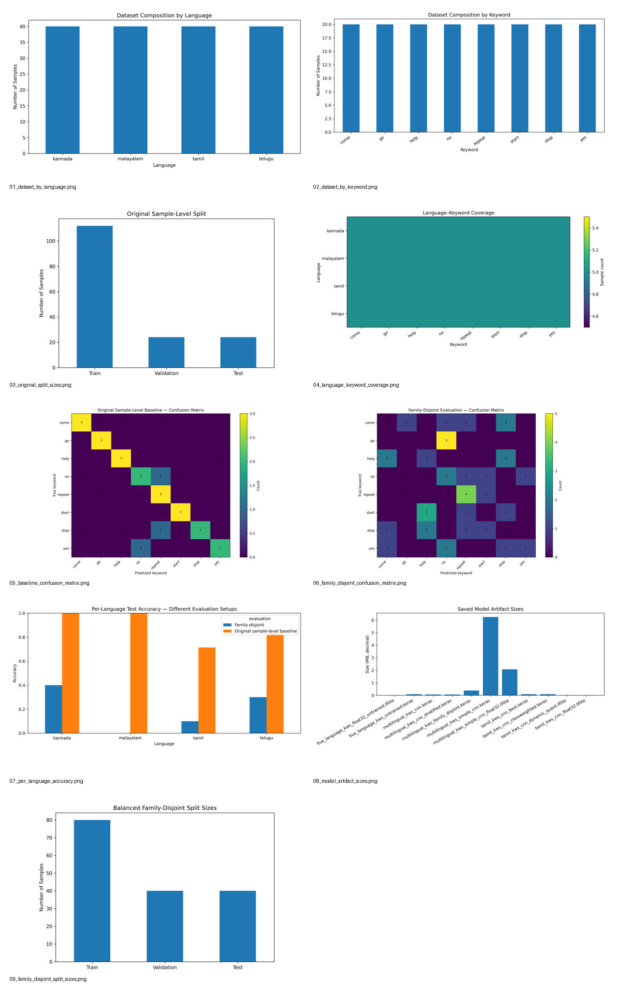

In [41]:
from IPython.display import display, Image
from pathlib import Path

preview = Path(
    "/content/drive/MyDrive/Multilingual_TinyML_KWS/"
    "publication/all_figures_contact_sheet.png"
)

display(Image(filename=str(preview)))

In [42]:

from pathlib import Path
import shutil
from google.colab import files

project = Path(
    "/content/drive/MyDrive/Multilingual_TinyML_KWS"
)
figure_folder = project / "publication" / "figures_png"
zip_path = project / "publication" / "IEEE_Individual_Figures.zip"

assert len(list(figure_folder.glob("*.png"))) == 9, (
    "Expected nine PNG figures. Check the folder first."
)

shutil.make_archive(
    str(zip_path.with_suffix("")),
    "zip",
    root_dir=figure_folder
)

files.download(str(zip_path))


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [43]:

from pathlib import Path
import json
import numpy as np

ROOT = Path(
    "/content/drive/MyDrive/Multilingual_TinyML_KWS"
)

def read_json(relative_path):
    path = ROOT / relative_path
    if not path.exists():
        print(f"MISSING REPORT: {relative_path}")
        return None
    try:
        return json.loads(path.read_text(encoding="utf-8"))
    except Exception as exc:
        print(f"Could not read {relative_path}: {exc}")
        return None

print("=" * 60)
print("MULTILINGUAL TINYML KWS — FROZEN BASELINE AUDIT")
print("=" * 60)

# Dataset
dataset_path = ROOT / "data/processed/kws_dataset.npz"
if dataset_path.exists():
    with np.load(dataset_path, allow_pickle=True) as data:
        print("\nDATASET")
        print("Feature shape:", data["X"].shape)
        print("Sample count:", len(data["y"]))
        print("Classes:", list(data["classes"]))
        print("Languages:", {
            str(lang): int(count)
            for lang, count in zip(
                *np.unique(data["languages"], return_counts=True)
            )
        })
        for key in ("train_idx", "val_idx", "test_idx"):
            if key in data.files:
                print(f"{key}: {len(data[key])}")
else:
    print("DATASET MISSING:", dataset_path)

# Existing model artifacts
print("\nMODEL ARTIFACTS")
for relative in [
    "models/multilingual_kws_simple_cnn.keras",
    "models/multilingual_kws_simple_cnn_float32.tflite",
    "models/multilingual_kws_family_disjoint.keras",
]:
    path = ROOT / relative
    if path.exists():
        print(f"{relative}: {path.stat().st_size:,} bytes")
    else:
        print(f"MISSING: {relative}")

# Saved evaluation reports
reports = [
    "results/simple_cnn_evaluation_report.json",
    "results/family_disjoint_evaluation.json",
    "results/audio_label_quality_audit.json",
    "results/feature_reproduction_audit.json",
    "results/project_freeze_report.json",
]

for relative in reports:
    report = read_json(relative)
    if report is not None:
        print(f"\nREPORT: {relative}")
        print(json.dumps(report, indent=2)[:3500])

print("\nAUDIT COMPLETE — NO TRAINING OR FILE MODIFICATIONS")


MULTILINGUAL TINYML KWS — FROZEN BASELINE AUDIT

DATASET
Feature shape: (160, 40, 101, 1)
Sample count: 160
Classes: [np.str_('come'), np.str_('go'), np.str_('help'), np.str_('no'), np.str_('repeat'), np.str_('start'), np.str_('stop'), np.str_('yes')]
Languages: {'kannada': 40, 'malayalam': 40, 'tamil': 40, 'telugu': 40}
train_idx: 112
val_idx: 24
test_idx: 24

MODEL ARTIFACTS
models/multilingual_kws_simple_cnn.keras: 6,246,083 bytes
models/multilingual_kws_simple_cnn_float32.tflite: 2,074,036 bytes
models/multilingual_kws_family_disjoint.keras: 381,041 bytes

REPORT: results/simple_cnn_evaluation_report.json
{
  "project": "Multilingual TinyML Keyword Spotting",
  "status": "Preliminary four-language pilot evaluation",
  "dataset": {
    "total_examples": 160,
    "test_examples": 24,
    "feature_shape": [
      40,
      101,
      1
    ],
    "classes": [
      "come",
      "go",
      "help",
      "no",
      "repeat",
      "start",
      "stop",
      "yes"
    ],
    "langua

In [44]:

from pathlib import Path
import numpy as np
import pandas as pd

ROOT = Path(
    "/content/drive/MyDrive/Multilingual_TinyML_KWS"
)
DATA = ROOT / "data/processed/kws_dataset.npz"
RESULTS = ROOT / "results"

with np.load(DATA, allow_pickle=True) as d:
    y = d["y"].astype(str)
    languages = d["languages"].astype(str)
    files = d["files"].astype(str)
    classes = d["classes"].astype(str).tolist()

    train_idx = d["train_idx"].astype(int)
    val_idx = d["val_idx"].astype(int)
    test_idx = d["test_idx"].astype(int)

    meta = pd.DataFrame({
        "sample_index": np.arange(len(y)),
        "language": languages,
        "label": y,
        "file": files
    })

    print("1. LABEL COUNTS")
    print(meta["label"].value_counts().reindex(classes))

    print("\n2. LANGUAGE × LABEL COUNTS")
    print(pd.crosstab(meta["language"], meta["label"]).to_string())

    print("\n3. SPLIT COVERAGE")
    for name, idx in [
        ("train", train_idx),
        ("validation", val_idx),
        ("test", test_idx)
    ]:
        subset = meta.iloc[idx]
        print(
            name,
            "| samples:", len(idx),
            "| classes:", subset["label"].nunique(),
            "| languages:", subset["language"].nunique()
        )

    print("\n4. ORIGINAL SPLIT FAMILY OVERLAP")
    def family_name(path):
        p = Path(path)
        return p.stem.rsplit("_v", 1)[0] if "_v" in p.stem else p.stem

    meta["family"] = (
        meta["language"] + "/" + meta["label"] + "/" +
        meta["file"].map(family_name)
    )

    split_sets = {
        name: set(meta.iloc[idx]["family"])
        for name, idx in [
            ("train", train_idx),
            ("validation", val_idx),
            ("test", test_idx)
        ]
    }

    for a, b in [
        ("train", "validation"),
        ("train", "test"),
        ("validation", "test")
    ]:
        overlap = split_sets[a] & split_sets[b]
        print(f"{a} ∩ {b}: {len(overlap)} shared families")

# Inspect prediction errors without changing anything
pred_path = RESULTS / "family_disjoint_test_predictions.csv"
if pred_path.exists():
    pred = pd.read_csv(pred_path)
    print("\n5. FAMILY-DISJOINT PREDICTION CSV")
    print("Columns:", pred.columns.tolist())
    print(pred.head(12).to_string(index=False))
else:
    print("\nFamily-disjoint prediction CSV not found.")

print("\nDIAGNOSTICS COMPLETE — NO FILES MODIFIED")


1. LABEL COUNTS
label
come     NaN
go       NaN
help     NaN
no       NaN
repeat   NaN
start    NaN
stop     NaN
yes      NaN
Name: count, dtype: float64

2. LANGUAGE × LABEL COUNTS
label      0  1  2  3  4  5  6  7
language                         
kannada    5  5  5  5  5  5  5  5
malayalam  5  5  5  5  5  5  5  5
tamil      5  5  5  5  5  5  5  5
telugu     5  5  5  5  5  5  5  5

3. SPLIT COVERAGE
train | samples: 112 | classes: 8 | languages: 4
validation | samples: 24 | classes: 8 | languages: 4
test | samples: 24 | classes: 8 | languages: 4

4. ORIGINAL SPLIT FAMILY OVERLAP
train ∩ validation: 20 shared families
train ∩ test: 19 shared families
validation ∩ test: 12 shared families

5. FAMILY-DISJOINT PREDICTION CSV
Columns: ['file', 'language', 'true_label', 'predicted_label', 'correct', 'max_probability']
                                  file  language true_label predicted_label  correct  max_probability
     data/pilot_audio/kannada/come.wav   kannada       come          rep

In [45]:

from pathlib import Path
import numpy as np
import pandas as pd

ROOT = Path(
    "/content/drive/MyDrive/Multilingual_TinyML_KWS"
)

with np.load(
    ROOT / "data/processed/kws_dataset.npz",
    allow_pickle=True
) as d:
    y = d["y"].astype(int)
    languages = d["languages"].astype(str)
    files = d["files"].astype(str)
    classes = d["classes"].astype(str).tolist()

    print("CLASS ID MAPPING")
    for i, name in enumerate(classes):
        print(i, "->", name, "| samples:", int(np.sum(y == i)))

    df = pd.DataFrame({
        "label_id": y,
        "label": [classes[i] for i in y],
        "language": languages,
        "file": files
    })

    print("\nLANGUAGE × COMMAND")
    print(pd.crosstab(df["language"], df["label"]).to_string())

    def family(path):
        stem = Path(path).stem
        base = stem.rsplit("_v", 1)[0] if "_v" in stem else stem
        return base

    df["family"] = (
        df["language"] + "/" +
        df["label"] + "/" +
        df["file"].map(family)
    )

    split_path = ROOT / "results/family_disjoint_splits_balanced.npz"

    if not split_path.exists():
        print("\nBALANCED FAMILY SPLIT FILE MISSING")
    else:
        with np.load(split_path, allow_pickle=True) as s:
            split_sets = {}
            for split in ["train_idx", "val_idx", "test_idx"]:
                idx = s[split].astype(int)
                split_sets[split] = set(df.iloc[idx]["family"])
                print(
                    split, "samples:", len(idx),
                    "| classes:", df.iloc[idx]["label"].nunique(),
                    "| languages:", df.iloc[idx]["language"].nunique()
                )

            print("\nFAMILY OVERLAP")
            for a, b in [
                ("train_idx", "val_idx"),
                ("train_idx", "test_idx"),
                ("val_idx", "test_idx")
            ]:
                print(
                    a, "vs", b, ":",
                    len(split_sets[a] & split_sets[b]),
                    "shared families"
                )

print("\nREAD-ONLY CHECK COMPLETE")


CLASS ID MAPPING
0 -> come | samples: 20
1 -> go | samples: 20
2 -> help | samples: 20
3 -> no | samples: 20
4 -> repeat | samples: 20
5 -> start | samples: 20
6 -> stop | samples: 20
7 -> yes | samples: 20

LANGUAGE × COMMAND
label      come  go  help  no  repeat  start  stop  yes
language                                               
kannada       5   5     5   5       5      5     5    5
malayalam     5   5     5   5       5      5     5    5
tamil         5   5     5   5       5      5     5    5
telugu        5   5     5   5       5      5     5    5
train_idx samples: 80 | classes: 8 | languages: 4
val_idx samples: 40 | classes: 8 | languages: 4
test_idx samples: 40 | classes: 8 | languages: 4

FAMILY OVERLAP
train_idx vs val_idx : 0 shared families
train_idx vs test_idx : 0 shared families
val_idx vs test_idx : 0 shared families

READ-ONLY CHECK COMPLETE


In [46]:

from pathlib import Path
import json
import tensorflow as tf

ROOT = Path(
    "/content/drive/MyDrive/Multilingual_TinyML_KWS"
)

model_path = ROOT / "models/multilingual_kws_family_disjoint.keras"
report_path = ROOT / "results/family_disjoint_evaluation.json"

print("TENSORFLOW VERSION:", tf.__version__)

if model_path.exists():
    model = tf.keras.models.load_model(model_path, compile=False)

    print("\nMODEL SUMMARY")
    model.summary()

    print("\nINPUT SHAPE:", model.input_shape)
    print("OUTPUT SHAPE:", model.output_shape)
    print("PARAMETERS:", model.count_params())
else:
    print("Family-disjoint model not found.")

if report_path.exists():
    report = json.loads(report_path.read_text())

    print("\nSAVED EVALUATION")
    print("Test accuracy:", report.get("test_accuracy"))
    print("Macro F1:", report.get("test_macro_f1"))
    print("Parameters:", report.get("model_parameters"))
    print("Limitations:", report.get("limitations"))

print("\nINSPECTION COMPLETE — NO MODEL MODIFIED")


TENSORFLOW VERSION: 2.21.0

MODEL SUMMARY


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 40, 101, 16)    │           160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 20, 50, 16)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 20, 50, 32)     │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 10, 25, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 10, 25, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 64)             │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 8)              │           520 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 27,976 (109.28 KB)

 Trainable params: 27,976 (109.28 KB)

 Non-trainable params: 0 (0.00 B)


INPUT SHAPE: (None, 40, 101, 1)
OUTPUT SHAPE: (None, 8)
PARAMETERS: 27976

SAVED EVALUATION
Test accuracy: 0.2
Macro F1: 0.16869796869796871
Parameters: 27976
Limitations: ['Only 40 held-out synthetic audio samples.', 'Generated audio text has not been fully verified by native speakers.', 'Family-disjoint evaluation does not establish generalization to real human speech.', 'No physical TinyML hardware latency or energy measurement.']

INSPECTION COMPLETE — NO MODEL MODIFIED


In [47]:

from pathlib import Path
import tensorflow as tf
import json

ROOT = Path(
    "/content/drive/MyDrive/Multilingual_TinyML_KWS"
)
MODEL = ROOT / "models/multilingual_kws_family_disjoint.keras"

model = tf.keras.models.load_model(MODEL, compile=False)

print("MODEL PARAMETER AUDIT")
print("Model count_params():", model.count_params())

for layer in model.layers:
    try:
        count = layer.count_params()
    except Exception:
        count = "unavailable"
    print(
        f"{layer.name:35s} "
        f"{layer.__class__.__name__:25s} "
        f"parameters={count}"
    )

print("\nPOSSIBLE TRAINING HISTORY FILES")
for folder in [ROOT / "results", ROOT / "models", ROOT]:
    if folder.exists():
        for path in folder.glob("*"):
            if path.is_file() and any(
                word in path.name.lower()
                for word in ["history", "training", "epoch", "log"]
            ):
                print(path.relative_to(ROOT))

print("\nREAD-ONLY INSPECTION COMPLETE")


MODEL PARAMETER AUDIT
Model count_params(): 27976
conv2d                              Conv2D                    parameters=160
max_pooling2d                       MaxPooling2D              parameters=0
conv2d_1                            Conv2D                    parameters=4640
max_pooling2d_1                     MaxPooling2D              parameters=0
conv2d_2                            Conv2D                    parameters=18496
global_average_pooling2d            GlobalAveragePooling2D    parameters=0
dense                               Dense                     parameters=4160
dropout                             Dropout                   parameters=0
dense_1                             Dense                     parameters=520

POSSIBLE TRAINING HISTORY FILES
results/logmel_variation_similarity_audit.csv

READ-ONLY INSPECTION COMPLETE


In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
from pathlib import Path

PROJECT = Path("/content/drive/MyDrive/Multilingual_TinyML_KWS")
print("Project exists:", PROJECT.exists())
print("Results folder exists:", (PROJECT / "results").exists())
print("Notebook artifacts:", len(list(PROJECT.rglob("*"))))

Project exists: True
Results folder exists: True
Notebook artifacts: 897


In [3]:

from pathlib import Path
import json

PROJECT = Path("/content/drive/MyDrive/Multilingual_TinyML_KWS")
RESULTS = PROJECT / "results"
MODELS = PROJECT / "models"
DATA = PROJECT / "data" / "processed"

checks = {
    "Project folder": PROJECT,
    "Final execution report": RESULTS / "final_execution_report.json",
    "Project freeze report": RESULTS / "PROJECT_FREEZE_REPORT.md",
    "Final metrics table": RESULTS / "final_metrics_table.csv",
    "Original CNN model": MODELS / "multilingual_kws_simple_cnn.keras",
    "TFLite model": MODELS / "multilingual_kws_simple_cnn_float32.tflite",
    "Processed dataset": DATA / "kws_dataset.npz",
    "Family-disjoint evaluation": RESULTS / "family_disjoint_evaluation.json",
}

print("PROJECT:", PROJECT)
print("=" * 55)

for name, path in checks.items():
    status = "OK" if path.exists() else "MISSING"
    size = f" ({path.stat().st_size:,} bytes)" if path.is_file() and path.exists() else ""
    print(f"[{status}] {name}{size}")

print("=" * 55)
print("Figures:", len(list((RESULTS / "figures").glob("*")))
      if (RESULTS / "figures").exists() else 0)


PROJECT: /content/drive/MyDrive/Multilingual_TinyML_KWS
[OK] Project folder
[OK] Final execution report (4,048 bytes)
[OK] Project freeze report (104,085 bytes)
[OK] Final metrics table (463 bytes)
[OK] Original CNN model (6,246,083 bytes)
[OK] TFLite model (2,074,036 bytes)
[OK] Processed dataset (997,951 bytes)
[OK] Family-disjoint evaluation (3,176 bytes)
Figures: 9


In [4]:

from pathlib import Path
import json
import pandas as pd

ROOT = Path("/content/drive/MyDrive/Multilingual_TinyML_KWS")
RESULTS = ROOT / "results"

for name in [
    "final_execution_report.json",
    "family_disjoint_evaluation.json",
    "project_freeze_report.json",
]:
    path = RESULTS / name
    print(f"\n--- {name} ---")
    if not path.exists():
        print("Missing")
        continue
    try:
        with path.open(encoding="utf-8") as f:
            report = json.load(f)
        print("Valid JSON")
        for key in ["dataset", "evaluation", "metrics", "audits"]:
            if key in report:
                section = report[key]
                if isinstance(section, dict):
                    print(key, "keys:", list(section.keys())[:12])
    except Exception as e:
        print("READ ERROR:", repr(e))

table = RESULTS / "final_metrics_table.csv"
if table.exists():
    df = pd.read_csv(table)
    print("\n--- final_metrics_table.csv ---")
    print("Rows:", len(df), "| Columns:", list(df.columns))
    print(df.to_string(index=False))



--- final_execution_report.json ---
Valid JSON

--- family_disjoint_evaluation.json ---
Valid JSON

--- project_freeze_report.json ---
Valid JSON
dataset keys: ['samples', 'feature_shape', 'classes', 'languages', 'class_count', 'language_count', 'finite_features', 'feature_min', 'feature_max', 'feature_mean', 'feature_std', 'unique_audio_paths']
evaluation keys: ['original_sample_level_test_accuracy', 'original_sample_level_macro_f1', 'family_disjoint_test_accuracy', 'family_disjoint_macro_f1', 'baseline_prediction_csv', 'family_disjoint_prediction_csv', 'baseline_confusion_matrix_created', 'family_disjoint_confusion_matrix_created']
audits keys: ['feature_reproduction', 'audio_label_quality']

--- final_metrics_table.csv ---
Rows: 10 | Columns: ['metric', 'value', 'unit']
                               metric               value       unit
                      Dataset samples                 160    samples
            Number of command classes                   8    classes
        

In [5]:

from pathlib import Path
import json
import pandas as pd

ROOT = Path("/content/drive/MyDrive/Multilingual_TinyML_KWS")
RESULTS = ROOT / "results"

# Inspect the actual feature-reproduction audit
report_path = RESULTS / "project_freeze_report.json"

with open(report_path, encoding="utf-8") as f:
    report = json.load(f)

audit = report.get("audits", {}).get("feature_reproduction", {})

print("FEATURE REPRODUCTION AUDIT")
print(json.dumps(audit, indent=2)[:10000])

# Check the metrics table and its exact stored value
table_path = RESULTS / "final_metrics_table.csv"
df = pd.read_csv(table_path)

print("\nMETRICS TABLE ROW")
print(df[df["metric"].str.contains(
    "reproduced exactly", case=False, na=False
)].to_string(index=False))

# Locate likely source files that generate or update this metric
print("\nPOSSIBLE METRIC-GENERATION FILES")
for folder in [ROOT / "scripts", ROOT / "src", ROOT / "results"]:
    if folder.exists():
        for path in folder.rglob("*"):
            if path.is_file() and path.suffix in {".py", ".json", ".md"}:
                if "feature" in path.name.lower() or "metric" in path.name.lower():
                    print(path.relative_to(ROOT))


FEATURE REPRODUCTION AUDIT
{
  "samples_in_dataset": 160,
  "samples_reproduced": 160,
  "missing_audio_files": [],
  "shape_mismatches": [],
  "exact_pipeline_matches_atol_1e-5": 160,
  "max_absolute_difference": 0.0,
  "mean_absolute_difference": 0.0,
  "sample_details": [
    {
      "index": 0,
      "file": "/content/drive/MyDrive/Multilingual_TinyML_KWS/data/pilot_audio/kannada/come.wav",
      "max_abs_difference": 0.0,
      "mean_abs_difference": 0.0,
      "matches_atol_1e-5": true
    },
    {
      "index": 1,
      "file": "/content/drive/MyDrive/Multilingual_TinyML_KWS/data/pilot_audio/kannada/come_v2.wav",
      "max_abs_difference": 0.0,
      "mean_abs_difference": 0.0,
      "matches_atol_1e-5": true
    },
    {
      "index": 2,
      "file": "/content/drive/MyDrive/Multilingual_TinyML_KWS/data/pilot_audio/kannada/come_v3.wav",
      "max_abs_difference": 0.0,
      "mean_abs_difference": 0.0,
      "matches_atol_1e-5": true
    },
    {
      "index": 3,
      "fil

In [6]:

from pathlib import Path
import json
import shutil
import pandas as pd

ROOT = Path("/content/drive/MyDrive/Multilingual_TinyML_KWS")
RESULTS = ROOT / "results"

audit_path = RESULTS / "feature_reproduction_audit.json"
table_path = RESULTS / "final_metrics_table.csv"

with open(audit_path, encoding="utf-8") as f:
    audit = json.load(f)

# Confirm the evidence before changing the summary
total = audit.get("samples_in_dataset", 0)
reproduced = audit.get("exact_pipeline_matches_atol_1e-5", 0)
missing = audit.get("missing_audio_files", [])
mismatches = audit.get("shape_mismatches", [])
max_diff = audit.get("max_absolute_difference", None)

verified = (
    total > 0
    and reproduced == total
    and not missing
    and not mismatches
    and max_diff == 0.0
)

print("Samples:", total)
print("Exact matches:", reproduced)
print("Missing audio:", len(missing))
print("Shape mismatches:", len(mismatches))
print("Maximum difference:", max_diff)
print("Audit supports True:", verified)

if not verified:
    raise RuntimeError(
        "Audit does not support True. Metrics table left unchanged."
    )

df = pd.read_csv(table_path)
mask = df["metric"].eq("Feature extraction reproduced exactly")

if mask.sum() != 1:
    raise RuntimeError(
        "Expected exactly one matching metrics row. No changes made."
    )

if str(df.loc[mask, "unit"].iloc[0]).lower() != "boolean":
    raise RuntimeError("Unexpected metric unit. No changes made.")

# Preserve the original table before editing.
backup = table_path.with_name("final_metrics_table_backup.csv")
if not backup.exists():
    shutil.copy2(table_path, backup)

df.loc[mask, "value"] = True
df.to_csv(table_path, index=False)

print("\nCorrected metrics table.")
print("Backup:", backup)
print(df.loc[mask].to_string(index=False))


Samples: 160
Exact matches: 160
Missing audio: 0
Shape mismatches: 0
Maximum difference: 0.0
Audit supports True: True

Corrected metrics table.
Backup: /content/drive/MyDrive/Multilingual_TinyML_KWS/results/final_metrics_table_backup.csv
                               metric value    unit
Feature extraction reproduced exactly  True boolean


In [8]:

import os

zip_path = "/content/Multilingual_TinyML_KWS.zip"
project_dir = "/content/drive/MyDrive/Multilingual_TinyML_KWS"

print("Project folder exists:", os.path.isdir(project_dir))
print("ZIP exists:", os.path.exists(zip_path))

if os.path.exists(zip_path):
    print("ZIP size (MB):", round(os.path.getsize(zip_path) / (1024 * 1024), 2))


Project folder exists: True
ZIP exists: True
ZIP size (MB): 142.09


In [10]:

import os

paths = [
    "/content/Multilingual_TinyML_KWS.zip",
    "/content/drive/MyDrive/Multilingual_TinyML_KWS.zip",
]

for path in paths:
    if os.path.isfile(path):
        print("FOUND:", path)
        print("Size (MB):", round(os.path.getsize(path) / (1024 * 1024), 2))
    else:
        print("NOT FOUND:", path)


FOUND: /content/Multilingual_TinyML_KWS.zip
Size (MB): 142.09
NOT FOUND: /content/drive/MyDrive/Multilingual_TinyML_KWS.zip


In [11]:

from google.colab import files

files.download("/content/Multilingual_TinyML_KWS.zip")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:

# ONE-CELL PROJECT UPLOAD: COLAB -> PRIVATE GITHUB
# Your token is requested securely and is not printed or committed.

import os
import json
import shutil
import subprocess
from pathlib import Path
from getpass import getpass

import requests

# 1. Project paths
PROJECT = Path("/content/drive/MyDrive/Multilingual_TinyML_KWS")
NOTEBOOK = Path(
    "/content/drive/MyDrive/Colab Notebooks/Multilingual_TinyML_KWS.ipynb"
)
REPO_NAME = "Multilingual-TinyML-KWS"

if not PROJECT.is_dir():
    raise FileNotFoundError(f"Project folder not found: {PROJECT}")

# 2. Secure GitHub authentication
TOKEN = getpass("Paste your GitHub token (input stays hidden): ").strip()
if not TOKEN:
    raise ValueError("No GitHub token supplied.")

API = "https://api.github.com"
HEADERS = {
    "Authorization": f"Bearer {TOKEN}",
    "Accept": "application/vnd.github+json",
    "X-GitHub-Api-Version": "2022-11-28",
}

# 3. Identify your GitHub account
response = requests.get(f"{API}/user", headers=HEADERS, timeout=30)
response.raise_for_status()
account = response.json()
username = account["login"]
print("Authenticated GitHub account:", username)

# 4. Create the private repository, or use it if it already exists
response = requests.post(
    f"{API}/user/repos",
    headers=HEADERS,
    json={
        "name": REPO_NAME,
        "private": True,
        "description": (
            "Research prototype for multilingual TinyML keyword spotting"
        ),
        "auto_init": False,
    },
    timeout=30,
)

if response.status_code == 201:
    print("Created new private repository.")
elif response.status_code == 422:
    check = requests.get(
        f"{API}/repos/{username}/{REPO_NAME}",
        headers=HEADERS,
        timeout=30,
    )
    check.raise_for_status()
    if not check.json().get("private", False):
        raise RuntimeError(
            "A repository with this name already exists and is public. "
            "No changes were pushed."
        )
    print("Using existing private repository.")
else:
    raise RuntimeError(
        f"Repository creation failed: {response.status_code} "
        f"{response.text[:500]}"
    )

# 5. Copy the notebook into the project
notebooks_dir = PROJECT / "notebooks"
notebooks_dir.mkdir(exist_ok=True)

if NOTEBOOK.is_file():
    shutil.copy2(
        NOTEBOOK,
        notebooks_dir / "Multilingual_TinyML_KWS.ipynb"
    )
    print("Copied the Colab notebook.")
else:
    print(
        "WARNING: Notebook wasn't found at the expected path:",
        NOTEBOOK
    )
    print("The project files will still be uploaded.")

# 6. Exclude files that exceed GitHub's standard 100 MB limit.
# Keep the originals in Drive; nothing is deleted.
ignore_path = PROJECT / ".gitignore"
existing_ignore = (
    ignore_path.read_text(encoding="utf-8")
    if ignore_path.exists() else ""
)
ignore_lines = [
    "*.zip",
    ".env",
    ".venv/",
    "__pycache__/",
    ".ipynb_checkpoints/",
]
for line in ignore_lines:
    if line not in existing_ignore.splitlines():
        existing_ignore += ("\n" if existing_ignore else "") + line + "\n"

large_files = []
for path in PROJECT.rglob("*"):
    if not path.is_file() or ".git" in path.parts:
        continue
    relative = path.relative_to(PROJECT).as_posix()
    if path.stat().st_size >= 95 * 1024 * 1024:
        large_files.append((relative, path.stat().st_size))
        if relative not in existing_ignore.splitlines():
            existing_ignore += relative + "\n"

ignore_path.write_text(existing_ignore, encoding="utf-8")

print("\nLarge files excluded from Git:")
if large_files:
    for name, size in large_files:
        print(f"  {name}: {size / (1024*1024):.2f} MB")
else:
    print("  None found.")

# 7. Create a README if the project doesn't already have one
readme = PROJECT / "README.md"
if not readme.exists():
    readme.write_text(
        "# Multilingual TinyML Keyword Spotting\n\n"
        "Research prototype exploring keyword spotting across "
        "Kannada, Tamil, Telugu and Malayalam.\n\n"
        "## Contents\n"
        "- `notebooks/`: Colab notebook\n"
        "- `models/`: saved model artifacts\n"
        "- `data/`: available processed data\n"
        "- `results/`: evaluation reports, metrics and figures\n\n"
        "## Evaluation notes\n"
        "The current prototype uses synthetic samples. The sample-level "
        "and family-disjoint evaluations differ substantially; the "
        "family-disjoint result should be considered when assessing "
        "generalization. Native-speaker validation and real-device "
        "measurements remain necessary before claiming real-world "
        "performance.\n",
        encoding="utf-8",
    )
    print("Created a basic README.md.")

# 8. Initialize Git and configure commit identity
def git(*args, check=True, env=None):
    return subprocess.run(
        ["git", *args],
        cwd=str(PROJECT),
        check=check,
        text=True,
        stdout=subprocess.PIPE,
        stderr=subprocess.PIPE,
        env=env,
    )

if not (PROJECT / ".git").exists():
    git("init")

git("branch", "-M", "main")
git("config", "user.name", username)
git("config", "user.email", f"{account['id']}+{username}@users.noreply.github.com")

remote = git("remote", "get-url", "origin", check=False)
remote_url = f"https://github.com/{username}/{REPO_NAME}.git"

if remote.returncode == 0:
    git("remote", "set-url", "origin", remote_url)
else:
    git("remote", "add", "origin", remote_url)

# If a large file was previously tracked, untrack it without deleting it.
tracked = git("ls-files", "-z").stdout.split("\0")
for name in tracked:
    if not name:
        continue
    path = PROJECT / name
    if path.is_file() and path.stat().st_size >= 95 * 1024 * 1024:
        git("rm", "--cached", "--", name, check=False)

# 9. Stage and commit project files
git("add", "-A")
status = git("status", "--porcelain").stdout

if status.strip():
    git("commit", "-m", "Add multilingual TinyML KWS project")
    print("Created project commit.")
else:
    print("No new file changes to commit.")

# 10. Push without saving the token in the Git remote URL
askpass = Path("/content/github_askpass.sh")
askpass.write_text(
    "#!/bin/sh\n"
    'case "$1" in\n'
    '  *Username*) echo "x-access-token" ;;\n'
    '  *Password*) echo "$GITHUB_TOKEN" ;;\n'
    '  *) exit 1 ;;\n'
    "esac\n",
    encoding="utf-8",
)
askpass.chmod(0o700)

env = os.environ.copy()
env["GITHUB_TOKEN"] = TOKEN
env["GIT_ASKPASS"] = str(askpass)
env["GIT_TERMINAL_PROMPT"] = "0"

try:
    push = git("push", "-u", "origin", "main", env=env)
    print(push.stdout)
    print(push.stderr)
    print("\nUPLOAD SUCCESSFUL!")
    print(f"Private repository: https://github.com/{username}/{REPO_NAME}")
except subprocess.CalledProcessError as exc:
    print("Push did not complete.")
    print(exc.stderr[-3000:])
    print(
        "\nIf the repository already contains commits, we should inspect "
        "its state rather than force-pushing."
    )
finally:
    TOKEN = None
    env.pop("GITHUB_TOKEN", None)
    if askpass.exists():
        askpass.unlink()
